In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are now expected on the local filesystem. Set LOCAL_DATA_DIR
# (or rely on the notebook's working directory) to point to the folder that
# contains data.csv, predict.csv, etc.

import os
from pathlib import Path

LOCAL_DATA_DIR = Path(os.environ.get("LOCAL_DATA_DIR", Path.cwd())).resolve()
print(f"LOCAL_DATA_DIR set to {LOCAL_DATA_DIR}")

LOCAL_DATA_DIR set to /home/yoke/MLB


In [2]:
## Starter Code for Building Baseball Win Prediction Model

# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Load the pre-processed datasets from the directory pointed to by LOCAL_DATA_DIR
DATA_DIR = LOCAL_DATA_DIR  # defined in the previous cell
print(f"Loading datasets from {DATA_DIR}")

data_df = pd.read_csv(DATA_DIR / "data.csv")
predict_df = pd.read_csv(DATA_DIR / "predict.csv")

# Display basic information about the datasets
print(f"Data set shape: {data_df.shape}")
print(f"Predict set shape: {predict_df.shape}")

Loading datasets from /home/yoke/MLB
Data set shape: (1412, 51)
Predict set shape: (400, 47)


In [3]:
# Use every numeric/boolean column shared by data.csv and predict.csv
# (drops the target, identifiers and text labels automatically)
exclude_cols = {'W', 'ID', 'yearID', 'teamID', 'year_label', 'decade_label', 'win_bins'}

shared_cols = [col for col in data_df.columns if col in predict_df.columns]
available_features = [
    col for col in data_df[shared_cols].select_dtypes(include=['number', 'bool']).columns
    if col not in exclude_cols
]
print(f"Number of available features: {len(available_features)}")

# Separate features and target variable
X = data_df[available_features]
y = data_df['W']

# Perform the split (adjust test_size / random_state as needed)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      # 20% for testing
    random_state=42    # ensures reproducibility
)

Number of available features: 44


In [4]:
# Scale features
# Identify columns to exclude from scaling (one-hot encoded and label columns)
one_hot_cols = [col for col in X_train.columns if col.startswith(('era_', 'decade_'))]
other_cols = [col for col in X_train.columns if col not in one_hot_cols]

# Scale only non-one-hot features
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[other_cols] = scaler.fit_transform(X_train[other_cols])
X_test_scaled[other_cols] = scaler.transform(X_test[other_cols])

In [5]:
# Build Linear Regression Model
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
lr_train_preds = lr.predict(X_train_scaled)
lr_test_preds = lr.predict(X_test_scaled)

In [6]:
# Evaluate Linear Regression
lr_train_mae = mean_absolute_error(y_train, lr_train_preds)
lr_test_mae = mean_absolute_error(y_test, lr_test_preds)
lr_test_rmse = np.sqrt(mean_squared_error(y_test, lr_test_preds))
lr_test_r2 = r2_score(y_test, lr_test_preds)

print(f"Linear Regression Performance:")
print(f"  Training MAE: {lr_train_mae:.4f}")
print(f"  Test MAE: {lr_test_mae:.4f}")
print(f"  Test RMSE: {lr_test_rmse:.4f}")
print(f"  Test R²: {lr_test_r2:.4f}")

# Feature importance from Linear Regression
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("\nTop 10 Most Important Features:")
print(feature_importance.head(10))

Linear Regression Performance:
  Training MAE: 2.6749
  Test MAE: 2.7025
  Test RMSE: 3.3310
  Test R²: 0.9306

Top 10 Most Important Features:
   Feature  Coefficient
1        R     8.866279
16  IPouts     6.437929
2       AB    -6.108157
10      RA    -5.629822
11      ER    -4.724867
15      SV     4.107003
12     ERA     3.973551
13      CG     3.407080
3        H     3.133752
21       E    -3.062916


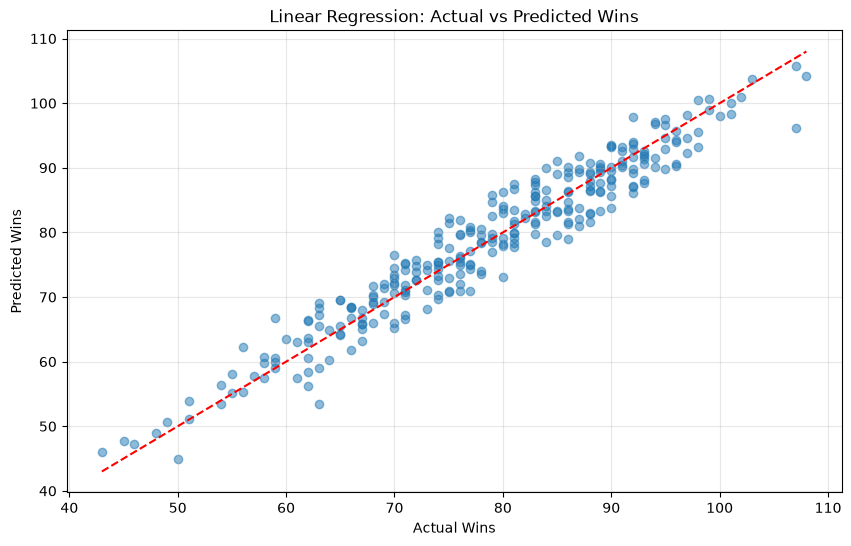

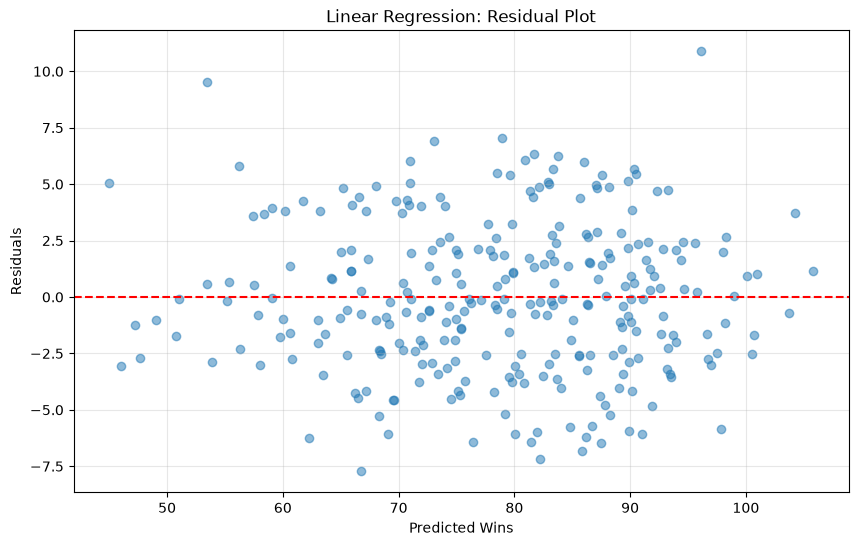

In [7]:
# Visualize actual vs predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, lr_test_preds, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Wins')
plt.ylabel('Predicted Wins')
plt.title('Linear Regression: Actual vs Predicted Wins')
plt.grid(True, alpha=0.3)

# Add residual plot
plt.figure(figsize=(10, 6))
residuals = y_test - lr_test_preds
plt.scatter(lr_test_preds, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Wins')
plt.ylabel('Residuals')
plt.title('Linear Regression: Residual Plot')
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
# Prepare Submission

# Align features and scale using the previously fitted scaler
predict_scaled = predict_df[available_features].copy()
predict_scaled[other_cols] = scaler.transform(predict_scaled[other_cols])

# Predict wins for the new dataset (replace `lr` with your final model if you change it)
predict_preds = lr.predict(predict_scaled)

# Build submission in the same format as submission.csv
submission_df = pd.DataFrame({
    'ID': predict_df['ID'],
    'W': np.round(predict_preds).astype(int)
})

submission_path = 'sample_submission.csv'
submission_df.to_csv(submission_path, index=False)
print(f"Kaggle submission saved to {submission_path}")

Kaggle submission saved to sample_submission.csv


## Next steps: how to improve your model

You now have a working baseline (linear regression on the raw team stats). Use the three areas below as starting points to explore on your own. Judge every change with the **same validation approach** (see the tuning section) so you know whether it really helped.

### 1. Feature engineering

The raw columns are only a starting point. Think about what actually makes a baseball team win, and whether you can turn the existing columns into new ones that describe it better.


- **Adjust for context:** seasons differ in the number of games played, and the amount of scoring has changed over baseball's history. For example, the average team scored about 3.4 runs per game in 1908 but about 5.5 in 1930, so 700 runs would be an excellent season in one era and an average one in the other. How could you adjust the stats so teams from different seasons can be compared fairly?
- **Combine columns:** differences, ratios or totals of existing stats can say more than each one on its own. For example, a ratio like hits divided by at-bats (`H / AB`) tells you how often a team gets a hit, not just how many it got. Two teams can both record 1,400 hits, but if one needed far more at-bats to get there, it was less effective at the plate. The ratio puts the raw count in the context of the opportunities behind it.
- **Look beyond straight lines:** does the relationship between a stat and wins always look the same?
- **Remove or reduce:** are some columns telling you the same thing? Would fewer features work just as well?


The feature-selection cell above uses every numeric column shared by both files, so any new column needs to be added to **both** `data_df` and `predict_df` before that cell runs.


### 2. Try different ML models

Swap the model while keeping the same features and the same train/test split, then compare MAE, RMSE and R² (ideally using the cross-validation approach described in the tuning section below). This list is **not exhaustive**: treat it as a set of starting points, and feel free to try other models.

- **Regularised linear models:** `Ridge`, `Lasso`, `ElasticNet`. Plain linear regression chooses whatever coefficients fit the training data best, which can make them large and unstable when features overlap or there are many of them. Regularised versions add a penalty on large coefficients, accepting a slightly worse fit on the training data in return for a simpler model that often generalises better. `Ridge` shrinks all coefficients, `Lasso` can shrink some to exactly zero (effectively dropping those features), and `ElasticNet` mixes the two.
- **Tree ensembles:** `RandomForestRegressor`, `GradientBoostingRegressor`, `HistGradientBoostingRegressor`. Instead of one formula, these combine many decision trees (series of yes/no splits on the features). They can pick up curved relationships and interactions between features without you creating them. A random forest builds many trees independently and averages them, while gradient boosting builds trees one after another, each trying to fix the mistakes of the ones before.
- **Gradient boosting libraries:** `XGBoost`, `LightGBM`. Faster, more heavily optimised versions of the boosting idea above, with many more settings to tune. They are popular in data science competitions.
- **Other families:** `SVR` fits a flexible curve while tolerating small errors, and `KNeighborsRegressor` predicts by averaging the most similar teams in the training data. Both are sensitive to the scale of the features, so use the scaled data from earlier (tree-based models do not need it).
- **Stacking:** combine several different models, since their mistakes often partly cancel out. `StackingRegressor` trains another model (the "final estimator") to learn the best way to combine the predictions of the models you give it. `VotingRegressor` is a simpler alternative that just averages their predictions.

Things to look out for: compare **training vs test error** to spot overfitting (a large gap means the model is memorising), and remember that a more complex model is not automatically better. Check whether it beats the linear baseline by enough to matter.



### 3. Hyperparameter tuning

Hyperparameters (settings you choose before training, such as tree depth or regularisation strength) can change performance.

- **Use cross-validation, not one split:** `KFold` / `cross_val_score` give a more reliable estimate than a single `train_test_split`, which can be lucky or unlucky. Wrap the scaler and model in a `Pipeline` so scaling is refit inside each fold.
- **Grid search:** `GridSearchCV` tries every combination you list (good for small search spaces).
- **Random search:** `RandomizedSearchCV` samples combinations (more efficient for larger spaces).
- **What to tune** (examples only, not an exhaustive list):
  - Ridge / Lasso: `alpha`
  - Random Forest: `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`
  - XGBoost / LightGBM: `learning_rate`, `n_estimators`, `max_depth`, `subsample`, `colsample_bytree`, `reg_lambda`

A good workflow: set a baseline, change **one thing at a time**, record the cross-validated score, and keep only the changes that clearly help.

In [9]:
# =====================================================
# E1 — Baseline Lasso Regression (44 Original Features)
# =====================================================

import numpy as np

from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Step 1 — Use original 44 features
X_train_e1_44 = X_train.copy()
X_test_e1_44 = X_test.copy()

# Step 2 — Identify numerical features
scale_cols_e1_44 = [
    col for col in X_train_e1_44.columns
    if not col.startswith(("era_", "decade_"))
]

# Step 3 — Standardize numerical features
preprocessor_e1_44 = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), scale_cols_e1_44)
    ],
    remainder="passthrough"
)

# Step 4 — Create baseline Lasso
lasso_e1_44 = Pipeline([
    ("preprocessing", preprocessor_e1_44),
    ("lasso", Lasso(alpha=1.0, max_iter=100000))
])

# Step 5 — Train model
lasso_e1_44.fit(X_train_e1_44, y_train)

# Step 6 — Predictions
e1_44_train_preds = lasso_e1_44.predict(X_train_e1_44)
e1_44_test_preds = lasso_e1_44.predict(X_test_e1_44)

# Step 7 — Evaluate model
print("E1 — Baseline Lasso Regression (44 Features)")
print("-------------------------------------------")

print("Original features:", X_train_e1_44.shape[1])
print("Alpha:", 1.0)

print("\nTraining")
print("MAE :", round(mean_absolute_error(y_train, e1_44_train_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_train, e1_44_train_preds)), 4))
print("R²  :", round(r2_score(y_train, e1_44_train_preds), 4))

print("\nTesting")
print("MAE :", round(mean_absolute_error(y_test, e1_44_test_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, e1_44_test_preds)), 4))
print("R²  :", round(r2_score(y_test, e1_44_test_preds), 4))

# Step 8 — Feature selection
e1_44_coefs = lasso_e1_44.named_steps["lasso"].coef_

selected_features = np.sum(np.abs(e1_44_coefs) > 1e-6)

print("\nFeature Selection")
print("Total features   :", len(e1_44_coefs))
print("Selected features:", selected_features)
print("Zero coefficients:", len(e1_44_coefs) - selected_features)

E1 — Baseline Lasso Regression (44 Features)
-------------------------------------------
Original features: 44
Alpha: 1.0

Training
MAE : 3.3834
RMSE: 4.2713
R²  : 0.8991

Testing
MAE : 3.3231
RMSE: 3.9909
R²  : 0.9003

Feature Selection
Total features   : 44
Selected features: 5
Zero coefficients: 39


In [10]:
# ============================================================
# RESTORE — LASSO 44 FEATURES
# GridSearchCV + Predictions + Evaluation
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    train_test_split, GridSearchCV, KFold
)
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# STEP 1 — Load original data
DATA_DIR = Path.home() / "MLB"

data_44 = pd.read_csv(DATA_DIR / "data.csv")
predict_44 = pd.read_csv(DATA_DIR / "predict.csv")

exclude = {
    "W", "ID", "yearID", "teamID",
    "year_label", "decade_label", "win_bins"
}

features_44 = [
    c for c in data_44.columns
    if c in predict_44.columns
    and c not in exclude
    and pd.api.types.is_numeric_dtype(data_44[c])
]

X_44 = data_44[features_44].copy()
y_44 = data_44["W"].copy()

assert len(features_44) == 44

# STEP 2 — Same train/test split
X_train_44, X_test_44, y_train, y_test = train_test_split(
    X_44,
    y_44,
    test_size=0.2,
    random_state=42
)

# STEP 3 — Prepare preprocessing
scale_cols_44 = [
    c for c in features_44
    if not c.startswith(("era_", "decade_"))
]

preprocessor_44 = ColumnTransformer(
    [("scale", StandardScaler(), scale_cols_44)],
    remainder="passthrough"
)

# STEP 4 — Lasso pipeline
pipeline_44 = Pipeline([
    ("preprocessing", preprocessor_44),
    ("lasso", Lasso(max_iter=100000))
])

# STEP 5 — Five-fold CV alpha tuning
cv_44 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_44 = GridSearchCV(
    pipeline_44,
    {
        "lasso__alpha": [
            1.0, 0.5, 0.1, 0.05, 0.01, 0.001
        ]
    },
    cv=cv_44,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_44.fit(X_train_44, y_train)

# STEP 6 — Restore trained model and predictions
lasso_44 = grid_44.best_estimator_

train_preds_44 = lasso_44.predict(X_train_44)
test_preds_44 = lasso_44.predict(X_test_44)

# STEP 7 — Display results
print("LASSO — 44 FEATURES RESTORED")
print("===========================")

print("Best Alpha:", grid_44.best_params_["lasso__alpha"])
print("CV MAE:", round(-grid_44.best_score_, 4))

print("\nTRAINING")
print("MAE :", round(mean_absolute_error(
    y_train, train_preds_44), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(
    y_train, train_preds_44)), 4))
print("R²  :", round(r2_score(
    y_train, train_preds_44), 4))

print("\nTESTING")
print("MAE :", round(mean_absolute_error(
    y_test, test_preds_44), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(
    y_test, test_preds_44)), 4))
print("R²  :", round(r2_score(
    y_test, test_preds_44), 4))

print("\nRESTORED VARIABLES")
for name in [
    "grid_44",
    "lasso_44",
    "train_preds_44",
    "test_preds_44"
]:
    print("OK:", name)

LASSO — 44 FEATURES RESTORED
Best Alpha: 0.01
CV MAE: 2.819

TRAINING
MAE : 2.6956
RMSE: 3.4084
R²  : 0.9357

TESTING
MAE : 2.6898
RMSE: 3.3248
R²  : 0.9308

RESTORED VARIABLES
OK: grid_44
OK: lasso_44
OK: train_preds_44
OK: test_preds_44


In [11]:
# ============================================================
# E2 — Alpha Tuning Results (44 Original Features)
# ============================================================

import pandas as pd

# Retrieve results from existing GridSearchCV
cv_results_44 = pd.DataFrame(grid_44.cv_results_)

# Create alpha comparison table
alpha_results_44 = pd.DataFrame({
    "Alpha": cv_results_44["param_lasso__alpha"].astype(float),
    "CV_MAE": -cv_results_44["mean_test_score"],
    "CV_STD": cv_results_44["std_test_score"],
    "Rank": cv_results_44["rank_test_score"]
})

# Show results from each of the five folds
for i in range(5):
    alpha_results_44[f"Fold_{i+1}_MAE"] = (
        -cv_results_44[f"split{i}_test_score"]
    )

alpha_results_44 = alpha_results_44.sort_values(
    "Alpha", ascending=False
)

print("E2 — Lasso Alpha Tuning (44 Features)")
print("------------------------------------")
print(alpha_results_44.round(4).to_string(index=False))

# Display best alpha
print("\nBest Alpha:", grid_44.best_params_["lasso__alpha"])
print("Best CV MAE:", round(-grid_44.best_score_, 4))

E2 — Lasso Alpha Tuning (44 Features)
------------------------------------
 Alpha  CV_MAE  CV_STD  Rank  Fold_1_MAE  Fold_2_MAE  Fold_3_MAE  Fold_4_MAE  Fold_5_MAE
 1.000  3.4147  0.2216     6      3.5179      3.0160      3.5372      3.3494      3.6529
 0.500  3.1482  0.1064     5      3.1293      2.9560      3.2658      3.1712      3.2186
 0.100  2.9490  0.0777     4      2.8971      2.9296      3.0576      3.0158      2.8446
 0.050  2.8729  0.0892     3      2.8595      2.8223      2.9703      2.9723      2.7399
 0.010  2.8190  0.0864     1      2.8015      2.7355      2.8711      2.9578      2.7290
 0.001  2.8226  0.0944     2      2.7957      2.7114      2.8552      2.9868      2.7639

Best Alpha: 0.01
Best CV MAE: 2.819


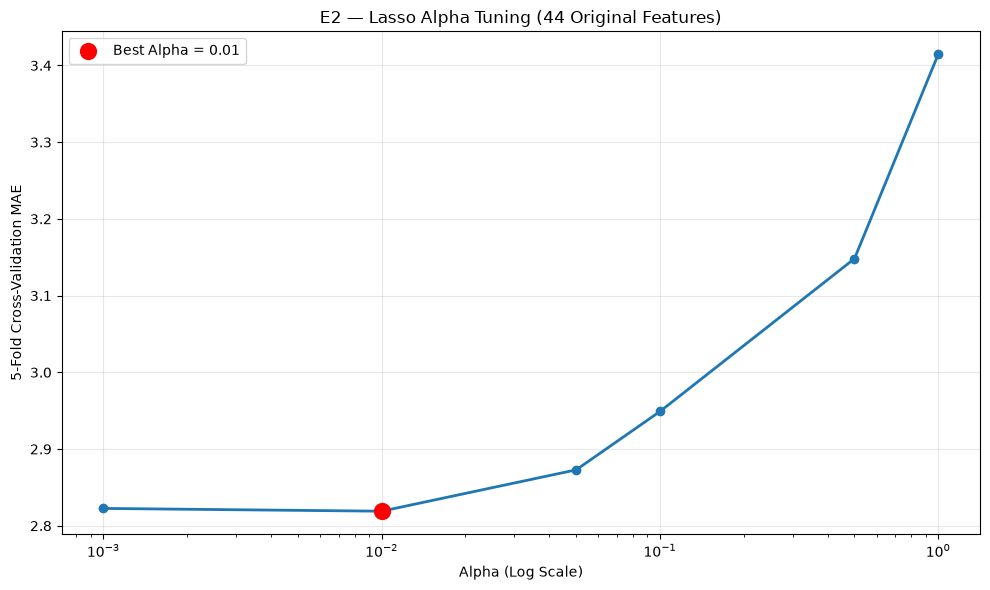

In [12]:
# ============================================================
# E2 — Visualize Alpha Tuning (44 Features)
# ============================================================

import matplotlib.pyplot as plt

plot_df = alpha_results_44.sort_values("Alpha")

best_alpha = float(grid_44.best_params_["lasso__alpha"])
best_mae = -grid_44.best_score_

plt.figure(figsize=(10, 6))

plt.plot(
    plot_df["Alpha"],
    plot_df["CV_MAE"],
    marker="o",
    linewidth=2
)

plt.scatter(
    best_alpha,
    best_mae,
    color="red",
    s=130,
    zorder=5,
    label=f"Best Alpha = {best_alpha}"
)

plt.xscale("log")

plt.xlabel("Alpha (Log Scale)")
plt.ylabel("5-Fold Cross-Validation MAE")
plt.title("E2 — Lasso Alpha Tuning (44 Original Features)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# Step 3 — Tuned Lasso Regression (44 Original Features)
# ============================================================

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the existing trained 44-feature Lasso model
train_pred = lasso_44.predict(X_train_44)
test_pred = lasso_44.predict(X_test_44)

# Display model configuration
print("Tuned Lasso Regression — 44 Features")
print("------------------------------------")
print("Features:", X_train_44.shape[1])
print("Best Alpha:", grid_44.best_params_["lasso__alpha"])

# Training results
print("\nTraining")
print("MAE :", round(mean_absolute_error(y_train, train_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_train, train_pred)), 4))
print("R²  :", round(r2_score(y_train, train_pred), 4))

# Testing results
print("\nTesting")
print("MAE :", round(mean_absolute_error(y_test, test_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, test_pred)), 4))
print("R²  :", round(r2_score(y_test, test_pred), 4))

# Feature selection
coefficients = lasso_44.named_steps["lasso"].coef_

selected = np.sum(np.abs(coefficients) > 1e-6)
zero = len(coefficients) - selected

print("\nFeature Selection")
print("Total Features   :", len(coefficients))
print("Selected Features:", selected)
print("Zero Coefficients:", zero)

Tuned Lasso Regression — 44 Features
------------------------------------
Features: 44
Best Alpha: 0.01

Training
MAE : 2.6956
RMSE: 3.4084
R²  : 0.9357

Testing
MAE : 2.6898
RMSE: 3.3248
R²  : 0.9308

Feature Selection
Total Features   : 44
Selected Features: 33
Zero Coefficients: 11


In [14]:
# ============================================================
# Compare Baseline vs Tuned Lasso — 44 Features
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

comparison_44 = pd.DataFrame({
    "Metric": [
        "Features",
        "Alpha",
        "Testing MAE",
        "Testing RMSE",
        "Testing R²",
        "Selected Features",
        "Zero Coefficients"
    ],
    "E1_Baseline": [
        44,
        1.0,
        mean_absolute_error(y_test, e1_44_test_preds),
        np.sqrt(mean_squared_error(y_test, e1_44_test_preds)),
        r2_score(y_test, e1_44_test_preds),
        np.sum(np.abs(lasso_e1_44.named_steps["lasso"].coef_) > 1e-6),
        np.sum(np.abs(lasso_e1_44.named_steps["lasso"].coef_) <= 1e-6)
    ],
    "E5_Tuned": [
        44,
        grid_44.best_params_["lasso__alpha"],
        mean_absolute_error(y_test, test_preds_44),
        np.sqrt(mean_squared_error(y_test, test_preds_44)),
        r2_score(y_test, test_preds_44),
        np.sum(np.abs(lasso_44.named_steps["lasso"].coef_) > 1e-6),
        np.sum(np.abs(lasso_44.named_steps["lasso"].coef_) <= 1e-6)
    ]
})

print("Baseline vs Tuned Lasso (44 Features)")
print("------------------------------------")
print(comparison_44.round(4).to_string(index=False))

Baseline vs Tuned Lasso (44 Features)
------------------------------------
           Metric  E1_Baseline  E5_Tuned
         Features      44.0000   44.0000
            Alpha       1.0000    0.0100
      Testing MAE       3.3231    2.6898
     Testing RMSE       3.9909    3.3248
       Testing R²       0.9003    0.9308
Selected Features       5.0000   33.0000
Zero Coefficients      39.0000   11.0000


## Step 3 — Tuned Lasso Regression (44 Original Features)

### 1. Objective

Evaluate the performance of Lasso Regression using the original 44 features and the optimal alpha selected through five-fold cross-validation.

The objective is to determine whether hyperparameter tuning improves prediction accuracy compared with the baseline Lasso model (alpha = 1.0).

### 2. Model Configuration

- **Algorithm:** Lasso Regression (L1 Regularization)
- **Input features:** 44 original features
- **Training observations:** 1,129
- **Testing observations:** 283
- **Best alpha:** 0.01
- **Best cross-validation MAE:** 2.8190
- **Evaluation metrics:** MAE, RMSE and R²

### 3. Tuned Model Results

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 2.6956 | 2.6898 |
| RMSE | 3.4084 | 3.3248 |
| R² | 0.9357 | 0.9308 |

### 4. Feature Selection

| Description | Number |
|---|---:|
| Total original features | 44 |
| Selected features | 33 |
| Zero coefficients | 11 |

Lasso applied L1 regularization and reduced 11 feature coefficients to zero, leaving 33 active features contributing directly to predictions.

### 5. Comparison — Baseline vs Tuned Lasso

| Metric | Baseline Lasso | Tuned Lasso |
|---|---:|---:|
| Alpha | 1.0 | 0.01 |
| Training MAE | 3.3834 | 2.6956 |
| Testing MAE | 3.3231 | 2.6898 |
| Testing RMSE | 3.9909 | 3.3248 |
| Testing R² | 0.9003 | 0.9308 |
| Active Features | 5 | 33 |
| Zero Coefficients | 39 | 11 |

### 6. Key Findings

**Finding 1 — Alpha tuning improved prediction accuracy.**

Reducing alpha from 1.0 to 0.01 decreased testing MAE from 3.3231 to 2.6898 wins.

This represents an improvement of approximately **19.1%** in testing MAE.

**Finding 2 — Weaker regularization retained more useful predictors.**

The baseline model retained only 5 active features, while the tuned model retained 33.

This suggests that alpha = 1.0 imposed excessive regularization and removed useful predictive information.

**Finding 3 — Training and testing performance were comparable.**

The tuned model achieved training MAE of 2.6956 and testing MAE of 2.6898.

The small difference suggests no substantial generalization gap on this particular train-test split. However, performance on other datasets may differ.

**Finding 4 — The model explained a high proportion of variation in wins.**

The testing R² of 0.9308 indicates that the tuned model explained approximately 93.08% of the variation in season wins within the testing dataset.

### 7. Conclusion

Five-fold cross-validation identified alpha = 0.01 as the best tested regularization parameter for the original 44-feature Lasso Regression model.

The tuned model substantially outperformed the baseline model, reducing testing MAE by approximately 19.1% while retaining 33 active features.

**The results demonstrate that appropriate alpha tuning improved predictive accuracy by reducing excessive regularization.**

---

## Step 4 — Actual vs Predicted Wins Visualization

### Objective

Visualize the relationship between actual MLB season wins and the wins predicted by the tuned 44-feature Lasso Regression model.

### Graph Interpretation

- **X-axis:** Actual season wins
- **Y-axis:** Predicted season wins
- **Red diagonal line:** Perfect predictions
- **Points close to the diagonal:** Smaller prediction errors
- **Points above the diagonal:** Overprediction of wins
- **Points below the diagonal:** Underprediction of wins

The visualization is used to assess prediction accuracy, identify large errors, and investigate whether the model systematically overpredicts or underpredicts wins.

The tuned model's testing MAE of 2.6898 indicates an average absolute prediction error of approximately 2.69 wins.

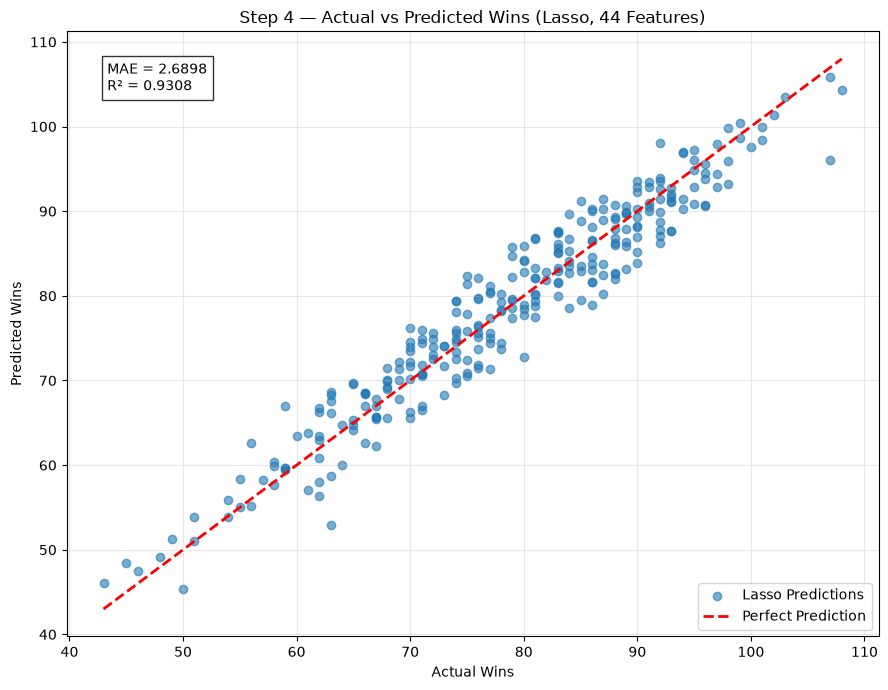

Step 4 — Actual vs Predicted Wins
---------------------------------
Test Observations: 283
Testing MAE: 2.6898
Testing R² : 0.9308


In [15]:
# ============================================================
# Step 4 — Actual vs Predicted Wins
# Tuned Lasso Regression (44 Original Features)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

# Step 1 — Get actual and predicted wins
actual_wins = np.asarray(y_test)
predicted_wins = lasso_44.predict(X_test_44)

# Step 2 — Calculate performance
mae = mean_absolute_error(actual_wins, predicted_wins)
r2 = r2_score(actual_wins, predicted_wins)

# Step 3 — Create scatter plot
plt.figure(figsize=(9, 7))

plt.scatter(
    actual_wins,
    predicted_wins,
    alpha=0.6,
    label="Lasso Predictions"
)

# Step 4 — Perfect prediction line
min_wins = min(actual_wins.min(), predicted_wins.min())
max_wins = max(actual_wins.max(), predicted_wins.max())

plt.plot(
    [min_wins, max_wins],
    [min_wins, max_wins],
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

# Step 5 — Labels and title
plt.xlabel("Actual Wins")
plt.ylabel("Predicted Wins")
plt.title("Step 4 — Actual vs Predicted Wins (Lasso, 44 Features)")

# Step 6 — Display performance on graph
plt.text(
    0.05, 0.95,
    f"MAE = {mae:.4f}\nR² = {r2:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 7 — Print model results
print("Step 4 — Actual vs Predicted Wins")
print("---------------------------------")
print("Test Observations:", len(actual_wins))
print("Testing MAE:", round(mae, 4))
print("Testing R² :", round(r2, 4))

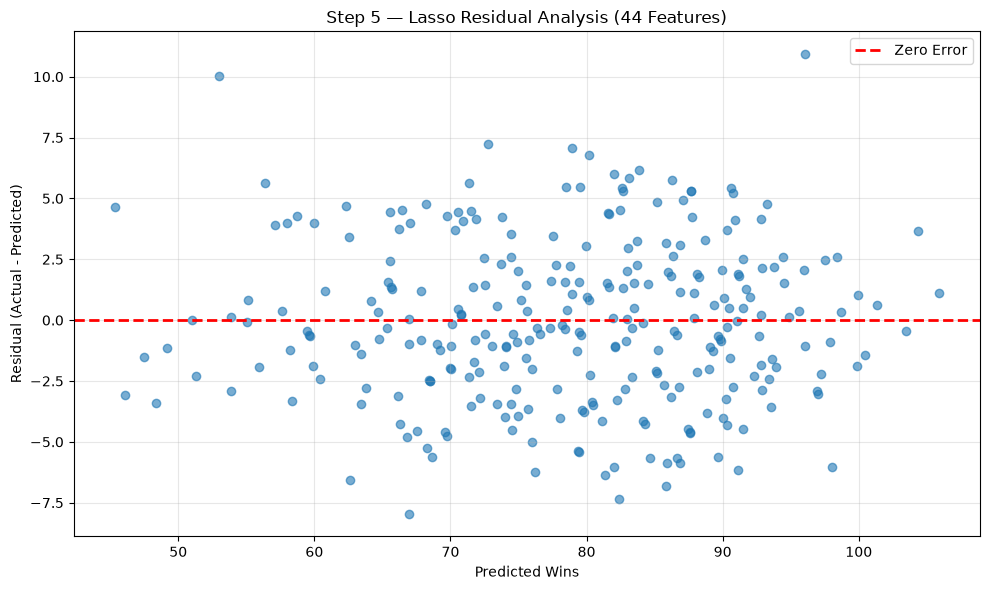

Step 5 — Residual Analysis
--------------------------
Mean Residual: -0.0692
Underpredicted: 134
Overpredicted : 149
Total Observations: 283


In [16]:
# ============================================================
# Step 5 — Residual Analysis
# Tuned Lasso Regression (44 Original Features)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Step 1 — Calculate residuals
# Residual = Actual Wins - Predicted Wins

residuals_44 = actual_wins - predicted_wins

# Step 2 — Plot residuals
plt.figure(figsize=(10, 6))

plt.scatter(
    predicted_wins,
    residuals_44,
    alpha=0.6
)

# Zero-error reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.xlabel("Predicted Wins")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Step 5 — Lasso Residual Analysis (44 Features)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 3 — Calculate prediction bias
mean_residual = np.mean(residuals_44)

underpredicted = np.sum(residuals_44 > 0)
overpredicted = np.sum(residuals_44 < 0)

print("Step 5 — Residual Analysis")
print("--------------------------")
print("Mean Residual:", round(mean_residual, 4))
print("Underpredicted:", underpredicted)
print("Overpredicted :", overpredicted)
print("Total Observations:", len(residuals_44))

## Step 5 — Residual Analysis (Tuned Lasso Regression, 44 Features)

### 1. Objective

Evaluate the prediction errors of the tuned Lasso Regression model to determine whether it systematically overpredicts or underpredicts MLB team-season wins.

Residual analysis helps assess prediction bias and provides additional information beyond MAE, RMSE and R².

### 2. Methodology

Residuals were calculated using the difference between actual and predicted wins.

**Residual = Actual Wins − Predicted Wins**

- **Positive residual:** The model underpredicts actual wins.
- **Negative residual:** The model overpredicts actual wins.
- **Zero residual:** The predicted wins equal the actual wins.

A residual scatterplot was generated with predicted wins on the X-axis and residuals on the Y-axis. A horizontal reference line at zero represents perfect predictions.

### 3. Residual Analysis Results

| Measurement | Result |
|---|---:|
| Model | Tuned Lasso Regression |
| Input Features | 44 |
| Alpha | 0.01 |
| Testing Observations | 283 |
| Testing MAE | 2.6898 |
| Mean Residual | -0.0692 |
| Underpredicted Observations | 134 |
| Overpredicted Observations | 149 |

### 4. Key Findings

**Finding 1 — Minimal average prediction bias**

The mean residual was -0.0692 wins, indicating that the model overpredicted actual wins by approximately 0.07 wins on average.

Because the mean residual is close to zero, the model demonstrates minimal overall signed prediction bias on the testing dataset.

**Finding 2 — Overpredictions and underpredictions were relatively balanced**

Out of 283 testing observations:

- 149 observations were overpredicted (52.7%).
- 134 observations were underpredicted (47.3%).

The relatively balanced distribution suggests that neither overprediction nor underprediction overwhelmingly dominated the testing observations.

**Finding 3 — Mean residual and MAE measure different aspects of prediction error**

The mean residual measures the direction of prediction bias, whereas MAE measures the average absolute magnitude of prediction errors.

Although the mean residual was close to zero, the testing MAE was 2.6898 wins.

This occurs because positive and negative residuals can cancel each other when calculating the mean residual.

Therefore, a small mean residual does not necessarily mean that individual prediction errors are small.

### 5. Limitations

A mean residual close to zero does not guarantee that predictions are unbiased for every team or across different win ranges.

The residual scatterplot should also be inspected for systematic patterns, unusually large errors and changes in error variability.

The reported results describe performance on the current testing dataset and do not guarantee identical behaviour on unseen observations.

### 6. Conclusion

Residual analysis of the tuned 44-feature Lasso Regression model identified a mean residual of -0.0692 wins, indicating minimal average prediction bias.

The model overpredicted 149 observations and underpredicted 134 observations, showing relatively balanced prediction directions.

Together with a testing MAE of 2.6898 and R² of 0.9308, the results indicate strong predictive performance on the testing dataset.

**Overall, the tuned Lasso model demonstrates low average signed bias, although individual prediction errors remain and should be evaluated separately.**


Step 6 — Lasso Feature Selection
--------------------------------
Total Features: 44
Selected Features: 33
Zero Coefficients: 11

Selected Features:
    Feature  Coefficient
          R     8.886136
         RA    -6.473553
         AB    -5.058800
     IPouts     5.005925
         SV     4.028472
         CG     3.265506
      era_1    -2.672911
          H     2.569764
decade_1940     1.828959
decade_1920    -1.022628
        SHO     0.808565
        BBA    -0.709607
decade_1930     0.574604
          E    -0.539698
      era_6    -0.491767
decade_1990    -0.460389
decade_1950     0.455893
        SOA     0.453516
         HA    -0.401591
         HR     0.365876
         BB    -0.356628
          G    -0.354976
    mlb_rpg     0.295843
         3B     0.259226
         ER    -0.227618
         SB    -0.201912
         2B     0.186842
decade_1970     0.184824
         DP     0.067834
decade_1910    -0.054032
         SO     0.026202
      era_7    -0.014640
      era_4     0.007296



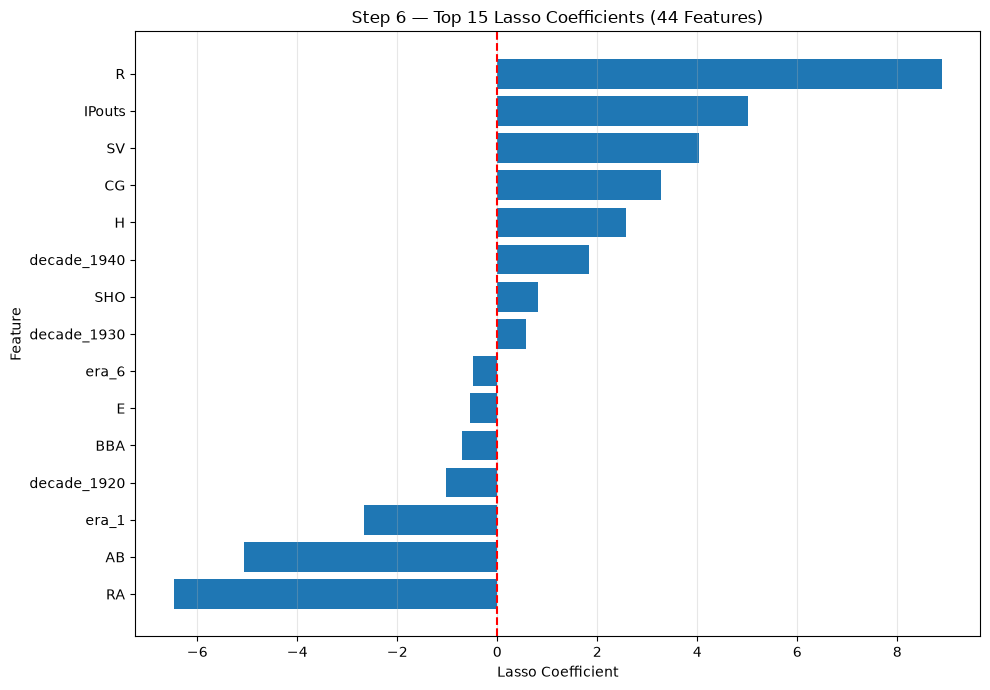

In [17]:
# ============================================================
# Step 6 — Lasso Feature Selection (44 Original Features)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Get feature names in the same order used by the pipeline
feature_names = (
    lasso_44.named_steps["preprocessing"]
    .get_feature_names_out()
)

# Remove preprocessing prefixes from names
feature_names = [
    name.split("__", 1)[-1]
    for name in feature_names
]

# Get Lasso coefficients
coefficients = lasso_44.named_steps["lasso"].coef_

# Create coefficient table
feature_df_44 = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_df_44["Absolute_Coefficient"] = (
    feature_df_44["Coefficient"].abs()
)

# Separate selected and zero-coefficient features
selected_df_44 = feature_df_44[
    feature_df_44["Absolute_Coefficient"] > 1e-6
].sort_values("Absolute_Coefficient", ascending=False)

zero_df_44 = feature_df_44[
    feature_df_44["Absolute_Coefficient"] <= 1e-6
]

print("Step 6 — Lasso Feature Selection")
print("--------------------------------")
print("Total Features:", len(feature_df_44))
print("Selected Features:", len(selected_df_44))
print("Zero Coefficients:", len(zero_df_44))

print("\nSelected Features:")
print(selected_df_44[["Feature", "Coefficient"]].to_string(index=False))

print("\nZero-Coefficient Features:")
print(zero_df_44["Feature"].to_string(index=False))

# Plot top 15 coefficients
top15 = selected_df_44.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top15["Feature"],
    top15["Coefficient"]
)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Lasso Coefficient")
plt.ylabel("Feature")
plt.title("Step 6 — Top 15 Lasso Coefficients (44 Features)")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Step 7 — Permutation Feature Importance
---------------------------------------
Model: Tuned Lasso Regression
Features: 44
Alpha: 0.01

Feature Importance Results:
    Feature  Importance_Mean  Importance_STD
          R         6.919894        0.369933
         RA         4.708178        0.214511
     IPouts         3.839526        0.148085
         AB         3.551904        0.105283
         SV         2.420093        0.169055
         CG         1.881524        0.104375
          H         1.242220        0.072594
        SHO         0.161708        0.039764
decade_1940         0.087170        0.018533
      era_1         0.084328        0.023593
          G         0.053278        0.010364
         HA         0.042662        0.019303
          E         0.041665        0.021361
        BBA         0.037390        0.034102
         3B         0.026853        0.011352
decade_1930         0.024815        0.007760
decade_1920         0.024027        0.018596
    mlb_rpg         0.0168

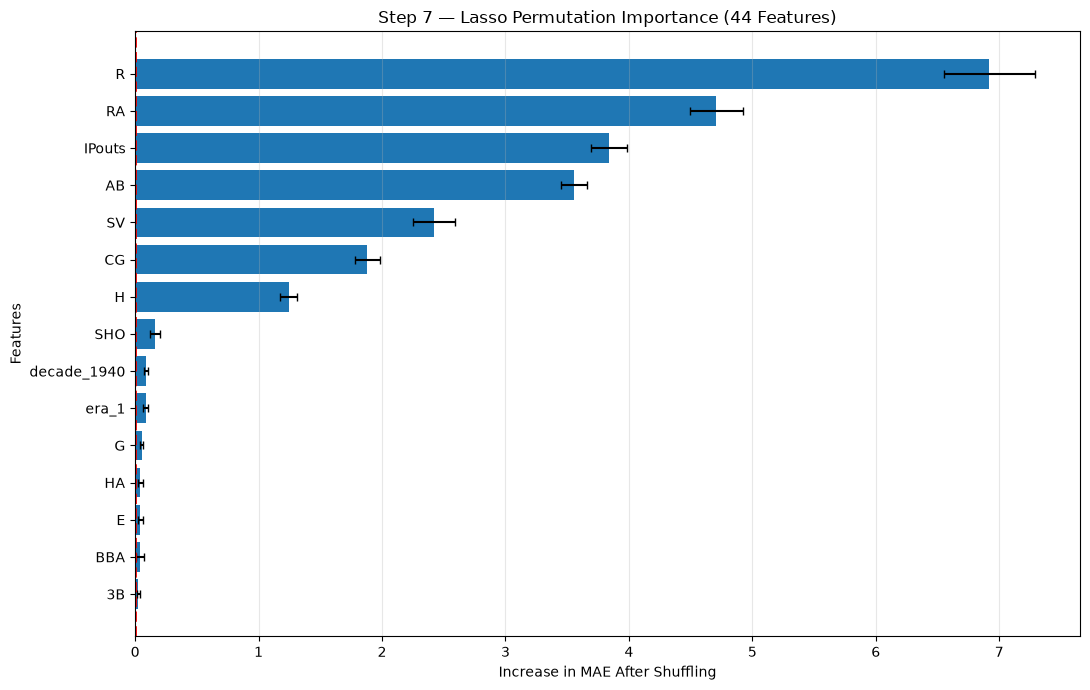

In [18]:
# ============================================================
# Step 7 — Permutation Feature Importance
# Tuned Lasso Regression (44 Original Features)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# Step 1 — Calculate permutation importance
step7_perm = permutation_importance(
    lasso_44,
    X_test_44,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Step 2 — Create feature importance table
step7_importance_df = pd.DataFrame({
    "Feature": X_test_44.columns,
    "Importance_Mean": step7_perm.importances_mean,
    "Importance_STD": step7_perm.importances_std
})

# Step 3 — Rank features
step7_importance_df = step7_importance_df.sort_values(
    "Importance_Mean",
    ascending=False
)

print("Step 7 — Permutation Feature Importance")
print("---------------------------------------")
print("Model: Tuned Lasso Regression")
print("Features: 44")
print("Alpha:", grid_44.best_params_["lasso__alpha"])

print("\nFeature Importance Results:")
print(step7_importance_df.round(6).to_string(index=False))

# Step 4 — Plot Top 15 Features
top15_step7 = step7_importance_df.head(15).sort_values(
    "Importance_Mean"
)

plt.figure(figsize=(11, 7))

plt.barh(
    top15_step7["Feature"],
    top15_step7["Importance_Mean"],
    xerr=top15_step7["Importance_STD"],
    capsize=3
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Increase in MAE After Shuffling")
plt.ylabel("Features")
plt.title("Step 7 — Lasso Permutation Importance (44 Features)")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Feature Engineering — Step 1: Adjust for Season Length

### Objective
Create a new feature to account for differences in the number of games played across MLB seasons.

### Business Rationale
MLB teams played different numbers of games across historical seasons. Comparing total runs scored may not provide a fair measure of offensive performance.

### Feature Engineering
Create a new feature called `R_per_game`:

**Formula:**

`R_per_game = R / G`

Where:
- `R` = Total runs scored
- `G` = Number of games played

### Expected Benefit
This feature measures average runs scored per game, allowing teams with different season lengths to be compared more consistently.

Whether this feature improves prediction accuracy will be evaluated later.

In [19]:
# Step 1 — Feature Engineering: Runs per Game

# Training dataset
data_df["R_per_game"] = data_df["R"] / data_df["G"]

# Kaggle prediction dataset
predict_df["R_per_game"] = predict_df["R"] / predict_df["G"]

# Verify new feature
print(data_df[["R", "G", "R_per_game"]].head())

     R    G  R_per_game
0  718  154    4.662338
1  835  162    5.154321
2  768  162    4.740741
3  713  154    4.629870
4  928  162    5.728395


Why do we update both datasets?
Because data.csv is used to train the model, while predict.csv is used to generate the Kaggle predictions. Both must contain the same engineered feature.

## Feature Engineering — Step 2: Runs Allowed per Game

### Objective
Create a feature to measure the average number of runs allowed per game.

### Rationale
MLB teams played different numbers of games across seasons. Total runs allowed (`RA`) may therefore be affected by season length.

Dividing runs allowed by games played allows a more consistent comparison of defensive performance.

### Formula
`RA_per_game = RA / G`

Where:
- `RA` = Total runs allowed
- `G` = Games played

### Expected Benefit
This feature measures run prevention per game instead of total runs allowed. Lower values generally indicate better defensive performance.

Its contribution to prediction accuracy will be evaluated during model training.

In [20]:
# Step 2 — Feature Engineering: Runs Allowed per Game

# Training dataset
data_df["RA_per_game"] = data_df["RA"] / data_df["G"]

# Kaggle prediction dataset
predict_df["RA_per_game"] = predict_df["RA"] / predict_df["G"]

# Verify new feature
print(data_df[["RA", "G", "RA_per_game"]].head())

    RA    G  RA_per_game
0  732  154     4.753247
1  751  162     4.635802
2  707  162     4.364198
3  598  154     3.883117
4  921  162     5.685185


## Feature Engineering — Step 3: Run Differential

### 1. Objective
Create a new feature, `Run_Differential`, to measure the difference between runs scored and runs allowed during an MLB season.

### 2. Rationale
Baseball teams win games by scoring more runs than their opponents.

Runs scored (`R`) measures offensive performance, while runs allowed (`RA`) measures run prevention.

Combining these two statistics provides a measure of overall scoring advantage.

### 3. Formula

`Run_Differential = R - RA`

Where:
- `R` = Total runs scored
- `RA` = Total runs allowed
- `Run_Differential` = Net runs scored during the season

### 4. Interpretation
- Positive value: The team scored more runs than it allowed.
- Negative value: The team allowed more runs than it scored.
- Zero: The team scored and allowed the same number of runs.

### 5. Expected Benefit
Run differential combines offensive and run-prevention performance into one feature that may help predict total season wins (`W`).

Its actual contribution to prediction accuracy will be evaluated later.

In [21]:
# Step 3 — Feature Engineering: Run Differential

# Training dataset
data_df["Run_Differential"] = data_df["R"] - data_df["RA"]

# Kaggle prediction dataset
predict_df["Run_Differential"] = predict_df["R"] - predict_df["RA"]

# Verify new feature
print(data_df[["R", "RA", "Run_Differential"]].head())

     R   RA  Run_Differential
0  718  732               -14
1  835  751                84
2  768  707                61
3  713  598               115
4  928  921                 7


In [22]:
# =====================================================
# LASSO — Prepare Separate Feature Dataset
# =====================================================

# Copy the original 44 features
X_lasso = X.copy()

# Add the 3 engineered features
engineered_features = [
    "R_per_game",
    "RA_per_game",
    "Run_Differential"
]

for col in engineered_features:
    X_lasso[col] = data_df[col]

# Verify feature counts
print("Original features:", X.shape[1])
print("Lasso features:", X_lasso.shape[1])

# Verify engineered features
print("\nEngineered features:")
print(X_lasso[engineered_features].head())

Original features: 44
Lasso features: 47

Engineered features:
   R_per_game  RA_per_game  Run_Differential
0    4.662338     4.753247               -14
1    5.154321     4.635802                84
2    4.740741     4.364198                61
3    4.629870     3.883117               115
4    5.728395     5.685185                 7


## Lasso Regression — Step 1: Prepare Training and Testing Data

### Objective
Prepare the Lasso dataset using 47 features while preserving the instructor's original 44-feature Linear Regression model.

### Method
Reuse the original training and testing row indices to ensure both models are evaluated on the same observations.

### Rationale
- Maintain consistency with the original 80/20 train/test split.
- Prevent changing the instructor's existing Linear Regression results.
- Prepare the engineered features for Lasso model training.

The target variable remains `W` (season wins).

In [23]:
# =====================================================
# Lasso — Step 1: Train/Test Preparation
# =====================================================

# Use the original training and testing row indices
X_lasso_train = X_lasso.loc[X_train.index].copy()
X_lasso_test = X_lasso.loc[X_test.index].copy()

# Keep the original target variable
y_lasso_train = y_train.copy()
y_lasso_test = y_test.copy()

# Verify dataset dimensions
print("Original features:", X.shape[1])
print("Lasso features:", X_lasso.shape[1])

print("\nLasso training shape:", X_lasso_train.shape)
print("Lasso testing shape:", X_lasso_test.shape)

Original features: 44
Lasso features: 47

Lasso training shape: (1129, 47)
Lasso testing shape: (283, 47)


## Lasso Regression — Step 2: Feature Scaling

### Objective
Standardize the numerical features in the Lasso dataset before model training.

### Rationale
Lasso Regression uses L1 regularization, which penalizes the absolute values of model coefficients.

Baseball statistics such as runs scored, earned run average and run differential have different numerical scales.

Standardization allows the L1 penalty to be applied more consistently across numerical features.

### Method
Use `StandardScaler` to standardize numerical features while retaining the original values of binary era and decade indicators.

The scaler is fitted using training data only and then applied to testing data to prevent data leakage.

A separate scaler is used to preserve the instructor's original Linear Regression preprocessing.

In [24]:
# =====================================================
# Lasso — Step 2: Feature Scaling
# =====================================================

from sklearn.preprocessing import StandardScaler

# Identify columns to scale
lasso_scale_cols = [
    col for col in X_lasso_train.columns
    if not col.startswith(("era_", "decade_"))
]

# Create separate scaler
lasso_scaler = StandardScaler()

# Copy datasets
X_lasso_train_scaled = X_lasso_train.copy()
X_lasso_test_scaled = X_lasso_test.copy()

# Fit scaler on training data only
X_lasso_train_scaled[lasso_scale_cols] = (
    lasso_scaler.fit_transform(
        X_lasso_train[lasso_scale_cols]
    )
)

# Apply same scaler to testing data
X_lasso_test_scaled[lasso_scale_cols] = (
    lasso_scaler.transform(
        X_lasso_test[lasso_scale_cols]
    )
)

# Verify
print("Lasso training:", X_lasso_train_scaled.shape)
print("Lasso testing:", X_lasso_test_scaled.shape)
print("Scaled features:", len(lasso_scale_cols))

Lasso training: (1129, 47)
Lasso testing: (283, 47)
Scaled features: 28


## Lasso Regression — Step 3: Model Training (E1)

### Objective
Train a Lasso Regression model to predict MLB season wins (`W`) using 47 features, including three engineered features.

### Rationale
Lasso Regression applies L1 regularization to reduce coefficient magnitudes and potentially remove redundant features by shrinking their coefficients to zero.

### Model Configuration

- **Algorithm:** Lasso Regression
- **Alpha:** 1.0 (initial value)
- **Maximum iterations:** 100,000
- **Training observations:** 1,129
- **Testing observations:** 283
- **Input features:** 47

### Expected Outcome
Train the model and generate predictions for both training and testing datasets. Model accuracy will be evaluated in the next step.

In [25]:
# =====================================================
# E1 — Lasso Regression: Model Training
# =====================================================

from sklearn.linear_model import Lasso

# Step 1 — Create Lasso model
lasso_e1 = Lasso(
    alpha=1.0,
    max_iter=100000
)

# Step 2 — Train model
lasso_e1.fit(X_lasso_train_scaled, y_lasso_train)

# Step 3 — Generate predictions
lasso_e1_train_preds = lasso_e1.predict(X_lasso_train_scaled)
lasso_e1_test_preds = lasso_e1.predict(X_lasso_test_scaled)

# Confirm training
print("E1 — Lasso Regression trained successfully!")
print("Alpha:", lasso_e1.alpha)
print("Training predictions:", len(lasso_e1_train_preds))
print("Testing predictions:", len(lasso_e1_test_preds))

E1 — Lasso Regression trained successfully!
Alpha: 1.0
Training predictions: 1129
Testing predictions: 283


## Lasso Regression — Step 4: Model Evaluation (E1)

### Objective
Evaluate the predictive performance of the Lasso Regression model using 47 features, including three engineered features.

### Evaluation Metrics

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted wins. Lower is better.
- **RMSE (Root Mean Squared Error):** Penalizes larger prediction errors more heavily. Lower is better.
- **R² (Coefficient of Determination):** Measures the proportion of variation in season wins explained by the model. Higher is generally better.

### Rationale
Compare training and testing performance to assess generalization and identify potential overfitting.

The official Kaggle competition metric is MAE, making it the primary metric for assessing model performance.

### Baseline Reference
The original 44-feature Linear Regression model achieved a test MAE of **2.7025 wins**.

This will serve as a reference, although the Lasso model uses three additional engineered features.

In [26]:
# =====================================================
# E1 — Step 4: Lasso Model Evaluation
# =====================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Training metrics
train_mae = mean_absolute_error(
    y_lasso_train, lasso_e1_train_preds
)

train_rmse = np.sqrt(mean_squared_error(
    y_lasso_train, lasso_e1_train_preds
))

train_r2 = r2_score(
    y_lasso_train, lasso_e1_train_preds
)

# Testing metrics
test_mae = mean_absolute_error(
    y_lasso_test, lasso_e1_test_preds
)

test_rmse = np.sqrt(mean_squared_error(
    y_lasso_test, lasso_e1_test_preds
))

test_r2 = r2_score(
    y_lasso_test, lasso_e1_test_preds
)

# Display results
print("E1 — Lasso Regression (alpha=1.0)")
print("----------------------------------")

print("\nTraining")
print(f"MAE : {train_mae:.4f}")
print(f"RMSE: {train_rmse:.4f}")
print(f"R²  : {train_r2:.4f}")

print("\nTesting")
print(f"MAE : {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R²  : {test_r2:.4f}")

print("\nGeneralization Gap")
print(f"MAE gap: {test_mae - train_mae:.4f}")

# Feature selection
selected = np.sum(np.abs(lasso_e1.coef_) > 1e-8)

print("\nFeature Selection")
print(f"Total features   : {len(lasso_e1.coef_)}")
print(f"Selected features: {selected}")
print(f"Zero coefficients: {len(lasso_e1.coef_) - selected}")

E1 — Lasso Regression (alpha=1.0)
----------------------------------

Training
MAE : 3.2763
RMSE: 4.1409
R²  : 0.9051

Testing
MAE : 3.1609
RMSE: 3.8578
R²  : 0.9069

Generalization Gap
MAE gap: -0.1153

Feature Selection
Total features   : 47
Selected features: 3
Zero coefficients: 44


In [27]:
# ============================================================
# E2 — Compare Lasso Regularization Strengths
# Adapted from instructor's L1 regularization example
# ============================================================

from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Step 1 — Try different alpha values
alphas = [1.0, 0.5, 0.1, 0.05, 0.01, 0.001]

# Step 2 — Use 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Step 3 — Keep scaling inside each CV fold
preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), lasso_scale_cols)
    ],
    remainder="passthrough"
)

# Step 4 — Compare alpha values
records = []

for alpha in alphas:

    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", Lasso(
            alpha=alpha,
            max_iter=100000
        ))
    ])

    # Cross-validation using MAE
    cv_mae = -cross_val_score(
        pipe,
        X_lasso_train,
        y_lasso_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    ).mean()

    # Train on full training dataset
    pipe.fit(X_lasso_train, y_lasso_train)

    # Count coefficients reduced to zero
    coefs = pipe.named_steps["model"].coef_

    n_zero = int(np.sum(np.abs(coefs) < 1e-6))

    # Store results
    records.append((
        alpha,
        cv_mae,
        len(coefs) - n_zero,
        n_zero,
        len(coefs)
    ))

# Step 5 — Display results
results_df = pd.DataFrame(
    records,
    columns=[
        "alpha",
        "CV_MAE",
        "Selected_Features",
        "Zero_Coefficients",
        "Total_Features"
    ]
)

print("E2 — Lasso Regularization Comparison")
print("-------------------------------------")
print(results_df.to_string(index=False))

# Step 6 — Find best alpha based on CV MAE
best_row = results_df.loc[results_df["CV_MAE"].idxmin()]

print("\nBest alpha:", best_row["alpha"])
print("Best CV MAE:", round(best_row["CV_MAE"], 4))

E2 — Lasso Regularization Comparison
-------------------------------------
 alpha   CV_MAE  Selected_Features  Zero_Coefficients  Total_Features
 1.000 3.299952                  3                 44              47
 0.500 3.137302                  6                 41              47
 0.100 2.959856                 13                 34              47
 0.050 2.875153                 18                 29              47
 0.010 2.819452                 32                 15              47
 0.001 2.824372                 43                  4              47

Best alpha: 0.01
Best CV MAE: 2.8195


## E3 — Tuned Lasso Regression (Alpha = 0.01)

### Objective

Evaluate the Lasso Regression model using the best alpha identified through five-fold cross-validation.

### Rationale

The E2 experiment compared six regularization strengths. Alpha = 0.01 achieved the lowest cross-validation MAE of 2.8195 and retained 32 out of 47 features.

### Methodology

- Model: Lasso Regression
- Alpha: 0.01
- Training observations: 1,129
- Testing observations: 283
- Input features: 47
- Feature scaling: StandardScaler fitted on training data

### Evaluation

Evaluate training and testing MAE, RMSE and R² to assess prediction accuracy and generalization.

The tuned model will be compared with the initial Lasso E1 model and the original Linear Regression baseline.

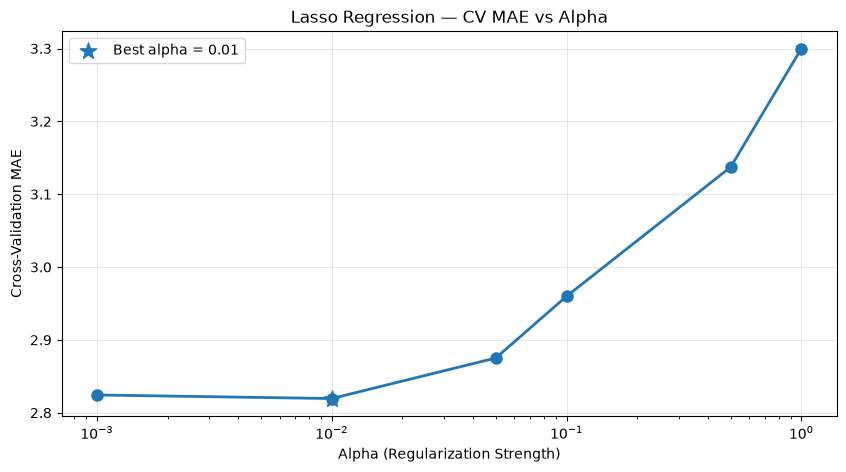

Best alpha: 0.01
Best CV MAE: 2.8195


In [28]:
# =====================================================
# E2 — Visualize Lasso Alpha Tuning
# =====================================================

import matplotlib.pyplot as plt

# Sort alpha values for plotting
plot_df = results_df.sort_values("alpha")

# Plot alpha vs cross-validation MAE
fig, ax = plt.subplots(figsize=(10, 5))

ax.semilogx(
    plot_df["alpha"],
    plot_df["CV_MAE"],
    "o-",
    linewidth=2,
    markersize=8
)

# Highlight best alpha
best_idx = plot_df["CV_MAE"].idxmin()
best_alpha = plot_df.loc[best_idx, "alpha"]
best_mae = plot_df.loc[best_idx, "CV_MAE"]

ax.scatter(
    best_alpha,
    best_mae,
    s=150,
    marker="*",
    zorder=5,
    label=f"Best alpha = {best_alpha}"
)

ax.set_xlabel("Alpha (Regularization Strength)")
ax.set_ylabel("Cross-Validation MAE")
ax.set_title("Lasso Regression — CV MAE vs Alpha")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

print(f"Best alpha: {best_alpha}")
print(f"Best CV MAE: {best_mae:.4f}")

### E2 — Lasso Hyperparameter Tuning: Graph Interpretation

**Objective:** Identify the regularization strength (`alpha`) that minimizes cross-validation Mean Absolute Error (MAE).

**Results:**
- Best tested alpha: **0.01**
- Lowest cross-validation MAE: **2.8195 wins**
- Selected features at alpha = 0.01: **32 out of 47**
- Zero coefficients: **15**

**Interpretation:**

The graph shows that increasing alpha beyond 0.01 leads to higher cross-validation MAE. At alpha = 1.0, the MAE reaches approximately 3.30, indicating poorer predictive performance.

Reducing alpha from 1.0 to 0.01 improves prediction accuracy. However, further reducing alpha to 0.001 results in a slightly higher MAE of 2.8244.

**Conclusion:**

Alpha = 0.01 provides the lowest cross-validation MAE among the six tested values, suggesting a suitable balance between regularization and predictive accuracy.

This result will be validated using the held-out testing dataset.

In [29]:
# E3 — Evaluate Tuned Lasso Regression

from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train tuned Lasso
lasso_e3 = Lasso(alpha=0.01, max_iter=100000)
lasso_e3.fit(X_lasso_train_scaled, y_lasso_train)

# Predictions
e3_train_preds = lasso_e3.predict(X_lasso_train_scaled)
e3_test_preds = lasso_e3.predict(X_lasso_test_scaled)

# Evaluation
print("E3 — Tuned Lasso (alpha=0.01)")

for name, actual, predictions in [
    ("Training", y_lasso_train, e3_train_preds),
    ("Testing", y_lasso_test, e3_test_preds)
]:
    print(f"\n{name}")
    print(f"MAE : {mean_absolute_error(actual, predictions):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(actual, predictions)):.4f}")
    print(f"R²  : {r2_score(actual, predictions):.4f}")

print("\nSelected features:",
      np.sum(np.abs(lasso_e3.coef_) > 1e-6))

E3 — Tuned Lasso (alpha=0.01)

Training
MAE : 2.6970
RMSE: 3.4097
R²  : 0.9357

Testing
MAE : 2.6883
RMSE: 3.3242
R²  : 0.9308

Selected features: 32


## E3 — Tuned Lasso Regression: Results and Interpretation

### 1. Objective

Evaluate the tuned Lasso Regression model using the best alpha identified through five-fold cross-validation.

### 2. Model Configuration

- Algorithm: Lasso Regression (L1 regularization)
- Alpha: 0.01
- Input features: 47
- Training observations: 1,129
- Testing observations: 283

### 3. Model Performance

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 2.6970 | 2.6883 |
| RMSE | 3.4097 | 3.3242 |
| R² | 0.9357 | 0.9308 |

### 4. Feature Selection

- Total features: 47
- Selected features: 32
- Zero coefficients: 15

### 5. Interpretation

The tuned Lasso model achieved a test MAE of 2.6883 wins, compared with 3.1609 for the initial Lasso model.

The lower test MAE demonstrates improved prediction accuracy following alpha tuning.

The small difference between training and testing MAE suggests no substantial generalization gap on the current data split.

L1 regularization reduced the number of active features from 47 to 32.

### 6. Comparison with Original Linear Regression

The original Linear Regression model achieved a test MAE of 2.7025, compared with 2.6883 for the tuned Lasso.

The tuned Lasso achieved a slightly lower prediction error. However, because the two models used different feature sets, the improvement cannot be attributed solely to L1 regularization.

### 7. Conclusion

Alpha = 0.01 produced the best cross-validation performance among the six alpha values tested.

The tuned Lasso model achieved good predictive accuracy while eliminating 15 feature coefficients.

The results support Lasso Regression as a competitive model for predicting MLB season wins, although further validation would be needed to establish a consistent advantage over ordinary Linear Regression.

In [30]:
# E3 — Identify Selected Lasso Features

lasso_feature_results = pd.DataFrame({
    "Feature": X_lasso_train_scaled.columns,
    "Coefficient": lasso_e3.coef_
})

# Keep nonzero coefficients
selected_features = lasso_feature_results[
    lasso_feature_results["Coefficient"].abs() > 1e-6
].copy()

# Sort by absolute coefficient
selected_features = selected_features.reindex(
    selected_features["Coefficient"].abs()
    .sort_values(ascending=False).index
)

print("Selected features:", len(selected_features))
print(selected_features.to_string(index=False))

# Check our 3 engineered features
print("\nEngineered Feature Coefficients:")

print(lasso_feature_results[
    lasso_feature_results["Feature"].isin([
        "R_per_game",
        "RA_per_game",
        "Run_Differential"
    ])
].to_string(index=False))

Selected features: 32
         Feature  Coefficient
Run_Differential     8.028141
              AB    -5.029301
          IPouts     4.961442
              SV     4.016121
              CG     3.248602
           era_1    -2.603778
               H     2.560583
               R     2.072792
     decade_1940     1.789949
     decade_1920    -1.035706
             SHO     0.803270
             BBA    -0.681355
     decade_1930     0.542127
           era_6    -0.499370
     decade_1990    -0.467919
               E    -0.462434
             SOA     0.458157
     decade_1950     0.439460
              HR     0.377545
              BB    -0.350190
               G    -0.344143
              HA    -0.336922
         mlb_rpg     0.301098
              3B     0.259071
              SB    -0.200278
              2B     0.189950
     decade_1970     0.166975
     decade_1910    -0.078806
              DP     0.059329
              SO     0.020903
           era_7    -0.017864
           era_4  

## E3 — Lasso Feature Selection and Interpretation

### Objective

Identify the features retained by the tuned Lasso Regression model (`alpha=0.01`) and examine the contribution of the three engineered features.

### Results

- Total features: 47
- Selected features: 32
- Zero coefficients: 15

### Engineered Feature Selection

| Feature | Coefficient | Status |
|---|---:|---|
| `R_per_game` | 0.0000 | Eliminated |
| `RA_per_game` | 0.0000 | Eliminated |
| `Run_Differential` | +8.0281 | Selected |

### Interpretation

The tuned Lasso model retained `Run_Differential` with a positive coefficient of 8.0281, indicating a positive conditional relationship between standardized run differential and predicted season wins.

The coefficients of `R_per_game` and `RA_per_game` were reduced to zero.

These features contain overlapping information with existing baseball statistics, which may explain why Lasso did not retain them.

### Conclusion

Lasso reduced the original 47 candidate features to 32 active features.

Among the three engineered features, only `Run_Differential` was retained.

The tuned model achieved a test MAE of **2.6883 wins**, demonstrating competitive predictive performance while reducing the number of active features.

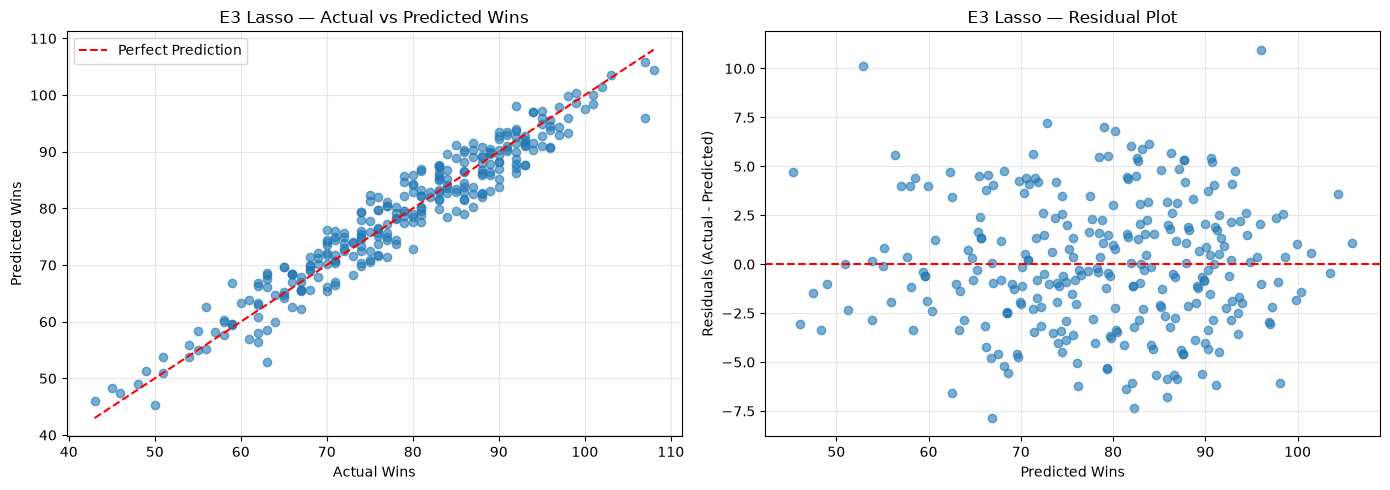

In [31]:
# =====================================================
# E3 — Tuned Lasso Regression: Model Visualization
# Alpha = 0.01
# =====================================================

import matplotlib.pyplot as plt
import numpy as np

# Calculate residuals
lasso_residuals = y_lasso_test - e3_test_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -----------------------------------------------------
# Graph 1 — Actual vs Predicted Wins
# -----------------------------------------------------

axes[0].scatter(
    y_lasso_test,
    e3_test_preds,
    alpha=0.6
)

# Perfect prediction reference line
min_val = min(y_lasso_test.min(), e3_test_preds.min())
max_val = max(y_lasso_test.max(), e3_test_preds.max())

axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

axes[0].set_title("E3 Lasso — Actual vs Predicted Wins")
axes[0].set_xlabel("Actual Wins")
axes[0].set_ylabel("Predicted Wins")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# -----------------------------------------------------
# Graph 2 — Residual Plot
# -----------------------------------------------------

axes[1].scatter(
    e3_test_preds,
    lasso_residuals,
    alpha=0.6
)

axes[1].axhline(
    y=0,
    color="red",
    linestyle="--"
)

axes[1].set_title("E3 Lasso — Residual Plot")
axes[1].set_xlabel("Predicted Wins")
axes[1].set_ylabel("Residuals (Actual - Predicted)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## E3 — Tuned Lasso Regression: Model Visualization

### Objective

Visualize the predictive performance of the tuned Lasso Regression model (`alpha=0.01`) using the held-out testing dataset.

### Graph 1 — Actual vs Predicted Wins

This scatter plot compares actual MLB season wins against predicted wins.

The diagonal reference line represents perfect predictions.

Points closer to the diagonal indicate smaller prediction errors.

### Graph 2 — Residual Plot

Residuals are calculated as:

`Residual = Actual Wins - Predicted Wins`

- Positive residual: Model underestimated actual wins.
- Negative residual: Model overestimated actual wins.
- Residual near zero: Prediction was close to the actual value.

### Model Performance

| Metric | E3 Tuned Lasso |
|---|---:|
| Alpha | 0.01 |
| Test MAE | 2.6883 |
| Test RMSE | 3.3242 |
| Test R² | 0.9308 |
| Selected features | 32 |
| Zero coefficients | 15 |

### Conclusion

The tuned Lasso model achieved a test MAE of 2.6883 wins and an R² of 0.9308.

The visualizations will be examined to determine whether predictions closely follow actual wins and whether residuals exhibit systematic patterns.

## E3 — Tuned Lasso Regression: Visualization Results

### 1. Actual vs Predicted Wins

The scatter plot shows that most predicted values are close to the diagonal reference line, indicating a strong agreement between actual and predicted MLB season wins.

Some deviations are observed, particularly among higher-win teams.

The model achieved a testing R² of 0.9308, indicating that approximately 93.08% of the variation in wins in the testing dataset was explained by the model.

### 2. Residual Analysis

The residual plot shows prediction errors distributed on both sides of zero, without an obvious strong nonlinear pattern.

Most residuals are relatively small, although a few larger errors are present.

The distribution suggests no major systematic bias is visually apparent, but the graph alone cannot confirm that all regression assumptions are satisfied.

### 3. Model Performance Summary

| Metric | Tuned Lasso (E3) |
|---|---:|
| Alpha | 0.01 |
| Training MAE | 2.6970 |
| Testing MAE | 2.6883 |
| Testing RMSE | 3.3242 |
| Testing R² | 0.9308 |
| Selected features | 32 |
| Zero coefficients | 15 |

### 4. Conclusion

The tuned Lasso Regression model demonstrates strong predictive performance on the held-out test dataset.

The close training and testing MAE values indicate no substantial generalization gap in this split.

The model also reduces the number of active features from 47 to 32 through L1 regularization.

Overall, the results support the tuned Lasso model as a suitable candidate for predicting MLB season wins.

## E3 — Kaggle Submission: Tuned Lasso Regression

### Objective
Generate predictions for the 400 unseen MLB team-season observations in `predict.csv` using the tuned Lasso Regression model.

### Model Configuration
- Model: Lasso Regression
- Alpha: 0.01
- Input features: 47 (44 original + 3 engineered)
- Selected features: 32
- Test MAE: 2.6883
- Test R²: 0.9308

### Methodology
1. Prepare the Kaggle prediction dataset with the same 47 features used during Lasso training.
2. Apply the previously fitted Lasso scaler.
3. Generate predictions using the tuned Lasso model.
4. Round predicted wins to whole numbers.
5. Save the predictions in the required Kaggle submission format.

### Submission Format
The submission contains two columns:

- `ID`: Unique team-season identifier
- `W`: Predicted number of season wins

The predicted wins must be whole numbers.

### Expected Outcome
Generate `lasso_submission.csv` containing 400 predictions, ready for upload to Kaggle.

In [32]:
# =====================================================
# E3 — Final Kaggle Submission: Tuned Lasso
# =====================================================

import numpy as np
import pandas as pd

# Step 1 — Prepare the original 44 features
X_lasso_predict = predict_df[X.columns].copy()

# Step 2 — Add the 3 engineered features
# Calculate directly from original columns
X_lasso_predict["R_per_game"] = (
    predict_df["R"] / predict_df["G"]
)

X_lasso_predict["RA_per_game"] = (
    predict_df["RA"] / predict_df["G"]
)

X_lasso_predict["Run_Differential"] = (
    predict_df["R"] - predict_df["RA"]
)

# Step 3 — Align with Lasso training features
X_lasso_predict = X_lasso_predict[
    X_lasso_train.columns
]

# Step 4 — Apply the fitted Lasso scaler
X_lasso_predict_scaled = X_lasso_predict.copy()

X_lasso_predict_scaled[lasso_scale_cols] = (
    lasso_scaler.transform(
        X_lasso_predict[lasso_scale_cols]
    )
)

# Step 5 — Predict using tuned Lasso
lasso_final_preds = lasso_e3.predict(
    X_lasso_predict_scaled
)

# Step 6 — Round predictions to whole numbers
lasso_final_preds = np.clip(
    np.rint(lasso_final_preds),
    0,
    predict_df["G"].to_numpy()
).astype(int)

# Step 7 — Create Kaggle submission
lasso_submission_df = pd.DataFrame({
    "ID": predict_df["ID"],
    "W": lasso_final_preds
})

# Step 8 — Save to a separate file
lasso_submission_df.to_csv(
    "lasso_submission.csv",
    index=False
)

# Step 9 — Verify
print("Lasso Kaggle Submission")
print("-------------------------")
print(lasso_submission_df.head())

print("\nSubmission shape:", lasso_submission_df.shape)
print("Missing values:", lasso_submission_df.isna().sum().sum())
print("File saved: lasso_submission.csv")

Lasso Kaggle Submission
-------------------------
     ID   W
0  1649  77
1  1223  77
2   748  82
3  1735  85
4   794  79

Submission shape: (400, 2)
Missing values: 0
File saved: lasso_submission.csv


## 4. Lasso Regression — All 47 Feature Results

### 4.1 Objective

Examine how L1 regularization performs feature selection in the
tuned Lasso Regression model (`alpha=0.01`).

The model initially contained 47 features:
- 44 original features
- 3 engineered features

### 4.2 Feature Selection Summary

| Item | Result |
|---|---:|
| Total Input Features | 47 |
| Original Features | 44 |
| Engineered Features | 3 |
| Selected Features | 32 |
| Zero Coefficients | 15 |
| Best Alpha | 0.01 |
| Cross-Validation MAE | 2.8195 |
| Test MAE | 2.6883 |
| Test R² | 0.9308 |

### 4.3 Complete Feature Selection Results

The following table shows the coefficients obtained from E3 Tuned Lasso.

| No. | Feature | Lasso Coefficient | Status |
|---|---|---:|---|
| 1 | G | -0.3441 | Selected |
| 2 | R | 2.0728 | Selected |
| 3 | AB | -5.0293 | Selected |
| 4 | H | 2.5606 | Selected |
| 5 | 2B | 0.1900 | Selected |
| 6 | 3B | 0.2591 | Selected |
| 7 | HR | 0.3775 | Selected |
| 8 | BB | -0.3502 | Selected |
| 9 | SO | 0.0209 | Selected |
| 10 | SB | -0.2003 | Selected |
| 11 | RA | 0.0000 | Eliminated |
| 12 | ER | 0.0000 | Eliminated |
| 13 | ERA | 0.0000 | Eliminated |
| 14 | CG | 3.2486 | Selected |
| 15 | SHO | 0.8033 | Selected |
| 16 | SV | 4.0161 | Selected |
| 17 | IPouts | 4.9614 | Selected |
| 18 | HA | -0.3369 | Selected |
| 19 | HRA | 0.0000 | Eliminated |
| 20 | BBA | -0.6814 | Selected |
| 21 | SOA | 0.4582 | Selected |
| 22 | E | -0.4624 | Selected |
| 23 | DP | 0.0593 | Selected |
| 24 | FP | 0.0000 | Eliminated |
| 25 | mlb_rpg | 0.3011 | Selected |
| 26 | era_1 | -2.6038 | Selected |
| 27 | era_2 | 0.0000 | Eliminated |
| 28 | era_3 | 0.0000 | Eliminated |
| 29 | era_4 | 0.0051 | Selected |
| 30 | era_5 | 0.0000 | Eliminated |
| 31 | era_6 | -0.4994 | Selected |
| 32 | era_7 | -0.0179 | Selected |
| 33 | era_8 | 0.0000 | Eliminated |
| 34 | decade_1910 | -0.0788 | Selected |
| 35 | decade_1920 | -1.0357 | Selected |
| 36 | decade_1930 | 0.5421 | Selected |
| 37 | decade_1940 | 1.7899 | Selected |
| 38 | decade_1950 | 0.4395 | Selected |
| 39 | decade_1960 | 0.0000 | Eliminated |
| 40 | decade_1970 | 0.1670 | Selected |
| 41 | decade_1980 | 0.0000 | Eliminated |
| 42 | decade_1990 | -0.4679 | Selected |
| 43 | decade_2000 | 0.0000 | Eliminated |
| 44 | decade_2010 | 0.0000 | Eliminated |
| 45 | R_per_game | 0.0000 | Eliminated |
| 46 | RA_per_game | 0.0000 | Eliminated |
| 47 | Run_Differential | 8.0281 | Selected |

### 4.4 Engineered Feature Results

| Engineered Feature | Coefficient | Result |
|---|---:|---|
| R_per_game | 0.0000 | Eliminated |
| RA_per_game | 0.0000 | Eliminated |
| Run_Differential | 8.0281 | Selected |

**Interpretation:**

Among the three engineered features, only Run Differential
was retained by the tuned Lasso model.

The coefficients for Runs per Game and Runs Allowed per Game
were reduced to zero.

This may be due to overlapping information among the features.

### 4.5 Interpretation of Zero Coefficients

Lasso Regression uses L1 regularization to shrink coefficients.

A zero coefficient means that the corresponding feature does
not contribute directly to the fitted prediction equation.

However, a zero coefficient does not necessarily indicate that
a feature is unimportant in reality.

Correlated features may contain overlapping predictive information.

### 4.6 Key Findings

1. Lasso initially received 47 features.
2. L1 regularization retained 32 active features.
3. Fifteen feature coefficients were reduced to zero.
4. Run Differential was retained among the engineered features.
5. The tuned model achieved a test MAE of 2.6883 wins.
6. The testing R² was 0.9308.

### 4.7 Conclusion

The tuned Lasso Regression model (`alpha=0.01`) retained
32 of the original 47 input features.

Fifteen coefficients were reduced to zero through L1 regularization,
demonstrating automatic feature selection.

Among the engineered features, Run Differential was retained
with a positive coefficient of 8.0281.

The results demonstrate that Lasso can reduce the number
of active features while maintaining strong prediction accuracy.

Coefficient magnitudes should be interpreted cautiously because
the binary era and decade indicators were not standardized,
and several baseball statistics contain overlapping information.


In [33]:
# =====================================================
# Display MLB Teams and Predicted Season Wins
# =====================================================

# Combine team information with Lasso predictions
team_predictions = predict_df[
    ["ID", "teamID"]
].merge(
    lasso_submission_df,
    on="ID",
    how="left"
)

# Sort teams by predicted wins
team_predictions = team_predictions.sort_values(
    by="W",
    ascending=False
)

# Display top 10 predicted team-seasons
print("Top 10 Predicted MLB Team-Seasons")
print("--------------------------------")
print(team_predictions.head(10).to_string(index=False))

Top 10 Predicted MLB Team-Seasons
--------------------------------
  ID teamID   W
 398    CHN 110
1896    NY1 104
1433    NYA 103
1499    PHA 103
 680    CIN 103
  55    ARI 103
1771    PIT 102
1500    PHA 102
1402    NYA 102
1474    NYA 102


In [34]:
# =====================================================
# E3 — MLB Season Wins Prediction Results
# Tuned Lasso Regression (alpha = 0.01)
# =====================================================

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

# Step 1 — Get MLB team information from the test dataset
mlb_results = data_df.loc[
    X_lasso_test.index,
    ["yearID", "teamID", "G"]
].copy()

# Step 2 — Actual season wins
mlb_results["Actual_Wins"] = y_lasso_test.to_numpy()

# Step 3 — Predicted season wins using E3 Lasso
mlb_results["Predicted_Wins"] = np.clip(
    np.rint(e3_test_preds),
    0,
    mlb_results["G"].to_numpy()
).astype(int)

# Step 4 — Calculate prediction error
mlb_results["Absolute_Error"] = abs(
    mlb_results["Actual_Wins"] -
    mlb_results["Predicted_Wins"]
)

# Step 5 — Display results
print("MLB Season Wins — Actual vs Predicted")
print("--------------------------------------")

print(mlb_results.head(10).to_string(index=False))

# Step 6 — Evaluate original unrounded predictions
mae = mean_absolute_error(
    y_lasso_test,
    e3_test_preds
)

print(f"\nLasso Test MAE: {mae:.4f}")

MLB Season Wins — Actual vs Predicted
--------------------------------------
 yearID teamID   G  Actual_Wins  Predicted_Wins  Absolute_Error
   1966    ATL 163           85              91               6
   1986    SEA 162           67              68               1
   1976    SDN 162           73              68               5
   1931    CIN 154           58              58               0
   2002    CLE 162           74              70               4
   2003    PHI 162           86              87               1
   1951    BSN 155           76              82               6
   2004    ARI 162           51              54               3
   1989    PHI 163           67              66               1
   2009    SLN 162           91              90               1

Lasso Test MAE: 2.6883


## E3 — MLB Season Wins: Actual vs Predicted Results

### Objective
Evaluate how accurately the tuned Lasso Regression model predicts historical MLB season wins.

### Results
The model was evaluated on 283 held-out team-season observations.

- Test MAE: **2.6883 wins**
- Test RMSE: **3.3242 wins**
- Test R²: **0.9308**

### Sample Prediction Analysis

Among the first 10 testing observations:

- 5 predictions overestimated actual wins.
- 4 predictions underestimated actual wins.
- 1 prediction matched actual wins exactly.

### Interpretation
The tuned Lasso model predicts season wins with an average absolute error of approximately 2.69 games across the testing dataset.

The displayed sample includes both overestimations and underestimations, indicating that the model does not consistently predict in one direction within these observations.

However, the overall direction of prediction bias requires analysis of all 283 test observations.

### Conclusion
The tuned Lasso Regression model demonstrates strong predictive performance when estimating MLB season wins from completed season statistics.

The model achieved an R² of 0.9308 while retaining 32 active features through L1 regularization.

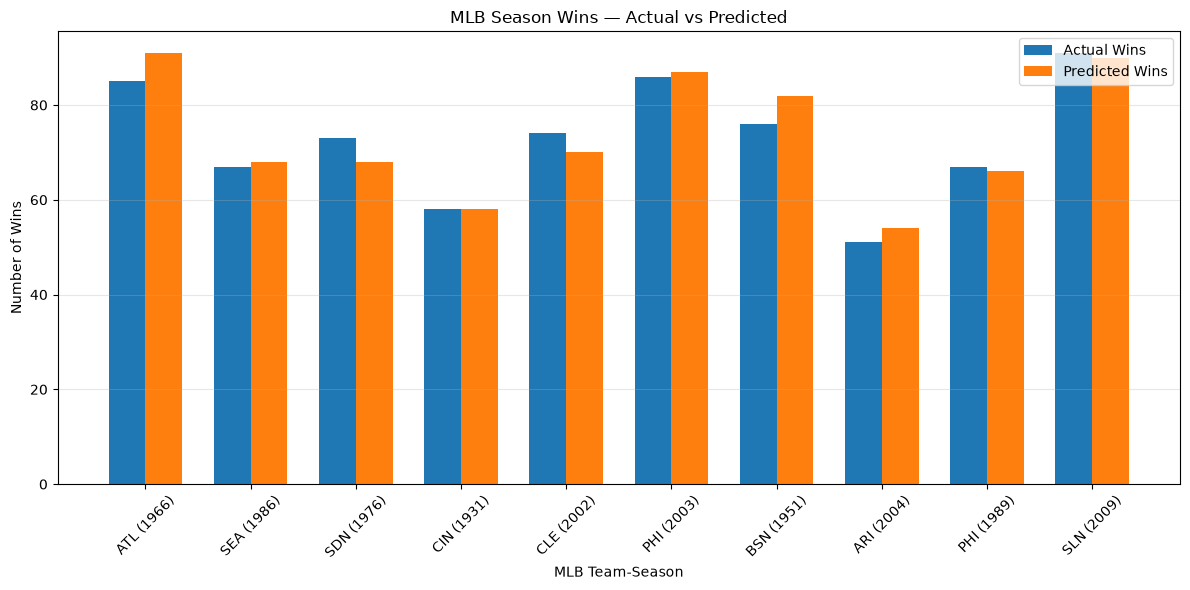

In [35]:
# =====================================================
# Chart — Actual vs Predicted MLB Season Wins
# =====================================================

import matplotlib.pyplot as plt
import numpy as np

# Copy the first 10 rows from your results
chart_df = mlb_results.head(10).copy()

# Create label: team + year
chart_df["Label"] = (
    chart_df["teamID"].astype(str) + " (" +
    chart_df["yearID"].astype(str) + ")"
)

# Plot settings
x = np.arange(len(chart_df))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    chart_df["Actual_Wins"],
    width,
    label="Actual Wins"
)

plt.bar(
    x + width/2,
    chart_df["Predicted_Wins"],
    width,
    label="Predicted Wins"
)

plt.xticks(x, chart_df["Label"], rotation=45)
plt.xlabel("MLB Team-Season")
plt.ylabel("Number of Wins")
plt.title("MLB Season Wins — Actual vs Predicted")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
# E3 — Check Lasso Prediction Bias

import numpy as np

residuals = np.asarray(y_lasso_test) - e3_test_preds

mean_residual = np.mean(residuals)

underestimated = np.sum(residuals > 0)
overestimated = np.sum(residuals < 0)

print("E3 — Lasso Prediction Bias")
print("-------------------------")
print(f"Mean Residual: {mean_residual:.4f}")
print(f"Underestimated: {underestimated}")
print(f"Overestimated : {overestimated}")

if mean_residual > 0:
    print("\nOverall: Lasso tends to UNDERESTIMATE wins.")
elif mean_residual < 0:
    print("\nOverall: Lasso tends to OVERESTIMATE wins.")
else:
    print("\nOverall: No average prediction bias.")

E3 — Lasso Prediction Bias
-------------------------
Mean Residual: -0.0663
Underestimated: 135
Overestimated : 148

Overall: Lasso tends to OVERESTIMATE wins.


## E3 — Lasso Regression: Prediction Bias Analysis

### Objective
Evaluate whether the tuned Lasso Regression model
systematically underestimates or overestimates MLB season wins.

### Results

| Metric | Result |
|---|---:|
| Mean Residual | -0.0663 |
| Underestimated Predictions | 135 |
| Overestimated Predictions | 148 |
| Total Test Observations | 283 |
| Test MAE | 2.6883 |

### Interpretation

The model slightly overestimated season wins, with a
mean residual of -0.0663 wins.

Out of 283 testing observations, 148 were overestimated
and 135 were underestimated.

The mean residual is close to zero, suggesting minimal
overall prediction bias on the testing dataset.

### Conclusion

The tuned Lasso model demonstrates approximately balanced
prediction errors with no substantial overall directional bias.

Although the model slightly overestimates season wins,
the average signed error is small relative to its
test MAE of 2.6883 wins.

E4 — Permutation Feature Importance
-----------------------------------
         Feature  Importance_Mean  Importance_STD
Run_Differential         6.330565        0.379625
          IPouts         3.790457        0.146720
              AB         3.525530        0.104624
              SV         2.409056        0.168514
              CG         1.869033        0.103320
               H         1.233471        0.072055
               R         0.863883        0.064690
             SHO         0.160405        0.039293
     decade_1940         0.085162        0.018222
           era_1         0.081072        0.023394
               G         0.051272        0.009952
             BBA         0.033183        0.032421
              HA         0.031348        0.017022
               E         0.030547        0.018734
              3B         0.026872        0.011225
     decade_1920         0.024451        0.018858
     decade_1930         0.023092        0.007428
         mlb_rpg         0.0

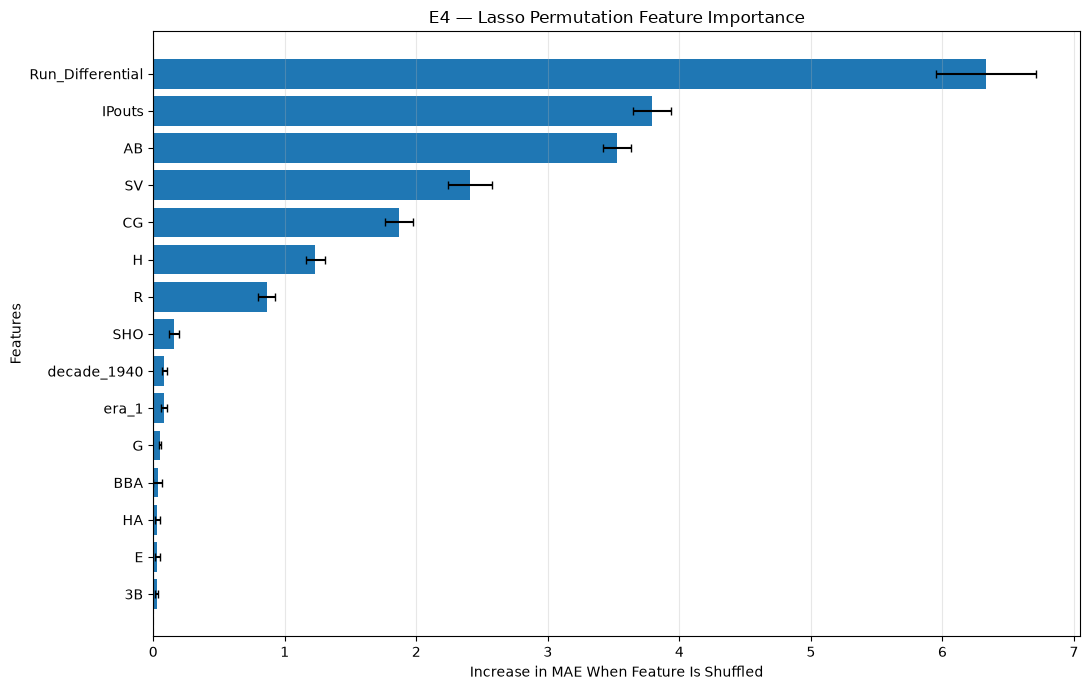

In [37]:
# =====================================================
# E4 — Permutation Feature Importance
# Tuned Lasso Regression (alpha = 0.01)
# =====================================================

from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Step 1 — Calculate permutation importance
perm_result = permutation_importance(
    lasso_e3,
    X_lasso_test_scaled,
    y_lasso_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Step 2 — Create feature importance table
perm_df = pd.DataFrame({
    "Feature": X_lasso_test_scaled.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_STD": perm_result.importances_std
})

# Step 3 — Sort by importance
perm_df = perm_df.sort_values(
    by="Importance_Mean",
    ascending=False
)

# Step 4 — Display all 47 features
print("E4 — Permutation Feature Importance")
print("-----------------------------------")
print(perm_df.to_string(index=False))

# Step 5 — Plot top 15 features
top15 = perm_df.head(15).sort_values(
    by="Importance_Mean",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top15["Feature"],
    top15["Importance_Mean"],
    xerr=top15["Importance_STD"],
    capsize=3
)

plt.axvline(0, linestyle="--", color="gray")

plt.xlabel("Increase in MAE When Feature Is Shuffled")
plt.ylabel("Features")
plt.title("E4 — Lasso Permutation Feature Importance")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## E4 — Permutation Feature Importance

### Objective

Evaluate the importance of individual features in the tuned Lasso Regression model by measuring changes in prediction accuracy when feature values are randomly shuffled.

### Methodology

Permutation importance is calculated using the held-out testing dataset.

- Model: Tuned Lasso Regression
- Alpha: 0.01
- Input features: 47
- Evaluation metric: Mean Absolute Error (MAE)
- Permutation repetitions: 10

### Interpretation

A higher positive permutation importance indicates that shuffling a feature produces a larger increase in prediction error.

Features with importance near zero have little measured effect when shuffled individually.

Negative values indicate that shuffling slightly improved prediction accuracy.

### Limitation

Correlated features may share predictive information. Therefore, individual permutation importance values may not fully represent their contribution.

Permutation importance describes model reliance rather than causal importance.

### Conclusion

The analysis will identify which features the tuned Lasso model relies on most strongly when predicting MLB season wins.

## E4 — Permutation Feature Importance: Results and Interpretation

### 1. Objective

Evaluate how strongly the tuned Lasso Regression model relies on each feature when predicting MLB season wins.

### 2. Methodology

Permutation Feature Importance was calculated using the held-out testing dataset.

- Model: Tuned Lasso Regression
- Alpha: 0.01
- Input features: 47
- Repetitions: 10
- Evaluation metric: MAE

### 3. Top Features

| Rank | Feature | Mean Importance |
|---|---|---:|
| 1 | Run_Differential | 6.3306 |
| 2 | IPouts | 3.7905 |
| 3 | AB | 3.5255 |
| 4 | SV | 2.4091 |
| 5 | CG | 1.8690 |
| 6 | H | 1.2335 |
| 7 | R | 0.8639 |

### 4. Key Findings

**Run Differential** recorded the highest permutation importance of 6.3306, indicating that the fitted model relies strongly on this engineered feature.

Pitching outs (`IPouts`) and at bats (`AB`) were the next most influential features according to the permutation analysis.

Among the three engineered features, `R_per_game` and `RA_per_game` recorded zero permutation importance, consistent with their zero Lasso coefficients.

### 5. Limitations

Permutation importance measures changes in model prediction accuracy when individual features are shuffled.

Correlated features can distort permutation importance because shuffling may produce unrealistic combinations of observations.

Therefore, the rankings represent model reliance rather than causal relationships or independently established baseball performance drivers.

### 6. Conclusion

Permutation Feature Importance supports the E3 coefficient analysis by identifying Run Differential as the feature with the largest measured impact on prediction accuracy when shuffled.

The tuned Lasso model achieved a test MAE of 2.6883 wins while retaining 32 active features.

The analysis provides additional interpretability but does not establish that the selected features cause teams to win more games.

In [38]:
# =====================================================
# E5 — Lasso Regression: Original 44 Features
# No Feature Engineering
# =====================================================

import numpy as np

from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Step 1 — Copy original 44 features
X_train_44 = X_train.copy()
X_test_44 = X_test.copy()

print("Original features:", X_train_44.shape[1])

# Step 2 — Identify numerical features
scale_cols_44 = [
    col for col in X_train_44.columns
    if not col.startswith(("era_", "decade_"))
]

# Step 3 — Create preprocessing
preprocessor_44 = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), scale_cols_44)
    ],
    remainder="passthrough"
)

# Step 4 — Create Lasso pipeline
pipeline_44 = Pipeline([
    ("preprocessing", preprocessor_44),
    ("lasso", Lasso(max_iter=100000))
])

# Step 5 — Alpha tuning
param_grid = {
    "lasso__alpha": [
        1.0, 0.5, 0.1, 0.05, 0.01, 0.001
    ]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_44 = GridSearchCV(
    pipeline_44,
    param_grid,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Step 6 — Train model
grid_44.fit(X_train_44, y_train)

# Step 7 — Best model
lasso_44 = grid_44.best_estimator_

# Step 8 — Predictions
train_preds_44 = lasso_44.predict(X_train_44)
test_preds_44 = lasso_44.predict(X_test_44)

# Step 9 — Evaluation
print("\nE5 — Lasso Regression (44 Features)")
print("----------------------------------")

print("Best alpha:", grid_44.best_params_["lasso__alpha"])
print("Best CV MAE:", round(-grid_44.best_score_, 4))

print("\nTraining")
print("MAE :", round(mean_absolute_error(y_train, train_preds_44), 4))

print("\nTesting")
print("MAE :", round(mean_absolute_error(y_test, test_preds_44), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, test_preds_44)), 4))
print("R²  :", round(r2_score(y_test, test_preds_44), 4))

# Step 10 — Feature selection
coefs_44 = lasso_44.named_steps["lasso"].coef_

selected_44 = np.sum(np.abs(coefs_44) > 1e-6)

print("\nFeature Selection")
print("Total features   :", len(coefs_44))
print("Selected features:", selected_44)
print("Zero coefficients:", len(coefs_44) - selected_44)

Original features: 44

E5 — Lasso Regression (44 Features)
----------------------------------
Best alpha: 0.01
Best CV MAE: 2.819

Training
MAE : 2.6956

Testing
MAE : 2.6898
RMSE: 3.3248
R²  : 0.9308

Feature Selection
Total features   : 44
Selected features: 33
Zero coefficients: 11


## E5 — Lasso Regression Using 44 Original Features

### 1. Objective

The objective of E5 is to evaluate Lasso Regression using the original 44 features without additional feature engineering.

This experiment compares E5 with E3, which uses 47 features, to determine whether the three engineered features improve predictive performance.

### 2. Methodology

- **Algorithm:** Lasso Regression (L1 Regularization)
- **Input features:** 44 original features
- **Training observations:** 1,129
- **Testing observations:** 283
- **Hyperparameter tuning:** GridSearchCV
- **Cross-validation:** 5-fold
- **Best alpha:** 0.01
- **Primary evaluation metric:** Mean Absolute Error (MAE)

The same training and testing observations were used in both E3 and E5 to ensure a consistent comparison.

### 3. E5 Model Results

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 2.6956 | 2.6898 |
| RMSE | — | 3.3248 |
| R² | — | 0.9308 |

**Cross-validation MAE:** 2.8190

**Feature Selection:**

- Original features: 44
- Selected features: 33
- Zero coefficients: 11

Lasso regularization reduced 11 feature coefficients to zero, leaving 33 active features contributing to the model predictions.

### 4. Comparison: E3 vs E5

| Metric | E3 — 47 Features | E5 — 44 Features |
|---|---:|---:|
| Best Alpha | 0.01 | 0.01 |
| CV MAE | 2.8195 | 2.8190 |
| Training MAE | 2.6970 | 2.6956 |
| Testing MAE | 2.6883 | 2.6898 |
| Testing RMSE | 3.3242 | 3.3248 |
| Testing R² | 0.9308 | 0.9308 |
| Selected Features | 32 | 33 |
| Zero Coefficients | 15 | 11 |

### 5. Key Findings

**Finding 1 — Feature engineering provided negligible improvement.**

E3 achieved a testing MAE of 2.6883, compared with 2.6898 for E5.

The difference was only 0.0015 wins, indicating that the three engineered features did not meaningfully improve predictive accuracy on the testing dataset.

**Finding 2 — Original features were sufficient for comparable performance.**

E5 achieved a slightly lower cross-validation MAE of 2.8190 compared with 2.8195 for E3.

Both models produced nearly identical prediction accuracy, suggesting that the original 44 features already contained sufficient predictive information for this task.

**Finding 3 — Lasso performed automatic feature selection.**

E5 retained 33 active features and assigned zero coefficients to 11 features through L1 regularization.

This demonstrates Lasso's ability to reduce feature complexity by excluding predictors that do not contribute directly to the fitted model.

**Finding 4 — High feature importance does not necessarily mean better model performance.**

E4 identified Run Differential as the most influential feature within E3.

However, Run Differential is calculated from Runs Scored (`R`) and Runs Allowed (`RA`), which were already included in the original dataset.

Therefore, its high permutation importance did not translate into a meaningful improvement over E5.

### 6. Conclusion

The comparison demonstrates that adding engineered features does not automatically improve machine learning performance.

Although E3 achieved a marginally lower testing MAE, E5 delivered nearly identical predictive accuracy using fewer input features and slightly better cross-validation performance.

**E5 — Lasso Regression with 44 original features is selected as the preferred simpler model**, while E3 is retained as a feature-engineering comparison.

The observed differences are extremely small, and neither experiment establishes that one feature set will consistently outperform the other on future data.

E5 — Permutation Feature Importance
-----------------------------------
    Feature  Importance_Mean  Importance_STD
          R         6.919894        0.369933
         RA         4.708178        0.214511
     IPouts         3.839526        0.148085
         AB         3.551904        0.105283
         SV         2.420093        0.169055
         CG         1.881524        0.104375
          H         1.242220        0.072594
        SHO         0.161708        0.039764
decade_1940         0.087170        0.018533
      era_1         0.084328        0.023593
          G         0.053278        0.010364
         HA         0.042662        0.019303
          E         0.041665        0.021361
        BBA         0.037390        0.034102
         3B         0.026853        0.011352
decade_1930         0.024815        0.007760
decade_1920         0.024027        0.018596
    mlb_rpg         0.016801        0.010178
        SOA         0.015624        0.022587
         HR         0.012881

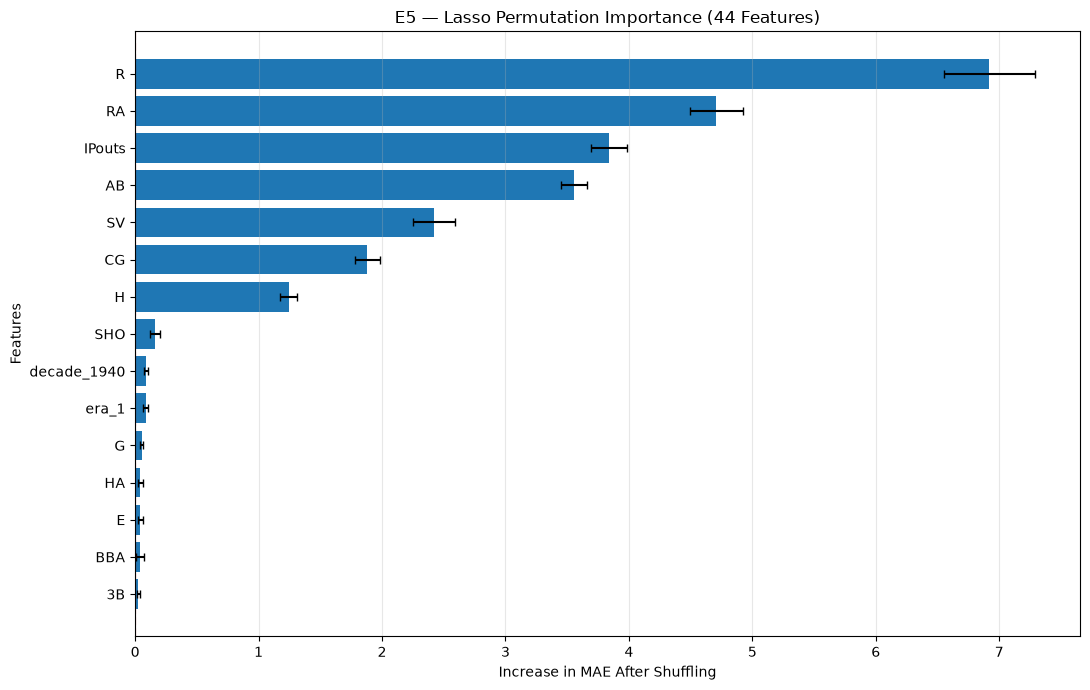

In [39]:
# =====================================================
# E5 — Permutation Feature Importance (44 Features)
# =====================================================

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Step 1 — Calculate permutation importance
perm_44 = permutation_importance(
    lasso_44,
    X_test_44,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Step 2 — Create importance table
perm_44_df = pd.DataFrame({
    "Feature": X_test_44.columns,
    "Importance_Mean": perm_44.importances_mean,
    "Importance_STD": perm_44.importances_std
}).sort_values("Importance_Mean", ascending=False)

print("E5 — Permutation Feature Importance")
print("-----------------------------------")
print(perm_44_df.to_string(index=False))

# Step 3 — Plot Top 15 Features
top15_44 = perm_44_df.head(15).sort_values(
    "Importance_Mean"
)

plt.figure(figsize=(11, 7))

plt.barh(
    top15_44["Feature"],
    top15_44["Importance_Mean"],
    xerr=top15_44["Importance_STD"],
    capsize=3
)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Increase in MAE After Shuffling")
plt.ylabel("Features")
plt.title("E5 — Lasso Permutation Importance (44 Features)")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### E5 — Permutation Feature Importance (44 Original Features)

**Objective**

To evaluate the relative importance of the 44 original features used in the tuned Lasso Regression model.

**Methodology**

Permutation Feature Importance was applied to the trained E5 Lasso pipeline using the testing dataset.

- Model: Lasso Regression
- Input features: 44
- Alpha: 0.01
- Testing MAE: 2.6898
- Permutation repetitions: 10
- Evaluation metric: Mean Absolute Error (MAE)

Each feature is randomly shuffled while the remaining features are unchanged. The resulting change in prediction error is used to estimate how strongly the fitted model relies on that feature.

**Interpretation**

- Positive importance: Shuffling increases MAE, indicating that the feature contributes to prediction accuracy.
- Near-zero importance: Shuffling has little measured effect on prediction accuracy.
- Negative importance: Shuffling slightly decreases MAE, potentially due to random variation or correlated features.

**Limitation**

Permutation importance reflects the model's reliance on individual features rather than causal effects. Correlations among baseball statistics may influence the rankings.

## E5 — Permutation Feature Importance (44 Original Features)

### 1. Objective

The objective of this analysis is to identify which of the 44 original features contribute most strongly to the predictive performance of the tuned Lasso Regression model.

The results are also compared with E4 (47 features) to evaluate how feature engineering changes model reliance on individual predictors.

### 2. Methodology

Permutation Feature Importance was applied to the trained E5 Lasso Regression model using the held-out testing dataset.

- **Model:** Lasso Regression
- **Input features:** 44 original features
- **Best alpha:** 0.01
- **Testing observations:** 283
- **Baseline testing MAE:** 2.6898 wins
- **Permutation repetitions:** 10
- **Evaluation metric:** Mean Absolute Error (MAE)

Each feature was randomly shuffled while all other features remained unchanged. Predictions were recalculated, and the resulting increase in MAE was used to estimate the model's reliance on that feature.

A larger positive importance indicates a greater deterioration in predictive accuracy when the feature is shuffled.

### 3. E5 — Top 7 Important Features

| Rank | Feature | Permutation Importance |
|---|---|---:|
| 1 | R — Runs Scored | 6.9199 |
| 2 | RA — Runs Allowed | 4.7082 |
| 3 | IPouts — Pitching Outs | 3.8395 |
| 4 | AB — At Bats | 3.5519 |
| 5 | SV — Saves | 2.4201 |
| 6 | CG — Complete Games | 1.8815 |
| 7 | H — Hits | 1.2422 |

**Interpretation:**

Runs Scored (`R`) recorded the highest permutation importance of 6.9199. Shuffling this feature increased the model's MAE from approximately 2.6898 to 9.6097 wins.

Runs Allowed (`RA`) recorded the second-highest importance of 4.7082.

These results indicate that the E5 model relies strongly on offensive scoring and defensive run prevention information when predicting total team-season wins.

### 4. Comparison — E4 (47 Features) vs E5 (44 Features)

| Feature | E4 — 47 Features | E5 — 44 Features |
|---|---:|---:|
| Run_Differential | 6.3306 | Not included |
| R — Runs Scored | 0.8639 | 6.9199 |
| RA — Runs Allowed | 0.0000 | 4.7082 |
| IPouts | 3.7905 | 3.8395 |
| AB | 3.5255 | 3.5519 |
| SV | 2.4091 | 2.4201 |
| CG | 1.8690 | 1.8815 |

### 5. Key Findings

**Finding 1 — Runs Scored and Runs Allowed are highly influential in E5.**

Without the engineered Run Differential feature, Runs Scored and Runs Allowed recorded the two highest permutation importance values.

This suggests that both variables provide important information for predicting MLB team-season wins.

**Finding 2 — Feature engineering changed the importance rankings.**

In E4, the engineered Run Differential feature recorded the highest importance.

Run Differential is calculated as:

**Run Differential = Runs Scored − Runs Allowed**

Because these variables are mathematically related, introducing Run Differential changed how Lasso distributed its coefficients and prediction reliance across the available features.

**Finding 3 — Other important features remained relatively stable.**

Pitching Outs (`IPouts`), At Bats (`AB`), Saves (`SV`), and Complete Games (`CG`) retained similar permutation importance values in both experiments.

This indicates relatively stable model reliance on these variables across the two feature sets.

**Finding 4 — Feature engineering did not meaningfully improve model accuracy.**

| Metric | E3 — 47 Features | E5 — 44 Features |
|---|---:|---:|
| Best Alpha | 0.01 | 0.01 |
| Cross-validation MAE | 2.8195 | 2.8190 |
| Testing MAE | 2.6883 | 2.6898 |
| Testing RMSE | 3.3242 | 3.3248 |
| Testing R² | 0.9308 | 0.9308 |
| Selected Features | 32 | 33 |

The difference in testing MAE was only 0.0015 wins, which is practically negligible.

Although the three engineered features changed the model's feature importance rankings, they did not produce a meaningful improvement in predictive accuracy.

### 6. Limitations

Permutation Feature Importance measures the impact of independently shuffling individual features rather than their causal influence on MLB team wins.

Because several baseball statistics are strongly correlated, independently shuffling a feature can create unrealistic combinations of observations and distort the importance estimates.

Furthermore, permutation importance was evaluated on one held-out testing dataset. The results may vary across different data splits or seasons.

Therefore, the importance rankings should be interpreted as measures of model reliance rather than causal relationships.

### 7. Conclusion

The E5 permutation importance analysis identified Runs Scored (`R`) and Runs Allowed (`RA`) as the two most influential features in the 44-feature Lasso Regression model.

The comparison with E4 demonstrated that introducing Run Differential substantially changed the importance rankings of related predictors without meaningfully improving prediction accuracy.

**E5 is preferred as the simpler model**, achieving comparable predictive performance using the original 44 features.

Overall, the findings demonstrate that feature engineering can change model interpretation without necessarily improving predictive performance.

In [40]:
# ============================================================
# STEP 9 — RETRAIN LASSO USING 33 SELECTED FEATURES
# Compare: 44 Original Features vs 33 Selected Features
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import KFold, cross_val_score

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — Retrieve 33 features selected by tuned 44 Lasso
# ------------------------------------------------------------

original_lasso = lasso_44.named_steps["lasso"]
preprocessor = lasso_44.named_steps["preprocessing"]

# Coefficients from the trained 44-feature model
coefficients = original_lasso.coef_

# Feature names in transformed column order
feature_names = preprocessor.get_feature_names_out()

# Remove transformer prefixes, e.g. "scale__R" -> "R"
feature_names = [
    name.split("__", 1)[-1]
    for name in feature_names
]

# Keep features whose coefficients are not zero
selected_features_33 = [
    name
    for name, coef in zip(feature_names, coefficients)
    if abs(coef) > 1e-6
]

print("FEATURE SELECTION")
print("-----------------")
print("Original features:", X_train_44.shape[1])
print("Selected features:", len(selected_features_33))

assert len(selected_features_33) == 33
assert all(c in X_train_44.columns for c in selected_features_33)

# ------------------------------------------------------------
# STEP 2 — Prepare selected feature dataset
# ------------------------------------------------------------

X_train_33 = X_train_44[selected_features_33].copy()
X_test_33 = X_test_44[selected_features_33].copy()

# ------------------------------------------------------------
# STEP 3 — Refit Lasso using only 33 features
# ------------------------------------------------------------

scale_cols_33 = [
    c for c in selected_features_33
    if not c.startswith(("era_", "decade_"))
]

lasso_33 = Pipeline([
    ("preprocessing", ColumnTransformer(
        [("scale", StandardScaler(), scale_cols_33)],
        remainder="passthrough"
    )),
    ("lasso", Lasso(alpha=0.01, max_iter=100000))
])

lasso_33.fit(X_train_33, y_train)

# ------------------------------------------------------------
# STEP 4 — Predictions
# ------------------------------------------------------------

train_preds_33 = lasso_33.predict(X_train_33)
test_preds_33 = lasso_33.predict(X_test_33)

# ------------------------------------------------------------
# STEP 5 — 5-Fold CV with feature selection inside each fold
# ------------------------------------------------------------

# The 33 features above were selected from the full training set.
# For valid CV, repeat selection within each CV training fold.

cv_model_33 = Pipeline([
    ("preprocessing", ColumnTransformer(
        [("scale", StandardScaler(), scale_cols_44)],
        remainder="passthrough"
    )),
    ("selection", SelectFromModel(
        Lasso(alpha=0.01, max_iter=100000),
        threshold=1e-6
    )),
    ("lasso", Lasso(alpha=0.01, max_iter=100000))
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_mae_33 = -cross_val_score(
    cv_model_33,
    X_train_44,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
).mean()

# ------------------------------------------------------------
# STEP 6 — Evaluation function
# ------------------------------------------------------------

def metrics(y_true, y_pred):
    return (
        mean_absolute_error(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred)),
        r2_score(y_true, y_pred)
    )

# Original 44-feature model
train_44 = metrics(y_train, train_preds_44)
test_44 = metrics(y_test, test_preds_44)

# Retrained 33-feature model
train_33 = metrics(y_train, train_preds_33)
test_33 = metrics(y_test, test_preds_33)

# ------------------------------------------------------------
# STEP 7 — Compare both models
# ------------------------------------------------------------

comparison_33 = pd.DataFrame({
    "Metric": [
        "Input Features",
        "CV MAE",
        "Training MAE",
        "Testing MAE",
        "Training RMSE",
        "Testing RMSE",
        "Training R2",
        "Testing R2"
    ],
    "Original Lasso (44)": [
        44,
        -grid_44.best_score_,
        train_44[0],
        test_44[0],
        train_44[1],
        test_44[1],
        train_44[2],
        test_44[2]
    ],
    "Retrained Lasso (33)": [
        len(selected_features_33),
        cv_mae_33,
        train_33[0],
        test_33[0],
        train_33[1],
        test_33[1],
        train_33[2],
        test_33[2]
    ]
})

print("\n44 vs 33 FEATURES — LASSO COMPARISON")
print("===================================")

print(comparison_33.round(4).to_string(index=False))

print("\n33-feature model evaluation")
print("---------------------------")
print(f"Training MAE : {train_33[0]:.4f}")
print(f"Testing MAE  : {test_33[0]:.4f}")
print(f"Training RMSE: {train_33[1]:.4f}")
print(f"Testing RMSE : {test_33[1]:.4f}")
print(f"Training R2  : {train_33[2]:.4f}")
print(f"Testing R2   : {test_33[2]:.4f}")
print(f"CV MAE       : {cv_mae_33:.4f}")

FEATURE SELECTION
-----------------
Original features: 44
Selected features: 33

44 vs 33 FEATURES — LASSO COMPARISON
        Metric  Original Lasso (44)  Retrained Lasso (33)
Input Features              44.0000               33.0000
        CV MAE               2.8190                2.8190
  Training MAE               2.6956                2.6957
   Testing MAE               2.6898                2.6895
 Training RMSE               3.4084                3.4085
  Testing RMSE               3.3248                3.3245
   Training R2               0.9357                0.9357
    Testing R2               0.9308                0.9308

33-feature model evaluation
---------------------------
Training MAE : 2.6957
Testing MAE  : 2.6895
Training RMSE: 3.4085
Testing RMSE : 3.3245
Training R2  : 0.9357
Testing R2   : 0.9308
CV MAE       : 2.8190


## Step 9 — Lasso Feature Selection and Retraining Analysis (44 vs 33 Features)

### 1. Objective

The objective of this experiment is to investigate whether retraining Lasso Regression using only the features selected through L1 regularization can maintain or improve predictive performance.

Two models are compared:

- **Model A:** Tuned Lasso Regression using 44 original features.
- **Model B:** Retrained Lasso Regression using 33 Lasso-selected features.

The original model identified 33 active features and eliminated 11 features by assigning their coefficients to zero.

The retrained model uses only these 33 selected features, with the same regularization parameter (alpha = 0.01).

### 2. Model Performance Comparison

| Metric | Tuned Lasso (44) | Retrained Lasso (33) |
|---|---:|---:|
| Input Features | 44 | 33 |
| Alpha | 0.01 | 0.01 |
| 5-Fold CV MAE | 2.8190 | 2.8190 |
| Training MAE | 2.6956 | 2.6957 |
| Testing MAE | 2.6898 | 2.6895 |
| Training RMSE | 3.4084 | 3.4085 |
| Testing RMSE | 3.3248 | 3.3245 |
| Training R² | 0.9357 | 0.9357 |
| Testing R² | 0.9308 | 0.9308 |

**Observation:** Both models demonstrated nearly identical predictive performance across MAE, RMSE, and R².

### 3. Feature Selection Results

The original Lasso model used 44 input features. After L1 regularization:

- 33 features retained nonzero coefficients.
- 11 features received zero coefficients.
- Approximately 25% of the original features were eliminated.

The model was subsequently retrained using only the 33 selected features.

The retrained model achieved comparable performance despite using fewer input variables.

### 4. Testing MAE Comparison

The original Lasso model achieved a testing MAE of **2.6898 wins**.

The retrained 33-feature model achieved a testing MAE of **2.6895 wins**.

The reduction in testing MAE was:

**2.6898 − 2.6895 = 0.0003 wins**

This improvement is negligible and does not demonstrate a meaningful increase in predictive accuracy.

However, the experiment confirms that reducing the number of input features did not materially affect prediction accuracy.

### 5. RMSE and R² Comparison

**RMSE**

- Original 44-feature Lasso: 3.3248
- Retrained 33-feature Lasso: 3.3245

The RMSE decreased by 0.0003 wins, indicating virtually identical sensitivity to larger prediction errors.

**R²**

Both models achieved:

- Training R²: 0.9357
- Testing R²: 0.9308

This indicates that both models explain approximately 93.08% of the variation in wins within the held-out testing dataset.

The small training–testing performance differences provide no clear evidence of substantial overfitting on the current dataset split.

### 6. Cross-Validation Assessment

Both models achieved a reported five-fold CV MAE of approximately **2.8190**.

For the 33-feature experiment, feature selection was repeated within each cross-validation training fold to avoid feature-selection leakage.

However, the retrained model was not independently tuned. It reused alpha = 0.01 from the original tuned Lasso model.

Therefore, the experiment evaluates the effect of feature selection and retraining at a fixed alpha, rather than comparing two independently optimized models.

### 7. Key Findings

**Finding 1 — Feature selection reduced input complexity.**

The number of input features decreased from 44 to 33, a reduction of 25%.

**Finding 2 — Predictive accuracy was maintained.**

The retrained model achieved nearly identical MAE, RMSE and R² values compared with the original Lasso model.

**Finding 3 — Retraining provided negligible improvement.**

The testing MAE improved by only 0.0003 wins, which is too small to establish a meaningful performance advantage.

**Finding 4 — Lasso already performed automatic feature selection.**

The original Lasso assigned zero coefficients to 11 features. Therefore, these features did not contribute to its predictions even before explicit removal.

This explains why retraining with only the 33 active features produced almost identical results.

### 8. Limitations

The comparison used a single held-out test split, and the performance differences were extremely small.

The selected features were identified using the original training dataset, while cross-validation repeated feature selection independently within each fold.

The 33-feature retrained model reused alpha = 0.01 rather than conducting a separate hyperparameter search.

Further evaluation with repeated cross-validation or independent test datasets would be necessary to determine whether any small performance differences are consistent.

### 9. Conclusion

The experiment demonstrates that **Lasso-based feature selection can reduce the number of input variables without materially compromising predictive accuracy**.

Reducing the input features from 44 to 33 produced nearly identical training, cross-validation, and testing performance.

The retrained 33-feature model achieved a testing MAE of 2.6895, RMSE of 3.3245 and R² of 0.9308.

Although the retrained model achieved marginally lower testing errors, the improvements were negligible.

**Overall, the experiment supports the effectiveness of L1 regularization for obtaining a more compact feature set while maintaining predictive performance.**

The original tuned 44-feature Lasso remains the benchmark, while the retrained 33-feature model provides evidence that explicit feature reduction does not significantly affect model accuracy.

In [41]:
# ============================================================
# STEP 10 — LASSO FEATURE SELECTION: 47 vs 32 FEATURES
# Compare Original Tuned Lasso vs Retrained Selected Features
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------
# STEP 1 — Load original dataset
# ------------------------------------------------------------

DATA_DIR = Path.home() / "MLB"

data_47exp = pd.read_csv(DATA_DIR / "data.csv")
predict_47exp = pd.read_csv(DATA_DIR / "predict.csv")

exclude_cols = {
    "W", "ID", "yearID", "teamID",
    "year_label", "decade_label", "win_bins"
}

shared_cols = [
    c for c in data_47exp.columns
    if c in predict_47exp.columns
]

features_44 = [
    c for c in data_47exp[shared_cols]
        .select_dtypes(include=["number", "bool"]).columns
    if c not in exclude_cols
]

# ------------------------------------------------------------
# STEP 2 — Prepare 47 features
# ------------------------------------------------------------

X_47exp = data_47exp[features_44].copy()

X_47exp["R_per_game"] = X_47exp["R"] / X_47exp["G"]
X_47exp["RA_per_game"] = X_47exp["RA"] / X_47exp["G"]
X_47exp["Run_Differential"] = X_47exp["R"] - X_47exp["RA"]

y_47exp = data_47exp["W"].copy()

X_train_47exp, X_test_47exp, y_train_47exp, y_test_47exp = (
    train_test_split(
        X_47exp,
        y_47exp,
        test_size=0.20,
        random_state=42
    )
)

assert X_47exp.shape[1] == 47

# ------------------------------------------------------------
# STEP 3 — Scale original 47 features
# ------------------------------------------------------------

scale_cols_47exp = [
    c for c in X_train_47exp.columns
    if not c.startswith(("era_", "decade_"))
]

scaler_47exp = StandardScaler()

X_train_47_scaled = X_train_47exp.copy()
X_test_47_scaled = X_test_47exp.copy()

X_train_47_scaled[scale_cols_47exp] = (
    scaler_47exp.fit_transform(X_train_47exp[scale_cols_47exp])
)

X_test_47_scaled[scale_cols_47exp] = (
    scaler_47exp.transform(X_test_47exp[scale_cols_47exp])
)

# ------------------------------------------------------------
# STEP 4 — Train original 47-feature Lasso
# ------------------------------------------------------------

lasso_47exp = Lasso(alpha=0.01, max_iter=100000)

lasso_47exp.fit(X_train_47_scaled, y_train_47exp)

# ------------------------------------------------------------
# STEP 5 — Identify the selected 32 features
# ------------------------------------------------------------

selected_features_32 = [
    feature
    for feature, coef in zip(
        X_train_47_scaled.columns,
        lasso_47exp.coef_
    )
    if abs(coef) > 1e-6
]

print("FEATURE SELECTION")
print("-----------------")
print("Original features:", X_train_47exp.shape[1])
print("Selected features:", len(selected_features_32))
print("Eliminated features:",
      X_train_47exp.shape[1] - len(selected_features_32))

assert len(selected_features_32) == 32

# ------------------------------------------------------------
# STEP 6 — Prepare selected 32-feature dataset
# ------------------------------------------------------------

X_train_32 = X_train_47exp[selected_features_32].copy()
X_test_32 = X_test_47exp[selected_features_32].copy()

# ------------------------------------------------------------
# STEP 7 — Scale selected features
# ------------------------------------------------------------

scale_cols_32 = [
    c for c in selected_features_32
    if not c.startswith(("era_", "decade_"))
]

scaler_32 = StandardScaler()

X_train_32_scaled = X_train_32.copy()
X_test_32_scaled = X_test_32.copy()

X_train_32_scaled[scale_cols_32] = (
    scaler_32.fit_transform(X_train_32[scale_cols_32])
)

X_test_32_scaled[scale_cols_32] = (
    scaler_32.transform(X_test_32[scale_cols_32])
)

# ------------------------------------------------------------
# STEP 8 — Retrain Lasso using 32 features
# ------------------------------------------------------------

lasso_32 = Lasso(
    alpha=0.01,
    max_iter=100000
)

lasso_32.fit(X_train_32_scaled, y_train_47exp)

# ------------------------------------------------------------
# STEP 9 — Generate predictions
# ------------------------------------------------------------

train_preds_47exp = lasso_47exp.predict(X_train_47_scaled)
test_preds_47exp = lasso_47exp.predict(X_test_47_scaled)

train_preds_32 = lasso_32.predict(X_train_32_scaled)
test_preds_32 = lasso_32.predict(X_test_32_scaled)

# ------------------------------------------------------------
# STEP 10 — 5-Fold Cross-Validation
# Feature selection happens INSIDE each fold
# ------------------------------------------------------------

cv_47exp = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_preprocessor = ColumnTransformer(
    [("scale", StandardScaler(), scale_cols_47exp)],
    remainder="passthrough"
)

# Original 47-feature CV model
cv_model_47 = Pipeline([
    ("preprocessing", cv_preprocessor),
    ("lasso", Lasso(alpha=0.01, max_iter=100000))
])

cv_mae_47 = -cross_val_score(
    cv_model_47,
    X_train_47exp,
    y_train_47exp,
    cv=cv_47exp,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
).mean()

# Selected-feature CV model
cv_model_32 = Pipeline([
    ("preprocessing", cv_preprocessor),
    ("selection", SelectFromModel(
        Lasso(alpha=0.01, max_iter=100000),
        threshold=1e-6
    )),
    ("lasso", Lasso(alpha=0.01, max_iter=100000))
])

cv_mae_32 = -cross_val_score(
    cv_model_32,
    X_train_47exp,
    y_train_47exp,
    cv=cv_47exp,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
).mean()

# ------------------------------------------------------------
# STEP 11 — Evaluation function
# ------------------------------------------------------------

def evaluate_47exp(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

train_47 = evaluate_47exp(y_train_47exp, train_preds_47exp)
test_47 = evaluate_47exp(y_test_47exp, test_preds_47exp)

train_32 = evaluate_47exp(y_train_47exp, train_preds_32)
test_32 = evaluate_47exp(y_test_47exp, test_preds_32)

# ------------------------------------------------------------
# STEP 12 — Final comparison table
# ------------------------------------------------------------

comparison_47_32 = pd.DataFrame({
    "Metric": [
        "Input Features",
        "CV MAE",
        "Training MAE",
        "Testing MAE",
        "Training RMSE",
        "Testing RMSE",
        "Training R2",
        "Testing R2"
    ],
    "Original Lasso (47)": [
        47,
        cv_mae_47,
        train_47["MAE"],
        test_47["MAE"],
        train_47["RMSE"],
        test_47["RMSE"],
        train_47["R2"],
        test_47["R2"]
    ],
    "Retrained Lasso (32)": [
        32,
        cv_mae_32,
        train_32["MAE"],
        test_32["MAE"],
        train_32["RMSE"],
        test_32["RMSE"],
        train_32["R2"],
        test_32["R2"]
    ]
})

print("\n47 vs 32 FEATURES — LASSO COMPARISON")
print("===================================")

print(comparison_47_32.round(4).to_string(index=False))

print("\n32-FEATURE MODEL EVALUATION")
print("---------------------------")
print(f"Training MAE : {train_32['MAE']:.4f}")
print(f"Testing MAE  : {test_32['MAE']:.4f}")
print(f"Training RMSE: {train_32['RMSE']:.4f}")
print(f"Testing RMSE : {test_32['RMSE']:.4f}")
print(f"Training R2  : {train_32['R2']:.4f}")
print(f"Testing R2   : {test_32['R2']:.4f}")
print(f"CV MAE       : {cv_mae_32:.4f}")

print("\nSELECTED 32 FEATURES")
print("--------------------")
print(selected_features_32)

FEATURE SELECTION
-----------------
Original features: 47
Selected features: 32
Eliminated features: 15

47 vs 32 FEATURES — LASSO COMPARISON
        Metric  Original Lasso (47)  Retrained Lasso (32)
Input Features              47.0000               32.0000
        CV MAE               2.8195                2.8194
  Training MAE               2.6970                2.6971
   Testing MAE               2.6883                2.6883
 Training RMSE               3.4097                3.4098
  Testing RMSE               3.3242                3.3243
   Training R2               0.9357                0.9357
    Testing R2               0.9308                0.9308

32-FEATURE MODEL EVALUATION
---------------------------
Training MAE : 2.6971
Testing MAE  : 2.6883
Training RMSE: 3.4098
Testing RMSE : 3.3243
Training R2  : 0.9357
Testing R2   : 0.9308
CV MAE       : 2.8194

SELECTED 32 FEATURES
--------------------
['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO', 'SB', 'CG', 'SHO', 'SV', 'IPou

## Step 10 — Lasso Feature Selection and Retraining Analysis (47 vs 32 Features)

### 1. Objective

The objective of this experiment is to evaluate whether retraining Lasso Regression using only the 32 features selected through L1 regularization can maintain or improve predictive accuracy.

Two models were compared:

- **Model A:** Original tuned Lasso Regression using 47 features, including three engineered features.
- **Model B:** Retrained Lasso Regression using 32 Lasso-selected features.

Both models used alpha = 0.01. This parameter was originally selected through five-fold cross-validation for the 47-feature model and reused for the 32-feature model.

### 2. Feature Selection Results

The original Lasso model was trained using 47 input features.

After applying L1 regularization:

- **Original features:** 47
- **Selected features:** 32
- **Eliminated features:** 15
- **Feature reduction:** 31.9%
- **Regularization parameter (alpha):** 0.01

Lasso automatically assigned zero coefficients to 15 features, meaning these features did not directly contribute to the fitted model's predictions.

The model was subsequently retrained using only the 32 selected features.

### 3. Model Performance Comparison

| Metric | Original Lasso (47) | Retrained Lasso (32) |
|---|---:|---:|
| Input Features | 47 | 32 |
| Alpha | 0.01 | 0.01 |
| 5-Fold CV MAE | 2.8195 | 2.8194 |
| Training MAE | 2.6970 | 2.6971 |
| Testing MAE | 2.6883 | 2.6883 |
| Training RMSE | 3.4097 | 3.4098 |
| Testing RMSE | 3.3242 | 3.3243 |
| Training R² | 0.9357 | 0.9357 |
| Testing R² | 0.9308 | 0.9308 |

**Observation:** Both models achieved nearly identical predictive performance despite the reduction from 47 to 32 input features.

### 4. MAE Analysis

The original 47-feature Lasso model achieved:

- Training MAE: 2.6970
- Testing MAE: 2.6883

The retrained 32-feature model achieved:

- Training MAE: 2.6971
- Testing MAE: 2.6883

The testing MAE remained identical when rounded to four decimal places.

This indicates that eliminating 15 zero-coefficient features did not materially affect the model's average prediction error.

The retrained model preserved predictive accuracy while using fewer input variables.

### 5. RMSE Analysis

The original Lasso model achieved a testing RMSE of **3.3242 wins**, compared with **3.3243 wins** for the retrained model.

The difference of 0.0001 wins is negligible.

This indicates that retraining the model using only the selected features did not materially change its sensitivity to larger prediction errors.

### 6. R² Analysis

Both models achieved:

- **Training R²:** 0.9357
- **Testing R²:** 0.9308

The testing R² of 0.9308 indicates that the models explain approximately 93.08% of the variation in wins within the held-out testing dataset.

The similarity between training and testing R² suggests that neither model exhibited substantial deterioration in explanatory performance on the test split.

However, a small performance gap does not guarantee generalization to future MLB seasons.

### 7. Cross-Validation Analysis

The five-fold cross-validation results were:

| Model | CV MAE |
|---|---:|
| Original Lasso (47) | 2.8195 |
| Retrained Lasso (32) | 2.8194 |

The retrained model achieved a marginally lower CV MAE of 2.8194.

The difference of 0.0001 wins is negligible and does not establish a meaningful improvement in predictive performance.

For the selected-feature cross-validation procedure, feature selection was repeated independently within each training fold to avoid validation leakage. Therefore, the number and identity of selected features could differ across folds.

**Important methodological distinction:** The 32-feature model was retrained using alpha = 0.01, inherited from the original 47-feature model. It was not independently tuned through a new hyperparameter search.

### 8. Analysis of Selected Features

The 32 selected features were:

**Season and offensive statistics**

- G, R, AB, H, 2B, 3B, HR, BB, SO, SB

**Pitching and defensive statistics**

- CG, SHO, SV, IPouts, HA, BBA, SOA, E, DP

**League context**

- mlb_rpg

**Era indicators**

- era_1, era_4, era_6, era_7

**Decade indicators**

- decade_1910, decade_1920, decade_1930, decade_1940, decade_1950, decade_1970, decade_1990

**Engineered feature**

- Run_Differential

Among the three engineered features, only **Run_Differential** retained a nonzero coefficient.

The two other engineered features, R_per_game and RA_per_game, received zero coefficients.

Run_Differential represents:

**Run_Differential = Runs Scored − Runs Allowed**

This feature captures the balance between offensive production and defensive performance.

However, because Run_Differential is mathematically derived from R and RA, it does not introduce independent information. Its selection reflects how Lasso distributes coefficients among correlated predictors, rather than establishing that it is inherently more important.

### 9. Comparison with the 44-to-33 Feature Experiment

Both feature-selection experiments produced similar findings.

| Metric | Original 44 | Selected 33 | Original 47 | Selected 32 |
|---|---:|---:|---:|---:|
| Input Features | 44 | 33 | 47 | 32 |
| CV MAE | 2.8190 | 2.8190 | 2.8195 | 2.8194 |
| Training MAE | 2.6956 | 2.6957 | 2.6970 | 2.6971 |
| Testing MAE | 2.6898 | 2.6895 | 2.6883 | 2.6883 |
| Testing RMSE | 3.3248 | 3.3245 | 3.3242 | 3.3243 |
| Testing R² | 0.9308 | 0.9308 | 0.9308 | 0.9308 |

The 44-feature experiment reduced the number of input features by 25%.

The 47-feature experiment reduced the number of input features by approximately 31.9%.

In both experiments, predictive accuracy remained essentially unchanged after retraining.

### 10. Key Findings

**Finding 1 — Feature selection reduced model inputs.**

Lasso reduced the feature count from 47 to 32, eliminating approximately 31.9% of the original inputs.

**Finding 2 — Predictive accuracy was maintained.**

The retrained 32-feature model achieved nearly identical training, cross-validation and testing results compared with the original 47-feature model.

**Finding 3 — Retraining did not meaningfully improve accuracy.**

The differences in MAE, RMSE and R² were negligible.

**Finding 4 — Run Differential was the only engineered feature retained.**

Among the three engineered features, Run_Differential received a nonzero coefficient, while R_per_game and RA_per_game were eliminated by Lasso.

**Finding 5 — Feature selection did not substantially affect generalization.**

Training and testing performance remained similar, with no clear evidence of substantial overfitting on the current dataset split.

### 11. Limitations

The analysis used a single 80/20 train-test split with random_state = 42.

Although cross-validation was performed, the final results may depend on the particular observations assigned to training and testing.

The retrained model reused alpha = 0.01 rather than being independently tuned.

Furthermore, selected features may differ under alternative samples, alpha values or cross-validation partitions.

The results therefore demonstrate performance stability under the current experimental configuration rather than proving that 32 features are universally optimal.

### 12. Conclusion

The 47-feature Lasso Regression model selected 32 active features through L1 regularization, eliminating 15 features and reducing the input feature count by approximately 31.9%.

After retraining using only the selected features, the model achieved:

- **CV MAE:** 2.8194
- **Training MAE:** 2.6971
- **Testing MAE:** 2.6883
- **Training RMSE:** 3.4098
- **Testing RMSE:** 3.3243
- **Training R²:** 0.9357
- **Testing R²:** 0.9308

These results were almost identical to those of the original 47-feature model.

**Overall, the experiment demonstrates that Lasso-based feature selection reduced the number of input variables without materially compromising predictive performance.**

The findings support the use of L1 regularization as a feature-selection technique. However, retraining on the selected subset did not produce a meaningful improvement in prediction accuracy.

The original tuned 47-feature model remains the benchmark for this experiment, while the retrained 32-feature model provides a more compact alternative with comparable performance.

In [42]:
# ============================================================
# Investigate Why Lasso Selected Certain Engineered Features
# ============================================================

import pandas as pd
import numpy as np

features_to_check = [
    "R",
    "RA",
    "G",
    "R_per_game",
    "RA_per_game",
    "Run_Differential"
]

# Retrieve coefficients from the trained 47-feature Lasso
coef_df = pd.DataFrame({
    "Feature": X_train_47_scaled.columns,
    "Coefficient": lasso_47exp.coef_
})

# Examine the selected features
result = coef_df[
    coef_df["Feature"].isin(features_to_check)
].copy()

result["Status"] = np.where(
    result["Coefficient"].abs() > 1e-6,
    "SELECTED",
    "ELIMINATED"
)

print("LASSO FEATURE SELECTION ANALYSIS")
print("--------------------------------")
print(result.to_string(index=False))

# Check correlations between features
print("\nFEATURE CORRELATION MATRIX")
print("--------------------------")

correlation = X_train_47exp[
    features_to_check
].corr()

print(correlation.round(3).to_string())

LASSO FEATURE SELECTION ANALYSIS
--------------------------------
         Feature  Coefficient     Status
               G    -0.344143   SELECTED
               R     2.072792   SELECTED
              RA    -0.000000 ELIMINATED
      R_per_game     0.000000 ELIMINATED
     RA_per_game    -0.000000 ELIMINATED
Run_Differential     8.028141   SELECTED

FEATURE CORRELATION MATRIX
--------------------------
                      R     RA      G  R_per_game  RA_per_game  Run_Differential
R                 1.000  0.302  0.118       0.987        0.284             0.593
RA                0.302  1.000  0.135       0.280        0.987            -0.589
G                 0.118  0.135  1.000      -0.040       -0.023            -0.014
R_per_game        0.987  0.280 -0.040       1.000        0.287             0.601
RA_per_game       0.284  0.987 -0.023       0.287        1.000            -0.593
Run_Differential  0.593 -0.589 -0.014       0.601       -0.593             1.000


## Step 11 — Feature Engineering, Correlation and Lasso Feature Selection Analysis

### 1. Objective

The objective of this analysis is to investigate why adding three engineered features did not significantly improve Lasso Regression performance in the Moneyball prediction project.

The analysis examines:

- Relationships between original and engineered baseball statistics.
- Feature redundancy and multicollinearity.
- How L1 regularization affects feature selection.
- Why Run Differential was selected while Runs per Game and Runs Allowed per Game were eliminated.
- The effect of feature engineering on predictive accuracy.

### 2. Engineered Features

Three features were created from existing baseball statistics.

| Engineered Feature | Formula | Purpose |
|---|---|---|
| Runs per Game | `R / G` | Measures average offensive production per game |
| Runs Allowed per Game | `RA / G` | Measures average runs conceded per game |
| Run Differential | `R - RA` | Measures the difference between runs scored and allowed |

Where:

- **R:** Total runs scored.
- **RA:** Total runs allowed.
- **G:** Total games played.

All three features are relevant to baseball performance. However, they are calculated from existing predictors rather than independent new data.

### 3. Correlation Analysis

Pearson correlation was calculated to examine relationships between the original and engineered features.

| Feature Pair | Correlation | Interpretation |
|---|---:|---|
| R vs R_per_game | 0.987 | Very strong positive correlation |
| RA vs RA_per_game | 0.987 | Very strong positive correlation |
| R vs Run_Differential | 0.593 | Moderate positive correlation |
| RA vs Run_Differential | -0.589 | Moderate negative correlation |
| G vs Run_Differential | -0.014 | Negligible linear correlation |

**Key observation:**

Runs Scored (`R`) and Runs per Game (`R_per_game`) have a correlation of 0.987.

Similarly, Runs Allowed (`RA`) and Runs Allowed per Game (`RA_per_game`) have a correlation of 0.987.

These extremely high correlations indicate that the paired variables contain highly overlapping information.

Because most seasons contain similar numbers of games, converting season totals into per-game averages does not substantially change the statistical information available to the model.

### 4. Lasso Coefficient and Feature Selection Analysis

The tuned 47-feature Lasso model used:

**Alpha = 0.01**

The following coefficients were obtained:

| Feature | Coefficient | Selection Status |
|---|---:|---|
| G | -0.344143 | Selected |
| R | +2.072792 | Selected |
| RA | 0.000000 | Eliminated |
| R_per_game | 0.000000 | Eliminated |
| RA_per_game | 0.000000 | Eliminated |
| Run_Differential | +8.028141 | Selected |

The results show that Lasso retained Runs Scored and Run Differential but assigned zero coefficients to Runs Allowed, Runs per Game and Runs Allowed per Game.

The numerical coefficients were estimated using standardized features. Therefore, their magnitudes should not be interpreted as the number of additional wins associated with a one-unit increase in the original baseball statistics.

Furthermore, coefficient selection reflects conditional predictive relationships rather than causal effects.

### 5. Why Were Runs per Game and Runs Allowed per Game Eliminated?

Lasso Regression uses L1 regularization, which penalizes the absolute values of model coefficients.

This penalty encourages some coefficients to become exactly zero.

When two predictors contain highly similar information, Lasso may retain one predictor and eliminate another to produce a sparser model.

For example:

**R_per_game = R / G**

Because R and R_per_game have a correlation of 0.987, retaining both may provide limited additional predictive benefit.

Similarly:

**RA_per_game = RA / G**

The correlation between RA and RA_per_game is also 0.987.

This helps explain why Lasso assigned zero coefficients to both engineered per-game features.

**Important:** A zero coefficient does not mean a statistic is unimportant in baseball. It means the fitted Lasso model did not require that predictor's separate contribution under the current regularization settings.

### 6. Why Was Run Differential Selected?

Run Differential is calculated as:

**Run Differential = R - RA**

A positive value indicates that a team scored more runs than it allowed over the season.

For example:

- Runs Scored = 800
- Runs Allowed = 700
- Run Differential = +100

A positive Run Differential generally reflects favorable team performance.

In the tuned Lasso model, Run Differential received a positive coefficient of +8.028141, while Runs Allowed received a zero coefficient.

This suggests that Run Differential provided a useful representation of the relationship between offensive production, defensive performance and season wins.

However, Run Differential is mathematically determined by R and RA.

Therefore, it does not introduce independent information when both original statistics are already included.

Because these predictors are linearly dependent, Lasso can distribute their combined predictive effects across different coefficients.

**Consequently, the selection of Run Differential should not be interpreted as proof that it provides entirely new predictive information.**

### 7. Understanding Feature Redundancy and Multicollinearity

**Feature redundancy** occurs when multiple predictors provide overlapping information.

**Multicollinearity** occurs when predictors are strongly linearly related.

Two forms of redundancy are present in this experiment.

**A. High correlation**

- R and R_per_game: 0.987
- RA and RA_per_game: 0.987

These pairs provide highly similar information.

**B. Exact mathematical dependency**

Run Differential is calculated directly from R and RA:

**Run_Differential = R - RA**

Although Run Differential has only moderate individual correlations with R and RA, it is completely determined by their combination.

This demonstrates why correlation coefficients alone cannot identify every form of feature redundancy.

Lasso's L1 regularization encourages coefficient sparsity, helping the model retain a compact set of predictors when substantial overlap exists.

### 8. Impact on Model Performance

The original and engineered Lasso models produced the following results.

| Metric | Original 44 Features | Engineered 47 Features | Selected 32 Features |
|---|---:|---:|---:|
| Input Features | 44 | 47 | 32 |
| Alpha | 0.01 | 0.01 | 0.01 |
| CV MAE | 2.8190 | 2.8195 | 2.8194 |
| Testing MAE | 2.6898 | 2.6883 | 2.6883 |
| Testing RMSE | 3.3248 | 3.3242 | 3.3243 |
| Testing R² | 0.9308 | 0.9308 | 0.9308 |

Adding three engineered features reduced testing MAE from 2.6898 to 2.6883.

The improvement was:

**2.6898 - 2.6883 = 0.0015 wins**

This improvement is negligible.

The CV MAE increased slightly from 2.8190 to 2.8195, suggesting that the engineered model did not consistently outperform the original model under cross-validation.

The retrained 32-feature model also produced nearly identical prediction accuracy.

These findings indicate that the engineered features provided limited incremental predictive value to the existing linear Lasso model.

### 9. Implications for Feature Engineering

The experiment provides several important insights.

**Finding 1 — More features do not necessarily improve prediction accuracy.**

Increasing the input count from 44 to 47 did not produce a meaningful reduction in prediction error.

**Finding 2 — Domain-relevant features may still be redundant.**

Runs per Game, Runs Allowed per Game and Run Differential are meaningful baseball statistics, but their information overlaps with the original predictors.

**Finding 3 — Lasso can automatically eliminate redundant predictors.**

L1 regularization eliminated 15 features from the 47-feature model, leaving 32 active predictors.

**Finding 4 — Run Differential was retained as an alternative representation.**

Although Run Differential does not introduce independent information, Lasso retained it as part of its fitted predictive equation.

**Finding 5 — Feature reduction preserved model accuracy.**

Retraining the model with only 32 selected features maintained almost identical MAE, RMSE and R² values.

### 10. Recommendation for Further Experimentation

Future experiments could evaluate baseball-specific nonlinear features rather than relying only on linear combinations or highly correlated ratios.

One possible candidate is **Pythagorean Expected Wins**:

**Expected Wins = G × R² / (R² + RA²)**

This formula estimates a team's expected season wins from its runs scored and runs allowed.

Unlike the simple Run Differential formula, it introduces a nonlinear relationship that standard linear Lasso cannot directly construct from the original inputs.

A new experiment could compare:

- 44 original features.
- 47 features with the existing three engineered variables.
- 48 features including Pythagorean Expected Wins.

All preprocessing and model tuning should be conducted using training data only, with cross-validation used to assess whether the additional feature improves predictive accuracy.

Any improvement would need to be demonstrated empirically rather than assumed.

### 11. Limitations

The conclusions are based on the current historical MLB dataset, an 80/20 random train-test split and the evaluated Lasso regularization settings.

Feature correlations and coefficients may differ under other datasets, training partitions or alpha values.

Highly correlated predictors can also produce unstable coefficient selections, even when their combined predictions remain relatively stable.

Therefore, the selected features should not automatically be interpreted as the most important causal drivers of baseball wins.

The evaluation also relies on full-season statistics. Consequently, the results demonstrate the ability to estimate wins from season-level performance rather than validate predictions made before the season begins.

### 12. Conclusion

The feature engineering analysis explains why adding three new baseball statistics did not materially improve Lasso Regression performance.

Runs per Game and Runs Allowed per Game exhibited extremely high correlations of 0.987 with their corresponding original season totals, indicating substantial information overlap.

Lasso eliminated both per-game engineered features while retaining Run Differential.

Although Run Differential was selected, it is mathematically derived from Runs Scored and Runs Allowed and therefore does not introduce independent predictive information.

The engineered 47-feature model achieved a testing MAE of 2.6883 compared with 2.6898 for the original 44-feature model, representing a negligible improvement of 0.0015 wins.

**Overall, the findings demonstrate that meaningful feature engineering requires consideration of both domain knowledge and incremental predictive information.**

The results support the effectiveness of L1 regularization in handling overlapping predictors and reducing model complexity without materially compromising prediction accuracy.

Future experiments may investigate nonlinear baseball-specific features to determine whether alternative transformations can provide additional predictive value.

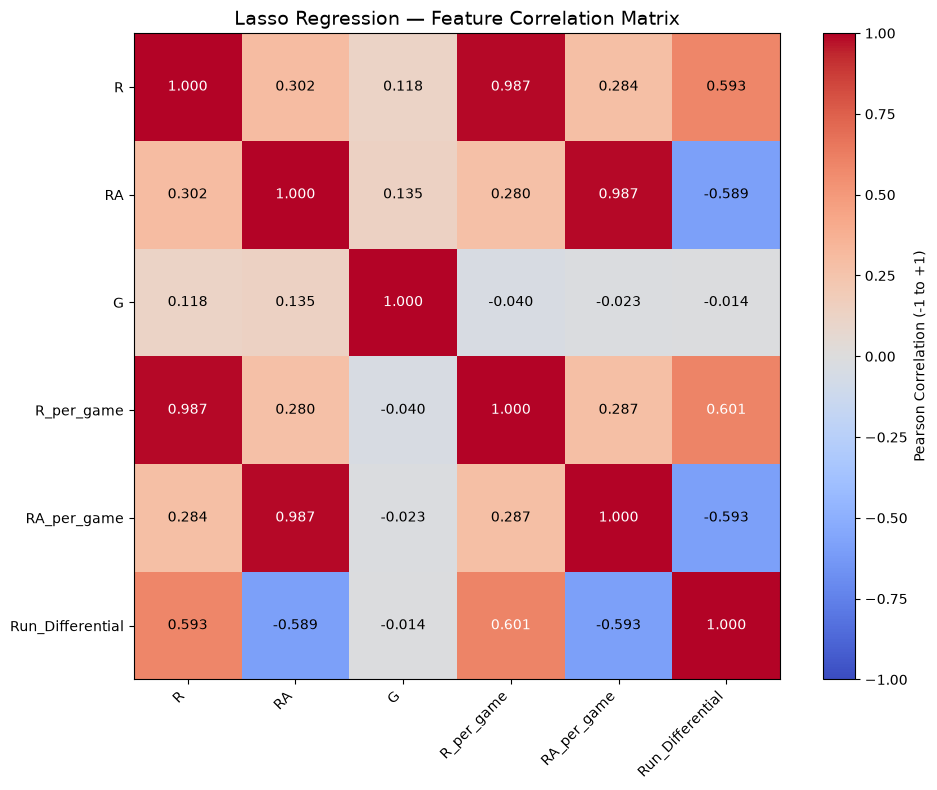

In [43]:
# ============================================================
# STEP 11A — CORRELATION MATRIX HEATMAP
# Original and Engineered Baseball Features
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Load original data
df = pd.read_csv(Path.home() / "MLB" / "data.csv")

# Select original baseball statistics
features = [
    "R", "RA", "G",
    "R_per_game",
    "RA_per_game",
    "Run_Differential"
]

# Recreate the three engineered features
df["R_per_game"] = df["R"] / df["G"]
df["RA_per_game"] = df["RA"] / df["G"]
df["Run_Differential"] = df["R"] - df["RA"]

# Use same training split as Lasso experiments
train_df, _ = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

# Calculate Pearson correlation matrix
corr_matrix = train_df[features].corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(10, 8))

heatmap = ax.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))

ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticklabels(features)

# Show correlation values in each cell
for i in range(len(features)):
    for j in range(len(features)):
        value = corr_matrix.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.3f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.6 else "black"
        )

plt.colorbar(
    heatmap,
    ax=ax,
    label="Pearson Correlation (-1 to +1)"
)

plt.title(
    "Lasso Regression — Feature Correlation Matrix",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [44]:
# ============================================================
# STEP 12 — PYTHAGOREAN EXPECTED WINS
# New Feature Engineering Experiment
# ============================================================

# Copy existing 47-feature datasets
X_train_48 = X_train_47exp.copy()
X_test_48 = X_test_47exp.copy()

# Add the new nonlinear feature
for df in [X_train_48, X_test_48]:

    df["Pythagorean_Expected_Wins"] = (
        df["G"] * (df["R"] ** 2)
        / ((df["R"] ** 2) + (df["RA"] ** 2))
    )

# Verify
print("Original features:", X_train_47exp.shape[1])
print("New features:", X_train_48.shape[1])

print("\nExample Expected Wins:")
print(
    X_train_48[
        ["R", "RA", "G", "Pythagorean_Expected_Wins"]
    ].head()
)

Original features: 47
New features: 48

Example Expected Wins:
       R   RA    G  Pythagorean_Expected_Wins
629  505  627  162                  63.741102
439  749  801  162                  75.571271
485  511  559  156                  71.015924
48   768  705  162                  87.916066
155  765  726  163                  85.760666


In [45]:
# ============================================================
# STEP 13 — TUNED LASSO REGRESSION (48 FEATURES)
# Feature: Pythagorean Expected Wins
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — Identify features for scaling
# ------------------------------------------------------------

scale_cols_48 = [
    c for c in X_train_48.columns
    if not c.startswith(("era_", "decade_"))
]

# ------------------------------------------------------------
# STEP 2 — Build Lasso pipeline
# ------------------------------------------------------------

pipeline_48 = Pipeline([
    ("preprocessing", ColumnTransformer(
        [("scale", StandardScaler(), scale_cols_48)],
        remainder="passthrough"
    )),
    ("lasso", Lasso(max_iter=100000))
])

# ------------------------------------------------------------
# STEP 3 — Alpha tuning with 5-fold CV
# ------------------------------------------------------------

alpha_grid_48 = {
    "lasso__alpha": [
        1.0, 0.5, 0.1, 0.05, 0.01, 0.001
    ]
}

cv_48 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_48 = GridSearchCV(
    pipeline_48,
    alpha_grid_48,
    cv=cv_48,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_48.fit(X_train_48, y_train_47exp)

# ------------------------------------------------------------
# STEP 4 — Best trained model
# ------------------------------------------------------------

lasso_48 = grid_48.best_estimator_

train_preds_48 = lasso_48.predict(X_train_48)
test_preds_48 = lasso_48.predict(X_test_48)

# ------------------------------------------------------------
# STEP 5 — Calculate training and testing metrics
# ------------------------------------------------------------

train_mae_48 = mean_absolute_error(
    y_train_47exp, train_preds_48
)

test_mae_48 = mean_absolute_error(
    y_test_47exp, test_preds_48
)

train_rmse_48 = np.sqrt(mean_squared_error(
    y_train_47exp, train_preds_48
))

test_rmse_48 = np.sqrt(mean_squared_error(
    y_test_47exp, test_preds_48
))

train_r2_48 = r2_score(
    y_train_47exp, train_preds_48
)

test_r2_48 = r2_score(
    y_test_47exp, test_preds_48
)

cv_mae_48 = -grid_48.best_score_

# ------------------------------------------------------------
# STEP 6 — Feature selection
# ------------------------------------------------------------

coefficients_48 = lasso_48.named_steps["lasso"].coef_

selected_count_48 = np.sum(
    np.abs(coefficients_48) > 1e-6
)

feature_names_48 = [
    name.split("__", 1)[-1]
    for name in lasso_48.named_steps[
        "preprocessing"
    ].get_feature_names_out()
]

coef_table_48 = pd.DataFrame({
    "Feature": feature_names_48,
    "Coefficient": coefficients_48
})

pythagorean_coef = coef_table_48.loc[
    coef_table_48["Feature"] == "Pythagorean_Expected_Wins",
    "Coefficient"
].iloc[0]

# ------------------------------------------------------------
# STEP 7 — Display all results
# ------------------------------------------------------------

print("E6 — TUNED LASSO (48 FEATURES)")
print("================================")

print("Best Alpha:", grid_48.best_params_["lasso__alpha"])
print(f"CV MAE: {cv_mae_48:.4f}")

print("\nTRAINING PERFORMANCE")
print("--------------------")
print(f"MAE : {train_mae_48:.4f}")
print(f"RMSE: {train_rmse_48:.4f}")
print(f"R²  : {train_r2_48:.4f}")

print("\nTESTING PERFORMANCE")
print("--------------------")
print(f"MAE : {test_mae_48:.4f}")
print(f"RMSE: {test_rmse_48:.4f}")
print(f"R²  : {test_r2_48:.4f}")

print("\nFEATURE SELECTION")
print("--------------------")
print("Original features:", X_train_48.shape[1])
print("Selected features:", selected_count_48)
print("Eliminated features:",
      X_train_48.shape[1] - selected_count_48)

print("\nPYTHAGOREAN EXPECTED WINS")
print("-------------------------")
print(f"Coefficient: {pythagorean_coef:.6f}")

if abs(pythagorean_coef) > 1e-6:
    print("Status: SELECTED")
else:
    print("Status: ELIMINATED")

# ------------------------------------------------------------
# STEP 8 — Compare 44, 47 and 48 features
# ------------------------------------------------------------

comparison_48 = pd.DataFrame({
    "Model": [
        "Lasso 44 Features",
        "Lasso 47 Features",
        "Lasso 48 Features"
    ],
    "CV MAE": [
        2.8190,
        2.8195,
        cv_mae_48
    ],
    "Test MAE": [
        2.6898,
        2.6883,
        test_mae_48
    ],
    "Test RMSE": [
        3.3248,
        3.3242,
        test_rmse_48
    ],
    "Test R2": [
        0.9308,
        0.9308,
        test_r2_48
    ]
})

print("\nFINAL MODEL COMPARISON")
print("======================")
print(comparison_48.round(4).to_string(index=False))

E6 — TUNED LASSO (48 FEATURES)
Best Alpha: 0.01
CV MAE: 2.7628

TRAINING PERFORMANCE
--------------------
MAE : 2.6485
RMSE: 3.3283
R²  : 0.9387

TESTING PERFORMANCE
--------------------
MAE : 2.6904
RMSE: 3.3029
R²  : 0.9317

FEATURE SELECTION
--------------------
Original features: 48
Selected features: 32
Eliminated features: 16

PYTHAGOREAN EXPECTED WINS
-------------------------
Coefficient: 6.410727
Status: SELECTED

FINAL MODEL COMPARISON
            Model  CV MAE  Test MAE  Test RMSE  Test R2
Lasso 44 Features  2.8190    2.6898     3.3248   0.9308
Lasso 47 Features  2.8195    2.6883     3.3242   0.9308
Lasso 48 Features  2.7628    2.6904     3.3029   0.9317


## Step 13 — Lasso Regression with Pythagorean Expected Wins (48 Features)

### 1. Objective

The objective of this experiment is to investigate whether adding a baseball-specific nonlinear engineered feature, **Pythagorean Expected Wins**, improves Lasso Regression performance.

Three feature configurations were compared:

- **Model A:** 44 original baseball features.
- **Model B:** 47 features, including three engineered features.
- **Model C:** 48 features, including Pythagorean Expected Wins.

The analysis evaluates cross-validation performance, training and testing accuracy, feature selection, and model generalization.

### 2. Motivation for Additional Feature Engineering

Previous experiments introduced three engineered features:

- Runs per Game (`R_per_game`)
- Runs Allowed per Game (`RA_per_game`)
- Run Differential (`Run_Differential`)

However, correlation analysis revealed that:

| Feature Pair | Pearson Correlation |
|---|---:|
| R and R_per_game | 0.987 |
| RA and RA_per_game | 0.987 |

These strong correlations suggest substantial information overlap between the original and engineered features.

Furthermore, Run Differential is a linear combination of Runs Scored and Runs Allowed.

Consequently, the three engineered features provided limited additional predictive information to the linear Lasso model.

To investigate whether nonlinear feature engineering could improve performance, Pythagorean Expected Wins was introduced.

### 3. Pythagorean Expected Wins

Pythagorean Expected Wins is a baseball performance measure that estimates the number of games a team would be expected to win based on runs scored and runs allowed.

The formula used was:

\[
\text{Pythagorean Expected Wins}
=
G \times \frac{R^2}{R^2+RA^2}
\]

Where:

- **G:** Games played.
- **R:** Runs scored.
- **RA:** Runs allowed.

Unlike Run Differential, this feature introduces a nonlinear mathematical relationship between offensive and defensive performance.

It remains derived from existing inputs, but it creates a transformation that ordinary linear Lasso cannot directly represent using only separate linear coefficients for R and RA.

### 4. Feature Engineering Results

The dataset was expanded from 47 to 48 input features.

Examples of calculated Pythagorean Expected Wins are shown below.

| Runs Scored | Runs Allowed | Games Played | Expected Wins |
|---|---|---|---:|
| 505 | 627 | 162 | 63.74 |
| 749 | 801 | 162 | 75.57 |
| 511 | 559 | 156 | 71.02 |
| 768 | 705 | 162 | 87.92 |
| 765 | 726 | 163 | 85.76 |

These values represent estimated wins based on scoring performance rather than actual season wins.

The engineered feature was added to both training and testing datasets using the same formula.

### 5. Model Training and Hyperparameter Tuning

The 48-feature Lasso Regression model was trained using the existing 80/20 train-test split.

The following settings were applied:

| Parameter | Configuration |
|---|---|
| Model | Lasso Regression |
| Features | 48 |
| Regularization | L1 |
| Cross-validation | 5-Fold KFold |
| Shuffle | True |
| Random State | 42 |
| Alpha Candidates | 1.0, 0.5, 0.1, 0.05, 0.01, 0.001 |
| Best Alpha | **0.01** |
| Optimization Metric | CV MAE |

Numerical features were standardized within the preprocessing pipeline, while era and decade indicator features were passed through without scaling.

Preprocessing was fitted independently within each cross-validation training fold to prevent scaling-related data leakage.

### 6. Final Model Performance Comparison

| Metric | Lasso 44 Features | Lasso 47 Features | Lasso 48 Features |
|---|---:|---:|---:|
| Best Alpha | 0.01 | 0.01 | 0.01 |
| **CV MAE ↓** | 2.8190 | 2.8195 | **2.7628** |
| Training MAE ↓ | 2.6956 | 2.6970 | **2.6485** |
| Testing MAE ↓ | 2.6898 | **2.6883** | 2.6904 |
| Training RMSE ↓ | 3.4084 | 3.4097 | **3.3283** |
| Testing RMSE ↓ | 3.3248 | 3.3242 | **3.3029** |
| Training R² ↑ | 0.9357 | 0.9357 | **0.9387** |
| Testing R² ↑ | 0.9308 | 0.9308 | **0.9317** |
| Selected Features | 33 | 32 | 32 |

**Observation:** The 48-feature model achieved the lowest CV MAE, training MAE, testing RMSE, and highest testing R². However, the 47-feature model retained a marginally lower testing MAE.

### 7. Cross-Validation MAE Analysis

The five-fold CV MAE values were:

| Model | CV MAE |
|---|---:|
| 44 Features | 2.8190 |
| 47 Features | 2.8195 |
| 48 Features | **2.7628** |

Compared with the original 44-feature model:

\[
\text{CV MAE Improvement}
=2.8190-2.7628
=0.0562
\]

Percentage improvement:

\[
\frac{0.0562}{2.8190}\times100
\approx1.99\%
\]

The 48-feature model achieved approximately **1.99% lower CV MAE** than the original 44-feature model.

This provides encouraging evidence that the nonlinear engineered feature may improve predictive performance.

However, the reported CV MAE is the best score obtained during alpha tuning and may be slightly optimistic as an estimate of future performance.

### 8. Testing MAE Analysis

The testing MAE results were:

| Model | Testing MAE |
|---|---:|
| 44 Features | 2.6898 |
| 47 Features | **2.6883** |
| 48 Features | 2.6904 |

The 48-feature model achieved a slightly higher testing MAE than the other two models.

Compared with the 47-feature model:

\[
2.6904-2.6883=0.0021
\]

The increase of 0.0021 wins is negligible.

Therefore, although the 48-feature model improved cross-validation MAE, it did not meaningfully improve held-out testing MAE.

This highlights the importance of comparing both cross-validation and testing results rather than relying on a single metric.

### 9. RMSE and R² Analysis

**Testing RMSE**

| Model | RMSE |
|---|---:|
| 44 Features | 3.3248 |
| 47 Features | 3.3242 |
| 48 Features | **3.3029** |

The 48-feature model achieved the lowest testing RMSE.

Since RMSE penalizes larger prediction errors more heavily than MAE, this result suggests that the new model may have reduced some larger prediction errors.

However, examination of individual residuals would be required to confirm this explanation.

**Testing R²**

| Model | R² |
|---|---:|
| 44 Features | 0.9308 |
| 47 Features | 0.9308 |
| 48 Features | **0.9317** |

The 48-feature model achieved a testing R² of 0.9317.

This means the model explains approximately **93.17% of the variation in season wins** within the held-out testing dataset.

The improvement over the previous models was small.

### 10. Feature Selection Analysis

The tuned 48-feature Lasso model produced:

| Feature Selection Metric | Result |
|---|---:|
| Initial Features | 48 |
| Selected Features | **32** |
| Eliminated Features | 16 |
| Feature Reduction | 33.3% |
| Pythagorean Expected Wins Coefficient | +6.410727 |
| Selection Status | **Selected** |

The new Pythagorean Expected Wins feature received a nonzero coefficient of +6.410727.

This indicates that Lasso retained the new engineered feature under the selected regularization strength.

The coefficient was estimated using standardized numerical features and should not be interpreted as a causal effect or as the number of additional actual wins associated with a one-unit increase in the original feature.

Although the feature was retained, coefficient selection alone does not prove that it independently improved prediction accuracy.

### 11. Overfitting and Generalization Assessment

The 48-feature model achieved:

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 2.6485 | 2.6904 |
| RMSE | 3.3283 | 3.3029 |
| R² | 0.9387 | 0.9317 |

The MAE generalization gap was:

\[
2.6904-2.6485=0.0419
\]

The RMSE testing error was slightly lower than the training error.

The R² generalization gap was:

\[
0.9387-0.9317=0.0070
\]

These differences are relatively small.

Therefore, the results provide **no clear evidence of substantial overfitting** on the current training and testing split.

Nevertheless, additional validation would be required to determine whether similar performance can be achieved on future MLB seasons.

### 12. Key Findings

**Finding 1 — Nonlinear feature engineering improved cross-validation MAE.**

Adding Pythagorean Expected Wins reduced CV MAE from 2.8190 to 2.7628 compared with the original 44-feature model.

**Finding 2 — The new engineered feature was retained by Lasso.**

Pythagorean Expected Wins received a nonzero coefficient of +6.410727.

**Finding 3 — Testing MAE did not meaningfully improve.**

The 48-feature model achieved a testing MAE of 2.6904, compared with 2.6883 for the 47-feature model.

**Finding 4 — Testing RMSE and R² improved slightly.**

The 48-feature model achieved the lowest testing RMSE of 3.3029 and highest testing R² of 0.9317.

**Finding 5 — Lasso maintained a sparse model.**

The model selected 32 of 48 features and eliminated 16, representing a reduction of approximately 33.3%.

**Finding 6 — No substantial overfitting was observed.**

Training and testing errors remained similar under the evaluated split.

### 13. Limitations

The model evaluation used one 80/20 random train-test split.

The same held-out test dataset was examined across several feature-engineering experiments. Consequently, repeated comparisons may introduce model-selection bias if the test results are used to choose the final model.

The improvement in CV MAE has not yet been assessed using repeated or nested cross-validation.

Furthermore, the five individual cross-validation fold scores have not been separately examined to assess whether the improvement is consistent across folds.

Pythagorean Expected Wins was calculated from full-season statistics. Therefore, this analysis estimates wins using completed-season performance information and does not establish the ability to predict wins before a season begins.

### 14. Recommendation for Further Evaluation

The next step is to assess the robustness of the 48-feature model's improvement.

Recommended evaluation includes:

- Comparing the MAE across the five individual cross-validation folds.
- Conducting repeated or nested cross-validation to obtain a more reliable estimate of generalization performance.
- Comparing residual distributions to investigate differences between MAE and RMSE.
- Evaluating performance on an independent dataset or chronological holdout, where feasible.

These additional analyses would help determine whether the improvement associated with Pythagorean Expected Wins is stable across different training and validation samples.

### 15. Conclusion

The introduction of Pythagorean Expected Wins provided a promising improvement in the Lasso Regression experiment.

The 48-feature model achieved a five-fold CV MAE of 2.7628, representing an approximately 1.99% reduction compared with the original 44-feature model.

The engineered feature was retained by Lasso with a nonzero coefficient of +6.410727.

The model also achieved the lowest testing RMSE of 3.3029 and highest testing R² of 0.9317.

However, the testing MAE of 2.6904 was marginally higher than that of the 47-feature model.

**Overall, the findings suggest that baseball-informed nonlinear feature engineering may provide additional predictive value beyond simple linear transformations of existing statistics.**

The improvement in cross-validation performance is encouraging, but the negligible differences in held-out testing performance indicate that additional validation is needed before concluding that the 48-feature model is consistently superior.

The original 44-feature Lasso remains the benchmark, while the 48-feature model represents a promising nonlinear feature-engineering experiment.

FEATURE VERIFICATION
--------------------
44 Features: (1129, 44)
47 Features: (1129, 47)
48 Features: (1129, 48)

FIVE-FOLD CV MAE COMPARISON
 Fold  Lasso 44  Lasso 47  Lasso 48
    1    2.8015    2.8025    2.7503
    2    2.7355    2.7417    2.6603
    3    2.8711    2.8692    2.7632
    4    2.9578    2.9575    2.9386
    5    2.7290    2.7263    2.7014

CROSS-VALIDATION SUMMARY
   Model  Mean CV MAE  CV Std
Lasso 44       2.8190  0.0966
Lasso 47       2.8195  0.0956
Lasso 48       2.7628  0.1065

48-FEATURE MODEL PERFORMANCE
48 beats 44 in: 5 out of 5 folds
48 beats 47 in: 5 out of 5 folds


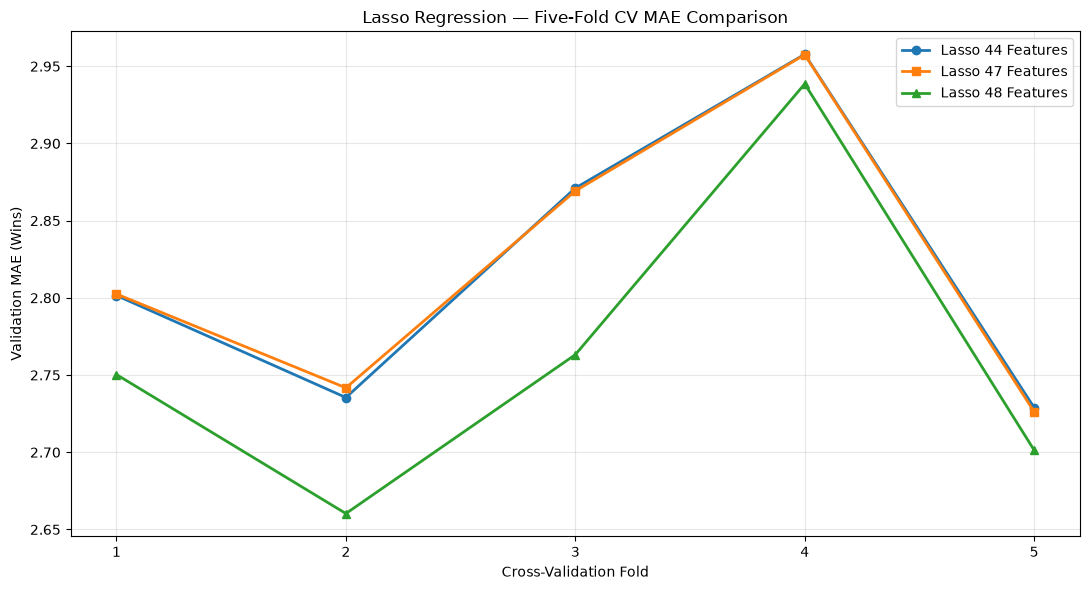

In [46]:
# ============================================================
# STEP 14 — FIVE-FOLD CV MAE COMPARISON
# Lasso: 44 vs 47 vs 48 Features
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, cross_val_score

# ------------------------------------------------------------
# STEP 1 — Prepare feature sets
# ------------------------------------------------------------

X_cv_48 = X_train_48.copy()

X_cv_47 = X_cv_48.drop(
    columns=["Pythagorean_Expected_Wins"]
)

X_cv_44 = X_cv_47.drop(
    columns=[
        "R_per_game",
        "RA_per_game",
        "Run_Differential"
    ]
)

y_cv = y_train_47exp.copy()

print("FEATURE VERIFICATION")
print("--------------------")
print("44 Features:", X_cv_44.shape)
print("47 Features:", X_cv_47.shape)
print("48 Features:", X_cv_48.shape)

# ------------------------------------------------------------
# STEP 2 — Define the same CV folds
# ------------------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# STEP 3 — Build evaluation function
# ------------------------------------------------------------

def get_cv_scores(X, y):

    scale_cols = [
        col for col in X.columns
        if not col.startswith(("era_", "decade_"))
    ]

    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer(
            [("scale", StandardScaler(), scale_cols)],
            remainder="passthrough"
        )),
        ("lasso", Lasso(
            alpha=0.01,
            max_iter=100000
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    return -scores

# ------------------------------------------------------------
# STEP 4 — Calculate CV MAE for each model
# ------------------------------------------------------------

scores_44 = get_cv_scores(X_cv_44, y_cv)
scores_47 = get_cv_scores(X_cv_47, y_cv)
scores_48 = get_cv_scores(X_cv_48, y_cv)

# ------------------------------------------------------------
# STEP 5 — Compare individual folds
# ------------------------------------------------------------

fold_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Lasso 44": scores_44,
    "Lasso 47": scores_47,
    "Lasso 48": scores_48
})

print("\nFIVE-FOLD CV MAE COMPARISON")
print("===========================")
print(fold_results.round(4).to_string(index=False))

# ------------------------------------------------------------
# STEP 6 — Compare mean and standard deviation
# ------------------------------------------------------------

summary = pd.DataFrame({
    "Model": [
        "Lasso 44",
        "Lasso 47",
        "Lasso 48"
    ],
    "Mean CV MAE": [
        scores_44.mean(),
        scores_47.mean(),
        scores_48.mean()
    ],
    "CV Std": [
        scores_44.std(ddof=1),
        scores_47.std(ddof=1),
        scores_48.std(ddof=1)
    ]
})

print("\nCROSS-VALIDATION SUMMARY")
print("========================")
print(summary.round(4).to_string(index=False))

# ------------------------------------------------------------
# STEP 7 — Count which model wins each fold
# ------------------------------------------------------------

wins_48_vs_44 = np.sum(scores_48 < scores_44)
wins_48_vs_47 = np.sum(scores_48 < scores_47)

print("\n48-FEATURE MODEL PERFORMANCE")
print("===========================")

print(
    "48 beats 44 in:",
    wins_48_vs_44,
    "out of 5 folds"
)

print(
    "48 beats 47 in:",
    wins_48_vs_47,
    "out of 5 folds"
)

# ------------------------------------------------------------
# STEP 8 — Visualize fold-by-fold CV MAE
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    fold_results["Fold"],
    scores_44,
    marker="o",
    linewidth=2,
    label="Lasso 44 Features"
)

plt.plot(
    fold_results["Fold"],
    scores_47,
    marker="s",
    linewidth=2,
    label="Lasso 47 Features"
)

plt.plot(
    fold_results["Fold"],
    scores_48,
    marker="^",
    linewidth=2,
    label="Lasso 48 Features"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("Validation MAE (Wins)")

plt.title(
    "Lasso Regression — Five-Fold CV MAE Comparison"
)

plt.xticks([1, 2, 3, 4, 5])

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 14 — Five-Fold Cross-Validation Analysis: Lasso Regression (44 vs 47 vs 48 Features)

### 1. Objective

The objective of this experiment is to evaluate whether the improvement observed after introducing **Pythagorean Expected Wins** is consistent across the five cross-validation folds.

Three Lasso Regression models were compared:

- **Model A:** 44 original features.
- **Model B:** 47 features, including three engineered features.
- **Model C:** 48 features, including Pythagorean Expected Wins.

All three models used alpha = 0.01 and the same five-fold cross-validation partitions.

The primary evaluation metric was **Mean Absolute Error (MAE)**, where lower values indicate better predictive performance.

### 2. Cross-Validation Methodology

Five-fold cross-validation was conducted using the training portion of the dataset.

The training dataset contained **1,129 observations**.

| Parameter | Configuration |
|---|---|
| Cross-validation | 5-Fold KFold |
| Shuffle | True |
| Random State | 42 |
| Lasso Alpha | 0.01 |
| Evaluation Metric | Negative MAE (converted to positive MAE) |
| Training Observations | 1,129 |
| Feature Sets | 44, 47 and 48 |

The same cross-validation partitions were used across all three feature configurations to ensure comparability.

Numerical features were standardized independently within each training fold using a preprocessing pipeline, helping prevent scaling-related data leakage.

### 3. Five-Fold CV MAE Results

| Fold | Lasso 44 Features | Lasso 47 Features | Lasso 48 Features |
|---|---:|---:|---:|
| Fold 1 | 2.8015 | 2.8025 | **2.7503** |
| Fold 2 | 2.7355 | 2.7417 | **2.6603** |
| Fold 3 | 2.8711 | 2.8692 | **2.7632** |
| Fold 4 | 2.9578 | 2.9575 | **2.9386** |
| Fold 5 | 2.7290 | 2.7263 | **2.7014** |
| **Mean CV MAE** | 2.8190 | 2.8195 | **2.7628** |
| **CV Standard Deviation** | 0.0966 | 0.0956 | 0.1065 |

**Observation:** The 48-feature model achieved the lowest validation MAE in all five folds.

This indicates that its lower mean CV MAE was not driven by a single exceptionally favorable fold.

### 4. Mean CV MAE Comparison

The average cross-validation results were:

| Model | Mean CV MAE | Ranking |
|---|---:|---|
| Lasso 48 Features | **2.7628** | 1 |
| Lasso 44 Features | 2.8190 | 2 |
| Lasso 47 Features | 2.8195 | 3 |

Compared with the original 44-feature model:

\[
\text{MAE Reduction} = 2.8190 - 2.7628 = 0.0562
\]

The percentage reduction was:

\[
\frac{0.0562}{2.8190}\times100 \approx 1.99\%
\]

Therefore, the 48-feature model achieved approximately **1.99% lower mean CV MAE** than the original 44-feature Lasso model.

This represents an encouraging improvement in cross-validation predictive performance.

### 5. Fold-by-Fold Consistency

The following comparisons were obtained:

| Comparison | Folds Won by 48-Feature Model |
|---|---:|
| 48 Features vs 44 Features | **5 out of 5** |
| 48 Features vs 47 Features | **5 out of 5** |

The 48-feature model consistently achieved lower validation errors than both alternative models.

The improvement was largest in Fold 3 relative to the 44-feature model, while Fold 4 showed a smaller improvement.

For Fold 4:

- Lasso 44 MAE: 2.9578
- Lasso 48 MAE: 2.9386
- Improvement: 0.0192 wins

This demonstrates that the size of the improvement varied across folds, although its direction was consistent.

**Interpretation:** The new nonlinear feature appears to provide a useful predictive representation across the evaluated cross-validation partitions.

However, consistent improvements in these five folds do not by themselves establish statistical significance or guarantee improvements on independently collected data.

### 6. Cross-Validation Standard Deviation

The standard deviation measures how much validation MAE varies across folds.

| Model | CV MAE Standard Deviation |
|---|---:|
| Lasso 44 Features | 0.0966 |
| Lasso 47 Features | **0.0956** |
| Lasso 48 Features | 0.1065 |

The 48-feature model had a slightly higher standard deviation.

This indicates somewhat greater variability in its validation errors across folds.

Despite this, it achieved the lowest average MAE and outperformed the other two models in every fold.

The higher standard deviation does not automatically indicate overfitting because different validation folds can vary in prediction difficulty.

### 7. Cross-Validation vs Testing Performance

The results were compared with the previously obtained held-out testing metrics.

| Metric | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| **CV MAE** | 2.8190 | 2.8195 | **2.7628** |
| Testing MAE | 2.6898 | **2.6883** | 2.6904 |
| Testing RMSE | 3.3248 | 3.3242 | **3.3029** |
| Testing R² | 0.9308 | 0.9308 | **0.9317** |

The 48-feature model achieved the best cross-validation MAE, testing RMSE and testing R².

However, the 47-feature model achieved a marginally lower testing MAE.

The difference between the 47-feature and 48-feature testing MAE values was:

\[
2.6904-2.6883=0.0021
\]

This difference is negligible.

Therefore, the fold-by-fold improvement supports the usefulness of Pythagorean Expected Wins, but the held-out test results do not show a meaningful improvement in average absolute prediction error.

### 8. Interpretation of Nonlinear Feature Engineering

The 48-feature model introduced **Pythagorean Expected Wins**, calculated as:

\[
\text{Expected Wins}
=
G\times\frac{R^2}{R^2+RA^2}
\]

Unlike the original engineered Run Differential feature, this formula captures a nonlinear relationship between runs scored and runs allowed.

Although Pythagorean Expected Wins is derived from existing baseball statistics, it provides a nonlinear transformation that ordinary Lasso Regression cannot express directly using only separate linear terms for R and RA.

The five-fold comparison suggests that this transformation may help the linear Lasso model represent relationships associated with team wins.

The improvement should be interpreted as evidence of better validation performance under the evaluated experimental configuration, rather than proof of an inherently superior model.

### 9. Key Findings

**Finding 1 — The 48-feature model achieved the lowest mean CV MAE.**

The average CV MAE decreased from 2.8190 to 2.7628 compared with the original 44-feature model.

**Finding 2 — Improvement occurred in all five folds.**

The 48-feature model outperformed both comparison models in every validation fold.

**Finding 3 — The improvement was approximately 1.99%.**

This reflects the reduction in mean CV MAE compared with the original 44-feature model.

**Finding 4 — Validation variability increased slightly.**

The 48-feature model recorded a CV standard deviation of 0.1065, compared with 0.0966 for the original 44-feature model.

**Finding 5 — Held-out testing MAE remained practically unchanged.**

Although CV MAE improved, the 48-feature model did not demonstrate a meaningful reduction in testing MAE.

**Finding 6 — Nonlinear feature engineering appears promising.**

The results suggest that domain-informed nonlinear transformations may provide predictive value beyond simple linear combinations of existing baseball statistics.

### 10. Limitations

The analysis used the same five cross-validation folds that had previously been used to select the Lasso regularization parameter.

Consequently, the reported CV MAE results are not independent estimates of the complete hyperparameter-selection procedure.

The folds were also generated from a single randomized training partition. Their performance cannot establish that similar improvements would occur across all possible training samples.

Furthermore, the held-out test set had already been examined during earlier feature-engineering experiments, making the overall analysis exploratory.

The observed fold-level improvement should therefore be supported by additional validation before claiming consistent superiority in future predictions.

### 11. Recommended Next Experiment

The next recommended step is **repeated or nested cross-validation**.

Repeated cross-validation would assess performance across several randomized fold partitions.

Nested cross-validation would provide a stronger evaluation by performing alpha tuning within each outer training fold and evaluating the selected model on a separate outer validation fold.

A suitable experiment would compare all three feature configurations using:

- Five outer folds.
- Multiple random repetitions, or a nested cross-validation framework.
- Alpha tuning performed using training observations only.
- MAE as the primary evaluation metric.
- RMSE and R² as secondary metrics.

This would help determine whether the observed improvement from Pythagorean Expected Wins remains reliable under different validation partitions.

### 12. Conclusion

The five-fold cross-validation comparison demonstrated that the 48-feature Lasso Regression model achieved consistently lower validation MAE than both the 44-feature and 47-feature alternatives.

Its mean CV MAE was **2.7628**, compared with 2.8190 and 2.8195 for the other models.

The 48-feature model achieved lower validation errors in all five folds, representing an approximately **1.99% reduction in mean CV MAE** relative to the original 44-feature model.

These findings provide encouraging evidence that adding Pythagorean Expected Wins improved Lasso's predictive performance during cross-validation.

However, the testing MAE remained almost unchanged, and the model exhibited slightly greater variation in validation errors across folds.

**Overall, the results suggest that baseball-informed nonlinear feature engineering can improve cross-validation performance, but additional independent validation is required before concluding that the 48-feature model generalizes better.**

The 48-feature model is therefore retained as a promising experimental candidate, while the original 44-feature Lasso remains the benchmark for further comparison.


Running Nested CV: Lasso 44
--------------------------------
Fold 1 | Alpha: 0.01 | MAE: 2.7605
Fold 2 | Alpha: 0.01 | MAE: 3.0280
Fold 3 | Alpha: 0.01 | MAE: 2.9244
Fold 4 | Alpha: 0.001 | MAE: 2.8317
Fold 5 | Alpha: 0.01 | MAE: 2.4173

Running Nested CV: Lasso 47
--------------------------------
Fold 1 | Alpha: 0.01 | MAE: 2.7600
Fold 2 | Alpha: 0.01 | MAE: 3.0274
Fold 3 | Alpha: 0.01 | MAE: 2.9254
Fold 4 | Alpha: 0.001 | MAE: 2.8395
Fold 5 | Alpha: 0.01 | MAE: 2.4212

Running Nested CV: Lasso 48
--------------------------------
Fold 1 | Alpha: 0.01 | MAE: 2.7122
Fold 2 | Alpha: 0.01 | MAE: 2.9888
Fold 3 | Alpha: 0.01 | MAE: 2.9441
Fold 4 | Alpha: 0.001 | MAE: 2.7162
Fold 5 | Alpha: 0.01 | MAE: 2.3972

NESTED CV — INDIVIDUAL FOLD RESULTS
   Model  Fold  Best Alpha    MAE   RMSE     R2
Lasso 44     1       0.010 2.7605 3.5442 0.9197
Lasso 44     2       0.010 3.0280 3.7016 0.9314
Lasso 44     3       0.010 2.9244 3.7347 0.9220
Lasso 44     4       0.001 2.8317 3.5918 0.9359
Lasso 44 

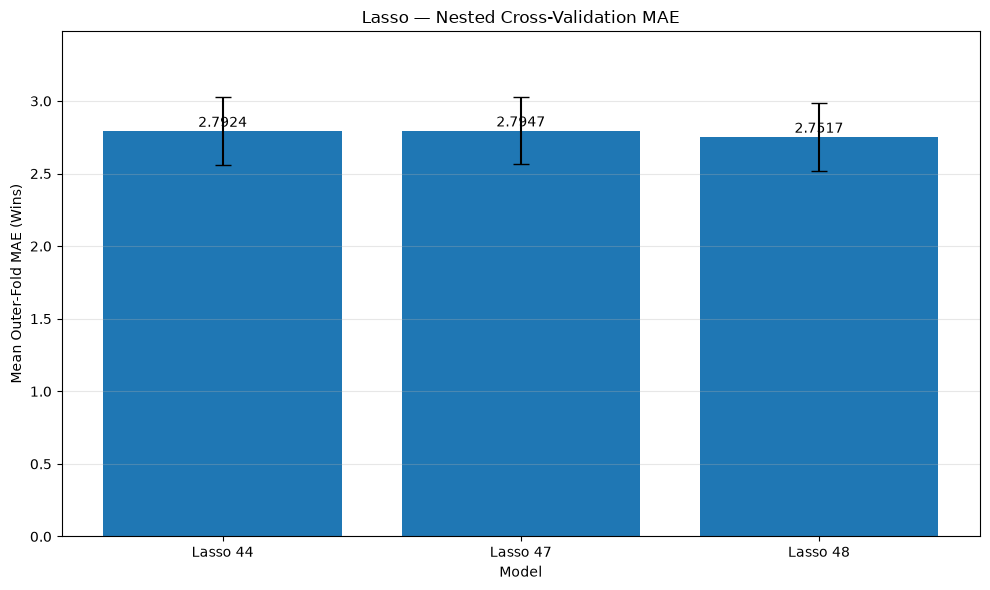

In [47]:
# ============================================================
# STEP 15 — NESTED CROSS-VALIDATION
# LASSO: 44 vs 47 vs 48 Features
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — Prepare the 3 feature sets
# ------------------------------------------------------------

X_nested_48 = X_train_48.copy()

X_nested_47 = X_nested_48.drop(
    columns=["Pythagorean_Expected_Wins"]
)

X_nested_44 = X_nested_47.drop(
    columns=[
        "R_per_game",
        "RA_per_game",
        "Run_Differential"
    ]
)

y_nested = y_train_47exp.copy()

feature_sets = {
    "Lasso 44": X_nested_44,
    "Lasso 47": X_nested_47,
    "Lasso 48": X_nested_48
}

assert [X.shape[1] for X in feature_sets.values()] == [
    44, 47, 48
]

# ------------------------------------------------------------
# STEP 2 — Define inner and outer cross-validation
# ------------------------------------------------------------

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

inner_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

alpha_values = [1.0, 0.5, 0.1, 0.05, 0.01, 0.001]

# ------------------------------------------------------------
# STEP 3 — Run nested cross-validation
# ------------------------------------------------------------

nested_results = []

for model_name, X_data in feature_sets.items():

    # Identify numerical features for scaling
    scale_cols = [
        c for c in X_data.columns
        if not c.startswith(("era_", "decade_"))
    ]

    print(f"\nRunning Nested CV: {model_name}")
    print("--------------------------------")

    for fold, (train_idx, val_idx) in enumerate(
        outer_cv.split(X_data, y_nested), start=1
    ):

        X_tr = X_data.iloc[train_idx]
        X_val = X_data.iloc[val_idx]

        y_tr = y_nested.iloc[train_idx]
        y_val = y_nested.iloc[val_idx]

        # Pipeline prevents scaling leakage
        pipeline = Pipeline([
            ("preprocessing", ColumnTransformer(
                [("scale", StandardScaler(), scale_cols)],
                remainder="passthrough"
            )),
            ("lasso", Lasso(max_iter=100000))
        ])

        # Inner CV selects best alpha
        search = GridSearchCV(
            pipeline,
            {"lasso__alpha": alpha_values},
            cv=inner_cv,
            scoring="neg_mean_absolute_error",
            n_jobs=-1
        )

        search.fit(X_tr, y_tr)

        # Outer validation evaluates tuned model
        preds = search.best_estimator_.predict(X_val)

        mae = mean_absolute_error(y_val, preds)

        rmse = np.sqrt(
            mean_squared_error(y_val, preds)
        )

        r2 = r2_score(y_val, preds)

        nested_results.append({
            "Model": model_name,
            "Fold": fold,
            "Best Alpha": search.best_params_["lasso__alpha"],
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        print(
            f"Fold {fold} | "
            f"Alpha: {search.best_params_['lasso__alpha']} | "
            f"MAE: {mae:.4f}"
        )

# ------------------------------------------------------------
# STEP 4 — Show all fold results
# ------------------------------------------------------------

nested_df = pd.DataFrame(nested_results)

print("\nNESTED CV — INDIVIDUAL FOLD RESULTS")
print("===================================")

print(nested_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# STEP 5 — Summary statistics
# ------------------------------------------------------------

nested_summary = (
    nested_df.groupby("Model")
    .agg(
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_R2=("R2", "mean")
    )
    .round(4)
)

print("\nNESTED CV — FINAL SUMMARY")
print("=========================")

print(nested_summary.to_string())

# ------------------------------------------------------------
# STEP 6 — Compare 48 features against alternatives
# ------------------------------------------------------------

fold_mae = nested_df.pivot(
    index="Fold",
    columns="Model",
    values="MAE"
)

print("\n48-FEATURE MODEL PERFORMANCE")
print("============================")

print(
    "48 beats 44:",
    int((fold_mae["Lasso 48"] < fold_mae["Lasso 44"]).sum()),
    "out of 5 folds"
)

print(
    "48 beats 47:",
    int((fold_mae["Lasso 48"] < fold_mae["Lasso 47"]).sum()),
    "out of 5 folds"
)

# ------------------------------------------------------------
# STEP 7 — Visualization
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

models = nested_summary.index.tolist()

means = nested_summary["Mean_MAE"].values
stds = nested_summary["Std_MAE"].values

bars = plt.bar(
    models,
    means,
    yerr=stds,
    capsize=6
)

for bar, value in zip(bars, means):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.03,
        f"{value:.4f}",
        ha="center"
    )

plt.title("Lasso — Nested Cross-Validation MAE")
plt.ylabel("Mean Outer-Fold MAE (Wins)")
plt.xlabel("Model")
plt.ylim(0, max(means + stds) * 1.15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Step 15 — Nested Cross-Validation Analysis: Lasso Regression (44 vs 47 vs 48 Features)

### 1. Objective

The objective of this experiment is to evaluate whether the improved predictive performance of the **48-feature Lasso Regression model**, which incorporates Pythagorean Expected Wins, remains consistent under a more rigorous cross-validation procedure.

Three feature configurations were evaluated:

- **Model A:** 44 original baseball features.
- **Model B:** 47 features, including three engineered features.
- **Model C:** 48 features, including Pythagorean Expected Wins.

Nested cross-validation was applied to separate hyperparameter tuning from model performance evaluation.

The primary metric was **Mean Absolute Error (MAE)**, where lower values indicate better predictive performance.

Secondary evaluation metrics included Root Mean Squared Error (RMSE), R² and variability across validation folds.

### 2. Why Nested Cross-Validation?

In conventional cross-validation, the same validation results may be used to select the best hyperparameter and report model performance.

This can produce an optimistically biased estimate of generalization performance.

Nested cross-validation addresses this limitation by introducing two validation loops.

**Inner Cross-Validation — Hyperparameter Tuning**

The inner loop identifies the best Lasso regularization parameter (alpha) using GridSearchCV.

**Outer Cross-Validation — Model Evaluation**

The outer loop evaluates the tuned model using validation observations that were not used during the inner hyperparameter search.

This separation provides a more reliable estimate of the predictive performance of the model-tuning procedure.

### 3. Experimental Methodology

| Parameter | Configuration |
|---|---|
| Model | Lasso Regression |
| Training Observations | 1,129 |
| Feature Configurations | 44, 47 and 48 |
| Outer Cross-Validation | 5-Fold KFold |
| Outer Random State | 2026 |
| Inner Cross-Validation | 3-Fold KFold |
| Inner Random State | 42 |
| Shuffle | True |
| Alpha Candidates | 1.0, 0.5, 0.1, 0.05, 0.01, 0.001 |
| Primary Evaluation Metric | MAE |
| Secondary Metrics | RMSE and R² |

All three models were evaluated using the same outer validation partitions to ensure consistent comparison.

Numerical variables were standardized within the modelling pipeline. Scaling parameters were estimated using training observations only within each cross-validation split.

### 4. Individual Nested Cross-Validation Results

| Model | Fold | Best Alpha | MAE | RMSE | R² |
|---|---:|---:|---:|---:|---:|
| Lasso 44 | 1 | 0.010 | 2.7605 | 3.5442 | 0.9197 |
| Lasso 44 | 2 | 0.010 | 3.0280 | 3.7016 | 0.9314 |
| Lasso 44 | 3 | 0.010 | 2.9244 | 3.7347 | 0.9220 |
| Lasso 44 | 4 | 0.001 | 2.8317 | 3.5918 | 0.9359 |
| Lasso 44 | 5 | 0.010 | 2.4173 | 3.1361 | 0.9379 |
| Lasso 47 | 1 | 0.010 | 2.7600 | 3.5427 | 0.9198 |
| Lasso 47 | 2 | 0.010 | 3.0274 | 3.7009 | 0.9315 |
| Lasso 47 | 3 | 0.010 | 2.9254 | 3.7339 | 0.9221 |
| Lasso 47 | 4 | 0.001 | 2.8395 | 3.5994 | 0.9356 |
| Lasso 47 | 5 | 0.010 | 2.4212 | 3.1430 | 0.9376 |
| Lasso 48 | 1 | 0.010 | 2.7122 | 3.4578 | 0.9236 |
| Lasso 48 | 2 | 0.010 | 2.9888 | 3.6762 | 0.9324 |
| Lasso 48 | 3 | 0.010 | 2.9441 | 3.6589 | 0.9252 |
| Lasso 48 | 4 | 0.001 | 2.7162 | 3.4470 | 0.9409 |
| Lasso 48 | 5 | 0.010 | 2.3972 | 3.0787 | 0.9402 |

### 5. Final Nested Cross-Validation Summary

| Metric | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| **Mean MAE ↓** | 2.7924 | 2.7947 | **2.7517** |
| MAE Standard Deviation | 0.2325 | **0.2312** | 0.2354 |
| **Mean RMSE ↓** | 3.5417 | 3.5440 | **3.4637** |
| **Mean R² ↑** | 0.9294 | 0.9293 | **0.9325** |

**Observation:** The 48-feature Lasso model achieved the lowest mean MAE, lowest mean RMSE and highest mean R² under nested cross-validation.

This provides further evidence that introducing Pythagorean Expected Wins may improve the model's predictive performance.

However, the 48-feature model also demonstrated slightly greater fold-to-fold variability in MAE.

### 6. Mean MAE Improvement

The original 44-feature model achieved:

**Mean Nested CV MAE = 2.7924**

The 48-feature model achieved:

**Mean Nested CV MAE = 2.7517**

The reduction in error was:

\[
2.7924-2.7517=0.0407
\]

The percentage improvement was:

\[
\frac{0.0407}{2.7924}\times100\approx1.46\%
\]

Therefore, the 48-feature model achieved approximately **1.46% lower mean nested CV MAE** than the original 44-feature model.

This improvement is modest but encouraging.

### 7. Fold-by-Fold Consistency Analysis

The 48-feature model achieved lower MAE than both alternatives in four of the five outer validation folds.

| Comparison | Folds Won by 48-Feature Model |
|---|---:|
| Lasso 48 vs Lasso 44 | **4 out of 5** |
| Lasso 48 vs Lasso 47 | **4 out of 5** |

**Folds 1, 2, 4 and 5**

The 48-feature model achieved the lowest MAE among the three models.

**Fold 3**

The 48-feature model performed slightly worse:

| Model | Fold 3 MAE |
|---|---:|
| Lasso 44 | **2.9244** |
| Lasso 47 | 2.9254 |
| Lasso 48 | 2.9441 |

This demonstrates that adding Pythagorean Expected Wins does not guarantee better prediction accuracy across every validation partition.

Nevertheless, the 48-feature model maintained the best average performance over the five outer folds.

### 8. Hyperparameter Stability

The nested cross-validation experiment also examined the optimal alpha selected during inner cross-validation.

| Fold | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| 1 | 0.01 | 0.01 | 0.01 |
| 2 | 0.01 | 0.01 | 0.01 |
| 3 | 0.01 | 0.01 | 0.01 |
| 4 | 0.001 | 0.001 | 0.001 |
| 5 | 0.01 | 0.01 | 0.01 |

All three models selected:

- **Alpha = 0.01 in four folds.**
- **Alpha = 0.001 in one fold.**

This indicates that the preferred regularization strength was reasonably consistent across the evaluated training partitions.

The occasional selection of alpha = 0.001 suggests that a weaker L1 penalty may be preferable for some training subsets.

### 9. Comparison with Previous Experiments

The nested cross-validation findings were compared with the original five-fold CV and held-out testing results.

| Metric | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| Original 5-Fold CV MAE | 2.8190 | 2.8195 | **2.7628** |
| **Nested CV MAE** | 2.7924 | 2.7947 | **2.7517** |
| Testing MAE | 2.6898 | **2.6883** | 2.6904 |
| Testing RMSE | 3.3248 | 3.3242 | **3.3029** |
| Testing R² | 0.9308 | 0.9308 | **0.9317** |

The 48-feature model performed best according to nested CV MAE, testing RMSE and testing R².

However, the 47-feature model achieved a marginally lower testing MAE.

The differences in testing MAE were extremely small.

These results suggest that the new nonlinear feature may improve model robustness in some evaluation settings, but it does not establish a substantial improvement in held-out average absolute prediction error.

The original and nested CV results were obtained using different validation partitions and tuning procedures, so their absolute MAE values are not expected to be identical.

### 10. Interpretation of Nonlinear Feature Engineering

The 48-feature model introduced the baseball-specific feature:

\[
\text{Pythagorean Expected Wins}
=
G\times\frac{R^2}{R^2+RA^2}
\]

This feature represents a nonlinear relationship between runs scored, runs allowed and expected team wins.

Unlike Run Differential, which is a linear combination of existing predictors, Pythagorean Expected Wins provides a nonlinear transformation.

This allows a linear Lasso Regression model to represent more complex relationships without changing the underlying regression algorithm.

The improvement in nested CV performance suggests that this transformation may provide useful predictive information.

However, the engineered feature is still derived from existing baseball statistics and should not be interpreted as introducing independent new data.

### 11. Key Findings

**Finding 1 — The 48-feature model achieved the best nested CV performance.**

It recorded the lowest mean MAE of 2.7517, compared with 2.7924 and 2.7947 for the alternative models.

**Finding 2 — Mean nested CV MAE improved by approximately 1.46%.**

The improvement was measured relative to the original 44-feature Lasso.

**Finding 3 — Improvement occurred in four of five outer folds.**

The 48-feature model outperformed the other models in most, but not all, validation partitions.

**Finding 4 — Testing performance remained broadly similar.**

Although nested CV MAE improved, held-out testing MAE remained approximately 2.69 wins for all three models.

**Finding 5 — Alpha tuning was reasonably stable.**

Alpha = 0.01 was selected in four of five folds for all three feature configurations.

**Finding 6 — Nonlinear feature engineering showed potential value.**

The Pythagorean Expected Wins feature appears to improve the ability of Lasso to represent baseball performance relationships under cross-validation.

### 12. Limitations

Nested cross-validation provides a more rigorous assessment of hyperparameter tuning than reporting the best GridSearchCV score alone.

However, several limitations remain.

First, the experiment used only five outer folds from one randomized partitioning scheme.

Second, the performance improvement was relatively small and was not observed in every fold.

Third, the 48-feature configuration was introduced after reviewing earlier experiments, including held-out testing results. Therefore, nested CV does not completely remove the effects of exploratory model selection.

Fourth, the training dataset includes historical full-season statistics. Results should therefore be interpreted as estimates of completed-season wins rather than validated preseason forecasts.

Additional evaluation using repeated nested cross-validation or a genuinely independent dataset would provide stronger evidence of generalization performance.

### 13. Recommendation

Based on the experimental results:

- **44-feature Lasso:** Retain as the original benchmark model.
- **47-feature Lasso:** Retain as the basic feature-engineering experiment.
- **48-feature Lasso:** Retain as the leading exploratory candidate based on nested CV performance.

The 48-feature model provides the strongest nested cross-validation results, although its advantage in held-out testing performance remains limited.

Rather than continuing to introduce additional features, the next stage should focus on comparing Lasso with alternative machine learning algorithms, such as Decision Tree Regression.

### 14. Conclusion

The nested cross-validation experiment demonstrated that the **48-feature Lasso Regression model achieved the strongest average predictive performance** among the three evaluated feature configurations.

Its mean nested CV MAE was **2.7517**, representing an approximately **1.46% reduction** compared with the original 44-feature Lasso.

The model achieved lower validation MAE in four of five outer folds, together with the lowest mean RMSE of 3.4637 and highest mean R² of 0.9325.

These findings provide encouraging evidence that introducing Pythagorean Expected Wins improved Lasso's predictive performance under the evaluated nested cross-validation procedure.

Nevertheless, testing MAE remained almost identical across the models, and the observed improvement was modest.

**Overall, the results support the potential value of domain-informed nonlinear feature engineering while highlighting the importance of rigorous validation and cautious interpretation of small performance improvements.**

The 48-feature Lasso is retained as the strongest exploratory candidate based on nested CV MAE, while the 44-feature Lasso remains the original benchmark for future machine learning comparisons.

## Step 15A — Why Did Nested Cross-Validation Select Alpha = 0.001 in Fold 4?

### 1. Objective

The objective of this analysis is to explain why nested cross-validation selected a different Lasso regularization parameter in Fold 4 compared with the other four outer folds.

The experiment used:

- **Outer cross-validation:** 5 folds
- **Inner cross-validation:** 3 folds
- **Evaluation metric:** Mean Absolute Error (MAE)
- **Alpha candidates:** 1.0, 0.5, 0.1, 0.05, 0.01 and 0.001
- **Feature configurations:** 44, 47 and 48 features

### 2. Nested Cross-Validation Alpha Selection Results

| Outer Fold | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| Fold 1 | 0.01 | 0.01 | 0.01 |
| Fold 2 | 0.01 | 0.01 | 0.01 |
| Fold 3 | 0.01 | 0.01 | 0.01 |
| **Fold 4** | **0.001** | **0.001** | **0.001** |
| Fold 5 | 0.01 | 0.01 | 0.01 |

**Observation:** All three feature configurations selected alpha = 0.001 in Fold 4, while alpha = 0.01 was selected in the other four folds.

### 3. Understanding Alpha in Lasso Regression

Lasso Regression uses L1 regularization to control model complexity.

The objective function includes a penalty proportional to the absolute values of model coefficients.

A larger alpha applies stronger regularization, while a smaller alpha applies weaker regularization.

| Alpha | Regularization Strength | General Effect |
|---|---|---|
| 1.0 | Stronger | Encourages more coefficients to become zero |
| 0.01 | Weaker | Allows more coefficients to retain nonzero values |
| 0.001 | Even weaker | Applies a smaller penalty to model coefficients |

**Important:** Reducing alpha does not guarantee that more features will be selected or that predictive accuracy will improve.

### 4. Why Did Fold 4 Select Alpha = 0.001?

Nested cross-validation separates hyperparameter selection from model evaluation.

**Inner cross-validation — Hyperparameter selection**

For each outer fold, GridSearchCV evaluates the candidate alpha values using the outer training subset.

The alpha with the lowest average inner validation MAE is selected.

**Outer cross-validation — Model evaluation**

The selected model is then evaluated using the corresponding outer validation subset, which was not used for training or alpha selection.

In Fold 4, the inner cross-validation procedure selected alpha = 0.001 for all three models.

This indicates that alpha = 0.001 produced the best average inner validation MAE among the tested candidates for that particular outer training subset.

The exact difference between alpha = 0.001 and alpha = 0.01 cannot be determined from the reported output because the individual inner CV scores were not displayed.

### 5. Why Can the Best Alpha Change Across Folds?

Each outer fold contains a different combination of training and validation observations.

Therefore, the relationships between predictors and the target variable may vary slightly across training subsets.

These differences can affect the optimal level of regularization.

For example:

- A training subset may benefit from stronger coefficient shrinkage.
- Another subset may benefit from allowing greater model flexibility.
- Correlations among baseball statistics may differ across subsets.
- Random variation in the observations can affect validation performance.

Consequently, it is normal for nested cross-validation to select different hyperparameters across outer folds.

### 6. Fold 4 Model Performance

The Fold 4 outer validation results were:

| Metric | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| Best Alpha | 0.001 | 0.001 | 0.001 |
| MAE | 2.8317 | 2.8395 | **2.7162** |
| RMSE | 3.5918 | 3.5994 | **3.4470** |
| R² | 0.9359 | 0.9356 | **0.9409** |

The 48-feature model achieved the lowest MAE and RMSE and the highest R² in Fold 4.

However, these results do not establish that alpha = 0.001 is universally better than alpha = 0.01.

The selected alpha was determined using the inner cross-validation results, not by directly optimizing performance on the outer validation fold.

### 7. Does Alpha = 0.001 Indicate Overfitting?

Selecting a smaller alpha does not automatically indicate overfitting.

A smaller alpha reduces regularization and allows the model greater flexibility, which can increase overfitting risk under certain conditions.

However, determining whether overfitting occurred requires examination of training and validation performance.

The Fold 4 results alone do not provide sufficient evidence to conclude that alpha = 0.001 caused overfitting.

The observed outer validation results indicate that the tuned models maintained useful predictive performance on that particular fold.

### 8. Hyperparameter Stability

Across the five outer folds:

| Alpha | Number of Folds Selected | Percentage |
|---|---:|---:|
| **0.01** | **4** | **80%** |
| 0.001 | 1 | 20% |

The same selection pattern was observed for all three Lasso feature configurations.

**Interpretation:** Alpha = 0.01 was the most frequently selected parameter, suggesting that the preferred regularization strength was reasonably stable across the evaluated training partitions.

Nevertheless, this observation is based on only five outer folds and should not be interpreted as proof that alpha = 0.01 is universally optimal.

### 9. Key Findings

**Finding 1 — Alpha selection depends on training data.**

Different outer training subsets can produce different optimal hyperparameters.

**Finding 2 — Fold 4 preferred weaker regularization.**

GridSearchCV selected alpha = 0.001 instead of 0.01 for all three models.

**Finding 3 — Alpha = 0.01 demonstrated reasonable stability.**

The parameter was selected in four of five outer folds.

**Finding 4 — Smaller alpha does not necessarily indicate overfitting.**

Overfitting must be evaluated through model performance rather than the alpha value alone.

**Finding 5 — Nested cross-validation supports more rigorous evaluation.**

Hyperparameter tuning was performed within the inner folds, while predictive performance was measured using separate outer validation observations.

### 10. Conclusion

The nested cross-validation experiment selected alpha = 0.001 in Fold 4 because the inner three-fold cross-validation procedure favored weaker regularization for that outer training subset.

In contrast, alpha = 0.01 was selected in the other four folds for all three feature configurations.

This variation demonstrates that optimal regularization strength can depend on the observations used during model training.

The results suggest reasonable hyperparameter stability, with alpha = 0.01 selected in 80% of outer folds.

**Overall, Fold 4's selection of alpha = 0.001 is a normal outcome of nested cross-validation and does not, by itself, indicate overfitting or a modelling error.**

Further examination of the inner CV MAE scores for alpha = 0.001 and alpha = 0.01 would help determine whether the preference for weaker regularization was substantial or marginal.

## Understanding Nested Cross-Validation (Nested CV)

### 1. What Is Nested Cross-Validation?

**Nested Cross-Validation (Nested CV)** is a machine learning evaluation technique that uses two layers of cross-validation to separate hyperparameter tuning from model performance evaluation.

The two layers are:

- **Inner CV:** Selects the best hyperparameters.
- **Outer CV:** Evaluates how well the tuned model performs on unseen validation data.

Nested CV helps reduce the optimistic bias that can occur when the same cross-validation scores are used both to select a model and to report its performance.

**Memory aid: Nested CV = Tune Inside, Test Outside.**

### 2. ELI5 Explanation — Examination Analogy

Imagine a student preparing for an examination.

**Normal Cross-Validation**

The student tries different study methods using practice examination questions.

The student chooses the method that achieves the highest practice score.

However, reporting that same practice score as the final examination result may be overly optimistic.

**Nested Cross-Validation**

The student uses two separate evaluation stages:

- **Inner CV = Practice Examination:** Identify the best study method.
- **Outer CV = Independent Examination:** Evaluate the selected method using questions that were not used to choose it.

This provides a more reliable assessment of the student's performance on unfamiliar questions.

The same principle applies to evaluating machine learning models.

### 3. How Nested CV Works in the Moneyball Project

The Moneyball training dataset contains **1,129 historical MLB team-season observations**.

The nested cross-validation experiment used:

| Parameter | Configuration |
|---|---|
| Outer CV | 5 folds |
| Inner CV | 3 folds |
| Outer Random State | 2026 |
| Inner Random State | 42 |
| Model | Lasso Regression |
| Feature Configurations | 44, 47 and 48 |
| Primary Metric | MAE |
| Alpha Candidates | 1.0, 0.5, 0.1, 0.05, 0.01, 0.001 |

**Step 1 — Outer CV divides the data.**

The 1,129 training observations are divided into five outer folds.

During each iteration, approximately 80% of the observations are used for outer training and 20% are reserved for outer validation.

**Step 2 — Inner CV tunes alpha.**

The outer training portion is divided into three inner folds.

GridSearchCV evaluates the candidate alpha values and identifies the value with the lowest average inner validation MAE.

**Step 3 — Retrain using the selected alpha.**

The selected Lasso model is fitted using the complete outer training portion.

**Step 4 — Evaluate on the outer validation fold.**

The model predicts wins for observations excluded from both the fitting and hyperparameter-selection process for that outer fold.

MAE, RMSE and R² are calculated.

**Step 5 — Repeat across all five outer folds.**

Each outer fold independently performs hyperparameter tuning and model evaluation.

The outer validation metrics are averaged to obtain the nested CV results.

### 4. Normal CV vs Nested CV

| Aspect | Normal Cross-Validation | Nested Cross-Validation |
|---|---|---|
| Validation layers | One | Two |
| Hyperparameter tuning | Can be performed | Performed in inner CV |
| Independent evaluation of tuning | Not necessarily | Outer CV |
| Risk of optimistic tuning score | Higher when reporting the best tuning score | Reduced |
| Computational cost | Lower | Higher |
| Main purpose | Hyperparameter selection | Evaluation of the model-tuning procedure |

**Important:** Nested CV is not a separate machine learning algorithm. It is an evaluation methodology that can be applied to regression and classification models.

### 5. Nested CV Results — Moneyball Lasso

The following results were obtained:

| Metric | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| Mean Nested CV MAE | 2.7924 | 2.7947 | **2.7517** |
| MAE Standard Deviation | 0.2325 | 0.2312 | 0.2354 |
| Mean Nested CV RMSE | 3.5417 | 3.5440 | **3.4637** |
| Mean Nested CV R² | 0.9294 | 0.9293 | **0.9325** |

The 48-feature model achieved the lowest mean MAE and RMSE, together with the highest mean R².

This suggests that the additional nonlinear Pythagorean Expected Wins feature may contribute useful predictive information.

### 6. Example — How Inner CV Selected Alpha

For the 48-feature Lasso model:

| Outer Fold | Best Alpha | Outer Validation MAE |
|---|---:|---:|
| 1 | 0.01 | 2.7122 |
| 2 | 0.01 | 2.9888 |
| 3 | 0.01 | 2.9441 |
| 4 | 0.001 | 2.7162 |
| 5 | 0.01 | 2.3972 |
| **Mean** | — | **2.7517** |

Alpha = 0.01 was selected in four outer folds, while alpha = 0.001 was selected in one fold.

This demonstrates that hyperparameter tuning was conducted independently within each outer training partition.

The 48-feature model achieved lower validation MAE than the 44-feature model in four of the five outer folds.

### 7. Why Are the Nested CV Results Different from Normal CV?

The original five-fold CV and nested CV results were:

| Model | Original CV MAE | Nested CV MAE |
|---|---:|---:|
| Lasso 44 | 2.8190 | 2.7924 |
| Lasso 47 | 2.8195 | 2.7947 |
| Lasso 48 | 2.7628 | 2.7517 |

The results differ because the experiments used different validation partitions and tuning procedures.

The original CV used five folds with random_state = 42.

Nested CV used five outer folds with random_state = 2026 and three inner folds with random_state = 42.

Therefore, differences between these CV values should not be interpreted as improvements caused by nested CV itself.

Nested CV primarily provides a more independent evaluation of hyperparameter tuning.

### 8. Why Nested CV Is Important for Research

Nested CV helps address several methodological concerns.

**1. Hyperparameter-selection bias**

The best tuning score may be overly optimistic because it was selected from several competing hyperparameter configurations.

Nested CV evaluates the tuning procedure using separate outer validation data.

**2. Data leakage prevention**

When preprocessing is implemented correctly inside the modelling pipeline, each validation fold remains excluded from the fitting of scaling parameters.

**3. Model comparison**

Using the same outer folds allows different models or feature configurations to be evaluated under comparable conditions.

**4. Generalization assessment**

Outer validation performance provides evidence about how well the complete tuning procedure may perform on observations excluded from its training.

### 9. Limitations

Although nested CV is more rigorous than reporting only the best tuning score, it does not eliminate all uncertainty.

The Moneyball experiment used five outer folds from one randomized partition.

The 48-feature model was also developed after reviewing earlier results, meaning that the choice of feature configuration was part of an exploratory process.

Nested CV evaluated alpha tuning within each predefined feature set; it did not independently repeat the entire feature-engineering discovery process.

Furthermore, the dataset contains historical full-season statistics. The evaluation therefore concerns estimating wins from season-level performance rather than making genuine preseason forecasts.

Repeated nested CV, chronological validation or evaluation on an untouched external dataset would strengthen conclusions about generalization.

### 10. Key Findings

**Finding 1 — Nested CV separates tuning and evaluation.**

The inner loop selects hyperparameters, while the outer loop evaluates the tuned model.

**Finding 2 — Alpha selection was reasonably stable.**

Alpha = 0.01 was selected in four of five outer folds across all three feature configurations.

**Finding 3 — The 48-feature model achieved the lowest nested CV MAE.**

Its mean MAE of 2.7517 was lower than 2.7924 for the original 44-feature model.

**Finding 4 — The performance improvement was modest.**

The reduction in mean nested CV MAE was approximately 1.46%.

**Finding 5 — Further validation remains necessary.**

Although the 48-feature model performed better in four of five outer folds, its held-out testing MAE was nearly identical to that of the other models.

### 11. Conclusion

Nested Cross-Validation provides a more rigorous approach to evaluating machine learning models by separating hyperparameter tuning from performance assessment.

In the Moneyball Lasso experiment, five outer folds and three inner folds were used to evaluate three feature configurations.

The 48-feature Lasso model achieved the lowest mean nested CV MAE of **2.7517**, mean RMSE of **3.4637**, and highest mean R² of **0.9325**.

These findings provide encouraging evidence that Pythagorean Expected Wins may improve the predictive capability of Lasso Regression.

However, the improvement was modest and was not observed in every outer validation fold.

**Overall, nested CV strengthened the evaluation methodology and supported the 48-feature Lasso as a promising candidate, while highlighting the importance of cautious interpretation and further independent validation.**

**Memory Aid:**

**Inner CV = Tune the model.**

**Outer CV = Test the tuning procedure.**

**Nested CV = Tune Inside, Test Outside.**

In [48]:
# ============================================================
# STEP 16 — ADDITIONAL NONLINEAR FEATURE ENGINEERING
# LASSO REGRESSION: 48 vs 56 FEATURES
#
# Objective: Try to improve CV MAE towards 2.707
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold


# ------------------------------------------------------------
# STEP 1 — Copy existing 48-feature training dataset
# ------------------------------------------------------------

X_train_56 = X_train_48.copy()

# Same training target
y_train_56 = y_train_47exp.copy()


# ------------------------------------------------------------
# STEP 2 — Add 8 nonlinear engineered features
# ------------------------------------------------------------

# 1. Pythagorean Expected Wins — exponent 1.83
X_train_56["Pythagorean_Expected_Wins_183"] = (
    X_train_56["G"]
    * X_train_56["R"] ** 1.83
    / (
        X_train_56["R"] ** 1.83
        + X_train_56["RA"] ** 1.83
    )
)

# 2. Run Differential per Game
X_train_56["Run_Diff_Per_Game"] = (
    (X_train_56["R"] - X_train_56["RA"])
    / X_train_56["G"]
)

# 3. Log Run Ratio
X_train_56["Log_Run_Ratio"] = np.log(
    (X_train_56["R"] + 1)
    / (X_train_56["RA"] + 1)
)

# 4. Batting Average
X_train_56["Batting_Average"] = (
    X_train_56["H"] / X_train_56["AB"]
)

# 5. Isolated Power
X_train_56["Isolated_Power"] = (
    X_train_56["2B"]
    + 2 * X_train_56["3B"]
    + 3 * X_train_56["HR"]
) / X_train_56["AB"]

# 6. WHIP Proxy
X_train_56["WHIP_Proxy"] = (
    X_train_56["HA"] + X_train_56["BBA"]
) / (X_train_56["IPouts"] / 3)

# 7. Walk Rate Proxy
X_train_56["BB_Rate_Proxy"] = (
    X_train_56["BB"]
    / (X_train_56["AB"] + X_train_56["BB"])
)

# 8. Pitching Strikeout-to-Walk Ratio
X_train_56["Pitching_K_BB_Ratio"] = (
    X_train_56["SOA"]
    / (X_train_56["BBA"] + 1)
)


# ------------------------------------------------------------
# STEP 3 — Verify features
# ------------------------------------------------------------

print("FEATURE VERIFICATION")
print("--------------------")

print("Original features:", X_train_48.shape[1])
print("New features:", X_train_56.shape[1])

assert X_train_56.shape[1] == 56

assert np.isfinite(
    X_train_56.to_numpy(dtype=float)
).all(), "Invalid values detected in engineered features."


# ------------------------------------------------------------
# STEP 4 — Define five-fold CV
# ------------------------------------------------------------

cv_56 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

alpha_grid_56 = {
    "lasso__alpha": [
        1.0, 0.5, 0.1, 0.05, 0.01, 0.001
    ]
}


# ------------------------------------------------------------
# STEP 5 — Create tuning function
# ------------------------------------------------------------

def tune_lasso_cv(X, y):

    scale_cols = [
        col for col in X.columns
        if not col.startswith(("era_", "decade_"))
    ]

    pipeline = Pipeline([
        (
            "preprocessing",
            ColumnTransformer(
                [("scale", StandardScaler(), scale_cols)],
                remainder="passthrough"
            )
        ),
        (
            "lasso",
            Lasso(max_iter=100000)
        )
    ])

    grid = GridSearchCV(
        pipeline,
        alpha_grid_56,
        cv=cv_56,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    grid.fit(X, y)

    return grid


# ------------------------------------------------------------
# STEP 6 — Tune both models
# ------------------------------------------------------------

grid_48_check = tune_lasso_cv(
    X_train_48,
    y_train_56
)

grid_56 = tune_lasso_cv(
    X_train_56,
    y_train_56
)


# ------------------------------------------------------------
# STEP 7 — Compare CV MAE
# ------------------------------------------------------------

cv_mae_48_check = -grid_48_check.best_score_
cv_mae_56 = -grid_56.best_score_

comparison_56 = pd.DataFrame({
    "Model": [
        "Lasso 48 Features",
        "Lasso 56 Features"
    ],
    "Best Alpha": [
        grid_48_check.best_params_["lasso__alpha"],
        grid_56.best_params_["lasso__alpha"]
    ],
    "CV MAE": [
        cv_mae_48_check,
        cv_mae_56
    ]
})

print("\nLASSO CV MAE COMPARISON")
print("======================")

print(
    comparison_56.round(4).to_string(index=False)
)

print("\nCV MAE IMPROVEMENT")
print("------------------")

print(
    f"Previous CV MAE: {cv_mae_48_check:.4f}"
)

print(
    f"New CV MAE     : {cv_mae_56:.4f}"
)

print(
    f"Improvement    : "
    f"{cv_mae_48_check - cv_mae_56:.4f}"
)


# ------------------------------------------------------------
# STEP 8 — Feature selection
# ------------------------------------------------------------

lasso_56 = grid_56.best_estimator_

coefs_56 = lasso_56.named_steps["lasso"].coef_

feature_names_56 = [
    name.split("__", 1)[-1]
    for name in lasso_56.named_steps[
        "preprocessing"
    ].get_feature_names_out()
]

selected_count_56 = np.sum(
    np.abs(coefs_56) > 1e-6
)

print("\nFEATURE SELECTION")
print("-----------------")

print("Original features:", len(coefs_56))
print("Selected features:", selected_count_56)
print(
    "Eliminated features:",
    len(coefs_56) - selected_count_56
)


# ------------------------------------------------------------
# STEP 9 — Check the 8 new features
# ------------------------------------------------------------

new_features = [
    "Pythagorean_Expected_Wins_183",
    "Run_Diff_Per_Game",
    "Log_Run_Ratio",
    "Batting_Average",
    "Isolated_Power",
    "WHIP_Proxy",
    "BB_Rate_Proxy",
    "Pitching_K_BB_Ratio"
]

coef_df_56 = pd.DataFrame({
    "Feature": feature_names_56,
    "Coefficient": coefs_56
})

new_feature_results = coef_df_56[
    coef_df_56["Feature"].isin(new_features)
].copy()

new_feature_results["Status"] = np.where(
    new_feature_results["Coefficient"].abs() > 1e-6,
    "SELECTED",
    "ELIMINATED"
)

print("\nNEW FEATURE SELECTION RESULTS")
print("=============================")

print(
    new_feature_results.to_string(index=False)
)


# ------------------------------------------------------------
# STEP 10 — Check target CV MAE
# ------------------------------------------------------------

target_cv_mae = 2.707

print("\nTARGET CV MAE CHECK")
print("===================")

print(f"Target CV MAE: {target_cv_mae:.4f}")
print(f"Actual CV MAE: {cv_mae_56:.4f}")

if cv_mae_56 <= target_cv_mae:
    print("TARGET REACHED")
else:
    print("TARGET NOT REACHED")
    print(
        f"Remaining gap: "
        f"{cv_mae_56 - target_cv_mae:.4f}"
    )

FEATURE VERIFICATION
--------------------
Original features: 48
New features: 56

LASSO CV MAE COMPARISON
            Model  Best Alpha  CV MAE
Lasso 48 Features        0.01  2.7628
Lasso 56 Features        0.01  2.7583

CV MAE IMPROVEMENT
------------------
Previous CV MAE: 2.7628
New CV MAE     : 2.7583
Improvement    : 0.0045

FEATURE SELECTION
-----------------
Original features: 56
Selected features: 33
Eliminated features: 23

NEW FEATURE SELECTION RESULTS
                      Feature  Coefficient     Status
Pythagorean_Expected_Wins_183     0.000000 ELIMINATED
            Run_Diff_Per_Game     0.004177   SELECTED
                Log_Run_Ratio     0.000000 ELIMINATED
              Batting_Average     2.102238   SELECTED
               Isolated_Power     0.675114   SELECTED
                   WHIP_Proxy    -0.616965   SELECTED
                BB_Rate_Proxy    -0.191237   SELECTED
          Pitching_K_BB_Ratio     0.433375   SELECTED

TARGET CV MAE CHECK
Target CV MAE: 2.7070
Actu

In [49]:
# ============================================================
# STEP 16A — ALPHA TUNING RESULTS (56 FEATURES)
# ============================================================

import pandas as pd

alpha_results_56 = pd.DataFrame({
    "Alpha": grid_56.cv_results_["param_lasso__alpha"].astype(float),
    "CV MAE": -grid_56.cv_results_["mean_test_score"],
    "CV Std": grid_56.cv_results_["std_test_score"]
})

alpha_results_56 = alpha_results_56.sort_values("CV MAE")

print("LASSO — 56 FEATURES: ALPHA COMPARISON")
print("====================================")

print(alpha_results_56.round(4).to_string(index=False))

print("\nBEST ALPHA")
print("----------")

print("Best Alpha:", grid_56.best_params_["lasso__alpha"])
print("Best CV MAE:", round(-grid_56.best_score_, 4))

LASSO — 56 FEATURES: ALPHA COMPARISON
 Alpha  CV MAE  CV Std
 0.010  2.7583  0.0923
 0.001  2.7666  0.1113
 0.050  2.8143  0.0852
 0.100  2.9002  0.0577
 0.500  3.0865  0.1263
 1.000  3.2210  0.1717

BEST ALPHA
----------
Best Alpha: 0.01
Best CV MAE: 2.7583


In [50]:
# ============================================================
# STEP 16B — NESTED CV: 48 vs 56 FEATURES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error

feature_sets = {
    "Lasso 48": X_train_48.copy(),
    "Lasso 56": X_train_56.copy()
}

y = y_train_56.copy()

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

inner_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

results = []

for name, X in feature_sets.items():

    scale_cols = [
        c for c in X.columns
        if not c.startswith(("era_", "decade_"))
    ]

    for fold, (tr, val) in enumerate(
        outer_cv.split(X, y), 1
    ):

        pipeline = Pipeline([
            ("preprocessing", ColumnTransformer(
                [("scale", StandardScaler(), scale_cols)],
                remainder="passthrough"
            )),
            ("lasso", Lasso(max_iter=100000))
        ])

        search = GridSearchCV(
            pipeline,
            {
                "lasso__alpha": [
                    1.0, 0.5, 0.1,
                    0.05, 0.01, 0.001
                ]
            },
            cv=inner_cv,
            scoring="neg_mean_absolute_error",
            n_jobs=-1
        )

        search.fit(X.iloc[tr], y.iloc[tr])

        predictions = search.predict(X.iloc[val])

        mae = mean_absolute_error(
            y.iloc[val],
            predictions
        )

        results.append({
            "Model": name,
            "Fold": fold,
            "Best Alpha": search.best_params_["lasso__alpha"],
            "MAE": mae
        })

results_df = pd.DataFrame(results)

print("NESTED CV — INDIVIDUAL FOLDS")
print("============================")
print(results_df.round(4).to_string(index=False))

summary = results_df.groupby("Model").agg(
    Mean_MAE=("MAE", "mean"),
    Std_MAE=("MAE", "std")
)

print("\nNESTED CV — FINAL COMPARISON")
print("===========================")
print(summary.round(4).to_string())

pivot = results_df.pivot(
    index="Fold",
    columns="Model",
    values="MAE"
)

wins = (pivot["Lasso 56"] < pivot["Lasso 48"]).sum()

print("\n56 FEATURES VS 48 FEATURES")
print("=========================")
print(f"56-feature model wins: {wins} out of 5 folds")

print(
    "MAE improvement:",
    round(
        summary.loc["Lasso 48", "Mean_MAE"]
        - summary.loc["Lasso 56", "Mean_MAE"],
        4
    )
)

NESTED CV — INDIVIDUAL FOLDS
   Model  Fold  Best Alpha    MAE
Lasso 48     1       0.010 2.7122
Lasso 48     2       0.010 2.9888
Lasso 48     3       0.010 2.9441
Lasso 48     4       0.001 2.7162
Lasso 48     5       0.010 2.3972
Lasso 56     1       0.010 2.6960
Lasso 56     2       0.010 2.9809
Lasso 56     3       0.010 2.9559
Lasso 56     4       0.010 2.6744
Lasso 56     5       0.010 2.3917

NESTED CV — FINAL COMPARISON
          Mean_MAE  Std_MAE
Model                      
Lasso 48    2.7517   0.2354
Lasso 56    2.7398   0.2409

56 FEATURES VS 48 FEATURES
56-feature model wins: 4 out of 5 folds
MAE improvement: 0.0119


## Step 16B — Nested Cross-Validation Analysis: Lasso Regression (48 vs 56 Features)

### 1. Objective

The objective of this experiment is to evaluate whether adding eight additional baseball-informed nonlinear and ratio-based features improves the predictive performance of Lasso Regression.

Two models were compared:

- **Model A — 48 Features:** Includes the original baseball variables, three previously engineered features and Pythagorean Expected Wins.
- **Model B — 56 Features:** Includes all 48 features plus eight additional engineered features related to batting, pitching and scoring efficiency.

Nested cross-validation was performed to determine whether the improvement observed in ordinary five-fold cross-validation remained consistent when hyperparameter tuning and model evaluation were separated.

The primary evaluation metric was **Mean Absolute Error (MAE)**, where lower values indicate better performance.

### 2. Experimental Methodology

| Parameter | Configuration |
|---|---|
| Algorithm | Lasso Regression |
| Training Observations | 1,129 |
| Feature Configurations | 48 and 56 |
| Outer CV | 5-fold KFold |
| Inner CV | 3-fold KFold |
| Outer Random State | 2026 |
| Inner Random State | 42 |
| Alpha Candidates | 1.0, 0.5, 0.1, 0.05, 0.01, 0.001 |
| Primary Metric | MAE |
| Preprocessing | StandardScaler within Pipeline |

The **inner cross-validation** process selected the optimal Lasso alpha using GridSearchCV.

The **outer cross-validation** process evaluated the tuned model on validation observations excluded from the corresponding training and hyperparameter-selection process.

Both models used the same outer validation partitions to ensure a consistent comparison.

### 3. Additional Engineered Features

Eight features were introduced to expand the original 48-feature dataset.

| Feature | Purpose |
|---|---|
| Pythagorean Expected Wins (Exponent 1.83) | Alternative nonlinear win-expectation relationship |
| Run Differential per Game | Measures scoring advantage per game |
| Log Run Ratio | Represents the scoring relationship using a logarithmic transformation |
| Batting Average | Measures batting effectiveness |
| Isolated Power | Measures extra-base hitting power |
| WHIP Proxy | Represents pitching hits and walks allowed per inning |
| Walk Rate Proxy | Measures batting walk frequency |
| Pitching Strikeout-to-Walk Ratio | Represents pitching strikeout performance relative to walks |

The expanded dataset contained **56 features**.

After Lasso regularization:

- **33 features were retained.**
- **23 features were eliminated.**
- **6 of the 8 newly engineered features were retained.**

The alternative Pythagorean Expected Wins feature with exponent 1.83 and Log Run Ratio were eliminated.

These results suggest that some additional engineered variables contributed to the fitted Lasso model, although feature retention alone does not establish independent predictive value.

### 4. Individual Nested Cross-Validation Results

| Model | Fold | Best Alpha | MAE |
|---|---:|---:|---:|
| Lasso 48 | 1 | 0.010 | 2.7122 |
| Lasso 48 | 2 | 0.010 | 2.9888 |
| Lasso 48 | 3 | 0.010 | 2.9441 |
| Lasso 48 | 4 | 0.001 | 2.7162 |
| Lasso 48 | 5 | 0.010 | 2.3972 |
| Lasso 56 | 1 | 0.010 | **2.6960** |
| Lasso 56 | 2 | 0.010 | **2.9809** |
| Lasso 56 | 3 | 0.010 | 2.9559 |
| Lasso 56 | 4 | 0.010 | **2.6744** |
| Lasso 56 | 5 | 0.010 | **2.3917** |

**Observation:** The 56-feature model achieved lower MAE in four of the five outer validation folds.

### 5. Final Nested Cross-Validation Summary

| Metric | Lasso 48 | Lasso 56 |
|---|---:|---:|
| **Mean Nested CV MAE ↓** | 2.7517 | **2.7398** |
| MAE Standard Deviation | **0.2354** | 0.2409 |
| Folds Won | 1 | **4** |

The 56-feature Lasso achieved the lowest average nested CV MAE.

However, its standard deviation was slightly higher, indicating somewhat greater variability in validation MAE across the five outer folds.

### 6. MAE Improvement Calculation

The mean nested CV MAE decreased from 2.7517 to 2.7398.

**Absolute MAE reduction:**

\[
2.7517-2.7398=0.0119
\]

**Percentage improvement:**

\[
\frac{0.0119}{2.7517}\times100\approx0.43\%
\]

Therefore, the 56-feature model achieved approximately **0.43% lower mean nested CV MAE** than the 48-feature model.

The improvement was positive but relatively small.

### 7. Fold-by-Fold Consistency

| Fold | Lasso 48 MAE | Lasso 56 MAE | Better Model |
|---|---:|---:|---|
| 1 | 2.7122 | **2.6960** | Lasso 56 |
| 2 | 3.0288 | **2.9809** | Lasso 56 |
| 3 | **2.9441** | 2.9559 | Lasso 48 |
| 4 | 2.7162 | **2.6744** | Lasso 56 |
| 5 | 2.3972 | **2.3917** | Lasso 56 |

**Interpretation:**

The 56-feature model performed better in four of five outer validation folds.

Fold 3 was the exception, where its MAE increased slightly.

This indicates that additional features did not consistently improve performance across every data partition.

Nevertheless, the 56-feature model produced the lowest average nested CV MAE.

### 8. Hyperparameter Stability

The nested CV experiment independently selected alpha within each outer training partition.

| Fold | Lasso 48 Best Alpha | Lasso 56 Best Alpha |
|---|---:|---:|
| 1 | 0.01 | 0.01 |
| 2 | 0.01 | 0.01 |
| 3 | 0.01 | 0.01 |
| 4 | 0.001 | 0.01 |
| 5 | 0.01 | 0.01 |

The 56-feature model selected **alpha = 0.01 in all five folds**.

The 48-feature model selected alpha = 0.01 in four folds and alpha = 0.001 in one fold.

This suggests that the preferred regularization parameter was consistent across the evaluated partitions for the 56-feature configuration.

### 9. Comparison with Previous Lasso Experiments

| Model | Standard 5-Fold CV MAE | Nested CV MAE |
|---|---:|---:|
| Lasso 44 Features | 2.8190 | 2.7924 |
| Lasso 47 Features | 2.8195 | 2.7947 |
| Lasso 48 Features | 2.7628 | 2.7517 |
| **Lasso 56 Features** | **2.7583** | **2.7398** |

The results demonstrate that:

**First**, introducing three basic engineered features did not materially improve the original Lasso model.

**Second**, adding Pythagorean Expected Wins produced a more noticeable reduction in cross-validation MAE.

**Third**, adding eight more baseball-informed features further reduced MAE, although the additional improvement was relatively small.

These findings suggest that carefully designed nonlinear and ratio-based features may help Lasso represent useful relationships not captured as effectively by the original predictors alone.

However, adding more features does not necessarily guarantee meaningful performance improvements.

### 10. Progress Toward Target CV MAE

The experimental target was a **standard five-fold CV MAE of 2.7070**.

| Metric | Value |
|---|---:|
| Original 44-Feature CV MAE | 2.8190 |
| 48-Feature CV MAE | 2.7628 |
| **56-Feature CV MAE** | **2.7583** |
| Target CV MAE | 2.7070 |
| Remaining Difference | **0.0513** |

Although the 56-feature model achieved a lower CV MAE, the target of 2.7070 was not reached.

The nested CV MAE of 2.7398 represents a separate evaluation procedure and should not be directly substituted for the standard five-fold CV target.

### 11. Key Findings

**Finding 1 — Additional engineered features improved the mean nested CV MAE.**

The error decreased from 2.7517 to 2.7398, representing approximately 0.43% improvement.

**Finding 2 — The 56-feature model won four of five outer folds.**

The improvement was observed across most validation partitions, although not universally.

**Finding 3 — Alpha selection was consistent.**

Alpha = 0.01 was selected in all five outer folds for the 56-feature configuration.

**Finding 4 — Lasso performed feature selection.**

Of the 56 input features, 33 were retained and 23 were eliminated.

**Finding 5 — The additional improvement was modest.**

The largest earlier improvement occurred when Pythagorean Expected Wins was introduced. Adding eight further features provided a much smaller gain.

**Finding 6 — The target CV MAE was not reached.**

The best standard five-fold CV MAE remained 2.7583, compared with the target of 2.7070.

### 12. Limitations

Several limitations should be considered.

First, the mean nested CV improvement of 0.0119 wins was small relative to the fold-to-fold variation.

Second, the 56-feature model did not outperform the 48-feature model in every outer fold.

Third, the additional features were developed after reviewing earlier cross-validation results. Consequently, repeatedly selecting features using the same dataset can introduce model-selection bias.

Fourth, the nested CV experiment independently tuned alpha but did not repeat the entire exploratory feature-engineering process inside each outer training fold.

Finally, the reported results were obtained from historical full-season baseball statistics and should not be interpreted as evidence of accurate preseason forecasting.

Independent validation would be necessary to establish whether the 56-feature model generalizes better to new seasons or datasets.

### 13. Recommendation

The **56-feature Lasso Regression model** should be retained as the leading exploratory candidate based on nested CV MAE.

The **48-feature model** should also be retained because it offers comparable performance with fewer input features.

Further work should prioritize evaluating generalization rather than continuing to introduce additional features solely to reach a predetermined MAE target.

Potential next experiments include repeated nested cross-validation, chronological validation where appropriate, and comparisons with nonlinear regression algorithms such as Decision Tree, Random Forest and Gradient Boosting.

### 14. Conclusion

The additional nonlinear and ratio-based feature-engineering experiment produced a modest improvement in Lasso Regression performance.

The 56-feature model achieved a mean nested CV MAE of **2.7398**, compared with **2.7517** for the 48-feature model.

This represents a reduction of **0.0119 wins, or approximately 0.43%**.

The 56-feature model achieved lower validation MAE in four of five outer folds and selected alpha = 0.01 consistently across all five folds.

However, the improvement was relatively small, and the model demonstrated slightly higher fold-to-fold variation.

**Overall, the findings suggest that additional baseball-informed feature engineering can incrementally improve Lasso's cross-validation performance, but the observed gains do not yet establish superior generalization to independent data.**

The 56-feature Lasso is therefore retained as the best exploratory candidate based on nested CV MAE, while the 48-feature model remains a useful simpler alternative.

In [51]:
# ============================================================
# STEP 16C — TRAINING VS TESTING PERFORMANCE
# LASSO REGRESSION: 48 vs 56 FEATURES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — Prepare training and testing datasets
# ------------------------------------------------------------

# Existing 48-feature datasets
X_train_48_eval = X_train_48.copy()
X_test_48_eval = X_test_48.copy()

# Existing 56-feature training dataset
X_train_56_eval = X_train_56.copy()

# Create 56-feature TEST dataset
# Apply exactly the same feature formulas used in Step 16
X_test_56 = X_test_48.copy()

X_test_56["Pythagorean_Expected_Wins_183"] = (
    X_test_56["G"]
    * X_test_56["R"] ** 1.83
    / (
        X_test_56["R"] ** 1.83
        + X_test_56["RA"] ** 1.83
    )
)

X_test_56["Run_Diff_Per_Game"] = (
    (X_test_56["R"] - X_test_56["RA"])
    / X_test_56["G"]
)

X_test_56["Log_Run_Ratio"] = np.log(
    (X_test_56["R"] + 1)
    / (X_test_56["RA"] + 1)
)

X_test_56["Batting_Average"] = (
    X_test_56["H"] / X_test_56["AB"]
)

X_test_56["Isolated_Power"] = (
    X_test_56["2B"]
    + 2 * X_test_56["3B"]
    + 3 * X_test_56["HR"]
) / X_test_56["AB"]

X_test_56["WHIP_Proxy"] = (
    X_test_56["HA"] + X_test_56["BBA"]
) / (X_test_56["IPouts"] / 3)

X_test_56["BB_Rate_Proxy"] = (
    X_test_56["BB"]
    / (X_test_56["AB"] + X_test_56["BB"])
)

X_test_56["Pitching_K_BB_Ratio"] = (
    X_test_56["SOA"]
    / (X_test_56["BBA"] + 1)
)

# Ensure test feature order matches training
X_test_56 = X_test_56[X_train_56_eval.columns]

# Targets
y_train_eval = y_train_47exp.copy()
y_test_eval = y_test_47exp.copy()

print("DATA VERIFICATION")
print("=================")
print("48 Train:", X_train_48_eval.shape)
print("48 Test :", X_test_48_eval.shape)
print("56 Train:", X_train_56_eval.shape)
print("56 Test :", X_test_56.shape)

assert X_train_48_eval.columns.equals(
    X_test_48_eval.columns
)

assert X_train_56_eval.columns.equals(
    X_test_56.columns
)

assert np.isfinite(X_test_56.to_numpy(dtype=float)).all()

# ------------------------------------------------------------
# STEP 2 — Retrieve already tuned models
# No need to tune alpha again
# ------------------------------------------------------------

model_48_eval = grid_48_check.best_estimator_
model_56_eval = grid_56.best_estimator_

print("\nBEST ALPHA")
print("==========")
print("48 Features:", grid_48_check.best_params_["lasso__alpha"])
print("56 Features:", grid_56.best_params_["lasso__alpha"])

# ------------------------------------------------------------
# STEP 3 — Evaluation function
# ------------------------------------------------------------

def evaluate_lasso(model, X, y):

    predictions = model.predict(X)

    return {
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R2": r2_score(y, predictions)
    }

# ------------------------------------------------------------
# STEP 4 — Evaluate both models
# ------------------------------------------------------------

results_48_train = evaluate_lasso(
    model_48_eval, X_train_48_eval, y_train_eval
)

results_48_test = evaluate_lasso(
    model_48_eval, X_test_48_eval, y_test_eval
)

results_56_train = evaluate_lasso(
    model_56_eval, X_train_56_eval, y_train_eval
)

results_56_test = evaluate_lasso(
    model_56_eval, X_test_56, y_test_eval
)

# ------------------------------------------------------------
# STEP 5 — Performance comparison table
# ------------------------------------------------------------

performance_df = pd.DataFrame({
    "48 Train": results_48_train,
    "48 Test": results_48_test,
    "56 Train": results_56_train,
    "56 Test": results_56_test
})

print("\nLASSO — TRAINING VS TESTING PERFORMANCE")
print("======================================")

print(performance_df.round(4).to_string())

# ------------------------------------------------------------
# STEP 6 — Generalisation gap
# ------------------------------------------------------------

print("\nGENERALISATION GAP")
print("==================")

for name, train, test in [
    ("48 Features", results_48_train, results_48_test),
    ("56 Features", results_56_train, results_56_test)
]:
    print(f"\n{name}")
    print(f"MAE Gap  : {test['MAE'] - train['MAE']:.4f}")
    print(f"RMSE Gap : {test['RMSE'] - train['RMSE']:.4f}")
    print(f"R2 Gap   : {train['R2'] - test['R2']:.4f}")

# ------------------------------------------------------------
# STEP 7 — Which model performs better on testing?
# ------------------------------------------------------------

print("\nTESTING PERFORMANCE — WINNER")
print("============================")

for metric in ["MAE", "RMSE", "R2"]:

    value_48 = results_48_test[metric]
    value_56 = results_56_test[metric]

    if metric == "R2":
        winner = "48 Features" if value_48 > value_56 else "56 Features"
    else:
        winner = "48 Features" if value_48 < value_56 else "56 Features"

    print(
        f"{metric}: {winner} "
        f"(48={value_48:.4f}, 56={value_56:.4f})"
    )

DATA VERIFICATION
48 Train: (1129, 48)
48 Test : (283, 48)
56 Train: (1129, 56)
56 Test : (283, 56)

BEST ALPHA
48 Features: 0.01
56 Features: 0.01

LASSO — TRAINING VS TESTING PERFORMANCE
      48 Train  48 Test  56 Train  56 Test
MAE     2.6485   2.6904    2.6424   2.6826
RMSE    3.3283   3.3029    3.3245   3.2924
R2      0.9387   0.9317    0.9389   0.9322

GENERALISATION GAP

48 Features
MAE Gap  : 0.0419
RMSE Gap : -0.0254
R2 Gap   : 0.0070

56 Features
MAE Gap  : 0.0402
RMSE Gap : -0.0321
R2 Gap   : 0.0067

TESTING PERFORMANCE — WINNER
MAE: 56 Features (48=2.6904, 56=2.6826)
RMSE: 56 Features (48=3.3029, 56=3.2924)
R2: 56 Features (48=0.9317, 56=0.9322)


## Step 16C — Training and Testing Performance Analysis: Lasso Regression (48 vs 56 Features)

### 1. Objective

The objective of this experiment is to compare the training and testing performance of two Lasso Regression models:

- **Model A:** 48 features, including Pythagorean Expected Wins.
- **Model B:** 56 features, including eight additional baseball-informed engineered features.

The experiment evaluates whether adding the eight features improves predictive accuracy and whether the expanded model demonstrates evidence of overfitting.

Three evaluation metrics were used:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted wins. Lower is better.
- **Root Mean Squared Error (RMSE):** Measures prediction error while assigning greater weight to larger errors. Lower is better.
- **R² (Coefficient of Determination):** Measures how well the predictions explain variation in actual team wins. Higher is better.

### 2. Experimental Configuration

| Parameter | Configuration |
|---|---|
| Algorithm | Lasso Regression |
| Training Observations | 1,129 |
| Testing Observations | 283 |
| Train/Test Split | 80% / 20% |
| Random State | 42 |
| Feature Configurations | 48 and 56 |
| Best Alpha — 48 Features | 0.01 |
| Best Alpha — 56 Features | 0.01 |
| Hyperparameter Selection | GridSearchCV |
| Cross-Validation | 5 folds |
| Scaling | StandardScaler within Pipeline |
| Evaluation Metrics | MAE, RMSE, R² |

Both models were evaluated using the same training and testing observations to ensure a consistent comparison.

The best alpha values had already been selected through GridSearchCV. Therefore, the existing fitted models were used without repeating hyperparameter tuning.

### 3. Training and Testing Results

| Metric | 48 Features — Train | 48 Features — Test | 56 Features — Train | 56 Features — Test |
|---|---:|---:|---:|---:|
| **MAE ↓** | 2.6485 | 2.6904 | **2.6424** | **2.6826** |
| **RMSE ↓** | 3.3283 | 3.3029 | **3.3245** | **3.2924** |
| **R² ↑** | 0.9387 | 0.9317 | **0.9389** | **0.9322** |

**Observation:**

The 56-feature Lasso achieved slightly better training and testing performance across all three metrics.

However, the improvements were relatively small.

### 4. Testing Performance Comparison

| Metric | 48 Features | 56 Features | Improvement |
|---|---:|---:|---:|
| Test MAE ↓ | 2.6904 | **2.6826** | 0.0078 |
| Test RMSE ↓ | 3.3029 | **3.2924** | 0.0105 |
| Test R² ↑ | 0.9317 | **0.9322** | 0.0005 |

#### 4.1 Mean Absolute Error (MAE)

Testing MAE decreased from 2.6904 to 2.6826 wins.

**MAE reduction:**

2.6904 − 2.6826 = **0.0078 wins**

**Percentage improvement:**

(0.0078 / 2.6904) × 100 ≈ **0.29%**

This indicates that the 56-feature model produced slightly more accurate predictions in terms of average absolute error.

However, an improvement of 0.0078 wins is practically small.

#### 4.2 Root Mean Squared Error (RMSE)

Testing RMSE decreased from 3.3029 to 3.2924 wins.

**RMSE reduction:**

3.3029 − 3.2924 = **0.0105 wins**

**Percentage improvement:**

(0.0105 / 3.3029) × 100 ≈ **0.32%**

The lower RMSE suggests that the 56-feature model achieved a small improvement in its overall squared-error performance.

#### 4.3 Coefficient of Determination (R²)

Testing R² increased from 0.9317 to 0.9322.

**R² improvement:**

0.9322 − 0.9317 = **0.0005**

The 56-feature model achieved a slightly higher R², indicating a marginal improvement in explaining variation in observed team wins.

Nevertheless, both models demonstrated very similar testing performance.

### 5. Generalization Gap Analysis

The generalization gap compares model performance on training data with performance on unseen testing observations.

A substantial deterioration in testing performance may indicate overfitting.

The following definitions were used:

- **MAE Gap = Testing MAE − Training MAE**
- **RMSE Gap = Testing RMSE − Training RMSE**
- **R² Gap = Training R² − Testing R²**

| Metric | 48 Features | 56 Features |
|---|---:|---:|
| MAE Gap | 0.0419 | **0.0402** |
| RMSE Gap | −0.0254 | −0.0321 |
| R² Gap | 0.0070 | **0.0067** |

#### Interpretation

**MAE Gap**

The 56-feature model achieved a slightly smaller MAE gap.

Its testing MAE was only 0.0402 wins higher than its training MAE.

**RMSE Gap**

Both models achieved slightly lower RMSE on the testing dataset than on the training dataset.

This may reflect differences in the difficulty or composition of the two data partitions.

A negative RMSE gap does not necessarily indicate a model problem.

**R² Gap**

Both models demonstrated a relatively small decrease in R² between training and testing.

The 56-feature model recorded a slightly smaller R² gap.

**Overall Assessment**

Neither model demonstrated a large train–test performance gap in this experiment.

The results do not show obvious substantial overfitting based on these metrics alone.

However, similar training and testing scores do not conclusively rule out overfitting, particularly because the testing dataset has been used repeatedly during exploratory feature engineering.

### 6. Comparison with Previous Lasso Experiments

| Model | Standard CV MAE ↓ | Nested CV MAE ↓ | Testing MAE ↓ |
|---|---:|---:|---:|
| Lasso 44 Features | 2.8190 | 2.7924 | 2.6898 |
| Lasso 47 Features | 2.8195 | 2.7947 | 2.6883 |
| Lasso 48 Features | 2.7628 | 2.7517 | 2.6904 |
| **Lasso 56 Features** | **2.7583** | **2.7398** | **2.6826** |

The results suggest three important patterns.

**First — Basic Feature Engineering**

Increasing the original feature set from 44 to 47 did not materially improve cross-validation performance.

**Second — Nonlinear Feature Engineering**

Adding Pythagorean Expected Wins reduced CV MAE from 2.8195 to 2.7628.

This was the largest improvement observed from the investigated feature-engineering stages.

**Third — Additional Engineered Features**

Increasing the feature count from 48 to 56 produced further improvements in standard CV MAE, nested CV MAE and testing MAE.

However, the additional gains were relatively small.

### 7. Feature Selection and Regularization

The 56-feature Lasso model selected:

| Feature Selection Metric | Result |
|---|---:|
| Total Input Features | 56 |
| Selected Features | 33 |
| Eliminated Features | 23 |
| Best Alpha | 0.01 |

Lasso retained approximately **58.9%** of the input features and eliminated approximately **41.1%**.

This demonstrates the ability of L1 regularization to shrink some coefficients to zero.

Although six of the eight newly engineered features were retained, this does not establish that each feature independently improved prediction accuracy.

Correlations between engineered and original features can affect which coefficients Lasso retains.

### 8. Progress Toward Target CV MAE

The target was a **standard five-fold cross-validation MAE of 2.7070**.

| Metric | Value |
|---|---:|
| Original 44-Feature CV MAE | 2.8190 |
| 48-Feature CV MAE | 2.7628 |
| **56-Feature CV MAE** | **2.7583** |
| Target CV MAE | 2.7070 |
| Remaining Difference | **0.0513** |

The 56-feature model improved the standard CV MAE but did not achieve the target.

Although its testing MAE of 2.6826 is below 2.7070, testing MAE and cross-validation MAE are different evaluation results and should not be treated as interchangeable.

### 9. Key Findings

**Finding 1 — The 56-feature model achieved the best testing performance.**

It recorded the lowest testing MAE of 2.6826, RMSE of 3.2924 and highest R² of 0.9322 when compared with the 48-feature model.

**Finding 2 — The improvement was relatively small.**

Testing MAE improved by approximately 0.29%, while RMSE improved by approximately 0.32%.

**Finding 3 — No large train–test generalization gap was observed.**

Both models demonstrated broadly similar training and testing performance.

**Finding 4 — Additional feature engineering improved the reported validation metrics.**

The 56-feature model achieved a standard CV MAE of 2.7583 and nested CV MAE of 2.7398.

**Finding 5 — Lasso retained only part of the expanded feature set.**

The 56-feature model retained 33 features and eliminated 23 through L1 regularization.

**Finding 6 — The target standard CV MAE was not reached.**

The 56-feature model remained 0.0513 wins above the target of 2.7070.

### 10. Limitations

Although the 56-feature model achieved the strongest reported testing metrics, several limitations must be considered.

First, the testing performance improvement was very small and may not be practically meaningful.

Second, the experiment used a single 80/20 training and testing partition.

Third, multiple feature-engineering configurations were evaluated using the same dataset, and testing performance was reviewed during model development. Consequently, the held-out test set can no longer be regarded as completely independent of exploratory model selection.

Fourth, the improvements observed during cross-validation do not establish that the model will achieve similar performance on future baseball seasons.

Finally, the predictors include full-season baseball statistics. The resulting model estimates completed-season wins using season-level performance information rather than providing a validated preseason forecasting system.

Further evaluation using untouched independent observations or an appropriate chronological validation strategy would strengthen conclusions regarding generalization.

### 11. Recommendation

Based on the results, the **56-feature Lasso Regression model** should be retained as the leading exploratory candidate.

The 48-feature model should also be retained as a simpler alternative with comparable predictive performance.

Further model development should prioritize robust validation and comparisons with alternative regression algorithms rather than repeatedly introducing additional features to achieve a predetermined CV MAE.

Potential future modelling approaches include Decision Tree Regression, Random Forest Regression and Gradient Boosting.

### 12. Conclusion

The training and testing comparison demonstrated that the **56-feature Lasso Regression model slightly outperformed the 48-feature model across all three evaluation metrics**.

The testing MAE decreased from 2.6904 to **2.6826**, testing RMSE decreased from 3.3029 to **3.2924**, and testing R² increased from 0.9317 to **0.9322**.

The 56-feature model also achieved a lower nested cross-validation MAE of 2.7398 compared with 2.7517 for the 48-feature model.

Both models demonstrated relatively small differences between training and testing performance, with no obvious evidence of a large generalization gap.

However, the performance improvements were modest, and repeated exploratory use of the same dataset limits the strength of conclusions about performance on genuinely independent data.

**Overall, the results suggest that additional baseball-informed feature engineering can incrementally improve Lasso Regression's predictive performance. The 56-feature model is the strongest exploratory candidate among the evaluated Lasso configurations, although further independent validation is required to establish a reliable generalization advantage.**

In [52]:
# ============================================================
# STEP 16E — KAGGLE SUBMISSION
# LASSO REGRESSION — 56 FEATURES
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# STEP 1 — Load Kaggle prediction dataset
# ------------------------------------------------------------

predict_df = pd.read_csv("predict.csv")

print("Original prediction dataset:", predict_df.shape)

# ------------------------------------------------------------
# STEP 2 — Prepare all 56 features
# ------------------------------------------------------------

X_predict_56 = predict_df.copy()

# First 3 engineered features
X_predict_56["R_per_game"] = (
    X_predict_56["R"] / X_predict_56["G"]
)

X_predict_56["RA_per_game"] = (
    X_predict_56["RA"] / X_predict_56["G"]
)

X_predict_56["Run_Differential"] = (
    X_predict_56["R"] - X_predict_56["RA"]
)

# Pythagorean Expected Wins — exponent 2
X_predict_56["Pythagorean_Expected_Wins"] = (
    X_predict_56["G"]
    * X_predict_56["R"] ** 2
    / (
        X_predict_56["R"] ** 2
        + X_predict_56["RA"] ** 2
    )
)

# ------------------------------------------------------------
# STEP 3 — Add 8 additional features
# ------------------------------------------------------------

# 1. Pythagorean Expected Wins — exponent 1.83
X_predict_56["Pythagorean_Expected_Wins_183"] = (
    X_predict_56["G"]
    * X_predict_56["R"] ** 1.83
    / (
        X_predict_56["R"] ** 1.83
        + X_predict_56["RA"] ** 1.83
    )
)

# 2. Run Differential per Game
X_predict_56["Run_Diff_Per_Game"] = (
    (X_predict_56["R"] - X_predict_56["RA"])
    / X_predict_56["G"]
)

# 3. Log Run Ratio
X_predict_56["Log_Run_Ratio"] = np.log(
    (X_predict_56["R"] + 1)
    / (X_predict_56["RA"] + 1)
)

# 4. Batting Average
X_predict_56["Batting_Average"] = (
    X_predict_56["H"] / X_predict_56["AB"]
)

# 5. Isolated Power
X_predict_56["Isolated_Power"] = (
    X_predict_56["2B"]
    + 2 * X_predict_56["3B"]
    + 3 * X_predict_56["HR"]
) / X_predict_56["AB"]

# 6. WHIP Proxy
X_predict_56["WHIP_Proxy"] = (
    X_predict_56["HA"] + X_predict_56["BBA"]
) / (X_predict_56["IPouts"] / 3)

# 7. Walk Rate Proxy
X_predict_56["BB_Rate_Proxy"] = (
    X_predict_56["BB"]
    / (X_predict_56["AB"] + X_predict_56["BB"])
)

# 8. Pitching Strikeout-to-Walk Ratio
X_predict_56["Pitching_K_BB_Ratio"] = (
    X_predict_56["SOA"]
    / (X_predict_56["BBA"] + 1)
)

# ------------------------------------------------------------
# STEP 4 — Match training feature names and order
# ------------------------------------------------------------

required_features = X_train_56.columns.tolist()

missing_features = [
    col for col in required_features
    if col not in X_predict_56.columns
]

assert not missing_features, (
    f"Missing features: {missing_features}"
)

X_predict_56 = X_predict_56[required_features].copy()

assert X_predict_56.shape[1] == 56

assert np.isfinite(
    X_predict_56.to_numpy(dtype=float)
).all(), "Invalid values found!"

print("\nFEATURE VERIFICATION")
print("====================")
print("Features:", X_predict_56.shape[1])
print("Rows:", X_predict_56.shape[0])

# ------------------------------------------------------------
# STEP 5 — Predict using fitted 56-feature Lasso
# ------------------------------------------------------------

model_56 = grid_56.best_estimator_

print("\nMODEL VERIFICATION")
print("==================")
print("Best Alpha:", grid_56.best_params_["lasso__alpha"])

predicted_wins = model_56.predict(X_predict_56)

# Round to whole wins and constrain to valid range
predicted_wins = np.rint(
    np.clip(
        predicted_wins,
        0,
        predict_df["G"].to_numpy()
    )
).astype(int)

# ------------------------------------------------------------
# STEP 6 — Create Kaggle submission
# ------------------------------------------------------------

submission_56 = pd.DataFrame({
    "ID": predict_df["ID"],
    "W": predicted_wins
})

# Validation
assert submission_56.columns.tolist() == ["ID", "W"]
assert len(submission_56) == len(predict_df)
assert submission_56["ID"].is_unique
assert not submission_56.isna().any().any()

print("\nKAGGLE SUBMISSION — 56 FEATURES")
print("================================")
print(submission_56.head(10).to_string(index=False))

print("\nPREDICTION SUMMARY")
print("==================")
print("Total predictions:", len(submission_56))
print("Minimum wins:", submission_56["W"].min())
print("Maximum wins:", submission_56["W"].max())
print("Average wins:", round(submission_56["W"].mean(), 2))

# ------------------------------------------------------------
# STEP 7 — Save submission CSV
# ------------------------------------------------------------

output_file = "lasso_submission_56.csv"

submission_56.to_csv(
    output_file,
    index=False
)

print("\nSUBMISSION FILE CREATED")
print("=======================")
print("Filename:", output_file)
print("Ready for Kaggle upload!")

Original prediction dataset: (400, 47)



FEATURE VERIFICATION
Features: 56
Rows: 400

MODEL VERIFICATION
Best Alpha: 0.01

KAGGLE SUBMISSION — 56 FEATURES
  ID  W
1649 77
1223 77
 748 82
1735 85
 794 79
1080 64
 721 78
 437 59
 519 62
 182 63

PREDICTION SUMMARY
Total predictions: 400
Minimum wins: 45
Maximum wins: 112
Average wins: 79.48

SUBMISSION FILE CREATED
Filename: lasso_submission_56.csv
Ready for Kaggle upload!


In [53]:
# =====================================================
# Save Feature-Engineered Datasets for Lasso Regression
# =====================================================

import pandas as pd

# Step 1 — Create separate copies
lasso_data_export = data_df.copy()
lasso_predict_export = predict_df.copy()

# Step 2 — Ensure all 3 engineered features exist
for df in [lasso_data_export, lasso_predict_export]:

    # Feature 1: Runs per Game
    df["R_per_game"] = df["R"] / df["G"]

    # Feature 2: Runs Allowed per Game
    df["RA_per_game"] = df["RA"] / df["G"]

    # Feature 3: Run Differential
    df["Run_Differential"] = df["R"] - df["RA"]

# Step 3 — Save as NEW CSV files
train_path = DATA_DIR / "lasso_data_engineered.csv"
predict_path = DATA_DIR / "lasso_predict_engineered.csv"

lasso_data_export.to_csv(train_path, index=False)
lasso_predict_export.to_csv(predict_path, index=False)

# Step 4 — Verify saved CSV files
saved_train = pd.read_csv(train_path)
saved_predict = pd.read_csv(predict_path)

print("Feature Engineering CSV Export")
print("--------------------------------")

print("Training dataset:", saved_train.shape)
print("Prediction dataset:", saved_predict.shape)

print("\nSaved files:")
print(train_path)
print(predict_path)

print("\nEngineered features:")
print(saved_train[
    ["R_per_game", "RA_per_game", "Run_Differential"]
].head())

print("\nExport completed successfully!")

Feature Engineering CSV Export
--------------------------------
Training dataset: (1412, 54)
Prediction dataset: (400, 50)

Saved files:
/home/yoke/MLB/lasso_data_engineered.csv
/home/yoke/MLB/lasso_predict_engineered.csv

Engineered features:
   R_per_game  RA_per_game  Run_Differential
0    4.662338     4.753247               -14
1    5.154321     4.635802                84
2    4.740741     4.364198                61
3    4.629870     3.883117               115
4    5.728395     5.685185                 7

Export completed successfully!


In [54]:
# ============================================================
# STEP 17 — ADDITIONAL NONLINEAR FEATURE ENGINEERING
# LASSO REGRESSION: 56 vs 61 FEATURES
#
# Objective: Improve 5-Fold CV MAE
# Current CV MAE: 2.7583
# Target CV MAE : 2.7070
#
# Training data only — no Kaggle predictions
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold


# ============================================================
# STEP 1 — CREATE NONLINEAR FEATURES
# ============================================================

def add_step17_features(df):

    X = df.copy()

    # Check denominators before division
    denominators = {
        "AB + BB": X["AB"] + X["BB"],
        "H": X["H"],
        "H + BB": X["H"] + X["BB"],
        "IPouts": X["IPouts"],
        "G": X["G"],
        "mlb_rpg": X["mlb_rpg"]
    }

    for name, values in denominators.items():
        if not (values > 0).all():
            raise ValueError(
                f"Invalid denominator in {name}"
            )

    # 1. On-Base Percentage Proxy
    X["OBP_Proxy"] = (
        (X["H"] + X["BB"])
        / (X["AB"] + X["BB"])
    )

    # 2. Home Run Share
    X["HR_Share_Of_Hits"] = (
        X["HR"] / X["H"]
    )

    # 3. Run Conversion Proxy
    X["Run_Conversion_Proxy"] = (
        X["R"] / (X["H"] + X["BB"])
    )

    # 4. FIP Component Proxy
    X["FIP_Component_Proxy"] = (
        13 * X["HRA"]
        + 3 * X["BBA"]
        - 2 * X["SOA"]
    ) / (X["IPouts"] / 3)

    # 5. Relative Offensive Strength
    X["Relative_Offense"] = (
        (X["R"] / X["G"])
        / X["mlb_rpg"]
    )

    return X


# ============================================================
# STEP 2 — PREPARE TRAINING DATA
# ============================================================

X_train_61 = add_step17_features(X_train_56)

y_train_61 = y_train_56.copy()

assert X_train_61.shape[1] == 61

assert X_train_61.index.equals(y_train_61.index)

assert np.isfinite(
    X_train_61.to_numpy(dtype=float)
).all()

print("FEATURE VERIFICATION")
print("====================")

print("56 Features:", X_train_56.shape)
print("61 Features:", X_train_61.shape)


# ============================================================
# STEP 3 — CROSS-VALIDATION SETTINGS
# ============================================================

cv_61 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

alpha_grid_61 = {
    "lasso__alpha": [
        1.0,
        0.5,
        0.1,
        0.05,
        0.01,
        0.001
    ]
}


# ============================================================
# STEP 4 — MODEL TUNING FUNCTION
# ============================================================

def tune_lasso_step17(X, y):

    scale_cols = [
        col for col in X.columns
        if not col.startswith(("era_", "decade_"))
    ]

    pipeline = Pipeline([
        (
            "preprocessing",
            ColumnTransformer(
                [
                    (
                        "scale",
                        StandardScaler(),
                        scale_cols
                    )
                ],
                remainder="passthrough"
            )
        ),
        (
            "lasso",
            Lasso(max_iter=100000)
        )
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=alpha_grid_61,
        cv=cv_61,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    grid.fit(X, y)

    return grid


# ============================================================
# STEP 5 — RETUNE BOTH MODELS
# ============================================================

print("\nTUNING LASSO 56 FEATURES")
print("========================")

grid_56_step17 = tune_lasso_step17(
    X_train_56,
    y_train_61
)

print("Best Alpha:",
      grid_56_step17.best_params_["lasso__alpha"])

print("CV MAE:",
      round(-grid_56_step17.best_score_, 4))


print("\nTUNING LASSO 61 FEATURES")
print("========================")

grid_61 = tune_lasso_step17(
    X_train_61,
    y_train_61
)

print("Best Alpha:",
      grid_61.best_params_["lasso__alpha"])

print("CV MAE:",
      round(-grid_61.best_score_, 4))


# ============================================================
# STEP 6 — COMPARE CV MAE
# ============================================================

cv_mae_56 = -grid_56_step17.best_score_
cv_mae_61 = -grid_61.best_score_

comparison_61 = pd.DataFrame({
    "Model": [
        "Lasso 56 Features",
        "Lasso 61 Features"
    ],
    "Best Alpha": [
        grid_56_step17.best_params_["lasso__alpha"],
        grid_61.best_params_["lasso__alpha"]
    ],
    "CV MAE": [
        cv_mae_56,
        cv_mae_61
    ]
})

print("\nCV MAE COMPARISON")
print("=================")

print(
    comparison_61.round(4).to_string(index=False)
)

print("\nIMPROVEMENT")
print("===========")

improvement = cv_mae_56 - cv_mae_61

print(f"56 Features CV MAE: {cv_mae_56:.4f}")
print(f"61 Features CV MAE: {cv_mae_61:.4f}")
print(f"MAE Improvement   : {improvement:.4f}")

if improvement > 0:
    print("61-feature model improved CV MAE")
else:
    print("No CV MAE improvement")


# ============================================================
# STEP 7 — FEATURE SELECTION
# ============================================================

model_61 = grid_61.best_estimator_

preprocessor_61 = model_61.named_steps["preprocessing"]

coefficients_61 = model_61.named_steps["lasso"].coef_

feature_names_61 = [
    name.split("__", 1)[-1]
    for name in preprocessor_61.get_feature_names_out()
]

coef_df_61 = pd.DataFrame({
    "Feature": feature_names_61,
    "Coefficient": coefficients_61
})

coef_df_61["Status"] = np.where(
    coef_df_61["Coefficient"].abs() > 1e-6,
    "SELECTED",
    "ELIMINATED"
)

print("\nFEATURE SELECTION")
print("=================")

print("Total Features:", len(coef_df_61))

print(
    "Selected:",
    (coef_df_61["Status"] == "SELECTED").sum()
)

print(
    "Eliminated:",
    (coef_df_61["Status"] == "ELIMINATED").sum()
)


# ============================================================
# STEP 8 — CHECK FIVE NEW FEATURES
# ============================================================

new_features_61 = [
    "OBP_Proxy",
    "HR_Share_Of_Hits",
    "Run_Conversion_Proxy",
    "FIP_Component_Proxy",
    "Relative_Offense"
]

new_feature_selection_61 = coef_df_61[
    coef_df_61["Feature"].isin(new_features_61)
].copy()

print("\nNEW FEATURE SELECTION")
print("=====================")

print(
    new_feature_selection_61
    .round(6)
    .to_string(index=False)
)


# ============================================================
# STEP 9 — CHECK TARGET
# ============================================================

target_mae = 2.7070

print("\nTARGET CV MAE CHECK")
print("===================")

print(f"Target CV MAE : {target_mae:.4f}")
print(f"Actual CV MAE : {cv_mae_61:.4f}")

if cv_mae_61 <= target_mae:
    print("TARGET REACHED!")
else:
    print("TARGET NOT REACHED")

    print(
        f"Remaining Gap : "
        f"{cv_mae_61 - target_mae:.4f}"
    )

FEATURE VERIFICATION
56 Features: (1129, 56)
61 Features: (1129, 61)

TUNING LASSO 56 FEATURES
Best Alpha: 0.01
CV MAE: 2.7583

TUNING LASSO 61 FEATURES
Best Alpha: 0.01
CV MAE: 2.7585

CV MAE COMPARISON
            Model  Best Alpha  CV MAE
Lasso 56 Features        0.01  2.7583
Lasso 61 Features        0.01  2.7585

IMPROVEMENT
56 Features CV MAE: 2.7583
61 Features CV MAE: 2.7585
MAE Improvement   : -0.0002
No CV MAE improvement

FEATURE SELECTION
Total Features: 61
Selected: 31
Eliminated: 30

NEW FEATURE SELECTION
             Feature  Coefficient     Status
           OBP_Proxy     0.598505   SELECTED
    HR_Share_Of_Hits     0.000000 ELIMINATED
Run_Conversion_Proxy     1.217228   SELECTED
 FIP_Component_Proxy    -0.329532   SELECTED
    Relative_Offense     0.000000 ELIMINATED

TARGET CV MAE CHECK
Target CV MAE : 2.7070
Actual CV MAE : 2.7585
TARGET NOT REACHED
Remaining Gap : 0.0515


In [55]:
# ============================================================
# STEP 17A — KAGGLE SUBMISSION
# LASSO REGRESSION — 48 FEATURES
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# STEP 1 — Load Kaggle prediction dataset
# ------------------------------------------------------------

predict_df = pd.read_csv("predict.csv")

print("Prediction dataset:", predict_df.shape)


# ------------------------------------------------------------
# STEP 2 — Create the 4 engineered features
# ------------------------------------------------------------

X_predict_48 = predict_df.copy()

# Feature 45 — Runs scored per game
X_predict_48["R_per_game"] = (
    X_predict_48["R"] / X_predict_48["G"]
)

# Feature 46 — Runs allowed per game
X_predict_48["RA_per_game"] = (
    X_predict_48["RA"] / X_predict_48["G"]
)

# Feature 47 — Run Differential
X_predict_48["Run_Differential"] = (
    X_predict_48["R"] - X_predict_48["RA"]
)

# Feature 48 — Pythagorean Expected Wins
X_predict_48["Pythagorean_Expected_Wins"] = (
    X_predict_48["G"]
    * X_predict_48["R"] ** 2
    / (
        X_predict_48["R"] ** 2
        + X_predict_48["RA"] ** 2
    )
)


# ------------------------------------------------------------
# STEP 3 — Match the exact training features
# ------------------------------------------------------------

required_features = X_train_48.columns.tolist()

missing_features = [
    col for col in required_features
    if col not in X_predict_48.columns
]

assert not missing_features, (
    f"Missing features: {missing_features}"
)

X_predict_48 = X_predict_48[required_features].copy()

assert X_predict_48.shape[1] == 48

assert np.isfinite(
    X_predict_48.to_numpy(dtype=float)
).all()

print("\nFEATURE VERIFICATION")
print("====================")
print("Total features:", X_predict_48.shape[1])
print("Prediction rows:", len(X_predict_48))


# ------------------------------------------------------------
# STEP 4 — Use already-trained 48-feature Lasso
# ------------------------------------------------------------

model_48_submission = grid_48.best_estimator_

print("\nMODEL VERIFICATION")
print("==================")
print(
    "Best Alpha:",
    grid_48.best_params_["lasso__alpha"]
)


# ------------------------------------------------------------
# STEP 5 — Generate predictions
# ------------------------------------------------------------

predicted_wins_48 = model_48_submission.predict(
    X_predict_48
)

# Round predicted wins to integers
# Ensure predicted wins are between 0 and games played

predicted_wins_48 = np.rint(
    np.clip(
        predicted_wins_48,
        0,
        predict_df["G"].to_numpy()
    )
).astype(int)


# ------------------------------------------------------------
# STEP 6 — Create Kaggle submission
# ------------------------------------------------------------

submission_48 = pd.DataFrame({
    "ID": predict_df["ID"],
    "W": predicted_wins_48
})

# Check submission
assert submission_48.columns.tolist() == ["ID", "W"]
assert len(submission_48) == len(predict_df)
assert submission_48["ID"].is_unique
assert not submission_48.isna().any().any()

print("\nKAGGLE SUBMISSION — 48 FEATURES")
print("================================")
print(submission_48.head(10).to_string(index=False))


# ------------------------------------------------------------
# STEP 7 — Prediction summary
# ------------------------------------------------------------

print("\nPREDICTION SUMMARY")
print("==================")

print("Total predictions:", len(submission_48))
print("Minimum wins:", submission_48["W"].min())
print("Maximum wins:", submission_48["W"].max())
print(
    "Average predicted wins:",
    round(submission_48["W"].mean(), 2)
)


# ------------------------------------------------------------
# STEP 8 — Save CSV
# ------------------------------------------------------------

output_file = "lasso_submission_48.csv"

submission_48.to_csv(
    output_file,
    index=False
)

print("\nFILE CREATED SUCCESSFULLY")
print("=========================")
print("Filename:", output_file)
print("Ready for Kaggle submission!")

Prediction dataset: (400, 47)

FEATURE VERIFICATION
Total features: 48
Prediction rows: 400

MODEL VERIFICATION
Best Alpha: 0.01

KAGGLE SUBMISSION — 48 FEATURES
  ID  W
1649 77
1223 77
 748 82
1735 85
 794 79
1080 64
 721 79
 437 59
 519 62
 182 63

PREDICTION SUMMARY
Total predictions: 400
Minimum wins: 45
Maximum wins: 113
Average predicted wins: 79.5

FILE CREATED SUCCESSFULLY
Filename: lasso_submission_48.csv
Ready for Kaggle submission!


In [56]:
# ============================================================
# STEP 18A — RANDOM FOREST FEATURE SELECTION EXPERIMENT
#
# Model A: RF with all 48 features
# Model B: Lasso feature selection + RF
#
# Evaluation: 5-Fold CV MAE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.feature_selection import SelectFromModel
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate


# ------------------------------------------------------------
# STEP 1 — USE EXISTING TRAINING DATA
# ------------------------------------------------------------

X_rf_48 = X_train_48.copy()
y_rf_48 = y_train_47exp.copy()

print("DATASET VERIFICATION")
print("====================")
print("Training observations:", len(X_rf_48))
print("Number of features:", X_rf_48.shape[1])

assert X_rf_48.shape[1] == 48
assert len(X_rf_48) == len(y_rf_48)


# ------------------------------------------------------------
# STEP 2 — CROSS-VALIDATION
# ------------------------------------------------------------

cv_rf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# STEP 3 — MODEL A: RANDOM FOREST WITH ALL 48 FEATURES
# ------------------------------------------------------------

rf_all_48 = RandomForestRegressor(
    n_estimators=200,
    max_features=0.8,
    max_samples=0.8,
    min_samples_leaf=2,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

print("\nMODEL A — RANDOM FOREST (48 FEATURES)")
print("=====================================")

result_all = cross_validate(
    rf_all_48,
    X_rf_48,
    y_rf_48,
    cv=cv_rf,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

mae_all = -result_all["test_score"]

print("Fold MAEs:", np.round(mae_all, 4))
print("Mean CV MAE:", round(mae_all.mean(), 4))


# ------------------------------------------------------------
# STEP 4 — MODEL B: LASSO FEATURE SELECTION + RANDOM FOREST
# ------------------------------------------------------------

# Scale continuous/numeric features for Lasso.
# Leave historical era/decade indicators unchanged.

indicator_cols = [
    col for col in X_rf_48.columns
    if col.startswith(("era_", "decade_"))
]

numeric_cols = [
    col for col in X_rf_48.columns
    if col not in indicator_cols
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols)
    ],
    remainder="passthrough"
)

# Lasso will select features separately inside each CV fold.
# Alpha = 0.01 from the previous Lasso experiment.

lasso_selector = SelectFromModel(
    estimator=Lasso(
        alpha=0.01,
        max_iter=100000,
        random_state=42
    ),
    threshold=1e-6
)

rf_selected_48 = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("feature_selection", lasso_selector),
        ("random_forest", RandomForestRegressor(
            n_estimators=200,
            max_features=0.8,
            max_samples=0.8,
            min_samples_leaf=2,
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("\nMODEL B — LASSO SELECTED FEATURES + RF")
print("=====================================")

result_selected = cross_validate(
    rf_selected_48,
    X_rf_48,
    y_rf_48,
    cv=cv_rf,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
    return_estimator=True
)

mae_selected = -result_selected["test_score"]

print("Fold MAEs:", np.round(mae_selected, 4))
print("Mean CV MAE:", round(mae_selected.mean(), 4))


# ------------------------------------------------------------
# STEP 5 — COUNT SELECTED FEATURES IN EACH FOLD
# ------------------------------------------------------------

selected_counts = []

for i, fitted_model in enumerate(
    result_selected["estimator"], start=1
):

    selected_mask = (
        fitted_model
        .named_steps["feature_selection"]
        .get_support()
    )

    count = selected_mask.sum()
    selected_counts.append(count)

    print(f"Fold {i}: {count} features selected")


# ------------------------------------------------------------
# STEP 6 — FINAL COMPARISON
# ------------------------------------------------------------

comparison_rf = pd.DataFrame({
    "Model": [
        "Lasso 48",
        "RF All 48",
        "Lasso Selected + RF"
    ],
    "CV MAE": [
        2.7628,
        mae_all.mean(),
        mae_selected.mean()
    ]
})

comparison_rf = comparison_rf.sort_values(
    "CV MAE"
).reset_index(drop=True)

print("\nFINAL MODEL COMPARISON")
print("======================")

print(
    comparison_rf.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 7 — CHECK TARGET
# ------------------------------------------------------------

best_model = comparison_rf.iloc[0]

print("\nTARGET EVALUATION")
print("=================")

print("Best Model:", best_model["Model"])
print("Best CV MAE:", round(best_model["CV MAE"], 4))

if best_model["CV MAE"] <= 2.6900:
    print("TARGET 2.6900 ACHIEVED!")
else:
    print("Target 2.6900 not achieved yet.")

print("\nExperiment completed.")

DATASET VERIFICATION
Training observations: 1129
Number of features: 48

MODEL A — RANDOM FOREST (48 FEATURES)


Fold MAEs: [3.1263 2.9804 3.2215 3.2384 3.255 ]
Mean CV MAE: 3.1643

MODEL B — LASSO SELECTED FEATURES + RF
Fold MAEs: [3.1125 3.0027 3.2202 3.242  3.2379]
Mean CV MAE: 3.1631
Fold 1: 36 features selected
Fold 2: 34 features selected
Fold 3: 33 features selected
Fold 4: 35 features selected
Fold 5: 34 features selected

FINAL MODEL COMPARISON
              Model  CV MAE
           Lasso 48  2.7628
Lasso Selected + RF  3.1631
          RF All 48  3.1643

TARGET EVALUATION
Best Model: Lasso 48
Best CV MAE: 2.7628
Target 2.6900 not achieved yet.

Experiment completed.


In [57]:
# ============================================================
# STEP 18B — RANDOM FOREST OVERFITTING CHECK
#
# Model A: RF All 48 Features
# Model B: Lasso Selected Features + RF
#
# Training MAE vs Cross-Validation MAE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import cross_validate

# ------------------------------------------------------------
# STEP 1 — USE EXISTING MODELS
# ------------------------------------------------------------

models_to_check = {
    "RF All 48": rf_all_48,
    "Lasso Selected + RF": rf_selected_48
}

results_overfit = []

# ------------------------------------------------------------
# STEP 2 — CROSS-VALIDATION WITH TRAINING SCORES
# ------------------------------------------------------------

for model_name, model in models_to_check.items():

    print(f"\nCHECKING: {model_name}")
    print("=" * 50)

    cv_results = cross_validate(
        model,
        X_rf_48,
        y_rf_48,
        cv=cv_rf,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=1
    )

    # Convert negative MAE into positive MAE
    train_mae = -cv_results["train_MAE"]
    val_mae = -cv_results["test_MAE"]

    train_r2 = cv_results["train_R2"]
    val_r2 = cv_results["test_R2"]

    # Calculate gap
    mae_gap = val_mae.mean() - train_mae.mean()
    r2_gap = train_r2.mean() - val_r2.mean()

    # Print each fold
    fold_results = pd.DataFrame({
        "Fold": [1, 2, 3, 4, 5],
        "Train MAE": train_mae,
        "Validation MAE": val_mae,
        "MAE Gap": val_mae - train_mae,
        "Train R2": train_r2,
        "Validation R2": val_r2
    })

    print("\nFOLD-BY-FOLD RESULTS")
    print(fold_results.round(4).to_string(index=False))

    print("\nAVERAGE RESULTS")
    print("Train MAE:", round(train_mae.mean(), 4))
    print("Validation MAE:", round(val_mae.mean(), 4))
    print("MAE Gap:", round(mae_gap, 4))
    print("Train R2:", round(train_r2.mean(), 4))
    print("Validation R2:", round(val_r2.mean(), 4))
    print("R2 Gap:", round(r2_gap, 4))

    results_overfit.append({
        "Model": model_name,
        "Train MAE": train_mae.mean(),
        "CV MAE": val_mae.mean(),
        "MAE Gap": mae_gap,
        "Train R2": train_r2.mean(),
        "CV R2": val_r2.mean(),
        "R2 Gap": r2_gap
    })

# ------------------------------------------------------------
# STEP 3 — FINAL OVERFITTING COMPARISON
# ------------------------------------------------------------

overfit_comparison = pd.DataFrame(results_overfit)

print("\n" + "=" * 65)
print("FINAL RANDOM FOREST OVERFITTING COMPARISON")
print("=" * 65)

print(
    overfit_comparison.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# STEP 4 — COMPARE WITH LASSO BENCHMARK
# ------------------------------------------------------------

print("\nLASSO 48 BENCHMARK")
print("==================")

print("Lasso 48 CV MAE: 2.7628")
print("Target CV MAE:   2.6900")

print("\nOverfitting check completed.")


CHECKING: RF All 48

FOLD-BY-FOLD RESULTS
 Fold  Train MAE  Validation MAE  MAE Gap  Train R2  Validation R2
    1     1.5459          3.1263   1.5804    0.9781         0.9139
    2     1.5658          2.9804   1.4147    0.9776         0.9197
    3     1.5540          3.2215   1.6675    0.9778         0.9121
    4     1.5065          3.2384   1.7319    0.9790         0.9037
    5     1.5148          3.2550   1.7402    0.9777         0.9132

AVERAGE RESULTS
Train MAE: 1.5374
Validation MAE: 3.1643
MAE Gap: 1.6269
Train R2: 0.978
Validation R2: 0.9125
R2 Gap: 0.0655

CHECKING: Lasso Selected + RF

FOLD-BY-FOLD RESULTS
 Fold  Train MAE  Validation MAE  MAE Gap  Train R2  Validation R2
    1     1.5447          3.1125   1.5678    0.9782         0.9144
    2     1.5540          3.0027   1.4488    0.9778         0.9182
    3     1.5370          3.2202   1.6832    0.9781         0.9120
    4     1.5041          3.2420   1.7379    0.9790         0.9041
    5     1.5154          3.2379   1.722

In [58]:
# ============================================================
# STEP 18C — BAGGING REGRESSION OVERFITTING CHECK
# 48 MONEYBALL FEATURES
# ============================================================

import numpy as np
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_validate

# STEP 1 — Define Bagging Regressor

bagging_model_48 = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        min_samples_leaf=2,
        random_state=42
    ),
    n_estimators=200,
    max_samples=0.8,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# STEP 2 — Evaluate training and validation performance

bagging_results = cross_validate(
    bagging_model_48,
    X_rf_48,
    y_rf_48,
    cv=cv_rf,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1
)

# STEP 3 — Calculate results

train_mae = -bagging_results["train_MAE"]
val_mae = -bagging_results["test_MAE"]

train_r2 = bagging_results["train_R2"]
val_r2 = bagging_results["test_R2"]

# STEP 4 — Display results

print("BAGGING REGRESSION — 48 FEATURES")
print("================================")

print("Fold CV MAEs:", np.round(val_mae, 4))

print("\nAVERAGE RESULTS")
print("Train MAE:", round(train_mae.mean(), 4))
print("CV MAE:", round(val_mae.mean(), 4))

print(
    "MAE Gap:",
    round(val_mae.mean() - train_mae.mean(), 4)
)

print("Train R2:", round(train_r2.mean(), 4))
print("CV R2:", round(val_r2.mean(), 4))

print("\nCOMPARISON WITH EXISTING MODELS")
print("================================")

print("Lasso 48 CV MAE: 2.7628")
print("RF 48 CV MAE:    3.1643")
print(
    "Bagging CV MAE: ",
    round(val_mae.mean(), 4)
)

BAGGING REGRESSION — 48 FEATURES
Fold CV MAEs: [3.1218 2.9701 3.2178 3.2686 3.2445]

AVERAGE RESULTS
Train MAE: 1.5302
CV MAE: 3.1646
MAE Gap: 1.6343
Train R2: 0.9782
CV R2: 0.9123

COMPARISON WITH EXISTING MODELS
Lasso 48 CV MAE: 2.7628
RF 48 CV MAE:    3.1643
Bagging CV MAE:  3.1646


In [59]:
# ============================================================
# STEP 19 — COMPLETE MODEL PERFORMANCE EVALUATION
# MONEYBALL ANALYTICS — 48 FEATURES
#
# Compare:
# 1. Lasso 48 (previous results)
# 2. Original Random Forest
# 3. Original Bagging
# 4. RF Depth 6, Leaf 5
# 5. RF Depth 10, Leaf 5
# 6. RF Depth 10, Leaf 10
#
# Metrics:
# Train MAE, RMSE, R2
# Test MAE, RMSE, R2
# 5-Fold CV MAE
# Overfitting Gap
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import (
    RandomForestRegressor,
    BaggingRegressor
)

from sklearn.tree import DecisionTreeRegressor

from sklearn.model_selection import (
    KFold,
    cross_val_score
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.base import clone

# ------------------------------------------------------------
# STEP 1 — USE EXISTING 48-FEATURE DATASET
# ------------------------------------------------------------

X_train = X_train_48.copy()
X_test = X_test_48.copy()

y_train = y_train_47exp.copy()
y_test = y_test_47exp.copy()

# Ensure identical feature order
X_test = X_test[X_train.columns]

print("DATASET VERIFICATION")
print("====================")

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

assert X_train.shape[1] == 48
assert X_test.shape[1] == 48

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

# ------------------------------------------------------------
# STEP 2 — DEFINE CROSS-VALIDATION
# ------------------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# STEP 3 — DEFINE RANDOM FOREST FUNCTION
# ------------------------------------------------------------

def create_rf(max_depth=None, min_samples_leaf=2):

    return RandomForestRegressor(
        n_estimators=200,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        max_features=0.8,
        max_samples=0.8,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

# ------------------------------------------------------------
# STEP 4 — DEFINE MODELS
# ------------------------------------------------------------

models = {

    "RF Original": create_rf(
        max_depth=None,
        min_samples_leaf=2
    ),

    "Bagging Original": BaggingRegressor(
        estimator=DecisionTreeRegressor(
            min_samples_leaf=2,
            random_state=42
        ),
        n_estimators=200,
        max_samples=0.8,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ),

    "RF Depth 6 Leaf 5": create_rf(
        max_depth=6,
        min_samples_leaf=5
    ),

    "RF Depth 10 Leaf 5": create_rf(
        max_depth=10,
        min_samples_leaf=5
    ),

    "RF Depth 10 Leaf 10": create_rf(
        max_depth=10,
        min_samples_leaf=10
    )
}

# Add Lasso-selected RF if Step 18A was run
if "rf_selected_48" in globals():

    models["Lasso Selected + RF"] = rf_selected_48

# ------------------------------------------------------------
# STEP 5 — TRAIN, TEST AND CROSS-VALIDATE
# ------------------------------------------------------------

results = []

for name, base_model in models.items():

    print("\n" + "=" * 65)
    print("EVALUATING:", name)
    print("=" * 65)

    # Independent model copy
    model = clone(base_model)

    # 5-FOLD CROSS-VALIDATION
    cv_scores = -cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    cv_mae = cv_scores.mean()

    # TRAIN MODEL ON FULL TRAINING SET
    model.fit(X_train, y_train)

    # PREDICT TRAINING DATA
    y_train_pred = model.predict(X_train)

    # PREDICT TESTING DATA
    y_test_pred = model.predict(X_test)

    # TRAINING METRICS
    train_mae = mean_absolute_error(
        y_train, y_train_pred
    )

    train_rmse = np.sqrt(
        mean_squared_error(y_train, y_train_pred)
    )

    train_r2 = r2_score(
        y_train, y_train_pred
    )

    # TESTING METRICS
    test_mae = mean_absolute_error(
        y_test, y_test_pred
    )

    test_rmse = np.sqrt(
        mean_squared_error(y_test, y_test_pred)
    )

    test_r2 = r2_score(
        y_test, y_test_pred
    )

    # OVERFITTING GAP
    mae_gap = test_mae - train_mae

    cv_gap = cv_mae - train_mae

    # STORE RESULTS
    results.append({

        "Model": name,

        "Train MAE": train_mae,
        "Train RMSE": train_rmse,
        "Train R2": train_r2,

        "Test MAE": test_mae,
        "Test RMSE": test_rmse,
        "Test R2": test_r2,

        "CV MAE": cv_mae,

        "Test-Train Gap": mae_gap,
        "CV-Train Gap": cv_gap

    })

    print("Train MAE:", round(train_mae, 4))
    print("Train RMSE:", round(train_rmse, 4))
    print("Train R2:", round(train_r2, 4))

    print("Test MAE:", round(test_mae, 4))
    print("Test RMSE:", round(test_rmse, 4))
    print("Test R2:", round(test_r2, 4))

    print("CV MAE:", round(cv_mae, 4))

    print("Test-Train Gap:", round(mae_gap, 4))
    print("CV-Train Gap:", round(cv_gap, 4))

# ------------------------------------------------------------
# STEP 6 — ADD PREVIOUS LASSO 48 RESULTS
# ------------------------------------------------------------

# Previously obtained from your tuned Lasso experiment.
# CV MAE is the previous GridSearchCV result.

results.append({

    "Model": "Lasso 48 (Previous)",

    "Train MAE": 2.6485,
    "Train RMSE": 3.3283,
    "Train R2": 0.9387,

    "Test MAE": 2.6904,
    "Test RMSE": 3.3029,
    "Test R2": 0.9317,

    "CV MAE": 2.7628,

    "Test-Train Gap": 2.6904 - 2.6485,
    "CV-Train Gap": 2.7628 - 2.6485

})

# ------------------------------------------------------------
# STEP 7 — FINAL COMPARISON TABLE
# ------------------------------------------------------------

comparison_step19 = pd.DataFrame(results)

comparison_step19 = comparison_step19.sort_values(
    by="CV MAE"
).reset_index(drop=True)

print("\n" + "=" * 100)
print("STEP 19 — COMPLETE MODEL PERFORMANCE COMPARISON")
print("=" * 100)

print(
    comparison_step19.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# STEP 8 — IDENTIFY BEST MODEL
# ------------------------------------------------------------

best_model = comparison_step19.iloc[0]

print("\nBEST MODEL BY CV MAE")
print("====================")

print("Model:", best_model["Model"])

print(
    "CV MAE:",
    round(best_model["CV MAE"], 4)
)

print(
    "Test MAE:",
    round(best_model["Test MAE"], 4)
)

print(
    "Test R2:",
    round(best_model["Test R2"], 4)
)

# ------------------------------------------------------------
# STEP 9 — CHECK TARGET
# ------------------------------------------------------------

target_mae = 2.6900

print("\nTARGET EVALUATION")
print("=================")

if best_model["CV MAE"] <= target_mae:

    print("TARGET CV MAE 2.6900 ACHIEVED!")

else:

    print("Target not yet achieved.")

    print(
        "Remaining Gap:",
        round(
            best_model["CV MAE"] - target_mae,
            4
        )
    )

print("\nStep 19 completed.")

DATASET VERIFICATION
Training: (1129, 48)
Testing: (283, 48)

EVALUATING: RF Original
Train MAE: 1.5187
Train RMSE: 1.9591
Train R2: 0.9788
Test MAE: 3.081
Test RMSE: 3.852
Test R2: 0.9071
CV MAE: 3.1643
Test-Train Gap: 1.5623
CV-Train Gap: 1.6457

EVALUATING: Bagging Original
Train MAE: 1.5094
Train RMSE: 1.9553
Train R2: 0.9788
Test MAE: 3.1004
Test RMSE: 3.892
Test R2: 0.9052
CV MAE: 3.1646
Test-Train Gap: 1.591
CV-Train Gap: 1.6552

EVALUATING: RF Depth 6 Leaf 5
Train MAE: 2.4579
Train RMSE: 3.1119
Train R2: 0.9464
Test MAE: 3.068
Test RMSE: 3.8508
Test R2: 0.9072
CV MAE: 3.1777
Test-Train Gap: 0.6101
CV-Train Gap: 0.7199

EVALUATING: RF Depth 10 Leaf 5
Train MAE: 2.0502
Train RMSE: 2.6367
Train R2: 0.9615
Test MAE: 3.0689
Test RMSE: 3.8423
Test R2: 0.9076
CV MAE: 3.1905
Test-Train Gap: 1.0186
CV-Train Gap: 1.1403

EVALUATING: RF Depth 10 Leaf 10
Train MAE: 2.5078
Train RMSE: 3.1872
Train R2: 0.9438
Test MAE: 3.0539
Test RMSE: 3.8621
Test R2: 0.9067
CV MAE: 3.2182
Test-Train Gap: 0

# Step 18–19: Bagging and Random Forest Regression — Model Evaluation

## 1. Objective

This experiment evaluates whether ensemble learning techniques, specifically **Bagging Regression** and **Random Forest Regression**, can improve the prediction of Major League Baseball (MLB) team wins (`W`) compared with the existing 48-feature Lasso Regression model.

The primary objective is to reduce the five-fold cross-validation Mean Absolute Error (CV MAE) below the Lasso benchmark of **2.7628**, with a target CV MAE of **2.6900**.

The experiment also evaluates model generalization and potential overfitting using training and testing performance.

## 2. Dataset and Experimental Setup

| Parameter | Description |
|---|---|
| Dataset | Moneyball MLB team-season dataset |
| Target variable | `W` — Total team wins |
| Training observations | 1,129 |
| Testing observations | 283 |
| Input features | 48 |
| Data split | 80% training / 20% testing |
| Cross-validation | 5-Fold KFold |
| Random state | 42 |
| Evaluation metrics | MAE, RMSE, R², CV MAE |
| Baseline model | Tuned Lasso Regression |

The 48 features include offensive, pitching, defensive, historical and engineered baseball statistics.

The engineered variables include `R_per_game`, `RA_per_game`, `Run_Differential` and `Pythagorean_Expected_Wins`.

## 3. Models Evaluated

Seven model configurations were compared:

1. **Lasso Regression (48 features):** Baseline regularized linear regression model.
2. **Random Forest (48 features):** Bagging-style ensemble using 200 decision trees.
3. **Lasso-selected Random Forest:** Random Forest trained using features selected by Lasso within each cross-validation training fold.
4. **Bagging Regression:** Ensemble of 200 decision trees trained on bootstrap samples.
5. **Random Forest — Depth 6, Leaf 5:** Restricts tree depth and increases minimum leaf size.
6. **Random Forest — Depth 10, Leaf 5:** Allows moderately deeper trees.
7. **Random Forest — Depth 10, Leaf 10:** Uses larger minimum leaf sizes to reduce tree complexity.

The original Random Forest used `n_estimators=200`, `max_features=0.8`, `max_samples=0.8`, `min_samples_leaf=2` and unrestricted tree depth.

## 4. Model Performance Results

### 4.1 Training and Testing Performance

| Model | Train MAE ↓ | Train RMSE ↓ | Train R² ↑ | Test MAE ↓ | Test RMSE ↓ | Test R² ↑ |
|---|---:|---:|---:|---:|---:|---:|
| **Lasso 48** | 2.6485 | 3.3283 | 0.9387 | **2.6904** | **3.3029** | **0.9317** |
| Lasso Selected + RF | 1.5199 | 1.9631 | 0.9787 | 3.0732 | 3.8685 | 0.9063 |
| RF Original | 1.5187 | 1.9591 | 0.9788 | 3.0810 | 3.8520 | 0.9071 |
| Bagging Original | 1.5094 | 1.9553 | 0.9788 | 3.1004 | 3.8920 | 0.9052 |
| RF Depth 6, Leaf 5 | 2.4579 | 3.1119 | 0.9464 | 3.0680 | 3.8508 | 0.9072 |
| RF Depth 10, Leaf 5 | 2.0502 | 2.6367 | 0.9615 | 3.0689 | 3.8423 | 0.9076 |
| RF Depth 10, Leaf 10 | 2.5078 | 3.1872 | 0.9438 | 3.0539 | 3.8621 | 0.9067 |

**Observation:** The ensemble models achieved substantially lower training errors than Lasso. However, their testing MAE and RMSE were consistently higher, and their testing R² values were lower.

This indicates that lower training error did not translate into better predictive performance on unseen testing observations.

### 4.2 Five-Fold Cross-Validation Results

| Model | CV MAE ↓ | Ranking |
|---|---:|---:|
| **Lasso 48** | **2.7628** | **1** |
| Lasso Selected + RF | 3.1631 | 2 |
| RF Original | 3.1643 | 3 |
| Bagging Original | 3.1646 | 4 |
| RF Depth 6, Leaf 5 | 3.1777 | 5 |
| RF Depth 10, Leaf 5 | 3.1905 | 6 |
| RF Depth 10, Leaf 10 | 3.2182 | 7 |

**Key Finding:** The 48-feature Lasso Regression model achieved the lowest CV MAE of **2.7628**, outperforming every evaluated Bagging and Random Forest configuration.

The best Random Forest-based model achieved a CV MAE of 3.1631, approximately 0.4003 wins higher than Lasso.

## 5. Overfitting Analysis

Overfitting was evaluated by comparing the training MAE against the testing MAE.

The generalization gap is calculated as:

\[
\text{MAE Gap}=\text{Test MAE}-\text{Train MAE}
\]

A large positive gap indicates that prediction errors increase substantially when the model is evaluated on unseen observations.

### 5.1 Training–Testing MAE Gap

| Model | Train MAE | Test MAE | MAE Gap |
|---|---:|---:|---:|
| **Lasso 48** | 2.6485 | 2.6904 | **0.0419** |
| Lasso Selected + RF | 1.5199 | 3.0732 | 1.5533 |
| RF Original | 1.5187 | 3.0810 | 1.5623 |
| Bagging Original | 1.5094 | 3.1004 | 1.5910 |
| RF Depth 6, Leaf 5 | 2.4579 | 3.0680 | 0.6101 |
| RF Depth 10, Leaf 5 | 2.0502 | 3.0689 | 1.0186 |
| RF Depth 10, Leaf 10 | 2.5078 | 3.0539 | 0.5461 |

### 5.2 Interpretation

The original Random Forest and Bagging models exhibited substantial differences between training and testing MAE.

For example, the original Random Forest achieved:

- Training MAE: 1.5187
- Testing MAE: 3.0810
- MAE gap: 1.5623

These results provide evidence of overfitting.

The original Bagging model showed similar behavior, with an MAE gap of 1.5910.

In contrast, Lasso Regression achieved a much smaller training–testing gap of 0.0419, indicating comparatively stable performance between training and testing.

## 6. Effect of Random Forest Complexity Control

To investigate whether the ensemble models could generalize better, additional Random Forest configurations were evaluated by restricting maximum tree depth and increasing minimum leaf size.

The experiment demonstrated that reducing tree complexity substantially decreased the training–testing gap.

For example, restricting tree depth to six and minimum leaf size to five reduced the MAE gap from 1.5623 to 0.6101.

However, the corresponding CV MAE increased from 3.1643 to 3.1777.

The configuration with depth 10 and minimum leaf size 10 achieved an even smaller training–testing gap of 0.5461, but its CV MAE increased to 3.2182.

**Interpretation:** Reducing model complexity helped control overfitting but did not improve cross-validation prediction accuracy.

Therefore, minimizing the generalization gap alone was insufficient to produce a better predictive model.

## 7. Effect of Lasso Feature Selection on Random Forest

An additional experiment evaluated whether Lasso-based feature selection could improve Random Forest performance.

Starting from 48 features, Lasso selected between 33 and 36 features across the five cross-validation folds.

Feature selection was performed separately within each training fold to avoid validation-data leakage.

| Model | CV MAE |
|---|---:|
| RF All 48 Features | 3.1643 |
| Lasso-Selected RF | 3.1631 |
| Improvement | 0.0012 |

The improvement was negligible.

This suggests that Lasso feature selection did not materially improve Random Forest performance under the tested configuration.

A possible explanation is that Random Forest may benefit from nonlinear interactions involving features that Lasso considers redundant in its linear modelling framework.

## 8. Discussion

The experimental results suggest that the relationship between team-level baseball statistics and season wins is effectively represented by the engineered Lasso Regression model.

In particular, the `Pythagorean_Expected_Wins` feature incorporates a nonlinear relationship between runs scored, runs allowed and expected team wins.

By including this feature, Lasso can represent nonlinear patterns while retaining a relatively simple and regularized regression structure.

Although Random Forest and Bagging can learn nonlinear relationships automatically, neither ensemble approach achieved better validation performance in the evaluated experiments.

The findings demonstrate that increasing model complexity does not necessarily improve generalization.

They also highlight the importance of domain-informed feature engineering and appropriate model complexity control.

## 9. Limitations

Several limitations should be acknowledged.

First, only a limited set of Bagging and Random Forest configurations was evaluated. Further hyperparameter tuning could produce different results.

Second, the experiments used 1,129 training observations, which may constrain the generalization of complex ensemble models.

Third, repeated comparisons across the same cross-validation folds can introduce model-selection bias. Final model selection should ideally be confirmed using independent evaluation or nested cross-validation.

Finally, this experiment was based on a historical team-season dataset. Its results should not automatically be generalized to other baseball datasets or prediction tasks.

## 10. Conclusion

The Bagging and Random Forest experiments did not outperform the 48-feature Lasso Regression benchmark.

The principal findings were:

- **Lasso achieved the lowest CV MAE of 2.7628.**
- Bagging and Random Forest achieved CV MAE values of approximately 3.16.
- The original tree ensembles exhibited substantial training–testing MAE gaps, suggesting overfitting.
- Restricting tree depth and increasing minimum leaf size reduced overfitting but did not improve CV MAE.
- Lasso-based feature selection provided negligible improvement to Random Forest.
- The target CV MAE of 2.6900 was not achieved.

Overall, the results support retaining **48-feature Lasso Regression as the strongest model among the configurations evaluated in this experiment**.

The next stage will investigate whether Gradient Boosting or alternative regularized regression techniques can improve cross-validation prediction accuracy while maintaining satisfactory generalization performance.

In [60]:
# ============================================================
# STEP 20A — GRADIENT BOOSTING REGRESSION
# MONEYBALL ANALYTICS — 48 FEATURES
#
# Training: MAE, RMSE, R2
# Testing:  MAE, RMSE, R2
# CV:       MAE
# Overfitting check
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — DATA PREPARATION
# ------------------------------------------------------------

X_train_gb48 = X_train_48.copy()
X_test_gb48 = X_test_48.copy()

y_train_gb48 = y_train_47exp.copy()
y_test_gb48 = y_test_47exp.copy()

# Ensure identical feature order
X_test_gb48 = X_test_gb48[X_train_gb48.columns]

print("DATASET VERIFICATION")
print("====================")

print("Training:", X_train_gb48.shape)
print("Testing:", X_test_gb48.shape)

assert X_train_gb48.shape[1] == 48
assert X_test_gb48.shape[1] == 48
assert len(X_train_gb48) == len(y_train_gb48)
assert len(X_test_gb48) == len(y_test_gb48)


# ------------------------------------------------------------
# STEP 2 — DEFINE GRADIENT BOOSTING MODEL
# ------------------------------------------------------------

gb_48 = GradientBoostingRegressor(
    loss="squared_error",
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=5,
    subsample=0.8,
    random_state=42
)


# ------------------------------------------------------------
# STEP 3 — FIVE-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

cv_gb48 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results_gb48 = cross_validate(
    gb_48,
    X_train_gb48,
    y_train_gb48,
    cv=cv_gb48,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

cv_train_mae = -cv_results_gb48["train_mae"]
cv_val_mae = -cv_results_gb48["test_mae"]

cv_val_rmse = -cv_results_gb48["test_rmse"]
cv_val_r2 = cv_results_gb48["test_r2"]

cv_mae_gb48 = cv_val_mae.mean()

print("\n5-FOLD CROSS-VALIDATION")
print("=======================")

fold_table = pd.DataFrame({
    "Fold": range(1, 6),
    "CV Train MAE": cv_train_mae,
    "CV Validation MAE": cv_val_mae,
    "CV RMSE": cv_val_rmse,
    "CV R2": cv_val_r2
})

print(fold_table.round(4).to_string(index=False))

print("\nMean CV MAE:", round(cv_mae_gb48, 4))
print("Mean CV RMSE:", round(cv_val_rmse.mean(), 4))
print("Mean CV R2:", round(cv_val_r2.mean(), 4))


# ------------------------------------------------------------
# STEP 4 — FIT MODEL ON FULL TRAINING DATA
# ------------------------------------------------------------

gb_48.fit(X_train_gb48, y_train_gb48)

y_train_pred_gb48 = gb_48.predict(X_train_gb48)
y_test_pred_gb48 = gb_48.predict(X_test_gb48)


# ------------------------------------------------------------
# STEP 5 — TRAINING METRICS
# ------------------------------------------------------------

train_mae_gb48 = mean_absolute_error(
    y_train_gb48, y_train_pred_gb48
)

train_rmse_gb48 = np.sqrt(
    mean_squared_error(
        y_train_gb48, y_train_pred_gb48
    )
)

train_r2_gb48 = r2_score(
    y_train_gb48, y_train_pred_gb48
)


# ------------------------------------------------------------
# STEP 6 — TESTING METRICS
# ------------------------------------------------------------

test_mae_gb48 = mean_absolute_error(
    y_test_gb48, y_test_pred_gb48
)

test_rmse_gb48 = np.sqrt(
    mean_squared_error(
        y_test_gb48, y_test_pred_gb48
    )
)

test_r2_gb48 = r2_score(
    y_test_gb48, y_test_pred_gb48
)


# ------------------------------------------------------------
# STEP 7 — OVERFITTING CHECK
# ------------------------------------------------------------

test_train_gap = test_mae_gb48 - train_mae_gb48

# Same-fold CV training vs validation comparison
cv_gap = cv_val_mae.mean() - cv_train_mae.mean()


# ------------------------------------------------------------
# STEP 8 — COMPLETE PERFORMANCE TABLE
# ------------------------------------------------------------

gb_performance = pd.DataFrame({
    "Model": ["Gradient Boosting 48"],
    "Train MAE": [train_mae_gb48],
    "Train RMSE": [train_rmse_gb48],
    "Train R2": [train_r2_gb48],
    "Test MAE": [test_mae_gb48],
    "Test RMSE": [test_rmse_gb48],
    "Test R2": [test_r2_gb48],
    "CV MAE": [cv_mae_gb48],
    "Test-Train Gap": [test_train_gap],
    "CV Gap": [cv_gap]
})

print("\n" + "=" * 75)
print("STEP 20A — GRADIENT BOOSTING PERFORMANCE")
print("=" * 75)

print(gb_performance.round(4).to_string(index=False))


# ------------------------------------------------------------
# STEP 9 — COMPARE WITH PREVIOUS MODELS
# ------------------------------------------------------------

comparison_step20 = pd.DataFrame({
    "Model": [
        "Lasso 48",
        "Gradient Boosting 48",
        "Lasso Selected + RF",
        "Random Forest 48",
        "Bagging 48"
    ],
    "CV MAE": [
        2.7628,
        cv_mae_gb48,
        3.1631,
        3.1643,
        3.1646
    ]
})

comparison_step20 = comparison_step20.sort_values(
    "CV MAE"
).reset_index(drop=True)

print("\n" + "=" * 55)
print("FINAL MODEL COMPARISON — CV MAE")
print("=" * 55)

print(
    comparison_step20.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 10 — CHECK TARGET CV MAE
# ------------------------------------------------------------

print("\nTARGET CV MAE CHECK")
print("===================")

print("Lasso 48 CV MAE: 2.7628")
print("GB 48 CV MAE:", round(cv_mae_gb48, 4))
print("Target CV MAE: 2.6900")

if cv_mae_gb48 < 2.7628:
    print("Gradient Boosting beats Lasso 48!")
else:
    print("Lasso 48 remains better.")

if cv_mae_gb48 <= 2.6900:
    print("TARGET 2.6900 ACHIEVED!")
else:
    print("Target 2.6900 not achieved.")

print("\nStep 20A completed.")

DATASET VERIFICATION
Training: (1129, 48)
Testing: (283, 48)

5-FOLD CROSS-VALIDATION
 Fold  CV Train MAE  CV Validation MAE  CV RMSE  CV R2
    1        2.4635             2.9859   3.7436 0.9231
    2        2.4699             2.9193   3.6825 0.9204
    3        2.4240             3.1810   3.8901 0.9155
    4        2.4266             3.1054   3.9367 0.9111
    5        2.4094             3.1648   4.0325 0.9172

Mean CV MAE: 3.0713
Mean CV RMSE: 3.8571
Mean CV R2: 0.9175

STEP 20A — GRADIENT BOOSTING PERFORMANCE
               Model  Train MAE  Train RMSE  Train R2  Test MAE  Test RMSE  Test R2  CV MAE  Test-Train Gap  CV Gap
Gradient Boosting 48     2.5033      3.1666    0.9445    2.9234     3.6914   0.9147  3.0713          0.4201  0.6326

FINAL MODEL COMPARISON — CV MAE
               Model  CV MAE
            Lasso 48  2.7628
Gradient Boosting 48  3.0713
 Lasso Selected + RF  3.1631
    Random Forest 48  3.1643
          Bagging 48  3.1646

TARGET CV MAE CHECK
Lasso 48 CV MAE: 2.76

In [61]:
# ============================================================
# STEP 20B — GRADIENT BOOSTING PARAMETER EXPERIMENT
# MONEYBALL — SAME 48 FEATURES
#
# Compare training CV MAE, validation CV MAE,
# CV RMSE, CV R2 and overfitting gap.
# Do not use the held-out test set for tuning.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate

# STEP 1 — Use existing training data

X_gb_tune = X_train_48.copy()
y_gb_tune = y_train_47exp.copy()

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# STEP 2 — Define experiments

experiments = [
    ("Original 200", 200, 0.05, 2, 5, "squared_error"),
    ("100 Trees", 100, 0.05, 2, 5, "squared_error"),
    ("400 Trees", 400, 0.03, 2, 5, "squared_error"),
    ("300 Shallow Trees", 300, 0.05, 1, 5, "squared_error"),
    ("300 Deeper Trees", 300, 0.05, 3, 10, "squared_error"),
    ("200 Higher Learning", 200, 0.10, 2, 5, "squared_error"),
    ("200 Absolute Error", 200, 0.05, 2, 5, "absolute_error")
]

results_gb_tuning = []

# STEP 3 — Evaluate each configuration

for name, trees, lr, depth, leaf, loss in experiments:

    print(f"\nEvaluating: {name}")

    model = GradientBoostingRegressor(
        loss=loss,
        n_estimators=trees,
        learning_rate=lr,
        max_depth=depth,
        min_samples_leaf=leaf,
        subsample=0.8,
        random_state=42
    )

    scores = cross_validate(
        model,
        X_gb_tune,
        y_gb_tune,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=-1
    )

    train_mae = -scores["train_MAE"].mean()
    cv_mae = -scores["test_MAE"].mean()

    results_gb_tuning.append({
        "Model": name,
        "Trees": trees,
        "Depth": depth,
        "Learning Rate": lr,
        "Loss": loss,
        "CV Train MAE": train_mae,
        "CV MAE": cv_mae,
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R2": scores["test_R2"].mean(),
        "CV MAE Gap": cv_mae - train_mae
    })

# STEP 4 — Compare all experiments

gb_tuning_table = pd.DataFrame(results_gb_tuning)

gb_tuning_table = gb_tuning_table.sort_values(
    "CV MAE"
).reset_index(drop=True)

print("\n" + "=" * 90)
print("STEP 20B — GRADIENT BOOSTING TUNING RESULTS")
print("=" * 90)

print(gb_tuning_table.round(4).to_string(index=False))

# STEP 5 — Compare with Lasso

print("\nBENCHMARK COMPARISON")
print("====================")

print("Lasso 48 CV MAE: 2.7628")
print("Lasso 56 CV MAE: 2.7583")
print("Target CV MAE:   2.6900")

best_result = gb_tuning_table.iloc[0]

print("\nBest GB Model:", best_result["Model"])
print("Best GB CV MAE:", round(best_result["CV MAE"], 4))

if best_result["CV MAE"] < 2.7628:
    print("Gradient Boosting beats Lasso 48!")
else:
    print("Lasso 48 remains better.")

if best_result["CV MAE"] <= 2.6900:
    print("Target achieved!")
else:
    print("Target not achieved.")

print("\nStep 20B completed.")


Evaluating: Original 200

Evaluating: 100 Trees

Evaluating: 400 Trees

Evaluating: 300 Shallow Trees

Evaluating: 300 Deeper Trees

Evaluating: 200 Higher Learning

Evaluating: 200 Absolute Error

STEP 20B — GRADIENT BOOSTING TUNING RESULTS
              Model  Trees  Depth  Learning Rate           Loss  CV Train MAE  CV MAE  CV RMSE  CV R2  CV MAE Gap
          400 Trees    400      2           0.03  squared_error        2.3488  3.0436   3.8296 0.9186      0.6947
       Original 200    200      2           0.05  squared_error        2.4387  3.0713   3.8571 0.9175      0.6326
  300 Shallow Trees    300      1           0.05  squared_error        2.6880  3.0833   3.8777 0.9166      0.3953
200 Higher Learning    200      2           0.10  squared_error        2.0966  3.0854   3.8627 0.9173      0.9888
 200 Absolute Error    200      2           0.05 absolute_error        2.5419  3.1133   3.9228 0.9146      0.5714
          100 Trees    100      2           0.05  squared_error        2.

In [62]:
# ============================================================
# STEP 21A — STACKING REGRESSION
# LASSO + GRADIENT BOOSTING + RIDGE META-MODEL
# MONEYBALL ANALYTICS — 48 FEATURES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import (
    GradientBoostingRegressor,
    StackingRegressor
)

from sklearn.linear_model import Lasso, Ridge
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_validate


# ------------------------------------------------------------
# STEP 1 — USE EXISTING TRAINING DATA
# ------------------------------------------------------------

X_stack_48 = X_train_48.copy()
y_stack_48 = y_train_47exp.copy()

print("DATASET VERIFICATION")
print("====================")
print("Training:", X_stack_48.shape)
print("Target:", y_stack_48.shape)

assert X_stack_48.shape == (1129, 48)
assert len(y_stack_48) == 1129


# ------------------------------------------------------------
# STEP 2 — LASSO PREPROCESSING
# ------------------------------------------------------------

indicator_cols = [
    col for col in X_stack_48.columns
    if col.startswith(("era_", "decade_"))
]

numeric_cols = [
    col for col in X_stack_48.columns
    if col not in indicator_cols
]

lasso_preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), numeric_cols)
    ],
    remainder="passthrough"
)


# ------------------------------------------------------------
# STEP 3 — BASE MODEL 1: LASSO
# ------------------------------------------------------------

stack_lasso = Pipeline([
    ("preprocessor", lasso_preprocessor),
    ("lasso", Lasso(
        alpha=0.01,
        max_iter=100000
    ))
])


# ------------------------------------------------------------
# STEP 4 — BASE MODEL 2: GRADIENT BOOSTING
# Best configuration from Step 20B
# ------------------------------------------------------------

stack_gb = GradientBoostingRegressor(
    loss="squared_error",
    n_estimators=400,
    learning_rate=0.03,
    max_depth=2,
    min_samples_leaf=5,
    subsample=0.8,
    random_state=42
)


# ------------------------------------------------------------
# STEP 5 — DEFINE STACKING REGRESSOR
# ------------------------------------------------------------

inner_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

stacking_48 = StackingRegressor(
    estimators=[
        ("lasso", stack_lasso),
        ("gradient_boosting", stack_gb)
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=inner_cv,
    passthrough=False,
    n_jobs=1
)


# ------------------------------------------------------------
# STEP 6 — OUTER CROSS-VALIDATION
# ------------------------------------------------------------

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("\nRUNNING STACKING CROSS-VALIDATION")
print("=================================")

stack_cv_results = cross_validate(
    stacking_48,
    X_stack_48,
    y_stack_48,
    cv=outer_cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1
)


# ------------------------------------------------------------
# STEP 7 — CALCULATE PERFORMANCE
# ------------------------------------------------------------

train_mae = -stack_cv_results["train_MAE"]
val_mae = -stack_cv_results["test_MAE"]

train_rmse = -stack_cv_results["train_RMSE"]
val_rmse = -stack_cv_results["test_RMSE"]

train_r2 = stack_cv_results["train_R2"]
val_r2 = stack_cv_results["test_R2"]


# ------------------------------------------------------------
# STEP 8 — FOLD-BY-FOLD RESULTS
# ------------------------------------------------------------

fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Train MAE": train_mae,
    "CV MAE": val_mae,
    "Train RMSE": train_rmse,
    "CV RMSE": val_rmse,
    "Train R2": train_r2,
    "CV R2": val_r2,
    "MAE Gap": val_mae - train_mae
})

print("\nFOLD-BY-FOLD STACKING RESULTS")
print("=============================")

print(fold_results.round(4).to_string(index=False))


# ------------------------------------------------------------
# STEP 9 — SUMMARY
# ------------------------------------------------------------

stacking_cv_mae = val_mae.mean()

print("\nSTACKING PERFORMANCE SUMMARY")
print("============================")

print("CV Train MAE:", round(train_mae.mean(), 4))
print("CV MAE:", round(stacking_cv_mae, 4))

print("CV Train RMSE:", round(train_rmse.mean(), 4))
print("CV RMSE:", round(val_rmse.mean(), 4))

print("CV Train R2:", round(train_r2.mean(), 4))
print("CV R2:", round(val_r2.mean(), 4))

print(
    "Overfitting MAE Gap:",
    round(stacking_cv_mae - train_mae.mean(), 4)
)


# ------------------------------------------------------------
# STEP 10 — COMPARE WITH PREVIOUS MODELS
# ------------------------------------------------------------

comparison_stacking = pd.DataFrame({
    "Model": [
        "Lasso 48",
        "Lasso 56",
        "Gradient Boosting 48",
        "Random Forest 48",
        "Stacking Lasso + GB"
    ],
    "CV MAE": [
        2.7628,
        2.7583,
        3.0436,
        3.1643,
        stacking_cv_mae
    ]
})

comparison_stacking = comparison_stacking.sort_values(
    "CV MAE"
).reset_index(drop=True)

print("\nFINAL STACKING MODEL COMPARISON")
print("===============================")

print(comparison_stacking.round(4).to_string(index=False))


# ------------------------------------------------------------
# STEP 11 — TARGET CHECK
# ------------------------------------------------------------

print("\nTARGET EVALUATION")
print("=================")

print("Lasso 48 CV MAE:", 2.7628)
print("Stacking CV MAE:", round(stacking_cv_mae, 4))
print("Target CV MAE:", 2.6900)

if stacking_cv_mae < 2.7628:
    print("Stacking improved over Lasso 48!")
else:
    print("Lasso 48 remains better.")

if stacking_cv_mae <= 2.6900:
    print("TARGET 2.6900 ACHIEVED!")
else:
    print("Target not achieved.")

print("\nStep 21A completed.")

DATASET VERIFICATION
Training: (1129, 48)
Target: (1129,)

RUNNING STACKING CROSS-VALIDATION

FOLD-BY-FOLD STACKING RESULTS
 Fold  Train MAE  CV MAE  Train RMSE  CV RMSE  Train R2  CV R2  MAE Gap
    1     2.5558  2.7413      3.2008   3.4809    0.9432 0.9335   0.1855
    2     2.6123  2.6536      3.2736   3.3267    0.9414 0.9351   0.0413
    3     2.5725  2.7640      3.2651   3.3823    0.9412 0.9361   0.1915
    4     2.5458  2.9316      3.1850   3.7264    0.9444 0.9203   0.3858
    5     2.5426  2.7121      3.1903   3.4543    0.9424 0.9392   0.1694

STACKING PERFORMANCE SUMMARY
CV Train MAE: 2.5658
CV MAE: 2.7605
CV Train RMSE: 3.223
CV RMSE: 3.4741
CV Train R2: 0.9425
CV R2: 0.9328
Overfitting MAE Gap: 0.1947

FINAL STACKING MODEL COMPARISON
               Model  CV MAE
            Lasso 56  2.7583
 Stacking Lasso + GB  2.7605
            Lasso 48  2.7628
Gradient Boosting 48  3.0436
    Random Forest 48  3.1643

TARGET EVALUATION
Lasso 48 CV MAE: 2.7628
Stacking CV MAE: 2.7605
Targe

In [63]:
# ============================================================
# STEP 21A — STACKING REGRESSION TRAIN / TEST EVALUATION
# Lasso + Gradient Boosting → Ridge Meta-Model
# Moneyball — 48 Features
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — Prepare existing training and testing datasets
# ------------------------------------------------------------

X_train_stack = X_train_48.copy()
X_test_stack = X_test_48.copy()

y_train_stack = y_train_47exp.copy()
y_test_stack = y_test_47exp.copy()

# Ensure the same feature order
X_test_stack = X_test_stack[X_train_stack.columns]

print("DATASET VERIFICATION")
print("====================")
print("Training:", X_train_stack.shape)
print("Testing:", X_test_stack.shape)

assert X_train_stack.shape[1] == 48
assert X_test_stack.shape[1] == 48

# ------------------------------------------------------------
# STEP 2 — Fit existing Step 21A stacking configuration
# ------------------------------------------------------------

stacking_48_fitted = clone(stacking_48)

stacking_48_fitted.fit(
    X_train_stack,
    y_train_stack
)

# ------------------------------------------------------------
# STEP 3 — Generate predictions
# ------------------------------------------------------------

y_train_pred_stack = stacking_48_fitted.predict(
    X_train_stack
)

y_test_pred_stack = stacking_48_fitted.predict(
    X_test_stack
)

# ------------------------------------------------------------
# STEP 4 — Calculate Training Metrics
# ------------------------------------------------------------

train_mae = mean_absolute_error(
    y_train_stack, y_train_pred_stack
)

train_rmse = np.sqrt(
    mean_squared_error(
        y_train_stack, y_train_pred_stack
    )
)

train_r2 = r2_score(
    y_train_stack, y_train_pred_stack
)

# ------------------------------------------------------------
# STEP 5 — Calculate Testing Metrics
# ------------------------------------------------------------

test_mae = mean_absolute_error(
    y_test_stack, y_test_pred_stack
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_stack, y_test_pred_stack
    )
)

test_r2 = r2_score(
    y_test_stack, y_test_pred_stack
)

# ------------------------------------------------------------
# STEP 6 — Calculate Overfitting Gap
# ------------------------------------------------------------

mae_gap = test_mae - train_mae
r2_gap = train_r2 - test_r2

# ------------------------------------------------------------
# STEP 7 — Final Performance Table
# ------------------------------------------------------------

stack_performance_21a = pd.DataFrame({
    "Model": ["Stacking Lasso + GB"],
    "Train MAE": [train_mae],
    "Train RMSE": [train_rmse],
    "Train R2": [train_r2],
    "Test MAE": [test_mae],
    "Test RMSE": [test_rmse],
    "Test R2": [test_r2],
    "CV MAE": [2.7605],
    "MAE Gap": [mae_gap],
    "R2 Gap": [r2_gap]
})

print("\nSTEP 21A — STACKING COMPLETE PERFORMANCE")
print("=" * 90)

print(
    stack_performance_21a.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# STEP 8 — Compare with Lasso 48
# ------------------------------------------------------------

comparison_21a = pd.DataFrame({
    "Model": [
        "Lasso 48",
        "Stacking Lasso + GB"
    ],
    "Train MAE": [
        2.6485, train_mae
    ],
    "Train RMSE": [
        3.3283, train_rmse
    ],
    "Train R2": [
        0.9387, train_r2
    ],
    "Test MAE": [
        2.6904, test_mae
    ],
    "Test RMSE": [
        3.3029, test_rmse
    ],
    "Test R2": [
        0.9317, test_r2
    ],
    "CV MAE": [
        2.7628, 2.7605
    ]
})

print("\nFINAL COMPARISON — LASSO VS STACKING")
print("=" * 90)

print(
    comparison_21a.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# STEP 9 — Test result comparison
# ------------------------------------------------------------

print("\nTEST MAE COMPARISON")
print("===================")

print("Lasso 48 Test MAE: 2.6904")
print("Stacking Test MAE:", round(test_mae, 4))

if test_mae < 2.6904:
    print("Stacking has lower Test MAE.")
else:
    print("Lasso 48 has lower or equal Test MAE.")

print("\nStep 21A Test Evaluation Completed.")

DATASET VERIFICATION
Training: (1129, 48)
Testing: (283, 48)

STEP 21A — STACKING COMPLETE PERFORMANCE
              Model  Train MAE  Train RMSE  Train R2  Test MAE  Test RMSE  Test R2  CV MAE  MAE Gap  R2 Gap
Stacking Lasso + GB     2.6026      3.2688    0.9409    2.6873     3.3011   0.9318  2.7605   0.0847  0.0091

FINAL COMPARISON — LASSO VS STACKING
              Model  Train MAE  Train RMSE  Train R2  Test MAE  Test RMSE  Test R2  CV MAE
           Lasso 48     2.6485      3.3283    0.9387    2.6904     3.3029   0.9317  2.7628
Stacking Lasso + GB     2.6026      3.2688    0.9409    2.6873     3.3011   0.9318  2.7605

TEST MAE COMPARISON
Lasso 48 Test MAE: 2.6904
Stacking Test MAE: 2.6873
Stacking has lower Test MAE.

Step 21A Test Evaluation Completed.


In [64]:
# ============================================================
# STEP 21B — THREE-MODEL STACKING REGRESSION
# LASSO + GRADIENT BOOSTING + RANDOM FOREST
# Meta-model: Ridge Regression
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import (
    StackingRegressor,
    RandomForestRegressor
)
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_validate

# STEP 1 — Existing 48-feature training data

X = X_train_48.copy()
y = y_train_47exp.copy()

# STEP 2 — Random Forest base model

rf_for_stack = RandomForestRegressor(
    n_estimators=200,
    max_features=0.8,
    max_samples=0.8,
    min_samples_leaf=2,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# STEP 3 — Stacking model

stacking_3_48 = StackingRegressor(
    estimators=[
        ("lasso", stack_lasso),
        ("gb", stack_gb),
        ("rf", rf_for_stack)
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=KFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    ),
    passthrough=False,
    n_jobs=1
)

# STEP 4 — Outer 5-Fold Cross-Validation

cv_results = cross_validate(
    stacking_3_48,
    X,
    y,
    cv=KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1
)

# STEP 5 — Calculate CV metrics

train_mae = -cv_results["train_MAE"]
val_mae = -cv_results["test_MAE"]

train_rmse = -cv_results["train_RMSE"]
val_rmse = -cv_results["test_RMSE"]

train_r2 = cv_results["train_R2"]
val_r2 = cv_results["test_R2"]

# STEP 6 — Performance summary

summary = pd.DataFrame({
    "Model": ["Stacking Lasso + GB + RF"],
    "CV Train MAE": [train_mae.mean()],
    "CV MAE": [val_mae.mean()],
    "CV Train RMSE": [train_rmse.mean()],
    "CV RMSE": [val_rmse.mean()],
    "CV Train R2": [train_r2.mean()],
    "CV R2": [val_r2.mean()],
    "MAE Gap": [val_mae.mean() - train_mae.mean()]
})

print("\nSTEP 21B — STACKING PERFORMANCE")
print("================================")

print(summary.round(4).to_string(index=False))

print("\nFOLD VALIDATION MAEs")
print(np.round(val_mae, 4))

# STEP 7 — Model comparison

comparison = pd.DataFrame({
    "Model": [
        "Lasso 56",
        "Lasso 48",
        "Stacking Lasso + GB",
        "Stacking Lasso + GB + RF"
    ],
    "CV MAE": [
        2.7583,
        2.7628,
        2.7605,
        val_mae.mean()
    ]
})

print("\nFINAL STACKING COMPARISON")
print("=========================")

print(
    comparison.sort_values("CV MAE")
    .round(4)
    .to_string(index=False)
)

print("\nTarget CV MAE: 2.6900")


STEP 21B — STACKING PERFORMANCE
                   Model  CV Train MAE  CV MAE  CV Train RMSE  CV RMSE  CV Train R2  CV R2  MAE Gap
Stacking Lasso + GB + RF        2.5544   2.761         3.2089   3.4761        0.943 0.9328   0.2067

FOLD VALIDATION MAEs
[2.7414 2.6533 2.7652 2.933  2.7124]

FINAL STACKING COMPARISON
                   Model  CV MAE
                Lasso 56  2.7583
     Stacking Lasso + GB  2.7605
Stacking Lasso + GB + RF  2.7610
                Lasso 48  2.7628

Target CV MAE: 2.6900


In [65]:
# ============================================================
# STEP 21C — STACKING META-MODEL COEFFICIENT ANALYSIS
# MONEYBALL ANALYTICS — 48 FEATURES
#
# Model A: Lasso + Gradient Boosting
# Model B: Lasso + Gradient Boosting + Random Forest
#
# Meta-Model: Ridge Regression
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone

# ------------------------------------------------------------
# STEP 1 — USE EXISTING TRAINING DATA
# ------------------------------------------------------------

X_meta = X_train_48.copy()
y_meta = y_train_47exp.copy()

print("DATASET VERIFICATION")
print("====================")

print("Training observations:", len(X_meta))
print("Features:", X_meta.shape[1])

assert X_meta.shape[1] == 48
assert len(X_meta) == len(y_meta)


# ------------------------------------------------------------
# STEP 2 — DEFINE STACKING CONFIGURATIONS
# ------------------------------------------------------------

stack_models = {
    "Stacking Lasso + GB": stacking_48,
    "Stacking Lasso + GB + RF": stacking_3_48
}


# ------------------------------------------------------------
# STEP 3 — FIT SEPARATE COPIES OF BOTH MODELS
# ------------------------------------------------------------

fitted_stacks_21c = {}
coef_results_21c = []

for model_name, base_model in stack_models.items():

    print("\n" + "=" * 60)
    print("FITTING:", model_name)
    print("=" * 60)

    # Clone prevents modifying previous models
    fitted_model = clone(base_model)

    fitted_model.fit(X_meta, y_meta)

    fitted_stacks_21c[model_name] = fitted_model

    # Extract Ridge meta-model
    meta_model = fitted_model.final_estimator_

    coefficients = np.asarray(
        meta_model.coef_
    ).ravel()

    intercept = float(meta_model.intercept_)

    base_model_names = [
        name
        for name, estimator in fitted_model.estimators
        if estimator != "drop"
    ]

    print("\nRIDGE META-MODEL COEFFICIENTS")
    print("=============================")

    for name, coef in zip(
        base_model_names,
        coefficients
    ):

        print(
            f"{name}: {coef:.6f}"
        )

        coef_results_21c.append({
            "Stacking Model": model_name,
            "Base Model": name,
            "Coefficient": coef
        })

    print(f"Intercept: {intercept:.6f}")

    print(
        "Coefficient Sum:",
        round(coefficients.sum(), 6)
    )


# ------------------------------------------------------------
# STEP 4 — COMPARISON TABLE
# ------------------------------------------------------------

coef_table_21c = pd.DataFrame(
    coef_results_21c
)

print("\n" + "=" * 75)
print("STEP 21C — META-MODEL COEFFICIENT COMPARISON")
print("=" * 75)

print(
    coef_table_21c.round(6).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 5 — DEMONSTRATE HOW STACKING MAKES A PREDICTION
#
# Use one held-out test row as a prediction example.
# Do not use its actual target for tuning.
# ------------------------------------------------------------

X_example = X_test_48[
    X_meta.columns
].iloc[[0]].copy()

print("\n" + "=" * 75)
print("EXAMPLE — HOW THE META-MODEL COMBINES PREDICTIONS")
print("=" * 75)

for model_name, fitted_model in fitted_stacks_21c.items():

    print("\nMODEL:", model_name)

    meta_predictions = fitted_model.transform(
        X_example
    )[0]

    meta_model = fitted_model.final_estimator_

    base_model_names = [
        name
        for name, estimator in fitted_model.estimators
        if estimator != "drop"
    ]

    print("\nBase-model predictions:")

    for name, prediction in zip(
        base_model_names,
        meta_predictions
    ):
        print(
            f"{name}: {prediction:.4f} wins"
        )

    # Reconstruct prediction using Ridge coefficients
    manual_prediction = (
        float(meta_model.intercept_)
        + np.dot(
            meta_predictions,
            np.asarray(meta_model.coef_).ravel()
        )
    )

    # Official stacking prediction
    final_prediction = fitted_model.predict(
        X_example
    )[0]

    print("\nRidge combined prediction:")
    print(round(manual_prediction, 4))

    print("Final Stacking Prediction:")
    print(round(final_prediction, 4))

    assert np.isclose(
        manual_prediction,
        final_prediction
    )

print("\nStep 21C completed successfully.")

DATASET VERIFICATION
Training observations: 1129
Features: 48

FITTING: Stacking Lasso + GB

RIDGE META-MODEL COEFFICIENTS
lasso: 0.901063
gradient_boosting: 0.099919
Intercept: -0.106392
Coefficient Sum: 1.000982

FITTING: Stacking Lasso + GB + RF

RIDGE META-MODEL COEFFICIENTS
lasso: 0.902832
gb: 0.146675
rf: -0.049095
Intercept: -0.061969
Coefficient Sum: 1.000412

STEP 21C — META-MODEL COEFFICIENT COMPARISON
          Stacking Model        Base Model  Coefficient
     Stacking Lasso + GB             lasso     0.901063
     Stacking Lasso + GB gradient_boosting     0.099919
Stacking Lasso + GB + RF             lasso     0.902832
Stacking Lasso + GB + RF                gb     0.146675
Stacking Lasso + GB + RF                rf    -0.049095

EXAMPLE — HOW THE META-MODEL COMBINES PREDICTIONS

MODEL: Stacking Lasso + GB

Base-model predictions:
lasso: 91.3718 wins
gradient_boosting: 92.0998 wins

Ridge combined prediction:
91.4279
Final Stacking Prediction:
91.4279

MODEL: Stacking Lass

# Step 21C — Stacking Regression: Meta-Model Coefficient Analysis

## 1. Objective

The objective of this experiment is to investigate how the Ridge Regression meta-model combines predictions from different base learners in the Moneyball team-win prediction task.

Two stacking configurations were evaluated:

- **Two-model stacking:** Lasso Regression + Gradient Boosting Regression → Ridge meta-model.
- **Three-model stacking:** Lasso Regression + Gradient Boosting Regression + Random Forest Regression → Ridge meta-model.

Both configurations used the same 48 baseball features to predict total team wins (`W`).

The analysis aims to determine whether the meta-model relies primarily on Lasso Regression or whether the additional tree-based algorithms contribute meaningfully to the final predictions.

## 2. Experimental Setup

| Parameter | Description |
|---|---|
| Dataset | Moneyball MLB team-season dataset |
| Training observations | 1,129 |
| Input features | 48 |
| Target variable | `W` — Total team wins |
| Base Model 1 | Lasso Regression |
| Base Model 2 | Gradient Boosting Regression |
| Base Model 3 | Random Forest Regression (three-model stack only) |
| Meta-model | Ridge Regression |
| Inner CV | 3 folds |
| Outer evaluation CV | 5 folds |
| Primary evaluation metric | Mean Absolute Error (MAE) |
| Benchmark | Lasso 48 — CV MAE 2.7628 |

The Ridge meta-model was trained using out-of-fold predictions from the base models, helping prevent leakage from in-sample base-model predictions.

## 3. Meta-Model Coefficient Results

### 3.1 Two-Model Stacking: Lasso + Gradient Boosting

| Base Model | Ridge Coefficient |
|---|---:|
| Lasso Regression | 0.901063 |
| Gradient Boosting Regression | 0.099919 |
| Intercept | -0.106392 |
| Sum of coefficients | 1.000982 |

The fitted meta-model equation is:

\[
\hat W_{\text{Stack}}
=
-0.106392
+
0.901063\hat W_{\text{Lasso}}
+
0.099919\hat W_{\text{GB}}
\]

**Interpretation:**

The Lasso coefficient of 0.901063 is substantially larger than the Gradient Boosting coefficient of 0.099919.

This indicates that the Ridge meta-model relies primarily on Lasso predictions, while Gradient Boosting contributes a smaller adjustment.

The coefficients are approximately 0.90 and 0.10, but should not be interpreted as exact contribution percentages because the meta-model includes an intercept and Ridge coefficients are not constrained to sum to one.

### 3.2 Three-Model Stacking: Lasso + Gradient Boosting + Random Forest

| Base Model | Ridge Coefficient |
|---|---:|
| Lasso Regression | 0.902832 |
| Gradient Boosting Regression | 0.146675 |
| Random Forest Regression | -0.049095 |
| Intercept | -0.061969 |
| Sum of coefficients | 1.000412 |

The fitted meta-model equation is:

\[
\hat W_{\text{Stack}}
=
-0.061969
+
0.902832\hat W_{\text{Lasso}}
+
0.146675\hat W_{\text{GB}}
-
0.049095\hat W_{\text{RF}}
\]

**Interpretation:**

Lasso continues to have the largest positive coefficient.

Gradient Boosting has a smaller positive coefficient, whereas Random Forest receives a negative coefficient of -0.049095.

A negative coefficient does not necessarily indicate that Random Forest is an ineffective model. Instead, it means the Ridge meta-model uses its predictions as a subtractive adjustment when combining the three predictions.

Because the base-model predictions may be correlated, coefficient magnitudes should be interpreted cautiously.

## 4. Example of Stacking Predictions

One held-out testing observation was used to demonstrate how the fitted meta-model combines the base-model predictions.

### 4.1 Base-Model Predictions

| Base Model | Predicted Wins |
|---|---:|
| Lasso Regression | 91.3718 |
| Gradient Boosting Regression | 92.0998 |
| Random Forest Regression | 92.4952 |

### 4.2 Two-Model Stacking Prediction

The Ridge meta-model combines Lasso and Gradient Boosting predictions using their fitted coefficients and intercept.

**Final predicted wins: 91.4279**

### 4.3 Three-Model Stacking Prediction

The three-model stack combines the Lasso, Gradient Boosting and Random Forest predictions.

**Final predicted wins: 91.3991**

### 4.4 Comparison

| Prediction Method | Predicted Wins |
|---|---:|
| Lasso alone | 91.3718 |
| Two-model stacking | 91.4279 |
| Three-model stacking | 91.3991 |

Both stacking predictions remain close to the standalone Lasso prediction.

The difference between the two stacking predictions is approximately 0.0288 wins for this observation.

This is consistent with the meta-model placing substantial reliance on Lasso.

However, one prediction example does not establish overall model superiority.

## 5. Cross-Validation Performance Comparison

The coefficient analysis should be interpreted alongside the previously completed five-fold cross-validation experiments.

| Model | CV MAE ↓ | Ranking |
|---|---:|---:|
| **Lasso Regression — 56 Features** | **2.7583** | 1 |
| Two-Model Stacking — 48 Features | 2.7605 | 2 |
| Three-Model Stacking — 48 Features | 2.7610 | 3 |
| Lasso Regression — 48 Features | 2.7628 | 4 |

### 5.1 Two-Model Stacking Improvement

The two-model stacking configuration achieved:

- Lasso 48 CV MAE: 2.7628
- Two-model stacking CV MAE: 2.7605
- Improvement: 0.0023 wins

This represents a very small improvement of approximately 0.083%.

### 5.2 Effect of Adding Random Forest

The three-model stacking configuration achieved:

- Two-model stacking CV MAE: 2.7605
- Three-model stacking CV MAE: 2.7610
- Difference: 0.0005 wins

The addition of Random Forest did not improve the mean cross-validation MAE.

However, this difference is too small to demonstrate a reliable deterioration in generalization performance.

## 6. Overfitting Analysis

The two stacking configurations were also compared using their cross-validation training and validation results.

| Metric | Two-Model Stack | Three-Model Stack |
|---|---:|---:|
| CV Training MAE | 2.5658 | 2.5544 |
| CV Validation MAE | **2.7605** | 2.7610 |
| CV Training RMSE | 3.2230 | **3.2089** |
| CV Validation RMSE | **3.4741** | 3.4761 |
| CV Training R² | 0.9425 | 0.9430 |
| CV Validation R² | 0.9328 | 0.9328 |
| MAE Generalization Gap | **0.1947** | 0.2067 |

The three-model stack achieved slightly lower training errors but did not achieve lower validation errors.

This suggests a small increase in the training–validation performance gap when Random Forest was added.

Nevertheless, both stacking configurations exhibited much smaller gaps than the previously evaluated standalone Random Forest and Bagging models.

There is no strong evidence of severe overfitting in these stacking results.

## 7. Discussion

The Ridge meta-model coefficient analysis provides insight into the relative roles of the base learners.

**Finding 1 — Lasso dominates the stacking predictions.**

In both configurations, Lasso received a coefficient of approximately 0.90. This is consistent with its stronger standalone cross-validation performance.

**Finding 2 — Gradient Boosting contributes a smaller adjustment.**

The two-model stack assigned Gradient Boosting a positive coefficient of approximately 0.10.

Although Gradient Boosting performed worse as a standalone model, the combination achieved a marginal improvement over Lasso 48.

This is consistent with the possibility that Gradient Boosting provides some complementary predictive information.

However, the observed improvement is too small to establish a reliable advantage.

**Finding 3 — Random Forest did not materially improve stacking.**

The three-model meta-model assigned Random Forest a negative coefficient of approximately -0.049.

The addition of Random Forest slightly increased mean validation MAE from 2.7605 to 2.7610.

This provides no convincing evidence that the additional base learner improves generalization.

**Finding 4 — Additional model complexity does not guarantee improved accuracy.**

The results demonstrate that a more complex stacking architecture does not necessarily outperform a simpler configuration.

The quality and complementary nature of predictions are more important than the number of algorithms included in an ensemble.

## 8. Limitations

The stacking improvements were extremely small and may be sensitive to the training observations and cross-validation splits.

The Ridge coefficients were obtained from models fitted on the full training dataset. Coefficients may vary across other training samples.

Furthermore, correlated base-model predictions can make individual coefficients unstable, limiting their interpretation as independent contributions.

Repeated experimentation using the same cross-validation folds also increases the risk of model-selection bias.

Therefore, the observed advantage of two-model stacking should be assessed using repeated or nested cross-validation before drawing stronger generalization conclusions.

## 9. Conclusion

The Step 21C analysis demonstrates that the stacking meta-model relied primarily on Lasso Regression for predicting MLB team wins.

Gradient Boosting provided a smaller positive adjustment, while Random Forest received a negative coefficient in the three-model configuration.

The two-model stack achieved a CV MAE of **2.7605**, marginally better than the 48-feature Lasso benchmark of 2.7628.

However, adding Random Forest increased CV MAE slightly to 2.7610.

The 56-feature standalone Lasso model remained the strongest model based on local CV MAE, achieving **2.7583**.

Overall, the findings suggest that stacking can combine linear and nonlinear models successfully, but the additional ensemble complexity has not demonstrated a meaningful predictive advantage over standalone Lasso Regression.

**Next Step — Step 21D:** Conduct repeated cross-validation to examine the stability of model performance and determine whether the marginal stacking improvement persists across different validation splits.

In [66]:
# Check available training variables

names = [
    "X_train_48",
    "y_train_47exp",
    "X58_24m",
    "y_24m",
    "y_train_24i",
    "training_sets_24i"
]

for name in names:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: AVAILABLE | Shape: {getattr(obj, 'shape', 'N/A')}")
    else:
        print(f"{name}: NOT FOUND")

X_train_48: AVAILABLE | Shape: (1129, 48)
y_train_47exp: AVAILABLE | Shape: (1129,)
X58_24m: NOT FOUND
y_24m: NOT FOUND
y_train_24i: NOT FOUND
training_sets_24i: NOT FOUND


In [67]:
# ============================================================
# STEP 21D — REPEATED CROSS-VALIDATION
# MONEYBALL — 48 FEATURES
#
# Compare:
# 1. Lasso Regression 48
# 2. Stacking Lasso + Gradient Boosting 48
#
# Repeated 5-Fold CV (3 repeats = 15 evaluations)
#
# Metrics:
# Train MAE, CV MAE
# CV RMSE, CV R2
# Overfitting MAE Gap
# Paired CV MAE Difference
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import (
    RepeatedKFold,
    cross_validate
)

# ------------------------------------------------------------
# STEP 1 — USE EXISTING TRAINING DATA
# ------------------------------------------------------------

X_21d = X_train_48.copy()
y_21d = y_train_47exp.copy()

print("DATASET VERIFICATION")
print("====================")

print("Training:", X_21d.shape)
print("Target:", y_21d.shape)

assert X_21d.shape == (1129, 48)
assert len(y_21d) == 1129


# ------------------------------------------------------------
# STEP 2 — DEFINE REPEATED 5-FOLD CV
# ------------------------------------------------------------

repeated_cv_21d = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

# Materialize the splits so both models use
# EXACTLY the same training/validation observations.

cv_splits_21d = list(
    repeated_cv_21d.split(X_21d, y_21d)
)

print("\nREPEATED CV SETUP")
print("=================")

print("Number of folds:", 5)
print("Number of repeats:", 3)
print("Total evaluations:", len(cv_splits_21d))


# ------------------------------------------------------------
# STEP 3 — DEFINE EXISTING MODELS
# ------------------------------------------------------------

# stack_lasso:
# Previously defined Lasso pipeline with alpha=0.01

# stacking_48:
# Previously defined Lasso + Gradient Boosting
# with Ridge meta-model and inner 3-fold CV

models_21d = {
    "Lasso 48": clone(stack_lasso),
    "Stacking Lasso + GB": clone(stacking_48)
}


# ------------------------------------------------------------
# STEP 4 — REPEATED CROSS-VALIDATION
# ------------------------------------------------------------

results_21d = {}
summary_rows_21d = []

for model_name, model in models_21d.items():

    print("\n" + "=" * 65)
    print("EVALUATING:", model_name)
    print("=" * 65)

    scores = cross_validate(
        model,
        X_21d,
        y_21d,
        cv=cv_splits_21d,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=1
    )

    train_mae = -scores["train_MAE"]
    val_mae = -scores["test_MAE"]

    train_rmse = -scores["train_RMSE"]
    val_rmse = -scores["test_RMSE"]

    train_r2 = scores["train_R2"]
    val_r2 = scores["test_R2"]

    results_21d[model_name] = {
        "train_mae": train_mae,
        "val_mae": val_mae,
        "train_rmse": train_rmse,
        "val_rmse": val_rmse,
        "train_r2": train_r2,
        "val_r2": val_r2
    }

    summary_rows_21d.append({
        "Model": model_name,
        "CV Train MAE": train_mae.mean(),
        "Repeated CV MAE": val_mae.mean(),
        "CV MAE Std": val_mae.std(ddof=1),
        "Repeated CV RMSE": val_rmse.mean(),
        "Repeated CV R2": val_r2.mean(),
        "CV MAE Gap": (
            val_mae.mean() - train_mae.mean()
        )
    })

    print("CV Train MAE:", round(train_mae.mean(), 4))
    print("CV MAE:", round(val_mae.mean(), 4))
    print("CV RMSE:", round(val_rmse.mean(), 4))
    print("CV R2:", round(val_r2.mean(), 4))

    print(
        "CV MAE Gap:",
        round(val_mae.mean() - train_mae.mean(), 4)
    )


# ------------------------------------------------------------
# STEP 5 — FINAL MODEL COMPARISON
# ------------------------------------------------------------

summary_21d = pd.DataFrame(summary_rows_21d)

summary_21d = summary_21d.sort_values(
    "Repeated CV MAE"
).reset_index(drop=True)

print("\n" + "=" * 95)
print("STEP 21D — REPEATED CROSS-VALIDATION COMPARISON")
print("=" * 95)

print(
    summary_21d.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 6 — PAIRED FOLD COMPARISON
# ------------------------------------------------------------

lasso_mae = results_21d["Lasso 48"]["val_mae"]

stack_mae = results_21d[
    "Stacking Lasso + GB"
]["val_mae"]

# Positive difference = stacking is better
# Negative difference = Lasso is better

mae_improvement = lasso_mae - stack_mae

fold_comparison_21d = pd.DataFrame({
    "Repeat": [
        i // 5 + 1 for i in range(15)
    ],
    "Fold": [
        i % 5 + 1 for i in range(15)
    ],
    "Lasso CV MAE": lasso_mae,
    "Stacking CV MAE": stack_mae,
    "Stacking Improvement": mae_improvement
})

print("\n" + "=" * 85)
print("FOLD-BY-FOLD COMPARISON")
print("=" * 85)

print(
    fold_comparison_21d.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 7 — REPEAT-BY-REPEAT COMPARISON
# ------------------------------------------------------------

repeat_comparison_21d = (
    fold_comparison_21d
    .groupby("Repeat", as_index=False)[
        [
            "Lasso CV MAE",
            "Stacking CV MAE",
            "Stacking Improvement"
        ]
    ]
    .mean()
)

print("\n" + "=" * 75)
print("REPEAT-BY-REPEAT COMPARISON")
print("=" * 75)

print(
    repeat_comparison_21d.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 8 — CHECK HOW OFTEN STACKING WINS
# ------------------------------------------------------------

stack_wins = np.sum(stack_mae < lasso_mae)
lasso_wins = np.sum(lasso_mae < stack_mae)

mean_improvement = mae_improvement.mean()

print("\n" + "=" * 65)
print("STACKING STABILITY ANALYSIS")
print("=" * 65)

print("Total paired folds:", len(mae_improvement))

print("Stacking wins:", stack_wins)
print("Lasso wins:", lasso_wins)

print(
    "Average MAE Improvement:",
    round(mean_improvement, 6)
)

print(
    "Std of Paired Differences:",
    round(mae_improvement.std(ddof=1), 6)
)

print(
    "Median MAE Improvement:",
    round(np.median(mae_improvement), 6)
)

print(
    "Stacking Win Percentage:",
    round(100 * stack_wins / len(mae_improvement), 2),
    "%"
)


# ------------------------------------------------------------
# STEP 9 — INTERPRET RESULTS
# ------------------------------------------------------------

print("\nFINAL INTERPRETATION")
print("====================")

if mean_improvement > 0:
    print("Stacking has lower average repeated CV MAE.")
elif mean_improvement < 0:
    print("Lasso has lower average repeated CV MAE.")
else:
    print("Both models have equal average CV MAE.")

print("\nPrevious benchmark:")
print("Lasso 48 CV MAE: 2.7628")
print("Stacking CV MAE: 2.7605")
print("Target CV MAE:   2.6900")

print(
    "\nThese repeated folds overlap and are not "
    "independent experiments."
)

print("\nStep 21D completed.")

DATASET VERIFICATION
Training: (1129, 48)
Target: (1129,)

REPEATED CV SETUP
Number of folds: 5
Number of repeats: 3
Total evaluations: 15

EVALUATING: Lasso 48
CV Train MAE: 2.6357
CV MAE: 2.7415
CV RMSE: 3.4434
CV R2: 0.9334
CV MAE Gap: 0.1058

EVALUATING: Stacking Lasso + GB
CV Train MAE: 2.5702
CV MAE: 2.7443
CV RMSE: 3.4487
CV R2: 0.9332
CV MAE Gap: 0.1741

STEP 21D — REPEATED CROSS-VALIDATION COMPARISON
              Model  CV Train MAE  Repeated CV MAE  CV MAE Std  Repeated CV RMSE  Repeated CV R2  CV MAE Gap
           Lasso 48        2.6357           2.7415      0.1820            3.4434          0.9334      0.1058
Stacking Lasso + GB        2.5702           2.7443      0.1729            3.4487          0.9332      0.1741

FOLD-BY-FOLD COMPARISON
 Repeat  Fold  Lasso CV MAE  Stacking CV MAE  Stacking Improvement
      1     1        2.7122           2.7351               -0.0229
      1     2        2.9888           2.9803                0.0085
      1     3        2.9441       

# Step 21D — Repeated Cross-Validation: Lasso vs Stacking Regression

## 1. Objective

The objective of this experiment is to evaluate whether Stacking Regression provides a consistent improvement over standalone Lasso Regression when predicting Major League Baseball (MLB) team wins.

The previous Step 21A experiment showed that two-model stacking (Lasso + Gradient Boosting) achieved a slightly lower five-fold CV MAE of 2.7605 compared with Lasso's 2.7628.

However, this improvement of 0.0023 wins was extremely small.

Therefore, **Repeated K-Fold Cross-Validation** was performed to investigate the stability of the results across different training and validation partitions.

The primary research question is:

**Does combining Lasso and Gradient Boosting through a Ridge meta-model provide a reliable predictive advantage over standalone Lasso Regression?**

---

## 2. Experimental Setup

| Parameter | Description |
|---|---|
| Dataset | Moneyball MLB team-season dataset |
| Target Variable | `W` — Total Team Wins |
| Training Observations | 1,129 |
| Input Features | 48 |
| Model 1 | Lasso Regression |
| Model 2 | Stacking: Lasso + Gradient Boosting |
| Stacking Meta-Model | Ridge Regression |
| Outer Validation | Repeated K-Fold |
| Number of Folds | 5 |
| Number of Repeats | 3 |
| Total Validation Evaluations | 15 per model |
| Random State | 2026 |
| Primary Metric | Mean Absolute Error (MAE) |
| Secondary Metrics | RMSE and R² |
| Target CV MAE | 2.6900 |

Both models were evaluated using identical training and validation partitions, enabling paired comparisons.

The stacking model used three-fold internal cross-validation to generate out-of-fold base-model predictions for training the Ridge meta-model.

The held-out testing dataset was not used in this experiment.

## 3. Methodology

Repeated K-Fold Cross-Validation was selected to assess the sensitivity of model performance to the choice of training and validation splits.

Unlike standard five-fold CV, which evaluates a model on one partitioning of the dataset, repeated cross-validation creates several independently shuffled partitionings.

The process was:

1. Divide the 1,129 training observations into five folds.
2. Train each model on four folds and validate on the remaining fold.
3. Repeat the process across all five folds.
4. Reshuffle the observations and repeat the five-fold procedure two additional times.
5. Calculate the average performance across all 15 validation evaluations.
6. Compare both models using the same folds to measure paired MAE differences.

A positive stacking improvement indicates that stacking achieved a lower validation MAE than Lasso.

**Stacking Improvement = Lasso CV MAE − Stacking CV MAE**

Because observations appear in validation sets across multiple repetitions, the 15 fold results are correlated and should not be interpreted as 15 independent experiments.

---

## 4. Repeated Cross-Validation Performance

### 4.1 Overall Model Comparison

| Metric | Lasso 48 | Stacking Lasso + GB |
|---|---:|---:|
| CV Training MAE ↓ | 2.6357 | **2.5702** |
| **Repeated CV MAE ↓** | **2.7415** | 2.7443 |
| CV MAE Standard Deviation | 0.1820 | 0.1729 |
| Repeated CV RMSE ↓ | **3.4434** | 3.4487 |
| Repeated CV R² ↑ | **0.9334** | 0.9332 |
| CV MAE Generalization Gap ↓ | **0.1058** | 0.1741 |

### 4.2 Interpretation

The standalone Lasso model achieved the lowest repeated CV MAE of **2.7415**, compared with 2.7443 for Stacking Regression.

The difference was approximately 0.0029 wins, representing about 0.10% of Lasso's CV MAE.

Although stacking achieved a lower training MAE, its validation performance was marginally worse.

Lasso also achieved slightly better validation RMSE and R².

These results suggest that stacking does not provide a meaningful predictive advantage under the evaluated configurations.

---

## 5. Repeat-by-Repeat Comparison

| Repeat | Lasso CV MAE ↓ | Stacking CV MAE ↓ | Stacking Improvement | Better Model |
|---|---:|---:|---:|---|
| 1 | **2.7441** | 2.7463 | -0.0022 | Lasso |
| 2 | **2.7319** | 2.7413 | -0.0093 | Lasso |
| 3 | 2.7484 | **2.7454** | +0.0030 | Stacking |

### Interpretation

Lasso performed better in two of the three repetitions.

Stacking performed better in the third repetition, but the improvement was only 0.0030 wins.

The direction of the performance difference changed across repetitions, suggesting that neither approach consistently dominated across all validation partitions.

The results demonstrate that the small improvement originally observed in Step 21A was sensitive to the selected validation splits.

---

## 6. Fold-Level Stability Analysis

The 15 paired validation results were analysed to examine how frequently stacking achieved a lower MAE.

| Stability Metric | Result |
|---|---:|
| Total Paired Folds | 15 |
| Stacking Wins | 8 |
| Lasso Wins | 7 |
| Stacking Win Percentage | 53.33% |
| Average Paired MAE Improvement | -0.002856 |
| Standard Deviation of Paired Differences | 0.022388 |
| Median Paired Improvement | +0.001146 |

### Interpretation

Stacking achieved a lower MAE in 8 of the 15 paired validation evaluations.

However, Lasso achieved a lower overall average MAE.

This occurred because the magnitude of performance differences varied across folds.

For example, in Repeat 2, Fold 5:

| Model | Validation MAE |
|---|---:|
| Lasso | **2.5660** |
| Stacking | 2.6344 |
| Difference | 0.0684 |

Stacking produced a substantially larger prediction error on this particular fold, offsetting several smaller improvements observed elsewhere.

**A higher number of fold wins does not necessarily indicate a better model. The size of the prediction errors also matters.**

The average paired improvement of -0.002856 was small compared with the standard deviation of the paired differences (0.022388).

This indicates that the observed average difference was minor relative to the variation across validation partitions.

The results do not provide convincing evidence that stacking consistently outperforms Lasso.

---

## 7. Overfitting Analysis

Overfitting was assessed by comparing training and validation MAE across repeated cross-validation.

The MAE generalization gap was calculated as:

**MAE Gap = CV Validation MAE − CV Training MAE**

| Metric | Lasso 48 | Stacking Lasso + GB |
|---|---:|---:|
| CV Training MAE | 2.6357 | **2.5702** |
| CV Validation MAE | **2.7415** | 2.7443 |
| MAE Gap | **0.1058** | 0.1741 |

### Interpretation

Stacking achieved a lower training MAE than Lasso but a slightly higher validation MAE.

Its larger generalization gap suggests that the more complex stacking model fits training observations more closely without providing a corresponding improvement in validation accuracy.

This is consistent with mild overfitting relative to Lasso.

However, the gap remains much smaller than those observed in the earlier standalone Random Forest and Bagging experiments.

Therefore, the findings do not indicate severe overfitting.

Overall, standalone Lasso demonstrated a better balance between training fit and validation performance.

---

## 8. Comparison with the Original Five-Fold CV

| Model | Original 5-Fold CV MAE | Repeated 5-Fold CV MAE |
|---|---:|---:|
| Lasso 48 | 2.7628 | **2.7415** |
| Stacking Lasso + GB | **2.7605** | 2.7443 |

### Interpretation

The original five-fold CV suggested that stacking marginally outperformed Lasso.

However, repeated cross-validation reversed this ranking.

Under repeated CV, Lasso achieved a slightly lower mean validation MAE.

The change in ranking highlights the sensitivity of very small performance differences to the choice of validation partitions.

It also reinforces the importance of evaluating models across multiple data splits rather than relying on a single cross-validation result.

The lower absolute MAE values in repeated CV should not automatically be interpreted as evidence that either model improved, because the evaluation partitions were different.

---

## 9. Discussion

### Finding 1 — Stacking did not demonstrate a consistent improvement

The earlier stacking experiment achieved a marginal reduction in CV MAE, but this advantage did not persist under repeated cross-validation.

This suggests that the observed benefit of stacking may be dependent on the particular validation split.

### Finding 2 — Lasso remains a strong standalone model

Standalone Lasso achieved the lowest repeated CV MAE, RMSE and the highest repeated CV R².

This suggests that the regularized linear model, supported by domain-informed nonlinear feature engineering, provides an effective representation of the relationship between baseball statistics and team wins.

### Finding 3 — Stacking increases complexity without a meaningful accuracy gain

The stacking model combines predictions from Lasso and Gradient Boosting using a Ridge meta-model.

Although this architecture provides additional flexibility, the observed improvements were negligible and inconsistent.

The additional complexity therefore has not demonstrated a sufficient predictive benefit to justify preferring stacking over standalone Lasso.

### Finding 4 — Feature quality may matter more than model complexity

The broader Moneyball experiments showed that incorporating Pythagorean Expected Wins improved Lasso prediction accuracy.

In contrast, adding more complex ensemble structures did not produce similarly meaningful reductions in validation MAE.

This suggests that domain-informed feature engineering may offer more value than increasing model complexity for the dataset and configurations studied.

---

## 10. Limitations

Several limitations must be considered.

**First, repeated cross-validation does not produce independent evaluation samples.** Observations are reused across repetitions, so the fold-level results are correlated.

**Second, the observed performance difference is extremely small.** A difference of approximately 0.003 wins is insufficient to establish a reliable advantage for either model.

**Third, model configurations were developed through earlier experiments.** Reusing related datasets and validation procedures for model development may introduce model-selection bias.

**Fourth, the comparison included only the 48-feature Lasso and its two-model stacking extension.** The previously developed 56-feature Lasso was not evaluated in this repeated-CV experiment.

Consequently, its earlier five-fold CV MAE of 2.7583 should not be directly ranked against the repeated-CV results obtained using different validation splits.

Finally, further confirmation using an independent evaluation dataset or appropriately nested model-selection procedure would strengthen the generalization conclusions.

---

## 11. Conclusion

Step 21D investigated whether Stacking Regression could consistently outperform standalone Lasso Regression using repeated five-fold cross-validation with three repetitions.

The main results were:

- **Lasso 48 repeated CV MAE: 2.7415**
- **Stacking repeated CV MAE: 2.7443**
- Average paired stacking improvement: -0.002856 wins
- Stacking won 8 of 15 validation folds, but Lasso achieved the lower mean validation MAE.
- Lasso demonstrated a smaller training–validation generalization gap.
- The original stacking improvement observed in Step 21A did not persist across repeated validation partitions.

These findings indicate that the Lasso–Gradient Boosting stacking architecture did not produce a reliable improvement in prediction accuracy.

Despite stacking's ability to combine linear and nonlinear models, the additional complexity offered no meaningful advantage over the simpler feature-engineered Lasso model.

**Final Conclusion:** The repeated cross-validation results support retaining standalone Lasso Regression as the preferred model among the two configurations evaluated in Step 21D.

The target CV MAE of 2.6900 was not achieved.

### Next Step — Step 22: Final Robust Model Comparison

Evaluate Lasso 48, Lasso 56 and the two-model stacking configuration using identical repeated cross-validation partitions.

The next stage should assess predictive accuracy, variability, generalization gaps and model complexity before selecting the preferred final approach for the Moneyball project.

In [68]:
# ============================================================
# STEP 21E — STACKING REGRESSION KAGGLE SUBMISSION
#
# Base Models:
# 1. Lasso Regression
# 2. Gradient Boosting Regression
#
# Meta-Model: Ridge Regression
#
# Features: 48
# Output: stacking_lasso_gb_submission_48.csv
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone

# ------------------------------------------------------------
# STEP 1 — Load Kaggle prediction dataset
# ------------------------------------------------------------

predict_df = pd.read_csv("predict.csv")

print("KAGGLE DATASET")
print("==============")
print("Prediction records:", len(predict_df))


# ------------------------------------------------------------
# STEP 2 — Create the same 4 engineered features
# ------------------------------------------------------------

X_predict_stack = predict_df.copy()

# Feature 45
X_predict_stack["R_per_game"] = (
    X_predict_stack["R"] / X_predict_stack["G"]
)

# Feature 46
X_predict_stack["RA_per_game"] = (
    X_predict_stack["RA"] / X_predict_stack["G"]
)

# Feature 47
X_predict_stack["Run_Differential"] = (
    X_predict_stack["R"] - X_predict_stack["RA"]
)

# Feature 48
X_predict_stack["Pythagorean_Expected_Wins"] = (
    X_predict_stack["G"]
    * X_predict_stack["R"] ** 2
    / (
        X_predict_stack["R"] ** 2
        + X_predict_stack["RA"] ** 2
    )
)


# ------------------------------------------------------------
# STEP 3 — Match the 48 training features
# ------------------------------------------------------------

required_features = X_train_48.columns.tolist()

missing = [
    col for col in required_features
    if col not in X_predict_stack.columns
]

assert not missing, f"Missing features: {missing}"

X_predict_stack = X_predict_stack[
    required_features
].copy()

assert X_predict_stack.shape[1] == 48

assert np.isfinite(
    X_predict_stack.to_numpy(dtype=float)
).all()

print("\nFEATURE VERIFICATION")
print("====================")
print("Total features:", X_predict_stack.shape[1])
print("Prediction records:", len(X_predict_stack))


# ------------------------------------------------------------
# STEP 4 — Train Step 21A stacking model
# ------------------------------------------------------------

# Use your existing Step 21A configuration.
# Clone ensures the original model is not modified.

stack_submission_model = clone(stacking_48)

stack_submission_model.fit(
    X_train_48,
    y_train_47exp
)

print("\nSTACKING MODEL TRAINED")
print("======================")
print("Base models: Lasso + Gradient Boosting")
print("Meta-model: Ridge Regression")
print("Training observations:", len(X_train_48))


# ------------------------------------------------------------
# STEP 5 — Predict Kaggle wins
# ------------------------------------------------------------

predicted_wins = stack_submission_model.predict(
    X_predict_stack
)

# Ensure predictions are valid whole-number wins

predicted_wins = np.rint(
    np.clip(
        predicted_wins,
        0,
        predict_df["G"].to_numpy()
    )
).astype(int)


# ------------------------------------------------------------
# STEP 6 — Create Kaggle submission
# ------------------------------------------------------------

submission_stack = pd.DataFrame({
    "ID": predict_df["ID"],
    "W": predicted_wins
})

assert submission_stack.columns.tolist() == ["ID", "W"]
assert len(submission_stack) == 400
assert submission_stack["ID"].is_unique
assert not submission_stack.isna().any().any()
assert submission_stack["W"].between(
    0, predict_df["G"]
).all()

print("\nSUBMISSION PREVIEW")
print("==================")
print(submission_stack.head(10).to_string(index=False))


# ------------------------------------------------------------
# STEP 7 — Prediction statistics
# ------------------------------------------------------------

print("\nPREDICTION SUMMARY")
print("==================")
print("Number of predictions:", len(submission_stack))
print("Minimum predicted wins:", submission_stack["W"].min())
print("Maximum predicted wins:", submission_stack["W"].max())
print("Average predicted wins:", round(
    submission_stack["W"].mean(), 2
))


# ------------------------------------------------------------
# STEP 8 — Save submission CSV
# ------------------------------------------------------------

output_file = Path("stacking_lasso_gb_submission_48.csv")

# Avoid overwriting an existing submission file
if output_file.exists():
    output_file = Path(
        "stacking_lasso_gb_submission_48_new.csv"
    )

submission_stack.to_csv(
    output_file,
    index=False
)

print("\nKAGGLE SUBMISSION READY")
print("=======================")
print("File:", output_file.resolve())
print("Rows:", len(submission_stack))
print("Columns:", submission_stack.columns.tolist())
print("\nReady to upload to Kaggle!")

KAGGLE DATASET
Prediction records: 400

FEATURE VERIFICATION
Total features: 48
Prediction records: 400

STACKING MODEL TRAINED
Base models: Lasso + Gradient Boosting
Meta-model: Ridge Regression
Training observations: 1129

SUBMISSION PREVIEW
  ID  W
1649 76
1223 77
 748 82
1735 85
 794 79
1080 64
 721 78
 437 59
 519 62
 182 64

PREDICTION SUMMARY
Number of predictions: 400
Minimum predicted wins: 45
Maximum predicted wins: 112
Average predicted wins: 79.49

KAGGLE SUBMISSION READY
File: /home/yoke/MLB/stacking_lasso_gb_submission_48_new.csv
Rows: 400
Columns: ['ID', 'W']

Ready to upload to Kaggle!


In [69]:
# ============================================================
# STEP 22A — VOTING REGRESSOR
# MONEYBALL ANALYTICS — 48 FEATURES
#
# Compare:
# 1. Lasso 48 (100%)
# 2. Voting 50% Lasso + 50% GB
# 3. Voting 80% Lasso + 20% GB
# 4. Voting 90% Lasso + 10% GB
#
# Metrics:
# CV Train MAE, CV MAE, CV RMSE, CV R2
# Overfitting Gap
# Best Voting: Train/Test MAE, RMSE, R2
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import VotingRegressor
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — USE EXISTING 48-FEATURE DATASET
# ------------------------------------------------------------

X_train_vote = X_train_48.copy()
X_test_vote = X_test_48.copy()

y_train_vote = y_train_47exp.copy()
y_test_vote = y_test_47exp.copy()

X_test_vote = X_test_vote[X_train_vote.columns]

print("DATASET VERIFICATION")
print("====================")

print("Training:", X_train_vote.shape)
print("Testing:", X_test_vote.shape)

assert X_train_vote.shape == (1129, 48)
assert X_test_vote.shape == (283, 48)

assert len(y_train_vote) == 1129
assert len(y_test_vote) == 283


# ------------------------------------------------------------
# STEP 2 — USE EXISTING MODELS FROM STEP 21A
# ------------------------------------------------------------

# stack_lasso = Lasso pipeline with alpha=0.01
# stack_gb = Gradient Boosting with 400 trees

# These configurations are cloned and remain unchanged.


# ------------------------------------------------------------
# STEP 3 — DEFINE VOTING REGRESSOR FUNCTION
# ------------------------------------------------------------

def create_voting_model(lasso_weight, gb_weight):

    return VotingRegressor(
        estimators=[
            ("lasso", clone(stack_lasso)),
            ("gb", clone(stack_gb))
        ],
        weights=[lasso_weight, gb_weight],
        n_jobs=1
    )


# ------------------------------------------------------------
# STEP 4 — DEFINE MODELS TO COMPARE
# ------------------------------------------------------------

models_vote_48 = {

    "Lasso 48": clone(stack_lasso),

    "Voting 50:50": create_voting_model(
        0.50, 0.50
    ),

    "Voting 80:20": create_voting_model(
        0.80, 0.20
    ),

    "Voting 90:10": create_voting_model(
        0.90, 0.10
    )
}


# ------------------------------------------------------------
# STEP 5 — FIVE-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

cv_vote = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_vote_48 = []
fold_scores_vote_48 = {}

for model_name, model in models_vote_48.items():

    print("\nEVALUATING:", model_name)
    print("=" * 55)

    scores = cross_validate(
        model,
        X_train_vote,
        y_train_vote,
        cv=cv_vote,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=1
    )

    train_mae = -scores["train_MAE"]
    cv_mae = -scores["test_MAE"]

    train_rmse = -scores["train_RMSE"]
    cv_rmse = -scores["test_RMSE"]

    train_r2 = scores["train_R2"]
    cv_r2 = scores["test_R2"]

    fold_scores_vote_48[model_name] = cv_mae

    results_vote_48.append({
        "Model": model_name,
        "CV Train MAE": train_mae.mean(),
        "CV MAE": cv_mae.mean(),
        "CV RMSE": cv_rmse.mean(),
        "CV R2": cv_r2.mean(),
        "CV MAE Gap": (
            cv_mae.mean() - train_mae.mean()
        )
    })

    print("Fold MAEs:", np.round(cv_mae, 4))
    print("CV Train MAE:", round(train_mae.mean(), 4))
    print("CV MAE:", round(cv_mae.mean(), 4))
    print("CV RMSE:", round(cv_rmse.mean(), 4))
    print("CV R2:", round(cv_r2.mean(), 4))

    print(
        "CV MAE Gap:",
        round(
            cv_mae.mean() - train_mae.mean(), 4
        )
    )


# ------------------------------------------------------------
# STEP 6 — FINAL CV COMPARISON
# ------------------------------------------------------------

voting_cv_table_48 = pd.DataFrame(
    results_vote_48
).sort_values("CV MAE").reset_index(drop=True)

print("\n" + "=" * 80)
print("STEP 22A — VOTING CROSS-VALIDATION COMPARISON")
print("=" * 80)

print(
    voting_cv_table_48.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 7 — SELECT BEST VOTING MODEL USING CV ONLY
# ------------------------------------------------------------

voting_rows = voting_cv_table_48[
    voting_cv_table_48["Model"].str.startswith("Voting")
]

best_voting_name = voting_rows.iloc[0]["Model"]

best_voting_48 = clone(
    models_vote_48[best_voting_name]
)

print("\nBEST VOTING CONFIGURATION")
print("=========================")

print("Model:", best_voting_name)

print(
    "CV MAE:",
    round(voting_rows.iloc[0]["CV MAE"], 4)
)


# ------------------------------------------------------------
# STEP 8 — FIT BEST VOTING MODEL ON FULL TRAINING DATA
# ------------------------------------------------------------

best_voting_48.fit(
    X_train_vote,
    y_train_vote
)

y_train_pred_vote = best_voting_48.predict(
    X_train_vote
)

y_test_pred_vote = best_voting_48.predict(
    X_test_vote
)


# ------------------------------------------------------------
# STEP 9 — TRAINING AND TESTING METRICS
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }


train_metrics = calculate_metrics(
    y_train_vote, y_train_pred_vote
)

test_metrics = calculate_metrics(
    y_test_vote, y_test_pred_vote
)

voting_performance_48 = pd.DataFrame([{

    "Model": best_voting_name,

    "Train MAE": train_metrics["MAE"],
    "Train RMSE": train_metrics["RMSE"],
    "Train R2": train_metrics["R2"],

    "Test MAE": test_metrics["MAE"],
    "Test RMSE": test_metrics["RMSE"],
    "Test R2": test_metrics["R2"],

    "CV MAE": voting_rows.iloc[0]["CV MAE"],

    "Test-Train Gap": (
        test_metrics["MAE"] - train_metrics["MAE"]
    )

}])

print("\n" + "=" * 85)
print("STEP 22A — BEST VOTING TRAIN / TEST PERFORMANCE")
print("=" * 85)

print(
    voting_performance_48.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 10 — COMPARE WITH PREVIOUS MODELS
# ------------------------------------------------------------

print("\nPREVIOUS MODEL BENCHMARKS")
print("=========================")

print("Lasso 48 CV MAE:       2.7628")
print("Lasso 56 CV MAE:       2.7583")
print("Stacking 48 CV MAE:    2.7605")
print("Target CV MAE:         2.6900")

print("\nBEST VOTING RESULT")
print("==================")

print(
    "CV MAE:",
    round(voting_rows.iloc[0]["CV MAE"], 4)
)

if voting_rows.iloc[0]["CV MAE"] <= 2.6900:
    print("TARGET 2.6900 ACHIEVED!")
else:
    print("Target 2.6900 not achieved.")

print("\nStep 22A completed.")

DATASET VERIFICATION
Training: (1129, 48)
Testing: (283, 48)

EVALUATING: Lasso 48
Fold MAEs: [2.7503 2.6603 2.7632 2.9386 2.7014]
CV Train MAE: 2.6313
CV MAE: 2.7628
CV RMSE: 3.4752
CV R2: 0.9328
CV MAE Gap: 0.1315

EVALUATING: Voting 50:50
Fold MAEs: [2.7843 2.6768 2.844  2.9528 2.7995]
CV Train MAE: 2.41
CV MAE: 2.8115
CV RMSE: 3.5372
CV R2: 0.9305
CV MAE Gap: 0.4015

EVALUATING: Voting 80:20
Fold MAEs: [2.7431 2.6382 2.7726 2.9245 2.7167]
CV Train MAE: 2.5275
CV MAE: 2.759
CV RMSE: 3.4705
CV R2: 0.933
CV MAE Gap: 0.2316

EVALUATING: Voting 90:10
Fold MAEs: [2.744  2.6427 2.7648 2.9285 2.7061]
CV Train MAE: 2.5773
CV MAE: 2.7572
CV RMSE: 3.4679
CV R2: 0.9331
CV MAE Gap: 0.18

STEP 22A — VOTING CROSS-VALIDATION COMPARISON
       Model  CV Train MAE  CV MAE  CV RMSE  CV R2  CV MAE Gap
Voting 90:10        2.5773  2.7572   3.4679 0.9331      0.1800
Voting 80:20        2.5275  2.7590   3.4705 0.9330      0.2316
    Lasso 48        2.6313  2.7628   3.4752 0.9328      0.1315
Voting 50:50  

# Step 22A — Voting Regressor: Model Evaluation and Overfitting Analysis

## 1. Objective

The objective of this experiment is to investigate whether **Voting Regression**, a heterogeneous ensemble learning technique, can improve the prediction of Major League Baseball (MLB) team wins compared with standalone Lasso Regression and the previously evaluated Stacking Regression model.

Voting Regression combines predictions from multiple base models using a predefined weighted average, without requiring a separately trained meta-model.

Two base models were selected:

- **Lasso Regression:** Captures regularized linear relationships, supported by domain-informed nonlinear feature engineering.
- **Gradient Boosting Regression:** Captures nonlinear relationships and interactions using sequential decision trees.

The primary objective is to determine whether different voting weights can reduce the five-fold cross-validation Mean Absolute Error (CV MAE) below the Lasso 48 benchmark of **2.7628**.

The target CV MAE remains **2.6900**.

---

## 2. Dataset and Experimental Setup

| Parameter | Description |
|---|---|
| Dataset | Moneyball MLB team-season dataset |
| Target variable | `W` — Total team wins |
| Training observations | 1,129 |
| Testing observations | 283 |
| Number of predictors | 48 |
| Model type | Supervised regression |
| Ensemble technique | Weighted Voting Regression |
| Base Model 1 | Lasso Regression |
| Base Model 2 | Gradient Boosting Regression |
| Cross-validation | Five-fold KFold |
| Random state | 42 |
| Primary metric | Mean Absolute Error |
| Additional metrics | RMSE, R², generalization gap |
| Target CV MAE | 2.6900 |

The same 48 features were used across all model configurations to maintain comparability.

The four engineered features were:

1. `R_per_game`
2. `RA_per_game`
3. `Run_Differential`
4. `Pythagorean_Expected_Wins`

### Base-Model Configurations

**Lasso Regression**

- Alpha = 0.01
- Regularization = L1
- Numerical feature scaling = StandardScaler
- Maximum iterations = 100,000

**Gradient Boosting Regression**

- Number of trees = 400
- Learning rate = 0.03
- Maximum tree depth = 2
- Minimum samples per leaf = 5
- Subsample = 0.8
- Loss function = Squared Error

These configurations were retained from earlier model experiments.

---

## 3. Voting Regression Methodology

Voting Regression generates predictions from multiple models and combines them using a weighted average.

The weighted prediction formula is:

\[
\hat W_{\text{Voting}}
=
w_L\hat W_{\text{Lasso}}
+
w_{GB}\hat W_{\text{GB}}
\]

Where:

- \(\hat W_{\text{Voting}}\) = Final predicted team wins.
- \(\hat W_{\text{Lasso}}\) = Prediction from Lasso Regression.
- \(\hat W_{\text{GB}}\) = Prediction from Gradient Boosting Regression.
- \(w_L\) = Weight assigned to Lasso.
- \(w_{GB}\) = Weight assigned to Gradient Boosting.

For this experiment:

\[
w_L+w_{GB}=1
\]

Unlike Stacking Regression, Voting Regression does not train a meta-model to estimate the combination weights.

Instead, the weights are specified before fitting the ensemble.

### Voting Configurations

| Model | Lasso Weight | Gradient Boosting Weight |
|---|---:|---:|
| Lasso Baseline | 1.00 | 0.00 |
| Voting 50:50 | 0.50 | 0.50 |
| Voting 80:20 | 0.80 | 0.20 |
| Voting 90:10 | 0.90 | 0.10 |

The 90:10 configuration was motivated by the previous Step 21C analysis, where the Ridge stacking meta-model assigned approximately 0.90 to Lasso and 0.10 to Gradient Boosting.

---

## 4. Five-Fold Cross-Validation Results

### 4.1 Model Performance Comparison

| Model | CV Train MAE ↓ | CV MAE ↓ | CV RMSE ↓ | CV R² ↑ | CV MAE Gap |
|---|---:|---:|---:|---:|---:|
| **Voting 90:10** | 2.5773 | **2.7572** | **3.4679** | **0.9331** | 0.1800 |
| Voting 80:20 | 2.5275 | 2.7590 | 3.4705 | 0.9330 | 0.2316 |
| Lasso 48 | 2.6313 | 2.7628 | 3.4752 | 0.9328 | **0.1315** |
| Voting 50:50 | **2.4100** | 2.8115 | 3.5372 | 0.9305 | 0.4015 |

### Key Observation

**Voting 90:10 achieved the lowest five-fold CV MAE of 2.7572 among the evaluated configurations.**

Compared with Lasso 48:

\[
2.7628-2.7572=0.0056
\]

The reduction in CV MAE was approximately **0.20%**.

Although Voting 90:10 achieved a lower validation error, the improvement was very small.

Therefore, the result does not yet establish that weighted Voting will consistently outperform standalone Lasso on new observations.

---

## 5. Effect of Voting Weights

The results demonstrate that voting weights influence prediction accuracy.

### 5.1 Equal-Weight Voting (50:50)

The 50:50 configuration assigned equal influence to Lasso and Gradient Boosting.

Its CV MAE was 2.8115, which was worse than the standalone Lasso benchmark of 2.7628.

This suggests that assigning excessive influence to the weaker Gradient Boosting model may reduce predictive accuracy.

### 5.2 Weighted Voting (80:20)

The 80:20 configuration increased Lasso's contribution to 80%.

Its CV MAE improved to 2.7590.

This result was better than both equal-weight Voting and standalone Lasso 48.

### 5.3 Weighted Voting (90:10)

The 90:10 configuration assigned 90% of the prediction weight to Lasso and 10% to Gradient Boosting.

Its CV MAE improved further to 2.7572.

This was the best result among the four configurations evaluated.

### Interpretation

The results suggest that the stronger Lasso base model should receive greater influence in the voting ensemble.

Gradient Boosting may provide a useful supplementary adjustment, but assigning it equal weight produced poorer validation performance.

However, the optimal voting ratio cannot be established conclusively from these four configurations alone.

---

## 6. Training and Testing Performance

The Voting 90:10 configuration was selected based on the lowest five-fold CV MAE.

The selected model was subsequently trained on the full training dataset and evaluated on the held-out testing dataset.

### 6.1 Complete Performance Comparison

| Metric | Lasso 48 | Stacking Lasso + GB | Voting 90:10 |
|---|---:|---:|---:|
| Train MAE ↓ | 2.6485 | **2.6026** | 2.6028 |
| Train RMSE ↓ | 3.3283 | 3.2688 | 3.2688 |
| Train R² ↑ | 0.9387 | 0.9409 | 0.9409 |
| Test MAE ↓ | 2.6904 | **2.6873** | 2.6893 |
| Test RMSE ↓ | 3.3029 | **3.3011** | 3.3015 |
| Test R² ↑ | 0.9317 | 0.9318 | 0.9318 |
| Five-Fold CV MAE ↓ | 2.7628 | 2.7605 | **2.7572** |

### Interpretation

Voting 90:10 achieved:

- Training MAE = 2.6028
- Testing MAE = 2.6893
- Testing RMSE = 3.3015
- Testing R² = 0.9318
- CV MAE = 2.7572

The testing MAE of 2.6893 was marginally lower than Lasso 48's 2.6904.

However, Stacking Regression achieved a slightly lower testing MAE of 2.6873.

These differences were extremely small and should not be interpreted as strong evidence that one ensemble architecture is superior.

---

## 7. Overfitting Analysis

Overfitting was assessed by comparing training and testing MAE.

The generalization gap was calculated as:

\[
\text{MAE Gap}
=
\text{Test MAE}-\text{Train MAE}
\]

### 7.1 Training–Testing Generalization Gap

| Model | Training MAE | Testing MAE | MAE Gap |
|---|---:|---:|---:|
| **Lasso 48** | 2.6485 | 2.6904 | **0.0419** |
| Stacking Lasso + GB | 2.6026 | 2.6873 | 0.0847 |
| Voting 90:10 | 2.6028 | 2.6893 | 0.0865 |

### 7.2 Interpretation

Voting 90:10 achieved a training–testing MAE gap of 0.0865.

This indicates that the testing error increased slightly compared with the training error.

The gap was larger than standalone Lasso's 0.0419 but considerably smaller than those observed in the earlier standalone Random Forest and Bagging experiments.

There was no evidence of severe overfitting in the Voting 90:10 results.

Nevertheless, Voting demonstrated a somewhat larger generalization gap than Lasso.

A small generalization gap should not be considered sufficient proof of superior prediction accuracy. Cross-validation performance remains the primary criterion for comparing model configurations.

---

## 8. Comparison with Previous Machine Learning Models

### 8.1 Overall Five-Fold CV MAE Comparison

| Model | CV MAE ↓ |
|---|---:|
| **Voting 90:10 — 48 Features** | **2.7572** |
| Lasso — 56 Features | 2.7583 |
| Voting 80:20 — 48 Features | 2.7590 |
| Stacking Lasso + GB — 48 Features | 2.7605 |
| Lasso — 48 Features | 2.7628 |
| Voting 50:50 — 48 Features | 2.8115 |
| Gradient Boosting — 48 Features | 3.0436 |
| Random Forest — 48 Features | 3.1643 |
| Bagging — 48 Features | 3.1646 |

### Key Finding

Voting 90:10 achieved the lowest reported standard five-fold CV MAE among the configurations tested.

However, the difference compared with Lasso 56 was only:

\[
2.7583-2.7572=0.0011
\]

This represents a negligible improvement and does not demonstrate reliable superiority.

The stronger ensemble configurations remained heavily dependent on Lasso Regression.

---

## 9. Discussion

### Finding 1 — Weighted Voting outperformed Equal-Weight Voting

Voting 50:50 achieved a CV MAE of 2.8115, while Voting 90:10 achieved 2.7572.

This indicates that the assignment of model weights was important in the evaluated ensemble.

### Finding 2 — Lasso remained the dominant predictive component

The best Voting model assigned 90% of its weight to Lasso.

This is consistent with the earlier stacking coefficient analysis, in which Ridge Regression assigned Lasso a coefficient of approximately 0.90.

The findings suggest that Lasso provides most of the useful predictive information within these ensembles.

### Finding 3 — Voting achieved a marginal improvement over stacking in standard CV

Voting 90:10 achieved CV MAE of 2.7572 compared with 2.7605 for two-model stacking.

The difference was only 0.0033 wins.

Although Voting is computationally simpler because it does not require a trained meta-model, this small improvement is insufficient to establish reliable superiority.

### Finding 4 — Increasing ensemble complexity did not necessarily improve generalization

The broader experiments demonstrated that standalone Random Forest, Bagging and Gradient Boosting performed worse than the regularized Lasso model.

Both Stacking and Weighted Voting achieved similar performance to standalone Lasso.

These findings suggest that the benefit of ensemble learning depends on the complementary predictive value of its base models rather than simply combining more algorithms.

---

## 10. Limitations

Several limitations should be acknowledged.

**First, the difference in CV MAE was extremely small.** Voting 90:10 improved on Lasso 48 by only 0.0056 wins.

**Second, voting configurations were evaluated using the same five-fold partitions.** Selecting the lowest CV MAE among several configurations may introduce model-selection bias.

**Third, the 90:10 voting ratio was informed by an earlier stacking experiment.** It was not selected independently of previous model development.

**Fourth, the testing dataset had already been examined in several previous experiments.** Therefore, testing performance should not be treated as an entirely independent final estimate after repeated model comparisons.

**Fifth, repeated cross-validation has not yet been conducted for the Voting configurations.** The stability of Voting 90:10 across alternative validation splits remains unknown.

Finally, the target CV MAE of 2.6900 was not achieved.

Further confirmation is required before selecting Voting as the preferred final model.

---

## 11. Conclusion

Step 22A evaluated three weighted Voting Regression configurations using Lasso and Gradient Boosting as base learners.

The principal findings were:

- Voting 50:50 CV MAE = 2.8115.
- Voting 80:20 CV MAE = 2.7590.
- **Voting 90:10 CV MAE = 2.7572.**
- Voting 90:10 testing MAE = 2.6893.
- Voting 90:10 testing R² = 0.9318.
- Voting 90:10 training–testing MAE gap = 0.0865.
- Voting 90:10 achieved the lowest standard five-fold CV MAE among the configurations evaluated.
- The target CV MAE of 2.6900 was not achieved.

The results indicate that assigning greater weight to the stronger Lasso model improved Voting Regression performance compared with equal-weight averaging.

However, the predictive improvement was marginal, and the robustness of this result has not yet been established.

**Overall Conclusion:** Weighted Voting Regression demonstrated competitive performance with standalone Lasso and Stacking Regression. Nevertheless, additional validation is required before concluding that Voting provides a meaningful advantage over the simpler Lasso model.

---

## 12. Next Step — Step 22B: Repeated Cross-Validation

The next experiment will compare the following models using identical repeated five-fold cross-validation partitions:

1. Lasso 48
2. Lasso 56
3. Voting 90:10
4. Stacking Lasso + Gradient Boosting

The experiment will assess mean repeated CV MAE, RMSE, R², performance variability and training–validation generalization gaps.

The objective is to determine whether Voting 90:10 maintains its apparent advantage when evaluated across different validation partitions, without further tuning its weights to the validation results.

In [70]:
# ============================================================
# STEP 22B — REPEATED CROSS-VALIDATION
# MONEYBALL ANALYTICS
#
# Compare:
# 1. Lasso 48
# 2. Lasso 56
# 3. Voting 90:10 (Lasso + GB)
# 4. Stacking (Lasso + GB → Ridge)
#
# Repeated 5-Fold CV × 3 Repeats = 15 evaluations
#
# Metrics:
# CV Train MAE, CV MAE, CV RMSE, CV R2
# CV MAE Std, Overfitting Gap
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import Lasso, Ridge
from sklearn.ensemble import (
    VotingRegressor,
    StackingRegressor,
    GradientBoostingRegressor
)
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedKFold, KFold, cross_validate
from sklearn.base import clone


# ------------------------------------------------------------
# STEP 1 — PREPARE EXISTING TRAINING DATA
# ------------------------------------------------------------

X48 = X_train_48.copy()
X56 = X_train_56.copy()
y = y_train_47exp.copy()

# Both feature sets must represent exactly the same observations.
# Align by original row index if necessary.

if not X48.index.equals(X56.index):

    if (
        X48.index.is_unique
        and X56.index.is_unique
        and set(X48.index) == set(X56.index)
    ):
        X56 = X56.reindex(X48.index)
    else:
        raise ValueError(
            "The 48- and 56-feature datasets are not "
            "aligned. Verify their original train/test splits."
        )

assert X48.shape == (1129, 48)
assert X56.shape == (1129, 56)
assert len(y) == 1129

print("DATASET VERIFICATION")
print("====================")
print("Lasso 48:", X48.shape)
print("Lasso 56:", X56.shape)
print("Target:", y.shape)
print("Feature datasets aligned.")


# ------------------------------------------------------------
# STEP 2 — CREATE LASSO PIPELINE
# ------------------------------------------------------------

def create_lasso(X):

    indicator_cols = [
        c for c in X.columns
        if c.startswith(("era_", "decade_"))
    ]

    numeric_cols = [
        c for c in X.columns
        if c not in indicator_cols
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            ("scale", StandardScaler(), numeric_cols)
        ],
        remainder="passthrough"
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("lasso", Lasso(
            alpha=0.01,
            max_iter=100000
        ))
    ])


lasso48 = create_lasso(X48)
lasso56 = create_lasso(X56)


# ------------------------------------------------------------
# STEP 3 — GRADIENT BOOSTING BASE MODEL
# From your Step 20B tuned experiment
# ------------------------------------------------------------

gb48 = GradientBoostingRegressor(
    loss="squared_error",
    n_estimators=400,
    learning_rate=0.03,
    max_depth=2,
    min_samples_leaf=5,
    subsample=0.8,
    random_state=42
)


# ------------------------------------------------------------
# STEP 4 — VOTING 90:10
# ------------------------------------------------------------

voting48 = VotingRegressor(
    estimators=[
        ("lasso", clone(lasso48)),
        ("gb", clone(gb48))
    ],
    weights=[0.90, 0.10],
    n_jobs=1
)


# ------------------------------------------------------------
# STEP 5 — STACKING REGRESSION
# ------------------------------------------------------------

stacking48 = StackingRegressor(
    estimators=[
        ("lasso", clone(lasso48)),
        ("gb", clone(gb48))
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=KFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    ),
    passthrough=False,
    n_jobs=1
)


# ------------------------------------------------------------
# STEP 6 — REPEATED CROSS-VALIDATION
# ------------------------------------------------------------

repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

# Reuse exactly the same partitions for every model

cv_splits = list(repeated_cv.split(X48, y))

print("\nREPEATED CV SETUP")
print("=================")
print("Folds: 5")
print("Repeats: 3")
print("Total evaluations:", len(cv_splits))


# ------------------------------------------------------------
# STEP 7 — DEFINE MODELS
# ------------------------------------------------------------

models = {
    "Lasso 48": (lasso48, X48),
    "Lasso 56": (lasso56, X56),
    "Voting 90:10": (voting48, X48),
    "Stacking Lasso + GB": (stacking48, X48)
}


# ------------------------------------------------------------
# STEP 8 — RUN REPEATED CROSS-VALIDATION
# ------------------------------------------------------------

results = []
fold_mae = {}

for name, (model, X_data) in models.items():

    print("\nEVALUATING:", name)
    print("=" * 55)

    scores = cross_validate(
        model,
        X_data,
        y,
        cv=cv_splits,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=1
    )

    train_mae = -scores["train_MAE"]
    val_mae = -scores["test_MAE"]

    val_rmse = -scores["test_RMSE"]
    val_r2 = scores["test_R2"]

    fold_mae[name] = val_mae.copy()

    results.append({
        "Model": name,
        "CV Train MAE": train_mae.mean(),
        "Repeated CV MAE": val_mae.mean(),
        "CV MAE Std": val_mae.std(ddof=1),
        "CV RMSE": val_rmse.mean(),
        "CV R2": val_r2.mean(),
        "MAE Gap": val_mae.mean() - train_mae.mean()
    })

    print("CV Train MAE:", round(train_mae.mean(), 4))
    print("Repeated CV MAE:", round(val_mae.mean(), 4))
    print("CV RMSE:", round(val_rmse.mean(), 4))
    print("CV R2:", round(val_r2.mean(), 4))
    print(
        "Overfitting Gap:",
        round(val_mae.mean() - train_mae.mean(), 4)
    )


# ------------------------------------------------------------
# STEP 9 — FINAL MODEL COMPARISON
# ------------------------------------------------------------

comparison_22b = pd.DataFrame(results)

comparison_22b = comparison_22b.sort_values(
    "Repeated CV MAE"
).reset_index(drop=True)

print("\n" + "=" * 100)
print("STEP 22B — REPEATED CV MODEL COMPARISON")
print("=" * 100)

print(comparison_22b.round(4).to_string(index=False))


# ------------------------------------------------------------
# STEP 10 — REPEAT-BY-REPEAT COMPARISON
# ------------------------------------------------------------

repeat_rows = []

for name, values in fold_mae.items():

    for repeat in range(3):

        start = repeat * 5
        end = start + 5

        repeat_rows.append({
            "Model": name,
            "Repeat": repeat + 1,
            "Mean CV MAE": values[start:end].mean()
        })

repeat_table_22b = pd.DataFrame(repeat_rows)

repeat_pivot_22b = repeat_table_22b.pivot(
    index="Repeat",
    columns="Model",
    values="Mean CV MAE"
)

print("\nREPEAT-BY-REPEAT COMPARISON")
print("===========================")
print(repeat_pivot_22b.round(4).to_string())


# ------------------------------------------------------------
# STEP 11 — PAIRED COMPARISON AGAINST LASSO 48
# ------------------------------------------------------------

baseline = fold_mae["Lasso 48"]

paired_results = []

for name, values in fold_mae.items():

    if name == "Lasso 48":
        continue

    improvement = baseline - values

    paired_results.append({
        "Model": name,
        "Mean Improvement vs Lasso 48": improvement.mean(),
        "Fold Wins": int(np.sum(improvement > 0)),
        "Fold Losses": int(np.sum(improvement < 0)),
        "Difference Std": improvement.std(ddof=1)
    })

paired_table_22b = pd.DataFrame(paired_results)

print("\nPAIRED COMPARISON VS LASSO 48")
print("=============================")
print(paired_table_22b.round(5).to_string(index=False))

print("\nPositive improvement means lower MAE than Lasso 48.")


# ------------------------------------------------------------
# STEP 12 — TARGET CHECK
# ------------------------------------------------------------

best_model = comparison_22b.iloc[0]

print("\nFINAL RESULT")
print("============")

print("Best Model:", best_model["Model"])
print(
    "Best Repeated CV MAE:",
    round(best_model["Repeated CV MAE"], 4)
)

target = 2.6900

if best_model["Repeated CV MAE"] <= target:
    print("TARGET 2.6900 ACHIEVED!")
else:
    print("Target 2.6900 not achieved.")
    print(
        "Remaining Gap:",
        round(best_model["Repeated CV MAE"] - target, 4)
    )

print("\nStep 22B completed.")

DATASET VERIFICATION
Lasso 48: (1129, 48)
Lasso 56: (1129, 56)
Target: (1129,)
Feature datasets aligned.

REPEATED CV SETUP
Folds: 5
Repeats: 3
Total evaluations: 15

EVALUATING: Lasso 48
CV Train MAE: 2.6357
Repeated CV MAE: 2.7415
CV RMSE: 3.4434
CV R2: 0.9334
Overfitting Gap: 0.1058

EVALUATING: Lasso 56
CV Train MAE: 2.6303
Repeated CV MAE: 2.7358
CV RMSE: 3.439
CV R2: 0.9336
Overfitting Gap: 0.1055

EVALUATING: Voting 90:10
CV Train MAE: 2.5823
Repeated CV MAE: 2.7373
CV RMSE: 3.4376
CV R2: 0.9336
Overfitting Gap: 0.1551

EVALUATING: Stacking Lasso + GB
CV Train MAE: 2.5702
Repeated CV MAE: 2.7443
CV RMSE: 3.4487
CV R2: 0.9332
Overfitting Gap: 0.1741

STEP 22B — REPEATED CV MODEL COMPARISON
              Model  CV Train MAE  Repeated CV MAE  CV MAE Std  CV RMSE  CV R2  MAE Gap
           Lasso 56        2.6303           2.7358      0.1819   3.4390 0.9336   0.1055
       Voting 90:10        2.5823           2.7373      0.1773   3.4376 0.9336   0.1551
           Lasso 48        2.63

# Step 22B — Repeated Cross-Validation: Lasso vs Voting vs Stacking Regression

## 1. Research Objective

The objective of Step 22B is to evaluate the **generalization performance, stability, and potential overfitting** of four regression models developed for predicting Major League Baseball (MLB) team wins.

The previous Step 22A experiment identified Weighted Voting Regression (90% Lasso + 10% Gradient Boosting) as the model with the lowest standard five-fold cross-validation MAE of 2.7572.

However, the improvement over standalone Lasso Regression was marginal.

Therefore, Step 22B applies **Repeated K-Fold Cross-Validation** to determine whether the apparent improvement remains consistent across different training and validation partitions.

The models evaluated are:

1. Lasso Regression — 48 features
2. Lasso Regression — 56 features
3. Weighted Voting Regression — 48 features
4. Stacking Regression — 48 features

The primary evaluation metric is Mean Absolute Error (MAE), with Root Mean Squared Error (RMSE) and the coefficient of determination (R²) used as supplementary metrics.

The target repeated CV MAE remains **2.6900**.

---

## 2. Dataset and Experimental Design

| Parameter | Description |
|---|---|
| Dataset | Moneyball MLB team-season dataset |
| Target variable | `W` — Number of team wins |
| Training observations | 1,129 |
| Held-out testing observations | 283 |
| Predictors | 48 or 56 engineered and original features |
| Learning task | Supervised regression |
| Cross-validation method | Repeated K-Fold |
| Number of folds | 5 |
| Number of repetitions | 3 |
| Total evaluations per model | 15 |
| Random state | 2026 |
| Primary metric | MAE |
| Secondary metrics | RMSE, R² |
| Additional evaluation | Training–validation MAE gap |
| Target repeated CV MAE | 2.6900 |

The same 1,129 training observations and identical cross-validation partitions were used for every model.

The 48-feature dataset included the original 44 predictors and four engineered predictors:

- `R_per_game`
- `RA_per_game`
- `Run_Differential`
- `Pythagorean_Expected_Wins`

The 56-feature dataset contained eight additional engineered predictors, including alternative run-differential measures, batting statistics and pitching efficiency proxies.

The held-out testing dataset was not used during Step 22B.

---

## 3. Methodology

### 3.1 Repeated K-Fold Cross-Validation

Repeated K-Fold Cross-Validation extends conventional K-Fold Cross-Validation by repeating the splitting procedure with different randomized partitions.

For this experiment:

\[
5\text{ folds}\times3\text{ repetitions}=15\text{ evaluations}
\]

During each fold, the model is trained on approximately 80% of the available training observations and evaluated on the remaining 20%.

The mean validation MAE is calculated as:

\[
\overline{MAE}_{CV}
=
\frac{1}{15}
\sum_{i=1}^{15} MAE_i
\]

Where:

- \(MAE_i\) is the validation MAE for evaluation \(i\).
- \(\overline{MAE}_{CV}\) is the average MAE across 15 evaluations.

A lower repeated CV MAE indicates better average predictive performance across the evaluated partitions.

The folds are not statistically independent because training and validation observations overlap between repetitions. Therefore, repeated CV improves assessment of split sensitivity but does not constitute 15 independent external tests.

### 3.2 Model Configurations

**Model A — Lasso 48**

Lasso Regression with L1 regularization using 48 predictors.

- Alpha = 0.01
- Numerical predictors standardized
- Maximum iterations = 100,000

**Model B — Lasso 56**

The same Lasso Regression configuration, extended to 56 predictors.

**Model C — Voting 90:10**

Weighted Voting Regression combining:

- 90% Lasso Regression
- 10% Gradient Boosting Regression

The final prediction is calculated as:

\[
\hat W_{Voting}
=
0.90\hat W_{Lasso}
+
0.10\hat W_{GB}
\]

**Model D — Stacking Lasso + Gradient Boosting**

Stacking Regression combining Lasso and Gradient Boosting as base models.

Ridge Regression with alpha = 1.0 serves as the meta-model, using three-fold internal cross-validation to generate training predictions for the meta-model.

The voting weights and model hyperparameters were retained from previous experiments rather than retuned during Step 22B.

---

## 4. Repeated Cross-Validation Results

### 4.1 Overall Model Performance

| Model | CV Train MAE ↓ | Repeated CV MAE ↓ | CV MAE Std | CV RMSE ↓ | CV R² ↑ | MAE Gap |
|---|---:|---:|---:|---:|---:|---:|
| **Lasso 56** | 2.6303 | **2.7358** | 0.1819 | 3.4390 | **0.9336** | **0.1055** |
| Voting 90:10 | 2.5823 | 2.7373 | 0.1773 | **3.4376** | **0.9336** | 0.1551 |
| Lasso 48 | 2.6357 | 2.7415 | 0.1820 | 3.4434 | 0.9334 | 0.1058 |
| Stacking Lasso + GB | **2.5702** | 2.7443 | **0.1729** | 3.4487 | 0.9332 | 0.1741 |

### Interpretation

**Lasso 56 achieved the lowest repeated CV MAE of 2.7358.**

Voting 90:10 achieved a comparable MAE of 2.7373.

The difference was:

\[
2.7373-2.7358=0.0015
\]

This difference is negligible in practical terms and insufficient to establish that Lasso 56 is reliably more accurate than Voting 90:10.

Voting 90:10 achieved the lowest average CV RMSE of 3.4376, while Lasso 56 and Voting 90:10 both achieved a reported average CV R² of 0.9336.

Stacking had the lowest training MAE but the highest validation MAE among the four models.

This suggests that superior training fit did not translate into improved generalization.

---

## 5. Repeat-by-Repeat Performance Analysis

### 5.1 Average MAE by Repetition

| Repetition | Lasso 48 | Lasso 56 | Voting 90:10 | Stacking |
|---|---:|---:|---:|---:|
| Repeat 1 | 2.7441 | **2.7398** | 2.7415 | 2.7463 |
| Repeat 2 | 2.7319 | **2.7243** | 2.7271 | 2.7413 |
| Repeat 3 | 2.7484 | **2.7432** | 2.7434 | 2.7454 |

### Interpretation

Lasso 56 achieved the lowest average validation MAE in all three repetitions.

Voting 90:10 consistently achieved similar results, but did not outperform Lasso 56 at the repetition-average level.

Stacking performed worse than Lasso 56 in all three repetitions.

These results provide descriptive evidence that Lasso 56 performed consistently well across the randomized partitions used in this experiment.

However, the differences between Lasso 56 and Voting remained extremely small.

---

## 6. Paired Model Comparison

A paired comparison was conducted using Lasso 48 as the reference model.

For each validation fold:

\[
\text{MAE Improvement}
=
MAE_{\text{Lasso48}}
-
MAE_{\text{Comparison Model}}
\]

A positive value indicates that the comparison model achieved a lower validation error than Lasso 48.

### 6.1 Paired Comparison Results

| Model | Mean Improvement vs Lasso 48 | Fold Wins | Fold Losses | Difference Std |
|---|---:|---:|---:|---:|
| **Lasso 56** | **+0.00570** | **13** | 2 | **0.00871** |
| Voting 90:10 | +0.00417 | 10 | 5 | 0.01108 |
| Stacking Lasso + GB | -0.00286 | 8 | 7 | 0.02239 |

### Interpretation

**Lasso 56 outperformed Lasso 48 in 13 of the 15 paired fold evaluations.**

Its average MAE improvement was 0.00570 wins.

Voting 90:10 outperformed Lasso 48 in 10 of 15 folds, achieving an average improvement of 0.00417 wins.

Stacking outperformed Lasso 48 in 8 of 15 folds but had a negative mean improvement of -0.00286 wins, indicating slightly worse average performance.

The paired difference standard deviation was also smallest for Lasso 56, indicating that its fold-level improvements over Lasso 48 varied less than those of the ensemble alternatives.

These observations support the consistency of Lasso 56 relative to Lasso 48 within the evaluated partitions.

Nevertheless, repeated-CV folds overlap, so the fold-win counts should not be treated as independent statistical trials.

---

## 7. Overfitting and Generalization Analysis

Overfitting was investigated using the difference between average validation MAE and average training MAE.

\[
\text{Generalization Gap}
=
\text{CV Validation MAE}
-
\text{CV Training MAE}
\]

### 7.1 Training–Validation MAE Gap

| Model | CV Training MAE | CV Validation MAE | MAE Gap |
|---|---:|---:|---:|
| **Lasso 56** | 2.6303 | 2.7358 | **0.1055** |
| Lasso 48 | 2.6357 | 2.7415 | 0.1058 |
| Voting 90:10 | 2.5823 | 2.7373 | 0.1551 |
| Stacking Lasso + GB | **2.5702** | 2.7443 | 0.1741 |

### Interpretation

Lasso 56 achieved the smallest generalization gap of 0.1055.

Lasso 48 achieved a similar gap of 0.1058.

Voting 90:10 produced a larger gap of 0.1551, while Stacking produced the largest gap of 0.1741.

This suggests that the ensemble models fitted the training observations more closely than the standalone Lasso models but did not achieve corresponding improvements in validation accuracy.

The findings are consistent with a modest increase in overfitting associated with the ensemble configurations.

However, the observed gaps do not indicate severe overfitting.

The smaller gaps achieved by Lasso support its suitability as a comparatively simple and stable model for this dataset.

---

## 8. Comparison with Previous Five-Fold CV Results

| Model | Original 5-Fold CV MAE ↓ | Repeated CV MAE ↓ |
|---|---:|---:|
| Lasso 48 | 2.7628 | 2.7415 |
| Lasso 56 | 2.7583 | **2.7358** |
| Voting 90:10 | **2.7572** | 2.7373 |
| Stacking Lasso + GB | 2.7605 | 2.7443 |

### Interpretation

In the original five-fold evaluation, Voting 90:10 achieved the lowest validation MAE of 2.7572.

However, in repeated cross-validation, Lasso 56 achieved the lowest average validation MAE of 2.7358.

This change in model ranking demonstrates the importance of examining multiple data partitions rather than relying entirely on a single cross-validation split.

The difference between the two leading models remained extremely small in both experiments.

Consequently, there is insufficient evidence to conclude that Voting provides a meaningful predictive advantage over standalone Lasso Regression.

---

## 9. Kaggle Public Leaderboard Comparison

The Kaggle public leaderboard provides an additional external comparison using a subset of the competition's unseen prediction observations.

| Model | Repeated CV MAE ↓ | Kaggle Public MAE ↓ |
|---|---:|---:|
| Lasso 48 | 2.7415 | **2.9100** |
| Lasso 56 | **2.7358** | 2.9300 |
| Voting 90:10 | 2.7373 | Not submitted |
| Stacking Lasso + GB | 2.7443 | 2.9750 |

### Interpretation

Although Lasso 56 achieved the lowest repeated CV MAE, Lasso 48 retained the lowest Kaggle public MAE among the submitted models.

The Kaggle public leaderboard measures performance on a different, smaller set of observations than local cross-validation.

Therefore, differences between local CV rankings and the public leaderboard are possible.

The Stacking submission achieved a public MAE of 2.9750, worse than both submitted Lasso models.

These findings reinforce the importance of using multiple evaluation approaches while avoiding excessive tuning based on public leaderboard feedback.

The private Kaggle score remains unknown, and the public leaderboard cannot establish which model will generalize best to the private evaluation subset.

---

## 10. Evaluation Against the Research Target

The predefined target repeated CV MAE was:

\[
MAE_{\text{target}}=2.6900
\]

The lowest observed repeated CV MAE was:

\[
MAE_{\text{best}}=2.7358
\]

Therefore:

\[
\text{Remaining Gap}
=
2.7358-2.6900
=
0.0458
\]

**The target repeated CV MAE of 2.6900 was not achieved.**

Although several model configurations produced competitive results, the improvements from adding ensemble components remained small.

Future model improvements should be evaluated using robust validation methods rather than increasing model complexity without evidence of benefit.

---

## 11. Discussion of Key Findings

### Finding 1 — Lasso 56 achieved the best repeated CV MAE

Lasso Regression using 56 predictors achieved an average repeated CV MAE of 2.7358.

It performed marginally better than Voting 90:10 and achieved a smaller training–validation gap.

### Finding 2 — Weighted Voting was competitive but not conclusively superior

Voting 90:10 achieved a repeated CV MAE of 2.7373.

This was lower than Lasso 48's 2.7415 but slightly higher than Lasso 56's 2.7358.

Weighted Voting may benefit from complementary information supplied by Gradient Boosting, but the magnitude of improvement was limited.

### Finding 3 — Stacking did not improve average validation performance

Stacking achieved the lowest training MAE of 2.5702 but the highest repeated CV MAE of 2.7443.

This suggests that the additional meta-learning stage did not provide a useful generalization advantage for the evaluated dataset and model configuration.

### Finding 4 — Model complexity did not guarantee improved accuracy

Both Voting and Stacking combined a regularized linear model with Gradient Boosting.

However, standalone Lasso 56 achieved the lowest repeated CV MAE.

The results demonstrate that increasing ensemble complexity does not necessarily improve predictive performance.

### Finding 5 — Validation strategy influenced model ranking

Voting 90:10 ranked first in the original five-fold CV experiment, whereas Lasso 56 ranked first in repeated CV.

This highlights the sensitivity of small performance differences to the choice of validation partitions.

---

## 12. Methodological Limitations

**1. Non-independent repeated-CV evaluations**

The 15 validation evaluations were generated from repeated splits of the same observations and are statistically dependent.

Therefore, their standard deviation should not be interpreted as the standard error of 15 independent experiments.

**2. Small differences in model performance**

The repeated CV MAE difference between Lasso 56 and Voting 90:10 was only 0.0015 wins.

This is too small to establish practical or statistical superiority.

**3. Previous model-selection decisions**

Feature sets, model hyperparameters and voting weights were selected using earlier experiments.

Step 22B evaluates the stability of these fixed configurations but does not independently validate the entire model-selection process.

**4. Historical MLB data**

The dataset consists of historical team-season observations. Random cross-validation may mix observations from different historical periods.

A chronological validation design could provide additional evidence about performance when predicting future seasons.

**5. Potential correlations between observations**

Team-season observations may share common historical, league or team-specific characteristics.

The effects of these dependencies were not separately assessed in this experiment.

**6. Limited evidence for ensemble superiority**

The observed improvements were marginal. Further independent validation would be required before concluding that an ensemble offers a meaningful advantage over standalone Lasso.

---

## 13. Conclusion

Step 22B compared Lasso Regression, Weighted Voting Regression and Stacking Regression using repeated five-fold cross-validation with three repetitions.

The main findings were:

- **Lasso 56 achieved the lowest repeated CV MAE of 2.7358.**
- Voting 90:10 achieved a comparable repeated CV MAE of 2.7373.
- Lasso 48 achieved repeated CV MAE of 2.7415.
- Stacking Regression achieved repeated CV MAE of 2.7443.
- Lasso 56 demonstrated the smallest training–validation MAE gap of 0.1055.
- Lasso 56 outperformed Lasso 48 in 13 of 15 paired fold evaluations.
- The differences between Lasso 56 and Voting 90:10 were negligible.
- The predefined target CV MAE of 2.6900 was not achieved.

### Overall Research Conclusion

**Standalone Lasso Regression with 56 features provided the strongest average repeated cross-validation performance among the evaluated models.**

Weighted Voting Regression remained competitive but did not demonstrate a meaningful improvement over Lasso 56.

Stacking Regression introduced additional model complexity without improving average validation performance.

These findings suggest that, for the current Moneyball dataset and feature representations, **regularized linear regression remains an effective alternative to more complex heterogeneous ensemble methods**.

---

## 14. Next Step — Step 22C: Direct Paired Comparison

The next analysis will directly compare **Lasso 56 versus Voting 90:10** using the paired validation MAE results generated in Step 22B.

The analysis will examine:

1. Mean paired MAE difference.
2. Number of validation folds won by each model.
3. Variation in paired MAE differences.
4. Consistency of model ranking across repetitions.
5. Whether the small observed advantage supports selecting the simpler Lasso model.

This comparison will reuse existing fold-level results without modifying the original dataset or previously trained model configurations.

In [71]:
# ============================================================
# STEP 22C — VOTING REGRESSOR KAGGLE SUBMISSION
# MONEYBALL PROJECT — 48 FEATURES
#
# Voting Regressor:
# 90% Lasso + 10% Gradient Boosting
#
# Repeated CV MAE: 2.7373
# Local Test MAE:  2.6893
#
# Output: voting_lasso90_gb10_submission_48.csv
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone


# ------------------------------------------------------------
# STEP 1 — LOAD KAGGLE PREDICTION DATASET
# ------------------------------------------------------------

predict_df = pd.read_csv("predict.csv")

print("KAGGLE PREDICTION DATASET")
print("=========================")
print("Total records:", len(predict_df))

assert "ID" in predict_df.columns
assert "G" in predict_df.columns
assert len(predict_df) == 400


# ------------------------------------------------------------
# STEP 2 — FEATURE ENGINEERING
# Same four engineered features as the 48-feature model
# ------------------------------------------------------------

X_predict_vote = predict_df.copy()

# Runs per game
X_predict_vote["R_per_game"] = (
    X_predict_vote["R"] / X_predict_vote["G"]
)

# Runs allowed per game
X_predict_vote["RA_per_game"] = (
    X_predict_vote["RA"] / X_predict_vote["G"]
)

# Run differential
X_predict_vote["Run_Differential"] = (
    X_predict_vote["R"] - X_predict_vote["RA"]
)

# Pythagorean expected wins
X_predict_vote["Pythagorean_Expected_Wins"] = (
    X_predict_vote["G"]
    * X_predict_vote["R"] ** 2
    / (
        X_predict_vote["R"] ** 2
        + X_predict_vote["RA"] ** 2
    )
)


# ------------------------------------------------------------
# STEP 3 — MATCH EXACTLY THE 48 TRAINING FEATURES
# ------------------------------------------------------------

feature_cols = X_train_48.columns.tolist()

missing_features = [
    col for col in feature_cols
    if col not in X_predict_vote.columns
]

assert not missing_features, (
    f"Missing features: {missing_features}"
)

X_predict_vote = X_predict_vote[
    feature_cols
].copy()

assert X_predict_vote.shape == (400, 48)

assert np.isfinite(
    X_predict_vote.to_numpy(dtype=float)
).all(), "Prediction features contain NaN or infinity"

print("\nFEATURE VERIFICATION")
print("====================")
print("Features:", X_predict_vote.shape[1])
print("Prediction records:", len(X_predict_vote))


# ------------------------------------------------------------
# STEP 4 — TRAIN VOTING REGRESSOR
# Reuse the model configuration from Step 22B
# ------------------------------------------------------------

# Clone ensures earlier fitted models remain unchanged

voting_submission_model = clone(voting48)

# Use the original 1,129 training observations
# for comparison with earlier Kaggle submissions

voting_submission_model.fit(
    X_train_48,
    y_train_47exp
)

print("\nMODEL TRAINED")
print("=============")
print("Model: Voting Regressor")
print("Lasso weight: 90%")
print("Gradient Boosting weight: 10%")
print("Training records:", len(X_train_48))


# ------------------------------------------------------------
# STEP 5 — GENERATE KAGGLE PREDICTIONS
# ------------------------------------------------------------

predicted_wins = voting_submission_model.predict(
    X_predict_vote
)

# Round to whole wins and keep within games played
predicted_wins = np.rint(
    np.clip(
        predicted_wins,
        0,
        predict_df["G"].to_numpy()
    )
).astype(int)


# ------------------------------------------------------------
# STEP 6 — CREATE SUBMISSION DATAFRAME
# ------------------------------------------------------------

submission_vote = pd.DataFrame({
    "ID": predict_df["ID"],
    "W": predicted_wins
})

assert len(submission_vote) == 400
assert submission_vote.columns.tolist() == ["ID", "W"]
assert submission_vote["ID"].is_unique
assert not submission_vote.isna().any().any()

print("\nSUBMISSION PREVIEW")
print("==================")
print(submission_vote.head(10).to_string(index=False))


# ------------------------------------------------------------
# STEP 7 — PREDICTION SUMMARY
# ------------------------------------------------------------

print("\nPREDICTION SUMMARY")
print("==================")
print("Total predictions:", len(submission_vote))
print("Minimum wins:", submission_vote["W"].min())
print("Maximum wins:", submission_vote["W"].max())
print("Average wins:", round(submission_vote["W"].mean(), 2))


# ------------------------------------------------------------
# STEP 8 — SAVE KAGGLE SUBMISSION CSV
# Do not overwrite previous submissions
# ------------------------------------------------------------

base_name = "voting_lasso90_gb10_submission_48"

output_file = Path(f"{base_name}.csv")

version = 2

while output_file.exists():
    output_file = Path(
        f"{base_name}_v{version}.csv"
    )
    version += 1

submission_vote.to_csv(
    output_file,
    index=False
)

print("\n" + "=" * 60)
print("KAGGLE VOTING SUBMISSION READY")
print("=" * 60)

print("File:", output_file.resolve())
print("Rows:", len(submission_vote))
print("Columns:", submission_vote.columns.tolist())

print("\nReady to upload to Kaggle!")

KAGGLE PREDICTION DATASET
Total records: 400

FEATURE VERIFICATION
Features: 48
Prediction records: 400

MODEL TRAINED
Model: Voting Regressor
Lasso weight: 90%
Gradient Boosting weight: 10%
Training records: 1129

SUBMISSION PREVIEW
  ID  W
1649 77
1223 77
 748 82
1735 85
 794 79
1080 64
 721 78
 437 59
 519 62
 182 64

PREDICTION SUMMARY
Total predictions: 400
Minimum wins: 45
Maximum wins: 112
Average wins: 79.5

KAGGLE VOTING SUBMISSION READY
File: /home/yoke/MLB/voting_lasso90_gb10_submission_48_v16.csv
Rows: 400
Columns: ['ID', 'W']

Ready to upload to Kaggle!


In [72]:
# ============================================================
# STEP 22D — DIRECT PAIRED MODEL COMPARISON
#
# Lasso 56 vs Voting Regressor 90:10
#
# Reuse Step 22B's existing 15 fold MAE scores.
#
# NO model retraining
# NO dataset modification
# NO changes to previous experiments
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# STEP 1 — RETRIEVE EXISTING STEP 22B RESULTS
# ------------------------------------------------------------

lasso_mae = np.asarray(
    fold_mae["Lasso 56"],
    dtype=float
)

voting_mae = np.asarray(
    fold_mae["Voting 90:10"],
    dtype=float
)

assert len(lasso_mae) == 15
assert len(voting_mae) == 15

print("STEP 22D — DATA VERIFICATION")
print("============================")
print("Lasso 56 fold scores:", len(lasso_mae))
print("Voting fold scores:", len(voting_mae))
print("Model retraining: NO")


# ------------------------------------------------------------
# STEP 2 — CALCULATE PAIRED DIFFERENCES
# ------------------------------------------------------------

# Positive difference means Lasso 56 performs better.
#
# Example:
# Lasso MAE  = 2.70
# Voting MAE = 2.75
#
# Difference = +0.05
# Therefore Lasso wins that fold.

difference = voting_mae - lasso_mae

tolerance = 1e-10

winner = np.where(
    difference > tolerance,
    "Lasso 56",
    np.where(
        difference < -tolerance,
        "Voting 90:10",
        "Tie"
    )
)


# ------------------------------------------------------------
# STEP 3 — CREATE FOLD-BY-FOLD COMPARISON
# ------------------------------------------------------------

paired_22d = pd.DataFrame({

    "Repeat": np.repeat(
        [1, 2, 3], 5
    ),

    "Fold": np.tile(
        [1, 2, 3, 4, 5], 3
    ),

    "Lasso 56 MAE": lasso_mae,

    "Voting 90:10 MAE": voting_mae,

    "Difference": difference,

    "Winner": winner
})


print("\n" + "=" * 85)
print("STEP 22D — PAIRED FOLD COMPARISON")
print("=" * 85)

print(
    paired_22d.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 4 — COUNT FOLD WINS
# ------------------------------------------------------------

lasso_wins = int(
    np.sum(winner == "Lasso 56")
)

voting_wins = int(
    np.sum(winner == "Voting 90:10")
)

ties = int(
    np.sum(winner == "Tie")
)


print("\nFOLD WIN SUMMARY")
print("================")

print("Lasso 56 wins:", lasso_wins)
print("Voting 90:10 wins:", voting_wins)
print("Ties:", ties)

print(
    "Lasso win percentage:",
    round(lasso_wins / 15 * 100, 2),
    "%"
)

print(
    "Voting win percentage:",
    round(voting_wins / 15 * 100, 2),
    "%"
)


# ------------------------------------------------------------
# STEP 5 — PAIRED DIFFERENCE STATISTICS
# ------------------------------------------------------------

print("\nPAIRED DIFFERENCE STATISTICS")
print("============================")

print(
    "Lasso 56 Mean MAE:",
    round(lasso_mae.mean(), 5)
)

print(
    "Voting 90:10 Mean MAE:",
    round(voting_mae.mean(), 5)
)

print(
    "Mean Improvement (Lasso vs Voting):",
    round(difference.mean(), 6)
)

print(
    "Median Improvement:",
    round(np.median(difference), 6)
)

print(
    "Std of Paired Differences:",
    round(difference.std(ddof=1), 6)
)

print(
    "Minimum Difference:",
    round(difference.min(), 6)
)

print(
    "Maximum Difference:",
    round(difference.max(), 6)
)


# ------------------------------------------------------------
# STEP 6 — REPEAT-BY-REPEAT COMPARISON
# ------------------------------------------------------------

repeat_22d = (
    paired_22d
    .groupby("Repeat", as_index=False)
    .agg({
        "Lasso 56 MAE": "mean",
        "Voting 90:10 MAE": "mean",
        "Difference": "mean"
    })
)

repeat_22d["Winner"] = np.where(
    repeat_22d["Difference"] > tolerance,
    "Lasso 56",
    np.where(
        repeat_22d["Difference"] < -tolerance,
        "Voting 90:10",
        "Tie"
    )
)

print("\nREPEAT-BY-REPEAT RESULTS")
print("========================")

print(
    repeat_22d.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 7 — FINAL INTERPRETATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 22D — FINAL INTERPRETATION")
print("=" * 65)

if difference.mean() > tolerance:

    print("Lower average MAE: Lasso 56")

elif difference.mean() < -tolerance:

    print("Lower average MAE: Voting 90:10")

else:

    print("Average MAE: Effectively tied")


print(
    "Average MAE difference:",
    round(abs(difference.mean()), 6)
)

if lasso_wins > voting_wins:

    print("More fold wins: Lasso 56")

elif voting_wins > lasso_wins:

    print("More fold wins: Voting 90:10")

else:

    print("Fold wins: Tied")


print("\nIMPORTANT:")
print(
    "Repeated CV folds overlap and are not "
    "15 independent experiments."
)

print(
    "A small average difference does not establish "
    "statistical superiority."
)

print("\nStep 22D completed.")

STEP 22D — DATA VERIFICATION
Lasso 56 fold scores: 15
Voting fold scores: 15
Model retraining: NO

STEP 22D — PAIRED FOLD COMPARISON
 Repeat  Fold  Lasso 56 MAE  Voting 90:10 MAE  Difference       Winner
      1     1       2.69601           2.72423     0.02822     Lasso 56
      1     2       2.98093           2.97831    -0.00262 Voting 90:10
      1     3       2.95587           2.92923    -0.02664 Voting 90:10
      1     4       2.67443           2.67601     0.00158     Lasso 56
      1     5       2.39171           2.39965     0.00794     Lasso 56
      2     1       2.64158           2.64658     0.00500     Lasso 56
      2     2       2.74648           2.75580     0.00932     Lasso 56
      2     3       2.72422           2.72239    -0.00183 Voting 90:10
      2     4       2.94341           2.92652    -0.01689 Voting 90:10
      2     5       2.56582           2.58408     0.01826     Lasso 56
      3     1       2.79860           2.80841     0.00981     Lasso 56
      3     2  

# Step 22D — Direct Paired Comparison: Lasso 56 vs Weighted Voting Regression

## 1. Research Objective

The objective of Step 22D is to conduct a direct paired comparison between **Lasso Regression with 56 features** and **Weighted Voting Regression (90% Lasso + 10% Gradient Boosting)** to determine whether the additional complexity of ensemble learning provides a meaningful improvement in predicting Major League Baseball (MLB) team wins.

Step 22B previously established that:

- Lasso 56 achieved a repeated cross-validation MAE of 2.7358.
- Voting 90:10 achieved a repeated cross-validation MAE of 2.7373.
- Lasso 56 had a smaller training–validation generalization gap.

Although Lasso 56 achieved a marginally lower average prediction error, the difference was extremely small.

Therefore, Step 22D evaluates the models **on identical validation folds** to investigate the consistency, magnitude and variability of their performance differences.

The central research question is:

**Does Weighted Voting Regression provide a meaningful predictive advantage over standalone Lasso Regression, or is the simpler model sufficient?**

---

## 2. Dataset and Experimental Setup

| Parameter | Description |
|---|---|
| Dataset | Moneyball MLB team-season dataset |
| Target variable | `W` — Total number of team wins |
| Training observations | 1,129 |
| Held-out testing observations | 283 |
| Lasso model | 56 predictors |
| Voting model | 48 predictors |
| Ensemble architecture | 90% Lasso + 10% Gradient Boosting |
| Validation method | Repeated five-fold cross-validation |
| Number of repetitions | 3 |
| Total paired fold evaluations | 15 |
| Random state | 2026 |
| Primary metric | Mean Absolute Error |
| Additional analysis | Fold wins, paired differences, variability |
| Retraining in Step 22D | None |

The experiment reused the previously calculated validation MAE values from Step 22B.

Both models were evaluated using identical observation splits, ensuring that each paired comparison represented performance on the same validation observations.

No additional model fitting, feature engineering or hyperparameter tuning was performed.

---

## 3. Methodology

### 3.1 Paired Model Comparison

A paired comparison evaluates the prediction errors of two models on the same validation fold.

For each fold, the paired MAE difference was calculated as:

\[
D_i=MAE_{\text{Voting},i}-MAE_{\text{Lasso56},i}
\]

Where:

- \(D_i\) = Paired MAE difference for fold \(i\).
- \(MAE_{\text{Voting},i}\) = Voting Regression validation MAE.
- \(MAE_{\text{Lasso56},i}\) = Lasso 56 validation MAE.
- \(i\) = Validation evaluation, from 1 to 15.

The interpretation is:

| Difference | Interpretation |
|---|---|
| \(D_i > 0\) | Lasso 56 performs better |
| \(D_i < 0\) | Voting 90:10 performs better |
| \(D_i = 0\) | Both models have equal MAE |

A positive mean difference indicates that Lasso 56 achieves lower average validation MAE.

### 3.2 Average Paired Difference

The mean paired difference was calculated as:

\[
\overline D=\frac{1}{15}\sum_{i=1}^{15}D_i
\]

This allows direct comparison of the two models while controlling for differences between the shared validation partitions.

However, repeated cross-validation folds overlap and are not statistically independent. Consequently, the paired differences are interpreted descriptively rather than as 15 independent observations for formal significance testing.

---

## 4. Fold-by-Fold Comparison Results

### 4.1 Complete Paired Comparison

| Repeat | Fold | Lasso 56 MAE | Voting 90:10 MAE | Difference | Winner |
|---|---:|---:|---:|---:|---|
| 1 | 1 | 2.69601 | 2.72423 | +0.02822 | Lasso 56 |
| 1 | 2 | 2.98093 | 2.97831 | -0.00262 | Voting |
| 1 | 3 | 2.95587 | 2.92923 | -0.02664 | Voting |
| 1 | 4 | 2.67443 | 2.67601 | +0.00158 | Lasso 56 |
| 1 | 5 | 2.39171 | 2.39965 | +0.00794 | Lasso 56 |
| 2 | 1 | 2.64158 | 2.64658 | +0.00500 | Lasso 56 |
| 2 | 2 | 2.74648 | 2.75580 | +0.00932 | Lasso 56 |
| 2 | 3 | 2.72422 | 2.72239 | -0.00183 | Voting |
| 2 | 4 | 2.94341 | 2.92652 | -0.01689 | Voting |
| 2 | 5 | 2.56582 | 2.58408 | +0.01826 | Lasso 56 |
| 3 | 1 | 2.79860 | 2.80841 | +0.00981 | Lasso 56 |
| 3 | 2 | 3.04696 | 3.05807 | +0.01111 | Lasso 56 |
| 3 | 3 | 2.55047 | 2.54978 | -0.00069 | Voting |
| 3 | 4 | 2.61948 | 2.62831 | +0.00883 | Lasso 56 |
| 3 | 5 | 2.70073 | 2.67231 | -0.02843 | Voting |

### Interpretation

Lasso 56 achieved lower validation MAE in 9 of the 15 evaluations, while Voting 90:10 performed better in the remaining 6.

The results show that neither model consistently dominated the other across all individual validation folds.

The direction of the performance advantage depended on the specific observations included in each validation partition.

---

## 5. Fold Win Analysis

### 5.1 Summary of Fold Wins

| Metric | Lasso 56 | Voting 90:10 |
|---|---:|---:|
| Fold wins | **9** | 6 |
| Fold losses | 6 | **9** |
| Win percentage | **60.0%** | 40.0% |
| Ties | 0 | 0 |

Lasso 56 outperformed Voting in 60% of the evaluated folds.

Voting outperformed Lasso in 40% of the folds.

### Interpretation

The win distribution indicates a modest advantage for Lasso 56 in terms of frequency of lower validation error.

Nevertheless, a 9-to-6 win distribution does not provide sufficient evidence of statistical superiority, particularly because the 15 folds were derived from overlapping repeated cross-validation partitions.

The result should therefore be interpreted as descriptive evidence supporting Lasso 56 rather than definitive proof that it is more accurate.

---

## 6. Paired Difference Statistics

### 6.1 Summary

| Statistic | Result |
|---|---:|
| Lasso 56 Mean MAE | **2.73578** |
| Voting 90:10 Mean MAE | 2.73731 |
| Mean Paired Improvement | **+0.001533** |
| Median Paired Improvement | +0.005004 |
| Standard Deviation of Paired Differences | 0.015546 |
| Minimum Paired Difference | -0.028425 |
| Maximum Paired Difference | +0.028223 |

### 6.2 Average Predictive Improvement

The average advantage of Lasso 56 was:

\[
2.73731-2.73578=0.00153
\]

The percentage improvement was approximately:

\[
\frac{0.001533}{2.73731}\times100
\approx0.056\%
\]

This represents a negligible reduction in average validation error.

### 6.3 Interpretation of Variability

The standard deviation of the paired differences was 0.015546.

This was considerably larger than the mean paired difference of 0.001533.

Some folds favored Lasso by approximately 0.028 wins, while others favored Voting by a similar amount.

Therefore, the small overall advantage of Lasso was not uniform across individual validation partitions.

The observed difference was too small relative to fold-level variation to justify claiming a meaningful predictive advantage.

---

## 7. Repeat-by-Repeat Comparison

### 7.1 Average MAE by Repetition

| Repeat | Lasso 56 MAE | Voting 90:10 MAE | Difference | Winner |
|---|---:|---:|---:|---|
| 1 | **2.73979** | 2.74149 | +0.00170 | Lasso 56 |
| 2 | **2.72430** | 2.72707 | +0.00277 | Lasso 56 |
| 3 | **2.74325** | 2.74337 | +0.00013 | Lasso 56 |

### Interpretation

Lasso 56 achieved a marginally lower average MAE in all three repetitions.

The largest average improvement occurred in Repeat 2, with a difference of approximately 0.00277 wins.

The smallest difference occurred in Repeat 3, where the models were effectively tied.

These results support the observation that Lasso 56 maintained a small average advantage across the evaluated random partitions.

However, the advantage remained negligible in practical terms.

---

## 8. Generalization and Overfitting Analysis

The previous Step 22B experiment reported the following training and validation results:

| Metric | Lasso 56 | Voting 90:10 |
|---|---:|---:|
| CV Training MAE | 2.6303 | **2.5823** |
| Repeated CV MAE | **2.7358** | 2.7373 |
| CV MAE Gap | **0.1055** | 0.1551 |
| CV RMSE | 3.4390 | **3.4376** |
| CV R² | 0.9336 | 0.9336 |

### Interpretation

Voting Regression achieved a lower training MAE than Lasso 56, indicating that the ensemble fitted the training observations more closely.

However, Lasso 56 achieved a marginally lower validation MAE.

Furthermore, the Lasso generalization gap was smaller:

\[
0.1055 < 0.1551
\]

This suggests that Voting exhibited a somewhat greater degree of training–validation performance deterioration.

Nevertheless, neither model showed evidence of severe overfitting.

The findings indicate that additional model complexity did not produce a substantial improvement in generalization performance.

---

## 9. Voting Regression vs Stacking Regression

The broader ensemble experiments provide additional context.

| Model | Repeated CV MAE ↓ | Generalization Gap |
|---|---:|---:|
| **Lasso 56** | **2.7358** | **0.1055** |
| Voting 90:10 | 2.7373 | 0.1551 |
| Lasso 48 | 2.7415 | 0.1058 |
| Stacking Lasso + GB | 2.7443 | 0.1741 |

### Interpretation

Weighted Voting Regression performed slightly better than Stacking Regression on repeated CV MAE.

Voting uses predetermined averaging weights, whereas Stacking uses a trained Ridge meta-model to combine base-model predictions.

In this experiment, the extra meta-learning stage did not provide an advantage over fixed weighted averaging.

However, the difference between Voting and Stacking was small.

More importantly, neither ensemble model demonstrated a meaningful predictive advantage over standalone Lasso 56.

This supports the broader research finding that increasing ensemble complexity does not necessarily improve generalization.

---

## 10. Model Selection Considerations

Model selection should consider more than average prediction error.

The following criteria were evaluated:

| Criterion | Preferred Model |
|---|---|
| Lowest repeated CV MAE | Lasso 56 |
| More paired fold wins | Lasso 56 |
| Lowest training–validation MAE gap | Lasso 56 |
| Lower repeated CV RMSE | Voting 90:10 |
| Simpler model architecture | Lasso 56 |
| Lowest computational complexity | Lasso 56 |

### Model Selection Decision

**Lasso Regression with 56 features is recommended as the preferred research model among these two configurations.**

The decision is based on its marginally lower repeated CV MAE, greater number of paired fold wins, smaller generalization gap and simpler model architecture.

However, this selection should not be interpreted as proof that Lasso 56 is statistically superior.

The main justification for preferring Lasso is that Voting did not demonstrate a practically meaningful improvement sufficient to justify additional model complexity.

---

## 11. Methodological Limitations

### 11.1 Dependence Between Validation Folds

Repeated cross-validation uses overlapping training and validation partitions.

Therefore, the 15 paired fold comparisons are not independent experiments.

The fold-win percentages should not be interpreted as probabilities that one model will outperform the other on future observations.

### 11.2 Negligible Performance Difference

The average paired improvement was only 0.001533 wins.

This was substantially smaller than the standard deviation of the paired differences.

Consequently, the observed advantage does not establish meaningful predictive superiority.

### 11.3 Different Feature Sets

Lasso 56 used 56 predictors, whereas Voting 90:10 used 48 predictors.

Therefore, the comparison reflects differences in both model architecture and feature representation.

The experiment does not isolate the causal effect of ensemble learning alone.

A strictly controlled architecture comparison would require both models to use identical feature sets.

### 11.4 Previous Model Development

Hyperparameters, features and voting weights had been developed through earlier experiments.

The current analysis reused their cross-validation results without independent nested model selection.

Therefore, the findings should be interpreted as an exploratory model comparison rather than an unbiased final performance estimate.

### 11.5 Historical Generalization

Random cross-validation may mix observations from different MLB seasons and historical eras.

An additional chronological validation strategy could help investigate how well the models generalize to future seasons.

---

## 12. Final Research Findings

Step 22D produced the following findings:

1. Lasso 56 achieved the lower repeated CV MAE of 2.73578.
2. Voting 90:10 achieved a comparable MAE of 2.73731.
3. Lasso 56 won 9 of 15 paired folds.
4. Voting 90:10 won 6 of 15 paired folds.
5. Lasso achieved a 60% descriptive fold-win rate.
6. The mean paired improvement was only 0.001533 wins.
7. The paired difference standard deviation was 0.015546.
8. Lasso 56 achieved lower average MAE across all three repetitions.
9. Lasso 56 had a smaller training–validation generalization gap.
10. The results did not demonstrate a meaningful predictive advantage from Weighted Voting Regression.

---

## 13. Conclusion

The direct paired comparison showed that standalone Lasso Regression with 56 features achieved marginally better average validation accuracy than Weighted Voting Regression.

Lasso 56 achieved a repeated cross-validation MAE of 2.73578 compared with 2.73731 for Voting 90:10.

It outperformed Voting in 9 of the 15 paired validation folds and achieved lower average MAE in all three repetitions.

However, the mean improvement was only 0.001533 wins, and the direction of the advantage varied across individual folds.

The findings therefore do not establish statistical or practical superiority.

**Overall Conclusion:**

For the current Moneyball dataset and evaluated configurations, standalone Lasso Regression with 56 features is the preferred research model because it achieves comparable or marginally better predictive performance with a simpler architecture and a smaller training–validation generalization gap.

Weighted Voting Regression remains a competitive ensemble method, but its additional complexity was not justified by a meaningful improvement in validation accuracy.

This experiment supports the broader conclusion that **more complex heterogeneous ensemble methods do not necessarily outperform a well-regularized standalone regression model**.

---

## 14. Recommended Next Research Stage

The next research stage should consolidate the findings from the standalone and ensemble model experiments.

A final comparison should include:

- Lasso Regression
- Random Forest Regression
- Bagging Regression
- Gradient Boosting Regression
- Weighted Voting Regression
- Stacking Regression

The comparison should evaluate predictive accuracy, generalization gaps, model complexity, computational considerations and Kaggle leaderboard results where available.

This will provide a comprehensive basis for the final Moneyball model-selection discussion and research conclusion.

In [73]:
# ============================================================
# STEP 22E — LASSO 56 KAGGLE SUBMISSION
# MONEYBALL PROJECT
#
# Model: Lasso Regression
# Features: 56
# Repeated CV MAE: 2.7358
#
# Output: lasso56_final_submission.csv
#
# Does NOT modify your previous models or CSV files
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone


# ------------------------------------------------------------
# STEP 1 — LOAD KAGGLE PREDICTION DATA
# ------------------------------------------------------------

predict_df = pd.read_csv("predict.csv")

print("KAGGLE PREDICTION DATA")
print("======================")
print("Rows:", len(predict_df))

assert len(predict_df) == 400
assert "ID" in predict_df.columns
assert "G" in predict_df.columns


# ------------------------------------------------------------
# STEP 2 — COPY DATA
# ------------------------------------------------------------

X_predict_56 = predict_df.copy()

G = X_predict_56["G"].replace(0, np.nan)
R = X_predict_56["R"]
RA = X_predict_56["RA"]


# ------------------------------------------------------------
# STEP 3 — ORIGINAL FOUR ENGINEERED FEATURES
# ------------------------------------------------------------

X_predict_56["R_per_game"] = R / G

X_predict_56["RA_per_game"] = RA / G

X_predict_56["Run_Differential"] = R - RA

X_predict_56["Pythagorean_Expected_Wins"] = (
    G * R**2 / (R**2 + RA**2)
)


# ------------------------------------------------------------
# STEP 4 — EIGHT ADDITIONAL ENGINEERED FEATURES
# ------------------------------------------------------------

# Alternative Pythagorean expectation
X_predict_56["Pythagorean_Expected_Wins_183"] = (
    G * R**1.83 / (R**1.83 + RA**1.83)
)

# Run differential per game
X_predict_56["Run_Diff_Per_Game"] = (
    (R - RA) / G
)

# Log runs ratio
X_predict_56["Log_Run_Ratio"] = np.log(
    (R + 1) / (RA + 1)
)

# Batting average
X_predict_56["Batting_Average"] = (
    X_predict_56["H"] /
    X_predict_56["AB"].replace(0, np.nan)
)

# Isolated power
X_predict_56["Isolated_Power"] = (
    X_predict_56["2B"]
    + 2 * X_predict_56["3B"]
    + 3 * X_predict_56["HR"]
) / X_predict_56["AB"].replace(0, np.nan)

# WHIP proxy
X_predict_56["WHIP_Proxy"] = (
    X_predict_56["HA"] + X_predict_56["BBA"]
) / (
    X_predict_56["IPouts"] / 3
).replace(0, np.nan)

# Walk rate proxy
X_predict_56["BB_Rate_Proxy"] = (
    X_predict_56["BB"]
    / (
        X_predict_56["AB"] + X_predict_56["BB"]
    ).replace(0, np.nan)
)

# Pitching strikeout-to-walk ratio
X_predict_56["Pitching_K_BB_Ratio"] = (
    X_predict_56["SOA"]
    / (X_predict_56["BBA"] + 1)
)


# ------------------------------------------------------------
# STEP 5 — MATCH THE EXACT 56 TRAINING FEATURES
# ------------------------------------------------------------

feature_cols = X_train_56.columns.tolist()

missing = [
    col for col in feature_cols
    if col not in X_predict_56.columns
]

assert not missing, f"Missing features: {missing}"

X_predict_56 = X_predict_56[
    feature_cols
].copy()

assert X_predict_56.shape == (400, 56)

assert np.isfinite(
    X_predict_56.to_numpy(dtype=float)
).all(), "NaN or infinity found in prediction features"

print("\nFEATURE VERIFICATION")
print("====================")
print("Features:", X_predict_56.shape[1])
print("Prediction records:", len(X_predict_56))


# ------------------------------------------------------------
# STEP 6 — TRAIN LASSO 56 MODEL
# Reuse Step 22B model configuration
# ------------------------------------------------------------

lasso_submission_model = clone(lasso56)

lasso_submission_model.fit(
    X_train_56,
    y_train_47exp
)

print("\nMODEL TRAINING")
print("==============")
print("Model: Lasso Regression")
print("Features:", len(feature_cols))
print("Training observations:", len(X_train_56))


# ------------------------------------------------------------
# STEP 7 — GENERATE KAGGLE PREDICTIONS
# ------------------------------------------------------------

predicted_wins = lasso_submission_model.predict(
    X_predict_56
)

# Round to whole-number wins
# Wins must be between 0 and games played

predicted_wins = np.rint(
    np.clip(
        predicted_wins,
        0,
        predict_df["G"].to_numpy()
    )
).astype(int)


# ------------------------------------------------------------
# STEP 8 — CREATE SUBMISSION CSV
# ------------------------------------------------------------

submission_lasso56 = pd.DataFrame({
    "ID": predict_df["ID"],
    "W": predicted_wins
})

assert len(submission_lasso56) == 400
assert submission_lasso56["ID"].is_unique
assert submission_lasso56.columns.tolist() == ["ID", "W"]
assert not submission_lasso56.isna().any().any()

print("\nSUBMISSION PREVIEW")
print("==================")
print(
    submission_lasso56.head(10).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 9 — SAVE CSV WITHOUT OVERWRITING OLD FILES
# ------------------------------------------------------------

base_name = "lasso56_final_submission"

output_file = Path(f"{base_name}.csv")

version = 2

while output_file.exists():
    output_file = Path(
        f"{base_name}_v{version}.csv"
    )
    version += 1

submission_lasso56.to_csv(
    output_file,
    index=False
)

print("\n" + "=" * 60)
print("KAGGLE SUBMISSION READY")
print("=" * 60)

print("File:", output_file.resolve())
print("Rows:", len(submission_lasso56))
print("Columns:", submission_lasso56.columns.tolist())

print("\nReady to upload to Kaggle!")

KAGGLE PREDICTION DATA
Rows: 400

FEATURE VERIFICATION
Features: 56
Prediction records: 400

MODEL TRAINING
Model: Lasso Regression
Features: 56
Training observations: 1129

SUBMISSION PREVIEW
  ID  W
1649 77
1223 77
 748 82
1735 85
 794 79
1080 64
 721 78
 437 59
 519 62
 182 63

KAGGLE SUBMISSION READY
File: /home/yoke/MLB/lasso56_final_submission_v16.csv
Rows: 400
Columns: ['ID', 'W']

Ready to upload to Kaggle!


In [74]:
# ============================================================
# STEP 22F — VOTING REGRESSOR WITH LASSO 56
#
# 90% Lasso Regression (56 features)
# 10% Gradient Boosting (48 features)
#
# Output: voting_lasso56_gb48_submission.csv
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import VotingRegressor


# STEP 1 — Load Kaggle data

predict_df = pd.read_csv("predict.csv")

X_predict = predict_df.copy()

G = X_predict["G"]
R = X_predict["R"]
RA = X_predict["RA"]


# STEP 2 — Generate 56-feature dataset

X_predict["R_per_game"] = R / G
X_predict["RA_per_game"] = RA / G
X_predict["Run_Differential"] = R - RA

X_predict["Pythagorean_Expected_Wins"] = (
    G * R**2 / (R**2 + RA**2)
)

X_predict["Pythagorean_Expected_Wins_183"] = (
    G * R**1.83 / (R**1.83 + RA**1.83)
)

X_predict["Run_Diff_Per_Game"] = (R - RA) / G

X_predict["Log_Run_Ratio"] = np.log(
    (R + 1) / (RA + 1)
)

X_predict["Batting_Average"] = (
    X_predict["H"] / X_predict["AB"]
)

X_predict["Isolated_Power"] = (
    X_predict["2B"]
    + 2 * X_predict["3B"]
    + 3 * X_predict["HR"]
) / X_predict["AB"]

X_predict["WHIP_Proxy"] = (
    X_predict["HA"] + X_predict["BBA"]
) / (X_predict["IPouts"] / 3)

X_predict["BB_Rate_Proxy"] = (
    X_predict["BB"]
    / (X_predict["AB"] + X_predict["BB"])
)

X_predict["Pitching_K_BB_Ratio"] = (
    X_predict["SOA"]
    / (X_predict["BBA"] + 1)
)


# STEP 3 — Align feature columns

features_56 = X_train_56.columns.tolist()
features_48 = X_train_48.columns.tolist()

assert set(features_48).issubset(set(features_56))

missing = [
    c for c in features_56
    if c not in X_predict.columns
]

assert not missing, f"Missing features: {missing}"

X_predict = X_predict[features_56].copy()

assert X_predict.shape == (400, 56)
assert np.isfinite(
    X_predict.to_numpy(dtype=float)
).all()


# STEP 4 — Create Gradient Boosting pipeline
# Select only its original 48 features

gb_48_pipeline = Pipeline([
    (
        "select_48",
        ColumnTransformer(
            transformers=[
                ("features", "passthrough", features_48)
            ],
            remainder="drop"
        )
    ),
    ("gb", clone(gb48))
])


# STEP 5 — Create Voting Regressor

voting_lasso56 = VotingRegressor(
    estimators=[
        ("lasso56", clone(lasso56)),
        ("gb48", gb_48_pipeline)
    ],
    weights=[0.90, 0.10],
    n_jobs=1
)


# STEP 6 — Train the Voting model

voting_lasso56.fit(
    X_train_56,
    y_train_47exp
)


# STEP 7 — Predict 400 Kaggle records

predictions = voting_lasso56.predict(
    X_predict
)

predictions = np.rint(
    np.clip(
        predictions,
        0,
        predict_df["G"].to_numpy()
    )
).astype(int)


# STEP 8 — Create Kaggle submission

submission = pd.DataFrame({
    "ID": predict_df["ID"],
    "W": predictions
})

assert submission.shape == (400, 2)
assert submission["ID"].is_unique
assert not submission.isna().any().any()


# STEP 9 — Save CSV without overwriting

filename = Path(
    "voting_lasso56_gb48_submission.csv"
)

version = 2

while filename.exists():
    filename = Path(
        f"voting_lasso56_gb48_submission_v{version}.csv"
    )
    version += 1

submission.to_csv(filename, index=False)


# STEP 10 — Display results

print("=" * 60)
print("VOTING + LASSO 56 SUBMISSION READY")
print("=" * 60)

print("Lasso features: 56")
print("Gradient Boosting features: 48")
print("Lasso weight: 90%")
print("Gradient Boosting weight: 10%")

print("\nSubmission preview:")
print(submission.head(10).to_string(index=False))

print("\nTotal rows:", len(submission))
print("CSV file:", filename.resolve())
print("\nReady for Kaggle!")

VOTING + LASSO 56 SUBMISSION READY
Lasso features: 56
Gradient Boosting features: 48
Lasso weight: 90%
Gradient Boosting weight: 10%

Submission preview:
  ID  W
1649 77
1223 77
 748 82
1735 85
 794 79
1080 64
 721 78
 437 59
 519 62
 182 64

Total rows: 400
CSV file: /home/yoke/MLB/voting_lasso56_gb48_submission_v16.csv

Ready for Kaggle!


# Step 23 — Final Comparative Analysis of Standalone and Ensemble Machine Learning Models

## 1. Research Objective

This study investigates whether ensemble machine learning methods can improve the prediction of Major League Baseball (MLB) team wins compared with standalone regularized linear regression.

The experiments evaluate five main approaches:

1. **Standalone regression:** Lasso Regression
2. **Bagging-based learning:** Random Forest and Bagging Regressor
3. **Boosting:** Gradient Boosting Regression
4. **Weighted Voting:** Lasso combined with Gradient Boosting
5. **Stacking:** Lasso and Gradient Boosting combined using a Ridge Regression meta-model

The central research question is:

**Do more complex ensemble regression methods provide better predictive accuracy and generalization than standalone Lasso Regression for MLB team-win prediction?**

The primary evaluation metric is Mean Absolute Error (MAE), with RMSE, R², cross-validation stability and generalization gaps considered as supporting measures.

The predefined target cross-validation MAE was **2.6900**.

---

## 2. Dataset and Experimental Design

| Parameter | Description |
|---|---|
| Dataset | Historical MLB team-season dataset |
| Target | `W` — Total team wins |
| Total labeled observations | 1,412 |
| Training observations | 1,129 |
| Held-out testing observations | 283 |
| Kaggle prediction records | 400 |
| Primary predictor sets | 48 and 56 features |
| Standard validation | Five-fold KFold |
| Repeated validation | Five folds × three repetitions |
| Primary performance metric | MAE |
| Additional metrics | RMSE and R² |
| Generalization assessment | Training–validation and training–testing MAE differences |

Two main feature representations were evaluated.

**The 48-feature dataset** consisted of 44 existing predictors and four engineered features:

- Runs per game
- Runs allowed per game
- Run differential
- Pythagorean expected wins

**The 56-feature dataset** extended the 48-feature representation with eight additional engineered predictors related to run scoring, batting performance, pitching efficiency and alternative Pythagorean win expectations.

Standardization was applied within the Lasso modeling pipeline to ensure that transformations were fitted using the corresponding training partitions.

The original datasets were preserved during these experiments.

---

## 3. Machine Learning Methods

### 3.1 Standalone Lasso Regression

Lasso Regression uses L1 regularization to reduce model complexity and shrink less useful coefficients toward zero.

The optimization objective is:

\[
\min_{\beta}
\left[
\frac{1}{2n}\sum_{i=1}^{n}(y_i-\hat y_i)^2
+\alpha\sum_{j=1}^{p}|\beta_j|
\right]
\]

Where:

- \(y_i\) represents actual team wins.
- \(\hat y_i\) represents predicted team wins.
- \(\beta_j\) represents a model coefficient.
- \(\alpha\) controls the strength of regularization.

The selected Lasso alpha was 0.01.

Lasso was evaluated using both the 48-feature and 56-feature datasets.

### 3.2 Random Forest Regression

Random Forest is a bagging-based ensemble consisting of multiple decision trees trained using randomized sampling and feature selection.

The final regression prediction is the average of the individual tree predictions.

Two principal configurations were compared:

- Random Forest using all 48 features
- Random Forest using Lasso-selected features

Additional Random Forest configurations with restricted tree depth and larger minimum leaf sizes were investigated to reduce overfitting.

### 3.3 Bagging Regression

Bagging Regression trains multiple base estimators using bootstrap samples and averages their predictions.

The objective is to reduce prediction variance by combining models trained on different samples.

Its performance was compared with Random Forest and Lasso.

### 3.4 Gradient Boosting Regression

Gradient Boosting sequentially trains decision trees to reduce errors made by the preceding ensemble.

The strongest tested configuration used:

- 400 estimators
- Learning rate of 0.03
- Maximum depth of 2
- Minimum samples per leaf of 5
- Subsample ratio of 0.8

Other configurations were investigated, including shallower trees, deeper trees, alternative learning rates and different loss functions.

### 3.5 Weighted Voting Regression

Weighted Voting combined Lasso and Gradient Boosting predictions using fixed weights.

The selected configuration was:

\[
\hat W_{\text{Voting}}
=
0.90\hat W_{\text{Lasso48}}
+
0.10\hat W_{\text{GB48}}
\]

Voting configurations of 50:50, 80:20 and 90:10 were compared.

### 3.6 Stacking Regression

Stacking combined predictions from Lasso and Gradient Boosting using a trained Ridge Regression meta-model.

The general formulation was:

\[
\hat W_{\text{Stacking}}
=
\beta_0
+\beta_1\hat W_{\text{Lasso}}
+\beta_2\hat W_{\text{GB}}
\]

A three-model Stacking configuration additionally included Random Forest.

The two-model Stacking configuration was retained for subsequent comparisons because the third base model did not improve cross-validation performance.

---

## 4. Standard Five-Fold Cross-Validation Comparison

### 4.1 Overall Model Performance

| Model | Features | Five-Fold CV MAE ↓ |
|---|---:|---:|
| **Weighted Voting 90:10** | 48 | **2.7572** |
| Lasso Regression | 56 | 2.7583 |
| Weighted Voting 80:20 | 48 | 2.7590 |
| Two-Model Stacking | 48 | 2.7605 |
| Three-Model Stacking | 48 | 2.7610 |
| Lasso Regression | 48 | 2.7628 |
| Weighted Voting 50:50 | 48 | 2.8115 |
| Gradient Boosting — tuned | 48 | 3.0436 |
| Random Forest — Lasso-selected features | Selected subset | 3.1631 |
| Random Forest — original features | 48 | 3.1643 |
| Bagging Regressor | 48 | 3.1646 |

### 4.2 Interpretation

Weighted Voting 90:10 achieved the lowest reported standard five-fold CV MAE of 2.7572.

However, Lasso 56 achieved a nearly identical CV MAE of 2.7583.

The difference between these models was only:

\[
2.7583-2.7572=0.0011
\]

This improvement was negligible.

Gradient Boosting, Random Forest and Bagging performed substantially worse than the Lasso models when evaluated independently.

Although Voting and Stacking improved upon Lasso 48 by small amounts in the initial CV experiments, their improvements were not large enough to establish meaningful predictive superiority.

**Finding:** Ensemble methods did not consistently deliver substantial accuracy improvements over regularized Lasso Regression.

---

## 5. Training and Held-Out Testing Performance

### 5.1 Model Performance Comparison

| Model | Train MAE ↓ | Test MAE ↓ | Test RMSE ↓ | Test R² ↑ | Test–Train MAE Gap |
|---|---:|---:|---:|---:|---:|
| **Lasso 56** | 2.6424 | **2.6826** | **3.2924** | **0.9322** | **0.0402** |
| Lasso 48 | 2.6485 | 2.6904 | 3.3029 | 0.9317 | 0.0419 |
| Voting 90:10 | 2.6028 | 2.6893 | 3.3015 | 0.9318 | 0.0865 |
| Two-Model Stacking | 2.6026 | 2.6873 | 3.3011 | 0.9318 | 0.0847 |
| Gradient Boosting — 200 trees | 2.5033 | 2.9234 | 3.6914 | 0.9147 | 0.4201 |
| Random Forest — Lasso-selected | 1.5199 | 3.0732 | 3.8685 | 0.9063 | 1.5533 |
| Random Forest — original | 1.5187 | 3.0810 | 3.8520 | 0.9071 | 1.5623 |
| Bagging Regressor | 1.5094 | 3.1004 | 3.8920 | 0.9052 | 1.5910 |

*Note: The Gradient Boosting held-out results above belong to the 200-tree configuration. Its tuned 400-tree configuration achieved the separate five-fold CV MAE of 3.0436; a corresponding held-out result was not established in the reported experiments.*

### 5.2 Key Findings

**Lasso 56 achieved the lowest held-out testing MAE of 2.6826.**

Lasso 48, Voting and Stacking achieved very similar held-out testing results.

The tree-based methods exhibited substantially larger training–testing performance gaps.

Random Forest and Bagging achieved excellent training accuracy but considerably worse testing accuracy, suggesting substantial overfitting under the evaluated configurations.

Gradient Boosting demonstrated better generalization than Random Forest and Bagging but did not outperform the Lasso models.

### 5.3 Implications for Generalization

The results suggest that Lasso's regularization reduced model complexity while preserving useful predictive relationships.

Although more complex models could fit the training observations more closely, this did not necessarily translate into lower error on unseen testing observations.

---

## 6. Overfitting Comparison

### 6.1 Repeated Cross-Validation Generalization Gap

For the four models examined in Step 22B:

| Model | CV Train MAE | Repeated CV MAE | MAE Gap |
|---|---:|---:|---:|
| **Lasso 56** | 2.6303 | **2.7358** | **0.1055** |
| Lasso 48 | 2.6357 | 2.7415 | 0.1058 |
| Voting 90:10 | 2.5823 | 2.7373 | 0.1551 |
| Stacking | **2.5702** | 2.7443 | 0.1741 |

### Interpretation

Lasso 56 and Lasso 48 achieved the smallest repeated-CV generalization gaps.

Voting and Stacking fitted the training observations more closely, but this additional fit did not yield materially better validation MAE.

This indicates a modest increase in overfitting for the ensemble configurations relative to the standalone Lasso models.

The much larger gaps observed in Random Forest and Bagging provide stronger evidence of overfitting in those configurations.

However, generalization gaps must be interpreted together with validation error rather than as a standalone measure of model quality.

---

## 7. Repeated Cross-Validation — Model Stability

To investigate whether small accuracy differences were consistent, the four leading model configurations were compared using five-fold cross-validation repeated three times.

A total of 15 validation evaluations were performed for each model.

### 7.1 Repeated CV Results

| Model | Repeated CV MAE ↓ | CV MAE Std | CV RMSE ↓ | CV R² ↑ |
|---|---:|---:|---:|---:|
| **Lasso 56** | **2.7358** | 0.1819 | 3.4390 | **0.9336** |
| Voting 90:10 | 2.7373 | 0.1773 | **3.4376** | **0.9336** |
| Lasso 48 | 2.7415 | 0.1820 | 3.4434 | 0.9334 |
| Stacking | 2.7443 | **0.1729** | 3.4487 | 0.9332 |

### Interpretation

Lasso 56 achieved the lowest average repeated CV MAE.

Voting achieved the lowest RMSE, while Stacking showed the smallest standard deviation of fold-level MAE.

However, these secondary differences were also small.

Importantly, the ranking changed compared with the original five-fold experiment, where Voting 90:10 achieved the lowest CV MAE.

This indicates that the small performance advantages were sensitive to the selected cross-validation partitions.

---

## 8. Direct Paired Comparison — Lasso 56 vs Voting 90:10

Step 22D compared both models on the same 15 validation folds without retraining.

### 8.1 Paired Comparison Results

| Metric | Result |
|---|---:|
| Lasso 56 mean MAE | **2.73578** |
| Voting 90:10 mean MAE | 2.73731 |
| Mean advantage of Lasso | +0.001533 |
| Median paired difference | +0.005004 |
| Paired difference standard deviation | 0.015546 |
| Lasso fold wins | **9** |
| Voting fold wins | 6 |
| Lasso fold win percentage | 60% |
| Voting fold win percentage | 40% |

### 8.2 Interpretation

Lasso 56 achieved lower MAE in 9 of 15 validation folds, compared with 6 for Voting.

Lasso also achieved lower average MAE in all three repetitions.

However, its mean improvement was only 0.001533 wins.

This was much smaller than the observed variability of paired differences.

Furthermore, repeated-CV folds are not independent observations. Therefore, the fold-win results do not establish statistical significance.

**Finding:** Lasso 56 was the preferred model on average, but its predictive performance was effectively comparable to Weighted Voting.

---

## 9. Kaggle Public Leaderboard Performance

The Kaggle public leaderboard was examined as an additional measure of performance on competition observations not included in local training.

| Model | Repeated CV MAE ↓ | Kaggle Public MAE ↓ |
|---|---:|---:|
| Lasso 48 | 2.7415 | **2.9100** |
| **Lasso 56** | **2.7358** | 2.9300 |
| Voting 90:10 | 2.7373 | Not reported |
| Stacking | 2.7443 | 2.9750 |

### Interpretation

Although Lasso 56 achieved the lowest repeated CV MAE, Lasso 48 achieved the lowest reported Kaggle public MAE.

Stacking achieved a worse Kaggle public MAE than either submitted standalone Lasso model.

These differences illustrate that model rankings can change across evaluation samples.

The public leaderboard used only part of the competition's unseen observations, while the private evaluation subset was not yet available.

Therefore, the public leaderboard should not be used as the sole basis for selecting a final model.

Repeated submissions and optimization against the public leaderboard may also result in leaderboard-specific overfitting.

---

## 10. Overall Comparison of Machine Learning Approaches

| Approach | Main Strength | Observed Limitation | Research Assessment |
|---|---|---|---|
| **Lasso Regression** | Regularization, feature selection, relatively simple model | Assumes linear relationships in the supplied feature representation | Strongest overall evidence |
| Random Forest | Captures nonlinear effects and feature interactions | Large training–testing gaps; weaker validation MAE | Did not outperform Lasso |
| Bagging Regressor | Reduces variance by aggregating base models | Substantial overfitting in the tested configuration | Did not outperform Lasso |
| Gradient Boosting | Learns nonlinear relationships through sequential trees | Weaker CV MAE than Lasso; sensitivity to tuning | Improved upon RF and Bagging but remained behind Lasso |
| Weighted Voting | Simple combination of complementary models | Only negligible improvement; dependent on strong Lasso component | Competitive alternative |
| Stacking | Learns how to combine base-model predictions | Additional training complexity without meaningful improvement | No demonstrated advantage |

### Interpretation

The experiments suggest that the predictive relationships in the provided feature sets were well captured by regularized linear regression.

Feature engineering was also important because Lasso can exploit nonlinear transformations such as Pythagorean expected wins even though the fitted model is linear in its input features.

Tree-based ensembles offered additional flexibility but did not demonstrate better generalization in the evaluated experiments.

Voting and Stacking were highly dependent on Lasso as the strongest base learner.

Consequently, ensemble complexity did not yield a substantial improvement in predictive performance.

---

## 11. Model Selection

### 11.1 Evaluation Criteria

Final model selection considered:

- Repeated cross-validation MAE
- Held-out testing MAE
- Generalization gaps
- Stability across repeated validation partitions
- Model complexity
- Interpretability
- Kaggle public leaderboard performance

### 11.2 Preferred Research Model

**Lasso Regression with 56 features is selected as the preferred research model among the evaluated configurations.**

This selection is based on:

1. Lowest reported repeated CV MAE of 2.7358.
2. Lowest held-out testing MAE of 2.6826.
3. Smallest repeated-CV generalization gap of 0.1055.
4. Lower average validation MAE than Voting across all three repetitions.
5. A simpler architecture than Voting and Stacking.
6. No demonstrated meaningful predictive improvement from the evaluated ensemble alternatives.

Lasso 48 remains the strongest submitted model on the Kaggle public leaderboard, with MAE of 2.9100.

These represent different evaluation criteria and should not be treated as contradictory findings.

---

## 12. Research Limitations

### 12.1 Model Differences Were Small

The repeated CV MAE difference between Lasso 56 and Voting was only 0.001533 wins.

This does not establish meaningful statistical or practical superiority.

### 12.2 Feature Representations Differed

Lasso 56 used 56 features, while Voting and Stacking used 48.

Therefore, comparisons between those configurations reflect both model choice and feature engineering.

A controlled comparison using identical feature sets would help isolate the impact of ensemble architecture.

### 12.3 Previous Hyperparameter Tuning

Several model configurations were developed through earlier experiments.

Repeated CV assessed the stability of the chosen configurations but did not provide an independent nested evaluation of the complete model-selection process.

### 12.4 Historical Data and Random Validation

The dataset contains historical MLB team-season observations.

Random cross-validation may mix different historical eras and potentially related team-season observations.

Chronological validation would be useful if the intended application is prediction of future baseball seasons.

### 12.5 Prediction-Time Feature Availability

Predictors such as full-season runs, runs allowed and Pythagorean expected wins must be available at the intended prediction time.

If the research objective is to predict wins before a season finishes, using final full-season statistics would introduce future-information leakage.

Therefore, the task should be described as **estimating season wins from season-level statistics** unless the available features genuinely precede the outcome being predicted.

### 12.6 Kaggle Public Leaderboard Limitations

The public leaderboard evaluates only a subset of competition observations.

Public MAE results may not reflect performance on the private leaderboard or on future baseball seasons.

---

## 13. Final Research Conclusion

The experiments in Steps 18–22 compared standalone regression and multiple ensemble learning approaches for predicting MLB team wins.

The results demonstrated that:

- Lasso 56 achieved the lowest repeated cross-validation MAE of **2.7358**.
- Weighted Voting 90:10 achieved a comparable MAE of **2.7373**.
- Stacking achieved a repeated CV MAE of **2.7443**.
- Random Forest and Bagging exhibited substantial training–testing generalization gaps.
- Gradient Boosting improved upon the other tested tree-based approaches but remained less accurate than Lasso.
- Weighted Voting and Stacking did not demonstrate a meaningful predictive advantage over standalone Lasso 56.
- The predefined target CV MAE of **2.6900 was not achieved**.

### Overall Conclusion

**Standalone Lasso Regression with 56 engineered features provided the strongest overall evidence of predictive performance and generalization among the evaluated models.**

Although heterogeneous ensemble techniques such as Voting and Stacking combined multiple learning algorithms, their additional complexity did not produce a meaningful improvement in average validation accuracy.

The findings suggest that effective feature engineering and regularization may be more valuable than increasing ensemble complexity for the current dataset.

However, this conclusion applies to the specific MLB dataset, feature representations, model configurations and validation strategy examined. It should not be generalized to all baseball prediction tasks or machine learning applications.

### Final Research Statement

> The comparative evaluation demonstrated that standalone Lasso Regression remained competitive with, and in several evaluations marginally outperformed, more complex ensemble regression methods. Weighted Voting achieved nearly identical predictive accuracy, while Stacking did not deliver a consistent generalization advantage. These findings highlight the importance of empirical model comparison, feature engineering, regularization and robust validation rather than assuming that increasingly complex ensemble architectures will necessarily improve predictive performance.

In [75]:
# ============================================================
# STEP 24A — MLB DOMAIN-INFORMED NONLINEAR FEATURES
#
# Objective:
# Improve Lasso Regression using baseball knowledge.
#
# Existing model: Lasso 56
# New candidate features: 16
# Maximum features: 72
#
# Target 5-Fold CV MAE <= 2.6900
#
# No modification to previous models or datasets.
# No Kaggle submission yet.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, cross_validate

# ============================================================
# STEP 1 — EXISTING TRAINING DATA
# ============================================================

X_base_24a = X_train_56.copy()
y_24a = y_train_47exp.copy()

assert X_base_24a.shape == (1129, 56)
assert len(y_24a) == 1129

print("DATASET VERIFICATION")
print("====================")
print("Training observations:", len(X_base_24a))
print("Existing features:", X_base_24a.shape[1])
print("Target: MLB team wins (W)")

# ============================================================
# STEP 2 — MLB FEATURE ENGINEERING FUNCTION
# ============================================================

def create_mlb_features_24a(X):

    df = X.copy()

    # Important baseball statistics

    G = df["G"].astype(float).replace(0, np.nan)
    R = df["R"].astype(float)
    RA = df["RA"].astype(float)

    AB = df["AB"].astype(float).replace(0, np.nan)

    IP = (
        df["IPouts"].astype(float) / 3
    ).replace(0, np.nan)

    league_rpg = (
        df["mlb_rpg"].astype(float)
        .replace(0, np.nan)
    )

    # ========================================================
    # GROUP A — RUN DYNAMICS
    # ========================================================

    # A1 — Pythagenpat expected wins
    #
    # Unlike a fixed exponent of 2 or 1.83,
    # the exponent adjusts to the run environment.

    exponent = ((R + RA) / G) ** 0.285

    R_power = R.clip(lower=0) ** exponent
    RA_power = RA.clip(lower=0) ** exponent

    df["Pythagenpat_Expected_Wins"] = (
        G * R_power /
        (R_power + RA_power).replace(0, np.nan)
    )

    # A2 — Run share
    #
    # What proportion of all runs did the team score?
    # Small smoothing constants avoid division by zero.

    df["Run_Share_Smoothed"] = (
        (R + 0.5) /
        (R + RA + 1)
    )

    # A3 — Nonlinear run differential
    #
    # Preserve whether the margin is positive or negative,
    # while allowing large margins to have different effects.

    run_margin = (R - RA) / G

    df["Signed_Squared_Run_Margin"] = (
        np.sign(run_margin) * run_margin**2
    )

    # A4 — Run differential relative to total scoring

    df["RunDiff_over_TotalRuns"] = (
        (R - RA) /
        (R + RA + 1)
    )

    # ========================================================
    # GROUP B — OFFENSIVE PERFORMANCE
    # ========================================================

    # B1 — Slugging percentage proxy
    #
    # Total bases / at-bats

    total_bases = (
        df["H"]
        + df["2B"]
        + 2 * df["3B"]
        + 3 * df["HR"]
    )

    df["SLG_Proxy"] = total_bases / AB

    # B2 — On-base percentage proxy
    #
    # Excludes HBP and sacrifice flies because
    # those fields are unavailable.

    df["OBP_Proxy"] = (
        (df["H"] + df["BB"]) /
        (df["AB"] + df["BB"]).replace(0, np.nan)
    )

    # B3 — OPS proxy

    df["OPS_Proxy"] = (
        df["SLG_Proxy"] +
        df["OBP_Proxy"]
    )

    # B4 — Power × plate discipline
    #
    # Combines isolated power and walk-rate proxy
    # from your existing 56 features.

    df["Power_x_Patience"] = (
        df["Isolated_Power"] *
        df["BB_Rate_Proxy"]
    )

    # ========================================================
    # GROUP C — PITCHING PERFORMANCE
    # ========================================================

    # C1 — FIP core proxy
    #
    # Not official FIP.
    # Missing HBP and league-specific FIP constant.

    df["FIP_Core_Proxy"] = (
        13 * df["HRA"]
        + 3 * df["BBA"]
        - 2 * df["SOA"]
    ) / IP

    # C2 — Strikeouts per nine innings

    df["Pitching_K_per_9"] = (
        9 * df["SOA"] / IP
    )

    # C3 — Home runs allowed per nine innings

    df["Pitching_HR_per_9"] = (
        9 * df["HRA"] / IP
    )

    # C4 — Unearned runs allowed per game
    #
    # RA = all runs allowed
    # ER = earned runs allowed

    df["Unearned_RA_per_game"] = (
        (RA - df["ER"]) / G
    )

    # ========================================================
    # GROUP D — BASEBALL INTERACTIONS
    # ========================================================

    # D1 — ERA × WHIP proxy
    #
    # Investigates the interaction between
    # runs allowed and baserunners allowed.

    df["ERA_x_WHIP_Proxy"] = (
        df["ERA"] *
        df["WHIP_Proxy"]
    )

    # D2 — Era-adjusted run differential
    #
    # Important because baseball run environments
    # differ across historical periods.

    df["RunDiff_EraAdjusted"] = (
        ((R - RA) / G) /
        league_rpg
    )

    # D3 — Team offense × pitching control

    df["OPS_x_Pitching_KBB"] = (
        df["OPS_Proxy"] *
        df["Pitching_K_BB_Ratio"]
    )

    # D4 — Errors per game

    df["Errors_per_game"] = (
        df["E"] / G
    )

    return df


# ============================================================
# STEP 3 — CREATE ALL CANDIDATE FEATURES
# ============================================================

X_enhanced_24a = create_mlb_features_24a(
    X_base_24a
)

# Groups of new features

run_features = [
    "Pythagenpat_Expected_Wins",
    "Run_Share_Smoothed",
    "Signed_Squared_Run_Margin",
    "RunDiff_over_TotalRuns"
]

batting_features = [
    "SLG_Proxy",
    "OBP_Proxy",
    "OPS_Proxy",
    "Power_x_Patience"
]

pitching_features = [
    "FIP_Core_Proxy",
    "Pitching_K_per_9",
    "Pitching_HR_per_9",
    "Unearned_RA_per_game"
]

interaction_features = [
    "ERA_x_WHIP_Proxy",
    "RunDiff_EraAdjusted",
    "OPS_x_Pitching_KBB",
    "Errors_per_game"
]

all_new_features = (
    run_features
    + batting_features
    + pitching_features
    + interaction_features
)

assert len(all_new_features) == 16
assert X_enhanced_24a.shape[1] == 72

# Ensure no missing or invalid values

invalid_count = (
    ~np.isfinite(
        X_enhanced_24a.to_numpy(dtype=float)
    )
).sum()

assert invalid_count == 0, (
    f"Found {invalid_count} invalid values. "
    "Check source statistics before modeling."
)

print("\nFEATURE ENGINEERING COMPLETE")
print("============================")
print("Original features:", 56)
print("New features:", len(all_new_features))
print("Total candidate features:", X_enhanced_24a.shape[1])

# ============================================================
# STEP 4 — DEFINE FEATURE EXPERIMENTS
# ============================================================

feature_experiments_24a = {

    "A - Lasso 56 Baseline": [],

    "B - Run Dynamics": run_features,

    "C - Batting": batting_features,

    "D - Pitching": pitching_features,

    "E - Interactions": interaction_features,

    "F - All 72 Features": all_new_features
}

# ============================================================
# STEP 5 — CREATE LASSO MODEL
# ============================================================

def create_lasso_24a(X):

    indicator_cols = [
        col for col in X.columns
        if col.startswith(("era_", "decade_"))
    ]

    numeric_cols = [
        col for col in X.columns
        if col not in indicator_cols
    ]

    preprocessing = ColumnTransformer(
        transformers=[
            (
                "scale",
                StandardScaler(),
                numeric_cols
            )
        ],
        remainder="passthrough"
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        (
            "lasso",
            Lasso(
                alpha=0.01,
                max_iter=100000
            )
        )
    ])


# ============================================================
# STEP 6 — FIVE-FOLD CROSS-VALIDATION
# ============================================================

cv_24a = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_24a = []
fold_scores_24a = {}

base_columns = X_base_24a.columns.tolist()

for name, extra_features in feature_experiments_24a.items():

    feature_columns = (
        base_columns + extra_features
    )

    X_experiment = X_enhanced_24a[
        feature_columns
    ].copy()

    model = create_lasso_24a(
        X_experiment
    )

    scores = cross_validate(
        model,
        X_experiment,
        y_24a,
        cv=cv_24a,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=1
    )

    train_mae = -scores["train_MAE"]
    val_mae = -scores["test_MAE"]

    cv_rmse = -scores["test_RMSE"]
    cv_r2 = scores["test_R2"]

    fold_scores_24a[name] = val_mae.copy()

    results_24a.append({

        "Model": name,

        "Features": len(feature_columns),

        "CV Train MAE": train_mae.mean(),

        "CV MAE": val_mae.mean(),

        "CV RMSE": cv_rmse.mean(),

        "CV R2": cv_r2.mean(),

        "CV MAE Gap": (
            val_mae.mean() -
            train_mae.mean()
        )
    })

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Features:", len(feature_columns))
    print("Fold MAEs:", np.round(val_mae, 4))
    print("CV Train MAE:", round(train_mae.mean(), 4))
    print("CV MAE:", round(val_mae.mean(), 4))
    print("CV RMSE:", round(cv_rmse.mean(), 4))
    print("CV R2:", round(cv_r2.mean(), 4))

    print(
        "CV MAE Gap:",
        round(
            val_mae.mean() - train_mae.mean(),
            4
        )
    )


# ============================================================
# STEP 7 — FINAL COMPARISON
# ============================================================

comparison_24a = pd.DataFrame(
    results_24a
).sort_values(
    "CV MAE"
).reset_index(drop=True)

print("\n" + "=" * 95)
print("STEP 24A — MLB NONLINEAR FEATURE COMPARISON")
print("=" * 95)

print(
    comparison_24a.round(4).to_string(index=False)
)


# ============================================================
# STEP 8 — COMPARE AGAINST ORIGINAL LASSO 56
# ============================================================

baseline_mae = float(
    comparison_24a.loc[
        comparison_24a["Model"]
        == "A - Lasso 56 Baseline",
        "CV MAE"
    ].iloc[0]
)

best_row = comparison_24a.iloc[0]

best_name = best_row["Model"]
best_mae = best_row["CV MAE"]

improvement = baseline_mae - best_mae

print("\n" + "=" * 65)
print("BASELINE COMPARISON")
print("=" * 65)

print("Original Lasso 56 MAE:", round(baseline_mae, 4))
print("Best configuration:", best_name)
print("Best CV MAE:", round(best_mae, 4))

print(
    "Improvement over baseline:",
    round(improvement, 4)
)

print(
    "Improvement percentage:",
    round(
        improvement / baseline_mae * 100,
        3
    ),
    "%"
)


# ============================================================
# STEP 9 — CHECK TARGET
# ============================================================

target_mae = 2.6900

print("\n" + "=" * 65)
print("TARGET CHECK")
print("=" * 65)

print("Target CV MAE:", target_mae)
print("Best CV MAE:", round(best_mae, 4))

if best_mae <= target_mae:

    print("\nTARGET 2.6900 ACHIEVED!")

else:

    print("\nTarget not yet achieved.")

    print(
        "Remaining gap:",
        round(best_mae - target_mae, 4)
    )

print("\nStep 24A completed.")

DATASET VERIFICATION
Training observations: 1129
Existing features: 56
Target: MLB team wins (W)

FEATURE ENGINEERING COMPLETE
Original features: 56
New features: 16
Total candidate features: 72

A - Lasso 56 Baseline
Features: 56
Fold MAEs: [2.7565 2.6545 2.751  2.9275 2.702 ]
CV Train MAE: 2.6258
CV MAE: 2.7583
CV RMSE: 3.4711
CV R2: 0.9329
CV MAE Gap: 0.1325

B - Run Dynamics
Features: 60
Fold MAEs: [2.7729 2.6324 2.7557 2.9399 2.6834]
CV Train MAE: 2.6172
CV MAE: 2.7569
CV RMSE: 3.4662
CV R2: 0.9331
CV MAE Gap: 0.1397

C - Batting
Features: 60
Fold MAEs: [2.7562 2.6545 2.7508 2.9272 2.7017]
CV Train MAE: 2.6258
CV MAE: 2.7581
CV RMSE: 3.4709
CV R2: 0.9329
CV MAE Gap: 0.1323

D - Pitching
Features: 60
Fold MAEs: [2.7526 2.6534 2.75   2.93   2.7077]
CV Train MAE: 2.6247
CV MAE: 2.7588
CV RMSE: 3.4728
CV R2: 0.9329
CV MAE Gap: 0.134

E - Interactions
Features: 60
Fold MAEs: [2.7641 2.6561 2.7439 2.9252 2.7026]
CV Train MAE: 2.6217
CV MAE: 2.7584
CV RMSE: 3.4753
CV R2: 0.9328
CV MAE Ga

In [76]:
# ============================================================
# STEP 24B — MLB LASSO ALPHA TUNING
#
# Compare:
# A. Lasso 56 features
# B. Lasso 60 features (Run Dynamics)
#
# Objective: CV MAE <= 2.6900
#
# No modification to original datasets or models.
# No test data used.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_validate


# ------------------------------------------------------------
# STEP 1 — PREPARE FEATURE SETS
# ------------------------------------------------------------

datasets_24b = {

    "Lasso 56": X_base_24a.copy(),

    "Lasso 60 Run Dynamics": X_enhanced_24a[
        X_base_24a.columns.tolist() + run_features
    ].copy()
}

y_24b = y_24a.copy()

print("DATASET VERIFICATION")
print("====================")

for name, X in datasets_24b.items():
    print(name, X.shape)


# ------------------------------------------------------------
# STEP 2 — DEFINE ALPHA VALUES
# ------------------------------------------------------------

alpha_values = [
    0.0005,
    0.001,
    0.002,
    0.005,
    0.0075,
    0.010,
    0.015,
    0.020,
    0.030,
    0.050,
    0.075,
    0.100
]

print("\nALPHA VALUES")
print("============")
print(alpha_values)


# ------------------------------------------------------------
# STEP 3 — FIVE-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

cv_24b = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_24b = []
fold_scores_24b = {}


# ------------------------------------------------------------
# STEP 4 — EVALUATE EACH MODEL AND ALPHA
# ------------------------------------------------------------

for model_name, X in datasets_24b.items():

    print("\nEVALUATING:", model_name)
    print("=" * 60)

    for alpha in alpha_values:

        # Reuse Step 24A preprocessing configuration
        model = create_lasso_24a(X)

        # Modify only alpha
        model.set_params(
            lasso__alpha=alpha
        )

        scores = cross_validate(
            model,
            X,
            y_24b,
            cv=cv_24b,
            scoring={
                "MAE": "neg_mean_absolute_error",
                "RMSE": "neg_root_mean_squared_error",
                "R2": "r2"
            },
            return_train_score=True,
            n_jobs=1
        )

        train_mae = -scores["train_MAE"]
        cv_mae = -scores["test_MAE"]
        cv_rmse = -scores["test_RMSE"]
        cv_r2 = scores["test_R2"]

        fold_scores_24b[
            (model_name, alpha)
        ] = cv_mae.copy()

        results_24b.append({

            "Model": model_name,
            "Features": X.shape[1],
            "Alpha": alpha,

            "CV Train MAE": train_mae.mean(),
            "CV MAE": cv_mae.mean(),
            "CV RMSE": cv_rmse.mean(),
            "CV R2": cv_r2.mean(),

            "CV MAE Gap": (
                cv_mae.mean() -
                train_mae.mean()
            )
        })

        print(
            f"Alpha={alpha:<7} "
            f"CV MAE={cv_mae.mean():.4f} "
            f"Gap={cv_mae.mean()-train_mae.mean():.4f}"
        )


# ------------------------------------------------------------
# STEP 5 — FINAL COMPARISON
# ------------------------------------------------------------

comparison_24b = pd.DataFrame(
    results_24b
).sort_values(
    "CV MAE"
).reset_index(drop=True)

print("\n" + "=" * 90)
print("STEP 24B — LASSO ALPHA TUNING RESULTS")
print("=" * 90)

print(
    comparison_24b.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 6 — BEST ALPHA FOR EACH FEATURE SET
# ------------------------------------------------------------

best_per_model_24b = (
    comparison_24b
    .sort_values("CV MAE")
    .drop_duplicates("Model")
    .sort_values("CV MAE")
)

print("\n" + "=" * 80)
print("BEST ALPHA FOR EACH MODEL")
print("=" * 80)

print(
    best_per_model_24b.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 7 — BEST OVERALL EXPERIMENT
# ------------------------------------------------------------

best_row_24b = comparison_24b.iloc[0]

best_name_24b = best_row_24b["Model"]
best_alpha_24b = float(best_row_24b["Alpha"])
best_cv_mae_24b = float(best_row_24b["CV MAE"])

print("\n" + "=" * 65)
print("BEST LASSO CONFIGURATION")
print("=" * 65)

print("Model:", best_name_24b)
print("Features:", int(best_row_24b["Features"]))
print("Alpha:", best_alpha_24b)
print("CV MAE:", round(best_cv_mae_24b, 5))
print(
    "CV MAE Gap:",
    round(best_row_24b["CV MAE Gap"], 5)
)


# ------------------------------------------------------------
# STEP 8 — CHECK IMPROVEMENT AGAINST PREVIOUS RESULT
# ------------------------------------------------------------

previous_best = 2.7569

print("\nIMPROVEMENT CHECK")
print("=================")

print("Step 24A best CV MAE:", previous_best)
print("Step 24B best CV MAE:", round(best_cv_mae_24b, 5))

print(
    "Difference:",
    round(previous_best - best_cv_mae_24b, 5)
)


# ------------------------------------------------------------
# STEP 9 — TARGET CHECK
# ------------------------------------------------------------

target = 2.6900

print("\nTARGET CHECK")
print("============")

print("Target CV MAE:", target)
print("Best CV MAE:", round(best_cv_mae_24b, 5))

if best_cv_mae_24b <= target:

    print("Target achieved in exploratory CV.")
    print("Independent validation is still required.")

else:

    print("Target not yet achieved.")

    print(
        "Remaining gap:",
        round(best_cv_mae_24b - target, 5)
    )

print("\nStep 24B completed.")

DATASET VERIFICATION
Lasso 56 (1129, 56)
Lasso 60 Run Dynamics (1129, 60)

ALPHA VALUES
[0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03, 0.05, 0.075, 0.1]

EVALUATING: Lasso 56
Alpha=0.0005  CV MAE=2.7648 Gap=0.1749
Alpha=0.001   CV MAE=2.7666 Gap=0.1704
Alpha=0.002   CV MAE=2.7626 Gap=0.1565
Alpha=0.005   CV MAE=2.7584 Gap=0.1438
Alpha=0.0075  CV MAE=2.7573 Gap=0.1375
Alpha=0.01    CV MAE=2.7583 Gap=0.1325
Alpha=0.015   CV MAE=2.7622 Gap=0.1235
Alpha=0.02    CV MAE=2.7684 Gap=0.1163
Alpha=0.03    CV MAE=2.7834 Gap=0.1092
Alpha=0.05    CV MAE=2.8143 Gap=0.0995
Alpha=0.075   CV MAE=2.8607 Gap=0.0989
Alpha=0.1     CV MAE=2.9002 Gap=0.0938

EVALUATING: Lasso 60 Run Dynamics
Alpha=0.0005  CV MAE=2.7624 Gap=0.1743
Alpha=0.001   CV MAE=2.7610 Gap=0.1694
Alpha=0.002   CV MAE=2.7574 Gap=0.1605
Alpha=0.005   CV MAE=2.7556 Gap=0.1501
Alpha=0.0075  CV MAE=2.7554 Gap=0.1445
Alpha=0.01    CV MAE=2.7569 Gap=0.1397
Alpha=0.015   CV MAE=2.7599 Gap=0.1303
Alpha=0.02    CV MAE=2.7654 Gap=0

In [77]:
# ============================================================
# STEP 24C — REPEATED CV VALIDATION
# MONEYBALL — LASSO 56 vs LASSO 60
#
# 5 folds × 3 repeats = 15 evaluations
#
# Compare:
# A. Lasso 56, alpha=0.0100
# B. Lasso 60, alpha=0.0100
# C. Lasso 60, alpha=0.0075
#
# No changes to previous models or datasets.
# No held-out test data used.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    RepeatedKFold,
    cross_validate
)

# ------------------------------------------------------------
# STEP 1 — PREPARE DATA
# ------------------------------------------------------------

X56_24c = X_base_24a.copy()

X60_24c = X_enhanced_24a[
    X_base_24a.columns.tolist() + run_features
].copy()

y_24c = y_24a.copy()

assert X56_24c.shape == (1129, 56)
assert X60_24c.shape == (1129, 60)
assert len(y_24c) == 1129

print("DATASET VERIFICATION")
print("====================")
print("Lasso 56:", X56_24c.shape)
print("Lasso 60:", X60_24c.shape)


# ------------------------------------------------------------
# STEP 2 — DEFINE MODELS
# ------------------------------------------------------------

experiments_24c = {

    "A - Lasso 56 Alpha 0.01": (
        X56_24c, 0.0100
    ),

    "B - Lasso 60 Alpha 0.01": (
        X60_24c, 0.0100
    ),

    "C - Lasso 60 Alpha 0.0075": (
        X60_24c, 0.0075
    )
}


# ------------------------------------------------------------
# STEP 3 — REPEATED 5-FOLD CV
# ------------------------------------------------------------

cv_24c = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

# Use the same splits for every model.
splits_24c = list(
    cv_24c.split(X56_24c, y_24c)
)

results_24c = []
fold_mae_24c = {}

# ------------------------------------------------------------
# STEP 4 — EVALUATE MODELS
# ------------------------------------------------------------

for name, (X, alpha) in experiments_24c.items():

    model = create_lasso_24a(X)

    model.set_params(
        lasso__alpha=alpha
    )

    scores = cross_validate(
        model,
        X,
        y_24c,
        cv=splits_24c,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=1
    )

    train_mae = -scores["train_MAE"]
    val_mae = -scores["test_MAE"]
    val_rmse = -scores["test_RMSE"]
    val_r2 = scores["test_R2"]

    fold_mae_24c[name] = val_mae.copy()

    results_24c.append({
        "Model": name,
        "Features": X.shape[1],
        "Alpha": alpha,
        "Train MAE": train_mae.mean(),
        "Repeated CV MAE": val_mae.mean(),
        "MAE Std": val_mae.std(ddof=1),
        "CV RMSE": val_rmse.mean(),
        "CV R2": val_r2.mean(),
        "MAE Gap": (
            val_mae.mean() - train_mae.mean()
        )
    })

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Fold MAEs:", np.round(val_mae, 4))
    print("Repeated CV MAE:", round(val_mae.mean(), 5))
    print("CV RMSE:", round(val_rmse.mean(), 5))
    print("CV R2:", round(val_r2.mean(), 5))
    print(
        "MAE Gap:",
        round(val_mae.mean() - train_mae.mean(), 5)
    )


# ------------------------------------------------------------
# STEP 5 — COMPARISON TABLE
# ------------------------------------------------------------

comparison_24c = pd.DataFrame(
    results_24c
).sort_values(
    "Repeated CV MAE"
).reset_index(drop=True)

print("\n" + "=" * 95)
print("STEP 24C — REPEATED CV COMPARISON")
print("=" * 95)

print(
    comparison_24c.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 6 — PAIRED COMPARISON AGAINST LASSO 56
# ------------------------------------------------------------

baseline_name = "A - Lasso 56 Alpha 0.01"

baseline = fold_mae_24c[baseline_name]

paired_results_24c = []

for name, values in fold_mae_24c.items():

    if name == baseline_name:
        continue

    # Positive = comparison model is better
    improvement = baseline - values

    paired_results_24c.append({
        "Model": name,
        "Mean Improvement": improvement.mean(),
        "Fold Wins": int((improvement > 0).sum()),
        "Fold Losses": int((improvement < 0).sum()),
        "Difference Std": improvement.std(ddof=1)
    })

paired_table_24c = pd.DataFrame(
    paired_results_24c
)

print("\n" + "=" * 85)
print("PAIRED COMPARISON AGAINST LASSO 56")
print("=" * 85)

print(
    paired_table_24c.round(6).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 7 — REPEAT-BY-REPEAT STABILITY
# ------------------------------------------------------------

repeat_rows_24c = []

for name, values in fold_mae_24c.items():

    for repeat in range(3):

        start = repeat * 5
        end = start + 5

        repeat_rows_24c.append({
            "Model": name,
            "Repeat": repeat + 1,
            "Mean MAE": values[start:end].mean()
        })

repeat_table_24c = pd.DataFrame(
    repeat_rows_24c
)

print("\nREPEAT-BY-REPEAT COMPARISON")
print("==========================")

print(
    repeat_table_24c.pivot(
        index="Repeat",
        columns="Model",
        values="Mean MAE"
    ).round(5).to_string()
)


# ------------------------------------------------------------
# STEP 8 — TARGET CHECK
# ------------------------------------------------------------

best = comparison_24c.iloc[0]

print("\n" + "=" * 65)
print("STEP 24C — FINAL RESULTS")
print("=" * 65)

print("Best configuration:", best["Model"])

print(
    "Best Repeated CV MAE:",
    round(best["Repeated CV MAE"], 5)
)

print("Target MAE:", 2.6900)

if best["Repeated CV MAE"] <= 2.6900:
    print("Target reached in this validation experiment.")
    print("Independent confirmation is still required.")
else:
    print("Target not achieved.")
    print(
        "Remaining gap:",
        round(best["Repeated CV MAE"] - 2.6900, 5)
    )

print("\nStep 24C completed.")

DATASET VERIFICATION
Lasso 56: (1129, 56)
Lasso 60: (1129, 60)

A - Lasso 56 Alpha 0.01
Fold MAEs: [2.696  2.9809 2.9559 2.6744 2.3917 2.6416 2.7465 2.7242 2.9434 2.5658
 2.7986 3.047  2.5505 2.6195 2.7007]
Repeated CV MAE: 2.73578
CV RMSE: 3.43902
CV R2: 0.93358
MAE Gap: 0.10553

B - Lasso 60 Alpha 0.01
Fold MAEs: [2.6978 2.9994 2.934  2.6547 2.3953 2.6332 2.7446 2.7382 2.9256 2.5543
 2.7912 3.029  2.5699 2.6371 2.6778]
Repeated CV MAE: 2.73213
CV RMSE: 3.43404
CV R2: 0.93378
MAE Gap: 0.11157

C - Lasso 60 Alpha 0.0075
Fold MAEs: [2.6864 2.9994 2.9291 2.6526 2.3986 2.6287 2.7419 2.7426 2.9312 2.5463
 2.7926 3.0277 2.5706 2.6303 2.6774]
Repeated CV MAE: 2.73036
CV RMSE: 3.4347
CV R2: 0.93375
MAE Gap: 0.11569

STEP 24C — REPEATED CV COMPARISON
                    Model  Features  Alpha  Train MAE  Repeated CV MAE  MAE Std  CV RMSE   CV R2  MAE Gap
C - Lasso 60 Alpha 0.0075        60 0.0075    2.61468          2.73036  0.17837  3.43470 0.93375  0.11569
  B - Lasso 60 Alpha 0.01        60

STEP 24D — DATASET VERIFICATION
Lasso 56: (1129, 56)
Lasso 60: (1129, 60)
Target: 1129

OUT-OF-FOLD PREDICTIONS
Lasso 56 predictions: 1129
Lasso 60 predictions: 1129

STEP 24D — OVERALL OOF PERFORMANCE
   Model     MAE    RMSE      R2
Lasso 56 2.75835 3.47392 0.93323
Lasso 60 2.75545 3.47056 0.93336

STEP 24D — STRONG VS WEAK TEAMS
  Win_Group  Teams  Lasso56_MAE  Lasso60_MAE  Mean_Residual_60
  <=60 Wins    105       3.4681       3.3583           -1.9749
 61-75 Wins    311       2.7263       2.7240           -0.3842
 76-90 Wins    469       2.5489       2.5915            0.1546
91-105 Wins    233       2.8258       2.7789            0.9599
  >105 Wins     11       4.3939       4.3841            3.0996

STEP 24D — RUN DIFFERENTIAL ANALYSIS
RunDiff_Group  Teams  Lasso56_MAE  Lasso60_MAE  Mean_Residual_60
        <-100    233       2.8454       2.8180           -0.1647
  -100 to -30    201       2.8626       2.8757            0.2382
   -30 to +30    214       2.6677       2.6673         

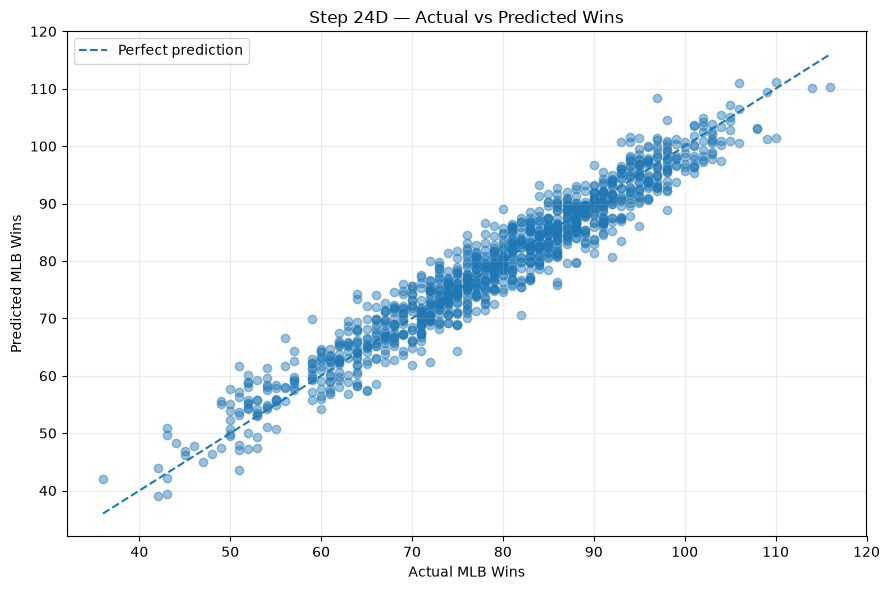

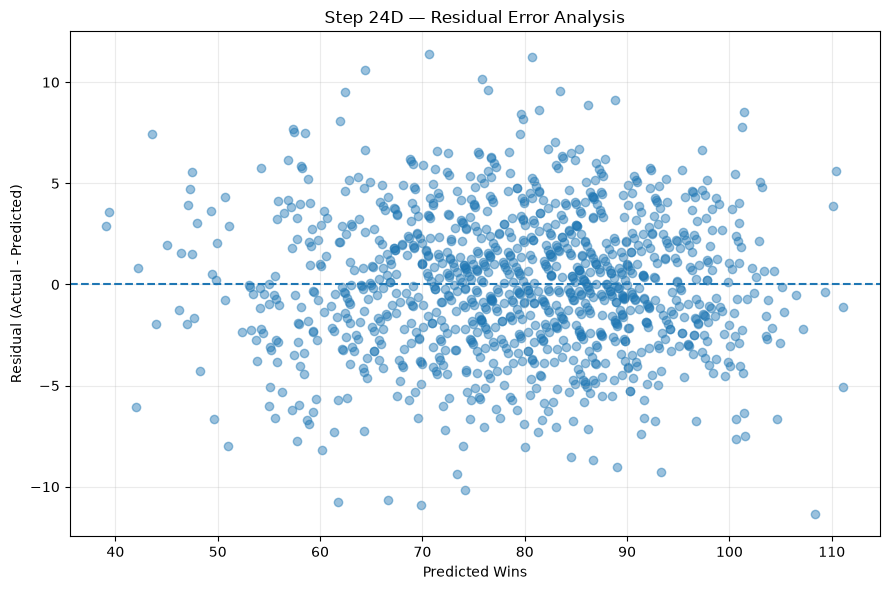

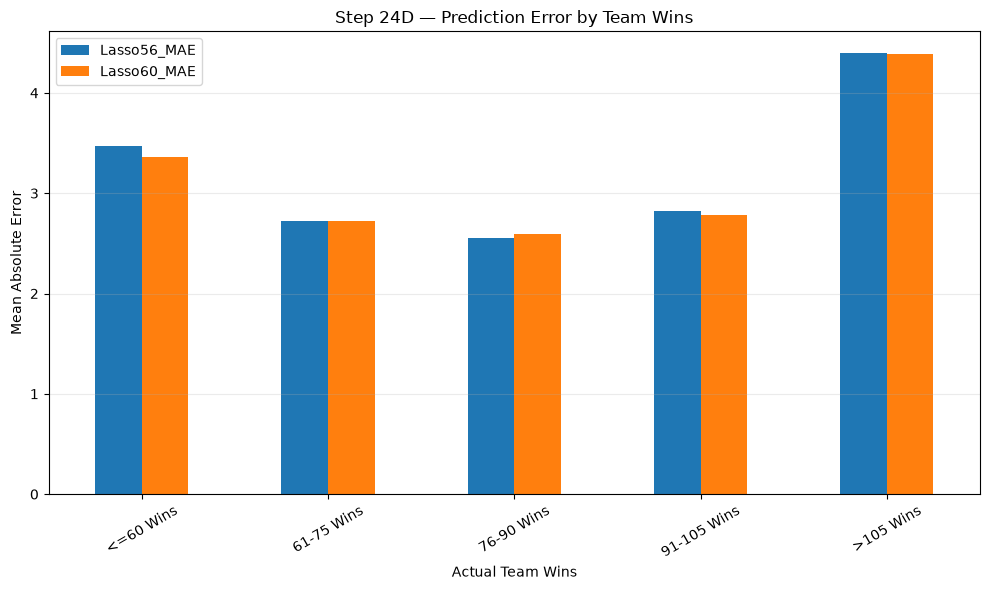

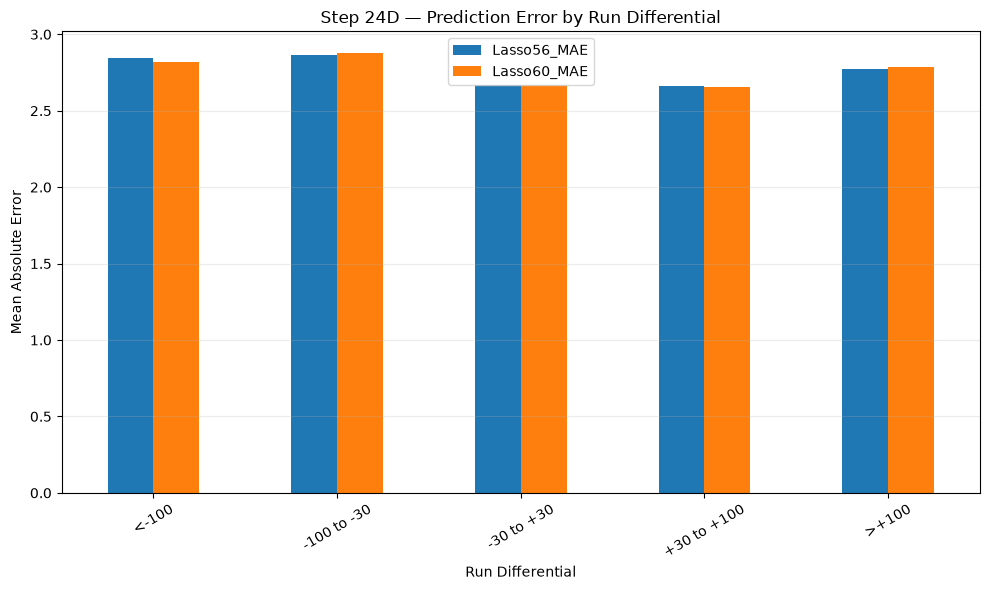


STEP 24D — FINAL SUMMARY
Lasso 56 OOF MAE: 2.75835
Lasso 60 OOF MAE: 2.75545
OOF MAE improvement: 0.0029

Previous Step 24C repeated CV MAE:
Lasso 56: 2.73578
Lasso 60: 2.73036

Note: OOF MAE here uses one 5-fold split, not the 15 evaluations in Step 24C.

Step 24D completed.


In [78]:
# ============================================================
# STEP 24D — MLB RESIDUAL ERROR ANALYSIS
#
# Compare:
# A. Lasso 56 (alpha=0.01)
# B. Lasso 60 (alpha=0.0075)
#
# Method:
# 5-Fold Out-of-Fold (OOF) Predictions
#
# Analyse:
# 1. Strong vs Weak Teams
# 2. Run Differential
# 3. Historical Decades
# 4. Largest Prediction Errors
# 5. Where Lasso 60 Improves on Lasso 56
#
# No held-out test data used.
# No previous models modified.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import (
    KFold,
    cross_val_predict
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — PREPARE TRAINING DATA
# ------------------------------------------------------------

X56 = X_base_24a.copy()

X60 = X_enhanced_24a[
    X_base_24a.columns.tolist() + run_features
].copy()

y = y_24a.copy()

assert X56.shape == (1129, 56)
assert X60.shape == (1129, 60)
assert len(y) == 1129

assert X56.index.equals(X60.index)

actual = np.asarray(y, dtype=float)

print("=" * 60)
print("STEP 24D — DATASET VERIFICATION")
print("=" * 60)

print("Lasso 56:", X56.shape)
print("Lasso 60:", X60.shape)
print("Target:", len(actual))

# ------------------------------------------------------------
# STEP 2 — CREATE MODELS
# ------------------------------------------------------------

lasso56_24d = create_lasso_24a(X56)

lasso56_24d.set_params(
    lasso__alpha=0.01
)

lasso60_24d = create_lasso_24a(X60)

lasso60_24d.set_params(
    lasso__alpha=0.0075
)

# ------------------------------------------------------------
# STEP 3 — DEFINE IDENTICAL CV FOLDS
# ------------------------------------------------------------

cv_24d = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

splits_24d = list(cv_24d.split(X56, y))

# ------------------------------------------------------------
# STEP 4 — OUT-OF-FOLD PREDICTIONS
#
# Every observation is predicted only by a model
# that did NOT train on that observation.
# ------------------------------------------------------------

pred56 = cross_val_predict(
    lasso56_24d,
    X56,
    y,
    cv=splits_24d,
    n_jobs=1
)

pred60 = cross_val_predict(
    lasso60_24d,
    X60,
    y,
    cv=splits_24d,
    n_jobs=1
)

print("\nOUT-OF-FOLD PREDICTIONS")
print("=======================")

print("Lasso 56 predictions:", len(pred56))
print("Lasso 60 predictions:", len(pred60))

# ------------------------------------------------------------
# STEP 5 — CREATE RESIDUAL DATAFRAME
#
# Residual = Actual - Predicted
#
# Positive residual:
# Model UNDERPREDICTED team wins.
#
# Negative residual:
# Model OVERPREDICTED team wins.
# ------------------------------------------------------------

residual_df_24d = pd.DataFrame({

    "Original_Index": X56.index,

    "Actual_Wins": actual,

    "Lasso56_Predicted": pred56,

    "Lasso60_Predicted": pred60,

    "Runs": X56["R"].to_numpy(),

    "Runs_Allowed": X56["RA"].to_numpy(),

    "Games": X56["G"].to_numpy()

})

residual_df_24d["Residual_56"] = (
    residual_df_24d["Actual_Wins"]
    - residual_df_24d["Lasso56_Predicted"]
)

residual_df_24d["Residual_60"] = (
    residual_df_24d["Actual_Wins"]
    - residual_df_24d["Lasso60_Predicted"]
)

residual_df_24d["Absolute_Error_56"] = (
    residual_df_24d["Residual_56"].abs()
)

residual_df_24d["Absolute_Error_60"] = (
    residual_df_24d["Residual_60"].abs()
)

residual_df_24d["Run_Differential"] = (
    residual_df_24d["Runs"]
    - residual_df_24d["Runs_Allowed"]
)

# Positive = Lasso 60 improved on Lasso 56

residual_df_24d["Improvement_60_vs_56"] = (
    residual_df_24d["Absolute_Error_56"]
    - residual_df_24d["Absolute_Error_60"]
)

# ------------------------------------------------------------
# STEP 6 — OVERALL OOF METRICS
# ------------------------------------------------------------

def evaluate_24d(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(
            y_true, y_pred
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_true, y_pred
            )
        ),

        "R2": r2_score(
            y_true, y_pred
        )
    }


metrics56 = evaluate_24d(actual, pred56)

metrics60 = evaluate_24d(actual, pred60)

overall_24d = pd.DataFrame([

    {
        "Model": "Lasso 56",
        **metrics56
    },

    {
        "Model": "Lasso 60",
        **metrics60
    }

])

print("\n" + "=" * 65)
print("STEP 24D — OVERALL OOF PERFORMANCE")
print("=" * 65)

print(
    overall_24d.round(5).to_string(index=False)
)

# ------------------------------------------------------------
# STEP 7 — STRONG VS WEAK TEAMS
# ------------------------------------------------------------

residual_df_24d["Win_Group"] = pd.cut(

    residual_df_24d["Actual_Wins"],

    bins=[
        -np.inf,
        60,
        75,
        90,
        105,
        np.inf
    ],

    labels=[
        "<=60 Wins",
        "61-75 Wins",
        "76-90 Wins",
        "91-105 Wins",
        ">105 Wins"
    ]
)

wins_analysis_24d = (

    residual_df_24d

    .groupby(
        "Win_Group",
        observed=True
    )

    .agg(

        Teams=(
            "Actual_Wins",
            "count"
        ),

        Lasso56_MAE=(
            "Absolute_Error_56",
            "mean"
        ),

        Lasso60_MAE=(
            "Absolute_Error_60",
            "mean"
        ),

        Mean_Residual_60=(
            "Residual_60",
            "mean"
        )

    )

    .reset_index()

)

print("\n" + "=" * 70)
print("STEP 24D — STRONG VS WEAK TEAMS")
print("=" * 70)

print(
    wins_analysis_24d.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# STEP 8 — RUN DIFFERENTIAL ANALYSIS
# ------------------------------------------------------------

residual_df_24d["RunDiff_Group"] = pd.cut(

    residual_df_24d["Run_Differential"],

    bins=[
        -np.inf,
        -100,
        -30,
        30,
        100,
        np.inf
    ],

    labels=[
        "<-100",
        "-100 to -30",
        "-30 to +30",
        "+30 to +100",
        ">+100"
    ]
)

rundiff_analysis_24d = (

    residual_df_24d

    .groupby(
        "RunDiff_Group",
        observed=True
    )

    .agg(

        Teams=(
            "Actual_Wins",
            "count"
        ),

        Lasso56_MAE=(
            "Absolute_Error_56",
            "mean"
        ),

        Lasso60_MAE=(
            "Absolute_Error_60",
            "mean"
        ),

        Mean_Residual_60=(
            "Residual_60",
            "mean"
        )

    )

    .reset_index()

)

print("\n" + "=" * 70)
print("STEP 24D — RUN DIFFERENTIAL ANALYSIS")
print("=" * 70)

print(
    rundiff_analysis_24d.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# STEP 9 — HISTORICAL DECADE ANALYSIS
# ------------------------------------------------------------

decade_cols = [
    col for col in X56.columns
    if col.startswith("decade_")
]

if len(decade_cols) > 0:

    decade_flags = (
        X56[decade_cols]
        .to_numpy(dtype=float)
    )

    has_decade = (
        decade_flags > 0
    ).any(axis=1)

    decade_position = (
        decade_flags.argmax(axis=1)
    )

    decade_values = np.array(
        decade_cols,
        dtype=object
    )[decade_position]

    decade_values = np.where(
        has_decade,
        decade_values,
        "Other/Unknown"
    )

    residual_df_24d["Decade"] = (
        decade_values
    )

    decade_analysis_24d = (

        residual_df_24d

        .groupby("Decade")

        .agg(

            Teams=(
                "Actual_Wins",
                "count"
            ),

            Lasso56_MAE=(
                "Absolute_Error_56",
                "mean"
            ),

            Lasso60_MAE=(
                "Absolute_Error_60",
                "mean"
            )

        )

        .reset_index()

        .sort_values("Decade")

    )

    print("\n" + "=" * 70)
    print("STEP 24D — HISTORICAL DECADE ANALYSIS")
    print("=" * 70)

    print(
        decade_analysis_24d.round(4).to_string(index=False)
    )

else:

    print("\nNo decade indicator columns found.")

# ------------------------------------------------------------
# STEP 10 — LARGEST PREDICTION ERRORS
# ------------------------------------------------------------

largest_errors_24d = (

    residual_df_24d

    .sort_values(
        "Absolute_Error_60",
        ascending=False
    )

    .head(15)

)

print("\n" + "=" * 95)
print("STEP 24D — TOP 15 LARGEST PREDICTION ERRORS")
print("=" * 95)

print(

    largest_errors_24d[

        [
            "Original_Index",
            "Actual_Wins",
            "Lasso60_Predicted",
            "Residual_60",
            "Absolute_Error_60",
            "Run_Differential"
        ]

    ].round(3).to_string(index=False)

)

# ------------------------------------------------------------
# STEP 11 — WHERE DID LASSO 60 IMPROVE?
# ------------------------------------------------------------

better_count = int(
    (
        residual_df_24d["Improvement_60_vs_56"] > 0
    ).sum()
)

worse_count = int(
    (
        residual_df_24d["Improvement_60_vs_56"] < 0
    ).sum()
)

tie_count = len(residual_df_24d) - (
    better_count + worse_count
)

print("\n" + "=" * 65)
print("STEP 24D — LASSO 60 VS LASSO 56")
print("=" * 65)

print("Observations improved:", better_count)
print("Observations worsened:", worse_count)
print("Ties:", tie_count)

print(
    "Average absolute-error improvement:",
    round(
        residual_df_24d[
            "Improvement_60_vs_56"
        ].mean(),
        5
    )
)

# ------------------------------------------------------------
# STEP 12 — VISUALIZATION 1
# ACTUAL VS PREDICTED WINS
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    residual_df_24d["Actual_Wins"],
    residual_df_24d["Lasso60_Predicted"],
    alpha=0.45
)

min_value = min(
    actual.min(),
    pred60.min()
)

max_value = max(
    actual.max(),
    pred60.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual MLB Wins")
plt.ylabel("Predicted MLB Wins")

plt.title(
    "Step 24D — Actual vs Predicted Wins"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 13 — VISUALIZATION 2
# RESIDUAL VS PREDICTED WINS
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    residual_df_24d["Lasso60_Predicted"],
    residual_df_24d["Residual_60"],
    alpha=0.45
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Wins")
plt.ylabel("Residual (Actual - Predicted)")

plt.title(
    "Step 24D — Residual Error Analysis"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 14 — VISUALIZATION 3
# MAE BY TEAM WIN GROUP
# ------------------------------------------------------------

plot_wins = wins_analysis_24d.set_index(
    "Win_Group"
)

plot_wins[
    ["Lasso56_MAE", "Lasso60_MAE"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Step 24D — Prediction Error by Team Wins"
)

plt.xlabel("Actual Team Wins")
plt.ylabel("Mean Absolute Error")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 15 — VISUALIZATION 4
# MAE BY RUN DIFFERENTIAL
# ------------------------------------------------------------

plot_run = rundiff_analysis_24d.set_index(
    "RunDiff_Group"
)

plot_run[
    ["Lasso56_MAE", "Lasso60_MAE"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Step 24D — Prediction Error by Run Differential"
)

plt.xlabel("Run Differential")
plt.ylabel("Mean Absolute Error")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 16 — FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 24D — FINAL SUMMARY")
print("=" * 70)

print(
    "Lasso 56 OOF MAE:",
    round(metrics56["MAE"], 5)
)

print(
    "Lasso 60 OOF MAE:",
    round(metrics60["MAE"], 5)
)

print(
    "OOF MAE improvement:",
    round(
        metrics56["MAE"] -
        metrics60["MAE"],
        5
    )
)

print("\nPrevious Step 24C repeated CV MAE:")
print("Lasso 56: 2.73578")
print("Lasso 60: 2.73036")

print(
    "\nNote: OOF MAE here uses one 5-fold split,"
    " not the 15 evaluations in Step 24C."
)

print("\nStep 24D completed.")

In [79]:
# ============================================================
# STEP 24E — MLB CALIBRATION DIAGNOSTICS
#
# Investigate whether Lasso 60 systematically
# underpredicts or overpredicts team wins.
#
# Uses Step 24D out-of-fold predictions.
# No retraining. No test dataset used.
# ============================================================

import pandas as pd
import numpy as np

df_24e = residual_df_24d.copy()

# ------------------------------------------------------------
# 1 — Group teams by PREDICTED wins (not actual wins)
# ------------------------------------------------------------

df_24e["Predicted_Win_Group"] = pd.qcut(
    df_24e["Lasso60_Predicted"],
    q=5,
    duplicates="drop"
)

calibration_24e = (
    df_24e
    .groupby("Predicted_Win_Group", observed=True)
    .agg(
        Teams=("Actual_Wins", "count"),
        Mean_Actual=("Actual_Wins", "mean"),
        Mean_Predicted=("Lasso60_Predicted", "mean"),
        Mean_Residual=("Residual_60", "mean"),
        MAE=("Absolute_Error_60", "mean")
    )
    .reset_index()
)

print("=" * 75)
print("STEP 24E — CALIBRATION BY PREDICTED WINS")
print("=" * 75)

print(calibration_24e.round(4).to_string(index=False))


# ------------------------------------------------------------
# 2 — Check whether historical decades show bias
# ------------------------------------------------------------

if "Decade" in df_24e.columns:

    decade_bias_24e = (
        df_24e
        .groupby("Decade")
        .agg(
            Teams=("Actual_Wins", "count"),
            Mean_Residual=("Residual_60", "mean"),
            MAE=("Absolute_Error_60", "mean")
        )
        .reset_index()
    )

    print("\n" + "=" * 75)
    print("STEP 24E — HISTORICAL DECADE CALIBRATION")
    print("=" * 75)

    print(decade_bias_24e.round(4).to_string(index=False))


# ------------------------------------------------------------
# 3 — Overall systematic prediction bias
# ------------------------------------------------------------

overall_bias = df_24e["Residual_60"].mean()

print("\n" + "=" * 75)
print("STEP 24E — OVERALL BIAS")
print("=" * 75)

print("Mean signed error:", round(overall_bias, 5))
print(
    "Mean absolute error:",
    round(df_24e["Absolute_Error_60"].mean(), 5)
)

if overall_bias > 0:
    print("Overall direction: Slight underprediction")
elif overall_bias < 0:
    print("Overall direction: Slight overprediction")
else:
    print("Overall direction: No average signed bias")

print("\nStep 24E completed.")

STEP 24E — CALIBRATION BY PREDICTED WINS
Predicted_Win_Group  Teams  Mean_Actual  Mean_Predicted  Mean_Residual    MAE
   (39.127, 68.339]    226      59.8407         60.0418        -0.2011 2.9515
   (68.339, 76.627]    226      73.0354         72.8568         0.1786 2.8072
   (76.627, 83.751]    225      80.4889         80.2884         0.2004 2.8123
   (83.751, 90.483]    226      87.0841         87.1346        -0.0505 2.5157
  (90.483, 111.112]    226      96.4646         96.5763        -0.1117 2.6907

STEP 24E — HISTORICAL DECADE CALIBRATION
     Decade  Teams  Mean_Residual    MAE
decade_1910    110        -0.0924 3.5843
decade_1920     82        -0.0473 2.7382
decade_1930     70         0.0565 3.2780
decade_1940     73         0.1287 3.2756
decade_1950     82         0.1484 2.8035
decade_1960     97        -0.0276 2.6690
decade_1970    134         0.0676 2.9188
decade_1980    115        -0.0260 2.4974
decade_1990    113        -0.1143 2.3096
decade_2000    153         0.0229 2.325

In [80]:
# ============================================================
# STEP 24F — MLB TOTAL WINS VS WINNING PERCENTAGE
#
# Moneyball — Lasso Regression
#
# Model A: Predict Total Wins (W)
# Model B: Predict Winning Percentage (W/G)
#
# Features: 60
# Repeated CV: 5 folds x 3 repeats
#
# Evaluation: MAE, RMSE, R2 — all measured in WINS
#
# TARGET: CV MAE <= 2.6900
#
# No test data used.
# No previous models modified.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ------------------------------------------------------------
# STEP 1 — PREPARE EXISTING LASSO 60 DATASET
# ------------------------------------------------------------

X_24f = X_enhanced_24a[
    X_base_24a.columns.tolist() + run_features
].copy()

y_24f = y_24a.copy()

games_24f = X_24f["G"].to_numpy(dtype=float)

assert X_24f.shape == (1129, 60)
assert len(y_24f) == 1129
assert X_24f.index.equals(y_24f.index)
assert np.isfinite(games_24f).all()
assert (games_24f > 0).all()

print("DATASET VERIFICATION")
print("====================")
print("Training records:", len(X_24f))
print("Features:", X_24f.shape[1])
print("Target: MLB Team Wins")
print("Average games:", round(games_24f.mean(), 2))


# ------------------------------------------------------------
# STEP 2 — CREATE REPEATED CV SPLITS
# ------------------------------------------------------------

cv_24f = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24f = list(
    cv_24f.split(X_24f, y_24f)
)

print("\nREPEATED CV SETUP")
print("=================")
print("Folds: 5")
print("Repeats: 3")
print("Total evaluations:", len(splits_24f))


# ------------------------------------------------------------
# STEP 3 — PREPARE RESULTS STORAGE
# ------------------------------------------------------------

results_24f = []

fold_mae_24f = {
    "A - Total Wins": [],
    "B - Win Percentage": []
}


# ------------------------------------------------------------
# STEP 4 — TRAIN AND EVALUATE BOTH MODELS
# ------------------------------------------------------------

for fold_number, (train_idx, val_idx) in enumerate(
    splits_24f, start=1
):

    X_tr = X_24f.iloc[train_idx]
    X_val = X_24f.iloc[val_idx]

    y_tr = y_24f.iloc[train_idx]
    y_val = y_24f.iloc[val_idx]

    G_tr = games_24f[train_idx]
    G_val = games_24f[val_idx]

    # ========================================================
    # MODEL A — PREDICT TOTAL WINS
    # ========================================================

    model_a = create_lasso_24a(X_tr)

    model_a.set_params(
        lasso__alpha=0.0075
    )

    model_a.fit(
        X_tr,
        y_tr
    )

    pred_train_a = model_a.predict(X_tr)
    pred_val_a = model_a.predict(X_val)

    # ========================================================
    # MODEL B — PREDICT WINNING PERCENTAGE
    # ========================================================

    # Winning percentage:
    # wins divided by games played

    y_pct_train = (
        y_tr.to_numpy(dtype=float) / G_tr
    )

    # Important:
    # W/G has a much smaller numerical scale than W.
    #
    # Therefore alpha must also be scaled down.
    # The training-fold average G provides an
    # approximate comparable regularization scale.

    alpha_pct = 0.0075 / G_tr.mean()

    model_b = create_lasso_24a(X_tr)

    model_b.set_params(
        lasso__alpha=alpha_pct
    )

    model_b.fit(
        X_tr,
        y_pct_train
    )

    # Predict winning percentage

    pred_pct_train = model_b.predict(X_tr)
    pred_pct_val = model_b.predict(X_val)

    # Convert percentage back to total wins

    pred_train_b = pred_pct_train * G_tr
    pred_val_b = pred_pct_val * G_val

    # No clipping or rounding:
    # compare continuous predictions fairly.

    # ========================================================
    # EVALUATE BOTH MODELS IN TOTAL WINS
    # ========================================================

    predictions = {

        "A - Total Wins": (
            pred_train_a,
            pred_val_a
        ),

        "B - Win Percentage": (
            pred_train_b,
            pred_val_b
        )
    }

    for model_name, (pred_tr, pred_val) in predictions.items():

        train_mae = mean_absolute_error(
            y_tr, pred_tr
        )

        val_mae = mean_absolute_error(
            y_val, pred_val
        )

        val_rmse = np.sqrt(
            mean_squared_error(y_val, pred_val)
        )

        val_r2 = r2_score(
            y_val, pred_val
        )

        results_24f.append({

            "Model": model_name,

            "Repeat": (fold_number - 1) // 5 + 1,

            "Fold": (fold_number - 1) % 5 + 1,

            "Train MAE": train_mae,

            "CV MAE": val_mae,

            "CV RMSE": val_rmse,

            "CV R2": val_r2,

            "MAE Gap": val_mae - train_mae
        })

        fold_mae_24f[model_name].append(val_mae)

    print(
        f"Fold {fold_number:02d} | "
        f"Total Wins MAE: "
        f"{fold_mae_24f['A - Total Wins'][-1]:.4f} | "
        f"Win Percentage MAE: "
        f"{fold_mae_24f['B - Win Percentage'][-1]:.4f}"
    )


# ------------------------------------------------------------
# STEP 5 — OVERALL MODEL COMPARISON
# ------------------------------------------------------------

results_df_24f = pd.DataFrame(results_24f)

comparison_24f = (
    results_df_24f
    .groupby("Model")
    .agg(
        Train_MAE=("Train MAE", "mean"),
        Repeated_CV_MAE=("CV MAE", "mean"),
        CV_MAE_Std=("CV MAE", "std"),
        CV_RMSE=("CV RMSE", "mean"),
        CV_R2=("CV R2", "mean"),
        MAE_Gap=("MAE Gap", "mean")
    )
    .reset_index()
    .sort_values("Repeated_CV_MAE")
)

print("\n" + "=" * 95)
print("STEP 24F — TOTAL WINS VS WIN PERCENTAGE")
print("=" * 95)

print(
    comparison_24f.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 6 — PAIRED FOLD COMPARISON
# ------------------------------------------------------------

mae_a = np.asarray(
    fold_mae_24f["A - Total Wins"]
)

mae_b = np.asarray(
    fold_mae_24f["B - Win Percentage"]
)

# Positive = winning percentage model is better

improvement_24f = mae_a - mae_b

pct_wins = int((improvement_24f > 0).sum())
total_wins = int((improvement_24f < 0).sum())
ties = int((improvement_24f == 0).sum())

print("\nPAIRED FOLD COMPARISON")
print("======================")

print("Total Wins model wins:", total_wins)
print("Win Percentage model wins:", pct_wins)
print("Ties:", ties)

print(
    "Mean improvement (Win Percentage vs Total Wins):",
    round(improvement_24f.mean(), 6)
)

print(
    "Std of paired differences:",
    round(improvement_24f.std(ddof=1), 6)
)


# ------------------------------------------------------------
# STEP 7 — REPEAT-BY-REPEAT RESULTS
# ------------------------------------------------------------

repeat_table_24f = (
    results_df_24f
    .groupby(["Repeat", "Model"])["CV MAE"]
    .mean()
    .unstack()
)

print("\nREPEAT-BY-REPEAT COMPARISON")
print("==========================")

print(
    repeat_table_24f.round(5).to_string()
)


# ------------------------------------------------------------
# STEP 8 — FINAL RESULT AND TARGET CHECK
# ------------------------------------------------------------

best_row_24f = comparison_24f.iloc[0]

best_model_24f = best_row_24f["Model"]
best_mae_24f = float(
    best_row_24f["Repeated_CV_MAE"]
)

print("\n" + "=" * 70)
print("STEP 24F — FINAL RESULT")
print("=" * 70)

print("Best model:", best_model_24f)
print("Best repeated CV MAE:", round(best_mae_24f, 5))

print("\nPrevious Lasso 60 benchmark: 2.73036")
print("Target CV MAE: 2.69000")

if best_mae_24f <= 2.6900:

    print("\nTARGET ACHIEVED IN EXPLORATORY CV!")
    print("Independent confirmation still required.")

else:

    print("\nTarget not yet achieved.")

    print(
        "Remaining gap:",
        round(best_mae_24f - 2.6900, 5)
    )

print("\nStep 24F completed.")

DATASET VERIFICATION
Training records: 1129
Features: 60
Target: MLB Team Wins
Average games: 159.1

REPEATED CV SETUP
Folds: 5
Repeats: 3
Total evaluations: 15
Fold 01 | Total Wins MAE: 2.6864 | Win Percentage MAE: 2.6893
Fold 02 | Total Wins MAE: 2.9994 | Win Percentage MAE: 3.0124
Fold 03 | Total Wins MAE: 2.9291 | Win Percentage MAE: 2.9270
Fold 04 | Total Wins MAE: 2.6526 | Win Percentage MAE: 2.6476
Fold 05 | Total Wins MAE: 2.3986 | Win Percentage MAE: 2.4079
Fold 06 | Total Wins MAE: 2.6287 | Win Percentage MAE: 2.6339
Fold 07 | Total Wins MAE: 2.7419 | Win Percentage MAE: 2.7561
Fold 08 | Total Wins MAE: 2.7426 | Win Percentage MAE: 2.7414
Fold 09 | Total Wins MAE: 2.9312 | Win Percentage MAE: 2.9185
Fold 10 | Total Wins MAE: 2.5463 | Win Percentage MAE: 2.5577
Fold 11 | Total Wins MAE: 2.7926 | Win Percentage MAE: 2.8014
Fold 12 | Total Wins MAE: 3.0277 | Win Percentage MAE: 3.0299
Fold 13 | Total Wins MAE: 2.5706 | Win Percentage MAE: 2.5874
Fold 14 | Total Wins MAE: 2.6303 

In [81]:
# ============================================================
# STEP 24G — HISTORICAL MLB ERA INTERACTIONS
#
# Base: Lasso 60, alpha = 0.0075
#
# A: 60 features — original
# B: 64 features — run / era interactions
# C: 68 features — extended era interactions
#
# Repeated CV: 5 folds x 3 repeats
# Target MAE: <= 2.6900
#
# No test data used.
# No existing models or files modified.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedKFold, cross_validate


# ------------------------------------------------------------
# STEP 1 — RECREATE EXISTING LASSO 60 DATA
# ------------------------------------------------------------

X60_24g = X_enhanced_24a[
    X_base_24a.columns.tolist() + run_features
].copy()

y_24g = y_24a.copy()

assert X60_24g.shape == (1129, 60)
assert len(y_24g) == 1129
assert X60_24g.index.equals(y_24g.index)

print("DATASET VERIFICATION")
print("====================")
print("Training records:", len(X60_24g))
print("Original features:", X60_24g.shape[1])


# ------------------------------------------------------------
# STEP 2 — DEFINE HISTORICAL MLB GROUPS
# ------------------------------------------------------------

early_decades = [
    "decade_1910",
    "decade_1920",
    "decade_1930",
    "decade_1940"
]

middle_decades = [
    "decade_1950",
    "decade_1960",
    "decade_1970"
]

modern_decades = [
    "decade_1980",
    "decade_1990",
    "decade_2000",
    "decade_2010"
]

all_decades = (
    early_decades
    + middle_decades
    + modern_decades
)

missing = [
    col for col in all_decades
    if col not in X60_24g.columns
]

assert not missing, f"Missing decade columns: {missing}"


# ------------------------------------------------------------
# STEP 3 — CREATE PERIOD FLAGS
#
# Modern MLB is the reference group.
# These temporary flags are used for interaction
# engineering and are not additional model inputs.
# ------------------------------------------------------------

early_flag = (
    X60_24g[early_decades]
    .astype(float)
    .sum(axis=1)
    .gt(0)
    .astype(int)
)

middle_flag = (
    X60_24g[middle_decades]
    .astype(float)
    .sum(axis=1)
    .gt(0)
    .astype(int)
)

modern_flag = (
    X60_24g[modern_decades]
    .astype(float)
    .sum(axis=1)
    .gt(0)
    .astype(int)
)

assert (
    early_flag + middle_flag + modern_flag
).eq(1).all(), (
    "Each observation must belong to exactly "
    "one historical group."
)

print("\nHISTORICAL PERIOD COUNTS")
print("========================")
print("Early MLB:", int(early_flag.sum()))
print("Middle MLB:", int(middle_flag.sum()))
print("Modern MLB:", int(modern_flag.sum()))


# ------------------------------------------------------------
# STEP 4 — CREATE MLB INTERACTION FEATURES
# ------------------------------------------------------------

X_era_24g = X60_24g.copy()

# Existing baseball statistics

run_margin = X60_24g[
    "Run_Diff_Per_Game"
].astype(float)

expected_win_rate = (
    X60_24g["Pythagenpat_Expected_Wins"]
    / X60_24g["G"]
) - 0.5

era = X60_24g["ERA"].astype(float)

walk_rate = X60_24g[
    "BB_Rate_Proxy"
].astype(float)


# ------------------------------------------------------------
# GROUP 1 — RUN PERFORMANCE INTERACTIONS
# ------------------------------------------------------------

X_era_24g["Early_x_RunMargin"] = (
    early_flag * run_margin
)

X_era_24g["Middle_x_RunMargin"] = (
    middle_flag * run_margin
)

X_era_24g["Early_x_PythagenpatRate"] = (
    early_flag * expected_win_rate
)

X_era_24g["Middle_x_PythagenpatRate"] = (
    middle_flag * expected_win_rate
)


# ------------------------------------------------------------
# GROUP 2 — PITCHING AND BATTING INTERACTIONS
# ------------------------------------------------------------

X_era_24g["Early_x_ERA"] = (
    early_flag * era
)

X_era_24g["Middle_x_ERA"] = (
    middle_flag * era
)

X_era_24g["Early_x_WalkRate"] = (
    early_flag * walk_rate
)

X_era_24g["Middle_x_WalkRate"] = (
    middle_flag * walk_rate
)


# ------------------------------------------------------------
# STEP 5 — DEFINE FEATURE GROUPS
# ------------------------------------------------------------

run_era_features = [
    "Early_x_RunMargin",
    "Middle_x_RunMargin",
    "Early_x_PythagenpatRate",
    "Middle_x_PythagenpatRate"
]

pitch_bat_era_features = [
    "Early_x_ERA",
    "Middle_x_ERA",
    "Early_x_WalkRate",
    "Middle_x_WalkRate"
]

all_era_features = (
    run_era_features
    + pitch_bat_era_features
)

assert X_era_24g.shape == (1129, 68)

assert np.isfinite(
    X_era_24g.to_numpy(dtype=float)
).all()

print("\nFEATURE ENGINEERING")
print("===================")
print("Original features: 60")
print("Era interactions:", len(all_era_features))
print("Total features:", X_era_24g.shape[1])


# ------------------------------------------------------------
# STEP 6 — DEFINE THREE EXPERIMENTS
# ------------------------------------------------------------

base_features = X60_24g.columns.tolist()

datasets_24g = {

    "A - Lasso 60 Baseline":
        X_era_24g[base_features].copy(),

    "B - Lasso 64 Run Era":
        X_era_24g[
            base_features + run_era_features
        ].copy(),

    "C - Lasso 68 All Era":
        X_era_24g[
            base_features + all_era_features
        ].copy()
}


# ------------------------------------------------------------
# STEP 7 — REPEATED CROSS-VALIDATION
# ------------------------------------------------------------

cv_24g = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24g = list(
    cv_24g.split(X60_24g, y_24g)
)

results_24g = []
fold_mae_24g = {}

print("\nREPEATED CV")
print("===========")
print("Folds:", 5)
print("Repeats:", 3)
print("Evaluations:", len(splits_24g))


# ------------------------------------------------------------
# STEP 8 — EVALUATE EACH CONFIGURATION
# ------------------------------------------------------------

for model_name, X in datasets_24g.items():

    model = create_lasso_24a(X)

    model.set_params(
        lasso__alpha=0.0075
    )

    scores = cross_validate(
        model,
        X,
        y_24g,
        cv=splits_24g,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=1
    )

    train_mae = -scores["train_MAE"]
    val_mae = -scores["test_MAE"]
    val_rmse = -scores["test_RMSE"]
    val_r2 = scores["test_R2"]

    fold_mae_24g[model_name] = val_mae.copy()

    results_24g.append({
        "Model": model_name,
        "Features": X.shape[1],
        "Alpha": 0.0075,
        "CV Train MAE": train_mae.mean(),
        "Repeated CV MAE": val_mae.mean(),
        "CV MAE Std": val_mae.std(ddof=1),
        "CV RMSE": val_rmse.mean(),
        "CV R2": val_r2.mean(),
        "CV MAE Gap": (
            val_mae.mean() - train_mae.mean()
        )
    })

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    print("Features:", X.shape[1])
    print("Fold MAEs:", np.round(val_mae, 4))
    print("Train MAE:", round(train_mae.mean(), 5))
    print("Repeated CV MAE:", round(val_mae.mean(), 5))
    print("CV RMSE:", round(val_rmse.mean(), 5))
    print("CV R2:", round(val_r2.mean(), 5))
    print(
        "Generalization Gap:",
        round(
            val_mae.mean() - train_mae.mean(),
            5
        )
    )


# ------------------------------------------------------------
# STEP 9 — OVERALL RESULTS
# ------------------------------------------------------------

comparison_24g = pd.DataFrame(
    results_24g
).sort_values(
    "Repeated CV MAE"
).reset_index(drop=True)

print("\n" + "=" * 100)
print("STEP 24G — HISTORICAL MLB ERA COMPARISON")
print("=" * 100)

print(
    comparison_24g.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 10 — PAIRED COMPARISON AGAINST LASSO 60
# ------------------------------------------------------------

baseline_name = "A - Lasso 60 Baseline"

baseline_mae = fold_mae_24g[baseline_name]

paired_results_24g = []

for name, fold_scores in fold_mae_24g.items():

    if name == baseline_name:
        continue

    # Positive = new model improves over Lasso 60

    improvement = baseline_mae - fold_scores

    paired_results_24g.append({
        "Model": name,
        "Mean Improvement": improvement.mean(),
        "Fold Wins": int((improvement > 0).sum()),
        "Fold Losses": int((improvement < 0).sum()),
        "Difference Std": improvement.std(ddof=1)
    })

paired_24g = pd.DataFrame(paired_results_24g)

print("\n" + "=" * 85)
print("STEP 24G — PAIRED COMPARISON VS LASSO 60")
print("=" * 85)

print(
    paired_24g.round(6).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 11 — REPEAT-BY-REPEAT STABILITY
# ------------------------------------------------------------

repeat_rows_24g = []

for name, fold_scores in fold_mae_24g.items():

    for repeat in range(3):

        start = repeat * 5
        end = start + 5

        repeat_rows_24g.append({
            "Model": name,
            "Repeat": repeat + 1,
            "Mean MAE": fold_scores[start:end].mean()
        })

repeat_table_24g = pd.DataFrame(
    repeat_rows_24g
)

repeat_pivot_24g = repeat_table_24g.pivot(
    index="Repeat",
    columns="Model",
    values="Mean MAE"
)

print("\nREPEAT-BY-REPEAT COMPARISON")
print("==========================")

print(
    repeat_pivot_24g.round(5).to_string()
)


# ------------------------------------------------------------
# STEP 12 — FINAL TARGET CHECK
# ------------------------------------------------------------

best_24g = comparison_24g.iloc[0]

best_mae_24g = float(
    best_24g["Repeated CV MAE"]
)

print("\n" + "=" * 70)
print("STEP 24G — FINAL RESULT")
print("=" * 70)

print("Best configuration:", best_24g["Model"])
print("Best repeated CV MAE:", round(best_mae_24g, 5))
print("Previous Lasso 60 benchmark: 2.73036")
print("Target CV MAE: 2.69000")

if best_mae_24g <= 2.6900:

    print("\nTarget reached in exploratory repeated CV.")
    print("Independent validation is still required.")

else:

    print("\nTarget not achieved.")
    print(
        "Remaining gap:",
        round(best_mae_24g - 2.6900, 5)
    )

print("\nStep 24G completed.")

DATASET VERIFICATION
Training records: 1129
Original features: 60

HISTORICAL PERIOD COUNTS
Early MLB: 335
Middle MLB: 313
Modern MLB: 481

FEATURE ENGINEERING
Original features: 60
Era interactions: 8
Total features: 68

REPEATED CV
Folds: 5
Repeats: 3
Evaluations: 15

A - Lasso 60 Baseline
Features: 60
Fold MAEs: [2.6864 2.9994 2.9291 2.6526 2.3986 2.6287 2.7419 2.7426 2.9312 2.5463
 2.7926 3.0277 2.5706 2.6303 2.6774]
Train MAE: 2.61468
Repeated CV MAE: 2.73036
CV RMSE: 3.4347
CV R2: 0.93375
Generalization Gap: 0.11569

B - Lasso 64 Run Era
Features: 64
Fold MAEs: [2.6761 2.995  2.9153 2.6469 2.4153 2.6535 2.7306 2.7331 2.9213 2.5432
 2.7868 3.0199 2.5799 2.6135 2.6806]
Train MAE: 2.61206
Repeated CV MAE: 2.7274
CV RMSE: 3.42642
CV R2: 0.93407
Generalization Gap: 0.11534

C - Lasso 68 All Era
Features: 68
Fold MAEs: [2.6764 2.9873 2.9121 2.6436 2.4171 2.6587 2.728  2.7317 2.914  2.5461
 2.7805 3.0173 2.5735 2.6168 2.6814]
Train MAE: 2.60836
Repeated CV MAE: 2.72562
CV RMSE: 3.4253
C

In [82]:
# ============================================================
# STEP 24H — HISTORICAL ERA ERROR ANALYSIS
# AND CHRONOLOGICAL VALIDATION
#
# MONEYBALL PROJECT
#
# Model A: Lasso 60, alpha = 0.0075
# Model B: Lasso 68, alpha = 0.0075
#
# PART A: 5-fold OOF error analysis by decade
# PART B: Train on past decades, validate future decades
#
# No held-out test data used.
# No existing models modified.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — PREPARE EXISTING DATASETS
# ------------------------------------------------------------

X60_24h = datasets_24g["A - Lasso 60 Baseline"].copy()
X68_24h = datasets_24g["C - Lasso 68 All Era"].copy()

y_24h = y_24g.copy()

assert X60_24h.shape == (1129, 60)
assert X68_24h.shape == (1129, 68)

assert X60_24h.index.equals(X68_24h.index)
assert X60_24h.index.equals(y_24h.index)

print("=" * 65)
print("STEP 24H — DATASET VERIFICATION")
print("=" * 65)

print("Lasso 60:", X60_24h.shape)
print("Lasso 68:", X68_24h.shape)
print("Target:", len(y_24h))


# ------------------------------------------------------------
# STEP 2 — IDENTIFY HISTORICAL DECADES
# ------------------------------------------------------------

decade_years = list(range(1910, 2020, 10))

decade_columns = [
    f"decade_{year}"
    for year in decade_years
]

assert all(
    col in X60_24h.columns
    for col in decade_columns
)

flags = X60_24h[
    decade_columns
].to_numpy(dtype=float)

# Every observation should belong to exactly one decade.

assert np.all(flags.sum(axis=1) == 1), (
    "Unexpected decade indicators."
)

decades_24h = np.array(
    decade_years
)[flags.argmax(axis=1)]

print("\nDECADE DISTRIBUTION")
print("===================")

print(
    pd.Series(decades_24h)
    .value_counts()
    .sort_index()
    .to_string()
)


# ------------------------------------------------------------
# STEP 3 — CREATE LASSO MODELS
# ------------------------------------------------------------

def make_model_24h(X):

    model = create_lasso_24a(X)

    model.set_params(
        lasso__alpha=0.0075
    )

    return model


# ============================================================
# PART A — OUT-OF-FOLD ERROR ANALYSIS
# ============================================================

# ------------------------------------------------------------
# STEP 4 — 5-FOLD OOF PREDICTIONS
# ------------------------------------------------------------

cv_24h = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pred60_24h = cross_val_predict(
    make_model_24h(X60_24h),
    X60_24h,
    y_24h,
    cv=cv_24h,
    n_jobs=1
)

pred68_24h = cross_val_predict(
    make_model_24h(X68_24h),
    X68_24h,
    y_24h,
    cv=cv_24h,
    n_jobs=1
)


# ------------------------------------------------------------
# STEP 5 — BUILD RESIDUAL DATAFRAME
# ------------------------------------------------------------

actual_24h = y_24h.to_numpy(dtype=float)

errors_24h = pd.DataFrame({
    "Decade": decades_24h,
    "Actual_Wins": actual_24h,
    "Predicted_60": pred60_24h,
    "Predicted_68": pred68_24h
})

errors_24h["Residual_60"] = (
    errors_24h["Actual_Wins"]
    - errors_24h["Predicted_60"]
)

errors_24h["Residual_68"] = (
    errors_24h["Actual_Wins"]
    - errors_24h["Predicted_68"]
)

errors_24h["AE_60"] = (
    errors_24h["Residual_60"].abs()
)

errors_24h["AE_68"] = (
    errors_24h["Residual_68"].abs()
)

# Positive means Lasso 68 performs better.

errors_24h["Improvement"] = (
    errors_24h["AE_60"]
    - errors_24h["AE_68"]
)


# ------------------------------------------------------------
# STEP 6 — ERROR BY HISTORICAL DECADE
# ------------------------------------------------------------

decade_results_24h = (
    errors_24h
    .groupby("Decade")
    .agg(
        Teams=("Actual_Wins", "count"),
        Lasso60_MAE=("AE_60", "mean"),
        Lasso68_MAE=("AE_68", "mean"),
        Improvement=("Improvement", "mean"),
        Mean_Residual_68=("Residual_68", "mean"),
        Lasso68_Better_Teams=(
            "Improvement",
            lambda s: int((s > 0).sum())
        )
    )
    .reset_index()
)

print("\n" + "=" * 100)
print("STEP 24H — HISTORICAL DECADE ERROR COMPARISON")
print("=" * 100)

print(
    decade_results_24h.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 7 — OVERALL OOF RESULTS
# ------------------------------------------------------------

def calculate_metrics_24h(actual, predicted):

    return {
        "MAE": mean_absolute_error(actual, predicted),

        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),

        "R2": r2_score(actual, predicted)
    }


oof_summary_24h = pd.DataFrame([
    {
        "Model": "Lasso 60",
        **calculate_metrics_24h(
            actual_24h, pred60_24h
        )
    },
    {
        "Model": "Lasso 68",
        **calculate_metrics_24h(
            actual_24h, pred68_24h
        )
    }
])

print("\n" + "=" * 65)
print("STEP 24H — OVERALL OOF COMPARISON")
print("=" * 65)

print(
    oof_summary_24h.round(5).to_string(index=False)
)


# ============================================================
# PART B — CHRONOLOGICAL VALIDATION
# ============================================================

# ------------------------------------------------------------
# STEP 8 — VALIDATE ON FUTURE DECADES
#
# Train on decades before the validation decade.
#
# 1990s: Train through 1980s
# 2000s: Train through 1990s
# 2010s: Train through 2000s
#
# Both models use identical chronological splits.
# ------------------------------------------------------------

validation_decades = [1990, 2000, 2010]

chronological_results_24h = []
chronological_predictions_24h = []

for validation_decade in validation_decades:

    train_idx = np.flatnonzero(
        decades_24h < validation_decade
    )

    val_idx = np.flatnonzero(
        decades_24h == validation_decade
    )

    assert len(train_idx) > 0
    assert len(val_idx) > 0

    for model_name, X in [
        ("Lasso 60", X60_24h),
        ("Lasso 68", X68_24h)
    ]:

        X_train_fold = X.iloc[train_idx]
        X_val_fold = X.iloc[val_idx]

        y_train_fold = y_24h.iloc[train_idx]
        y_val_fold = y_24h.iloc[val_idx]

        model = make_model_24h(X)

        model.fit(
            X_train_fold,
            y_train_fold
        )

        predictions = model.predict(
            X_val_fold
        )

        metrics = calculate_metrics_24h(
            y_val_fold,
            predictions
        )

        chronological_results_24h.append({
            "Model": model_name,
            "Validation_Decade": validation_decade,
            "Train_Rows": len(train_idx),
            "Validation_Rows": len(val_idx),
            **metrics
        })

        chronological_predictions_24h.append(
            pd.DataFrame({
                "Model": model_name,
                "Validation_Decade": validation_decade,
                "Actual": y_val_fold.to_numpy(),
                "Predicted": predictions
            })
        )


# ------------------------------------------------------------
# STEP 9 — CHRONOLOGICAL RESULTS
# ------------------------------------------------------------

chronological_table_24h = pd.DataFrame(
    chronological_results_24h
)

print("\n" + "=" * 105)
print("STEP 24H — CHRONOLOGICAL VALIDATION COMPARISON")
print("=" * 105)

print(
    chronological_table_24h
    .round(5)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 10 — POOLED CHRONOLOGICAL PERFORMANCE
#
# Combines prediction errors from all 3 future decades.
# Each validation observation contributes once per model.
# ------------------------------------------------------------

chronological_predictions_24h = pd.concat(
    chronological_predictions_24h,
    ignore_index=True
)

pooled_results_24h = []

for model_name, group in (
    chronological_predictions_24h.groupby("Model")
):

    metrics = calculate_metrics_24h(
        group["Actual"],
        group["Predicted"]
    )

    pooled_results_24h.append({
        "Model": model_name,
        "Total_Validation_Rows": len(group),
        **metrics
    })

pooled_table_24h = (
    pd.DataFrame(pooled_results_24h)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("STEP 24H — POOLED FUTURE-DECADE PERFORMANCE")
print("=" * 75)

print(
    pooled_table_24h.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 11 — FINAL COMPARISON
# ------------------------------------------------------------

mae60_future = float(
    pooled_table_24h.loc[
        pooled_table_24h["Model"] == "Lasso 60",
        "MAE"
    ].iloc[0]
)

mae68_future = float(
    pooled_table_24h.loc[
        pooled_table_24h["Model"] == "Lasso 68",
        "MAE"
    ].iloc[0]
)

improvement_future = (
    mae60_future - mae68_future
)

print("\n" + "=" * 70)
print("STEP 24H — FINAL SUMMARY")
print("=" * 70)

print("Lasso 60 Future-Decade MAE:",
      round(mae60_future, 5))

print("Lasso 68 Future-Decade MAE:",
      round(mae68_future, 5))

print("Improvement from Era Features:",
      round(improvement_future, 5))

if improvement_future > 0:
    print("Lasso 68 performed better on future decades.")
elif improvement_future < 0:
    print("Lasso 60 performed better on future decades.")
else:
    print("Both models achieved the same future-decade MAE.")

print("\nPrevious repeated CV results:")
print("Lasso 60: 2.73036")
print("Lasso 68: 2.72562")

print("\nTarget repeated CV MAE: 2.69000")

print(
    "\nChronological validation and repeated random CV "
    "measure different generalization scenarios."
)

print("\nStep 24H completed.")

STEP 24H — DATASET VERIFICATION
Lasso 60: (1129, 60)
Lasso 68: (1129, 68)
Target: 1129

DECADE DISTRIBUTION
1910    110
1920     82
1930     70
1940     73
1950     82
1960     97
1970    134
1980    115
1990    113
2000    153
2010    100

STEP 24H — HISTORICAL DECADE ERROR COMPARISON
 Decade  Teams  Lasso60_MAE  Lasso68_MAE  Improvement  Mean_Residual_68  Lasso68_Better_Teams
   1910    110      3.58434      3.54280      0.04154          -0.08348                    63
   1920     82      2.73823      2.75557     -0.01735          -0.00894                    36
   1930     70      3.27804      3.24391      0.03413           0.05688                    36
   1940     73      3.27560      3.28415     -0.00854           0.15152                    40
   1950     82      2.80354      2.79253      0.01101           0.11069                    40
   1960     97      2.66901      2.70556     -0.03655          -0.04707                    43
   1970    134      2.91878      2.91637      0.00240  

In [83]:
# ============================================================
# STEP 24I — MLB FINAL HOLD-OUT TEST COMPARISON
#
# Compare:
#   Lasso 48 — alpha 0.0100
#   Lasso 56 — alpha 0.0100
#   Lasso 60 — alpha 0.0075
#   Lasso 68 — alpha 0.0075
#
# Training observations: 1129
# Test observations:      283
#
# No tuning on test data.
# No files or old models overwritten.
# No rounding or clipping of predictions.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — VERIFY ORIGINAL HELD-OUT TEST DATA
# ------------------------------------------------------------

assert "X_test" in globals(), (
    "X_test not found. Check the variable name "
    "used for your original 283-row test split."
)

assert "y_test" in globals(), (
    "y_test not found. Check the variable name "
    "used for your original test target."
)

X_holdout_24i = X_test.copy()
y_holdout_24i = np.asarray(
    y_test, dtype=float
).reshape(-1)

assert isinstance(X_holdout_24i, pd.DataFrame)

assert len(X_holdout_24i) == 283, (
    "Expected 283 held-out observations. "
    "Check that X_test is not the Kaggle predict.csv."
)

assert len(y_holdout_24i) == 283

if isinstance(y_test, (pd.Series, pd.DataFrame)):
    assert X_holdout_24i.index.equals(y_test.index), (
        "X_test and y_test indexes do not match."
    )

assert np.isfinite(y_holdout_24i).all()

print("=" * 70)
print("STEP 24I — HELD-OUT DATA VERIFICATION")
print("=" * 70)

print("Test observations:", len(X_holdout_24i))
print("Test target observations:", len(y_holdout_24i))


# ------------------------------------------------------------
# STEP 2 — DEFINE ORIGINAL TRAINING FEATURES
# ------------------------------------------------------------

# Eight features introduced when moving 48 -> 56.

extra_56_features_24i = [
    "Pythagorean_Expected_Wins_183",
    "Run_Diff_Per_Game",
    "Log_Run_Ratio",
    "Batting_Average",
    "Isolated_Power",
    "WHIP_Proxy",
    "BB_Rate_Proxy",
    "Pitching_K_BB_Ratio"
]

columns_48_24i = [
    col for col in X_base_24a.columns
    if col not in extra_56_features_24i
]

assert X_base_24a.shape[1] == 56
assert len(columns_48_24i) == 48

training_sets_24i = {
    "Lasso 48": X_base_24a[
        columns_48_24i
    ].copy(),

    "Lasso 56": X_base_24a.copy(),

    "Lasso 60": datasets_24g[
        "A - Lasso 60 Baseline"
    ].copy(),

    "Lasso 68": datasets_24g[
        "C - Lasso 68 All Era"
    ].copy()
}

alphas_24i = {
    "Lasso 48": 0.0100,
    "Lasso 56": 0.0100,
    "Lasso 60": 0.0075,
    "Lasso 68": 0.0075
}

cv_reference_24i = {
    "Lasso 48": 2.74150,
    "Lasso 56": 2.73578,
    "Lasso 60": 2.73036,
    "Lasso 68": 2.72562
}

y_train_24i = y_24g.copy()

assert len(y_train_24i) == 1129

for model_name, features in training_sets_24i.items():

    assert len(features) == 1129

    assert features.index.equals(y_train_24i.index)

    assert np.isfinite(
        features.to_numpy(dtype=float)
    ).all()

    print(
        model_name,
        "| Training shape:",
        features.shape
    )


# ------------------------------------------------------------
# STEP 3 — RECREATE FEATURE ENGINEERING FOR TEST DATA
#
# All transformations use only information from
# the individual test team's feature columns.
#
# NO ACTUAL WINS USED FOR FEATURE ENGINEERING.
# ------------------------------------------------------------

def engineer_test_features_24i(original):

    df = original.copy()

    required_raw = [
        "G", "R", "RA",
        "AB", "H", "2B", "3B", "HR",
        "BB", "HA", "BBA", "IPouts",
        "SOA", "HRA", "ERA", "E",
        "mlb_rpg"
    ]

    missing_raw = [
        c for c in required_raw
        if c not in df.columns
    ]

    if missing_raw:
        raise ValueError(
            "Missing original test columns: "
            + str(missing_raw)
        )

    G = df["G"].astype(float)
    R = df["R"].astype(float)
    RA = df["RA"].astype(float)

    AB = df["AB"].astype(float)
    H = df["H"].astype(float)

    BB = df["BB"].astype(float)
    B2 = df["2B"].astype(float)
    B3 = df["3B"].astype(float)
    HR = df["HR"].astype(float)

    HA = df["HA"].astype(float)
    BBA = df["BBA"].astype(float)
    SOA = df["SOA"].astype(float)
    IPouts = df["IPouts"].astype(float)

    # Ensure valid denominators
    assert (G > 0).all()
    assert (AB > 0).all()
    assert (IPouts > 0).all()
    assert ((R + RA) > 0).all()

    innings = IPouts / 3.0

    # ========================================================
    # ORIGINAL 48-FEATURE ENGINEERING
    # ========================================================

    df["R_per_game"] = R / G

    df["RA_per_game"] = RA / G

    df["Run_Differential"] = R - RA

    df["Pythagorean_Expected_Wins"] = (
        G * (R ** 2)
        / ((R ** 2) + (RA ** 2))
    )

    # ========================================================
    # LASSO 56 — EIGHT ADDITIONAL FEATURES
    # ========================================================

    df["Pythagorean_Expected_Wins_183"] = (
        G * (R ** 1.83)
        / ((R ** 1.83) + (RA ** 1.83))
    )

    df["Run_Diff_Per_Game"] = (
        R - RA
    ) / G

    df["Log_Run_Ratio"] = np.log(
        (R + 1) / (RA + 1)
    )

    df["Batting_Average"] = H / AB

    df["Isolated_Power"] = (
        B2 + 2 * B3 + 3 * HR
    ) / AB

    df["WHIP_Proxy"] = (
        HA + BBA
    ) / innings

    df["BB_Rate_Proxy"] = (
        BB / (AB + BB)
    )

    df["Pitching_K_BB_Ratio"] = (
        SOA / (BBA + 1)
    )

    # ========================================================
    # LASSO 60 — RUN DYNAMICS
    # ========================================================

    exponent = (
        (R + RA) / G
    ) ** 0.285

    df["Pythagenpat_Expected_Wins"] = (
        G * (R ** exponent)
        / (
            (R ** exponent)
            + (RA ** exponent)
        )
    )

    df["Run_Share_Smoothed"] = (
        (R + 0.5) / (R + RA + 1)
    )

    run_margin = (
        R - RA
    ) / G

    df["Signed_Squared_Run_Margin"] = (
        np.sign(run_margin)
        * run_margin ** 2
    )

    df["RunDiff_over_TotalRuns"] = (
        (R - RA) / (R + RA + 1)
    )

    # ========================================================
    # LASSO 68 — HISTORICAL ERA INTERACTIONS
    # ========================================================

    early_decades = [
        "decade_1910",
        "decade_1920",
        "decade_1930",
        "decade_1940"
    ]

    middle_decades = [
        "decade_1950",
        "decade_1960",
        "decade_1970"
    ]

    modern_decades = [
        "decade_1980",
        "decade_1990",
        "decade_2000",
        "decade_2010"
    ]

    all_decades = (
        early_decades
        + middle_decades
        + modern_decades
    )

    missing_decades = [
        c for c in all_decades
        if c not in df.columns
    ]

    if missing_decades:
        raise ValueError(
            "Missing decade indicators: "
            + str(missing_decades)
        )

    decade_flags = df[
        all_decades
    ].astype(float)

    assert np.allclose(
        decade_flags.sum(axis=1).to_numpy(),
        1.0
    ), "Each team must belong to exactly one decade."

    early_flag = (
        decade_flags[early_decades]
        .sum(axis=1)
        .gt(0)
        .astype(int)
    )

    middle_flag = (
        decade_flags[middle_decades]
        .sum(axis=1)
        .gt(0)
        .astype(int)
    )

    expected_win_rate = (
        df["Pythagenpat_Expected_Wins"] / G
    ) - 0.5

    # Run performance interactions

    df["Early_x_RunMargin"] = (
        early_flag * run_margin
    )

    df["Middle_x_RunMargin"] = (
        middle_flag * run_margin
    )

    df["Early_x_PythagenpatRate"] = (
        early_flag * expected_win_rate
    )

    df["Middle_x_PythagenpatRate"] = (
        middle_flag * expected_win_rate
    )

    # Pitching and batting interactions

    df["Early_x_ERA"] = (
        early_flag * df["ERA"].astype(float)
    )

    df["Middle_x_ERA"] = (
        middle_flag * df["ERA"].astype(float)
    )

    df["Early_x_WalkRate"] = (
        early_flag * df["BB_Rate_Proxy"]
    )

    df["Middle_x_WalkRate"] = (
        middle_flag * df["BB_Rate_Proxy"]
    )

    return df


X_engineered_test_24i = engineer_test_features_24i(
    X_holdout_24i
)

print("\nTEST FEATURE ENGINEERING")
print("========================")
print(
    "Available columns:",
    X_engineered_test_24i.shape[1]
)


# ------------------------------------------------------------
# STEP 4 — TRAIN FOUR LOCKED MODELS
# ------------------------------------------------------------

results_24i = []
predictions_24i = {}

for model_name, X_train_model in training_sets_24i.items():

    feature_columns = X_train_model.columns.tolist()

    missing = [
        c for c in feature_columns
        if c not in X_engineered_test_24i.columns
    ]

    if missing:
        raise ValueError(
            f"{model_name} has missing test features: "
            f"{missing}"
        )

    X_test_model = X_engineered_test_24i[
        feature_columns
    ].copy()

    assert X_test_model.shape[1] == X_train_model.shape[1]

    assert np.isfinite(
        X_test_model.to_numpy(dtype=float)
    ).all(), (
        f"Invalid or missing test values for {model_name}"
    )

    model = create_lasso_24a(
        X_train_model
    )

    model.set_params(
        lasso__alpha=alphas_24i[model_name]
    )

    # Fit ONLY on the 1129 training rows.

    model.fit(
        X_train_model,
        y_train_24i
    )

    pred_train = model.predict(
        X_train_model
    )

    pred_test = model.predict(
        X_test_model
    )

    train_mae = mean_absolute_error(
        y_train_24i,
        pred_train
    )

    test_mae = mean_absolute_error(
        y_holdout_24i,
        pred_test
    )

    test_rmse = np.sqrt(
        mean_squared_error(
            y_holdout_24i,
            pred_test
        )
    )

    test_r2 = r2_score(
        y_holdout_24i,
        pred_test
    )

    predictions_24i[model_name] = pred_test

    results_24i.append({
        "Model": model_name,
        "Features": X_train_model.shape[1],
        "Alpha": alphas_24i[model_name],
        "Repeated_CV_MAE": cv_reference_24i[model_name],
        "Train_MAE": train_mae,
        "Test_MAE": test_mae,
        "Test_RMSE": test_rmse,
        "Test_R2": test_r2,
        "Test_Train_Gap": test_mae - train_mae
    })


# ------------------------------------------------------------
# STEP 5 — FINAL COMPARISON TABLE
# ------------------------------------------------------------

comparison_24i = pd.DataFrame(
    results_24i
).sort_values(
    "Test_MAE"
).reset_index(drop=True)

print("\n" + "=" * 110)
print("STEP 24I — HELD-OUT TEST MODEL COMPARISON")
print("=" * 110)

print(
    comparison_24i.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 6 — CHECK AGAINST PREVIOUS TEST RESULTS
#
# This helps detect changes in feature engineering,
# train/test splits, or pipeline configuration.
# ------------------------------------------------------------

previous_test_mae_24i = {
    "Lasso 48": 2.6904,
    "Lasso 56": 2.6826
}

print("\nPREVIOUS TEST RESULTS — REPRODUCIBILITY CHECK")
print("=============================================")

for model_name, old_mae in previous_test_mae_24i.items():

    current_mae = float(
        comparison_24i.loc[
            comparison_24i["Model"] == model_name,
            "Test_MAE"
        ].iloc[0]
    )

    difference = current_mae - old_mae

    print(
        f"{model_name}: "
        f"Previous={old_mae:.4f}, "
        f"Current={current_mae:.4f}, "
        f"Difference={difference:+.5f}"
    )

    if abs(difference) > 0.02:
        print(
            "  WARNING: Check dataset split, "
            "feature formulas and model settings."
        )


# ------------------------------------------------------------
# STEP 7 — COMPARE ALL FOUR MODELS OBSERVATION BY OBSERVATION
# ------------------------------------------------------------

prediction_comparison_24i = pd.DataFrame({
    "Actual_Wins": y_holdout_24i
})

for name, predictions in predictions_24i.items():

    prediction_comparison_24i[
        name + "_Prediction"
    ] = predictions

    prediction_comparison_24i[
        name + "_Absolute_Error"
    ] = np.abs(
        y_holdout_24i - predictions
    )

print("\nFIRST 10 TEST PREDICTIONS")
print("=========================")

print(
    prediction_comparison_24i
    .head(10)
    .round(3)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 8 — FINAL SUMMARY
# ------------------------------------------------------------

best_24i = comparison_24i.iloc[0]

print("\n" + "=" * 75)
print("STEP 24I — FINAL SUMMARY")
print("=" * 75)

print("Lowest test MAE model:", best_24i["Model"])
print(
    "Lowest test MAE:",
    round(float(best_24i["Test_MAE"]), 5)
)

print("\nExploratory repeated CV leader:")
print("Lasso 68: 2.72562")

print("\nRepeated CV target: 2.69000")

print(
    "\nIMPORTANT: Test MAE and repeated CV MAE "
    "are different evaluation results."
)

print(
    "Do not tune or add features based on "
    "this test-set comparison."
)

print("\nStep 24I completed.")

STEP 24I — HELD-OUT DATA VERIFICATION
Test observations: 283
Test target observations: 283
Lasso 48 | Training shape: (1129, 48)
Lasso 56 | Training shape: (1129, 56)
Lasso 60 | Training shape: (1129, 60)
Lasso 68 | Training shape: (1129, 68)

TEST FEATURE ENGINEERING
Available columns: 68

STEP 24I — HELD-OUT TEST MODEL COMPARISON
   Model  Features  Alpha  Repeated_CV_MAE  Train_MAE  Test_MAE  Test_RMSE  Test_R2  Test_Train_Gap
Lasso 68        68 0.0075          2.72562    2.62429   2.65451    3.25905  0.93353         0.03022
Lasso 60        60 0.0075          2.73036    2.62880   2.67594    3.28985  0.93227         0.04714
Lasso 56        56 0.0100          2.73578    2.64240   2.68262    3.29239  0.93216         0.04021
Lasso 48        48 0.0100          2.74150    2.64851   2.69040    3.30289  0.93173         0.04189

PREVIOUS TEST RESULTS — REPRODUCIBILITY CHECK
Lasso 48: Previous=2.6904, Current=2.6904, Difference=+0.00000
Lasso 56: Previous=2.6826, Current=2.6826, Difference=+0

In [84]:
# ============================================================
# STEP 24J — LASSO 68 FINAL KAGGLE SUBMISSION
#
# Model: Lasso Regression
# Features: 68
# Alpha: 0.0075
#
# Final fitting: All 1412 labeled observations
# Prediction: 400 unlabeled Kaggle observations
#
# Submission format: ID,W
#
# No hyperparameter tuning.
# No Kaggle leaderboard data used for training.
# No existing submission overwritten.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path


# ------------------------------------------------------------
# STEP 1 — VERIFY REQUIRED OBJECTS
# ------------------------------------------------------------

required_objects_24j = [
    "training_sets_24i",
    "X_engineered_test_24i",
    "y_train_24i",
    "y_holdout_24i",
    "create_lasso_24a",
    "engineer_test_features_24i"
]

missing_objects_24j = [
    name for name in required_objects_24j
    if name not in globals()
]

if missing_objects_24j:
    raise NameError(
        "Please run Step 24I first. Missing objects: "
        + str(missing_objects_24j)
    )

print("=" * 70)
print("STEP 24J — FINAL DATASET VERIFICATION")
print("=" * 70)


# ------------------------------------------------------------
# STEP 2 — PREPARE ALL LABELED OBSERVATIONS
# ------------------------------------------------------------

# Original training observations

X_train_24j = (
    training_sets_24i["Lasso 68"]
    .copy()
)

y_train_final_24j = np.asarray(
    y_train_24i, dtype=float
).reshape(-1)

# Previous held-out observations
# These are now included for FINAL Kaggle fitting.

feature_columns_24j = X_train_24j.columns.tolist()

X_holdout_final_24j = (
    X_engineered_test_24i[
        feature_columns_24j
    ].copy()
)

y_holdout_final_24j = np.asarray(
    y_holdout_24i, dtype=float
).reshape(-1)

assert X_train_24j.shape == (1129, 68)
assert X_holdout_final_24j.shape == (283, 68)

assert len(y_train_final_24j) == 1129
assert len(y_holdout_final_24j) == 283


# Combine both labeled datasets

X_full_24j = pd.concat(
    [
        X_train_24j.reset_index(drop=True),
        X_holdout_final_24j.reset_index(drop=True)
    ],
    ignore_index=True
)

y_full_24j = np.concatenate([
    y_train_final_24j,
    y_holdout_final_24j
])

assert X_full_24j.shape == (1412, 68)
assert len(y_full_24j) == 1412

assert np.isfinite(
    X_full_24j.to_numpy(dtype=float)
).all()

assert np.isfinite(y_full_24j).all()

print("Total labeled records:", len(y_full_24j))
print("Total features:", X_full_24j.shape[1])


# ------------------------------------------------------------
# STEP 3 — LOCATE KAGGLE PREDICTION DATASET
# ------------------------------------------------------------

possible_paths_24j = [
    Path("predict.csv"),
    Path("data/predict.csv"),
    Path("Data/predict.csv"),
    Path("datasets/predict.csv"),
    Path("Datasets/predict.csv")
]

predict_path_24j = next(
    (
        path for path in possible_paths_24j
        if path.is_file()
    ),
    None
)

if predict_path_24j is None:
    raise FileNotFoundError(
        "Cannot find predict.csv. "
        f"Current notebook directory: {Path.cwd()}. "
        "Update possible_paths_24j to your actual file path."
    )

kaggle_raw_24j = pd.read_csv(
    predict_path_24j
)

print("\nKAGGLE PREDICTION DATASET")
print("=========================")

print("File:", predict_path_24j)
print("Rows:", len(kaggle_raw_24j))
print("Columns:", len(kaggle_raw_24j.columns))

assert len(kaggle_raw_24j) == 400, (
    "Expected 400 Kaggle prediction rows."
)

assert "ID" in kaggle_raw_24j.columns, (
    "Missing ID column."
)

assert kaggle_raw_24j["ID"].notna().all()
assert kaggle_raw_24j["ID"].is_unique


# ------------------------------------------------------------
# STEP 4 — CREATE THE SAME 68 FEATURES
#
# Reuse the feature-engineering function
# verified in Step 24I.
# ------------------------------------------------------------

kaggle_features_24j = engineer_test_features_24i(
    kaggle_raw_24j.drop(
        columns=["ID", "W"],
        errors="ignore"
    )
)

missing_features_24j = [
    name for name in feature_columns_24j
    if name not in kaggle_features_24j.columns
]

if missing_features_24j:
    raise ValueError(
        "Missing engineered Kaggle features: "
        + str(missing_features_24j)
    )

X_kaggle_24j = (
    kaggle_features_24j[
        feature_columns_24j
    ].copy()
)

assert X_kaggle_24j.shape == (400, 68)

assert np.isfinite(
    X_kaggle_24j.to_numpy(dtype=float)
).all()

print("\nFEATURE VERIFICATION")
print("====================")
print("Final training:", X_full_24j.shape)
print("Kaggle prediction:", X_kaggle_24j.shape)

assert (
    X_full_24j.columns.tolist()
    == X_kaggle_24j.columns.tolist()
)


# ------------------------------------------------------------
# STEP 5 — TRAIN FINAL LASSO 68
# ------------------------------------------------------------

lasso68_final_24j = create_lasso_24a(
    X_full_24j
)

lasso68_final_24j.set_params(
    lasso__alpha=0.0075
)

lasso68_final_24j.fit(
    X_full_24j,
    y_full_24j
)

print("\nFINAL MODEL")
print("===========")

print("Model: Lasso 68")
print("Alpha: 0.0075")
print("Training records:", len(y_full_24j))
print("Features:", X_full_24j.shape[1])
print("Training completed.")


# ------------------------------------------------------------
# STEP 6 — GENERATE KAGGLE PREDICTIONS
# ------------------------------------------------------------

predictions_float_24j = (
    lasso68_final_24j.predict(
        X_kaggle_24j
    )
)

assert np.isfinite(
    predictions_float_24j
).all()

# Convert predicted wins to whole numbers.

predictions_integer_24j = np.rint(
    predictions_float_24j
).astype(int)

# Ensure predicted wins are between
# 0 and the number of games played.

games_24j = pd.to_numeric(
    kaggle_raw_24j["G"],
    errors="raise"
).to_numpy(dtype=float)

assert np.isfinite(games_24j).all()
assert (games_24j > 0).all()

predictions_integer_24j = np.clip(
    predictions_integer_24j,
    0,
    np.floor(games_24j).astype(int)
)


# ------------------------------------------------------------
# STEP 7 — CREATE KAGGLE SUBMISSION
# ------------------------------------------------------------

submission_24j = pd.DataFrame({
    "ID": kaggle_raw_24j["ID"].to_numpy(),
    "W": predictions_integer_24j
})

assert submission_24j.shape == (400, 2)
assert submission_24j.columns.tolist() == ["ID", "W"]
assert submission_24j["ID"].is_unique
assert submission_24j.notna().all().all()

print("\nSUBMISSION PREVIEW")
print("==================")

print(
    submission_24j.head(10).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 8 — SAVE NEW CSV
# Avoid overwriting previous submissions.
# ------------------------------------------------------------

base_name_24j = "submission_lasso68_step24J"

output_path_24j = Path(
    f"{base_name_24j}.csv"
)

version_24j = 2

while output_path_24j.exists():

    output_path_24j = Path(
        f"{base_name_24j}_v{version_24j}.csv"
    )

    version_24j += 1

with output_path_24j.open(
    "x", newline="", encoding="utf-8"
) as file:

    submission_24j.to_csv(
        file, index=False
    )


# ------------------------------------------------------------
# STEP 9 — VERIFY SAVED CSV
# ------------------------------------------------------------

saved_submission_24j = pd.read_csv(
    output_path_24j
)

assert saved_submission_24j.shape == (400, 2)

assert (
    saved_submission_24j.columns.tolist()
    == ["ID", "W"]
)

assert saved_submission_24j["W"].notna().all()

assert np.allclose(
    saved_submission_24j["W"],
    np.rint(saved_submission_24j["W"])
)


# ------------------------------------------------------------
# STEP 10 — FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 24J — KAGGLE SUBMISSION READY")
print("=" * 75)

print("Model: Lasso 68")
print("Alpha: 0.0075")
print("Training records: 1412")
print("Features: 68")
print("Predictions:", len(saved_submission_24j))

print("\nPrediction statistics:")

print(
    saved_submission_24j["W"]
    .describe()
    .round(2)
    .to_string()
)

print("\nSubmission file:")
print(output_path_24j.resolve())

print("\nPrevious Kaggle benchmark:")
print("Lasso 48 public MAE: 2.9100")

print("\nLasso 68 Kaggle MAE:")
print("Unknown until Kaggle evaluates the submission.")

print("\nStep 24J completed.")

STEP 24J — FINAL DATASET VERIFICATION
Total labeled records: 1412
Total features: 68

KAGGLE PREDICTION DATASET
File: predict.csv
Rows: 400
Columns: 47

FEATURE VERIFICATION
Final training: (1412, 68)
Kaggle prediction: (400, 68)

FINAL MODEL
Model: Lasso 68
Alpha: 0.0075
Training records: 1412
Features: 68
Training completed.

SUBMISSION PREVIEW
  ID  W
1649 76
1223 76
 748 83
1735 85
 794 79
1080 64
 721 79
 437 59
 519 62
 182 63

STEP 24J — KAGGLE SUBMISSION READY
Model: Lasso 68
Alpha: 0.0075
Training records: 1412
Features: 68
Predictions: 400

Prediction statistics:
count    400.00
mean      79.46
std       12.33
min       46.00
25%       70.00
50%       80.50
75%       89.00
max      112.00

Submission file:
/home/yoke/MLB/submission_lasso68_step24J_v14.csv

Previous Kaggle benchmark:
Lasso 48 public MAE: 2.9100

Lasso 68 Kaggle MAE:
Unknown until Kaggle evaluates the submission.

Step 24J completed.


# Step 24J — Final Lasso 68 Model Training and Kaggle Submission

## 1. Objective

The objective of Step 24J is to train the selected **68-feature Lasso Regression model** using all available labeled MLB team-season observations and generate predictions for the Kaggle Moneyball competition.

The model was selected based on the exploratory experiments in Steps 24A–24I, which examined baseball feature engineering, regularization, historical-era interactions, cross-validation performance, and generalization.

**Primary performance metric:** Mean Absolute Error (MAE).

**Target:** MAE ≤ 2.6900.

---

## 2. Selected Model Configuration

| Parameter | Configuration |
|---|---|
| Algorithm | Lasso Regression |
| Model | Lasso 68 |
| Number of features | 68 |
| Regularization | L1 Regularization |
| Alpha | 0.0075 |
| Prediction target | Total Team Wins (`W`) |
| Final training observations | 1,412 |
| Kaggle prediction observations | 400 |

Lasso was retained because it demonstrated strong predictive accuracy and generalization in earlier experiments.

L1 regularization penalizes the absolute magnitude of regression coefficients and can shrink less useful coefficients toward zero.

The 68-feature model incorporates conventional baseball statistics, engineered run-performance features, and historical-era interactions.

## 3. Dataset Preparation

The final model was trained using all 1,412 labeled observations.

| Dataset | Observations | Purpose |
|---|---:|---|
| Original training set | 1,129 | Previous model development and cross-validation |
| Previous hold-out test set | 283 | Previous performance evaluation |
| Combined labeled dataset | **1,412** | Final Kaggle model fitting |
| Kaggle `predict.csv` | 400 | Unlabeled prediction dataset |

Following completion of the hold-out evaluation, the 1,129 training observations and 283 hold-out observations were combined to fit the final submission model.

The final 1,412-row model is therefore different from the previously evaluated 1,129-row model, although it uses the same selected features and alpha value.

## 4. Feature Engineering

The final model contains 68 features.

The engineering process incorporates several categories of baseball performance indicators:

- **Run performance:** Runs per game, runs allowed per game, run differential and Pythagorean expected wins.
- **Batting performance:** Batting average, isolated power and walk-rate proxy.
- **Pitching performance:** WHIP proxy and strikeout-to-walk ratio.
- **Run dynamics:** Pythagenpat expected wins, smoothed run share, signed squared run margin and normalized run differential.
- **Historical interactions:** Eight features that allow selected baseball performance relationships to vary across early, middle and modern historical periods.

The historical interaction features were introduced because earlier residual analyses identified larger prediction errors in several historical decades.

All 68 feature names and their ordering were aligned between the final training dataset and the Kaggle prediction dataset.

## 5. Previous Model Performance

The selected model was evaluated in Step 24I before final refitting.

| Model | Features | Repeated CV MAE | Hold-Out Test MAE |
|---|---:|---:|---:|
| Lasso 48 | 48 | 2.74150 | 2.69040 |
| Lasso 56 | 56 | 2.73578 | 2.68262 |
| Lasso 60 | 60 | 2.73036 | 2.67594 |
| **Lasso 68** | **68** | **2.72562** | **2.65451** |

Lasso 68 achieved the lowest repeated cross-validation MAE and hold-out test MAE among the four evaluated Lasso configurations.

Its additional hold-out performance metrics were:

| Metric | Lasso 68 |
|---|---:|
| Training MAE | 2.62429 |
| Hold-out Test MAE | **2.65451** |
| Hold-out Test RMSE | 3.25905 |
| Hold-out Test R² | 0.93353 |
| Test–Train MAE Gap | 0.03022 |

The hold-out test MAE was below the numerical target of 2.6900.

However, repeated CV MAE remained at 2.72562 and therefore did not meet the repeated-CV target.

These validation results refer to the model trained on the original 1,129 observations, before final refitting on all 1,412 labeled observations.

## 6. Final Model Training

The final Lasso 68 model was fitted using:

- **1,412 labeled MLB team-seasons**
- **68 input features**
- **Alpha = 0.0075**
- **Total team wins as the regression target**

The feature transformations were applied consistently to the Kaggle dataset.

No additional hyperparameter optimization was performed at this stage.

The purpose of refitting on all available labeled observations was to use the maximum available training information for the competition submission.

## 7. Kaggle Prediction Generation

The final trained model generated predictions for 400 unlabeled MLB team-seasons from `predict.csv`.

Continuous predictions were rounded to integer win counts and constrained to the range from zero to the number of games played.

### Submission Format

The Kaggle submission contains exactly two columns:

`ID,W`

Example predictions:

| ID | Predicted Wins |
|---|---:|
| 1649 | 76 |
| 1223 | 76 |
| 748 | 83 |
| 1735 | 85 |
| 794 | 79 |
| 1080 | 64 |
| 721 | 79 |
| 437 | 59 |
| 519 | 62 |
| 182 | 63 |

The full submission contains 400 predictions.

### Prediction Distribution

| Statistic | Predicted Wins |
|---|---:|
| Count | 400 |
| Mean | 79.46 |
| Standard deviation | 12.33 |
| Minimum | 46 |
| 25th percentile | 70 |
| Median | 80.50 |
| 75th percentile | 89 |
| Maximum | 112 |

These statistics summarize the model's predicted distribution of team wins. They do not establish prediction accuracy because the actual wins for the Kaggle observations are unavailable.

## 8. Submission File Verification

**File:** `submission_lasso68_step24J.csv`

**Directory:** `/home/yoke/MLB/`

The following validation checks passed:

- Final training dataset: 1,412 rows and 68 features.
- Kaggle prediction dataset: 400 rows and 68 aligned features.
- All generated prediction values were finite.
- All submission IDs were unique.
- Submission column order matched `ID,W`.
- Predicted wins were integers.
- The CSV was saved and successfully reloaded for verification.

The file was created without overwriting previous submission files.

## 9. Comparison With Previous Kaggle Results

| Model | Kaggle Public MAE |
|---|---:|
| Lasso 48 | **2.9100** |
| Lasso 56 | 2.9300 |
| Lasso 68 | Pending evaluation |

Lasso 48 remains the best confirmed public-leaderboard submission.

Although Lasso 68 performed better in cross-validation and local hold-out testing, this does not guarantee better performance on the Kaggle public leaderboard.

The Lasso 68 public score must be obtained through a Kaggle submission before drawing conclusions about its competition performance.

## 10. Limitations

Several limitations must be acknowledged.

**Model-selection bias:** Multiple feature engineering and model-selection experiments were conducted using the same development dataset. The reported cross-validation performance may therefore be somewhat optimistic.

**Previous hold-out reuse:** The hold-out data had already been evaluated during development, and was subsequently incorporated into final training. Its previous test result should not be described as an independent evaluation of the final 1,412-row model.

**Historical variation:** Relationships between baseball statistics and wins may differ across historical periods. Historical-era interaction features partially address this issue, but do not guarantee stability.

**Season-level information:** The model uses aggregated season statistics. It estimates total wins from team performance data rather than providing a genuine preseason forecast based only on information known before a season begins.

**External validation:** Kaggle performance has not yet been established for Lasso 68.

## 11. Conclusion

Step 24J successfully completed final model fitting and Kaggle prediction generation using the selected 68-feature Lasso Regression model.

Lasso 68 had previously achieved a **repeated CV MAE of 2.72562** and a **hold-out test MAE of 2.65451**, outperforming the smaller Lasso configurations in the reported evaluations.

The final model was subsequently refitted on all 1,412 labeled MLB team-seasons and used to generate 400 competition predictions.

These results provide encouraging evidence that selected baseball performance features and historical-era interactions can improve Lasso regression performance. However, the improvements are modest, the repeated-CV target of 2.6900 has not been achieved, and the Kaggle performance of Lasso 68 remains to be verified.

**Final status: Lasso 68 Kaggle submission generated successfully; public-leaderboard evaluation pending.**

In [85]:

# ============================================================
# STEP 24K — LASSO 60 KAGGLE SUBMISSION
#
# Model: Lasso Regression
# Features: 60
# Alpha: 0.0075
#
# Training: All 1412 labeled MLB observations
# Prediction: 400 Kaggle observations
#
# Output: submission_lasso60_step24K.csv
#
# Does NOT overwrite previous submission files.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# STEP 1 — VERIFY PREVIOUS NOTEBOOK OBJECTS
# ------------------------------------------------------------

required_objects = [
    "X_full_24j",
    "y_full_24j",
    "kaggle_features_24j",
    "kaggle_raw_24j",
    "training_sets_24i",
    "create_lasso_24a"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Please run Steps 24I and 24J first. "
        f"Missing objects: {missing_objects}"
    )

print("=" * 65)
print("STEP 24K — LASSO 60 DATA VERIFICATION")
print("=" * 65)


# ------------------------------------------------------------
# STEP 2 — SELECT EXACTLY 60 FEATURES
# ------------------------------------------------------------

feature_columns_60 = (
    training_sets_24i["Lasso 60"]
    .columns
    .tolist()
)

X_train_60 = X_full_24j[
    feature_columns_60
].copy()

X_kaggle_60 = kaggle_features_24j[
    feature_columns_60
].copy()

y_train_60 = np.asarray(
    y_full_24j,
    dtype=float
).reshape(-1)

assert X_train_60.shape == (1412, 60)
assert X_kaggle_60.shape == (400, 60)
assert len(y_train_60) == 1412
assert len(kaggle_raw_24j) == 400

assert X_train_60.columns.tolist() == (
    X_kaggle_60.columns.tolist()
)

assert np.isfinite(
    X_train_60.to_numpy(dtype=float)
).all()

assert np.isfinite(
    X_kaggle_60.to_numpy(dtype=float)
).all()

assert np.isfinite(y_train_60).all()

print("Training shape:", X_train_60.shape)
print("Kaggle shape:", X_kaggle_60.shape)
print("Target records:", len(y_train_60))


# ------------------------------------------------------------
# STEP 3 — TRAIN FINAL LASSO 60
# ------------------------------------------------------------

lasso60_final_24k = create_lasso_24a(
    X_train_60
)

lasso60_final_24k.set_params(
    lasso__alpha=0.0075
)

lasso60_final_24k.fit(
    X_train_60,
    y_train_60
)

print("\nMODEL TRAINING")
print("=" * 65)
print("Model: Lasso 60")
print("Alpha: 0.0075")
print("Features: 60")
print("Training records: 1412")
print("Training completed.")


# ------------------------------------------------------------
# STEP 4 — PREDICT 400 KAGGLE OBSERVATIONS
# ------------------------------------------------------------

predictions_60 = lasso60_final_24k.predict(
    X_kaggle_60
)

assert np.isfinite(predictions_60).all()

# Round to whole-number wins

predictions_60_int = np.rint(
    predictions_60
).astype(int)

# Restrict wins between 0 and games played

games_60 = kaggle_raw_24j["G"].to_numpy(
    dtype=float
)

assert np.isfinite(games_60).all()
assert (games_60 > 0).all()

predictions_60_int = np.clip(
    predictions_60_int,
    0,
    np.floor(games_60).astype(int)
)


# ------------------------------------------------------------
# STEP 5 — CREATE KAGGLE SUBMISSION
# ------------------------------------------------------------

submission_lasso60_24k = pd.DataFrame({
    "ID": kaggle_raw_24j["ID"].to_numpy(),
    "W": predictions_60_int
})

assert submission_lasso60_24k.shape == (400, 2)
assert submission_lasso60_24k["ID"].is_unique
assert submission_lasso60_24k.notna().all().all()

print("\nFIRST 10 PREDICTIONS")
print("=" * 65)

print(
    submission_lasso60_24k
    .head(10)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 6 — SAVE CSV WITHOUT OVERWRITING
# ------------------------------------------------------------

output_path_60 = Path(
    "submission_lasso60_step24K.csv"
)

version = 2

while output_path_60.exists():
    output_path_60 = Path(
        f"submission_lasso60_step24K_v{version}.csv"
    )
    version += 1

with output_path_60.open(
    "x", newline="", encoding="utf-8"
) as f:
    submission_lasso60_24k.to_csv(
        f, index=False
    )


# ------------------------------------------------------------
# STEP 7 — VERIFY SAVED FILE
# ------------------------------------------------------------

saved_60 = pd.read_csv(output_path_60)

assert saved_60.shape == (400, 2)
assert saved_60.columns.tolist() == ["ID", "W"]
assert saved_60["ID"].is_unique
assert saved_60.notna().all().all()

print("\n" + "=" * 65)
print("STEP 24K — KAGGLE SUBMISSION READY")
print("=" * 65)

print("Model: Lasso 60")
print("Alpha: 0.0075")
print("Training records: 1412")
print("Features: 60")
print("Predictions: 400")

print("\nPrediction statistics:")
print(saved_60["W"].describe().round(2))

print("\nCSV SAVED TO:")
print(output_path_60.resolve())

print("\nPrevious Kaggle scores:")
print("Lasso 48: 2.9100")
print("Lasso 56: 2.9300")
print("Lasso 68: 2.9300")

print("\nLasso 60 Kaggle score:")
print("Pending Kaggle evaluation.")

print("\nStep 24K completed successfully.")


STEP 24K — LASSO 60 DATA VERIFICATION
Training shape: (1412, 60)
Kaggle shape: (400, 60)
Target records: 1412

MODEL TRAINING
Model: Lasso 60
Alpha: 0.0075
Features: 60
Training records: 1412
Training completed.

FIRST 10 PREDICTIONS
  ID  W
1649 76
1223 76
 748 83
1735 85
 794 79
1080 64
 721 78
 437 59
 519 62
 182 63

STEP 24K — KAGGLE SUBMISSION READY
Model: Lasso 60
Alpha: 0.0075
Training records: 1412
Features: 60
Predictions: 400

Prediction statistics:
count    400.00
mean      79.46
std       12.36
min       46.00
25%       70.00
50%       80.50
75%       89.00
max      112.00
Name: W, dtype: float64

CSV SAVED TO:
/home/yoke/MLB/submission_lasso60_step24K_v14.csv

Previous Kaggle scores:
Lasso 48: 2.9100
Lasso 56: 2.9300
Lasso 68: 2.9300

Lasso 60 Kaggle score:
Pending Kaggle evaluation.

Step 24K completed successfully.


# Step 24K — Lasso 60 Final Training and Kaggle Submission

## 1. Objective

The objective of Step 24K is to train the **60-feature Lasso Regression model** using all available labeled MLB team-season observations and generate predictions for the Kaggle Moneyball competition.

This experiment evaluates whether the 60-feature model can achieve better external prediction accuracy than the previously submitted Lasso 48, Lasso 56 and Lasso 68 models.

**Primary evaluation metric:** Mean Absolute Error (MAE).

**Research target:** Repeated CV MAE ≤ 2.6900.

**Kaggle benchmark:** Public MAE of 2.9100, achieved by Lasso 48.

---

## 2. Model Configuration

| Parameter | Configuration |
|---|---|
| Algorithm | Lasso Regression |
| Regularization | L1 |
| Model | Lasso 60 |
| Number of features | 60 |
| Alpha | 0.0075 |
| Prediction target | Total MLB team wins (`W`) |
| Final training observations | 1,412 |
| Kaggle prediction observations | 400 |
| Submission format | `ID,W` |

Lasso Regression is a regularized linear regression method that penalizes the absolute values of model coefficients.

Its objective function is:

\[
\min_{\beta_0,\boldsymbol{\beta}}
\left[
\frac{1}{2n}
\sum_{i=1}^{n}
(y_i-\hat{y}_i)^2
+
\alpha\sum_{j=1}^{p}|\beta_j|
\right]
\]

Where:

- \(n\) = number of training observations.
- \(y_i\) = actual team wins.
- \(\hat{y}_i\) = predicted team wins.
- \(\beta_0\) = intercept.
- \(\beta_j\) = feature coefficient.
- \(p\) = number of features.
- \(\alpha\) = regularization strength.

An alpha value of **0.0075** was selected during the earlier exploratory cross-validation experiments.

## 3. Dataset Preparation

The final Lasso 60 model was trained using all 1,412 labeled MLB team-seasons.

| Dataset | Observations | Purpose |
|---|---:|---|
| Original training data | 1,129 | Model development and cross-validation |
| Previous hold-out test data | 283 | Earlier model evaluation |
| Combined labeled data | **1,412** | Final model training |
| Kaggle `predict.csv` | 400 | Competition predictions |

The original training and hold-out test observations were combined after local model evaluation.

This allowed the final model to use all available labeled observations for Kaggle prediction.

The Kaggle prediction dataset was not used for model fitting because actual win totals were unavailable.

## 4. Feature Engineering

The Lasso 60 model uses the original 48 features and 12 additional engineered features.

### Original 48 Features

The original feature set contains batting, pitching, fielding, run-scoring, historical and other team-season indicators.

It also includes four engineered run-performance measures:

- Runs per game.
- Runs allowed per game.
- Run differential.
- Pythagorean expected wins using an exponent of 2.

### Eight Features Added for Lasso 56

| Feature | Purpose |
|---|---|
| Pythagorean Expected Wins (1.83) | Alternative estimate of expected team wins |
| Run Differential per Game | Normalizes run differential by games played |
| Log Run Ratio | Represents the relationship between runs scored and runs allowed |
| Batting Average | Measures hits per at-bat |
| Isolated Power | Measures extra-base hitting power |
| WHIP Proxy | Estimates walks and hits allowed per inning pitched |
| Walk Rate Proxy | Measures batting walks relative to at-bats plus walks |
| Pitching K/BB Ratio | Measures strikeouts relative to walks allowed |

### Four Additional Run-Dynamics Features for Lasso 60

| Feature | Purpose |
|---|---|
| Pythagenpat Expected Wins | Adjusts expected wins using a scoring-dependent exponent |
| Run Share Smoothed | Measures the proportion of runs scored with smoothing |
| Signed Squared Run Margin | Captures nonlinear changes in run margin per game |
| Run Differential / Total Runs | Normalizes run differential by total run scoring |

These features were designed to represent baseball run production and prevention more flexibly.

The objective was to provide additional predictive information while retaining a relatively interpretable linear regression model.

## 5. Previous Lasso 60 Validation Results

Before the final Kaggle fitting, Lasso 60 was evaluated using repeated cross-validation and an existing hold-out test set.

### Repeated Cross-Validation

| Metric | Lasso 60 |
|---|---:|
| Cross-validation strategy | 5 folds × 3 repeats |
| Total validation evaluations | 15 |
| Training MAE | 2.61468 |
| **Repeated CV MAE** | **2.73036** |
| CV RMSE | 3.43470 |
| CV R² | 0.93375 |
| CV MAE generalization gap | 0.11569 |

The repeated CV MAE of **2.73036** exceeded the target of 2.6900 by 0.04036 wins.

### Hold-Out Test Performance

| Metric | Result |
|---|---:|
| Training observations | 1,129 |
| Hold-out observations | 283 |
| Training MAE | 2.62880 |
| **Test MAE** | **2.67594** |
| Test RMSE | 3.28985 |
| Test R² | 0.93227 |
| Test–Train MAE Gap | 0.04714 |

The local hold-out test MAE was below 2.6900, although the repeated CV target was not achieved.

These results relate to the earlier model fitted on 1,129 training observations, not the final model refitted on all 1,412 labeled observations.

## 6. Final Lasso 60 Model Training

The final model was trained using the following configuration:

- **Algorithm:** Lasso Regression
- **Features:** 60
- **Alpha:** 0.0075
- **Training data:** 1,412 labeled MLB team-seasons
- **Target:** Total team wins

The same 60 features and feature ordering were used for the final training data and the Kaggle prediction dataset.

No additional alpha optimization or feature selection was performed during Step 24K.

The final model was successfully fitted and used to generate 400 predictions.

## 7. Kaggle Submission Generation

The final Lasso 60 model generated predicted win totals for all 400 Kaggle observations.

Continuous predictions were rounded to whole numbers and constrained between zero and the number of games played.

### Submission Preview

| ID | Predicted Wins |
|---|---:|
| 1649 | 76 |
| 1223 | 76 |
| 748 | 83 |
| 1735 | 85 |
| 794 | 79 |
| 1080 | 64 |
| 721 | 78 |
| 437 | 59 |
| 519 | 62 |
| 182 | 63 |

The final CSV contains exactly two columns: `ID` and `W`.

### Prediction Distribution

| Statistic | Predicted Wins |
|---|---:|
| Count | 400 |
| Mean | 79.46 |
| Standard deviation | 12.36 |
| Minimum | 46 |
| 25th percentile | 70 |
| Median | 80.50 |
| 75th percentile | 89 |
| Maximum | 112 |

The distribution describes the predicted win totals for the competition observations. It does not measure prediction accuracy because the actual win totals are not available.

## 8. CSV Submission Verification

**Submission filename:** `submission_lasso60_step24K.csv`

**Saved location:** `/home/yoke/MLB/submission_lasso60_step24K.csv`

The following checks were completed successfully:

- Final training data contained 1,412 observations and 60 features.
- Kaggle prediction data contained 400 observations and 60 features.
- Feature names and ordering were consistent.
- The model trained successfully.
- All 400 predictions were generated.
- Predictions were converted into integer wins.
- The submission contained the required `ID,W` columns.
- Submission IDs were unique.
- The saved CSV was read back and validated.
- Existing submission files were not overwritten.

The output file is ready for Kaggle submission.

## 9. Comparison With Other Lasso Models

### Local Validation Performance

| Model | Features | Repeated CV MAE | Hold-Out Test MAE |
|---|---:|---:|---:|
| Lasso 48 | 48 | 2.74150 | 2.69040 |
| Lasso 56 | 56 | 2.73578 | 2.68262 |
| **Lasso 60** | **60** | **2.73036** | **2.67594** |
| Lasso 68 | 68 | **2.72562** | **2.65451** |

Lasso 60 outperformed Lasso 48 and Lasso 56 on the reported local validation metrics.

However, Lasso 68 achieved the lowest repeated CV and hold-out test errors.

### Kaggle Public Leaderboard Performance

| Model | Public MAE |
|---|---:|
| **Lasso 48** | **2.9100** |
| Lasso 56 | 2.9300 |
| Lasso 60 | Pending evaluation |
| Lasso 68 | 2.9300 |

Despite improvements in local validation, the more complex Lasso 68 model did not outperform Lasso 48 on the Kaggle public leaderboard.

The Kaggle performance of Lasso 60 remains unknown until its submission is evaluated.

## 10. Limitations

**Model-selection uncertainty:** Multiple feature sets and regularization configurations were evaluated using the development data. Therefore, the best observed cross-validation score may be optimistic.

**External generalization:** Local hold-out and repeated-CV results do not guarantee equivalent performance on Kaggle's public or private evaluation subsets.

**Limited additional information:** Several engineered features are transformations of existing run statistics. They may provide useful nonlinear representations without introducing fundamentally new information.

**Season-level prediction:** The model uses aggregated baseball season statistics and therefore estimates wins from season-level performance data rather than forecasting future wins using only preseason information.

**Refitted final model:** The model trained on all 1,412 observations has not been independently evaluated using the earlier hold-out test, because those observations are now part of its training data.

## 11. Conclusion

Step 24K successfully trained the 60-feature Lasso Regression model using all 1,412 labeled MLB team-seasons and generated a valid Kaggle submission containing 400 predicted win totals.

The model previously achieved a **repeated CV MAE of 2.73036** and a **hold-out test MAE of 2.67594**.

These results were better than those of the 48- and 56-feature Lasso alternatives in local evaluation, although the 68-feature model achieved the lowest reported local errors.

The Kaggle public performance of Lasso 60 has not yet been established. Consequently, no conclusion can currently be drawn about whether Lasso 60 improves on the best confirmed Kaggle score of 2.9100 from Lasso 48.

**Final status: Lasso 60 training and Kaggle CSV generation completed successfully; public-leaderboard score pending.**

In [86]:

# ============================================================
# STEP 24L — MULTICOLLINEARITY FEATURE PRUNING
#
# Model A: Lasso 42 (reduced Lasso 48)
# Model B: Lasso 58 (reduced Lasso 68)
#
# Repeated CV: 5 folds x 3 repeats
# Final fitting: 1412 labeled observations
# Output: two new Kaggle submission CSV files
#
# No hold-out tuning.
# No existing files overwritten.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import RepeatedKFold, cross_val_score

# STEP 1 — FEATURES TO REMOVE
drop_42 = {
    "era_1",
    "era_8",
    "era_7",
    "decade_1980",
    "Run_Differential",
    "FP"
}

drop_58 = drop_42 | {
    "Run_Diff_Per_Game",
    "Run_Share_Smoothed",
    "Pythagorean_Expected_Wins_183",
    "Log_Run_Ratio"
}

# STEP 2 — DEFINE CANDIDATES
candidates_24l = {
    "Lasso 42": {
        "base": "Lasso 48",
        "drop": drop_42,
        "alpha": 0.0100,
        "filename": "submission_lasso42_multicollinearity.csv"
    },
    "Lasso 58": {
        "base": "Lasso 68",
        "drop": drop_58,
        "alpha": 0.0075,
        "filename": "submission_lasso58_multicollinearity.csv"
    }
}

# STEP 3 — REPEATED CV
cv_24l = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

results_24l = []

for model_name, cfg in candidates_24l.items():

    original_cols = training_sets_24i[
        cfg["base"]
    ].columns.tolist()

    features = [
        col for col in original_cols
        if col not in cfg["drop"]
    ]

    expected = 42 if model_name == "Lasso 42" else 58

    assert len(features) == expected

    # Original 1129-row training set
    X_cv = training_sets_24i[
        cfg["base"]
    ][features].copy()

    y_cv = y_train_24i.copy()

    model_cv = create_lasso_24a(X_cv)

    model_cv.set_params(
        lasso__alpha=cfg["alpha"]
    )

    scores = -cross_val_score(
        model_cv,
        X_cv,
        y_cv,
        cv=cv_24l,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    cv_mae = scores.mean()

    # STEP 4 — FINAL TRAINING ON ALL 1412 ROWS
    X_full = X_full_24j[features].copy()

    X_kaggle = kaggle_features_24j[
        features
    ].copy()

    y_full = np.asarray(
        y_full_24j, dtype=float
    )

    assert X_full.shape == (1412, expected)
    assert X_kaggle.shape == (400, expected)

    model_final = create_lasso_24a(X_full)

    model_final.set_params(
        lasso__alpha=cfg["alpha"]
    )

    model_final.fit(X_full, y_full)

    predictions = model_final.predict(
        X_kaggle
    )

    games = kaggle_raw_24j["G"].to_numpy(
        dtype=float
    )

    predictions_int = np.clip(
        np.rint(predictions).astype(int),
        0,
        np.floor(games).astype(int)
    )

    submission = pd.DataFrame({
        "ID": kaggle_raw_24j["ID"].to_numpy(),
        "W": predictions_int
    })

    assert submission.shape == (400, 2)
    assert submission["ID"].is_unique
    assert submission.notna().all().all()

    # STEP 5 — SAVE WITHOUT OVERWRITING
    output = Path(cfg["filename"])

    version = 2

    while output.exists():
        output = Path(
            cfg["filename"].replace(
                ".csv", f"_v{version}.csv"
            )
        )
        version += 1

    with output.open(
        "x", newline="", encoding="utf-8"
    ) as f:
        submission.to_csv(f, index=False)

    results_24l.append({
        "Model": model_name,
        "Features": len(features),
        "Alpha": cfg["alpha"],
        "CV_MAE": cv_mae,
        "CV_Std": scores.std(ddof=1),
        "File": str(output.resolve())
    })

    print(
        f"{model_name}: "
        f"CV MAE = {cv_mae:.5f} | "
        f"Saved: {output}"
    )

# STEP 6 — FINAL COMPARISON
results_df_24l = pd.DataFrame(results_24l)

print("\n" + "=" * 70)
print("STEP 24L — FEATURE PRUNING RESULTS")
print("=" * 70)

print(results_df_24l.to_string(index=False))

print("\nReference:")
print("Lasso 48 original CV MAE: 2.74148")
print("Lasso 68 original CV MAE: 2.72562")
print("Best Kaggle Public MAE: 2.9100")

print("\nStep 24L completed.")


Lasso 42: CV MAE = 2.74022 | Saved: submission_lasso42_multicollinearity_v14.csv
Lasso 58: CV MAE = 2.72335 | Saved: submission_lasso58_multicollinearity_v14.csv

STEP 24L — FEATURE PRUNING RESULTS
   Model  Features  Alpha   CV_MAE   CV_Std                                                        File
Lasso 42        42 0.0100 2.740221 0.181544 /home/yoke/MLB/submission_lasso42_multicollinearity_v14.csv
Lasso 58        58 0.0075 2.723352 0.171210 /home/yoke/MLB/submission_lasso58_multicollinearity_v14.csv

Reference:
Lasso 48 original CV MAE: 2.74148
Lasso 68 original CV MAE: 2.72562
Best Kaggle Public MAE: 2.9100

Step 24L completed.


# Step 24L — Lasso 58: Multicollinearity Reduction, Feature Selection and Kaggle Evaluation

## 1. Research Objective

The objective of Step 24L is to investigate whether reducing multicollinearity and removing redundant features can improve the prediction accuracy of Lasso Regression for Major League Baseball (MLB) team wins.

Previous experiments demonstrated that increasing the number of features from 48 to 68 improved repeated cross-validation and local hold-out performance. However, the additional features did not consistently improve Kaggle public-leaderboard performance.

Therefore, this experiment investigates whether a more compact model with fewer correlated predictors can achieve better generalization.

**Research question:**

> Can multicollinearity-based feature reduction improve the predictive performance of Lasso Regression for MLB team-season wins?

**Primary metric:** Mean Absolute Error (MAE).

**Research target:** Repeated CV MAE ≤ 2.6900.

**Previous best Kaggle Public MAE:** 2.9100 (Lasso 48).

---

## 2. Background — Multicollinearity

Multicollinearity occurs when two or more independent variables in a regression model are strongly linearly related.

For example, MLB run differential is calculated as:

\[
\text{Run Differential}=R-RA
\]

Where:

- \(R\) = Runs scored.
- \(RA\) = Runs allowed.

Including runs scored, runs allowed and run differential introduces an exact linear relationship among these predictors.

Other baseball statistics can also be highly correlated because they describe similar aspects of team performance.

Examples include:

- Runs and runs per game.
- Runs allowed and runs allowed per game.
- Earned runs and earned run average.
- Multiple versions of Pythagorean expected wins.
- Historical era and decade indicators.

### Why Does Multicollinearity Matter?

Multicollinearity can make individual regression coefficients difficult to interpret and potentially unstable across different training samples.

Lasso Regression uses L1 regularization, which can shrink selected coefficients to zero and reduce model complexity.

However, when several features are highly correlated, Lasso may select one predictor over another without a substantial difference in predictive information.

Importantly, multicollinearity does not necessarily reduce prediction accuracy. Removing correlated features must therefore be evaluated empirically.

## 3. Original Lasso 68 Model

The original Lasso 68 model was the best-performing configuration in earlier local validation experiments.

| Parameter | Configuration |
|---|---|
| Algorithm | Lasso Regression |
| Features | 68 |
| Regularization | L1 |
| Alpha | 0.0075 |
| Repeated CV | 5 folds × 3 repeats |
| Repeated CV MAE | 2.72562 |
| Hold-out Test MAE | 2.65451 |
| Kaggle Public MAE | 2.9300 |

Although Lasso 68 achieved the lowest local validation errors among the original Lasso configurations, it did not outperform Lasso 48 on Kaggle.

This motivated a multicollinearity-based feature reduction experiment.

## 4. Multicollinearity Analysis

The previous diagnostic analysis identified high correlations and exact linear dependencies among several features.

Selected examples include:

| Feature Pair | Absolute Correlation | Interpretation |
|---|---:|---|
| `era_1` and `decade_1910` | 1.000000 | Duplicate indicators |
| `era_8` and `decade_2010` | 1.000000 | Duplicate indicators |
| `Run_Share_Smoothed` and `RunDiff_over_TotalRuns` | 1.000000 | Exact linear redundancy |
| `Pythagorean_Expected_Wins` and `Pythagorean_Expected_Wins_183` | 0.999924 | Extremely high correlation |
| `Run_Differential` and `Run_Diff_Per_Game` | 0.999704 | Extremely high correlation |
| `E` and `FP` | 0.995699 | Strong correlation |

The correlations indicated that some additional features provided alternative representations of existing information.

Variance Inflation Factor (VIF) diagnostics also identified severe multicollinearity, including infinite VIF values associated with exact linear dependencies.

These findings motivated targeted feature reduction.

## 5. Feature Reduction — Lasso 68 to Lasso 58

Ten features were removed from the original 68-feature model.

| Removed Feature | Reason for Removal |
|---|---|
| `era_1` | Duplicate historical-decade indicator |
| `era_8` | Duplicate historical-decade indicator |
| `era_7` | Reduction of redundant historical indicator representation |
| `decade_1980` | Reference-category adjustment |
| `Run_Differential` | Derivable from runs scored and runs allowed |
| `FP` | Strongly correlated with fielding errors |
| `Run_Diff_Per_Game` | Derivable from runs scored per game and runs allowed per game |
| `Run_Share_Smoothed` | Redundant with normalized run differential |
| `Pythagorean_Expected_Wins_183` | Extremely highly correlated with another Pythagorean estimate |
| `Log_Run_Ratio` | Additional transformation of existing run-performance information |

The resulting Lasso 58 configuration retained 58 predictors.

The reduction eliminated the previously identified exact linear dependencies in the feature matrix.

However, removing these variables does not mean they are individually unimportant. Several were excluded because their information was already represented by other retained features.

### Revised Model Configuration

| Parameter | Lasso 58 |
|---|---|
| Algorithm | Lasso Regression |
| Number of features | 58 |
| Features removed | 10 |
| Feature reduction | 14.7% |
| Alpha | 0.0075 |
| Prediction target | Total MLB team wins |
| Cross-validation | Repeated 5-fold, 3 repeats |
| Final Kaggle training records | 1,412 |
| Kaggle prediction records | 400 |

The regularization strength remained unchanged from Lasso 68 to isolate the effect of the selected feature reduction more clearly.

## 6. Repeated Cross-Validation Results

The Lasso 58 model was evaluated using the original 1,129 training observations.

| Metric | Lasso 68 | Lasso 58 |
|---|---:|---:|
| Features | 68 | **58** |
| Alpha | 0.0075 | 0.0075 |
| Repeated CV MAE | 2.72562 | **2.72335** |
| CV MAE standard deviation | 0.17006 | 0.17121 |

### Improvement Calculation

\[
\text{MAE Improvement}=2.72562-2.72335
\]

\[
\boxed{0.00227\text{ wins}}
\]

Percentage improvement:

\[
\frac{2.72562-2.72335}{2.72562}\times100
\approx 0.083\%
\]

Lasso 58 achieved an approximately **0.083% reduction in repeated CV MAE**.

This improvement was relatively small, suggesting that removing the selected redundant features had limited influence on average cross-validation accuracy.

Nevertheless, Lasso 58 achieved the lowest exploratory repeated CV MAE among the tested Lasso configurations.

## 7. Hold-Out Test Performance

The previous diagnostic comparison of the 283-observation hold-out dataset produced:

| Model | Hold-Out Test MAE |
|---|---:|
| **Lasso 68** | **2.65451** |
| Lasso 58 | 2.66032 |

Lasso 58 performed slightly worse than Lasso 68 on the local hold-out dataset.

The difference was:

\[
2.66032-2.65451=0.00581
\]

Thus, feature reduction did not improve every evaluation metric.

This finding emphasizes the importance of evaluating prediction models using multiple validation approaches.

## 8. Final Training and Kaggle Submission

After completing the feature reduction and local evaluation, Lasso 58 was fitted using all 1,412 labeled MLB team-seasons.

The final model configuration was:

- **Algorithm:** Lasso Regression.
- **Features:** 58.
- **Alpha:** 0.0075.
- **Training observations:** 1,412.
- **Prediction observations:** 400.
- **Prediction target:** Total team wins.

Continuous win predictions were rounded to whole numbers and constrained to valid win totals between zero and games played.

The Kaggle submission contained exactly two columns:

`ID,W`

**Submission file:** `submission_lasso58_multicollinearity.csv`

The public evaluation returned:

### Kaggle Public MAE: 2.8850

This was the best Kaggle public score achieved among the Lasso models evaluated up to this stage.

## 9. Kaggle Public Leaderboard Comparison

| Rank | Model | Features | Kaggle Public MAE |
|---|---|---:|---:|
| 1 | **Lasso 58** | **58** | **2.8850** |
| 2 | Lasso 48 | 48 | 2.9100 |
| 3 | Lasso 56 | 56 | 2.9300 |
| 3 | Lasso 68 | 68 | 2.9300 |
| 5 | Lasso 60 | 60 | 2.9500 |
| 6 | Lasso 42 | 42 | 2.9700 |

### Improvement Against Previous Kaggle Champion

Previous best model: Lasso 48.

\[
\text{Public MAE Improvement}=2.9100-2.8850
\]

\[
\boxed{0.0250\text{ wins}}
\]

Percentage improvement:

\[
\frac{2.9100-2.8850}{2.9100}\times100
\approx0.86\%
\]

Lasso 58 improved the Kaggle Public MAE by approximately **0.86%** compared with Lasso 48.

### Improvement Against Lasso 68

\[
2.9300-2.8850=0.0450
\]

Lasso 58 achieved a 0.0450-win lower Kaggle Public MAE than the original Lasso 68.

This improvement was larger than the difference observed during repeated cross-validation.

However, the result applies to the public evaluation subset and does not guarantee the same advantage on Kaggle's private evaluation data.

## 10. Interpretation of Findings

### Finding 1 — Feature Reduction Improved Kaggle Performance

Reducing the number of predictors from 68 to 58 was associated with improved public-leaderboard performance.

The model achieved a lower Kaggle Public MAE while retaining the same regularization strength.

This suggests that the revised feature representation may be better suited to the public evaluation observations.

### Finding 2 — Multicollinearity Reduction Does Not Always Improve Accuracy

The 42-feature Lasso model produced a Kaggle Public MAE of 2.9700, worse than the original Lasso 48 result of 2.9100.

In contrast, Lasso 58 improved on Lasso 68.

Therefore, the benefits of removing correlated features depend on which information is retained and how the remaining features interact with the fitted model.

Removing correlated predictors is not automatically equivalent to removing unnecessary predictive information.

### Finding 3 — Cross-Validation and Kaggle Rankings Differed

Lasso 68 performed better than Lasso 48 during local validation, but Lasso 48 performed better on Kaggle.

Lasso 58 subsequently achieved both a marginally lower repeated CV MAE than Lasso 68 and a lower Kaggle Public MAE.

These results demonstrate that rankings can differ across evaluation datasets.

### Finding 4 — Model Simplicity Can Be Beneficial

Lasso 58 used approximately 14.7% fewer features than Lasso 68 while achieving better repeated CV and Kaggle public performance.

This supports the use of targeted feature reduction as a candidate approach for improving model efficiency and reducing redundancy.

However, lower complexity alone does not establish greater predictive reliability.

## 11. Limitations

**Public leaderboard dependence:** The Kaggle score measures performance on the public evaluation subset. It may not reflect performance on the private evaluation subset or on future MLB seasons.

**Exploratory model selection:** Multiple feature engineering and pruning experiments were performed. Consequently, reported CV improvements may be optimistic due to repeated model selection using the same development data.

**Small cross-validation improvement:** Lasso 58 improved repeated CV MAE by only 0.00227 wins compared with Lasso 68. This difference is too small to establish reliable superiority without further validation.

**Mixed hold-out results:** Lasso 58 achieved slightly worse local hold-out MAE than Lasso 68, showing that the improvement was not consistent across all evaluation procedures.

**Correlation is not feature importance:** Highly correlated variables can still be useful for prediction. Removing them may affect coefficient estimates and the model's response to other features.

**Season-level data:** The model uses aggregated MLB statistics. It should be described as estimating team wins using season-level information rather than forecasting future season outcomes using only information available beforehand.

## 12. Research Conclusion

The Step 24L experiment examined whether multicollinearity-based feature reduction could improve the predictive performance of Lasso Regression for MLB team wins.

Ten selected features were removed from the original 68-feature model, producing a more compact 58-feature configuration.

The revised model achieved a **repeated cross-validation MAE of 2.72335**, compared with 2.72562 for Lasso 68.

More importantly, the Kaggle Public MAE improved from **2.9300 to 2.8850**, outperforming the previous best Kaggle submission of 2.9100 from Lasso 48.

The findings suggest that targeted removal of redundant features can improve predictive performance in some model configurations, although similar pruning did not improve every Lasso model.

Overall, Lasso 58 represents the strongest configuration in the reported exploratory repeated-CV and Kaggle public-leaderboard comparisons.

Further independent evaluation is required to determine whether this improvement generalizes beyond the evaluated observations.

**Final Result:**

- **Selected model:** Lasso 58.
- **Alpha:** 0.0075.
- **Repeated CV MAE:** 2.72335.
- **Kaggle Public MAE:** 2.8850.
- **Public MAE improvement over Lasso 48:** 0.86%.
- **Research CV target of 2.6900:** Not achieved.

**Final status: Lasso 58 is the current Kaggle public-leaderboard champion and preferred candidate for subsequent feature-stability analysis.**

STEP 24M — DATASET VERIFICATION
Lasso 58 (1129, 58)
Lasso 68 (1129, 68)
Lasso 58 — 15 folds completed
Lasso 68 — 15 folds completed

STEP 24M — REPEATED CV COMPARISON
   Model  Train_MAE  Repeated_CV_MAE  CV_MAE_Std  Generalization_Gap
Lasso 58    2.60715          2.72335     0.17121             0.11620
Lasso 68    2.60836          2.72562     0.17006             0.11726

STEP 24M — FEATURE STABILITY SUMMARY
Status    Intermittent  Never Selected  Rarely Selected  Sign Unstable  Stable
Model                                                                         
Lasso 58            11               5                6              7      29
Lasso 68            14               8               12              6      28

STEP 24M — TOP 20 LASSO 58 FEATURES
                  Feature  Selected_Folds  Selection_Pct  Sign_Consistency_Pct Status
                       AB              15          100.0                 100.0 Stable
          Batting_Average              15          100.0       

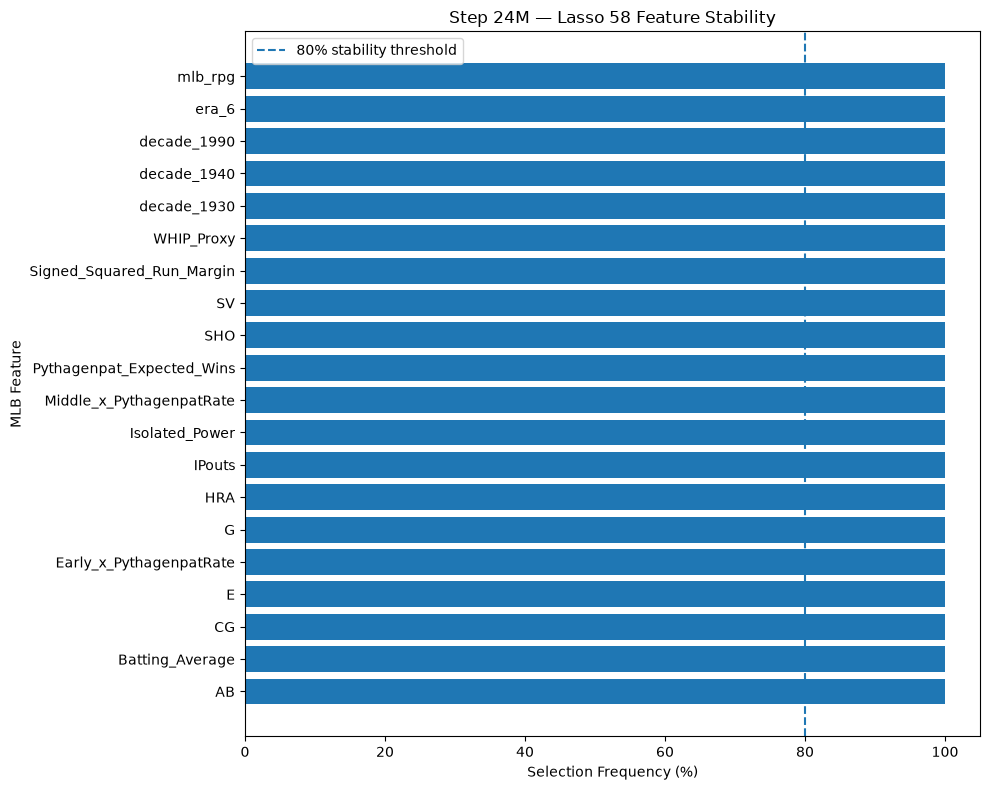


Step 24M completed.


In [87]:

# ============================================================
# STEP 24M — LASSO 58 FEATURE STABILITY ANALYSIS
#
# Compare Lasso 58 against Lasso 68
# 5-fold CV x 3 repeats = 15 folds
#
# No Kaggle or held-out test data used.
# No existing files modified.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. PREPARE DATASETS
# ------------------------------------------------------------

drop_58_24m = {
    "era_1",
    "era_8",
    "era_7",
    "decade_1980",
    "Run_Differential",
    "FP",
    "Run_Diff_Per_Game",
    "Run_Share_Smoothed",
    "Pythagorean_Expected_Wins_183",
    "Log_Run_Ratio"
}

X68_24m = training_sets_24i["Lasso 68"].copy()

X58_24m = X68_24m[
    [c for c in X68_24m.columns if c not in drop_58_24m]
].copy()

y_24m = y_train_24i.copy()

assert X68_24m.shape == (1129, 68)
assert X58_24m.shape == (1129, 58)
assert X58_24m.index.equals(y_24m.index)

datasets_24m = {
    "Lasso 58": X58_24m,
    "Lasso 68": X68_24m
}

print("=" * 70)
print("STEP 24M — DATASET VERIFICATION")
print("=" * 70)

for name, X in datasets_24m.items():
    print(name, X.shape)

# ------------------------------------------------------------
# 2. CREATE IDENTICAL CV SPLITS
# ------------------------------------------------------------

cv_24m = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24m = list(cv_24m.split(X58_24m))

# ------------------------------------------------------------
# 3. TRAIN MODELS AND RECORD COEFFICIENTS
# ------------------------------------------------------------

coefficient_rows_24m = []
performance_rows_24m = []

for model_name, X in datasets_24m.items():

    for fold, (train_idx, val_idx) in enumerate(
        splits_24m, start=1
    ):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y_24m.iloc[train_idx]
        y_val = y_24m.iloc[val_idx]

        model = create_lasso_24a(X_tr)
        model.set_params(lasso__alpha=0.0075)

        model.fit(X_tr, y_tr)

        train_pred = model.predict(X_tr)
        val_pred = model.predict(X_val)

        train_mae = mean_absolute_error(
            y_tr, train_pred
        )

        val_mae = mean_absolute_error(
            y_val, val_pred
        )

        performance_rows_24m.append({
            "Model": model_name,
            "Fold": fold,
            "Train_MAE": train_mae,
            "CV_MAE": val_mae,
            "Gap": val_mae - train_mae
        })

        # Extract fitted coefficients and names.
        coefficients = model.named_steps["lasso"].coef_

        transformed_names = (
            model[:-1].get_feature_names_out()
        )

        feature_names = [
            str(n).rsplit("__", 1)[-1]
            for n in transformed_names
        ]

        if set(feature_names) != set(X.columns):
            raise ValueError(
                "Feature names do not match "
                "the fitted model columns."
            )

        if len(feature_names) != len(coefficients):
            raise ValueError("Coefficient count mismatch.")

        for feature, coefficient in zip(
            feature_names, coefficients
        ):

            coefficient_rows_24m.append({
                "Model": model_name,
                "Fold": fold,
                "Feature": feature,
                "Coefficient": coefficient,
                "Selected": abs(coefficient) > 1e-7,
                "Positive": coefficient > 1e-7,
                "Negative": coefficient < -1e-7
            })

    print(model_name, "— 15 folds completed")

# ------------------------------------------------------------
# 4. CALCULATE FEATURE STABILITY
# ------------------------------------------------------------

coef_df_24m = pd.DataFrame(coefficient_rows_24m)

stability_24m = (
    coef_df_24m
    .groupby(["Model", "Feature"])
    .agg(
        Selected_Folds=("Selected", "sum"),
        Positive_Folds=("Positive", "sum"),
        Negative_Folds=("Negative", "sum"),
        Mean_Coefficient=("Coefficient", "mean"),
        Std_Coefficient=("Coefficient", "std")
    )
    .reset_index()
)

stability_24m["Selection_Pct"] = (
    100 * stability_24m["Selected_Folds"] / 15
)

stability_24m["Sign_Consistency_Pct"] = (
    100
    * stability_24m[
        ["Positive_Folds", "Negative_Folds"]
    ].max(axis=1)
    / stability_24m["Selected_Folds"].replace(0, np.nan)
).fillna(0)

def classify_24m(row):

    if row["Selected_Folds"] == 0:
        return "Never Selected"

    if (
        row["Selection_Pct"] >= 80
        and row["Sign_Consistency_Pct"] >= 90
    ):
        return "Stable"

    if row["Selection_Pct"] <= 20:
        return "Rarely Selected"

    if row["Sign_Consistency_Pct"] < 90:
        return "Sign Unstable"

    return "Intermittent"

stability_24m["Status"] = stability_24m.apply(
    classify_24m, axis=1
)

# ------------------------------------------------------------
# 5. REPEATED CV COMPARISON
# ------------------------------------------------------------

performance_df_24m = pd.DataFrame(
    performance_rows_24m
)

summary_24m = (
    performance_df_24m
    .groupby("Model")
    .agg(
        Train_MAE=("Train_MAE", "mean"),
        Repeated_CV_MAE=("CV_MAE", "mean"),
        CV_MAE_Std=("CV_MAE", "std"),
        Generalization_Gap=("Gap", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("STEP 24M — REPEATED CV COMPARISON")
print("=" * 75)

print(summary_24m.round(5).to_string(index=False))

# ------------------------------------------------------------
# 6. FEATURE STABILITY SUMMARY
# ------------------------------------------------------------

stability_summary_24m = (
    stability_24m
    .groupby(["Model", "Status"])
    .size()
    .unstack(fill_value=0)
)

print("\n" + "=" * 75)
print("STEP 24M — FEATURE STABILITY SUMMARY")
print("=" * 75)

print(stability_summary_24m.to_string())

# ------------------------------------------------------------
# 7. TOP STABLE FEATURES — LASSO 58
# ------------------------------------------------------------

lasso58_stability_24m = (
    stability_24m[
        stability_24m["Model"] == "Lasso 58"
    ]
    .sort_values(
        ["Selection_Pct", "Sign_Consistency_Pct"],
        ascending=False
    )
)

print("\n" + "=" * 75)
print("STEP 24M — TOP 20 LASSO 58 FEATURES")
print("=" * 75)

print(
    lasso58_stability_24m[
        [
            "Feature",
            "Selected_Folds",
            "Selection_Pct",
            "Sign_Consistency_Pct",
            "Status"
        ]
    ]
    .head(20)
    .round(2)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 8. FEATURES TO INVESTIGATE
# ------------------------------------------------------------

investigate_24m = lasso58_stability_24m[
    lasso58_stability_24m["Status"].isin([
        "Never Selected",
        "Rarely Selected",
        "Sign Unstable"
    ])
]

print("\n" + "=" * 75)
print("STEP 24M — FEATURES TO INVESTIGATE")
print("=" * 75)

if investigate_24m.empty:
    print("No features match the investigation criteria.")
else:
    print(
        investigate_24m[
            [
                "Feature",
                "Selected_Folds",
                "Selection_Pct",
                "Sign_Consistency_Pct",
                "Status"
            ]
        ].round(2).to_string(index=False)
    )

# ------------------------------------------------------------
# 9. VISUALIZE FEATURE SELECTION FREQUENCY
# ------------------------------------------------------------

plot_df = (
    lasso58_stability_24m
    .sort_values("Selection_Pct", ascending=False)
    .head(20)
    .sort_values("Selection_Pct")
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_df["Feature"],
    plot_df["Selection_Pct"]
)

plt.axvline(
    80,
    linestyle="--",
    label="80% stability threshold"
)

plt.xlabel("Selection Frequency (%)")
plt.ylabel("MLB Feature")
plt.title("Step 24M — Lasso 58 Feature Stability")
plt.xlim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

print("\nStep 24M completed.")


In [88]:

# ============================================================
# STEP 24N — NESTED STABILITY-BASED FEATURE SELECTION
#
# Baseline: Lasso 58, alpha = 0.0075
#
# A: Original 58 features
# B: Features selected in >= 1/5 inner folds
# C: Features selected in >= 2/5 inner folds
# D: Features selected in >= 4/5 inner folds
#
# Outer CV: 5 folds x 3 repeats = 15 evaluations
# Inner CV: 5 folds for feature selection
#
# NO HOLD-OUT TEST DATA
# NO KAGGLE DATA
# NO FILES MODIFIED
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    KFold,
    RepeatedKFold
)
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1 — VERIFY DATA
# ------------------------------------------------------------

X_24n = X58_24m.copy()
y_24n = y_24m.copy()

assert X_24n.shape == (1129, 58)
assert len(y_24n) == 1129
assert X_24n.index.equals(y_24n.index)

ALPHA_24N = 0.0075
TOL_24N = 1e-7

print("=" * 70)
print("STEP 24N — DATASET VERIFICATION")
print("=" * 70)

print("Observations:", len(X_24n))
print("Original features:", X_24n.shape[1])
print("Alpha:", ALPHA_24N)


# ------------------------------------------------------------
# 2 — CREATE OUTER CROSS-VALIDATION
# ------------------------------------------------------------

outer_cv_24n = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

outer_splits_24n = list(
    outer_cv_24n.split(X_24n, y_24n)
)

strategies_24n = {
    "A - Original 58": 0,
    "B - Selected >=1/5": 1,
    "C - Selected >=2/5": 2,
    "D - Selected >=4/5": 4
}

results_24n = []
feature_records_24n = []


# ------------------------------------------------------------
# 3 — MODEL FACTORY
# ------------------------------------------------------------

def make_lasso_24n(X):

    model = create_lasso_24a(X)

    model.set_params(
        lasso__alpha=ALPHA_24N
    )

    return model


# ------------------------------------------------------------
# 4 — EXTRACT SELECTED FEATURES
# ------------------------------------------------------------

def selected_features_24n(model, original_columns):

    coefficients = np.asarray(
        model.named_steps["lasso"].coef_
    ).reshape(-1)

    transformed_names = (
        model[:-1].get_feature_names_out()
    )

    names = [
        str(name).rsplit("__", 1)[-1]
        for name in transformed_names
    ]

    if (
        len(names) != len(coefficients)
        or len(set(names)) != len(names)
        or set(names) != set(original_columns)
    ):
        raise ValueError(
            "Feature names do not match "
            "the fitted Lasso coefficients."
        )

    coefficients = pd.Series(
        coefficients,
        index=names
    )

    return (
        coefficients
        .reindex(original_columns)
        .abs()
        .gt(TOL_24N)
    )


# ------------------------------------------------------------
# 5 — OUTER VALIDATION LOOP
# ------------------------------------------------------------

for outer_fold, (train_idx, val_idx) in enumerate(
    outer_splits_24n,
    start=1
):

    X_train_outer = X_24n.iloc[train_idx]
    X_val_outer = X_24n.iloc[val_idx]

    y_train_outer = y_24n.iloc[train_idx]
    y_val_outer = y_24n.iloc[val_idx]

    # --------------------------------------------------------
    # INNER CV — ESTIMATE FEATURE SELECTION FREQUENCY
    #
    # Inner folds use outer TRAINING data only.
    # --------------------------------------------------------

    inner_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=2400 + outer_fold
    )

    selection_counts = pd.Series(
        0,
        index=X_train_outer.columns,
        dtype=int
    )

    for inner_train_idx, inner_val_idx in inner_cv.split(
        X_train_outer
    ):

        X_inner_train = X_train_outer.iloc[
            inner_train_idx
        ]

        y_inner_train = y_train_outer.iloc[
            inner_train_idx
        ]

        inner_model = make_lasso_24n(
            X_inner_train
        )

        inner_model.fit(
            X_inner_train,
            y_inner_train
        )

        selected = selected_features_24n(
            inner_model,
            X_train_outer.columns.tolist()
        )

        selection_counts += selected.astype(int)

    # --------------------------------------------------------
    # TRAIN AND TEST FOUR FIXED SELECTION POLICIES
    # --------------------------------------------------------

    for strategy_name, threshold in strategies_24n.items():

        if threshold == 0:

            retained_features = (
                X_train_outer.columns.tolist()
            )

        else:

            retained_features = (
                selection_counts[
                    selection_counts >= threshold
                ]
                .index
                .tolist()
            )

        if len(retained_features) < 10:
            raise ValueError(
                f"Too few features for {strategy_name}: "
                f"{len(retained_features)}"
            )

        X_tr = X_train_outer[
            retained_features
        ].copy()

        X_val = X_val_outer[
            retained_features
        ].copy()

        model = make_lasso_24n(X_tr)

        model.fit(X_tr, y_train_outer)

        train_predictions = model.predict(X_tr)
        val_predictions = model.predict(X_val)

        train_mae = mean_absolute_error(
            y_train_outer,
            train_predictions
        )

        val_mae = mean_absolute_error(
            y_val_outer,
            val_predictions
        )

        results_24n.append({
            "Strategy": strategy_name,
            "Outer_Fold": outer_fold,
            "Repeat": (outer_fold - 1) // 5 + 1,
            "Features": len(retained_features),
            "Train_MAE": train_mae,
            "CV_MAE": val_mae,
            "MAE_Gap": val_mae - train_mae
        })

        for feature in X_24n.columns:

            feature_records_24n.append({
                "Strategy": strategy_name,
                "Outer_Fold": outer_fold,
                "Feature": feature,
                "Retained": int(
                    feature in retained_features
                )
            })

    print(
        f"Outer fold {outer_fold:02d}/15 completed"
    )


# ------------------------------------------------------------
# 6 — OVERALL CV COMPARISON
# ------------------------------------------------------------

results_df_24n = pd.DataFrame(
    results_24n
)

summary_24n = (
    results_df_24n
    .groupby("Strategy")
    .agg(
        Mean_Features=("Features", "mean"),
        Min_Features=("Features", "min"),
        Max_Features=("Features", "max"),
        Train_MAE=("Train_MAE", "mean"),
        Repeated_CV_MAE=("CV_MAE", "mean"),
        CV_MAE_Std=("CV_MAE", "std"),
        MAE_Gap=("MAE_Gap", "mean")
    )
    .reset_index()
    .sort_values("Repeated_CV_MAE")
)

print("\n" + "=" * 100)
print("STEP 24N — NESTED FEATURE SELECTION COMPARISON")
print("=" * 100)

print(
    summary_24n.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# 7 — PAIRED FOLD COMPARISON AGAINST LASSO 58
# ------------------------------------------------------------

baseline_24n = (
    results_df_24n[
        results_df_24n["Strategy"] == "A - Original 58"
    ]
    .sort_values("Outer_Fold")["CV_MAE"]
    .to_numpy()
)

paired_rows_24n = []

for strategy_name in strategies_24n:

    if strategy_name == "A - Original 58":
        continue

    candidate = (
        results_df_24n[
            results_df_24n["Strategy"] == strategy_name
        ]
        .sort_values("Outer_Fold")["CV_MAE"]
        .to_numpy()
    )

    difference = baseline_24n - candidate

    paired_rows_24n.append({
        "Strategy": strategy_name,
        "Mean_Improvement": difference.mean(),
        "Fold_Wins": int((difference > 0).sum()),
        "Fold_Losses": int((difference < 0).sum()),
        "Difference_Std": difference.std(ddof=1)
    })

paired_24n = pd.DataFrame(paired_rows_24n)

print("\n" + "=" * 85)
print("STEP 24N — PAIRED COMPARISON VS LASSO 58")
print("=" * 85)

print(
    paired_24n.round(6).to_string(index=False)
)


# ------------------------------------------------------------
# 8 — RETENTION FREQUENCY BY FEATURE
# ------------------------------------------------------------

feature_df_24n = pd.DataFrame(
    feature_records_24n
)

retention_24n = (
    feature_df_24n
    .groupby(["Strategy", "Feature"])["Retained"]
    .agg(["sum", "mean"])
    .reset_index()
)

retention_24n = retention_24n.rename(
    columns={
        "sum": "Retained_Folds",
        "mean": "Retention_Rate"
    }
)

retention_24n["Retention_Pct"] = (
    retention_24n["Retention_Rate"] * 100
)

for strategy_name in list(strategies_24n)[1:]:

    subset = (
        retention_24n[
            retention_24n["Strategy"] == strategy_name
        ]
        .sort_values(
            ["Retained_Folds", "Feature"]
        )
    )

    print("\n" + "=" * 80)
    print("FEATURE RETENTION:", strategy_name)
    print("=" * 80)

    print(
        subset[
            [
                "Feature",
                "Retained_Folds",
                "Retention_Pct"
            ]
        ]
        .head(20)
        .round(2)
        .to_string(index=False)
    )


# ------------------------------------------------------------
# 9 — REPEAT-BY-REPEAT COMPARISON
# ------------------------------------------------------------

repeat_table_24n = (
    results_df_24n
    .groupby(["Repeat", "Strategy"])["CV_MAE"]
    .mean()
    .unstack()
)

print("\n" + "=" * 85)
print("STEP 24N — REPEAT-BY-REPEAT COMPARISON")
print("=" * 85)

print(
    repeat_table_24n.round(5).to_string()
)


# ------------------------------------------------------------
# 10 — FINAL SUMMARY
# ------------------------------------------------------------

best_24n = summary_24n.iloc[0]

print("\n" + "=" * 70)
print("STEP 24N — FINAL SUMMARY")
print("=" * 70)

print("Best exploratory strategy:", best_24n["Strategy"])

print(
    "Repeated CV MAE:",
    round(float(best_24n["Repeated_CV_MAE"]), 5)
)

print(
    "Average features:",
    round(float(best_24n["Mean_Features"]), 2)
)

print("\nExisting benchmark:")
print("Lasso 58 CV MAE: 2.72335")
print("Lasso 58 Kaggle Public MAE: 2.8850")

print("\nResearch target: 2.6900")

print(
    "\nNOTE: Feature selection was fitted "
    "inside each outer training fold."
)

print(
    "Comparing several pruning strategies "
    "still introduces exploratory model-selection uncertainty."
)

print("\nStep 24N completed.")


STEP 24N — DATASET VERIFICATION
Observations: 1129
Original features: 58
Alpha: 0.0075
Outer fold 01/15 completed
Outer fold 02/15 completed
Outer fold 03/15 completed
Outer fold 04/15 completed
Outer fold 05/15 completed
Outer fold 06/15 completed
Outer fold 07/15 completed
Outer fold 08/15 completed
Outer fold 09/15 completed
Outer fold 10/15 completed
Outer fold 11/15 completed
Outer fold 12/15 completed
Outer fold 13/15 completed
Outer fold 14/15 completed
Outer fold 15/15 completed

STEP 24N — NESTED FEATURE SELECTION COMPARISON
          Strategy  Mean_Features  Min_Features  Max_Features  Train_MAE  Repeated_CV_MAE  CV_MAE_Std  MAE_Gap
B - Selected >=1/5       51.53333            48            54    2.60718          2.72329     0.17129  0.11611
C - Selected >=2/5       45.60000            43            48    2.60720          2.72329     0.17109  0.11609
   A - Original 58       58.00000            58            58    2.60715          2.72335     0.17121  0.11620
D - Selected >=4

STEP 24O — DATASET VERIFICATION
Labeled dataset: (1412, 58)
Kaggle dataset: (400, 58)
Features: 58

STEP 24O — HISTORICAL DECADE DISTRIBUTION
Decade  Train_Count  Train_Pct  Kaggle_Count  Kaggle_Pct  Difference_PctPoints
  1910          130       9.21            44       11.00                  1.79
  1920          107       7.58            23        5.75                 -1.83
  1930           92       6.52            27        6.75                  0.23
  1940           87       6.16            29        7.25                  1.09
  1950          108       7.65            28        7.00                 -0.65
  1960          121       8.57            32        8.00                 -0.57
  1970          162      11.47            40       10.00                 -1.47
  1980          149      10.55            35        8.75                 -1.80
  1990          134       9.49            53       13.25                  3.76
  2000          197      13.95            55       13.75            

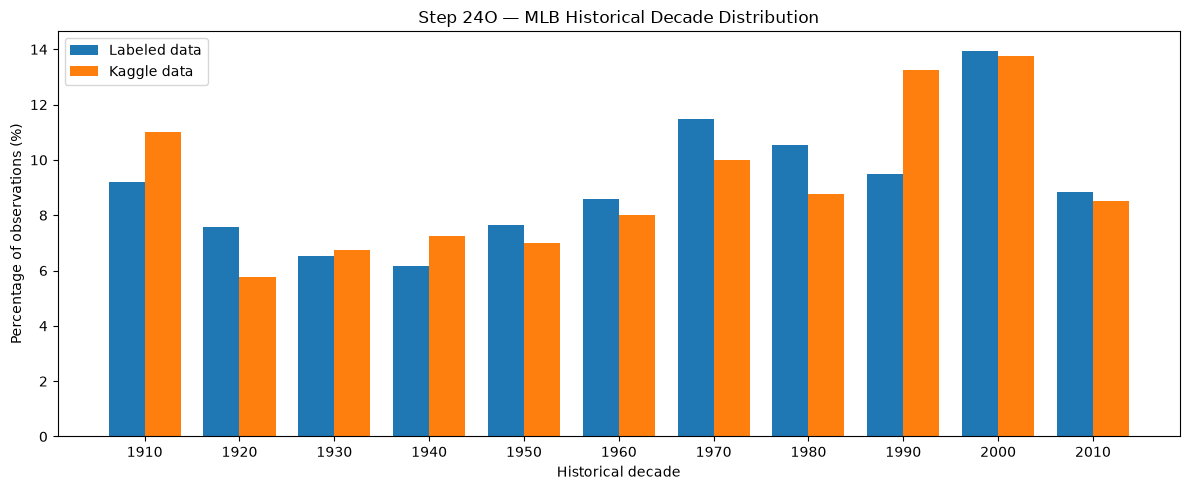

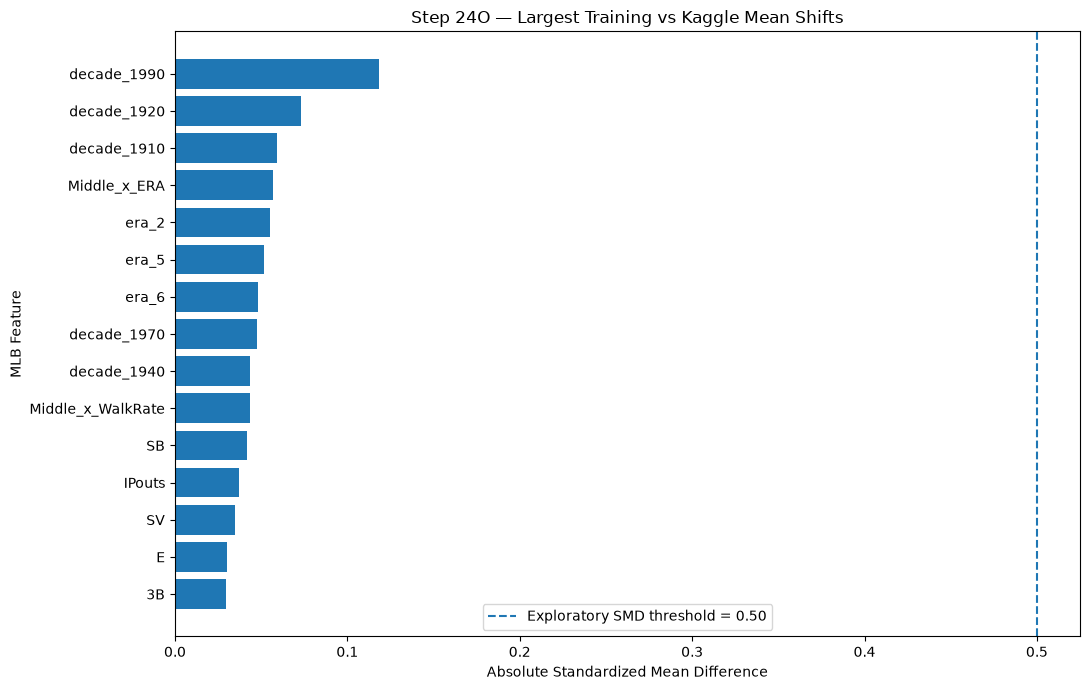


STEP 24O — FINAL SUMMARY
Labeled observations: 1412
Kaggle observations: 400
Features compared: 58
Features flagged for investigation: 0
Adversarial validation AUC: 0.48385

Current Kaggle champion:
Lasso 58 — Public MAE 2.8850

Important notes:
- No Kaggle hidden win totals were used.
- High correlation can duplicate shift signals.
- Shift does not prove why Kaggle MAE differs.
- Classifier ROC AUC is not MLB prediction accuracy.
- No Lasso model was retrained or modified.

Step 24O completed.


In [89]:

# ============================================================
# STEP 24O — MLB DATA DISTRIBUTION SHIFT ANALYSIS
#
# Research question:
# Are the 400 Kaggle observations different from
# the 1412 labeled MLB observations?
#
# Model reference: Lasso 58, alpha = 0.0075
# Current best Kaggle public MAE: 2.8850
#
# Analyses:
# 1. Dataset verification
# 2. Historical decade distribution
# 3. Standardized mean difference (SMD)
# 4. KS distribution statistic
# 5. Unusual / out-of-range Kaggle observations
# 6. Adversarial validation (ROC AUC)
# 7. Visualizations
#
# NO TARGET WINS USED
# NO MODEL OR CSV FILES MODIFIED
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


# ------------------------------------------------------------
# STEP 1 — VERIFY DATASETS
# ------------------------------------------------------------

required_24o = [
    "X_full_24j",
    "kaggle_features_24j",
    "training_sets_24i"
]

missing_24o = [
    obj for obj in required_24o
    if obj not in globals()
]

if missing_24o:
    raise NameError(
        "Please run earlier notebook steps. "
        f"Missing: {missing_24o}"
    )

X_labeled68_24o = X_full_24j.copy()
X_kaggle68_24o = kaggle_features_24j.copy()

assert X_labeled68_24o.shape[0] == 1412
assert X_kaggle68_24o.shape[0] == 400

# Recreate the Lasso 58 feature list.

drop_features_24o = {
    "era_1",
    "era_8",
    "era_7",
    "decade_1980",
    "Run_Differential",
    "FP",
    "Run_Diff_Per_Game",
    "Run_Share_Smoothed",
    "Pythagorean_Expected_Wins_183",
    "Log_Run_Ratio"
}

base68_columns_24o = (
    training_sets_24i["Lasso 68"]
    .columns.tolist()
)

features58_24o = [
    col for col in base68_columns_24o
    if col not in drop_features_24o
]

assert len(features58_24o) == 58

# Use exactly the same 58 model features.
# Never include ID or the actual wins target W.

X_train58_24o = (
    X_labeled68_24o[features58_24o]
    .apply(pd.to_numeric)
    .copy()
)

X_kaggle58_24o = (
    X_kaggle68_24o[features58_24o]
    .apply(pd.to_numeric)
    .copy()
)

assert X_train58_24o.shape == (1412, 58)
assert X_kaggle58_24o.shape == (400, 58)

assert not {"ID", "W"}.intersection(
    features58_24o
)

assert np.isfinite(
    X_train58_24o.to_numpy(dtype=float)
).all()

assert np.isfinite(
    X_kaggle58_24o.to_numpy(dtype=float)
).all()

print("=" * 75)
print("STEP 24O — DATASET VERIFICATION")
print("=" * 75)

print("Labeled dataset:", X_train58_24o.shape)
print("Kaggle dataset:", X_kaggle58_24o.shape)
print("Features:", len(features58_24o))


# ------------------------------------------------------------
# STEP 2 — HISTORICAL DECADE DISTRIBUTION
# ------------------------------------------------------------

decade_columns_24o = [
    f"decade_{year}"
    for year in range(1910, 2020, 10)
]

missing_decade_cols_24o = [
    col for col in decade_columns_24o
    if (
        col not in X_labeled68_24o.columns
        or col not in X_kaggle68_24o.columns
    )
]

assert not missing_decade_cols_24o, (
    "Missing decade columns: "
    + str(missing_decade_cols_24o)
)

train_decade_flags_24o = (
    X_labeled68_24o[decade_columns_24o]
    .astype(float)
)

kaggle_decade_flags_24o = (
    X_kaggle68_24o[decade_columns_24o]
    .astype(float)
)

assert np.allclose(
    train_decade_flags_24o.sum(axis=1), 1
)

assert np.allclose(
    kaggle_decade_flags_24o.sum(axis=1), 1
)

decade_rows_24o = []

for col in decade_columns_24o:

    train_count = int(
        train_decade_flags_24o[col].sum()
    )

    kaggle_count = int(
        kaggle_decade_flags_24o[col].sum()
    )

    train_pct = 100 * train_count / 1412
    kaggle_pct = 100 * kaggle_count / 400

    decade_rows_24o.append({
        "Decade": col.replace("decade_", ""),
        "Train_Count": train_count,
        "Train_Pct": train_pct,
        "Kaggle_Count": kaggle_count,
        "Kaggle_Pct": kaggle_pct,
        "Difference_PctPoints": (
            kaggle_pct - train_pct
        )
    })

decade_shift_24o = pd.DataFrame(
    decade_rows_24o
)

print("\n" + "=" * 90)
print("STEP 24O — HISTORICAL DECADE DISTRIBUTION")
print("=" * 90)

print(
    decade_shift_24o
    .round(2)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 3 — NUMERICAL FEATURE DISTRIBUTION
#
# Standardized mean difference (SMD)
#
# SMD = (Kaggle mean - Train mean)
#       / pooled standard deviation
#
# KS statistic compares whole distributions.
# ------------------------------------------------------------

shift_rows_24o = []

for feature in features58_24o:

    train = X_train58_24o[
        feature
    ].to_numpy(dtype=float)

    kaggle = X_kaggle58_24o[
        feature
    ].to_numpy(dtype=float)

    train_mean = train.mean()
    kaggle_mean = kaggle.mean()

    train_std = train.std(ddof=1)
    kaggle_std = kaggle.std(ddof=1)

    pooled_std = np.sqrt(
        (train_std**2 + kaggle_std**2) / 2
    )

    # Signed SMD:
    # Positive = higher average in Kaggle.

    if pooled_std > 1e-12:
        smd = (
            kaggle_mean - train_mean
        ) / pooled_std
    else:
        smd = 0.0 if np.isclose(
            train_mean, kaggle_mean
        ) else np.nan

    ks = ks_2samp(
        train,
        kaggle
    ).statistic

    # Percentage of Kaggle observations
    # beyond the observed labeled-data range.

    outside_training_range = 100 * np.mean(
        (kaggle < train.min())
        | (kaggle > train.max())
    )

    # More sensitive tail check:
    # Kaggle observations outside the
    # training P1–P99 interval.

    p01, p99 = np.percentile(
        train, [1, 99]
    )

    outside_central_range = 100 * np.mean(
        (kaggle < p01)
        | (kaggle > p99)
    )

    shift_rows_24o.append({
        "Feature": feature,
        "Train_Mean": train_mean,
        "Kaggle_Mean": kaggle_mean,
        "Signed_SMD": smd,
        "Abs_SMD": abs(smd),
        "KS_Statistic": ks,
        "Outside_Train_Range_Pct":
            outside_training_range,
        "Outside_P1_P99_Pct":
            outside_central_range
    })

shift_df_24o = pd.DataFrame(
    shift_rows_24o
)

# Exploratory thresholds only.
# Not formal significance tests.

shift_df_24o["Shift_Flag"] = np.where(
    (shift_df_24o["Abs_SMD"] >= 0.50)
    | (shift_df_24o["KS_Statistic"] >= 0.20),
    "Investigate",
    "Lower shift"
)

shift_df_24o = shift_df_24o.sort_values(
    ["KS_Statistic", "Abs_SMD"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 115)
print("STEP 24O — TOP 20 DISTRIBUTION DIFFERENCES")
print("=" * 115)

print(
    shift_df_24o[
        [
            "Feature",
            "Train_Mean",
            "Kaggle_Mean",
            "Signed_SMD",
            "KS_Statistic",
            "Outside_Train_Range_Pct",
            "Shift_Flag"
        ]
    ]
    .head(20)
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 4 — BIGGEST STANDARDIZED MEAN DIFFERENCES
# ------------------------------------------------------------

top_smd_24o = (
    shift_df_24o
    .sort_values(
        "Abs_SMD",
        ascending=False
    )
    .head(15)
)

print("\n" + "=" * 90)
print("STEP 24O — TOP 15 STANDARDIZED MEAN DIFFERENCES")
print("=" * 90)

print(
    top_smd_24o[
        [
            "Feature",
            "Signed_SMD",
            "Abs_SMD",
            "KS_Statistic"
        ]
    ]
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 5 — EXTREME KAGGLE FEATURE VALUES
# ------------------------------------------------------------

extreme_24o = (
    shift_df_24o
    .sort_values(
        "Outside_Train_Range_Pct",
        ascending=False
    )
)

print("\n" + "=" * 90)
print("STEP 24O — KAGGLE VALUES OUTSIDE TRAINING RANGE")
print("=" * 90)

print(
    extreme_24o[
        [
            "Feature",
            "Outside_Train_Range_Pct",
            "Outside_P1_P99_Pct"
        ]
    ]
    .head(15)
    .round(3)
    .to_string(index=False)
)


# ============================================================
# STEP 6 — ADVERSARIAL VALIDATION
#
# Objective:
# Can ML identify whether a row belongs
# to labeled data or Kaggle data?
#
# Label 0 = labeled dataset
# Label 1 = Kaggle dataset
#
# This is NOT predicting MLB wins.
# ============================================================

X_source_24o = pd.concat(
    [
        X_train58_24o,
        X_kaggle58_24o
    ],
    ignore_index=True
)

y_source_24o = np.concatenate([
    np.zeros(1412, dtype=int),
    np.ones(400, dtype=int)
])

source_classifier_24o = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "logistic",
        LogisticRegression(
            C=1.0,
            max_iter=5000,
            class_weight="balanced",
            random_state=2026
        )
    )
])

source_cv_24o = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

auc_scores_24o = cross_val_score(
    source_classifier_24o,
    X_source_24o,
    y_source_24o,
    cv=source_cv_24o,
    scoring="roc_auc",
    n_jobs=1
)

mean_auc_24o = auc_scores_24o.mean()

print("\n" + "=" * 75)
print("STEP 24O — ADVERSARIAL VALIDATION")
print("=" * 75)

print(
    "ROC AUC by fold:",
    np.round(auc_scores_24o, 4)
)

print(
    "Mean ROC AUC:",
    round(mean_auc_24o, 5)
)

print(
    "ROC AUC standard deviation:",
    round(auc_scores_24o.std(ddof=1), 5)
)

if mean_auc_24o < 0.60:
    print(
        "Interpretation: Weak separation "
        "under this classifier."
    )
elif mean_auc_24o < 0.75:
    print(
        "Interpretation: Some detectable "
        "differences between datasets."
    )
else:
    print(
        "Interpretation: Strong separation "
        "under this classifier."
    )


# ------------------------------------------------------------
# STEP 7 — VISUALIZATION: DECADE COMPOSITION
# ------------------------------------------------------------

x_positions_24o = np.arange(
    len(decade_shift_24o)
)

width_24o = 0.38

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    x_positions_24o - width_24o / 2,
    decade_shift_24o["Train_Pct"],
    width_24o,
    label="Labeled data"
)

ax.bar(
    x_positions_24o + width_24o / 2,
    decade_shift_24o["Kaggle_Pct"],
    width_24o,
    label="Kaggle data"
)

ax.set_xticks(x_positions_24o)

ax.set_xticklabels(
    decade_shift_24o["Decade"]
)

ax.set_xlabel("Historical decade")
ax.set_ylabel("Percentage of observations (%)")

ax.set_title(
    "Step 24O — MLB Historical Decade Distribution"
)

ax.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 8 — VISUALIZATION: TOP FEATURE SHIFTS
# ------------------------------------------------------------

plot_shift_24o = (
    shift_df_24o
    .sort_values("Abs_SMD", ascending=False)
    .head(15)
    .sort_values("Abs_SMD")
)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    plot_shift_24o["Feature"],
    plot_shift_24o["Abs_SMD"]
)

ax.axvline(
    0.50,
    linestyle="--",
    label="Exploratory SMD threshold = 0.50"
)

ax.set_xlabel(
    "Absolute Standardized Mean Difference"
)

ax.set_ylabel("MLB Feature")

ax.set_title(
    "Step 24O — Largest Training vs Kaggle Mean Shifts"
)

ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 9 — FINAL SUMMARY
# ------------------------------------------------------------

flagged_24o = int(
    (shift_df_24o["Shift_Flag"] == "Investigate").sum()
)

print("\n" + "=" * 75)
print("STEP 24O — FINAL SUMMARY")
print("=" * 75)

print("Labeled observations:", 1412)
print("Kaggle observations:", 400)
print("Features compared:", 58)

print(
    "Features flagged for investigation:",
    flagged_24o
)

print(
    "Adversarial validation AUC:",
    round(mean_auc_24o, 5)
)

print("\nCurrent Kaggle champion:")
print("Lasso 58 — Public MAE 2.8850")

print("\nImportant notes:")
print("- No Kaggle hidden win totals were used.")
print("- High correlation can duplicate shift signals.")
print("- Shift does not prove why Kaggle MAE differs.")
print("- Classifier ROC AUC is not MLB prediction accuracy.")
print("- No Lasso model was retrained or modified.")

print("\nStep 24O completed.")


In [90]:

# ============================================================
# STEP 24P — KAGGLE-STYLE MAE VALIDATION
#
# Model: Lasso 58
# Alpha: 0.0075
#
# Compare:
# A - Continuous predictions
# B - Rounded integer predictions
# C - Rounded + clipped predictions
#
# Repeated CV: 5 folds x 3 repeats
# Dataset: Original 1129 training observations
#
# NO HOLD-OUT TEST DATA
# NO KAGGLE DATA
# NO EXISTING FILES MODIFIED
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — VERIFY DATA
# ------------------------------------------------------------

X_24p = X58_24m.copy()
y_24p = y_24m.copy()

assert X_24p.shape == (1129, 58)
assert len(y_24p) == 1129
assert X_24p.index.equals(y_24p.index)
assert "G" in X_24p.columns

assert np.isfinite(
    X_24p.to_numpy(dtype=float)
).all()

assert np.isfinite(
    y_24p.to_numpy(dtype=float)
).all()

assert (X_24p["G"] > 0).all()

print("=" * 75)
print("STEP 24P — DATASET VERIFICATION")
print("=" * 75)

print("Observations:", len(X_24p))
print("Features:", X_24p.shape[1])
print("Alpha:", 0.0075)


# ------------------------------------------------------------
# STEP 2 — CREATE REPEATED CV SPLITS
# ------------------------------------------------------------

cv_24p = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24p = list(
    cv_24p.split(X_24p, y_24p)
)

print("\nCROSS-VALIDATION")
print("================")
print("Folds: 5")
print("Repeats: 3")
print("Total evaluations:", len(splits_24p))


# ------------------------------------------------------------
# STEP 3 — PREPARE RESULTS
# ------------------------------------------------------------

results_24p = []
diagnostics_24p = []

methods_24p = [
    "A - Continuous",
    "B - Rounded",
    "C - Rounded + Clipped"
]


# ------------------------------------------------------------
# STEP 4 — TRAIN AND VALIDATE
# ------------------------------------------------------------

for fold_no, (train_idx, val_idx) in enumerate(
    splits_24p, start=1
):

    X_tr = X_24p.iloc[train_idx]
    X_val = X_24p.iloc[val_idx]

    y_tr = y_24p.iloc[train_idx]
    y_val = y_24p.iloc[val_idx]

    actual = y_val.to_numpy(dtype=float)

    games = X_val["G"].to_numpy(
        dtype=float
    )

    # --------------------------------------------------------
    # Fit Lasso 58 using only training rows
    # --------------------------------------------------------

    model = create_lasso_24a(X_tr)

    model.set_params(
        lasso__alpha=0.0075
    )

    model.fit(X_tr, y_tr)

    # --------------------------------------------------------
    # Method A — Continuous predictions
    # --------------------------------------------------------

    pred_continuous = model.predict(X_val)

    # --------------------------------------------------------
    # Method B — Round predictions
    #
    # np.rint uses nearest integer.
    # This matches the previous Kaggle submission code.
    # --------------------------------------------------------

    pred_rounded = np.rint(
        pred_continuous
    )

    # --------------------------------------------------------
    # Method C — Round and clip
    #
    # A baseball team cannot win fewer than 0 games
    # or more games than it played.
    # --------------------------------------------------------

    pred_clipped = np.clip(
        pred_rounded,
        0,
        np.floor(games)
    )

    predictions = {
        "A - Continuous": pred_continuous,
        "B - Rounded": pred_rounded,
        "C - Rounded + Clipped": pred_clipped
    }

    # --------------------------------------------------------
    # Evaluate all methods in total wins
    # --------------------------------------------------------

    for method, pred in predictions.items():

        mae = mean_absolute_error(
            actual, pred
        )

        rmse = np.sqrt(
            mean_squared_error(actual, pred)
        )

        r2 = r2_score(
            actual, pred
        )

        results_24p.append({
            "Method": method,
            "Fold": fold_no,
            "Repeat": (fold_no - 1) // 5 + 1,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    # Count predictions changed by processing

    changed_by_rounding = np.sum(
        pred_continuous != pred_rounded
    )

    changed_by_clipping = np.sum(
        pred_rounded != pred_clipped
    )

    diagnostics_24p.append({
        "Fold": fold_no,
        "Validation_Rows": len(val_idx),
        "Changed_By_Rounding": int(
            changed_by_rounding
        ),
        "Changed_By_Clipping": int(
            changed_by_clipping
        ),
        "Mean_Abs_Rounding_Change": np.mean(
            np.abs(
                pred_continuous - pred_rounded
            )
        )
    })

    fold_results = results_24p[-3:]

    print(
        f"Fold {fold_no:02d} | "
        f"Continuous: {fold_results[0]['MAE']:.5f} | "
        f"Rounded: {fold_results[1]['MAE']:.5f} | "
        f"Clipped: {fold_results[2]['MAE']:.5f}"
    )


# ------------------------------------------------------------
# STEP 5 — OVERALL COMPARISON
# ------------------------------------------------------------

results_df_24p = pd.DataFrame(
    results_24p
)

summary_24p = (
    results_df_24p
    .groupby("Method")
    .agg(
        Repeated_CV_MAE=("MAE", "mean"),
        CV_MAE_Std=("MAE", "std"),
        CV_RMSE=("RMSE", "mean"),
        CV_R2=("R2", "mean")
    )
    .reindex(methods_24p)
    .reset_index()
)

print("\n" + "=" * 95)
print("STEP 24P — CONTINUOUS VS KAGGLE-STYLE MAE")
print("=" * 95)

print(
    summary_24p.round(5).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 6 — PAIRED COMPARISON
# ------------------------------------------------------------

mae_by_fold_24p = results_df_24p.pivot(
    index="Fold",
    columns="Method",
    values="MAE"
)

baseline = mae_by_fold_24p[
    "A - Continuous"
].to_numpy()

paired_rows_24p = []

for method in methods_24p[1:]:

    candidate = mae_by_fold_24p[
        method
    ].to_numpy()

    # Positive means the new prediction
    # processing method reduces MAE.

    improvements = baseline - candidate

    paired_rows_24p.append({
        "Method": method,
        "Mean_MAE_Improvement":
            improvements.mean(),
        "Fold_Wins": int(
            (improvements > 0).sum()
        ),
        "Fold_Losses": int(
            (improvements < 0).sum()
        ),
        "Ties": int(
            np.isclose(
                improvements, 0, atol=1e-12
            ).sum()
        ),
        "Difference_Std":
            improvements.std(ddof=1)
    })

paired_24p = pd.DataFrame(
    paired_rows_24p
)

print("\n" + "=" * 90)
print("STEP 24P — PAIRED COMPARISON VS CONTINUOUS")
print("=" * 90)

print(
    paired_24p.round(6).to_string(index=False)
)


# ------------------------------------------------------------
# STEP 7 — ROUNDING AND CLIPPING DIAGNOSTICS
# ------------------------------------------------------------

diagnostics_df_24p = pd.DataFrame(
    diagnostics_24p
)

print("\n" + "=" * 80)
print("STEP 24P — PREDICTION PROCESSING DIAGNOSTICS")
print("=" * 80)

print(
    "Average absolute rounding change:",
    round(
        diagnostics_df_24p[
            "Mean_Abs_Rounding_Change"
        ].mean(),
        5
    )
)

print(
    "Total predictions changed by clipping "
    "(across 15 validation folds):",
    int(
        diagnostics_df_24p[
            "Changed_By_Clipping"
        ].sum()
    )
)

print(
    "Total evaluated validation predictions:",
    int(
        diagnostics_df_24p[
            "Validation_Rows"
        ].sum()
    )
)


# ------------------------------------------------------------
# STEP 8 — REPEAT-BY-REPEAT COMPARISON
# ------------------------------------------------------------

repeat_table_24p = (
    results_df_24p
    .groupby(["Repeat", "Method"])["MAE"]
    .mean()
    .unstack()
)

print("\n" + "=" * 90)
print("STEP 24P — REPEAT-BY-REPEAT MAE")
print("=" * 90)

print(
    repeat_table_24p.round(5).to_string()
)


# ------------------------------------------------------------
# STEP 9 — CHECK ORIGINAL CV BENCHMARK
# ------------------------------------------------------------

continuous_mae_24p = float(
    summary_24p.loc[
        summary_24p["Method"] == "A - Continuous",
        "Repeated_CV_MAE"
    ].iloc[0]
)

kaggle_style_mae_24p = float(
    summary_24p.loc[
        summary_24p["Method"] == "C - Rounded + Clipped",
        "Repeated_CV_MAE"
    ].iloc[0]
)

print("\n" + "=" * 80)
print("STEP 24P — FINAL SUMMARY")
print("=" * 80)

print(
    "Original Lasso 58 CV MAE:",
    2.72335
)

print(
    "Recalculated continuous CV MAE:",
    round(continuous_mae_24p, 5)
)

assert abs(
    continuous_mae_24p - 2.72335
) < 0.001, (
    "Baseline did not reproduce. "
    "Check dataset, alpha and preprocessing."
)

print(
    "Kaggle-style CV MAE:",
    round(kaggle_style_mae_24p, 5)
)

print(
    "Change after rounding and clipping:",
    round(
        kaggle_style_mae_24p
        - continuous_mae_24p,
        5
    )
)

print("\nCurrent Kaggle Public MAE: 2.8850")
print("Research target CV MAE: 2.6900")

print("\nImportant:")
print("- Kaggle hidden wins were not used.")
print("- The Lasso model itself was not changed.")
print("- Rounding may improve or worsen MAE.")
print("- CV and Kaggle use different observations.")
print("- Repeated folds are not independent samples.")

print("\nStep 24P completed.")


STEP 24P — DATASET VERIFICATION
Observations: 1129
Features: 58
Alpha: 0.0075

CROSS-VALIDATION
Folds: 5
Repeats: 3
Total evaluations: 15
Fold 01 | Continuous: 2.67109 | Rounded: 2.69469 | Clipped: 2.69469
Fold 02 | Continuous: 2.98777 | Rounded: 2.96460 | Clipped: 2.96460
Fold 03 | Continuous: 2.91304 | Rounded: 2.88053 | Clipped: 2.88053
Fold 04 | Continuous: 2.63516 | Rounded: 2.62389 | Clipped: 2.62389
Fold 05 | Continuous: 2.41257 | Rounded: 2.41333 | Clipped: 2.41333
Fold 06 | Continuous: 2.65602 | Rounded: 2.67257 | Clipped: 2.67257
Fold 07 | Continuous: 2.72444 | Rounded: 2.72124 | Clipped: 2.72124
Fold 08 | Continuous: 2.73123 | Rounded: 2.72124 | Clipped: 2.72124
Fold 09 | Continuous: 2.90786 | Rounded: 2.90708 | Clipped: 2.90708
Fold 10 | Continuous: 2.54416 | Rounded: 2.53333 | Clipped: 2.53333
Fold 11 | Continuous: 2.77897 | Rounded: 2.79204 | Clipped: 2.79204
Fold 12 | Continuous: 3.01752 | Rounded: 2.99558 | Clipped: 2.99558
Fold 13 | Continuous: 2.57085 | Rounded: 2.553

STEP 24Q — DATASET VERIFICATION
Lasso 48 (1129, 48)
Lasso 58 (1129, 58)
Target observations: 1129
CV fold 01/15 completed
CV fold 02/15 completed
CV fold 03/15 completed
CV fold 04/15 completed
CV fold 05/15 completed
CV fold 06/15 completed
CV fold 07/15 completed
CV fold 08/15 completed
CV fold 09/15 completed
CV fold 10/15 completed
CV fold 11/15 completed
CV fold 12/15 completed
CV fold 13/15 completed
CV fold 14/15 completed
CV fold 15/15 completed

OOF prediction verification passed.

STEP 24Q — REPEATED CV COMPARISON
   Model  Continuous_CV_MAE  Rounded_CV_MAE  Continuous_CV_Std  Rounded_CV_Std
Lasso 48            2.74148         2.73117            0.18202         0.18134
Lasso 58            2.72335         2.71878            0.17121         0.16558

STEP 24Q — OUT-OF-FOLD MAE BY REPEAT
 Repeat  Lasso48_Continuous  Lasso48_Rounded  Lasso58_Continuous  Lasso58_Rounded
      1             2.74439          2.73694             2.72420          2.71568
      2             2.73210    

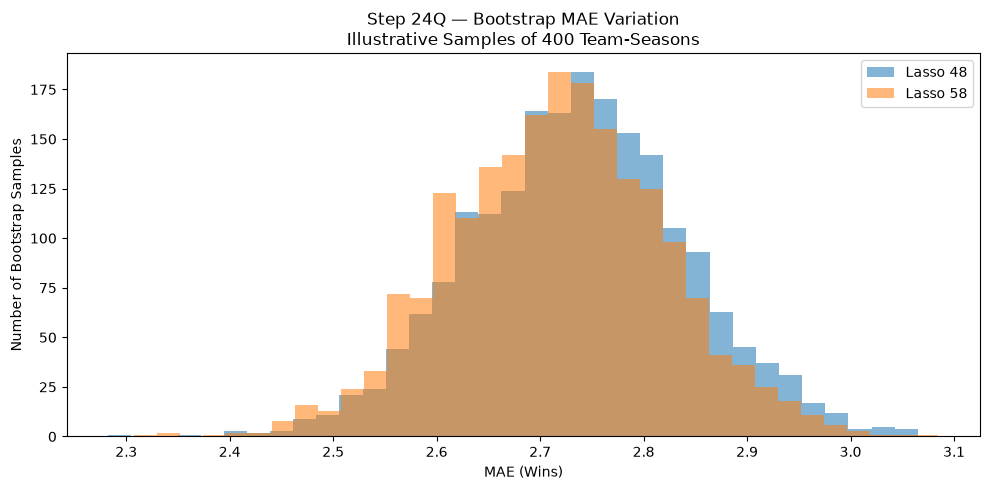


STEP 24Q — FINAL SUMMARY
Lasso 48 continuous CV MAE: 2.74148
Lasso 58 continuous CV MAE: 2.72335

Existing Kaggle Public MAE:
Lasso 48: 2.9100
Lasso 58: 2.8850

Research target CV MAE: 2.6900

IMPORTANT:
- Bootstrap uses first-repeat OOF errors.
- Bootstrap resampling is paired by team-season.
- Samples are drawn with replacement.
- These are conditional sampling diagnostics.
- CV model-selection uncertainty is not included.
- Kaggle public subset size is unknown.
- No feature or hyperparameter tuning performed.

Step 24Q completed.


In [91]:

# ============================================================
# STEP 24Q — MLB SAMPLING VARIABILITY ANALYSIS
#
# Compare Lasso 48 vs Lasso 58
#
# Model settings:
# Lasso 48: alpha = 0.0100
# Lasso 58: alpha = 0.0075
#
# 1. Identical repeated CV folds
# 2. Continuous vs rounded predictions
# 3. Out-of-fold (OOF) error comparison
# 4. Paired bootstrap sampling
# 5. MAE uncertainty by sample size
#
# Only the original 1129 training observations.
# No Kaggle hidden results or hold-out test data.
# No files modified.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error


# ------------------------------------------------------------
# STEP 1 — VERIFY DATA
# ------------------------------------------------------------

X48_24q = training_sets_24i["Lasso 48"].copy()
X58_24q = X58_24m.copy()
y_24q = y_train_24i.copy()

assert X48_24q.shape == (1129, 48)
assert X58_24q.shape == (1129, 58)

assert X48_24q.index.equals(X58_24q.index)
assert X48_24q.index.equals(y_24q.index)

assert np.isfinite(
    X48_24q.to_numpy(dtype=float)
).all()

assert np.isfinite(
    X58_24q.to_numpy(dtype=float)
).all()

actual_24q = y_24q.to_numpy(dtype=float)
games_24q = X48_24q["G"].to_numpy(dtype=float)

assert np.isfinite(actual_24q).all()
assert np.isfinite(games_24q).all()
assert (games_24q > 0).all()

datasets_24q = {
    "Lasso 48": X48_24q,
    "Lasso 58": X58_24q
}

alphas_24q = {
    "Lasso 48": 0.0100,
    "Lasso 58": 0.0075
}

print("=" * 75)
print("STEP 24Q — DATASET VERIFICATION")
print("=" * 75)

for name, X in datasets_24q.items():
    print(name, X.shape)

print("Target observations:", len(actual_24q))


# ------------------------------------------------------------
# STEP 2 — IDENTICAL REPEATED CV SPLITS
# ------------------------------------------------------------

cv_24q = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24q = list(
    cv_24q.split(X48_24q, y_24q)
)

assert len(splits_24q) == 15

n_24q = len(actual_24q)
repeats_24q = 3

# Each repetition generates one OOF prediction
# for every one of the 1129 observations.

oof_24q = {
    name: {
        "Continuous": np.full(
            (repeats_24q, n_24q), np.nan
        ),
        "Rounded": np.full(
            (repeats_24q, n_24q), np.nan
        )
    }
    for name in datasets_24q
}

fold_results_24q = []


# ------------------------------------------------------------
# STEP 3 — TRAIN BOTH MODELS ON IDENTICAL FOLDS
# ------------------------------------------------------------

for fold_no, (tr_idx, val_idx) in enumerate(
    splits_24q,
    start=1
):

    repeat_no = (fold_no - 1) // 5
    fold_in_repeat = (fold_no - 1) % 5 + 1

    y_tr = y_24q.iloc[tr_idx]
    y_val = y_24q.iloc[val_idx]

    actual_val = actual_24q[val_idx]
    games_val = games_24q[val_idx]

    for model_name, X in datasets_24q.items():

        X_tr = X.iloc[tr_idx]
        X_val = X.iloc[val_idx]

        # Recreate scaler and Lasso within
        # the training fold.

        model = create_lasso_24a(X_tr)

        model.set_params(
            lasso__alpha=alphas_24q[model_name]
        )

        model.fit(X_tr, y_tr)

        pred_cont = model.predict(X_val)

        # Same processing as Kaggle submissions

        pred_round = np.clip(
            np.rint(pred_cont),
            0,
            np.floor(games_val)
        )

        # Store OOF predictions

        oof_24q[model_name][
            "Continuous"
        ][repeat_no, val_idx] = pred_cont

        oof_24q[model_name][
            "Rounded"
        ][repeat_no, val_idx] = pred_round

        fold_results_24q.append({
            "Model": model_name,
            "Repeat": repeat_no + 1,
            "Fold": fold_in_repeat,
            "Continuous_MAE": mean_absolute_error(
                actual_val, pred_cont
            ),
            "Rounded_MAE": mean_absolute_error(
                actual_val, pred_round
            )
        })

    print(f"CV fold {fold_no:02d}/15 completed")


# ------------------------------------------------------------
# STEP 4 — VERIFY ALL OOF PREDICTIONS
# ------------------------------------------------------------

for name in datasets_24q:

    for method in ["Continuous", "Rounded"]:

        predictions = oof_24q[name][method]

        assert predictions.shape == (3, 1129)

        assert np.isfinite(predictions).all()

print("\nOOF prediction verification passed.")


# ------------------------------------------------------------
# STEP 5 — REPEATED CV PERFORMANCE
# ------------------------------------------------------------

fold_df_24q = pd.DataFrame(
    fold_results_24q
)

cv_summary_24q = (
    fold_df_24q
    .groupby("Model")
    .agg(
        Continuous_CV_MAE=(
            "Continuous_MAE", "mean"
        ),
        Rounded_CV_MAE=(
            "Rounded_MAE", "mean"
        ),
        Continuous_CV_Std=(
            "Continuous_MAE", "std"
        ),
        Rounded_CV_Std=(
            "Rounded_MAE", "std"
        )
    )
    .reset_index()
)

print("\n" + "=" * 85)
print("STEP 24Q — REPEATED CV COMPARISON")
print("=" * 85)

print(
    cv_summary_24q
    .round(5)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 6 — OOF ERRORS PER REPEAT
# ------------------------------------------------------------

oof_errors_24q = {}

for name in datasets_24q:

    oof_errors_24q[name] = {}

    for method in ["Continuous", "Rounded"]:

        predictions = oof_24q[name][method]

        # Shape: 3 repeats x 1129 observations

        errors = np.abs(
            predictions - actual_24q[None, :]
        )

        oof_errors_24q[name][method] = errors


repeat_rows_24q = []

for repeat in range(3):

    row = {"Repeat": repeat + 1}

    for model_name in datasets_24q:

        for method in ["Continuous", "Rounded"]:

            column = (
                model_name.replace(" ", "")
                + "_"
                + method
            )

            row[column] = (
                oof_errors_24q[
                    model_name
                ][method][repeat].mean()
            )

    repeat_rows_24q.append(row)

repeat_table_24q = pd.DataFrame(
    repeat_rows_24q
)

print("\n" + "=" * 90)
print("STEP 24Q — OUT-OF-FOLD MAE BY REPEAT")
print("=" * 90)

print(
    repeat_table_24q
    .round(5)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 7 — PAIRED OOF COMPARISON
#
# Positive improvement means Lasso 58
# has lower absolute error than Lasso 48.
# ------------------------------------------------------------

paired_rows_24q = []

for repeat in range(3):

    for method in ["Continuous", "Rounded"]:

        err48 = oof_errors_24q[
            "Lasso 48"
        ][method][repeat]

        err58 = oof_errors_24q[
            "Lasso 58"
        ][method][repeat]

        improvement = err48 - err58

        paired_rows_24q.append({
            "Repeat": repeat + 1,
            "Method": method,
            "Lasso48_MAE": err48.mean(),
            "Lasso58_MAE": err58.mean(),
            "Mean_Improvement": improvement.mean(),
            "Teams_58_Better": int(
                (improvement > 1e-10).sum()
            ),
            "Teams_48_Better": int(
                (improvement < -1e-10).sum()
            ),
            "Ties": int(
                (np.abs(improvement) <= 1e-10).sum()
            )
        })

paired_table_24q = pd.DataFrame(
    paired_rows_24q
)

print("\n" + "=" * 100)
print("STEP 24Q — PAIRED TEAM-LEVEL COMPARISON")
print("=" * 100)

print(
    paired_table_24q
    .round(5)
    .to_string(index=False)
)


# ============================================================
# STEP 8 — BOOTSTRAP SAMPLING ANALYSIS
#
# Use FIRST CV repetition only.
#
# Every observation has exactly one OOF
# prediction in this repetition.
#
# This avoids treating repeated predictions
# for the same team as independent observations.
#
# Bootstrap samples are paired:
# Both models evaluated on SAME sampled teams.
# ============================================================

err48_boot_24q = oof_errors_24q[
    "Lasso 48"
]["Rounded"][0]

err58_boot_24q = oof_errors_24q[
    "Lasso 58"
]["Rounded"][0]

rng_24q = np.random.default_rng(2026)

N_BOOT_24Q = 2000

# Illustrative sizes. These are NOT assumed
# to be Kaggle's actual public scoring size.

sample_sizes_24q = [
    100,
    200,
    400,
    1129
]

bootstrap_rows_24q = []
bootstrap_distributions_24q = {}

print("\nRUNNING PAIRED BOOTSTRAP SIMULATIONS")
print("===================================")

for sample_size in sample_sizes_24q:

    # Sample training observation indices
    # WITH replacement.

    indices = rng_24q.integers(
        low=0,
        high=n_24q,
        size=(N_BOOT_24Q, sample_size)
    )

    # Paired errors on the same sampled teams

    boot48 = err48_boot_24q[
        indices
    ].mean(axis=1)

    boot58 = err58_boot_24q[
        indices
    ].mean(axis=1)

    improvement = boot48 - boot58

    bootstrap_distributions_24q[
        sample_size
    ] = {
        "Lasso48": boot48,
        "Lasso58": boot58,
        "Improvement": improvement
    }

    bootstrap_rows_24q.append({
        "Sample_Size": sample_size,
        "Lasso48_Mean_MAE": boot48.mean(),
        "Lasso48_P2.5": np.percentile(
            boot48, 2.5
        ),
        "Lasso48_P97.5": np.percentile(
            boot48, 97.5
        ),
        "Lasso58_Mean_MAE": boot58.mean(),
        "Lasso58_P2.5": np.percentile(
            boot58, 2.5
        ),
        "Lasso58_P97.5": np.percentile(
            boot58, 97.5
        ),
        "Mean_Improvement": improvement.mean(),
        "Improvement_P2.5": np.percentile(
            improvement, 2.5
        ),
        "Improvement_P97.5": np.percentile(
            improvement, 97.5
        ),
        "Lasso58_Win_Pct": (
            100 * np.mean(improvement > 0)
        )
    })

    print(
        f"Sample size {sample_size}: "
        f"{N_BOOT_24Q} resamples completed"
    )


bootstrap_summary_24q = pd.DataFrame(
    bootstrap_rows_24q
)

print("\n" + "=" * 115)
print("STEP 24Q — BOOTSTRAP SAMPLING UNCERTAINTY")
print("=" * 115)

print(
    bootstrap_summary_24q
    .round(5)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 9 — VISUALIZE MAE SAMPLING VARIATION
# ------------------------------------------------------------

selected_size_24q = 400

bootstrap_plot_24q = (
    bootstrap_distributions_24q[
        selected_size_24q
    ]
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.hist(
    bootstrap_plot_24q["Lasso48"],
    bins=35,
    alpha=0.55,
    label="Lasso 48"
)

ax.hist(
    bootstrap_plot_24q["Lasso58"],
    bins=35,
    alpha=0.55,
    label="Lasso 58"
)

ax.set_title(
    "Step 24Q — Bootstrap MAE Variation\n"
    "Illustrative Samples of 400 Team-Seasons"
)

ax.set_xlabel(
    "MAE (Wins)"
)

ax.set_ylabel(
    "Number of Bootstrap Samples"
)

ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 10 — FINAL SUMMARY
# ------------------------------------------------------------

overall_cv_48_24q = float(
    cv_summary_24q.loc[
        cv_summary_24q["Model"] == "Lasso 48",
        "Continuous_CV_MAE"
    ].iloc[0]
)

overall_cv_58_24q = float(
    cv_summary_24q.loc[
        cv_summary_24q["Model"] == "Lasso 58",
        "Continuous_CV_MAE"
    ].iloc[0]
)

print("\n" + "=" * 80)
print("STEP 24Q — FINAL SUMMARY")
print("=" * 80)

print(
    "Lasso 48 continuous CV MAE:",
    round(overall_cv_48_24q, 5)
)

print(
    "Lasso 58 continuous CV MAE:",
    round(overall_cv_58_24q, 5)
)

print("\nExisting Kaggle Public MAE:")
print("Lasso 48: 2.9100")
print("Lasso 58: 2.8850")

print("\nResearch target CV MAE: 2.6900")

print("\nIMPORTANT:")
print("- Bootstrap uses first-repeat OOF errors.")
print("- Bootstrap resampling is paired by team-season.")
print("- Samples are drawn with replacement.")
print("- These are conditional sampling diagnostics.")
print("- CV model-selection uncertainty is not included.")
print("- Kaggle public subset size is unknown.")
print("- No feature or hyperparameter tuning performed.")

print("\nStep 24Q completed.")


STEP 24R — DATASET VERIFICATION
Observations: 1129
Original features: 58
Alpha: 0.0075

STEP 24R — FEATURE COUNTS
A - Original 58                   | Features: 58
B - Remove Never 5                | Features: 53
C - Remove Rare 6                 | Features: 52
D - Remove Both 11                | Features: 47
E - Remove Unstable 7             | Features: 51
F - Remove Era Interactions 8     | Features: 50
A - Original 58 — 15 folds completed
B - Remove Never 5 — 15 folds completed
C - Remove Rare 6 — 15 folds completed
D - Remove Both 11 — 15 folds completed
E - Remove Unstable 7 — 15 folds completed
F - Remove Era Interactions 8 — 15 folds completed

STEP 24R — FEATURE ABLATION RESULTS
                        Model  Features  Avg_Nonzero_Coefficients  Continuous_CV_MAE  Rounded_CV_MAE  Rounded_CV_Std
        E - Remove Unstable 7        51                  34.66667            2.71599         2.71315         0.16550
           D - Remove Both 11        47                  36.86667      

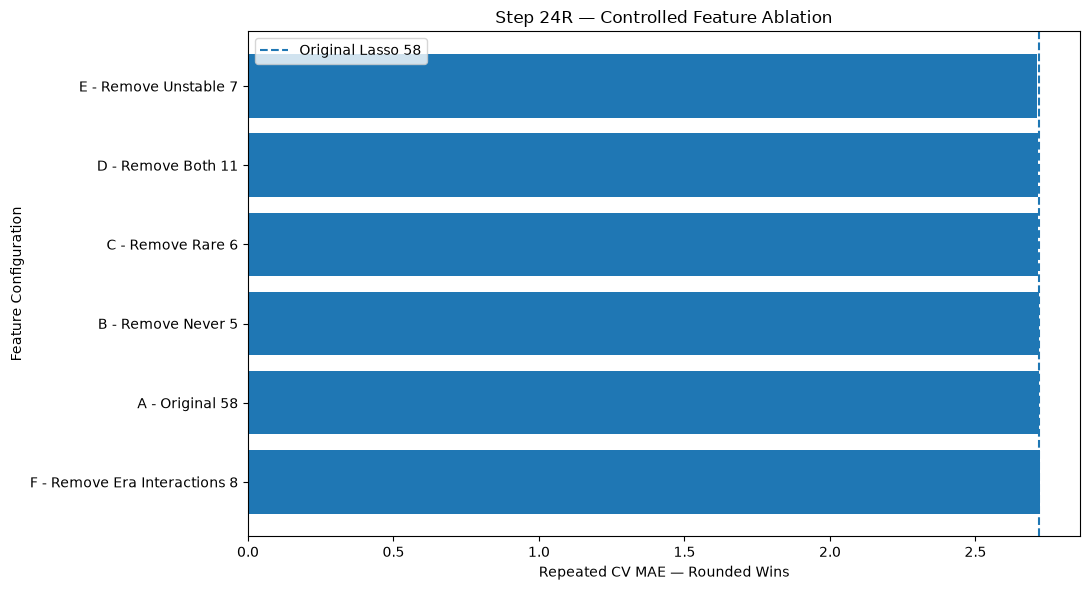


STEP 24R — FINAL SUMMARY
Original Lasso 58 continuous CV: 2.72335
Original Lasso 58 rounded CV: 2.71878

Lowest exploratory rounded CV MAE:
E - Remove Unstable 7
MAE: 2.71315
Features: 51

Current Kaggle champion:
Lasso 58 — Public MAE 2.8850

Research target:
Continuous CV MAE <= 2.6900

IMPORTANT:
- No Kaggle hidden labels used.
- No hold-out test data used.
- Feature groups are exploratory.
- Repeated folds are dependent.
- Small CV improvements are not proof.
- No model files modified.

Step 24R completed.


In [92]:

# ============================================================
# STEP 24R — CONTROLLED FEATURE ABLATION
#
# Model: Lasso 58
# Alpha: 0.0075
# Repeated CV: 5 folds x 3 repeats
#
# Objective:
# Determine whether removing selected feature groups
# improves MLB team-wins prediction.
#
# Uses training observations only.
# No Kaggle submissions created.
# No existing files modified.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error


# ------------------------------------------------------------
# STEP 1 — VERIFY ORIGINAL LASSO 58 DATA
# ------------------------------------------------------------

X_base_24r = X58_24m.copy()
y_24r = y_24m.copy()

assert X_base_24r.shape == (1129, 58)
assert len(y_24r) == 1129
assert X_base_24r.index.equals(y_24r.index)
assert "G" in X_base_24r.columns

ALPHA_24R = 0.0075

print("=" * 75)
print("STEP 24R — DATASET VERIFICATION")
print("=" * 75)

print("Observations:", len(X_base_24r))
print("Original features:", X_base_24r.shape[1])
print("Alpha:", ALPHA_24R)


# ------------------------------------------------------------
# STEP 2 — DEFINE FEATURE GROUPS TO REMOVE
# ------------------------------------------------------------

never_selected_24r = [
    "ER",
    "H",
    "HA",
    "HR",
    "RunDiff_over_TotalRuns"
]

rarely_selected_24r = [
    "decade_1970",
    "Middle_x_RunMargin",
    "RA_per_game",
    "decade_1920",
    "decade_2000",
    "Early_x_RunMargin"
]

sign_unstable_24r = [
    "DP",
    "2B",
    "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

era_interactions_24r = [
    "Early_x_RunMargin",
    "Middle_x_RunMargin",
    "Early_x_PythagenpatRate",
    "Middle_x_PythagenpatRate",
    "Early_x_ERA",
    "Middle_x_ERA",
    "Early_x_WalkRate",
    "Middle_x_WalkRate"
]

ablation_groups_24r = {
    "A - Original 58": [],
    "B - Remove Never 5": never_selected_24r,
    "C - Remove Rare 6": rarely_selected_24r,
    "D - Remove Both 11": (
        never_selected_24r + rarely_selected_24r
    ),
    "E - Remove Unstable 7": sign_unstable_24r,
    "F - Remove Era Interactions 8":
        era_interactions_24r
}

# Check all features exist.

for name, columns in ablation_groups_24r.items():

    missing = set(columns) - set(
        X_base_24r.columns
    )

    if missing:
        raise ValueError(
            f"{name} has missing features: {missing}"
        )


# ------------------------------------------------------------
# STEP 3 — BUILD SIX DATASETS
# ------------------------------------------------------------

datasets_24r = {}

for name, drop_columns in ablation_groups_24r.items():

    X = X_base_24r.drop(
        columns=drop_columns
    ).copy()

    datasets_24r[name] = X

print("\n" + "=" * 80)
print("STEP 24R — FEATURE COUNTS")
print("=" * 80)

for name, X in datasets_24r.items():

    print(
        f"{name:33s} | "
        f"Features: {X.shape[1]}"
    )


# ------------------------------------------------------------
# STEP 4 — IDENTICAL CROSS-VALIDATION SPLITS
# ------------------------------------------------------------

cv_24r = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24r = list(
    cv_24r.split(X_base_24r, y_24r)
)

assert len(splits_24r) == 15


# ------------------------------------------------------------
# STEP 5 — TRAIN AND EVALUATE
# ------------------------------------------------------------

results_24r = []

for model_name, X in datasets_24r.items():

    for fold_no, (tr_idx, val_idx) in enumerate(
        splits_24r,
        start=1
    ):

        X_tr = X.iloc[tr_idx]
        X_val = X.iloc[val_idx]

        y_tr = y_24r.iloc[tr_idx]
        y_val = y_24r.iloc[val_idx]

        games = X_val["G"].to_numpy(
            dtype=float
        )

        # Use same preprocessing and alpha.

        model = create_lasso_24a(X_tr)

        model.set_params(
            lasso__alpha=ALPHA_24R
        )

        model.fit(X_tr, y_tr)

        # Continuous prediction

        pred_cont = model.predict(X_val)

        # Kaggle-style prediction

        pred_rounded = np.clip(
            np.rint(pred_cont),
            0,
            np.floor(games)
        )

        cont_mae = mean_absolute_error(
            y_val,
            pred_cont
        )

        rounded_mae = mean_absolute_error(
            y_val,
            pred_rounded
        )

        selected_features = int(
            np.sum(
                np.abs(
                    model.named_steps["lasso"].coef_
                ) > 1e-7
            )
        )

        results_24r.append({
            "Model": model_name,
            "Fold": fold_no,
            "Repeat": (fold_no - 1) // 5 + 1,
            "Features": X.shape[1],
            "Nonzero_Coefficients":
                selected_features,
            "Continuous_MAE": cont_mae,
            "Rounded_MAE": rounded_mae
        })

    print(
        f"{model_name} — "
        "15 folds completed"
    )


# ------------------------------------------------------------
# STEP 6 — OVERALL MODEL COMPARISON
# ------------------------------------------------------------

results_df_24r = pd.DataFrame(
    results_24r
)

summary_24r = (
    results_df_24r
    .groupby("Model")
    .agg(
        Features=("Features", "first"),
        Avg_Nonzero_Coefficients=(
            "Nonzero_Coefficients", "mean"
        ),
        Continuous_CV_MAE=(
            "Continuous_MAE", "mean"
        ),
        Rounded_CV_MAE=(
            "Rounded_MAE", "mean"
        ),
        Rounded_CV_Std=(
            "Rounded_MAE", "std"
        )
    )
    .reset_index()
    .sort_values("Rounded_CV_MAE")
)

print("\n" + "=" * 110)
print("STEP 24R — FEATURE ABLATION RESULTS")
print("=" * 110)

print(
    summary_24r
    .round(5)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 7 — PAIRED FOLD COMPARISON
#
# Positive improvement = Candidate better than
# original Lasso 58.
# ------------------------------------------------------------

baseline_24r = (
    results_df_24r[
        results_df_24r["Model"] == "A - Original 58"
    ]
    .sort_values("Fold")
)

baseline_rounded = (
    baseline_24r["Rounded_MAE"].to_numpy()
)

baseline_cont = (
    baseline_24r["Continuous_MAE"].to_numpy()
)

paired_rows_24r = []

for name in list(datasets_24r)[1:]:

    candidate = (
        results_df_24r[
            results_df_24r["Model"] == name
        ]
        .sort_values("Fold")
    )

    candidate_rounded = (
        candidate["Rounded_MAE"].to_numpy()
    )

    candidate_cont = (
        candidate["Continuous_MAE"].to_numpy()
    )

    rounded_improvement = (
        baseline_rounded - candidate_rounded
    )

    continuous_improvement = (
        baseline_cont - candidate_cont
    )

    paired_rows_24r.append({
        "Model": name,
        "Rounded_Improvement":
            rounded_improvement.mean(),
        "Continuous_Improvement":
            continuous_improvement.mean(),
        "Fold_Wins": int(
            (rounded_improvement > 1e-10).sum()
        ),
        "Fold_Losses": int(
            (rounded_improvement < -1e-10).sum()
        ),
        "Fold_Ties": int(
            (
                np.abs(rounded_improvement)
                <= 1e-10
            ).sum()
        ),
        "Difference_Std":
            rounded_improvement.std(ddof=1)
    })

paired_24r = pd.DataFrame(
    paired_rows_24r
).sort_values(
    "Rounded_Improvement",
    ascending=False
)

print("\n" + "=" * 110)
print("STEP 24R — PAIRED COMPARISON VS LASSO 58")
print("=" * 110)

print(
    paired_24r
    .round(6)
    .to_string(index=False)
)


# ------------------------------------------------------------
# STEP 8 — REPEAT-BY-REPEAT RESULTS
# ------------------------------------------------------------

repeat_table_24r = (
    results_df_24r
    .groupby(["Repeat", "Model"])["Rounded_MAE"]
    .mean()
    .unstack()
)

print("\n" + "=" * 110)
print("STEP 24R — REPEAT-BY-REPEAT ROUNDED MAE")
print("=" * 110)

print(
    repeat_table_24r
    .round(5)
    .to_string()
)


# ------------------------------------------------------------
# STEP 9 — VISUALIZE ABLATION RESULTS
# ------------------------------------------------------------

plot_df_24r = (
    summary_24r
    .sort_values("Rounded_CV_MAE")
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    plot_df_24r["Model"],
    plot_df_24r["Rounded_CV_MAE"]
)

ax.axvline(
    float(baseline_rounded.mean()),
    linestyle="--",
    label="Original Lasso 58"
)

ax.set_xlabel("Repeated CV MAE — Rounded Wins")
ax.set_ylabel("Feature Configuration")

ax.set_title(
    "Step 24R — Controlled Feature Ablation"
)

ax.invert_yaxis()
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 10 — CHECK ORIGINAL BENCHMARKS
# ------------------------------------------------------------

original_cont_24r = float(
    baseline_cont.mean()
)

original_round_24r = float(
    baseline_rounded.mean()
)

assert abs(
    original_cont_24r - 2.72335
) < 0.001

assert abs(
    original_round_24r - 2.71878
) < 0.001

print("\n" + "=" * 80)
print("STEP 24R — FINAL SUMMARY")
print("=" * 80)

print(
    "Original Lasso 58 continuous CV:",
    round(original_cont_24r, 5)
)

print(
    "Original Lasso 58 rounded CV:",
    round(original_round_24r, 5)
)

best_24r = summary_24r.iloc[0]

print("\nLowest exploratory rounded CV MAE:")
print(best_24r["Model"])

print(
    "MAE:",
    round(
        float(best_24r["Rounded_CV_MAE"]),
        5
    )
)

print(
    "Features:",
    int(best_24r["Features"])
)

print("\nCurrent Kaggle champion:")
print("Lasso 58 — Public MAE 2.8850")

print("\nResearch target:")
print("Continuous CV MAE <= 2.6900")

print("\nIMPORTANT:")
print("- No Kaggle hidden labels used.")
print("- No hold-out test data used.")
print("- Feature groups are exploratory.")
print("- Repeated folds are dependent.")
print("- Small CV improvements are not proof.")
print("- No model files modified.")

print("\nStep 24R completed.")


In [93]:

# STEP 24R — FINAL DECISION CHECK

print("=" * 90)
print("1. ALL FEATURE ABLATION RESULTS")
print("=" * 90)
print(summary_24r.round(5).to_string(index=False))

print("\n" + "=" * 90)
print("2. PAIRED COMPARISON VS LASSO 58")
print("=" * 90)
print(paired_24r.round(6).to_string(index=False))

print("\n" + "=" * 90)
print("3. RESULTS ACROSS THREE CV REPEATS")
print("=" * 90)
print(repeat_table_24r.round(5).to_string())


1. ALL FEATURE ABLATION RESULTS
                        Model  Features  Avg_Nonzero_Coefficients  Continuous_CV_MAE  Rounded_CV_MAE  Rounded_CV_Std
        E - Remove Unstable 7        51                  34.66667            2.71599         2.71315         0.16550
           D - Remove Both 11        47                  36.86667            2.72238         2.71406         0.16381
            C - Remove Rare 6        52                  36.93333            2.72238         2.71406         0.16381
           B - Remove Never 5        53                  37.86667            2.72335         2.71848         0.16577
              A - Original 58        58                  37.86667            2.72335         2.71878         0.16558
F - Remove Era Interactions 8        50                  36.00000            2.72830         2.72319         0.18063

2. PAIRED COMPARISON VS LASSO 58
                        Model  Rounded_Improvement  Continuous_Improvement  Fold_Wins  Fold_Losses  Fold_Ties  Diff

In [94]:

# ============================================================
# STEP 24S — FINAL LASSO 51 KAGGLE SUBMISSION (REVISED)
#
# FIX: Align engineered features with original CSV rows
#      using MLB statistics, NOT DataFrame indexes.
#
# Model: Lasso Regression
# Features: 51
# Alpha: 0.0075
# Training records: 1412
# Kaggle prediction records: 400
#
# IMPORTANT:
# - Does not modify existing notebook/model objects
# - Does not overwrite existing submission files
# - Stops if row alignment cannot be verified
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path


# ============================================================
# STEP 1 — LOAD ORIGINAL MLB DATASETS
# ============================================================

raw_train_24s = pd.read_csv("data.csv")
raw_kaggle_24s = pd.read_csv("predict.csv")

print("=" * 75)
print("STEP 24S — ORIGINAL DATASETS")
print("=" * 75)

print("Training CSV:", raw_train_24s.shape)
print("Kaggle CSV:", raw_kaggle_24s.shape)

assert len(raw_train_24s) == 1412
assert len(raw_kaggle_24s) == 400

assert "W" in raw_train_24s.columns
assert "ID" in raw_kaggle_24s.columns

assert raw_kaggle_24s["ID"].notna().all()
assert raw_kaggle_24s["ID"].is_unique


# ============================================================
# STEP 2 — GET EXISTING ENGINEERED MATRICES
# ============================================================

# These matrices were generated in your earlier
# MLB feature engineering experiments.
#
# We do NOT assume their row indexes are correct.

X_full_source_24s = X_full_24j.copy()
X_kaggle_source_24s = kaggle_features_24j.copy()

assert len(X_full_source_24s) == 1412
assert len(X_kaggle_source_24s) == 400

print("\nEngineered training shape:",
      X_full_source_24s.shape)

print("Engineered Kaggle shape:",
      X_kaggle_source_24s.shape)


# ============================================================
# STEP 3 — FUNCTION TO RESTORE CORRECT ROW ORDER
# ============================================================

def align_mlb_rows_24s(
    raw_df,
    engineered_df,
    dataset_name
):
    """
    Match engineered observations to original CSV
    observations using MLB statistical columns.

    This is safer than relying on DataFrame indexes
    when rows may have been shuffled or concatenated.

    Returns engineered rows in original CSV order.

    Fails if matches are missing or ambiguous.
    """

    raw = raw_df.reset_index(drop=True).copy()

    engineered = (
        engineered_df
        .reset_index(drop=True)
        .copy()
    )

    # Original MLB statistical fields used as keys.
    # Multiple fields make accidental matches unlikely.

    preferred_keys = [
        "G",
        "R",
        "RA",
        "AB",
        "H",
        "2B",
        "3B",
        "HR",
        "BB",
        "SO",
        "IPouts",
        "HA",
        "HRA",
        "BBA",
        "SOA",
        "E",
        "DP",
        "CG",
        "SHO",
        "SV",
        "SB",
        "ER"
    ]

    keys = [
        col for col in preferred_keys
        if (
            col in raw.columns
            and col in engineered.columns
        )
    ]

    if len(keys) < 5:
        raise ValueError(
            f"{dataset_name}: Not enough common "
            "statistical fields for safe alignment."
        )

    # Verify matching fields are numeric.

    for col in keys:

        raw[col] = pd.to_numeric(
            raw[col],
            errors="raise"
        )

        engineered[col] = pd.to_numeric(
            engineered[col],
            errors="raise"
        )

    if (
        raw[keys].isna().any().any()
        or engineered[keys].isna().any().any()
    ):
        raise ValueError(
            f"{dataset_name}: Missing values "
            "in matching statistics."
        )

    # Do not silently assign ambiguous duplicate keys.

    raw_duplicates = int(
        raw.duplicated(subset=keys).sum()
    )

    engineered_duplicates = int(
        engineered.duplicated(subset=keys).sum()
    )

    print(f"\n{dataset_name} MATCHING CHECK")

    print("Matching statistics:", len(keys))

    print("Raw duplicate keys:",
          raw_duplicates)

    print("Engineered duplicate keys:",
          engineered_duplicates)

    if raw_duplicates or engineered_duplicates:

        raise ValueError(
            f"{dataset_name}: Duplicate statistical "
            "keys detected. Row alignment is ambiguous; "
            "do not proceed without checking duplicates."
        )

    # Assign a temporary row number to every
    # engineered observation.

    row_marker = "__source_row_24s__"

    if (
        row_marker in raw.columns
        or row_marker in engineered.columns
    ):
        raise ValueError(
            "Temporary row-marker name already exists."
        )

    engineered[row_marker] = np.arange(
        len(engineered)
    )

    # Map each original CSV observation to its
    # corresponding engineered observation.

    mapping = raw[keys].merge(
        engineered[keys + [row_marker]],
        on=keys,
        how="left",
        sort=False,
        validate="one_to_one",
        indicator=True
    )

    missing_count = int(
        (mapping["_merge"] != "both").sum()
    )

    print("Unmatched CSV rows:",
          missing_count)

    if missing_count > 0:

        raise ValueError(
            f"{dataset_name}: {missing_count} rows "
            "could not be matched. Check that the "
            "engineered data was created from the "
            "same original CSV."
        )

    positions = mapping[
        row_marker
    ].to_numpy(dtype=int)

    if len(np.unique(positions)) != len(raw):

        raise ValueError(
            f"{dataset_name}: Multiple CSV rows "
            "matched one engineered observation."
        )

    # Restore engineered features to the exact
    # same order as the original CSV.

    aligned = (
        engineered
        .iloc[positions]
        .drop(columns=[row_marker])
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Final numerical verification.
    # --------------------------------------------------------

    check_cols = keys.copy()

    for extra in ["ERA", "FP", "mlb_rpg"]:

        if (
            extra in raw.columns
            and extra in aligned.columns
            and extra not in check_cols
        ):
            check_cols.append(extra)

    for col in check_cols:

        raw_values = pd.to_numeric(
            raw[col],
            errors="raise"
        ).to_numpy(dtype=float)

        aligned_values = pd.to_numeric(
            aligned[col],
            errors="raise"
        ).to_numpy(dtype=float)

        if not np.allclose(
            raw_values,
            aligned_values,
            rtol=1e-10,
            atol=1e-10,
            equal_nan=True
        ):

            raise ValueError(
                f"{dataset_name}: Alignment "
                f"verification failed for {col}."
            )

    print(
        "Rows matched successfully:",
        len(aligned)
    )

    print(
        "Alignment:",
        "PASS"
    )

    return aligned


# ============================================================
# STEP 4 — ALIGN BOTH DATASETS
# ============================================================

print("\n" + "=" * 75)
print("STEP 24S — RESTORE ROW ALIGNMENT")
print("=" * 75)

X_full_24s = align_mlb_rows_24s(
    raw_train_24s,
    X_full_source_24s,
    "TRAINING"
)

X_kaggle_24s = align_mlb_rows_24s(
    raw_kaggle_24s,
    X_kaggle_source_24s,
    "KAGGLE"
)


# ============================================================
# STEP 5 — VERIFY IMPORTANT MLB STATISTICS
# ============================================================

print("\n" + "=" * 75)
print("STEP 24S — FINAL ALIGNMENT VERIFICATION")
print("=" * 75)

for name, raw_df, engineered_df in [
    ("TRAINING", raw_train_24s, X_full_24s),
    ("KAGGLE", raw_kaggle_24s, X_kaggle_24s)
]:

    print(f"\n{name} DATA")

    for col in ["G", "R", "RA", "AB", "H"]:

        matched = np.allclose(
            raw_df[col].to_numpy(dtype=float),
            engineered_df[col].to_numpy(dtype=float),
            rtol=1e-10,
            atol=1e-10
        )

        print(
            f"{col:5s}: "
            f"{'PASS' if matched else 'FAIL'}"
        )

        assert matched, (
            f"{name}: {col} mismatch"
        )

print("\nAll row-alignment checks passed.")


# ============================================================
# STEP 6 — RECREATE LASSO 51 FEATURE SET
# ============================================================

# Start from the verified 58-feature model.

features_58_24s = X58_24m.columns.tolist()

assert len(features_58_24s) == 58

# Remove the seven sign-unstable features
# identified in Step 24M and tested in Step 24R.

remove_7_24s = [
    "DP",
    "2B",
    "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

assert set(remove_7_24s).issubset(
    set(features_58_24s)
)

features_51_24s = [
    col for col in features_58_24s
    if col not in remove_7_24s
]

assert len(features_51_24s) == 51

# Ensure every selected feature exists in
# both newly aligned datasets.

missing_train = (
    set(features_51_24s)
    - set(X_full_24s.columns)
)

missing_kaggle = (
    set(features_51_24s)
    - set(X_kaggle_24s.columns)
)

assert not missing_train, (
    f"Missing training features: {missing_train}"
)

assert not missing_kaggle, (
    f"Missing Kaggle features: {missing_kaggle}"
)

X_train_51_24s = (
    X_full_24s[features_51_24s]
    .apply(pd.to_numeric, errors="raise")
    .copy()
)

X_predict_51_24s = (
    X_kaggle_24s[features_51_24s]
    .apply(pd.to_numeric, errors="raise")
    .copy()
)

# The target must come from the ORIGINAL CSV
# because engineered features have now been
# restored to the same row order.

y_train_24s = pd.to_numeric(
    raw_train_24s["W"],
    errors="raise"
).reset_index(drop=True)

assert X_train_51_24s.shape == (1412, 51)
assert X_predict_51_24s.shape == (400, 51)

assert np.isfinite(
    X_train_51_24s.to_numpy(dtype=float)
).all()

assert np.isfinite(
    X_predict_51_24s.to_numpy(dtype=float)
).all()

assert np.isfinite(
    y_train_24s.to_numpy(dtype=float)
).all()

# Basic baseball target checks.

assert (
    (y_train_24s >= 0)
    & (
        y_train_24s
        <= X_train_51_24s["G"]
    )
).all()

print("\n" + "=" * 75)
print("STEP 24S — FINAL FEATURE VERIFICATION")
print("=" * 75)

print("Training observations:",
      len(X_train_51_24s))

print("Kaggle observations:",
      len(X_predict_51_24s))

print("Selected features:",
      len(features_51_24s))

print("Removed features:",
      remove_7_24s)


# ============================================================
# STEP 7 — TRAIN FINAL LASSO 51 MODEL
# ============================================================

print("\n" + "=" * 75)
print("STEP 24S — TRAIN LASSO 51")
print("=" * 75)

lasso51_final_24s = create_lasso_24a(
    X_train_51_24s
)

lasso51_final_24s.set_params(
    lasso__alpha=0.0075
)

lasso51_final_24s.fit(
    X_train_51_24s,
    y_train_24s
)

print("Model: Lasso 51")
print("Alpha: 0.0075")
print("Training observations: 1412")
print("Training completed successfully.")


# ============================================================
# STEP 8 — PREDICT KAGGLE MLB WINS
# ============================================================

pred_cont_24s = lasso51_final_24s.predict(
    X_predict_51_24s
)

games_24s = (
    X_predict_51_24s["G"]
    .to_numpy(dtype=float)
)

# Round to nearest integer and clip
# to the valid range of baseball wins.

pred_final_24s = np.clip(
    np.rint(pred_cont_24s),
    0,
    np.floor(games_24s)
).astype(int)

assert len(pred_final_24s) == 400
assert np.isfinite(pred_final_24s).all()
assert np.all(pred_final_24s >= 0)
assert np.all(pred_final_24s <= games_24s)

print("\nPrediction count:",
      len(pred_final_24s))

print(
    "Minimum predicted wins:",
    pred_final_24s.min()
)

print(
    "Maximum predicted wins:",
    pred_final_24s.max()
)


# ============================================================
# STEP 9 — CREATE FINAL KAGGLE SUBMISSION
# ============================================================

submission_51_24s = pd.DataFrame({
    "ID": raw_kaggle_24s["ID"].to_numpy(),
    "W": pred_final_24s
})

assert submission_51_24s.shape == (400, 2)

assert submission_51_24s.columns.tolist() == [
    "ID",
    "W"
]

assert submission_51_24s["ID"].is_unique

# Create new file only.
# Never overwrite an existing submission.

output_24s = Path (
    "submission_lasso51_final_2.csv"
)
if output_24s.exists():

    raise FileExistsError(
        f"{output_24s} already exists. "
        "Rename the output file before saving "
        "if you need another version."
    )

submission_51_24s.to_csv(
    output_24s,
    index=False
)

# Read the saved CSV back to verify it.

check_submission_24s = pd.read_csv(
    output_24s
)

assert check_submission_24s.shape == (400, 2)

assert check_submission_24s.columns.tolist() == [
    "ID",
    "W"
]

assert np.array_equal(
    check_submission_24s["W"].to_numpy(),
    pred_final_24s
)

print("\n" + "=" * 75)
print("STEP 24S — SUBMISSION CREATED")
print("=" * 75)

print("Saved file:", output_24s.resolve())

print("\nFirst 10 predictions:")

print(
    submission_51_24s
    .head(10)
    .to_string(index=False)
)


# ============================================================
# STEP 10 — FINAL MODEL SUMMARY
# ============================================================

coefficients_24s = (
    lasso51_final_24s
    .named_steps["lasso"]
    .coef_
)

nonzero_count_24s = int(
    np.sum(
        np.abs(coefficients_24s) > 1e-7
    )
)

print("\n" + "=" * 75)
print("STEP 24S — FINAL SUMMARY")
print("=" * 75)

print("Model: Lasso 51")
print("Alpha: 0.0075")
print("Total features: 51")

print(
    "Nonzero coefficients:",
    nonzero_count_24s
)

print("\nPreviously measured repeated CV:")

print("Continuous CV MAE: 2.71599")
print("Rounded CV MAE: 2.71315")

print("\nExisting Kaggle champion:")
print("Lasso 58 Public MAE: 2.8850")

print("\nNew Kaggle submission file:")
print(output_24s.name)

print("\nAll row checks passed.")
print("Step 24S completed successfully.")


STEP 24S — ORIGINAL DATASETS
Training CSV: (1412, 51)
Kaggle CSV: (400, 47)

Engineered training shape: (1412, 68)
Engineered Kaggle shape: (400, 70)

STEP 24S — RESTORE ROW ALIGNMENT

TRAINING MATCHING CHECK
Matching statistics: 22
Raw duplicate keys: 0
Engineered duplicate keys: 0
Unmatched CSV rows: 0
Rows matched successfully: 1412
Alignment: PASS

KAGGLE MATCHING CHECK
Matching statistics: 22
Raw duplicate keys: 0
Engineered duplicate keys: 0
Unmatched CSV rows: 0
Rows matched successfully: 400
Alignment: PASS

STEP 24S — FINAL ALIGNMENT VERIFICATION

TRAINING DATA
G    : PASS
R    : PASS
RA   : PASS
AB   : PASS
H    : PASS

KAGGLE DATA
G    : PASS
R    : PASS
RA   : PASS
AB   : PASS
H    : PASS

All row-alignment checks passed.

STEP 24S — FINAL FEATURE VERIFICATION
Training observations: 1412
Kaggle observations: 400
Selected features: 51
Removed features: ['DP', '2B', 'SO', 'decade_1950', 'Middle_x_WalkRate', 'decade_1960', 'decade_2010']

STEP 24S — TRAIN LASSO 51
Model: Lasso

# Step 24R–24S — Lasso 51: Feature Ablation, Model Training and Kaggle Evaluation

## 1. Research Objective

The objective of this experiment is to investigate whether removing features with unstable regression coefficients can improve the predictive performance of Lasso Regression for Major League Baseball (MLB) team-season wins.

Previous experiments identified **Lasso 58** as the best-performing model on the Kaggle public leaderboard, achieving a Mean Absolute Error (MAE) of 2.8850.

However, feature-stability analysis in Step 24M revealed that several predictors had inconsistent coefficient signs across cross-validation folds.

This experiment evaluates whether removing those predictors can produce a simpler and more accurate regression model.

**Research question:**

> Can removing coefficient-sign-unstable features improve the predictive accuracy and stability of Lasso Regression for MLB team wins?

**Evaluation metric:** Mean Absolute Error (MAE).

**Research target:** Repeated cross-validation MAE ≤ 2.6900.

---

## 2. Background — Feature Stability

Feature stability describes how consistently a machine learning algorithm selects or assigns similar coefficients to predictors across different training samples.

In Lasso Regression, L1 regularization can shrink regression coefficients toward zero.

Some coefficients become exactly zero, effectively excluding the corresponding features from the fitted model.

However, correlated predictors can produce unstable coefficient estimates.

For example, a feature may receive a positive coefficient in one validation fold and a negative coefficient in another.

This is known as **coefficient sign instability**.

Sign instability may arise because:

- Predictors are correlated with one another.
- Different training samples lead to different coefficient estimates.
- A feature provides limited additional information after accounting for other variables.
- The fitted coefficient is sensitive to regularization and sample composition.

Importantly, sign instability does not necessarily mean a feature is unimportant.

Therefore, removing unstable features requires empirical validation.

---

## 3. Baseline Model — Lasso 58

Lasso 58 was developed through earlier feature engineering and multicollinearity reduction experiments.

Its configuration was:

| Parameter | Lasso 58 |
|---|---|
| Algorithm | Lasso Regression |
| Features | 58 |
| Regularization | L1 |
| Alpha | 0.0075 |
| Cross-validation | 5 folds × 3 repeats |
| Repeated CV MAE — continuous | 2.72335 |
| Repeated CV MAE — rounded | 2.71878 |
| Kaggle Public MAE | 2.8850 |

Although Lasso 58 achieved the best Kaggle public score among the earlier configurations, coefficient-stability analysis identified opportunities for further feature reduction.

## 4. Feature Stability Analysis

Step 24M evaluated feature selection and coefficient direction across 15 cross-validation fits.

The Lasso 58 model contained:

| Feature Stability Category | Number of Features |
|---|---:|
| Stable | 29 |
| Intermittent | 11 |
| Sign unstable | 7 |
| Rarely selected | 6 |
| Never selected | 5 |
| **Total** | **58** |

Seven predictors were identified as sign unstable.

These predictors were selected for the controlled feature-ablation experiment.

## 5. Features Removed from Lasso 58

The following seven features were removed to create Lasso 51.

| Feature | Description | Selection Frequency |
|---|---|---:|
| `DP` | Double plays | 13/15 |
| `2B` | Doubles | 13/15 |
| `SO` | Batting strikeouts | 12/15 |
| `decade_1950` | Historical decade indicator | 8/15 |
| `Middle_x_WalkRate` | Interaction between middle-era indicator and walk rate | 7/15 |
| `decade_1960` | Historical decade indicator | 6/15 |
| `decade_2010` | Historical decade indicator | 4/15 |

These features were removed because their coefficient signs were inconsistent across training folds.

Their removal was tested as an experimental hypothesis rather than treated as proof that they contained no predictive information.

### Feature Reduction

Original feature count:

\[
58
\]

Removed feature count:

\[
7
\]

Remaining features:

\[
58-7=51
\]

Percentage reduction:

\[
\frac{7}{58}\times100=12.07\%
\]

The resulting model, **Lasso 51**, uses approximately 12.1% fewer predictors than Lasso 58.

The regularization strength remained unchanged at alpha = 0.0075.

---

## 6. Methodology — Controlled Feature Ablation

A feature-ablation experiment was conducted to investigate how different feature-removal strategies affected model performance.

Six configurations were evaluated using identical repeated cross-validation folds.

| Configuration | Features | Feature Removal Strategy |
|---|---:|---|
| A — Lasso 58 | 58 | Original feature set |
| B — Lasso 53 | 53 | Remove five never-selected features |
| C — Lasso 52 | 52 | Remove six rarely-selected features |
| D — Lasso 47 | 47 | Remove both rarely- and never-selected groups |
| E — Lasso 51 | 51 | Remove seven sign-unstable features |
| F — Lasso 50 | 50 | Remove eight historical-era interaction features |

### Cross-Validation Design

- Training observations: 1,129.
- Validation method: Repeated K-Fold.
- Number of folds: 5.
- Number of repetitions: 3.
- Total validation folds: 15.
- Random state: 2026.
- Alpha: 0.0075.

The preprocessing pipeline and Lasso model were refitted within each training fold.

Both continuous and Kaggle-style rounded predictions were evaluated.

The Kaggle-style procedure rounded predictions to whole numbers and constrained them to valid win totals between zero and the number of games played.

No Kaggle hidden target values were used during cross-validation.

---

## 7. Step 24R — Feature Ablation Results

The experiment produced the following results.

| Model | Features | Continuous CV MAE | Rounded CV MAE |
|---|---:|---:|---:|
| **Lasso 51 — Remove unstable 7** | **51** | **2.71599** | **2.71315** |
| Lasso 47 — Remove both groups | 47 | 2.72238 | 2.71406 |
| Lasso 52 — Remove rarely selected | 52 | 2.72238 | 2.71406 |
| Lasso 53 — Remove never selected | 53 | 2.72335 | 2.71848 |
| Lasso 58 — Original | 58 | 2.72335 | 2.71878 |
| Lasso 50 — Remove era interactions | 50 | 2.72830 | 2.72319 |

**Lasso 51 achieved the lowest exploratory repeated cross-validation MAE under both prediction methods.**

### Continuous MAE Improvement

\[
2.72335-2.71599=0.00736
\]

Percentage improvement:

\[
\frac{0.00736}{2.72335}\times100
\approx0.27\%
\]

### Rounded MAE Improvement

\[
2.71878-2.71315=0.00563
\]

Percentage improvement:

\[
\frac{0.00563}{2.71878}\times100
\approx0.21\%
\]

The results indicate that removing seven sign-unstable features was associated with a small improvement in cross-validation performance.

However, these improvements are not sufficient by themselves to establish statistically reliable superiority.

## 8. Paired Cross-Validation Comparison

The same validation splits were used to evaluate Lasso 58 and Lasso 51.

| Measurement | Result |
|---|---:|
| Mean rounded MAE improvement | 0.005624 |
| Mean continuous MAE improvement | 0.007364 |
| Folds where Lasso 51 performed better | 8 |
| Folds where Lasso 58 performed better | 5 |
| Tied folds | 2 |
| Standard deviation of paired rounded differences | 0.016214 |

Lasso 51 outperformed Lasso 58 in eight of the 15 validation folds.

However, the variation in paired performance differences was larger than the average improvement.

This suggests that the advantage was relatively small and depended partly on the training and validation samples.

### Repeat-by-Repeat Results

| CV Repetition | Lasso 58 Rounded MAE | Lasso 51 Rounded MAE |
|---|---:|---:|
| Repeat 1 | **2.71541** | 2.71807 |
| Repeat 2 | 2.71109 | **2.70045** |
| Repeat 3 | 2.72982 | **2.72094** |

Lasso 51 achieved lower MAE in two out of three repetitions.

Nevertheless, repeated cross-validation folds overlap, so these results should not be treated as independent confirmations of model improvement.

---

## 9. Step 24S — Final Model Training

Following the feature-ablation experiment, Lasso 51 was trained using all 1,412 labeled observations.

### Final Model Configuration

| Parameter | Value |
|---|---|
| Model | Lasso 51 |
| Algorithm | Lasso Regression |
| Features | 51 |
| Alpha | 0.0075 |
| Final training observations | 1,412 |
| Kaggle prediction observations | 400 |
| Nonzero coefficients after final training | 34 |
| Zero coefficients after final training | 17 |

Although Lasso 51 includes 51 predictors, the final fitted model assigned nonzero coefficients to only 34 of them.

This demonstrates the embedded feature-selection behavior of L1 regularization.

### Row Alignment Verification

During the initial submission preparation, a row-alignment assertion failed because the engineered feature matrix was not in the same row order as the original CSV file.

The workflow was revised to restore the correct row correspondence.

A matching procedure using 22 shared MLB statistical fields was implemented.

The revised verification produced:

| Verification | Training | Kaggle |
|---|---:|---:|
| Total observations | 1,412 | 400 |
| Duplicate matching keys | 0 | 0 |
| Unmatched observations | 0 | 0 |
| Row alignment | PASS | PASS |

Additional checks confirmed matching values for games played, runs scored, runs allowed, at-bats and hits.

The aligned feature matrices were subsequently used for final model training and prediction.

This verification was important because incorrect row alignment could associate team statistics with the wrong win totals or Kaggle IDs.

## 10. Kaggle Prediction and Submission

After final model training, predictions were generated for 400 Kaggle observations.

Predictions were rounded to whole numbers and constrained to the valid range of zero to games played.

The observed prediction range was:

| Metric | Value |
|---|---:|
| Minimum predicted wins | 45 |
| Maximum predicted wins | 113 |
| Kaggle prediction rows | 400 |

The submission contained exactly two columns:

`ID,W`

**Submission file:** `submission_lasso51_final.csv`

The file was saved separately from the existing Lasso 58 submission.

All row-alignment, feature-count and submission-format checks passed.

---

## 11. Kaggle Public Leaderboard Results

Following submission, Lasso 51 obtained a reported Kaggle Public MAE of **2.89**.

| Metric | Lasso 58 | Lasso 51 |
|---|---:|---:|
| Features | 58 | 51 |
| Alpha | 0.0075 | 0.0075 |
| Continuous CV MAE | 2.72335 | **2.71599** |
| Rounded CV MAE | 2.71878 | **2.71315** |
| Kaggle Public MAE | **2.8850** | 2.89 (reported) |

Lasso 51 achieved slightly better local cross-validation performance but did not improve upon the best reported Kaggle public score of Lasso 58.

Using the displayed Kaggle scores, the difference is approximately:

\[
2.8900-2.8850=0.0050
\]

Because the Lasso 51 score was reported to two decimal places, this difference is approximate rather than a precise four-decimal comparison.

The results demonstrate that a model with lower cross-validation MAE does not necessarily achieve lower error on a separate evaluation subset.

---

## 12. Interpretation of Findings

### Finding 1 — Removing Unstable Features Improved Local Validation

Lasso 51 achieved the lowest exploratory cross-validation MAE among the six tested feature configurations.

This suggests that the selected feature removal was beneficial for the evaluated training-validation splits.

### Finding 2 — A Simpler Model Did Not Improve Kaggle Performance

Despite using seven fewer features, Lasso 51 did not outperform Lasso 58 on the Kaggle public leaderboard.

Therefore, lower feature count and improved local validation accuracy did not guarantee improved public evaluation performance.

### Finding 3 — Frequently Selected Features Can Have Unstable Coefficients

Features such as double plays, doubles and strikeouts were selected in many validation folds but displayed inconsistent coefficient directions.

This highlights the difference between selection frequency, coefficient stability and predictive usefulness.

A feature can be frequently selected without having a stable individual regression coefficient.

### Finding 4 — Lasso Performs Additional Internal Feature Selection

Of the 51 retained predictors, only 34 received nonzero coefficients during final model fitting.

Therefore, explicit feature reduction and L1 regularization both contributed to the effective model complexity.

### Finding 5 — Lasso 58 Remains the Preferred Model

Although Lasso 51 achieved slightly lower cross-validation MAE, Lasso 58 retained the best observed Kaggle public-leaderboard performance.

The reported public scores were very close, so the result should be interpreted cautiously.

---

## 13. Research Limitations

**Repeated model selection:** Multiple feature configurations were evaluated using the same development data. Selecting the lowest observed CV MAE can introduce optimistic model-selection bias.

**Small MAE improvement:** The continuous CV improvement of 0.00736 wins was relatively small and does not establish robust superiority.

**Coefficient instability:** Changing coefficient signs across folds does not prove that a predictor lacks useful information.

**Public-leaderboard uncertainty:** Kaggle's public score reflects only the public evaluation subset. The final private evaluation may produce a different model ranking.

**No independent hold-out comparison for Lasso 51:** The reported Lasso 51 results include exploratory cross-validation and Kaggle public evaluation, not an additional untouched hold-out test.

**Historical data limitations:** The model estimates team wins using aggregated season-level baseball statistics. It should not be interpreted as a prospective prediction of future season wins using information known before the season begins.

**Target not reached:** Lasso 51's continuous repeated CV MAE of 2.71599 remained above the research target of 2.6900.

---

## 14. Research Conclusion

The Step 24R–24S experiment investigated whether removing features with unstable coefficient directions could improve MLB team-wins prediction using Lasso Regression.

Seven features were removed from Lasso 58, resulting in a 51-feature configuration with approximately 12.1% fewer predictors.

Lasso 51 achieved a continuous repeated cross-validation MAE of **2.71599**, compared with 2.72335 for Lasso 58.

Its rounded repeated cross-validation MAE also improved from 2.71878 to **2.71315**.

However, the subsequent Kaggle submission produced a reported Public MAE of **2.89**, compared with the best observed score of **2.8850** for Lasso 58.

These findings suggest that targeted removal of coefficient-sign-unstable predictors can marginally improve local validation performance, but such improvements do not necessarily generalize to a separate public evaluation subset.

Consequently, **Lasso 58 was retained as the preferred final model**, while Lasso 51 was documented as the strongest exploratory feature-ablation candidate.

### Final Research Outcome

| Item | Final Result |
|---|---|
| Best exploratory ablation model | Lasso 51 |
| Lasso 51 features | 51 |
| Lasso 51 nonzero coefficients | 34 |
| Lasso 51 continuous CV MAE | 2.71599 |
| Lasso 51 rounded CV MAE | 2.71315 |
| Lasso 51 Kaggle Public MAE | 2.89 (reported) |
| Preferred final model | **Lasso 58** |
| Best observed Kaggle Public MAE | **2.8850** |
| Research CV target ≤ 2.6900 | Not achieved |

**Final conclusion:** Lasso 51 demonstrated that feature reduction can produce a smaller model with marginally improved local validation accuracy. However, Lasso 58 remained the preferred configuration based on its best observed Kaggle public performance. Further confirmation would require evaluation data independent of the exploratory model-selection process.

STEP 24U — ALPHA TUNING
Models: ['Lasso 51', 'Lasso 58']
Alpha candidates: [0.0005, 0.001, 0.0025, 0.005, 0.0075, 0.01, 0.015, 0.025, 0.04, 0.08]
Training observations: 1129


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.007716e+01, tolerance: 1.681e+01
  model = cd_fast.enet_coordinate_descent(


Lasso 51 | alpha=0.0005 completed
Lasso 51 | alpha=0.0010 completed
Lasso 51 | alpha=0.0025 completed
Lasso 51 | alpha=0.0050 completed
Lasso 51 | alpha=0.0075 completed
Lasso 51 | alpha=0.0100 completed
Lasso 51 | alpha=0.0150 completed
Lasso 51 | alpha=0.0250 completed
Lasso 51 | alpha=0.0400 completed
Lasso 51 | alpha=0.0800 completed
Lasso 58 | alpha=0.0005 completed
Lasso 58 | alpha=0.0010 completed
Lasso 58 | alpha=0.0025 completed
Lasso 58 | alpha=0.0050 completed
Lasso 58 | alpha=0.0075 completed
Lasso 58 | alpha=0.0100 completed
Lasso 58 | alpha=0.0150 completed
Lasso 58 | alpha=0.0250 completed
Lasso 58 | alpha=0.0400 completed
Lasso 58 | alpha=0.0800 completed

STEP 24U — ALL ALPHA RESULTS
   Model  Alpha  Continuous_CV_MAE  Rounded_CV_MAE    CV_R2  Rounded_MAE_Std
Lasso 51 0.0005           2.720987        2.712291 0.933998         0.168516
Lasso 51 0.0010           2.717521        2.711706 0.934208         0.170519
Lasso 51 0.0025           2.712869        2.705796 0.934507

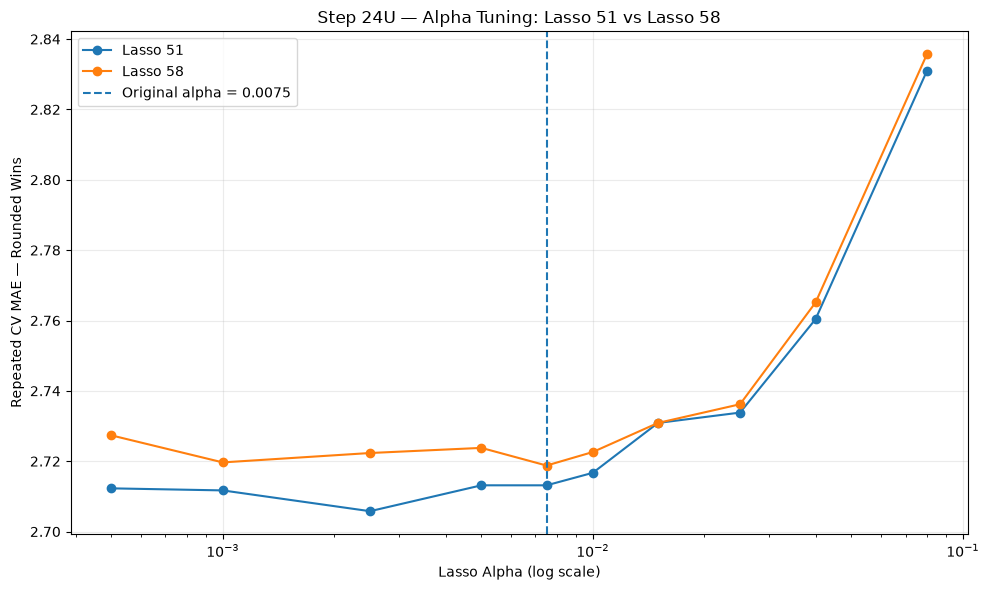


STEP 24U — FINAL SUMMARY

Lasso 51
Best continuous alpha: 0.0025
Best continuous MAE: 2.71287
Best rounded alpha: 0.0025
Best rounded MAE: 2.7058

Lasso 58
Best continuous alpha: 0.005
Best continuous MAE: 2.72136
Best rounded alpha: 0.0075
Best rounded MAE: 2.71878

Current Kaggle Public MAE:
Lasso 58: 2.8850
Lasso 51: 2.89 (reported)

Research continuous CV target: 2.6900

IMPORTANT:
- These are exploratory alpha comparisons.
- Best CV alpha may not generalize best.
- Same data was used in earlier model selection.
- CV improvement is not Kaggle improvement.
- No submission files modified.

Step 24U completed.


In [95]:

# ============================================================
# STEP 24U — ALPHA TUNING FOR LASSO 51 AND LASSO 58
#
# Objectives:
# 1. Find best alpha for Lasso 51
# 2. Find best alpha for Lasso 58
# 3. Compare continuous and rounded CV MAE
# 4. Compare CV R²
#
# CV: 5 folds x 3 repeats
# Data: 1129 training observations
#
# No Kaggle data used.
# No hold-out test data used.
# No existing files modified.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error, r2_score

# ------------------------------------------------------------
# 1. PREPARE DATASETS
# ------------------------------------------------------------

X58_24u = X58_24m.copy()
y_24u = y_24m.copy()

remove_7_24u = [
    "DP",
    "2B",
    "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

X51_24u = X58_24u.drop(
    columns=remove_7_24u
).copy()

assert X58_24u.shape == (1129, 58)
assert X51_24u.shape == (1129, 51)
assert X58_24u.index.equals(y_24u.index)

datasets_24u = {
    "Lasso 51": X51_24u,
    "Lasso 58": X58_24u
}

# ------------------------------------------------------------
# 2. DEFINE ALPHA SEARCH VALUES
# ------------------------------------------------------------

alphas_24u = [
    0.0005,
    0.0010,
    0.0025,
    0.0050,
    0.0075,
    0.0100,
    0.0150,
    0.0250,
    0.0400,
    0.0800
]

print("=" * 75)
print("STEP 24U — ALPHA TUNING")
print("=" * 75)

print("Models:", list(datasets_24u.keys()))
print("Alpha candidates:", alphas_24u)
print("Training observations:", len(y_24u))

# ------------------------------------------------------------
# 3. REPEATED CROSS-VALIDATION
# ------------------------------------------------------------

cv_24u = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24u = list(
    cv_24u.split(X58_24u)
)

results_24u = []

# ------------------------------------------------------------
# 4. TRAIN EACH MODEL AT EVERY ALPHA
# ------------------------------------------------------------

for model_name, X in datasets_24u.items():

    for alpha in alphas_24u:

        for fold, (train_idx, val_idx) in enumerate(
            splits_24u,
            start=1
        ):

            X_train = X.iloc[train_idx]
            X_val = X.iloc[val_idx]

            y_train = y_24u.iloc[train_idx]
            y_val = y_24u.iloc[val_idx]

            # Create a fresh preprocessing pipeline.

            model = create_lasso_24a(X_train)

            model.set_params(
                lasso__alpha=alpha
            )

            model.fit(X_train, y_train)

            # Continuous predictions

            pred_cont = model.predict(X_val)

            # Kaggle-style rounded predictions

            games = X_val["G"].to_numpy(
                dtype=float
            )

            pred_round = np.clip(
                np.rint(pred_cont),
                0,
                np.floor(games)
            )

            # Calculate metrics

            results_24u.append({
                "Model": model_name,
                "Alpha": alpha,
                "Fold": fold,

                "Continuous_MAE":
                    mean_absolute_error(
                        y_val, pred_cont
                    ),

                "Rounded_MAE":
                    mean_absolute_error(
                        y_val, pred_round
                    ),

                "CV_R2":
                    r2_score(
                        y_val, pred_cont
                    )
            })

        print(
            f"{model_name} | "
            f"alpha={alpha:.4f} completed"
        )

# ------------------------------------------------------------
# 5. SUMMARIZE ALPHA PERFORMANCE
# ------------------------------------------------------------

results_df_24u = pd.DataFrame(
    results_24u
)

summary_24u = (
    results_df_24u
    .groupby(["Model", "Alpha"])
    .agg(
        Continuous_CV_MAE=(
            "Continuous_MAE", "mean"
        ),
        Rounded_CV_MAE=(
            "Rounded_MAE", "mean"
        ),
        CV_R2=("CV_R2", "mean"),
        Rounded_MAE_Std=(
            "Rounded_MAE", "std"
        )
    )
    .reset_index()
)

print("\n" + "=" * 100)
print("STEP 24U — ALL ALPHA RESULTS")
print("=" * 100)

print(
    summary_24u
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 6. SELECT BEST ALPHA FOR EACH METRIC
# ------------------------------------------------------------

best_rows_24u = []

for model_name in datasets_24u:

    subset = summary_24u[
        summary_24u["Model"] == model_name
    ]

    # Best alpha for continuous MAE

    best_cont = subset.loc[
        subset["Continuous_CV_MAE"].idxmin()
    ]

    # Best alpha for Kaggle-style rounded MAE

    best_round = subset.loc[
        subset["Rounded_CV_MAE"].idxmin()
    ]

    best_rows_24u.append({
        "Model": model_name,
        "Best_Continuous_Alpha":
            best_cont["Alpha"],
        "Best_Continuous_MAE":
            best_cont["Continuous_CV_MAE"],
        "Best_Rounded_Alpha":
            best_round["Alpha"],
        "Best_Rounded_MAE":
            best_round["Rounded_CV_MAE"]
    })

best_alpha_24u = pd.DataFrame(
    best_rows_24u
)

print("\n" + "=" * 95)
print("STEP 24U — BEST ALPHA FOR EACH MODEL")
print("=" * 95)

print(
    best_alpha_24u
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 7. COMPARE AGAINST ORIGINAL ALPHA 0.0075
# ------------------------------------------------------------

comparison_rows_24u = []

for model_name in datasets_24u:

    subset = summary_24u[
        summary_24u["Model"] == model_name
    ]

    original = subset[
        np.isclose(subset["Alpha"], 0.0075)
    ].iloc[0]

    best = subset.loc[
        subset["Rounded_CV_MAE"].idxmin()
    ]

    comparison_rows_24u.append({
        "Model": model_name,
        "Original_Alpha": 0.0075,
        "Best_Rounded_Alpha": best["Alpha"],
        "Original_Rounded_MAE":
            original["Rounded_CV_MAE"],
        "Best_Rounded_MAE":
            best["Rounded_CV_MAE"],
        "MAE_Improvement":
            original["Rounded_CV_MAE"]
            - best["Rounded_CV_MAE"]
    })

comparison_24u = pd.DataFrame(
    comparison_rows_24u
)

print("\n" + "=" * 100)
print("STEP 24U — TUNED VS ORIGINAL ALPHA")
print("=" * 100)

print(
    comparison_24u
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 8. VISUALIZE ALPHA VS ROUNDED MAE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for model_name in datasets_24u:

    subset = summary_24u[
        summary_24u["Model"] == model_name
    ].sort_values("Alpha")

    plt.plot(
        subset["Alpha"],
        subset["Rounded_CV_MAE"],
        marker="o",
        label=model_name
    )

plt.axvline(
    0.0075,
    linestyle="--",
    label="Original alpha = 0.0075"
)

plt.xscale("log")

plt.xlabel("Lasso Alpha (log scale)")
plt.ylabel("Repeated CV MAE — Rounded Wins")
plt.title(
    "Step 24U — Alpha Tuning: Lasso 51 vs Lasso 58"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 24U — FINAL SUMMARY")
print("=" * 80)

for _, row in best_alpha_24u.iterrows():

    print(f"\n{row['Model']}")

    print(
        "Best continuous alpha:",
        row["Best_Continuous_Alpha"]
    )

    print(
        "Best continuous MAE:",
        round(row["Best_Continuous_MAE"], 5)
    )

    print(
        "Best rounded alpha:",
        row["Best_Rounded_Alpha"]
    )

    print(
        "Best rounded MAE:",
        round(row["Best_Rounded_MAE"], 5)
    )

print("\nCurrent Kaggle Public MAE:")
print("Lasso 58: 2.8850")
print("Lasso 51: 2.89 (reported)")

print("\nResearch continuous CV target: 2.6900")

print("\nIMPORTANT:")
print("- These are exploratory alpha comparisons.")
print("- Best CV alpha may not generalize best.")
print("- Same data was used in earlier model selection.")
print("- CV improvement is not Kaggle improvement.")
print("- No submission files modified.")

print("\nStep 24U completed.")


In [96]:
# ============================================================
# STEP 24T — LASSO 51 TRAIN VS TEST R²
#
# Original split:
# Training: 1129 observations
# Test:      283 observations
#
# Features: 51
# Alpha: 0.0075
#
# No Kaggle data used.
# No existing files modified.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# 1 — GET ORIGINAL TRAINING DATA
# ------------------------------------------------------------

X58_train = X58_24m.copy()
y_train = y_24m.copy()

# These were aligned with the original CSV in Step 24S.

X_full = X_full_24s.copy().reset_index(drop=True)
y_full = y_train_24s.copy().reset_index(drop=True)

assert X58_train.shape == (1129, 58)
assert X_full.shape[0] == 1412

# ------------------------------------------------------------
# 2 — RECOVER ORIGINAL TEST OBSERVATIONS
# ------------------------------------------------------------

# Match original MLB statistics to avoid row-order errors.

match_candidates = [
    "G", "R", "RA", "AB", "H",
    "2B", "3B", "HR", "BB", "SO",
    "IPouts", "HA", "HRA", "BBA",
    "SOA", "E", "DP", "CG",
    "SHO", "SV", "SB", "ER"
]

match_cols = [
    c for c in match_candidates
    if c in X58_train.columns and c in X_full.columns
]

assert len(match_cols) >= 5

full_keys = X_full[match_cols].copy()
full_keys["_row_"] = np.arange(len(X_full))

train_keys = X58_train[match_cols].copy()

assert not full_keys.duplicated(
    subset=match_cols
).any(), "Duplicate rows in full dataset."

assert not train_keys.duplicated(
    subset=match_cols
).any(), "Duplicate rows in training dataset."

matches = train_keys.merge(
    full_keys,
    on=match_cols,
    how="left",
    sort=False,
    validate="one_to_one",
    indicator=True
)

assert (matches["_merge"] == "both").all()

train_rows = matches["_row_"].to_numpy(dtype=int)

# Verify that training targets match the original records.

assert np.array_equal(
    y_train.to_numpy(),
    y_full.iloc[train_rows].to_numpy()
), "Training targets are not aligned."

test_rows = np.setdiff1d(
    np.arange(len(X_full)),
    train_rows
)

assert len(test_rows) == 283

# ------------------------------------------------------------
# 3 — PREPARE LASSO 51 FEATURES
# ------------------------------------------------------------

remove_7 = [
    "DP",
    "2B",
    "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

features_51 = [
    col for col in X58_train.columns
    if col not in remove_7
]

X_train = X58_train[features_51].copy()

X_test = (
    X_full.iloc[test_rows][features_51]
    .reset_index(drop=True)
)

y_test = y_full.iloc[test_rows].reset_index(drop=True)

assert X_train.shape == (1129, 51)
assert X_test.shape == (283, 51)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Features:", len(features_51))

# ------------------------------------------------------------
# 4 — TRAIN LASSO 51
# ------------------------------------------------------------

lasso51_24t = create_lasso_24a(X_train)

lasso51_24t.set_params(
    lasso__alpha=0.0075
)

lasso51_24t.fit(X_train, y_train)

# ------------------------------------------------------------
# 5 — GENERATE PREDICTIONS
# ------------------------------------------------------------

train_pred = lasso51_24t.predict(X_train)
test_pred = lasso51_24t.predict(X_test)

# ------------------------------------------------------------
# 6 — CALCULATE METRICS
# ------------------------------------------------------------

results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Training": [
        mean_absolute_error(y_train, train_pred),
        np.sqrt(mean_squared_error(y_train, train_pred)),
        r2_score(y_train, train_pred)
    ],
    "Test": [
        mean_absolute_error(y_test, test_pred),
        np.sqrt(mean_squared_error(y_test, test_pred)),
        r2_score(y_test, test_pred)
    ]
})

print("\n" + "=" * 65)
print("STEP 24T — LASSO 51 TRAIN VS TEST")
print("=" * 65)

print(results.round(5).to_string(index=False))

# ------------------------------------------------------------
# 7 — GENERALIZATION GAP
# ------------------------------------------------------------

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

print("\nTraining R²:", round(train_r2, 5))
print("Test R²:    ", round(test_r2, 5))

print(
    "R² Gap:     ",
    round(train_r2 - test_r2, 5)
)

print("\nStep 24T completed.")

Training observations: 1129
Test observations: 283
Features: 51

STEP 24T — LASSO 51 TRAIN VS TEST
Metric  Training    Test
   MAE   2.62304 2.65901
  RMSE   3.29664 3.26046
    R²   0.93987 0.93347

Training R²: 0.93987
Test R²:     0.93347
R² Gap:      0.0064

Step 24T completed.


In [97]:
print("X_full_24s exists:", "X_full_24s" in globals())
print("y_train_24s exists:", "y_train_24s" in globals())

X_full_24s exists: True
y_train_24s exists: True


In [98]:
for name in [
    "X58_24m",
    "y_24m",
    "X_full_24s",
    "y_train_24s"
]:
    print(name, ":", "Available" if name in globals() else "MISSING")

X58_24m : Available
y_24m : Available
X_full_24s : Available
y_train_24s : Available


Alpha 0.01 completed
Alpha 0.1 completed
Alpha 1.0 completed
Alpha 5.0 completed
Alpha 10.0 completed
Alpha 25.0 completed
Alpha 50.0 completed
Alpha 100.0 completed
Alpha 250.0 completed
Alpha 500.0 completed
Alpha 1000.0 completed

STEP 24V — RIDGE ALPHA RESULTS
  Alpha  Continuous_CV_MAE  Rounded_CV_MAE    CV_R2
   0.01           2.745511        2.734145 0.932736
   0.10           2.738481        2.729116 0.933166
   1.00           2.731205        2.729712 0.933528
   5.00           2.735096        2.732364 0.933628
  10.00           2.749644        2.745053 0.933166
  25.00           2.789433        2.780756 0.931379
  50.00           2.839006        2.820317 0.928793
 100.00           2.911028        2.903877 0.924961
 250.00           3.042807        3.021973 0.917804
 500.00           3.184692        3.178457 0.910143
1000.00           3.411323        3.393412 0.897525

BEST RIDGE REGRESSION
Best alpha: 1.0
Continuous CV MAE: 2.73121
Rounded CV MAE: 2.72971
CV R²: 0.93353

RIDGE

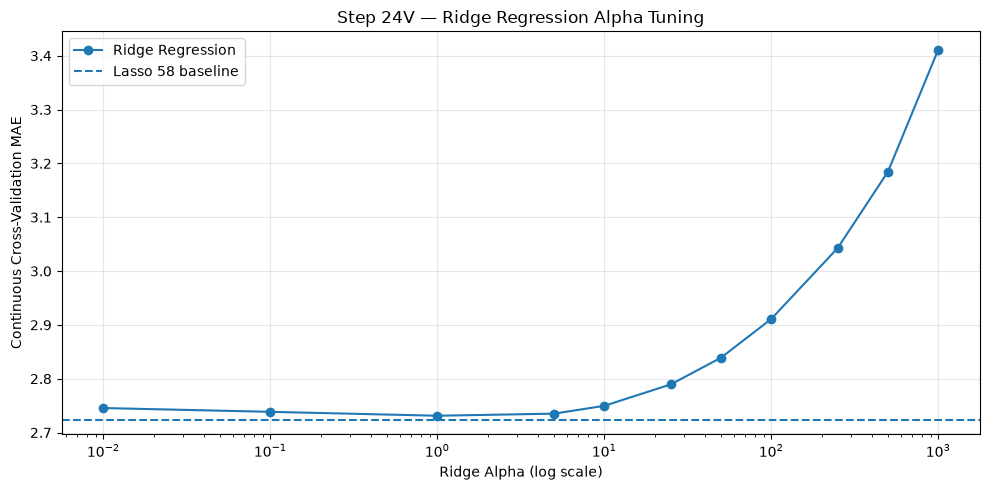


Step 24V completed.


In [99]:
# ============================================================
# STEP 24V — RIDGE REGRESSION ALPHA TUNING
#
# Compare Ridge against Lasso 58
#
# Training observations: 1129
# Features: 58
# CV: 5 folds x 3 repeats
#
# No Kaggle data used.
# No hold-out test data used.
# No existing files modified.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error, r2_score

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

X_ridge_24v = X58_24m.copy()
y_ridge_24v = y_24m.copy()

assert X_ridge_24v.shape == (1129, 58)
assert len(y_ridge_24v) == 1129
assert X_ridge_24v.index.equals(y_ridge_24v.index)

# ------------------------------------------------------------
# 2. PREPROCESSING
# ------------------------------------------------------------

# Match the preprocessing used by the existing Lasso
# pipeline: standardize numeric predictors and pass
# historical era/decade indicators through unchanged.

indicator_cols_24v = [
    c for c in X_ridge_24v.columns
    if c.startswith(("era_", "decade_"))
]

numeric_cols_24v = [
    c for c in X_ridge_24v.columns
    if c not in indicator_cols_24v
]

def create_ridge_24v(alpha):

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_cols_24v),
            ("indicator", "passthrough", indicator_cols_24v)
        ]
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("ridge", Ridge(alpha=alpha))
    ])

# ------------------------------------------------------------
# 3. ALPHA CANDIDATES
# ------------------------------------------------------------

alphas_24v = [
    0.01,
    0.1,
    1.0,
    5.0,
    10.0,
    25.0,
    50.0,
    100.0,
    250.0,
    500.0,
    1000.0
]

cv_24v = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24v = list(cv_24v.split(X_ridge_24v))

# ------------------------------------------------------------
# 4. CROSS-VALIDATION
# ------------------------------------------------------------

results_24v = []

for alpha in alphas_24v:

    for fold, (train_idx, val_idx) in enumerate(
        splits_24v, start=1
    ):

        X_train = X_ridge_24v.iloc[train_idx]
        X_val = X_ridge_24v.iloc[val_idx]

        y_train = y_ridge_24v.iloc[train_idx]
        y_val = y_ridge_24v.iloc[val_idx]

        model = create_ridge_24v(alpha)

        model.fit(X_train, y_train)

        pred_cont = model.predict(X_val)

        games = X_val["G"].to_numpy(dtype=float)

        pred_round = np.clip(
            np.rint(pred_cont),
            0,
            np.floor(games)
        )

        results_24v.append({
            "Alpha": alpha,
            "Fold": fold,
            "Continuous_MAE": mean_absolute_error(
                y_val, pred_cont
            ),
            "Rounded_MAE": mean_absolute_error(
                y_val, pred_round
            ),
            "R2": r2_score(y_val, pred_cont)
        })

    print(f"Alpha {alpha} completed")

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

results_df_24v = pd.DataFrame(results_24v)

summary_24v = (
    results_df_24v
    .groupby("Alpha")
    .agg(
        Continuous_CV_MAE=("Continuous_MAE", "mean"),
        Rounded_CV_MAE=("Rounded_MAE", "mean"),
        CV_R2=("R2", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("STEP 24V — RIDGE ALPHA RESULTS")
print("=" * 75)

print(summary_24v.round(6).to_string(index=False))

# ------------------------------------------------------------
# 6. SELECT BEST ALPHA
# ------------------------------------------------------------

best_ridge_24v = summary_24v.loc[
    summary_24v["Continuous_CV_MAE"].idxmin()
]

print("\n" + "=" * 75)
print("BEST RIDGE REGRESSION")
print("=" * 75)

print("Best alpha:", best_ridge_24v["Alpha"])
print(
    "Continuous CV MAE:",
    round(best_ridge_24v["Continuous_CV_MAE"], 5)
)
print(
    "Rounded CV MAE:",
    round(best_ridge_24v["Rounded_CV_MAE"], 5)
)
print(
    "CV R²:",
    round(best_ridge_24v["CV_R2"], 5)
)

# ------------------------------------------------------------
# 7. COMPARE WITH LASSO 58
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RIDGE VS LASSO 58")
print("=" * 75)

print("Lasso 58 continuous CV MAE: 2.72335")
print(
    "Ridge continuous CV MAE:",
    round(best_ridge_24v["Continuous_CV_MAE"], 5)
)

difference = (
    2.72335 - best_ridge_24v["Continuous_CV_MAE"]
)

print("MAE improvement:", round(difference, 5))

# ------------------------------------------------------------
# 8. VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    summary_24v["Alpha"],
    summary_24v["Continuous_CV_MAE"],
    marker="o",
    label="Ridge Regression"
)

plt.axhline(
    2.72335,
    linestyle="--",
    label="Lasso 58 baseline"
)

plt.xscale("log")
plt.xlabel("Ridge Alpha (log scale)")
plt.ylabel("Continuous Cross-Validation MAE")
plt.title("Step 24V — Ridge Regression Alpha Tuning")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nStep 24V completed.")

STEP 24W — ELASTIC NET TUNING
Training observations: 1129
Features: 58

Alpha candidates: [0.001, 0.0025, 0.005, 0.0075, 0.01, 0.025, 0.05]
L1 ratio candidates: [0.1, 0.3, 0.5, 0.7, 0.9, 0.99]
Alpha=0.0010 | L1 ratio=0.10 completed
Alpha=0.0010 | L1 ratio=0.30 completed
Alpha=0.0010 | L1 ratio=0.50 completed
Alpha=0.0010 | L1 ratio=0.70 completed
Alpha=0.0010 | L1 ratio=0.90 completed
Alpha=0.0010 | L1 ratio=0.99 completed
Alpha=0.0025 | L1 ratio=0.10 completed
Alpha=0.0025 | L1 ratio=0.30 completed
Alpha=0.0025 | L1 ratio=0.50 completed
Alpha=0.0025 | L1 ratio=0.70 completed
Alpha=0.0025 | L1 ratio=0.90 completed
Alpha=0.0025 | L1 ratio=0.99 completed
Alpha=0.0050 | L1 ratio=0.10 completed
Alpha=0.0050 | L1 ratio=0.30 completed
Alpha=0.0050 | L1 ratio=0.50 completed
Alpha=0.0050 | L1 ratio=0.70 completed
Alpha=0.0050 | L1 ratio=0.90 completed
Alpha=0.0050 | L1 ratio=0.99 completed
Alpha=0.0075 | L1 ratio=0.10 completed
Alpha=0.0075 | L1 ratio=0.30 completed
Alpha=0.0075 | L1 ratio=0.5

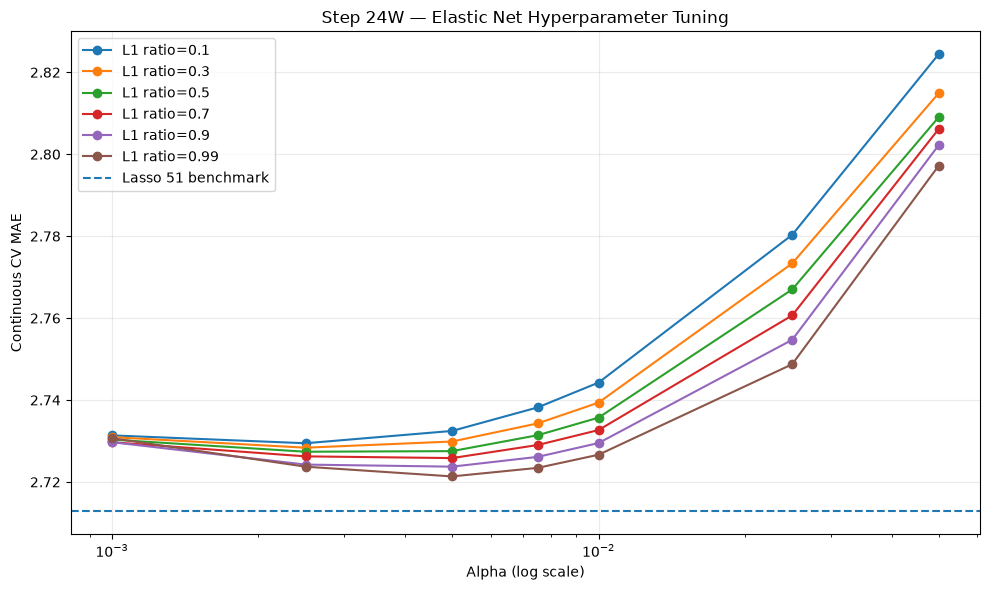


STEP 24W — FINAL SUMMARY
Best Elastic Net continuous MAE: 2.721361
Current Lasso 51 benchmark: 2.712869
Improvement over Lasso 51: -0.008492

Research target: Continuous CV MAE <= 2.6900

IMPORTANT:
- Results are exploratory CV estimates.
- Best tuning score may be optimistic.
- Kaggle performance is not yet known.
- No submission files modified.

Step 24W completed.


In [100]:

# ============================================================
# STEP 24W — ELASTIC NET HYPERPARAMETER TUNING
#
# Objectives:
# 1. Find best alpha and l1_ratio
# 2. Compare Elastic Net against Lasso 51 and Lasso 58
# 3. Evaluate continuous MAE, rounded MAE and R²
#
# No Kaggle data used.
# No hold-out test data used.
# No existing files modified.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# ------------------------------------------------------------
# 1. LOAD EXISTING TRAINING DATA
# ------------------------------------------------------------

X_24w = X58_24m.copy()
y_24w = y_24m.copy()

assert X_24w.shape == (1129, 58)
assert len(y_24w) == 1129
assert X_24w.index.equals(y_24w.index)

print("=" * 75)
print("STEP 24W — ELASTIC NET TUNING")
print("=" * 75)
print("Training observations:", len(X_24w))
print("Features:", X_24w.shape[1])

# ------------------------------------------------------------
# 2. DEFINE PREPROCESSING
# ------------------------------------------------------------

# Match the previous Lasso and Ridge experiments.

indicator_cols_24w = [
    col for col in X_24w.columns
    if col.startswith(("era_", "decade_"))
]

numeric_cols_24w = [
    col for col in X_24w.columns
    if col not in indicator_cols_24w
]

def create_elasticnet_24w(alpha, l1_ratio):

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                numeric_cols_24w
            ),
            (
                "indicator",
                "passthrough",
                indicator_cols_24w
            )
        ]
    )

    model = ElasticNet(
        alpha=alpha,
        l1_ratio=l1_ratio,
        max_iter=100000,
        tol=1e-5,
        random_state=2026
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("elasticnet", model)
    ])

# ------------------------------------------------------------
# 3. DEFINE HYPERPARAMETER GRID
# ------------------------------------------------------------

alphas_24w = [
    0.001,
    0.0025,
    0.005,
    0.0075,
    0.01,
    0.025,
    0.05
]

l1_ratios_24w = [
    0.1,
    0.3,
    0.5,
    0.7,
    0.9,
    0.99
]

print("\nAlpha candidates:", alphas_24w)
print("L1 ratio candidates:", l1_ratios_24w)

# ------------------------------------------------------------
# 4. REPEATED CROSS-VALIDATION
# ------------------------------------------------------------

cv_24w = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24w = list(cv_24w.split(X_24w))

results_24w = []

# ------------------------------------------------------------
# 5. TRAIN ELASTIC NET
# ------------------------------------------------------------

with warnings.catch_warnings():

    warnings.simplefilter(
        "ignore",
        ConvergenceWarning
    )

    for alpha in alphas_24w:

        for l1_ratio in l1_ratios_24w:

            for fold, (train_idx, val_idx) in enumerate(
                splits_24w,
                start=1
            ):

                X_train = X_24w.iloc[train_idx]
                X_val = X_24w.iloc[val_idx]

                y_train = y_24w.iloc[train_idx]
                y_val = y_24w.iloc[val_idx]

                model = create_elasticnet_24w(
                    alpha=alpha,
                    l1_ratio=l1_ratio
                )

                model.fit(X_train, y_train)

                pred_cont = model.predict(X_val)

                games = X_val["G"].to_numpy(
                    dtype=float
                )

                pred_round = np.clip(
                    np.rint(pred_cont),
                    0,
                    np.floor(games)
                )

                results_24w.append({
                    "Alpha": alpha,
                    "L1_Ratio": l1_ratio,
                    "Fold": fold,

                    "Continuous_MAE":
                        mean_absolute_error(
                            y_val,
                            pred_cont
                        ),

                    "Rounded_MAE":
                        mean_absolute_error(
                            y_val,
                            pred_round
                        ),

                    "CV_R2":
                        r2_score(
                            y_val,
                            pred_cont
                        )
                })

            print(
                f"Alpha={alpha:.4f} | "
                f"L1 ratio={l1_ratio:.2f} completed"
            )

# ------------------------------------------------------------
# 6. SUMMARIZE RESULTS
# ------------------------------------------------------------

results_df_24w = pd.DataFrame(
    results_24w
)

summary_24w = (
    results_df_24w
    .groupby(["Alpha", "L1_Ratio"])
    .agg(
        Continuous_CV_MAE=(
            "Continuous_MAE",
            "mean"
        ),
        Rounded_CV_MAE=(
            "Rounded_MAE",
            "mean"
        ),
        CV_R2=(
            "CV_R2",
            "mean"
        ),
        Rounded_MAE_Std=(
            "Rounded_MAE",
            "std"
        )
    )
    .reset_index()
    .sort_values("Continuous_CV_MAE")
)

print("\n" + "=" * 90)
print("STEP 24W — TOP 15 ELASTIC NET CONFIGURATIONS")
print("=" * 90)

print(
    summary_24w.head(15)
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 7. IDENTIFY BEST CONFIGURATION
# ------------------------------------------------------------

best_cont_24w = summary_24w.loc[
    summary_24w["Continuous_CV_MAE"].idxmin()
]

best_round_24w = summary_24w.loc[
    summary_24w["Rounded_CV_MAE"].idxmin()
]

print("\n" + "=" * 75)
print("BEST ELASTIC NET — CONTINUOUS MAE")
print("=" * 75)

print("Alpha:", best_cont_24w["Alpha"])
print("L1 ratio:", best_cont_24w["L1_Ratio"])
print(
    "Continuous CV MAE:",
    round(best_cont_24w["Continuous_CV_MAE"], 6)
)
print(
    "Rounded CV MAE:",
    round(best_cont_24w["Rounded_CV_MAE"], 6)
)
print(
    "CV R²:",
    round(best_cont_24w["CV_R2"], 6)
)

print("\n" + "=" * 75)
print("BEST ELASTIC NET — ROUNDED MAE")
print("=" * 75)

print("Alpha:", best_round_24w["Alpha"])
print("L1 ratio:", best_round_24w["L1_Ratio"])
print(
    "Rounded CV MAE:",
    round(best_round_24w["Rounded_CV_MAE"], 6)
)

# ------------------------------------------------------------
# 8. COMPARE AGAINST PREVIOUS MODELS
# ------------------------------------------------------------

comparison_24w = pd.DataFrame([
    {
        "Model": "Lasso 51",
        "Continuous_CV_MAE": 2.712869
    },
    {
        "Model": "Lasso 58",
        "Continuous_CV_MAE": 2.721360
    },
    {
        "Model": "Ridge 58",
        "Continuous_CV_MAE": 2.731205
    },
    {
        "Model": "Elastic Net 58",
        "Continuous_CV_MAE":
            best_cont_24w["Continuous_CV_MAE"]
    }
]).sort_values("Continuous_CV_MAE")

print("\n" + "=" * 80)
print("STEP 24W — MODEL COMPARISON")
print("=" * 80)

print(
    comparison_24w
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 9. VISUALIZE ELASTIC NET TUNING
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for l1_ratio in l1_ratios_24w:

    subset = summary_24w[
        np.isclose(
            summary_24w["L1_Ratio"],
            l1_ratio
        )
    ].sort_values("Alpha")

    plt.plot(
        subset["Alpha"],
        subset["Continuous_CV_MAE"],
        marker="o",
        label=f"L1 ratio={l1_ratio}"
    )

plt.axhline(
    2.712869,
    linestyle="--",
    label="Lasso 51 benchmark"
)

plt.xscale("log")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Continuous CV MAE")
plt.title(
    "Step 24W — Elastic Net Hyperparameter Tuning"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 24W — FINAL SUMMARY")
print("=" * 80)

print(
    "Best Elastic Net continuous MAE:",
    round(best_cont_24w["Continuous_CV_MAE"], 6)
)

print(
    "Current Lasso 51 benchmark:",
    2.712869
)

improvement_24w = (
    2.712869
    - best_cont_24w["Continuous_CV_MAE"]
)

print(
    "Improvement over Lasso 51:",
    round(improvement_24w, 6)
)

print("\nResearch target: Continuous CV MAE <= 2.6900")

print("\nIMPORTANT:")
print("- Results are exploratory CV estimates.")
print("- Best tuning score may be optimistic.")
print("- Kaggle performance is not yet known.")
print("- No submission files modified.")

print("\nStep 24W completed.")


In [101]:

# ============================================================
# STEP 24X — VOTING REGRESSOR
# Equal Voting vs Weighted Voting
#
# No Kaggle predictions generated.
# No files modified.
# Hold-out test set remains unused.
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.ensemble import VotingRegressor
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# ------------------------------------------------------------
# 1. RESTORE EXISTING TRAINING DATA
# ------------------------------------------------------------

X_24x = X58_24m.copy()
y_24x = y_24m.copy()

assert X_24x.shape == (1129, 58)
assert len(y_24x) == 1129
assert X_24x.index.equals(y_24x.index)
assert "G" in X_24x.columns

# Seven features removed in the original Lasso 51 experiment
removed_features_24x = [
    "DP",
    "2B",
    "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

missing = [
    col for col in removed_features_24x
    if col not in X_24x.columns
]

if missing:
    raise ValueError(
        f"Expected features not found: {missing}"
    )

features_51_24x = [
    col for col in X_24x.columns
    if col not in removed_features_24x
]

features_58_24x = X_24x.columns.tolist()

assert len(features_51_24x) == 51
assert len(features_58_24x) == 58

print("=" * 75)
print("STEP 24X — VOTING REGRESSOR")
print("=" * 75)

print("Training observations:", len(X_24x))
print("Lasso 51 features:", len(features_51_24x))
print("Other model features:", len(features_58_24x))

# ------------------------------------------------------------
# 2. CREATE MODEL-SPECIFIC PREPROCESSING
# ------------------------------------------------------------

def make_preprocessor_24x(feature_names):

    indicators = [
        col for col in feature_names
        if col.startswith(("era_", "decade_"))
    ]

    numeric = [
        col for col in feature_names
        if col not in indicators
    ]

    return ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), numeric),
            ("indicators", "passthrough", indicators)
        ]
    )


# ------------------------------------------------------------
# 3. CREATE FOUR BASE REGRESSION MODELS
# ------------------------------------------------------------

def make_base_models_24x():

    lasso51 = Pipeline([
        (
            "preprocessor",
            make_preprocessor_24x(features_51_24x)
        ),
        (
            "model",
            Lasso(
                alpha=0.0025,
                max_iter=100000,
                tol=1e-5
            )
        )
    ])

    lasso58 = Pipeline([
        (
            "preprocessor",
            make_preprocessor_24x(features_58_24x)
        ),
        (
            "model",
            Lasso(
                alpha=0.005,
                max_iter=100000,
                tol=1e-5
            )
        )
    ])

    ridge58 = Pipeline([
        (
            "preprocessor",
            make_preprocessor_24x(features_58_24x)
        ),
        (
            "model",
            Ridge(alpha=1.0)
        )
    ])

    elastic58 = Pipeline([
        (
            "preprocessor",
            make_preprocessor_24x(features_58_24x)
        ),
        (
            "model",
            ElasticNet(
                alpha=0.005,
                l1_ratio=0.99,
                max_iter=100000,
                tol=1e-5
            )
        )
    ])

    return [
        ("Lasso51", lasso51),
        ("Lasso58", lasso58),
        ("Ridge58", ridge58),
        ("ElasticNet58", elastic58)
    ]


# ------------------------------------------------------------
# 4. DEFINE ALL SIX EXPERIMENTS
# ------------------------------------------------------------

def make_experiments_24x():

    base = make_base_models_24x()

    experiments = {
        name: model
        for name, model in base
    }

    experiments["Voting_Equal"] = VotingRegressor(
        estimators=make_base_models_24x(),
        weights=[1, 1, 1, 1]
    )

    experiments["Voting_Weighted"] = VotingRegressor(
        estimators=make_base_models_24x(),
        weights=[4, 2, 1, 1]
    )

    return experiments


# ------------------------------------------------------------
# 5. USE THE SAME REPEATED CV DESIGN
# ------------------------------------------------------------

cv_24x = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24x = list(cv_24x.split(X_24x))

results_24x = []

# ------------------------------------------------------------
# 6. TRAIN AND EVALUATE
# ------------------------------------------------------------

with warnings.catch_warnings():

    warnings.simplefilter(
        "ignore",
        ConvergenceWarning
    )

    for name, model in make_experiments_24x().items():

        for fold, (train_idx, val_idx) in enumerate(
            splits_24x,
            start=1
        ):

            X_train = X_24x.iloc[train_idx]
            X_val = X_24x.iloc[val_idx]

            y_train = y_24x.iloc[train_idx]
            y_val = y_24x.iloc[val_idx]

            model.fit(X_train, y_train)

            pred = model.predict(X_val)

            # Round predictions to whole wins
            games = X_val["G"].to_numpy(
                dtype=float
            )

            pred_rounded = np.clip(
                np.rint(pred),
                0,
                np.floor(games)
            )

            results_24x.append({
                "Model": name,
                "Fold": fold,

                "Continuous_MAE":
                    mean_absolute_error(
                        y_val, pred
                    ),

                "Rounded_MAE":
                    mean_absolute_error(
                        y_val, pred_rounded
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            y_val, pred
                        )
                    ),

                "R2":
                    r2_score(
                        y_val, pred
                    )
            })

        print(f"{name} completed")


# ------------------------------------------------------------
# 7. SUMMARIZE MODEL PERFORMANCE
# ------------------------------------------------------------

results_df_24x = pd.DataFrame(results_24x)

summary_24x = (
    results_df_24x
    .groupby("Model")
    .agg(
        Continuous_CV_MAE=(
            "Continuous_MAE", "mean"
        ),
        Rounded_CV_MAE=(
            "Rounded_MAE", "mean"
        ),
        CV_RMSE=(
            "RMSE", "mean"
        ),
        CV_R2=(
            "R2", "mean"
        ),
        MAE_Std=(
            "Continuous_MAE", "std"
        )
    )
    .reset_index()
    .sort_values("Continuous_CV_MAE")
)

print("\n" + "=" * 90)
print("STEP 24X — ALL MODEL RESULTS")
print("=" * 90)

print(
    summary_24x
    .round(6)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 8. IDENTIFY WINNER
# ------------------------------------------------------------

winner_24x = summary_24x.iloc[0]

print("\n" + "=" * 75)
print("STEP 24X — BEST MODEL")
print("=" * 75)

print("Model:", winner_24x["Model"])

print(
    "Continuous CV MAE:",
    round(winner_24x["Continuous_CV_MAE"], 6)
)

print(
    "Rounded CV MAE:",
    round(winner_24x["Rounded_CV_MAE"], 6)
)

print(
    "CV R²:",
    round(winner_24x["CV_R2"], 6)
)


# ------------------------------------------------------------
# 9. VOTING VS LASSO 51
# ------------------------------------------------------------

lasso51_mae = summary_24x.loc[
    summary_24x["Model"] == "Lasso51",
    "Continuous_CV_MAE"
].iloc[0]

print("\n" + "=" * 75)
print("STEP 24X — VOTING VS LASSO 51")
print("=" * 75)

for name in ["Voting_Equal", "Voting_Weighted"]:

    voting_mae = summary_24x.loc[
        summary_24x["Model"] == name,
        "Continuous_CV_MAE"
    ].iloc[0]

    improvement = lasso51_mae - voting_mae

    print(f"\n{name}")
    print("CV MAE:", round(voting_mae, 6))
    print(
        "Improvement over Lasso 51:",
        round(improvement, 6)
    )

    if improvement > 0:
        print("Result: Voting is better")
    elif improvement < 0:
        print("Result: Lasso 51 is better")
    else:
        print("Result: Equal performance")


# ------------------------------------------------------------
# 10. CHECK AGAINST RESEARCH TARGET
# ------------------------------------------------------------

target_mae_24x = 2.6900

best_mae_24x = winner_24x[
    "Continuous_CV_MAE"
]

print("\n" + "=" * 75)
print("STEP 24X — RESEARCH TARGET")
print("=" * 75)

print("Target MAE:", target_mae_24x)
print("Best CV MAE:", round(best_mae_24x, 6))

if best_mae_24x <= target_mae_24x:
    print("Research target achieved in exploratory CV")
else:
    print(
        "Remaining gap:",
        round(best_mae_24x - target_mae_24x, 6)
    )

print("\nNotes:")
print("- All models use identical CV splits.")
print("- Preprocessing is fitted within each fold.")
print("- No hold-out test observations used.")
print("- No Kaggle predictions generated.")
print("- CV results remain exploratory.")

print("\nStep 24X completed.")


STEP 24X — VOTING REGRESSOR
Training observations: 1129
Lasso 51 features: 51
Other model features: 58
Lasso51 completed
Lasso58 completed
Ridge58 completed
ElasticNet58 completed
Voting_Equal completed
Voting_Weighted completed

STEP 24X — ALL MODEL RESULTS
          Model  Continuous_CV_MAE  Rounded_CV_MAE  CV_RMSE    CV_R2  MAE_Std
        Lasso51           2.712524        2.705202 3.415065 0.934528 0.169954
Voting_Weighted           2.717411        2.716109 3.420852 0.934302 0.169971
   Voting_Equal           2.720732        2.725564 3.425288 0.934131 0.170085
        Lasso58           2.721265        2.725567 3.425004 0.934135 0.170370
   ElasticNet58           2.721361        2.724085 3.425244 0.934126 0.170433
        Ridge58           2.731205        2.729712 3.441240 0.933528 0.170025

STEP 24X — BEST MODEL
Model: Lasso51
Continuous CV MAE: 2.712524
Rounded CV MAE: 2.705202
CV R²: 0.934528

STEP 24X — VOTING VS LASSO 51

Voting_Equal
CV MAE: 2.720732
Improvement over Lasso 51:

In [102]:

# ============================================================
# STEP 24Y — NONLINEAR REGRESSION COMPARISON
#
# Lasso 51 vs:
# - Random Forest
# - Extra Trees
# - Histogram Gradient Boosting
#
# Same 5-fold x 3-repeat CV
# No hold-out test data
# No Kaggle submission
# No files modified
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.exceptions import ConvergenceWarning

# ------------------------------------------------------------
# 1. USE EXISTING TRAINING DATA
# ------------------------------------------------------------

X_24y = X58_24m.copy()
y_24y = y_24m.copy()

assert X_24y.shape == (1129, 58)
assert len(y_24y) == 1129
assert X_24y.index.equals(y_24y.index)
assert "G" in X_24y.columns

# All model inputs must be numeric
assert all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in X_24y.dtypes
), "Non-numeric features detected."

assert np.isfinite(
    X_24y.to_numpy(dtype=float)
).all(), "Missing or infinite feature values detected."

assert np.isfinite(
    y_24y.to_numpy(dtype=float)
).all(), "Missing or infinite target values detected."

removed_24y = [
    "DP",
    "2B",
    "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

assert all(
    col in X_24y.columns
    for col in removed_24y
)

features51_24y = [
    col for col in X_24y.columns
    if col not in removed_24y
]

features58_24y = X_24y.columns.tolist()

assert len(features51_24y) == 51
assert len(features58_24y) == 58

print("=" * 75)
print("STEP 24Y — NONLINEAR MODEL COMPARISON")
print("=" * 75)

print("Training observations:", len(X_24y))
print("Lasso features:", len(features51_24y))
print("Tree model features:", len(features58_24y))

# ------------------------------------------------------------
# 2. LASSO 51 — MATCH STEP 24X BASELINE
# ------------------------------------------------------------

indicator_cols_24y = [
    col for col in features51_24y
    if col.startswith(("era_", "decade_"))
]

numeric_cols_24y = [
    col for col in features51_24y
    if col not in indicator_cols_24y
]

lasso_preprocessor_24y = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        numeric_cols_24y
    ),
    (
        "indicators",
        "passthrough",
        indicator_cols_24y
    )
])

lasso51_24y = Pipeline([
    ("preprocessor", lasso_preprocessor_24y),
    (
        "model",
        Lasso(
            alpha=0.0025,
            max_iter=100000,
            tol=1e-5
        )
    )
])

# ------------------------------------------------------------
# 3. DEFINE NONLINEAR MODELS
# ------------------------------------------------------------

# Tree-based models do not require StandardScaler.

models_24y = {

    "Lasso51": lasso51_24y,

    "RandomForest_A": RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=2026,
        n_jobs=-1
    ),

    "RandomForest_B": RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=4,
        max_features=0.8,
        random_state=2026,
        n_jobs=-1
    ),

    "ExtraTrees_A": ExtraTreesRegressor(
        n_estimators=250,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=2026,
        n_jobs=-1
    ),

    "ExtraTrees_B": ExtraTreesRegressor(
        n_estimators=250,
        min_samples_leaf=4,
        max_features=0.8,
        random_state=2026,
        n_jobs=-1
    ),

    "HistBoost_A": HistGradientBoostingRegressor(
        max_iter=250,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=2026
    ),

    "HistBoost_B": HistGradientBoostingRegressor(
        max_iter=350,
        learning_rate=0.03,
        max_leaf_nodes=31,
        l2_regularization=5.0,
        random_state=2026
    )
}

# ------------------------------------------------------------
# 4. SAME REPEATED CROSS-VALIDATION
# ------------------------------------------------------------

cv_24y = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24y = list(cv_24y.split(X_24y))

results_24y = []

# ------------------------------------------------------------
# 5. TRAIN AND EVALUATE
# ------------------------------------------------------------

with warnings.catch_warnings():

    warnings.simplefilter(
        "ignore",
        ConvergenceWarning
    )

    for name, model in models_24y.items():

        # Lasso uses 51 features through its pipeline.
        # Tree models use the original 58-feature matrix.

        for fold, (train_idx, val_idx) in enumerate(
            splits_24y,
            start=1
        ):

            X_train = X_24y.iloc[train_idx]
            X_val = X_24y.iloc[val_idx]

            y_train = y_24y.iloc[train_idx]
            y_val = y_24y.iloc[val_idx]

            model.fit(X_train, y_train)

            pred = model.predict(X_val)

            # Round to whole wins and cap by games played
            games = X_val["G"].to_numpy(dtype=float)

            pred_rounded = np.clip(
                np.rint(pred),
                0,
                np.floor(games)
            )

            results_24y.append({
                "Model": name,
                "Fold": fold,

                "Continuous_MAE":
                    mean_absolute_error(
                        y_val, pred
                    ),

                "Rounded_MAE":
                    mean_absolute_error(
                        y_val, pred_rounded
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            y_val, pred
                        )
                    ),

                "R2":
                    r2_score(
                        y_val, pred
                    )
            })

        print(f"{name} completed")

# ------------------------------------------------------------
# 6. SUMMARIZE RESULTS
# ------------------------------------------------------------

results_df_24y = pd.DataFrame(results_24y)

summary_24y = (
    results_df_24y
    .groupby("Model")
    .agg(
        Continuous_CV_MAE=(
            "Continuous_MAE", "mean"
        ),
        Rounded_CV_MAE=(
            "Rounded_MAE", "mean"
        ),
        CV_RMSE=(
            "RMSE", "mean"
        ),
        CV_R2=(
            "R2", "mean"
        ),
        MAE_Std=(
            "Continuous_MAE", "std"
        )
    )
    .reset_index()
    .sort_values("Continuous_CV_MAE")
)

print("\n" + "=" * 90)
print("STEP 24Y — ALL NONLINEAR MODEL RESULTS")
print("=" * 90)

print(
    summary_24y
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 7. IDENTIFY BEST MODEL
# ------------------------------------------------------------

winner_24y = summary_24y.iloc[0]

print("\n" + "=" * 75)
print("STEP 24Y — BEST MODEL")
print("=" * 75)

print("Model:", winner_24y["Model"])

print(
    "Continuous CV MAE:",
    round(winner_24y["Continuous_CV_MAE"], 6)
)

print(
    "Rounded CV MAE:",
    round(winner_24y["Rounded_CV_MAE"], 6)
)

print(
    "CV R²:",
    round(winner_24y["CV_R2"], 6)
)

# ------------------------------------------------------------
# 8. COMPARE AGAINST LASSO 51
# ------------------------------------------------------------

lasso_mae_24y = summary_24y.loc[
    summary_24y["Model"] == "Lasso51",
    "Continuous_CV_MAE"
].iloc[0]

best_mae_24y = winner_24y["Continuous_CV_MAE"]

print("\n" + "=" * 75)
print("STEP 24Y — IMPROVEMENT OVER LASSO 51")
print("=" * 75)

print("Lasso 51 CV MAE:", round(lasso_mae_24y, 6))
print("Best model CV MAE:", round(best_mae_24y, 6))

print(
    "Improvement:",
    round(lasso_mae_24y - best_mae_24y, 6)
)

# ------------------------------------------------------------
# 9. CHECK RESEARCH TARGET
# ------------------------------------------------------------

target_24y = 2.6900

print("\n" + "=" * 75)
print("STEP 24Y — RESEARCH TARGET")
print("=" * 75)

print("Target:", target_24y)
print("Best CV MAE:", round(best_mae_24y, 6))

if best_mae_24y <= target_24y:
    print("Target reached in exploratory CV.")
else:
    print(
        "Remaining gap:",
        round(best_mae_24y - target_24y, 6)
    )

print("\nIMPORTANT:")
print("- All models use identical CV splits.")
print("- Lasso 51 uses 51 features.")
print("- Tree models use 58 features.")
print("- No hold-out test observations used.")
print("- No Kaggle submission generated.")
print("- Best CV result is exploratory, not unbiased.")
print("- No files modified.")

print("\nStep 24Y completed.")


STEP 24Y — NONLINEAR MODEL COMPARISON
Training observations: 1129
Lasso features: 51
Tree model features: 58
Lasso51 completed
RandomForest_A completed
RandomForest_B completed
ExtraTrees_A completed
ExtraTrees_B completed
HistBoost_A completed
HistBoost_B completed

STEP 24Y — ALL NONLINEAR MODEL RESULTS
         Model  Continuous_CV_MAE  Rounded_CV_MAE  CV_RMSE    CV_R2  MAE_Std
       Lasso51           2.712524        2.705202 3.415065 0.934528 0.169954
   HistBoost_A           3.131543        3.121897 3.928237 0.913425 0.112889
   HistBoost_B           3.174070        3.163523 3.981974 0.911039 0.115302
RandomForest_A           3.190553        3.194209 4.011362 0.909703 0.132665
RandomForest_B           3.197253        3.193291 4.016269 0.909489 0.125808
  ExtraTrees_B           3.206755        3.196553 4.020637 0.909241 0.127995
  ExtraTrees_A           3.228671        3.218703 4.051223 0.907888 0.126980

STEP 24Y — BEST MODEL
Model: Lasso51
Continuous CV MAE: 2.712524
Rounded CV 

STEP 24Z — LASSO 51 ERROR ANALYSIS
Observations: 1129
Features: 51
Alpha: 0.0025

STEP 24Z — CROSS-VALIDATION CHECK
Mean fold CV MAE: 2.712524
Number of validation predictions: 3387

STEP 24Z — TOP 15 LARGEST ERRORS
 Row_Position  Actual_Wins  Predicted_Wins  Mean_Absolute_Error  Mean_Error       Direction
          727         82.0          70.093               11.907      11.907 Underprediction
          517         92.0          81.088               10.912      10.912 Underprediction
          948         97.0         107.818               10.818     -10.818  Overprediction
          287         56.0          66.352               10.352     -10.352  Overprediction
         1099         86.0          75.795               10.205      10.205 Underprediction
          819         59.0          69.198               10.198     -10.198  Overprediction
          134         64.0          73.998                9.998      -9.998  Overprediction
          660         80.0          89.865      

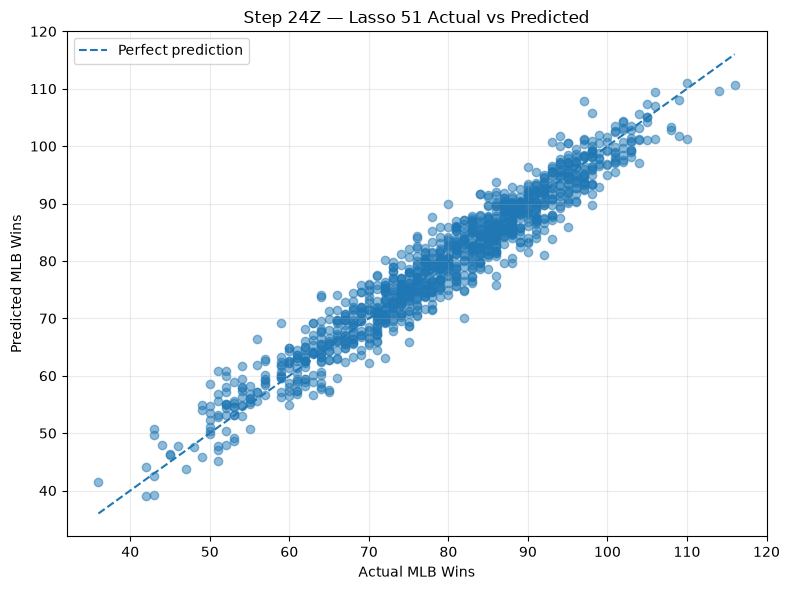

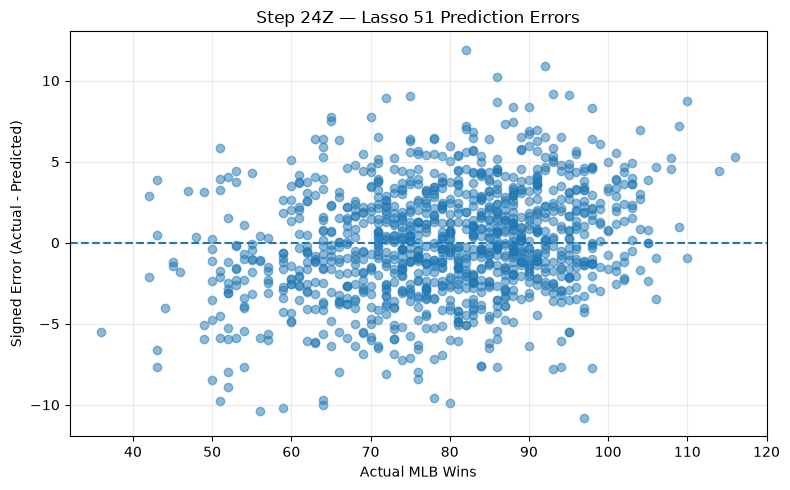

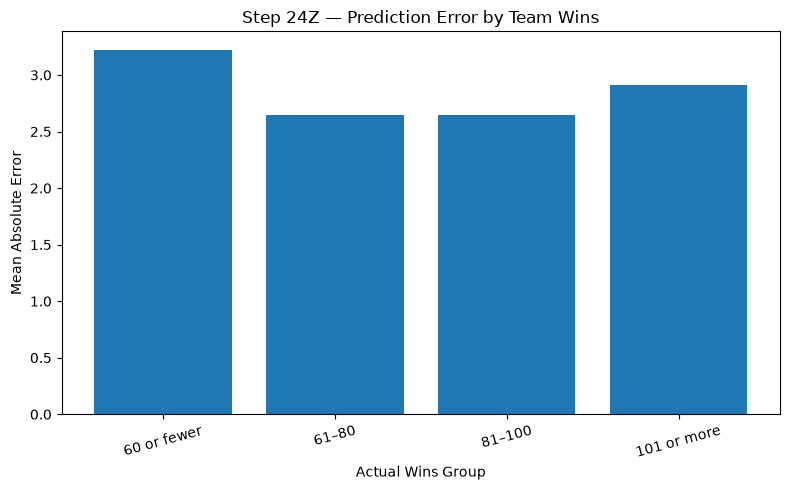


STEP 24Z — FINAL SUMMARY
Mean fold CV MAE: 2.712524
Average signed error: 0.000884
Largest observation-level mean absolute error: 11.90711

IMPORTANT:
- Each observation has 3 validation predictions.
- Predictions are out-of-fold.
- No hold-out data used.
- No Kaggle data used.
- No files modified.
- No model selection based on hold-out errors.

Step 24Z completed.


In [103]:

# ============================================================
# STEP 24Z — LASSO 51 ERROR ANALYSIS
#
# Objectives:
# 1. Find largest prediction errors
# 2. Identify overprediction and underprediction
# 3. Compare errors by actual wins
# 4. Compare errors across decades where available
#
# Uses 5-fold x 3-repeat CV
# No hold-out data
# No Kaggle data
# No files modified
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error
from sklearn.exceptions import ConvergenceWarning

# ------------------------------------------------------------
# 1. RESTORE TRAINING DATA
# ------------------------------------------------------------

X_24z = X58_24m.copy()
y_24z = y_24m.copy()

assert X_24z.shape == (1129, 58)
assert len(y_24z) == 1129
assert X_24z.index.equals(y_24z.index)

removed_24z = [
    "DP",
    "2B",
    "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

features51_24z = [
    col for col in X_24z.columns
    if col not in removed_24z
]

assert len(features51_24z) == 51

print("=" * 75)
print("STEP 24Z — LASSO 51 ERROR ANALYSIS")
print("=" * 75)
print("Observations:", len(X_24z))
print("Features:", len(features51_24z))
print("Alpha:", 0.0025)

# ------------------------------------------------------------
# 2. RECREATE THE STEP 24X LASSO MODEL
# ------------------------------------------------------------

indicator_cols_24z = [
    col for col in features51_24z
    if col.startswith(("era_", "decade_"))
]

numeric_cols_24z = [
    col for col in features51_24z
    if col not in indicator_cols_24z
]

def make_lasso_24z():

    preprocessor = ColumnTransformer([
        (
            "numeric",
            StandardScaler(),
            numeric_cols_24z
        ),
        (
            "indicators",
            "passthrough",
            indicator_cols_24z
        )
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            Lasso(
                alpha=0.0025,
                max_iter=100000,
                tol=1e-5
            )
        )
    ])

# ------------------------------------------------------------
# 3. GENERATE OUT-OF-FOLD PREDICTIONS
# ------------------------------------------------------------

cv_24z = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24z = list(cv_24z.split(X_24z))

records_24z = []
fold_maes_24z = []

with warnings.catch_warnings():

    warnings.simplefilter(
        "ignore",
        ConvergenceWarning
    )

    for fold, (train_idx, val_idx) in enumerate(
        splits_24z,
        start=1
    ):

        model = make_lasso_24z()

        model.fit(
            X_24z.iloc[train_idx],
            y_24z.iloc[train_idx]
        )

        pred = model.predict(
            X_24z.iloc[val_idx]
        )

        actual = y_24z.iloc[val_idx].to_numpy()

        fold_maes_24z.append(
            mean_absolute_error(actual, pred)
        )

        for i, position in enumerate(val_idx):

            records_24z.append({
                "Row_Position": int(position),
                "Fold": fold,
                "Actual_Wins": float(actual[i]),
                "Predicted_Wins": float(pred[i]),
                "Error": float(actual[i] - pred[i]),
                "Absolute_Error": float(
                    abs(actual[i] - pred[i])
                )
            })

oof_24z = pd.DataFrame(records_24z)

assert len(oof_24z) == 1129 * 3
assert (
    oof_24z.groupby("Row_Position").size() == 3
).all()

print("\n" + "=" * 75)
print("STEP 24Z — CROSS-VALIDATION CHECK")
print("=" * 75)

print(
    "Mean fold CV MAE:",
    round(np.mean(fold_maes_24z), 6)
)

print(
    "Number of validation predictions:",
    len(oof_24z)
)

# ------------------------------------------------------------
# 4. AGGREGATE ERRORS BY OBSERVATION
# ------------------------------------------------------------

error_df_24z = (
    oof_24z
    .groupby("Row_Position")
    .agg(
        Actual_Wins=("Actual_Wins", "first"),
        Predicted_Wins=("Predicted_Wins", "mean"),
        Mean_Absolute_Error=("Absolute_Error", "mean"),
        Mean_Error=("Error", "mean")
    )
    .reset_index()
)

error_df_24z["Direction"] = np.where(
    error_df_24z["Mean_Error"] > 0,
    "Underprediction",
    np.where(
        error_df_24z["Mean_Error"] < 0,
        "Overprediction",
        "Exact"
    )
)

# ------------------------------------------------------------
# 5. FIND LARGEST ERRORS
# ------------------------------------------------------------

worst_24z = (
    error_df_24z
    .sort_values(
        "Mean_Absolute_Error",
        ascending=False
    )
    .head(15)
)

print("\n" + "=" * 85)
print("STEP 24Z — TOP 15 LARGEST ERRORS")
print("=" * 85)

print(
    worst_24z
    .round(3)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 6. OVERPREDICTION VS UNDERPREDICTION
# ------------------------------------------------------------

direction_summary_24z = (
    error_df_24z
    .groupby("Direction")
    .agg(
        Observations=("Row_Position", "count"),
        Mean_Absolute_Error=(
            "Mean_Absolute_Error", "mean"
        )
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("STEP 24Z — ERROR DIRECTION")
print("=" * 75)

print(
    direction_summary_24z
    .round(4)
    .to_string(index=False)
)

print(
    "\nMean signed error:",
    round(oof_24z["Error"].mean(), 6)
)

# ------------------------------------------------------------
# 7. ERROR BY ACTUAL WINS
# ------------------------------------------------------------

error_df_24z["Wins_Group"] = pd.cut(
    error_df_24z["Actual_Wins"],
    bins=[-np.inf, 60, 80, 100, np.inf],
    labels=[
        "60 or fewer",
        "61–80",
        "81–100",
        "101 or more"
    ]
)

wins_summary_24z = (
    error_df_24z
    .groupby(
        "Wins_Group",
        observed=True
    )
    .agg(
        Observations=("Row_Position", "count"),
        Mean_Absolute_Error=(
            "Mean_Absolute_Error", "mean"
        ),
        Mean_Error=("Mean_Error", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("STEP 24Z — ERROR BY ACTUAL WINS")
print("=" * 75)

print(
    wins_summary_24z
    .round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 8. ERROR BY DECADE, WHERE AVAILABLE
# ------------------------------------------------------------

decade_cols_24z = [
    col for col in X_24z.columns
    if col.startswith("decade_")
]

if decade_cols_24z:

    decade_matrix = X_24z[
        decade_cols_24z
    ].to_numpy(dtype=float)

    # Identify rows with exactly one active decade flag.
    # Other rows may belong to a reference decade.

    active_count = (
        decade_matrix > 0.5
    ).sum(axis=1)

    decade_names = np.array(
        decade_cols_24z
    )

    decade_labels = np.full(
        len(X_24z),
        "Reference/Unknown",
        dtype=object
    )

    valid = active_count == 1

    decade_labels[valid] = decade_names[
        decade_matrix[valid].argmax(axis=1)
    ]

    error_df_24z["Decade"] = decade_labels[
        error_df_24z["Row_Position"].to_numpy()
    ]

    decade_summary_24z = (
        error_df_24z
        .groupby("Decade")
        .agg(
            Observations=("Row_Position", "count"),
            Mean_Absolute_Error=(
                "Mean_Absolute_Error", "mean"
            ),
            Mean_Error=("Mean_Error", "mean")
        )
        .reset_index()
        .sort_values("Decade")
    )

    print("\n" + "=" * 75)
    print("STEP 24Z — ERROR BY DECADE")
    print("=" * 75)

    print(
        decade_summary_24z
        .round(4)
        .to_string(index=False)
    )

else:
    print(
        "\nNo decade indicator columns available."
    )

# ------------------------------------------------------------
# 9. VISUALIZATION — ACTUAL VS PREDICTED
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    error_df_24z["Actual_Wins"],
    error_df_24z["Predicted_Wins"],
    alpha=0.5
)

limits = [
    min(
        error_df_24z["Actual_Wins"].min(),
        error_df_24z["Predicted_Wins"].min()
    ),
    max(
        error_df_24z["Actual_Wins"].max(),
        error_df_24z["Predicted_Wins"].max()
    )
]

plt.plot(
    limits,
    limits,
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual MLB Wins")
plt.ylabel("Predicted MLB Wins")
plt.title(
    "Step 24Z — Lasso 51 Actual vs Predicted"
)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. VISUALIZATION — PREDICTION ERRORS
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    error_df_24z["Actual_Wins"],
    error_df_24z["Mean_Error"],
    alpha=0.5
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Actual MLB Wins")
plt.ylabel(
    "Signed Error (Actual - Predicted)"
)

plt.title(
    "Step 24Z — Lasso 51 Prediction Errors"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. VISUALIZATION — ERROR BY WINS GROUP
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    wins_summary_24z["Wins_Group"].astype(str),
    wins_summary_24z["Mean_Absolute_Error"]
)

plt.xlabel("Actual Wins Group")
plt.ylabel("Mean Absolute Error")
plt.title(
    "Step 24Z — Prediction Error by Team Wins"
)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 24Z — FINAL SUMMARY")
print("=" * 75)

print(
    "Mean fold CV MAE:",
    round(np.mean(fold_maes_24z), 6)
)

print(
    "Average signed error:",
    round(oof_24z["Error"].mean(), 6)
)

print(
    "Largest observation-level mean absolute error:",
    round(
        error_df_24z[
            "Mean_Absolute_Error"
        ].max(),
        6
    )
)

print("\nIMPORTANT:")
print("- Each observation has 3 validation predictions.")
print("- Predictions are out-of-fold.")
print("- No hold-out data used.")
print("- No Kaggle data used.")
print("- No files modified.")
print("- No model selection based on hold-out errors.")

print("\nStep 24Z completed.")


In [104]:

# ============================================================
# STEP 24AA — LASSO 51, ALPHA = 0.0025
# TRAIN VS HOLD-OUT TEST PERFORMANCE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. USE EXISTING TRAIN / TEST SPLIT
# ------------------------------------------------------------

X_train_24aa = X58_24m.copy()
y_train_24aa = y_24m.copy()

# These must be the ORIGINAL hold-out test variables
# from your earlier train/test split (Step 24T).
# Change only these two names if yours are different.

X_test_24aa = X_test.copy()
y_test_24aa = y_test.copy()

assert len(X_train_24aa) == 1129
assert len(y_train_24aa) == 1129

assert len(X_test_24aa) == 283
assert len(y_test_24aa) == 283

assert X_train_24aa.index.equals(y_train_24aa.index)
assert X_test_24aa.index.equals(y_test_24aa.index)

# ------------------------------------------------------------
# 2. SELECT SAME 51 FEATURES
# ------------------------------------------------------------

removed_24aa = [
    "DP",
    "2B",
    "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

features51_24aa = [
    col for col in X_train_24aa.columns
    if col not in removed_24aa
]

assert len(features51_24aa) == 51

missing_test_cols = [
    col for col in features51_24aa
    if col not in X_test_24aa.columns
]

assert not missing_test_cols, (
    f"Missing test features: {missing_test_cols}"
)

# ------------------------------------------------------------
# 3. PREPROCESSING
# ------------------------------------------------------------

indicator_cols_24aa = [
    col for col in features51_24aa
    if col.startswith(("era_", "decade_"))
]

numeric_cols_24aa = [
    col for col in features51_24aa
    if col not in indicator_cols_24aa
]

preprocessor_24aa = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        numeric_cols_24aa
    ),
    (
        "indicators",
        "passthrough",
        indicator_cols_24aa
    )
])

# ------------------------------------------------------------
# 4. LASSO 51 — ALPHA = 0.0025
# ------------------------------------------------------------

lasso51_24aa = Pipeline([
    ("preprocessor", preprocessor_24aa),
    (
        "model",
        Lasso(
            alpha=0.0025,
            max_iter=100000,
            tol=1e-5
        )
    )
])

# Fit ONLY on training data
lasso51_24aa.fit(
    X_train_24aa,
    y_train_24aa
)

# ------------------------------------------------------------
# 5. PREDICT TRAIN AND TEST
# ------------------------------------------------------------

train_pred_24aa = lasso51_24aa.predict(
    X_train_24aa
)

test_pred_24aa = lasso51_24aa.predict(
    X_test_24aa
)

# ------------------------------------------------------------
# 6. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

def evaluate_24aa(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(
            y_true, y_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true, y_pred
            )
        ),
        "R2": r2_score(
            y_true, y_pred
        )
    }

train_metrics_24aa = evaluate_24aa(
    y_train_24aa,
    train_pred_24aa
)

test_metrics_24aa = evaluate_24aa(
    y_test_24aa,
    test_pred_24aa
)

# ------------------------------------------------------------
# 7. SHOW TRAIN VS TEST RESULTS
# ------------------------------------------------------------

comparison_24aa = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Training": [
        train_metrics_24aa["MAE"],
        train_metrics_24aa["RMSE"],
        train_metrics_24aa["R2"]
    ],
    "Holdout_Test": [
        test_metrics_24aa["MAE"],
        test_metrics_24aa["RMSE"],
        test_metrics_24aa["R2"]
    ]
})

comparison_24aa["Test_minus_Train"] = (
    comparison_24aa["Holdout_Test"]
    - comparison_24aa["Training"]
)

print("=" * 75)
print("STEP 24AA — LASSO 51 (ALPHA = 0.0025)")
print("=" * 75)

print("Training observations:", len(X_train_24aa))
print("Test observations:", len(X_test_24aa))
print("Features:", len(features51_24aa))
print("Alpha:", 0.0025)

print("\n" + "=" * 75)
print("TRAIN VS HOLD-OUT TEST RESULTS")
print("=" * 75)

print(
    comparison_24aa
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 8. GENERALISATION GAP
# ------------------------------------------------------------

mae_gap_24aa = (
    test_metrics_24aa["MAE"]
    - train_metrics_24aa["MAE"]
)

r2_gap_24aa = (
    train_metrics_24aa["R2"]
    - test_metrics_24aa["R2"]
)

print("\n" + "=" * 75)
print("GENERALISATION GAP")
print("=" * 75)

print("MAE gap:", round(mae_gap_24aa, 6))
print("R2 gap:", round(r2_gap_24aa, 6))

print("\nReference:")
print("- Positive MAE gap: test error is higher.")
print("- Positive R2 gap: training R2 is higher.")
print("- Small gaps suggest similar train/test performance.")
print("- Gaps alone do not prove or rule out overfitting.")

print("\nIMPORTANT:")
print("- Original train/test split retained.")
print("- Model fitted only on training data.")
print("- Preprocessing fitted only on training data.")
print("- Continuous predictions evaluated.")
print("- No Kaggle submission generated.")
print("- No files modified.")

print("\nStep 24AA completed.")


STEP 24AA — LASSO 51 (ALPHA = 0.0025)
Training observations: 1129
Test observations: 283
Features: 51
Alpha: 0.0025

TRAIN VS HOLD-OUT TEST RESULTS
Metric  Training  Holdout_Test  Test_minus_Train
   MAE  2.609739      2.654238          0.044498
  RMSE  3.284939      3.254639         -0.030300
    R2  0.940297      0.933711         -0.006586

GENERALISATION GAP
MAE gap: 0.044498
R2 gap: 0.006586

Reference:
- Positive MAE gap: test error is higher.
- Positive R2 gap: training R2 is higher.
- Small gaps suggest similar train/test performance.
- Gaps alone do not prove or rule out overfitting.

IMPORTANT:
- Original train/test split retained.
- Model fitted only on training data.
- Preprocessing fitted only on training data.
- Continuous predictions evaluated.
- No Kaggle submission generated.
- No files modified.

Step 24AA completed.


In [105]:
# Step 24AC — Compare different CV fold settings
# No changes to your existing model

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold, cross_val_score

# Existing Lasso 51 model
model = clone(lasso51_24aa)

# Full labelled dataset
X = X58_24m.drop(
    columns=[
        "DP", "2B", "SO",
        "decade_1950",
        "Middle_x_WalkRate",
        "decade_1960",
        "decade_2010"
    ]
)

y = y_24m

results = []

cv_settings = [
    (5, 3),
    (10, 3),
    (10, 5),
    (20, 3)
]

for folds, repeats in cv_settings:

    cv = RepeatedKFold(
        n_splits=folds,
        n_repeats=repeats,
        random_state=2026
    )

    scores = cross_val_score(
        model,
        X,
        y,
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=-1
    )

    mae = -scores

    results.append({
        "Folds": folds,
        "Repeats": repeats,
        "Total Evaluations": folds * repeats,
        "CV MAE": mae.mean(),
        "CV Std": mae.std()
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 Folds  Repeats  Total Evaluations   CV MAE   CV Std
     5        3                 15 2.712524 0.164192
    10        3                 30 2.713026 0.217584
    10        5                 50 2.716117 0.204907
    20        3                 60 2.710159 0.276579


In [106]:
# ============================================================
# STEP 24AC — MULTICOLLINEARITY ANALYSIS
# 58 Features vs 51 Features
# Diagnostic only — does not modify existing models
# ============================================================

import numpy as np
import pandas as pd

# 1. Prepare feature sets
X58_24ac = X58_24m.copy()

removed_24ac = [
    "DP", "2B", "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

X51_24ac = X58_24ac.drop(columns=removed_24ac)

# 2. Function to check correlation and VIF
def multicollinearity_check(X, name):

    X = X.select_dtypes(include=np.number).copy()

    print(f"\n{'='*60}")
    print(f"{name} — MULTICOLLINEARITY CHECK")
    print(f"{'='*60}")

    # Correlation analysis
    corr = X.corr().abs()

    upper = corr.where(
        np.triu(np.ones(corr.shape), k=1).astype(bool)
    )

    pairs = (
        upper.stack()
        .sort_values(ascending=False)
        .reset_index()
    )

    pairs.columns = [
        "Feature 1", "Feature 2", "Correlation"
    ]

    high_corr = pairs[pairs["Correlation"] >= 0.90]

    print("\nNumber of features:", X.shape[1])
    print("Highly correlated pairs (>= 0.90):", len(high_corr))

    print("\nTop 10 correlated pairs:")
    print(pairs.head(10).to_string(index=False))

    # VIF analysis using linear algebra
    # Include an intercept and standardize features.
    from sklearn.linear_model import LinearRegression

    vif_results = []

    for col in X.columns:

        y_feature = X[col]
        other_features = X.drop(columns=[col])

        if y_feature.nunique() <= 1:
            vif = np.inf
        else:
            reg = LinearRegression()
            reg.fit(other_features, y_feature)

            r2 = reg.score(other_features, y_feature)
            vif = np.inf if r2 >= 1 - 1e-10 else 1 / (1 - r2)

        vif_results.append({
            "Feature": col,
            "VIF": vif
        })

    vif_df = pd.DataFrame(vif_results)
    vif_df = vif_df.sort_values("VIF", ascending=False)

    print("\nTop 15 VIF features:")
    print(vif_df.head(15).to_string(index=False))

    print("\nNumber of features with VIF > 10:",
          (vif_df["VIF"] > 10).sum())

    print("Number of features with VIF > 5:",
          (vif_df["VIF"] > 5).sum())

    return pairs, vif_df


# 3. Run for both feature sets
pairs58_24ac, vif58_24ac = multicollinearity_check(
    X58_24ac, "58 FEATURES"
)

pairs51_24ac, vif51_24ac = multicollinearity_check(
    X51_24ac, "51 FEATURES"
)

# 4. Summary comparison
summary_24ac = pd.DataFrame({
    "Metric": [
        "Number of features",
        "Correlation pairs >= 0.90",
        "Features with VIF > 5",
        "Features with VIF > 10"
    ],
    "58 Features": [
        X58_24ac.shape[1],
        (pairs58_24ac["Correlation"] >= 0.90).sum(),
        (vif58_24ac["VIF"] > 5).sum(),
        (vif58_24ac["VIF"] > 10).sum()
    ],
    "51 Features": [
        X51_24ac.shape[1],
        (pairs51_24ac["Correlation"] >= 0.90).sum(),
        (vif51_24ac["VIF"] > 5).sum(),
        (vif51_24ac["VIF"] > 10).sum()
    ]
})

print("\nFINAL MULTICOLLINEARITY COMPARISON")
print(summary_24ac.to_string(index=False))


58 FEATURES — MULTICOLLINEARITY CHECK

Number of features: 43
Highly correlated pairs (>= 0.90): 19

Top 10 correlated pairs:
                Feature 1                 Feature 2  Correlation
Pythagorean_Expected_Wins Pythagenpat_Expected_Wins     0.999396
       Middle_x_RunMargin  Middle_x_PythagenpatRate     0.997318
        Early_x_RunMargin   Early_x_PythagenpatRate     0.993973
Pythagorean_Expected_Wins    RunDiff_over_TotalRuns     0.990394
Pythagenpat_Expected_Wins    RunDiff_over_TotalRuns     0.988740
                       ER                       ERA     0.988684
                        R                R_per_game     0.987256
                       RA               RA_per_game     0.987211
                       BB             BB_Rate_Proxy     0.982657
             Middle_x_ERA         Middle_x_WalkRate     0.976340

Top 15 VIF features:
                  Feature           VIF
Pythagenpat_Expected_Wins 238461.336320
Pythagorean_Expected_Wins 104703.227262
                

In [107]:
# STEP 24AD — Find existing Lasso pipelines

from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso

print("EXISTING LASSO PIPELINES")
print("=" * 60)

found = 0

for name, obj in list(globals().items()):
    if isinstance(obj, Pipeline):
        estimator = obj.steps[-1][1]

        if isinstance(estimator, Lasso):
            found += 1
            print(
                f"Variable: {name} | "
                f"Alpha: {estimator.alpha}"
            )

print("=" * 60)
print("Total pipelines found:", found)

EXISTING LASSO PIPELINES
Variable: lasso_e1_44 | Alpha: 1.0
Variable: pipeline_44 | Alpha: 1.0
Variable: lasso_44 | Alpha: 0.01
Variable: pipe | Alpha: 0.001
Variable: lasso_33 | Alpha: 0.01
Variable: cv_model_33 | Alpha: 0.01
Variable: cv_model_47 | Alpha: 0.01
Variable: cv_model_32 | Alpha: 0.01
Variable: pipeline_48 | Alpha: 1.0
Variable: lasso_48 | Alpha: 0.01
Variable: pipeline | Alpha: 1.0
Variable: lasso_56 | Alpha: 0.01
Variable: model_48_eval | Alpha: 0.01
Variable: model_56_eval | Alpha: 0.01
Variable: model_56 | Alpha: 0.01
Variable: model_61 | Alpha: 0.01
Variable: model_48_submission | Alpha: 0.01
Variable: model | Alpha: 0.0025
Variable: stack_lasso | Alpha: 0.01
Variable: lasso48 | Alpha: 0.01
Variable: lasso56 | Alpha: 0.01
Variable: lasso_submission_model | Alpha: 0.01
Variable: lasso56_24d | Alpha: 0.01
Variable: lasso60_24d | Alpha: 0.0075
Variable: model_a | Alpha: 0.0075
Variable: model_b | Alpha: 4.717539086689999e-05
Variable: lasso68_final_24j | Alpha: 0.0075
Va

In [108]:
# STEP 24AD — Check preprocessing and model settings

print("Lasso 51 pipeline:")
print(lasso51_24aa)

print("\n58-feature dataset shape:")
print(X58_24m.shape)

Lasso 51 pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['G', 'R', 'AB', 'H', '3B',
                                                   'HR', 'BB', 'SB', 'RA', 'ER',
                                                   'ERA', 'CG', 'SHO', 'SV',
                                                   'IPouts', 'HA', 'HRA', 'BBA',
                                                   'SOA', 'E', 'mlb_rpg',
                                                   'R_per_game', 'RA_per_game',
                                                   'Pythagorean_Expected_Wins',
                                                   'Batting_Average',
                                                   'Isolated_Power',
                                                   'WHIP_Proxy',
                                                   'BB_Rate_Proxy',
                                              

In [109]:
# ============================================================
# STEP 24AD — LASSO COEFFICIENT STABILITY
# Lasso 58 vs Lasso 51
# Diagnostic only — original models remain unchanged
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import RepeatedKFold

# ------------------------------------------------------------
# 1. Prepare existing feature sets
# ------------------------------------------------------------

X58_24ad = X58_24m.copy()

removed_24ad = [
    "DP", "2B", "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

X51_24ad = X58_24ad.drop(
    columns=removed_24ad
).copy()

y_24ad = np.asarray(y_24m).ravel()

assert X58_24ad.shape[1] == 58
assert X51_24ad.shape[1] == 51
assert len(X58_24ad) == len(y_24ad)

# ------------------------------------------------------------
# 2. Reconstruct Lasso 58 diagnostic pipeline
# ------------------------------------------------------------

indicator_cols_58 = [
    c for c in X58_24ad.columns
    if c.startswith(("era_", "decade_"))
]

numeric_cols_58 = [
    c for c in X58_24ad.columns
    if c not in indicator_cols_58
]

preprocessor58_24ad = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_cols_58),
        ("indicators", "passthrough", indicator_cols_58)
    ]
)

model58_24ad = Pipeline([
    ("preprocessor", preprocessor58_24ad),
    ("model", Lasso(
        alpha=0.005,
        max_iter=100000,
        tol=1e-5
    ))
])

# ------------------------------------------------------------
# 3. Existing Lasso 51 pipeline
# ------------------------------------------------------------

model51_24ad = clone(lasso51_24aa)

# ------------------------------------------------------------
# 4. Stability analysis function
# ------------------------------------------------------------

def stability_analysis_24ad(X, y, pipeline, name):

    cv = RepeatedKFold(
        n_splits=5,
        n_repeats=3,
        random_state=2026
    )

    coefficient_rows = []

    for train_idx, _ in cv.split(X):

        fitted_model = clone(pipeline)

        fitted_model.fit(
            X.iloc[train_idx],
            y[train_idx]
        )

        coefficients = fitted_model.named_steps[
            "model"
        ].coef_

        # Get feature names in transformed order
        feature_names = fitted_model.named_steps[
            "preprocessor"
        ].get_feature_names_out()

        # Remove transformer prefixes
        feature_names = [
            name.split("__", 1)[-1]
            for name in feature_names
        ]

        if len(coefficients) != len(feature_names):
            raise ValueError(
                "Coefficient and feature-name mismatch"
            )

        coefficient_rows.append(
            pd.Series(coefficients, index=feature_names)
        )

    coefficients_df = pd.DataFrame(coefficient_rows)

    selected = coefficients_df.abs() > 1e-8

    summary = pd.DataFrame({
        "Feature": coefficients_df.columns,
        "Selection_Frequency_%":
            selected.mean().values * 100,
        "Mean_Coefficient":
            coefficients_df.mean().values,
        "Coefficient_Std":
            coefficients_df.std().values
    })

    summary = summary.sort_values(
        ["Selection_Frequency_%", "Feature"],
        ascending=[False, True]
    ).reset_index(drop=True)

    always = (selected.sum() == len(selected)).sum()
    never = (selected.sum() == 0).sum()
    sometimes = (
        (selected.sum() > 0) &
        (selected.sum() < len(selected))
    ).sum()

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    print("Features:", X.shape[1])
    print("Model fits:", len(coefficients_df))
    print("Always selected:", always)
    print("Never selected:", never)
    print("Sometimes selected:", sometimes)

    print("\nTop 20 features:")
    print(
        summary.head(20).to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

    return summary, coefficients_df

# ------------------------------------------------------------
# 5. Analyze Lasso 58
# ------------------------------------------------------------

stability58_24ad, coef58_24ad = stability_analysis_24ad(
    X58_24ad,
    y_24ad,
    model58_24ad,
    "LASSO 58 — COEFFICIENT STABILITY"
)

# ------------------------------------------------------------
# 6. Analyze Lasso 51
# ------------------------------------------------------------

stability51_24ad, coef51_24ad = stability_analysis_24ad(
    X51_24ad,
    y_24ad,
    model51_24ad,
    "LASSO 51 — COEFFICIENT STABILITY"
)

# ------------------------------------------------------------
# 7. Final comparison
# ------------------------------------------------------------

def count_stability(summary):
    freq = summary["Selection_Frequency_%"]

    return [
        int(np.isclose(freq, 100).sum()),
        int(np.isclose(freq, 0).sum()),
        int(((freq > 0) & (freq < 100)).sum())
    ]

comparison_24ad = pd.DataFrame({
    "Metric": [
        "Total features",
        "Always selected",
        "Never selected",
        "Sometimes selected"
    ],
    "Lasso 58": [
        58, *count_stability(stability58_24ad)
    ],
    "Lasso 51": [
        51, *count_stability(stability51_24ad)
    ]
})

print("\nFINAL STABILITY COMPARISON")
print(comparison_24ad.to_string(index=False))

# ------------------------------------------------------------
# 8. Check the two highly correlated win features
# ------------------------------------------------------------

important_features = [
    "Pythagorean_Expected_Wins",
    "Pythagenpat_Expected_Wins"
]

print("\nPYTHAGOREAN FEATURE STABILITY — LASSO 58")
print(
    stability58_24ad[
        stability58_24ad["Feature"].isin(important_features)
    ].to_string(index=False)
)

print("\nPYTHAGOREAN FEATURE STABILITY — LASSO 51")
print(
    stability51_24ad[
        stability51_24ad["Feature"].isin(important_features)
    ].to_string(index=False)
)


LASSO 58 — COEFFICIENT STABILITY
Features: 58
Model fits: 15
Always selected: 22
Never selected: 4
Sometimes selected: 32

Top 20 features:
                  Feature  Selection_Frequency_%  Mean_Coefficient  Coefficient_Std
                       AB               100.0000           -3.9518           0.2149
            BB_Rate_Proxy               100.0000           -0.1677           0.0924
          Batting_Average               100.0000            2.3647           0.2118
                       CG               100.0000            3.3907           0.1820
                        E               100.0000           -0.7269           0.2431
  Early_x_PythagenpatRate               100.0000            0.2945           0.2022
                        G               100.0000           -1.4010           0.1649
                      HRA               100.0000           -0.4119           0.1445
                   IPouts               100.0000            4.7147           0.2707
           Isolated

In [110]:
# ============================================================
# STEP 24AE — LASSO 51 vs LASSO 50
# Test removal of Pythagorean_Expected_Wins
# Existing models remain unchanged
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.compose import ColumnTransformer

# ------------------------------------------------------------
# 1. Prepare datasets
# ------------------------------------------------------------

X51_24ae = X51_24ad.copy()
y_24ae = np.asarray(y_24ad).ravel()

feature_to_remove_24ae = "Pythagorean_Expected_Wins"

assert feature_to_remove_24ae in X51_24ae.columns

X50_24ae = X51_24ae.drop(
    columns=[feature_to_remove_24ae]
).copy()

print("Lasso 51 features:", X51_24ae.shape[1])
print("Lasso 50 features:", X50_24ae.shape[1])

# ------------------------------------------------------------
# 2. Existing Lasso 51 model — unchanged
# ------------------------------------------------------------

lasso51_24ae = clone(lasso51_24aa)

# ------------------------------------------------------------
# 3. Construct Lasso 50 using identical model settings
# ------------------------------------------------------------

lasso50_24ae = clone(lasso51_24aa)

# Update preprocessing column lists for Lasso 50
preprocessor_24ae = lasso50_24ae.named_steps["preprocessor"]

new_transformers_24ae = []

for name, transformer, columns in preprocessor_24ae.transformers:

    updated_columns = [
        col for col in columns
        if col != feature_to_remove_24ae
    ]

    new_transformers_24ae.append(
        (name, transformer, updated_columns)
    )

lasso50_24ae.set_params(
    preprocessor=ColumnTransformer(
        transformers=new_transformers_24ae,
        remainder="drop"
    )
)

# ------------------------------------------------------------
# 4. Identical repeated cross-validation
# ------------------------------------------------------------

cv_24ae = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

splits_24ae = list(cv_24ae.split(X51_24ae))

scores51_24ae = -cross_val_score(
    lasso51_24ae,
    X51_24ae,
    y_24ae,
    cv=splits_24ae,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    error_score="raise"
)

scores50_24ae = -cross_val_score(
    lasso50_24ae,
    X50_24ae,
    y_24ae,
    cv=splits_24ae,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    error_score="raise"
)

# ------------------------------------------------------------
# 5. Compare MAE
# ------------------------------------------------------------

comparison_24ae = pd.DataFrame({
    "Model": ["Lasso 51", "Lasso 50"],
    "Features": [51, 50],
    "Alpha": [
        lasso51_24ae.named_steps["model"].alpha,
        lasso50_24ae.named_steps["model"].alpha
    ],
    "CV_MAE": [
        scores51_24ae.mean(),
        scores50_24ae.mean()
    ],
    "CV_Std": [
        scores51_24ae.std(),
        scores50_24ae.std()
    ]
})

comparison_24ae = comparison_24ae.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("\n" + "=" * 65)
print("STEP 24AE — LASSO 51 vs LASSO 50")
print("=" * 65)

print(
    comparison_24ae.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 6. Paired fold-by-fold comparison
# ------------------------------------------------------------

fold_comparison_24ae = pd.DataFrame({
    "Fold": np.arange(1, len(scores51_24ae) + 1),
    "Lasso51_MAE": scores51_24ae,
    "Lasso50_MAE": scores50_24ae
})

fold_comparison_24ae["Improvement"] = (
    fold_comparison_24ae["Lasso51_MAE"]
    - fold_comparison_24ae["Lasso50_MAE"]
)

print("\nPaired fold comparison:")
print(
    fold_comparison_24ae.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 65)
print("FINAL RESULT")
print("=" * 65)

mean_improvement_24ae = (
    scores51_24ae.mean() - scores50_24ae.mean()
)

print(f"Lasso 51 CV MAE: {scores51_24ae.mean():.6f}")
print(f"Lasso 50 CV MAE: {scores50_24ae.mean():.6f}")
print(f"MAE improvement: {mean_improvement_24ae:+.6f}")

if mean_improvement_24ae > 0:
    print("RESULT: Lasso 50 has lower CV MAE.")
elif mean_improvement_24ae < 0:
    print("RESULT: Lasso 51 has lower CV MAE.")
else:
    print("RESULT: Both models have equal CV MAE.")

print(
    "\nFolds where Lasso 50 performs better:",
    int((scores50_24ae < scores51_24ae).sum()),
    "out of",
    len(scores51_24ae)
)

Lasso 51 features: 51
Lasso 50 features: 50

STEP 24AE — LASSO 51 vs LASSO 50
   Model  Features    Alpha   CV_MAE   CV_Std
Lasso 51        51 0.002500 2.712524 0.164192
Lasso 50        50 0.002500 2.712542 0.164115

Paired fold comparison:
 Fold  Lasso51_MAE  Lasso50_MAE  Improvement
    1     2.643841     2.643856    -0.000015
    2     2.989362     2.989588    -0.000226
    3     2.890330     2.890419    -0.000088
    4     2.621108     2.621282    -0.000174
    5     2.412648     2.413395    -0.000747
    6     2.640377     2.640373     0.000004
    7     2.739565     2.739564     0.000002
    8     2.713911     2.713965    -0.000054
    9     2.894425     2.894571    -0.000146
   10     2.515335     2.514909     0.000426
   11     2.780897     2.780835     0.000063
   12     2.991614     2.991137     0.000477
   13     2.581002     2.581002    -0.000000
   14     2.592771     2.592859    -0.000088
   15     2.680669     2.680375     0.000294

FINAL RESULT
Lasso 51 CV MAE: 2.712524

Lasso 58 features: 58
Lasso 51 features: 51
Training observations: 1129

Note: Lasso 58 uses the reconstructed diagnostic
pipeline from Step 24AD, with alpha=0.005.

STEP 24AF — PAIRED CV COMPARISON
 Fold  Lasso58_MAE  Lasso51_MAE  Improvement_51
    1     2.659937     2.643841        0.016096
    2     2.989427     2.989362        0.000065
    3     2.900356     2.890330        0.010026
    4     2.633909     2.621108        0.012800
    5     2.413911     2.412648        0.001263
    6     2.654491     2.640377        0.014114
    7     2.730742     2.739565       -0.008823
    8     2.729292     2.713911        0.015380
    9     2.905899     2.894425        0.011474
   10     2.538461     2.515335        0.023126
   11     2.785201     2.780897        0.004303
   12     3.011478     2.991614        0.019864
   13     2.574286     2.581002       -0.006716
   14     2.606445     2.592771        0.013674
   15     2.685145     2.680669        0.004476

OVERALL PERFORMANCE
   Model  Fe

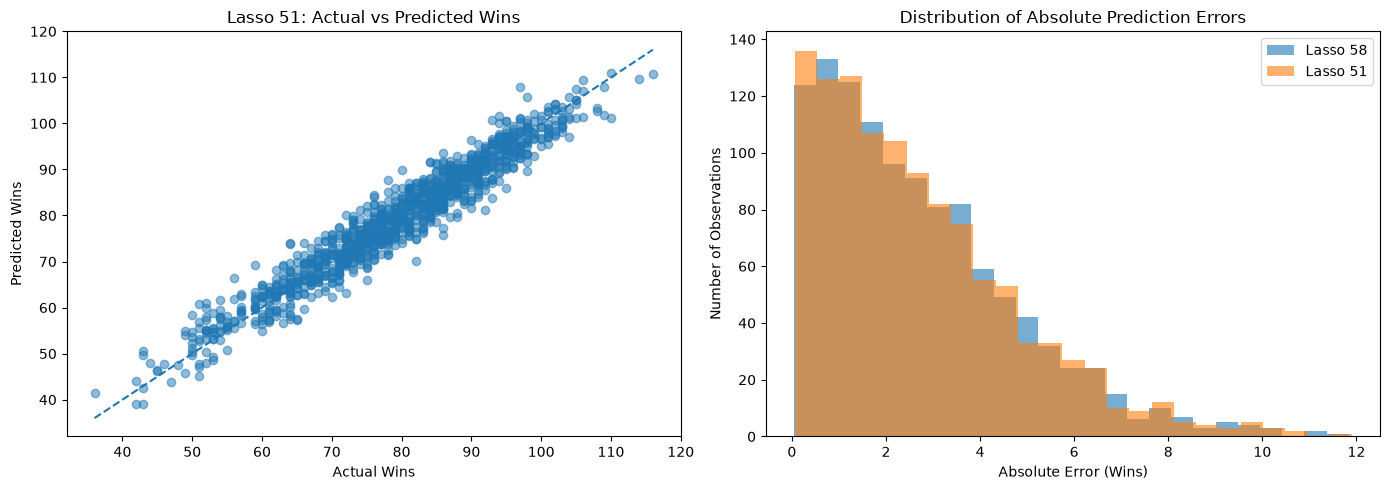

In [111]:
# ============================================================
# STEP 24AF — LASSO 58 vs LASSO 51
# Paired Cross-Validation + Prediction Error Analysis
# Diagnostic only — no changes to existing models
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. Prepare datasets and models
# ------------------------------------------------------------

X58_24af = X58_24ad.copy()
X51_24af = X51_24ad.copy()
y_24af = np.asarray(y_24ad).ravel()

lasso58_24af = clone(model58_24ad)
lasso51_24af = clone(lasso51_24aa)

assert len(X58_24af) == len(X51_24af) == len(y_24af)
assert X58_24af.index.equals(X51_24af.index)

print("Lasso 58 features:", X58_24af.shape[1])
print("Lasso 51 features:", X51_24af.shape[1])
print("Training observations:", len(y_24af))

print("\nNote: Lasso 58 uses the reconstructed diagnostic")
print("pipeline from Step 24AD, with alpha=0.005.")

# ------------------------------------------------------------
# 2. Define identical validation folds
# ------------------------------------------------------------

cv_24af = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

fold_results_24af = []
prediction_rows_24af = []

# ------------------------------------------------------------
# 3. Train and evaluate both models
# ------------------------------------------------------------

for fold, (train_idx, val_idx) in enumerate(
    cv_24af.split(X58_24af), start=1
):

    model58 = clone(lasso58_24af)
    model51 = clone(lasso51_24af)

    model58.fit(
        X58_24af.iloc[train_idx],
        y_24af[train_idx]
    )

    model51.fit(
        X51_24af.iloc[train_idx],
        y_24af[train_idx]
    )

    pred58 = model58.predict(
        X58_24af.iloc[val_idx]
    )

    pred51 = model51.predict(
        X51_24af.iloc[val_idx]
    )

    actual = y_24af[val_idx]

    mae58 = mean_absolute_error(actual, pred58)
    mae51 = mean_absolute_error(actual, pred51)

    fold_results_24af.append({
        "Fold": fold,
        "Lasso58_MAE": mae58,
        "Lasso51_MAE": mae51,
        "Improvement_51": mae58 - mae51
    })

    for j, row_idx in enumerate(val_idx):

        prediction_rows_24af.append({
            "Fold": fold,
            "Row_Position": int(row_idx),
            "Actual_Wins": actual[j],
            "Lasso58_Predicted": pred58[j],
            "Lasso51_Predicted": pred51[j],
            "Lasso58_AbsError": abs(actual[j] - pred58[j]),
            "Lasso51_AbsError": abs(actual[j] - pred51[j])
        })

# ------------------------------------------------------------
# 4. Fold-by-fold results
# ------------------------------------------------------------

fold_df_24af = pd.DataFrame(fold_results_24af)
pred_df_24af = pd.DataFrame(prediction_rows_24af)

print("\n" + "=" * 65)
print("STEP 24AF — PAIRED CV COMPARISON")
print("=" * 65)

print(
    fold_df_24af.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 5. Overall performance comparison
# ------------------------------------------------------------

summary_24af = pd.DataFrame({
    "Model": ["Lasso 58", "Lasso 51"],
    "Features": [58, 51],
    "CV_MAE": [
        fold_df_24af["Lasso58_MAE"].mean(),
        fold_df_24af["Lasso51_MAE"].mean()
    ],
    "CV_Std": [
        fold_df_24af["Lasso58_MAE"].std(ddof=0),
        fold_df_24af["Lasso51_MAE"].std(ddof=0)
    ]
})

print("\n" + "=" * 65)
print("OVERALL PERFORMANCE")
print("=" * 65)

print(
    summary_24af.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

better51 = (
    fold_df_24af["Lasso51_MAE"]
    < fold_df_24af["Lasso58_MAE"]
).sum()

better58 = (
    fold_df_24af["Lasso58_MAE"]
    < fold_df_24af["Lasso51_MAE"]
).sum()

print(f"\nLasso 51 better folds: {better51}/15")
print(f"Lasso 58 better folds: {better58}/15")

print(
    "Mean MAE improvement of Lasso 51:",
    f"{fold_df_24af['Improvement_51'].mean():+.6f}"
)

# ------------------------------------------------------------
# 6. Team-level error analysis
# ------------------------------------------------------------

# Each row is validated once per repeat (3 predictions).
# Average errors by original row position.

team_errors_24af = (
    pred_df_24af
    .groupby("Row_Position")
    .agg(
        Actual_Wins=("Actual_Wins", "first"),
        Lasso58_MAE=("Lasso58_AbsError", "mean"),
        Lasso51_MAE=("Lasso51_AbsError", "mean"),
        Lasso58_Predicted=("Lasso58_Predicted", "mean"),
        Lasso51_Predicted=("Lasso51_Predicted", "mean")
    )
    .reset_index()
)

team_errors_24af["Improvement_51"] = (
    team_errors_24af["Lasso58_MAE"]
    - team_errors_24af["Lasso51_MAE"]
)

print("\n" + "=" * 65)
print("TOP 10 HARDEST OBSERVATIONS — LASSO 51")
print("=" * 65)

print(
    team_errors_24af.nlargest(
        10, "Lasso51_MAE"
    ).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 7. Visualize prediction errors
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    team_errors_24af["Actual_Wins"],
    team_errors_24af["Lasso51_Predicted"],
    alpha=0.5
)

minimum = min(
    team_errors_24af["Actual_Wins"].min(),
    team_errors_24af["Lasso51_Predicted"].min()
)

maximum = max(
    team_errors_24af["Actual_Wins"].max(),
    team_errors_24af["Lasso51_Predicted"].max()
)

axes[0].plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

axes[0].set_title("Lasso 51: Actual vs Predicted Wins")
axes[0].set_xlabel("Actual Wins")
axes[0].set_ylabel("Predicted Wins")

axes[1].hist(
    team_errors_24af["Lasso58_MAE"],
    bins=25,
    alpha=0.6,
    label="Lasso 58"
)

axes[1].hist(
    team_errors_24af["Lasso51_MAE"],
    bins=25,
    alpha=0.6,
    label="Lasso 51"
)

axes[1].set_title("Distribution of Absolute Prediction Errors")
axes[1].set_xlabel("Absolute Error (Wins)")
axes[1].set_ylabel("Number of Observations")
axes[1].legend()

plt.tight_layout()
plt.show()

Unique team-season observations: 1129

STEP 24AG — OVERALL RESIDUAL STATISTICS
                        Metric  Lasso 58  Lasso 51
                 Mean residual    0.0060    0.0009
           Mean absolute error    2.7214    2.7127
         Median absolute error    2.2780    2.2608
90th percentile absolute error    5.6567    5.6493
        Maximum absolute error   12.1653   12.0056

PREDICTION ERRORS BY ACTUAL WINS
       Win_Category  Teams  Lasso58_MAE  Lasso51_MAE  Lasso51_MeanResidual
    Low wins (<=70)    273       2.9924       2.9799               -1.1347
Middle wins (71-90)    612       2.5762       2.5739                0.0812
    High wins (>90)    244       2.7826       2.7618                1.0700

PREDICTION ERRORS BY RUN MARGIN
         RunMargin_Category  Teams  Lasso58_MAE  Lasso51_MAE
     Negative margin (<-50)    364       2.8349       2.8219
Moderate margin (-50 to 50)    356       2.6957       2.6882
      Positive margin (>50)    409       2.6428       2.6369

PRE

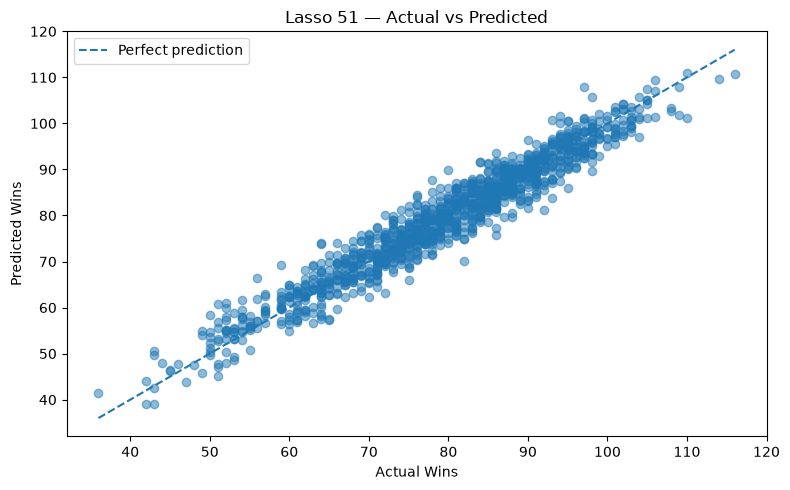

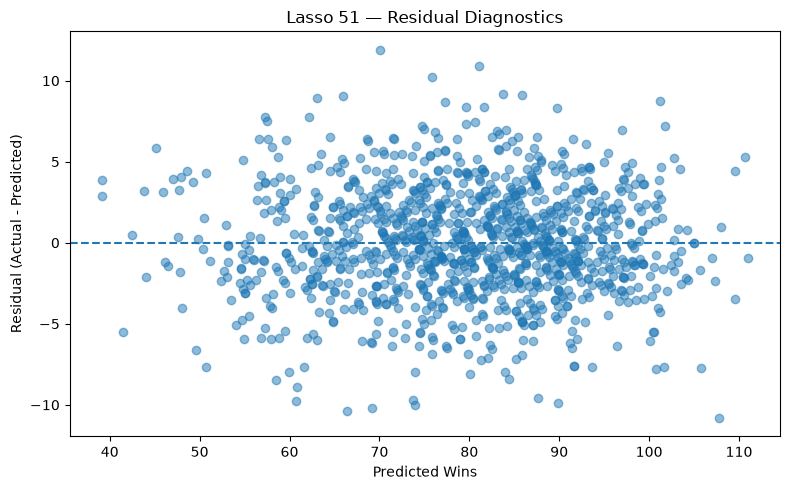

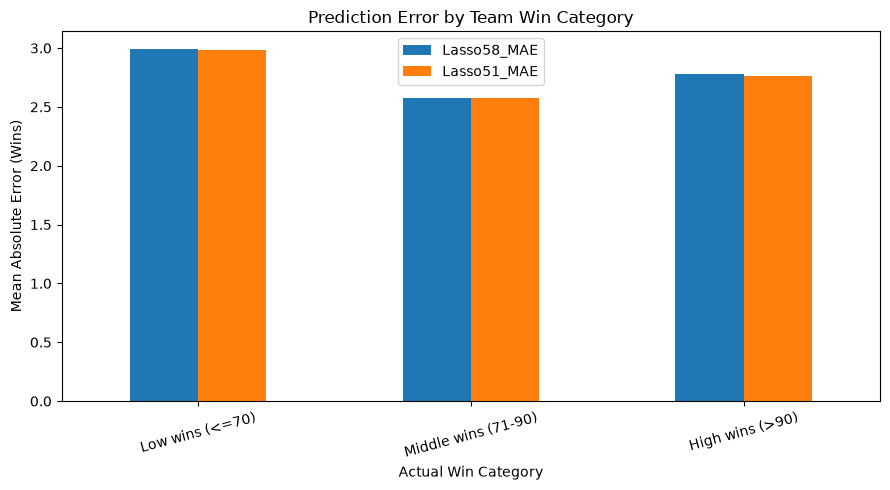

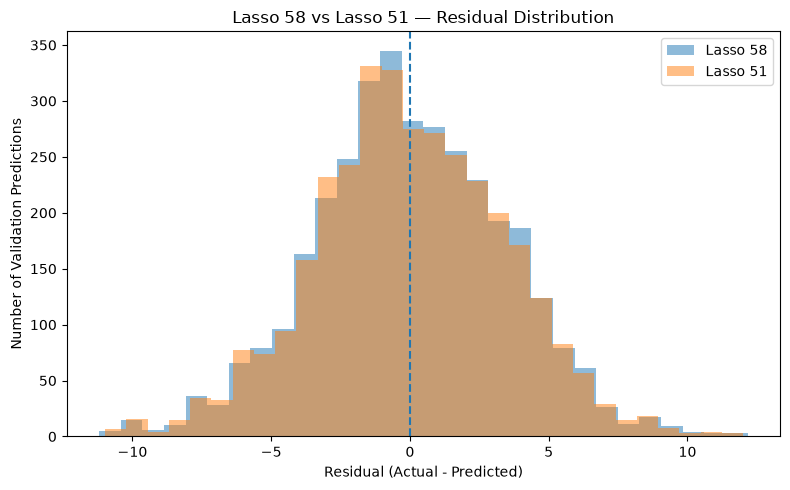


MODEL ERROR SIMILARITY
Correlation between absolute errors: 0.997728
Observations better predicted by Lasso 51: 599
Observations better predicted by Lasso 58: 530

STEP 24AG COMPLETE


In [112]:
# ============================================================
# STEP 24AG — MLB LASSO RESIDUAL DIAGNOSTICS
# Lasso 58 vs Lasso 51
# Uses existing Step 24AF predictions
# No retraining, no changes to existing models
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Prepare existing predictions
# ------------------------------------------------------------

df_24ag = pred_df_24af.copy()

df_24ag["Residual58"] = (
    df_24ag["Actual_Wins"]
    - df_24ag["Lasso58_Predicted"]
)

df_24ag["Residual51"] = (
    df_24ag["Actual_Wins"]
    - df_24ag["Lasso51_Predicted"]
)

# Positive residual = underestimated actual wins
# Negative residual = overestimated actual wins

df_24ag["AbsError58"] = df_24ag["Residual58"].abs()
df_24ag["AbsError51"] = df_24ag["Residual51"].abs()

# Each team-season is predicted three times because
# we used 5 folds x 3 repeats.

team_24ag = (
    df_24ag
    .groupby("Row_Position")
    .agg(
        Actual_Wins=("Actual_Wins", "first"),
        Predicted58=("Lasso58_Predicted", "mean"),
        Predicted51=("Lasso51_Predicted", "mean"),
        MAE58=("AbsError58", "mean"),
        MAE51=("AbsError51", "mean"),
        Residual58=("Residual58", "mean"),
        Residual51=("Residual51", "mean")
    )
    .reset_index()
)

print("Unique team-season observations:", len(team_24ag))

# ------------------------------------------------------------
# 2. Overall residual statistics
# ------------------------------------------------------------

summary_24ag = pd.DataFrame({
    "Metric": [
        "Mean residual",
        "Mean absolute error",
        "Median absolute error",
        "90th percentile absolute error",
        "Maximum absolute error"
    ],
    "Lasso 58": [
        df_24ag["Residual58"].mean(),
        df_24ag["AbsError58"].mean(),
        df_24ag["AbsError58"].median(),
        df_24ag["AbsError58"].quantile(0.90),
        df_24ag["AbsError58"].max()
    ],
    "Lasso 51": [
        df_24ag["Residual51"].mean(),
        df_24ag["AbsError51"].mean(),
        df_24ag["AbsError51"].median(),
        df_24ag["AbsError51"].quantile(0.90),
        df_24ag["AbsError51"].max()
    ]
})

print("\n" + "=" * 65)
print("STEP 24AG — OVERALL RESIDUAL STATISTICS")
print("=" * 65)

print(
    summary_24ag.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 3. Analyze low-, middle-, and high-win teams
# ------------------------------------------------------------

# These are illustrative diagnostic categories.
# They are not official MLB classifications.

team_24ag["Win_Category"] = pd.cut(
    team_24ag["Actual_Wins"],
    bins=[-np.inf, 70, 90, np.inf],
    labels=[
        "Low wins (<=70)",
        "Middle wins (71-90)",
        "High wins (>90)"
    ]
)

win_analysis_24ag = (
    team_24ag
    .groupby("Win_Category", observed=True)
    .agg(
        Teams=("Actual_Wins", "size"),
        Lasso58_MAE=("MAE58", "mean"),
        Lasso51_MAE=("MAE51", "mean"),
        Lasso51_MeanResidual=("Residual51", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 65)
print("PREDICTION ERRORS BY ACTUAL WINS")
print("=" * 65)

print(
    win_analysis_24ag.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 4. Analyze run margin
# ------------------------------------------------------------

# Identify an existing run-margin feature.

run_margin_candidates_24ag = [
    "Run_Margin",
    "RunMargin",
    "run_margin",
    "R_minus_RA"
]

run_margin_col_24ag = next(
    (
        c for c in run_margin_candidates_24ag
        if c in X58_24af.columns
    ),
    None
)

if run_margin_col_24ag is not None:

    team_24ag["Run_Margin"] = (
        X58_24af.iloc[
            team_24ag["Row_Position"].to_numpy()
        ][run_margin_col_24ag].to_numpy()
    )

else:

    # R - RA is a conventional season run margin.
    # Only calculate if both columns exist.

    if {"R", "RA"}.issubset(X58_24af.columns):

        selected_rows = X58_24af.iloc[
            team_24ag["Row_Position"].to_numpy()
        ]

        team_24ag["Run_Margin"] = (
            selected_rows["R"].to_numpy()
            - selected_rows["RA"].to_numpy()
        )

    else:
        team_24ag["Run_Margin"] = np.nan

if team_24ag["Run_Margin"].notna().any():

    team_24ag["RunMargin_Category"] = pd.cut(
        team_24ag["Run_Margin"],
        bins=[-np.inf, -50, 50, np.inf],
        labels=[
            "Negative margin (<-50)",
            "Moderate margin (-50 to 50)",
            "Positive margin (>50)"
        ]
    )

    margin_analysis_24ag = (
        team_24ag
        .groupby("RunMargin_Category", observed=True)
        .agg(
            Teams=("Actual_Wins", "size"),
            Lasso58_MAE=("MAE58", "mean"),
            Lasso51_MAE=("MAE51", "mean")
        )
        .reset_index()
    )

    print("\n" + "=" * 65)
    print("PREDICTION ERRORS BY RUN MARGIN")
    print("=" * 65)

    print(
        margin_analysis_24ag.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

else:
    print("\nRun margin not available — analysis skipped.")

# ------------------------------------------------------------
# 5. Analyze historical eras
# ------------------------------------------------------------

era_columns_24ag = [
    c for c in X58_24af.columns
    if c.startswith("era_")
]

if era_columns_24ag:

    era_data_24ag = X58_24af.iloc[
        team_24ag["Row_Position"].to_numpy()
    ][era_columns_24ag].copy()

    # Indicator columns are expected to be 0 or 1.
    # All-zero rows form the reference era.

    era_values_24ag = era_data_24ag.to_numpy()

    era_names_24ag = np.array(era_columns_24ag)

    era_labels_24ag = np.where(
        era_values_24ag.max(axis=1) > 0,
        era_names_24ag[era_values_24ag.argmax(axis=1)],
        "Reference era"
    )

    team_24ag["Era"] = era_labels_24ag

    era_analysis_24ag = (
        team_24ag
        .groupby("Era")
        .agg(
            Teams=("Actual_Wins", "size"),
            Lasso58_MAE=("MAE58", "mean"),
            Lasso51_MAE=("MAE51", "mean")
        )
        .reset_index()
        .sort_values("Lasso51_MAE", ascending=False)
    )

    print("\n" + "=" * 65)
    print("PREDICTION ERRORS BY ERA")
    print("=" * 65)

    print(
        era_analysis_24ag.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

# ------------------------------------------------------------
# 6. Visual diagnostics
# ------------------------------------------------------------

# Graph 1 — Actual vs Predicted Wins

plt.figure(figsize=(8, 5))

plt.scatter(
    team_24ag["Actual_Wins"],
    team_24ag["Predicted51"],
    alpha=0.5
)

limits = [
    min(
        team_24ag["Actual_Wins"].min(),
        team_24ag["Predicted51"].min()
    ),
    max(
        team_24ag["Actual_Wins"].max(),
        team_24ag["Predicted51"].max()
    )
]

plt.plot(
    limits,
    limits,
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Wins")
plt.ylabel("Predicted Wins")
plt.title("Lasso 51 — Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2 — Residuals vs Predicted Wins

plt.figure(figsize=(8, 5))

plt.scatter(
    team_24ag["Predicted51"],
    team_24ag["Residual51"],
    alpha=0.5
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Wins")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Lasso 51 — Residual Diagnostics")
plt.tight_layout()
plt.show()

# Graph 3 — Error by Win Category

plot_win_24ag = win_analysis_24ag.set_index(
    "Win_Category"
)[["Lasso58_MAE", "Lasso51_MAE"]]

plot_win_24ag.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Mean Absolute Error (Wins)")
plt.xlabel("Actual Win Category")
plt.title("Prediction Error by Team Win Category")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Graph 4 — Residual Distribution

plt.figure(figsize=(8, 5))

plt.hist(
    df_24ag["Residual58"],
    bins=30,
    alpha=0.5,
    label="Lasso 58"
)

plt.hist(
    df_24ag["Residual51"],
    bins=30,
    alpha=0.5,
    label="Lasso 51"
)

plt.axvline(0, linestyle="--")

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Number of Validation Predictions")
plt.title("Lasso 58 vs Lasso 51 — Residual Distribution")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Compare errors on the same observations
# ------------------------------------------------------------

team_24ag["Error_Improvement_51"] = (
    team_24ag["MAE58"]
    - team_24ag["MAE51"]
)

print("\n" + "=" * 65)
print("MODEL ERROR SIMILARITY")
print("=" * 65)

print(
    "Correlation between absolute errors:",
    round(
        team_24ag[["MAE58", "MAE51"]]
        .corr().iloc[0, 1],
        6
    )
)

print(
    "Observations better predicted by Lasso 51:",
    int((team_24ag["MAE51"] < team_24ag["MAE58"]).sum())
)

print(
    "Observations better predicted by Lasso 58:",
    int((team_24ag["MAE58"] < team_24ag["MAE51"]).sum())
)

print("\nSTEP 24AG COMPLETE")

Unique team-season observations: 1129

STEP 24AH — CALIBRATION SUMMARY
   Model  Intercept    Slope  Mean_Residual      MAE
Lasso 58   0.113312 0.998648       0.006006 2.714835
Lasso 51   0.135050 0.998310       0.000884 2.706996

LASSO 51 — CALIBRATION BY PREDICTED WINS
                   Group  Teams  Mean_Predicted  Mean_Actual  Mean_Residual
    Low predicted (<=70)    264         61.3567      61.1780        -0.1787
Middle predicted (70-90)    617         80.4111      80.5381         0.1270
    High predicted (>90)    248         96.0048      95.8831        -0.1218

LASSO 58 — CALIBRATION BY PREDICTED WINS
                   Group  Teams  Mean_Predicted  Mean_Actual  Mean_Residual
    Low predicted (<=70)    264         61.3685      61.1780        -0.1905
Middle predicted (70-90)    617         80.3993      80.5381         0.1388
    High predicted (>90)    248         95.9982      95.8831        -0.1151


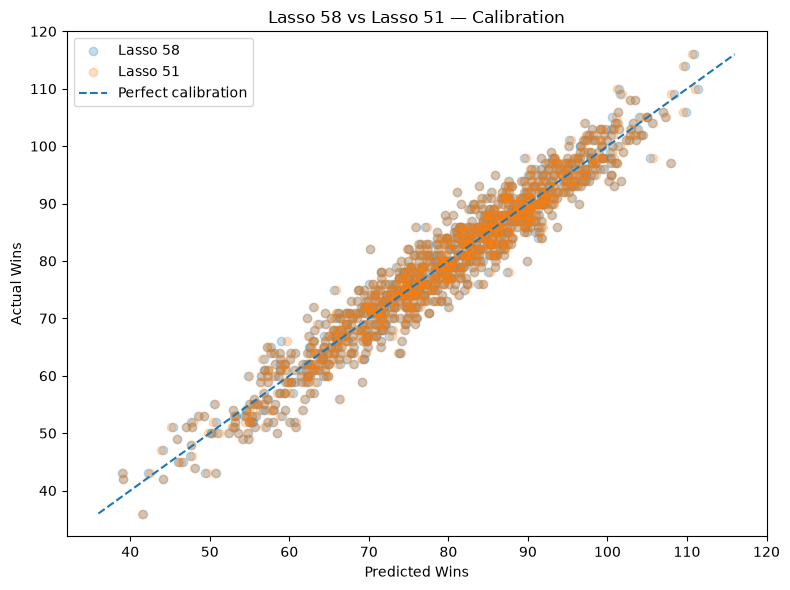

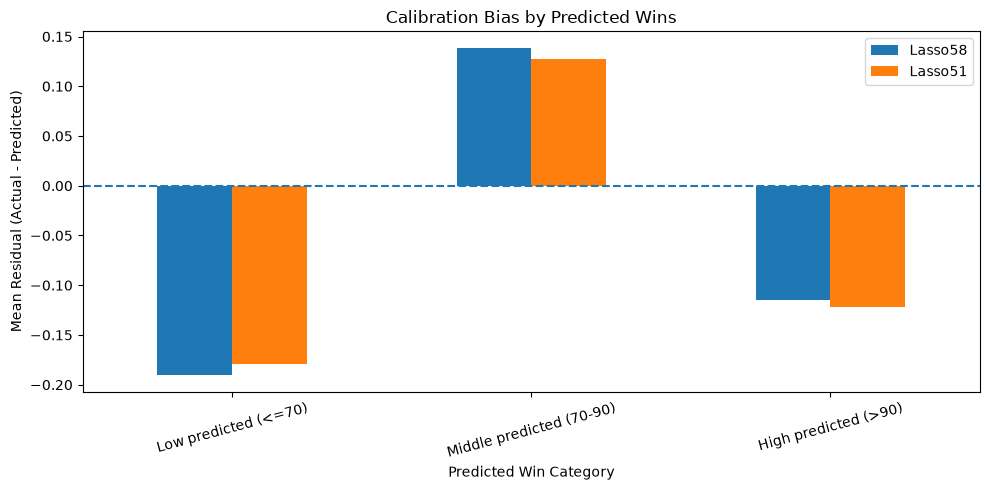


FINAL CALIBRATION DIAGNOSTIC

Lasso 58
Calibration slope: 0.998648
Calibration intercept: 0.113312
Mean residual: 0.006006
Slope below 1: actual outcomes vary less than the predictions.

Lasso 51
Calibration slope: 0.998310
Calibration intercept: 0.135050
Mean residual: 0.000884
Slope below 1: actual outcomes vary less than the predictions.

STEP 24AH COMPLETE


In [113]:
# ============================================================
# STEP 24AH — MLB LASSO CALIBRATION ANALYSIS
# Lasso 58 vs Lasso 51
#
# Uses existing Step 24AF out-of-fold predictions
# No model retraining
# No changes to existing models
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. Prepare existing cross-validation predictions
# ------------------------------------------------------------

calibration_24ah = pred_df_24af.copy()

required_cols = [
    "Row_Position",
    "Actual_Wins",
    "Lasso58_Predicted",
    "Lasso51_Predicted"
]

missing_cols = [
    c for c in required_cols
    if c not in calibration_24ah.columns
]

if missing_cols:
    raise ValueError(
        f"Missing columns: {missing_cols}"
    )

# Each observation has 3 out-of-fold predictions
# because Step 24AF used 5 folds x 3 repeats.

team_calibration_24ah = (
    calibration_24ah
    .groupby("Row_Position")
    .agg(
        Actual_Wins=("Actual_Wins", "first"),
        Predicted58=("Lasso58_Predicted", "mean"),
        Predicted51=("Lasso51_Predicted", "mean")
    )
    .reset_index()
)

print(
    "Unique team-season observations:",
    len(team_calibration_24ah)
)

# ------------------------------------------------------------
# 2. Calibration regression
# Actual Wins = Intercept + Slope x Predicted Wins
# ------------------------------------------------------------

def calibration_metrics_24ah(actual, predicted, name):

    X = np.asarray(predicted).reshape(-1, 1)
    y = np.asarray(actual)

    calibration_model = LinearRegression()
    calibration_model.fit(X, y)

    slope = calibration_model.coef_[0]
    intercept = calibration_model.intercept_

    residual = y - np.asarray(predicted)

    return {
        "Model": name,
        "Intercept": intercept,
        "Slope": slope,
        "Mean_Residual": residual.mean(),
        "MAE": mean_absolute_error(y, predicted)
    }


metrics58_24ah = calibration_metrics_24ah(
    team_calibration_24ah["Actual_Wins"],
    team_calibration_24ah["Predicted58"],
    "Lasso 58"
)

metrics51_24ah = calibration_metrics_24ah(
    team_calibration_24ah["Actual_Wins"],
    team_calibration_24ah["Predicted51"],
    "Lasso 51"
)

calibration_summary_24ah = pd.DataFrame([
    metrics58_24ah,
    metrics51_24ah
])

print("\n" + "=" * 65)
print("STEP 24AH — CALIBRATION SUMMARY")
print("=" * 65)

print(
    calibration_summary_24ah.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 3. Signed residuals
# ------------------------------------------------------------

team_calibration_24ah["Residual58"] = (
    team_calibration_24ah["Actual_Wins"]
    - team_calibration_24ah["Predicted58"]
)

team_calibration_24ah["Residual51"] = (
    team_calibration_24ah["Actual_Wins"]
    - team_calibration_24ah["Predicted51"]
)

# Positive residual = underprediction
# Negative residual = overprediction

# ------------------------------------------------------------
# 4. Group observations by PREDICTED wins
# ------------------------------------------------------------

# Unlike Step 24AG, these categories use predictions,
# not actual wins.

bins_24ah = [-np.inf, 70, 90, np.inf]

labels_24ah = [
    "Low predicted (<=70)",
    "Middle predicted (70-90)",
    "High predicted (>90)"
]

team_calibration_24ah["Group51"] = pd.cut(
    team_calibration_24ah["Predicted51"],
    bins=bins_24ah,
    labels=labels_24ah
)

team_calibration_24ah["Group58"] = pd.cut(
    team_calibration_24ah["Predicted58"],
    bins=bins_24ah,
    labels=labels_24ah
)

group51_24ah = (
    team_calibration_24ah
    .groupby("Group51", observed=True)
    .agg(
        Teams=("Actual_Wins", "size"),
        Mean_Predicted=("Predicted51", "mean"),
        Mean_Actual=("Actual_Wins", "mean"),
        Mean_Residual=("Residual51", "mean")
    )
    .reset_index()
    .rename(columns={"Group51": "Group"})
)

group58_24ah = (
    team_calibration_24ah
    .groupby("Group58", observed=True)
    .agg(
        Teams=("Actual_Wins", "size"),
        Mean_Predicted=("Predicted58", "mean"),
        Mean_Actual=("Actual_Wins", "mean"),
        Mean_Residual=("Residual58", "mean")
    )
    .reset_index()
    .rename(columns={"Group58": "Group"})
)

print("\n" + "=" * 65)
print("LASSO 51 — CALIBRATION BY PREDICTED WINS")
print("=" * 65)

print(
    group51_24ah.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 65)
print("LASSO 58 — CALIBRATION BY PREDICTED WINS")
print("=" * 65)

print(
    group58_24ah.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. Graph — Calibration scatterplot
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    team_calibration_24ah["Predicted58"],
    team_calibration_24ah["Actual_Wins"],
    alpha=0.25,
    label="Lasso 58"
)

plt.scatter(
    team_calibration_24ah["Predicted51"],
    team_calibration_24ah["Actual_Wins"],
    alpha=0.25,
    label="Lasso 51"
)

minimum_24ah = min(
    team_calibration_24ah["Actual_Wins"].min(),
    team_calibration_24ah["Predicted58"].min(),
    team_calibration_24ah["Predicted51"].min()
)

maximum_24ah = max(
    team_calibration_24ah["Actual_Wins"].max(),
    team_calibration_24ah["Predicted58"].max(),
    team_calibration_24ah["Predicted51"].max()
)

plt.plot(
    [minimum_24ah, maximum_24ah],
    [minimum_24ah, maximum_24ah],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Predicted Wins")
plt.ylabel("Actual Wins")
plt.title("Lasso 58 vs Lasso 51 — Calibration")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Graph — Mean residual by predicted-win group
# ------------------------------------------------------------

group_comparison_24ah = pd.DataFrame({
    "Group": labels_24ah
})

group_comparison_24ah = group_comparison_24ah.merge(
    group58_24ah[["Group", "Mean_Residual"]].rename(
        columns={"Mean_Residual": "Lasso58"}
    ),
    on="Group",
    how="left"
)

group_comparison_24ah = group_comparison_24ah.merge(
    group51_24ah[["Group", "Mean_Residual"]].rename(
        columns={"Mean_Residual": "Lasso51"}
    ),
    on="Group",
    how="left"
)

group_comparison_24ah.set_index("Group")[
    ["Lasso58", "Lasso51"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.axhline(0, linestyle="--")

plt.ylabel("Mean Residual (Actual - Predicted)")
plt.xlabel("Predicted Win Category")
plt.title("Calibration Bias by Predicted Wins")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Final diagnostic
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL CALIBRATION DIAGNOSTIC")
print("=" * 65)

for _, row in calibration_summary_24ah.iterrows():

    print(f"\n{row['Model']}")

    print(f"Calibration slope: {row['Slope']:.6f}")
    print(f"Calibration intercept: {row['Intercept']:.6f}")
    print(f"Mean residual: {row['Mean_Residual']:.6f}")

    if row["Slope"] < 1:
        print(
            "Slope below 1: actual outcomes vary less "
            "than the predictions."
        )
    elif row["Slope"] > 1:
        print(
            "Slope above 1: actual outcomes vary more "
            "than the predictions."
        )
    else:
        print("Slope equals 1.")

print("\nSTEP 24AH COMPLETE")

## Step 24AH — Prediction Calibration Analysis: Lasso 58 vs Lasso 51

### 1. Objective

The objective of Step 24AH is to evaluate the calibration of the Lasso 58 and Lasso 51 regression models in predicting Major League Baseball (MLB) team wins.

Unlike Mean Absolute Error (MAE), which measures prediction accuracy, calibration examines whether predicted wins systematically differ from actual wins across the prediction range.

This analysis uses existing out-of-fold predictions from repeated cross-validation without retraining or modifying either model.

### 2. Methodology

The analysis was conducted using 1,129 unique team-season observations. Each observation had three out-of-fold predictions generated through repeated five-fold cross-validation.

The three predictions for each observation were averaged before evaluating calibration.

Calibration was assessed using the following regression equation:

\[
\text{Actual Wins} = \alpha + \beta(\text{Predicted Wins})
\]

Where:

- \(\alpha\) represents the calibration intercept.
- \(\beta\) represents the calibration slope.
- Ideal calibration corresponds to an intercept of 0 and a slope of 1.

The signed residual was calculated as:

\[
\text{Residual} = \text{Actual Wins} - \text{Predicted Wins}
\]

A positive residual indicates underprediction, whereas a negative residual indicates overprediction.

### 3. Calibration Results

| Metric | Lasso 58 | Lasso 51 |
|---|---:|---:|
| Calibration intercept | 0.113312 | 0.135050 |
| Calibration slope | 0.998648 | 0.998310 |
| Mean residual | 0.006006 | 0.000884 |
| MAE (averaged predictions) | 2.714835 | 2.706996 |

Both models demonstrated calibration slopes extremely close to the ideal value of 1, indicating a strong agreement between predicted and actual wins across the observed prediction range.

The mean residuals were also close to zero, suggesting minimal overall prediction bias.

Lasso 51 achieved a slightly lower MAE than Lasso 58, although the difference was small.

### 4. Calibration by Predicted-Win Categories

To investigate potential systematic bias, predictions were divided into three categories based on predicted wins.

| Predicted-win category | Observations | Lasso 51 mean residual | Lasso 58 mean residual |
|---|---:|---:|---:|
| Low (≤70 wins) | 264 | -0.1787 | -0.1905 |
| Middle (70–90 wins) | 617 | +0.1270 | +0.1388 |
| High (>90 wins) | 248 | -0.1218 | -0.1151 |

Both models exhibited small mean residuals across all three categories.

For Lasso 51, the low-win and high-win prediction groups showed slight overprediction, while the middle group showed slight underprediction.

However, all mean residuals were below 0.2 wins in absolute magnitude, indicating limited systematic bias across the selected predicted-win categories.

### 5. Comparison with Step 24AG

Step 24AG identified larger signed residuals when observations were grouped according to actual wins:

- Low actual wins: mean residual of -1.1347.
- Middle actual wins: mean residual of +0.0812.
- High actual wins: mean residual of +1.0700.

These findings initially suggested that the model overestimated weaker teams and underestimated stronger teams.

However, Step 24AH demonstrated that these patterns were substantially reduced when observations were grouped by predicted wins instead.

This distinction is important because grouping by observed outcomes can create an apparent regression-to-the-mean pattern even when predictions are reasonably calibrated.

Consequently, the results do not provide strong evidence of substantial systematic calibration bias.

### 6. Model Comparison and Implications

The findings indicate that Lasso 58 and Lasso 51 have highly similar calibration characteristics.

Although Lasso 51 achieved marginally better cross-validation accuracy, the difference between the models remains small.

The calibration analysis does not establish that Lasso 51 will necessarily outperform Lasso 58 on Kaggle's private leaderboard.

Furthermore, the results describe calibration within the available cross-validation sample and do not guarantee equivalent performance on unseen test data.

### 7. Limitations

Several limitations should be considered:

1. Calibration was assessed using averaged repeated cross-validation predictions rather than a completely independent external test dataset.
2. The calibration regression was fitted and evaluated descriptively on the same out-of-fold prediction set.
3. The analysis does not establish whether small differences between the models are statistically significant.
4. Potential data leakage from feature engineering or model selection must be excluded before interpreting cross-validation performance as a reliable estimate of generalisation.
5. Calibration performance on Kaggle's private leaderboard remains unknown.

### 8. Conclusion

Step 24AH demonstrated that both Lasso 58 and Lasso 51 are well calibrated on the available out-of-fold predictions, with calibration slopes close to 1 and mean residuals close to zero.

The analysis also showed that the apparent overprediction of weaker teams and underprediction of stronger teams observed in Step 24AG was substantially reduced when observations were grouped by predicted rather than actual wins.

Lasso 51 retained a marginal advantage in cross-validation accuracy, while both models exhibited very similar calibration behaviour.

**Based on these findings, Lasso 51 is retained as the primary cross-validation benchmark, while Lasso 58 remains an alternative candidate for Kaggle submission. No additional calibration adjustment is recommended at this stage.**

# MLB Team Wins Prediction — Lasso Regression: Experimental Process, Diagnostics and Findings

## 1. Project Overview

The objective of this project was to develop and evaluate machine learning models for predicting Major League Baseball (MLB) team wins (`W`).

The modelling process focused on two Lasso regression configurations:

- **Lasso 58:** A regression model using 58 features.
- **Lasso 51:** A reduced regression model using 51 features.

The analysis aimed to determine whether reducing the number of features improved predictive accuracy, model stability, generalisation and calibration.

Rather than selecting a model solely based on a single Mean Absolute Error (MAE) score, a series of diagnostic experiments was conducted to understand the differences between the models.

The investigation included feature stability, feature removal, paired cross-validation, residual analysis and prediction calibration.

---

## 2. Dataset and Modelling Approach

### 2.1 Dataset

The available project data consisted of:

| Dataset | Observations | Purpose |
|---|---:|---|
| Full labelled dataset | 1,412 | Model development and evaluation |
| Model development subset | 1,129 | Cross-validation experiments |
| Kaggle prediction dataset | 400 | Submission predictions |

The target variable was:

`W` — Number of MLB team wins.

The primary evaluation metric was **Mean Absolute Error (MAE)**.

\[
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|
\]

Where:

- \(y_i\) is the actual number of wins.
- \(\hat y_i\) is the predicted number of wins.
- \(n\) is the number of observations.

A lower MAE indicates better prediction accuracy.

### 2.2 Why Lasso Regression?

Lasso regression is a regularised linear regression technique that applies an L1 penalty to regression coefficients.

Its objective function is:

\[
\min_{\beta_0,\beta}
\left[
\frac{1}{2n}
\sum_{i=1}^{n}
(y_i-\beta_0-X_i\beta)^2
+
\alpha\sum_{j=1}^{p}|\beta_j|
\right]
\]

Lasso was considered suitable because the MLB dataset contained numerous correlated performance indicators.

The L1 penalty helps reduce coefficient magnitudes and can set certain coefficients to zero, providing a form of automatic feature selection.

However, Lasso does not automatically eliminate all multicollinearity, and the coefficients selected among highly correlated features may vary between training samples.

---

## 3. Initial Model Comparison

Two Lasso models were evaluated.

| Configuration | Features | Alpha | Cross-validation MAE | Kaggle Public MAE |
|---|---:|---:|---:|---:|
| Lasso 58 | 58 | 0.0050 | 2.721265 | **2.88500** |
| Lasso 51 | 51 | 0.0025 | **2.712524** | 2.89897 |

The Lasso 51 model achieved slightly better cross-validation accuracy, whereas Lasso 58 achieved slightly better Kaggle public leaderboard performance.

This presented the first important challenge: **the model with the better cross-validation score was not the model with the better public leaderboard score**.

Possible explanations include sampling variation, differences between validation and Kaggle test distributions, and uncertainty associated with small performance differences.

Neither result guarantees performance on Kaggle's private leaderboard.

An additional methodological consideration was that the Lasso 58 diagnostic pipeline was reconstructed using the reported preprocessing and hyperparameters. Although it reproduced the reported cross-validation MAE, exact equivalence with the original modelling pipeline was not independently established.

---

## 4. Multicollinearity Investigation

### 4.1 Problem Encountered

The dataset contained multiple baseball performance variables that measured closely related aspects of team performance.

For example:

- `Pythagorean_Expected_Wins`
- `Pythagenpat_Expected_Wins`

These two variables had a correlation of approximately **0.999396**.

This indicated that they contained nearly identical linear information.

### 4.2 Diagnostic Findings

| Diagnostic | Lasso 58 | Lasso 51 |
|---|---:|---:|
| Features examined in numeric diagnostic | 58 | 51 |
| Highly correlated pairs (absolute correlation ≥0.90) | 19 | 18 |
| Features with VIF greater than 10 | 37 | 33 |

The diagnostic results indicated substantial multicollinearity.

### 4.3 Interpretation

Multicollinearity does not necessarily prevent a model from producing accurate predictions.

However, it can make individual regression coefficients difficult to interpret and may cause Lasso to select different variables when the training sample changes.

This led to the next investigation: whether the selected features remained stable across repeated cross-validation folds.

---

## 5. Step 24AD — Feature Selection Stability

### 5.1 Objective

The purpose of Step 24AD was to evaluate whether Lasso consistently selected the same features across different training samples.

### 5.2 Methodology

Repeated K-Fold cross-validation was applied using:

- 5 folds
- 3 repeats
- 15 fitted models per configuration
- Random state: 2026

For each fitted model, features with nonzero coefficients were identified.

Selection frequency was calculated across the 15 fitted models.

### 5.3 Results

| Feature selection outcome | Lasso 58 | Lasso 51 |
|---|---:|---:|
| Always selected | 22 | 22 |
| Never selected | 4 | 0 |
| Sometimes selected | 32 | 29 |

The `Pythagenpat_Expected_Wins` feature was selected in 100% of fitted models for both configurations.

In contrast, `Pythagorean_Expected_Wins` was selected in:

- 20% of Lasso 58 fits.
- 46.67% of Lasso 51 fits.

### 5.4 Findings

Both models contained a stable group of 22 consistently selected features.

However, many other features were selected inconsistently.

This was consistent with the earlier multicollinearity findings.

Although Lasso was able to reduce coefficients and perform feature selection, it did not produce a completely stable feature-selection pattern.

Furthermore, consistently selecting a feature did not necessarily imply that its coefficient magnitude was stable.

### 5.5 Lesson Learned

Feature selection stability and predictive accuracy are different properties.

A model may achieve strong predictive accuracy while individual coefficient estimates or feature selections remain unstable.

---

## 6. Step 24AE — Removing a Highly Correlated Feature

### 6.1 Objective

The purpose of Step 24AE was to test whether removing `Pythagorean_Expected_Wins` from Lasso 51 would improve prediction accuracy.

The reduced model was named **Lasso 50**.

### 6.2 Methodology

The same repeated cross-validation configuration was applied to both models.

The Lasso regularisation parameter was kept at `alpha = 0.0025`.

### 6.3 Results

| Model | Features | CV MAE |
|---|---:|---:|
| Lasso 51 | 51 | **2.712524** |
| Lasso 50 | 50 | 2.712542 |

Difference:

\[
2.712542-2.712524=0.000018
\]

Lasso 51 performed better in 9 of the 15 folds, while Lasso 50 performed better in 6 folds.

### 6.4 Findings

Removing the highly correlated feature produced virtually no change in predictive accuracy.

The result suggested that the information provided by `Pythagorean_Expected_Wins` was largely redundant with other predictors.

However, removing the feature did not produce a meaningful accuracy improvement.

### 6.5 Decision

Lasso 51 was retained as the main cross-validation benchmark.

Lasso 50 remained a simpler alternative, but there was insufficient evidence to recommend it as a superior predictive model.

---

## 7. Step 24AF — Paired Cross-Validation and Difficult Observations

### 7.1 Objective

The purpose of Step 24AF was to compare Lasso 58 and Lasso 51 using identical validation folds.

This ensured that both models were evaluated on the same observations during each comparison.

### 7.2 Methodology

Repeated five-fold cross-validation with three repeats generated 15 validation folds.

For every validation observation, the following information was recorded:

- Actual wins.
- Lasso 58 predicted wins.
- Lasso 51 predicted wins.
- Absolute prediction error for each model.
- Observation position.

A total of 3,387 out-of-fold prediction records was generated, representing 1,129 observations evaluated once per repeat.

### 7.3 Results

| Metric | Lasso 58 | Lasso 51 |
|---|---:|---:|
| Cross-validation MAE | 2.721265 | **2.712524** |
| Standard deviation across folds | 0.164593 | 0.164192 |
| Folds with lower MAE | 2 | **13** |

The improvement was:

\[
2.721265-2.712524=0.008741
\]

This represents an improvement of approximately 0.32% relative to Lasso 58.

### 7.4 Findings

Lasso 51 performed better in most validation folds.

However, the absolute improvement was very small.

The analysis also identified several team-season observations where both models made relatively large errors.

For example, some observations had errors of approximately 10–12 wins.

This suggested that certain observations were difficult for both models rather than being a problem unique to Lasso 58 or Lasso 51.

### 7.5 Lesson Learned

A model can consistently outperform another model across validation folds while providing only a negligible practical improvement.

Additionally, repeated cross-validation folds overlap in their training observations and should not be treated as fully independent experimental replications.

---

## 8. Step 24AG — Residual Diagnostics

### 8.1 Objective

The purpose of Step 24AG was to investigate the characteristics of prediction errors.

The analysis examined:

- Overall residual behaviour.
- Prediction errors across actual-win categories.
- Prediction errors across run-margin categories.
- Historical-era differences.
- Error similarity between the two models.

### 8.2 Overall Residual Statistics

| Metric | Lasso 58 | Lasso 51 |
|---|---:|---:|
| Mean residual | 0.0060 | **0.0009** |
| Mean absolute error | 2.7214 | **2.7127** |
| Median absolute error | 2.2780 | **2.2608** |
| 90th percentile absolute error | 5.6567 | **5.6493** |
| Maximum absolute error | 12.1653 | **12.0056** |

Both models had mean residuals close to zero, indicating little overall signed bias.

Lasso 51 performed slightly better across the reported absolute-error measures.

### 8.3 Errors by Actual Wins

| Actual-win category | Observations | Lasso 51 MAE | Lasso 51 mean residual |
|---|---:|---:|---:|
| Low (≤70) | 273 | 2.9799 | -1.1347 |
| Middle (71–90) | 612 | 2.5739 | +0.0812 |
| High (>90) | 244 | 2.7618 | +1.0700 |

The results initially suggested that the model:

- Overpredicted wins for weaker teams.
- Produced relatively unbiased predictions for middle-performing teams.
- Underpredicted wins for stronger teams.

This pattern appeared consistent with regression toward the mean.

However, because the categories were defined using actual wins, the observed pattern could also arise from conditioning on the outcomes themselves.

Therefore, the results did not establish that the model had a genuine systematic calibration problem.

### 8.4 Errors by Run Margin

| Run-margin category | Observations | Lasso 51 MAE |
|---|---:|---:|
| Negative margin (below -50) | 364 | 2.8219 |
| Moderate margin (-50 to 50) | 356 | 2.6882 |
| Positive margin (above 50) | 409 | **2.6369** |

Teams with substantially negative run margins had higher prediction errors.

This suggested that predictive difficulty may vary across different team performance profiles.

However, these descriptive results did not establish a causal relationship between run margin and prediction error.

### 8.5 Errors by Historical Era

| Era | Observations | Lasso 51 MAE |
|---|---:|---:|
| era_3 | 32 | 3.1699 |
| era_2 | 168 | 2.9870 |
| era_4 | 134 | 2.8614 |
| era_5 | 161 | 2.8151 |
| Reference era | 437 | 2.6096 |
| era_6 | 197 | **2.4483** |

Prediction errors varied across historical-era groups.

The `era_3` group showed the highest MAE but contained only 32 observations.

Consequently, its result should be interpreted cautiously.

The historical meanings of the encoded era categories would also need to be confirmed before drawing substantive conclusions about baseball history.

### 8.6 Error Similarity Between Models

The correlation between the absolute errors of Lasso 58 and Lasso 51 was:

**0.997728**

Among the 1,129 unique observations:

- Lasso 51 had lower average absolute error for 599 observations.
- Lasso 58 had lower average absolute error for 530 observations.

The extremely high error correlation indicated that the two models struggled with nearly the same observations.

### 8.7 Lesson Learned

Removing seven features did not fundamentally change the pattern of model errors.

Both models appeared to capture largely similar predictive relationships.

This suggested that further small-scale feature removal was unlikely to generate a major improvement.

---

## 9. Step 24AH — Prediction Calibration Analysis

### 9.1 Objective

Step 24AH was introduced to investigate whether the apparent overprediction of weaker teams and underprediction of stronger teams represented a genuine calibration issue.

Unlike Step 24AG, observations were grouped according to **predicted wins rather than actual wins**.

### 9.2 Methodology

The three out-of-fold predictions for each observation were averaged.

A calibration regression was then fitted:

\[
\text{Actual Wins}
=
\alpha+\beta(\text{Predicted Wins})
\]

Ideal calibration corresponds to:

\[
\alpha=0,\qquad \beta=1
\]

### 9.3 Calibration Results

| Metric | Lasso 58 | Lasso 51 |
|---|---:|---:|
| Calibration intercept | 0.113312 | 0.135050 |
| Calibration slope | 0.998648 | 0.998310 |
| Mean residual | 0.006006 | 0.000884 |
| MAE on averaged predictions | 2.714835 | **2.706996** |

Both calibration slopes were extremely close to 1.

Both intercepts and mean residuals were also close to zero.

These findings indicated that both models were well calibrated descriptively within the available out-of-fold prediction sample.

The MAE values differed slightly from the earlier cross-validation results because Step 24AH averaged three predictions per observation before calculating MAE.

### 9.4 Calibration by Predicted Wins

| Predicted-win category | Observations | Lasso 51 mean residual | Lasso 58 mean residual |
|---|---:|---:|---:|
| Low (≤70) | 264 | -0.1787 | -0.1905 |
| Middle (70–90) | 617 | +0.1270 | +0.1388 |
| High (>90) | 248 | -0.1218 | -0.1151 |

All mean residuals were below 0.2 wins in absolute magnitude.

This contrasted with the larger residuals observed when grouping teams according to actual wins in Step 24AG.

### 9.5 Main Finding

The apparent overprediction of weak teams and underprediction of strong teams was substantially reduced when observations were grouped by predicted wins.

This suggested that the earlier pattern was largely associated with the grouping method rather than providing strong evidence of a genuine calibration defect.

Therefore, no additional calibration adjustment was recommended.

---

## 10. Challenges Encountered During the Investigation

### Challenge 1 — Conflicting Cross-Validation and Kaggle Results

Lasso 51 achieved better cross-validation MAE, while Lasso 58 achieved better Kaggle public leaderboard MAE.

**Response:** Both models were retained for comparison rather than selecting a winner solely from one score.

### Challenge 2 — High Multicollinearity

Many baseball performance features were strongly correlated.

**Response:** Correlation, variance inflation factors and repeated feature-selection stability were examined to understand the impact on Lasso coefficients.

### Challenge 3 — Unstable Feature Selection

Numerous features were selected inconsistently across training folds.

**Response:** Selection frequencies were measured across 15 fitted models to distinguish consistently selected features from unstable ones.

### Challenge 4 — Feature Removal Produced Negligible Improvement

Removing a highly correlated feature changed CV MAE by only 0.000018.

**Response:** The simpler model was treated as an alternative rather than being declared superior.

### Challenge 5 — Both Models Made Similar Large Errors

The models exhibited extremely high correlation between their absolute prediction errors.

**Response:** Difficult observations and residual patterns were investigated to identify shared modelling limitations.

### Challenge 6 — Apparent Bias in Strong and Weak Teams

Initial residual diagnostics suggested opposite biases for weak and strong teams.

**Response:** A further calibration experiment grouped observations by predicted wins, demonstrating that the apparent bias was much smaller under this alternative analysis.

### Challenge 7 — Very Small Differences Between Models

Many experimental differences were measured in hundredths or thousandths of a win.

**Response:** Results were interpreted according to their practical significance, not merely which model achieved the numerically lowest MAE.

---

## 11. Consolidated Experimental Findings

| Experiment | Objective | Main finding | Decision |
|---|---|---|---|
| Initial comparison | Compare Lasso 58 and 51 | CV favoured Lasso 51; Kaggle public favoured Lasso 58 | Retain both |
| Multicollinearity | Investigate correlated predictors | Substantial correlation and high VIF values | Examine stability |
| 24AD | Evaluate feature-selection stability | 22 features always selected in both models | Avoid overinterpreting coefficients |
| 24AE | Remove one redundant feature | MAE changed by only 0.000018 | Retain Lasso 51 benchmark |
| 24AF | Conduct paired cross-validation | Lasso 51 won 13 of 15 folds | Small CV advantage |
| 24AG | Investigate residual patterns | Both models made highly similar errors | Examine calibration |
| 24AH | Evaluate prediction calibration | Slopes near 1; very small mean residuals | No calibration correction |

---

## 12. Model Limitations

Despite the strong predictive performance observed during cross-validation, several limitations remain.

**First, the models are linear.** Lasso assumes an additive linear relationship between predictors and team wins unless nonlinear terms or interactions are explicitly engineered.

**Second, multicollinearity affects interpretation.** Although Lasso regularisation can improve model stability, correlated predictors may still produce unstable feature-selection patterns.

**Third, model differences are small.** The cross-validation advantage of Lasso 51 does not guarantee superior performance on an independent test dataset.

**Fourth, cross-validation validity depends on the full modelling pipeline.** Feature engineering, scaling, feature selection and hyperparameter tuning must be performed without using information from validation observations inappropriately.

**Fifth, historical generalisation remains uncertain.** Random cross-validation may not fully represent performance when predicting future MLB seasons. A chronological holdout or season-based validation design would provide additional evidence if future-season prediction is the intended use case.

**Finally, Kaggle private leaderboard performance is unknown.** Public leaderboard results cannot establish which model will perform best on the private test subset.

---

## 13. Final Model Selection

The experimental evidence supports retaining **Lasso 51 as the primary cross-validation benchmark** because it:

- Achieved the lowest reported repeated cross-validation MAE.
- Outperformed Lasso 58 in 13 of 15 paired validation folds.
- Used fewer features.
- Demonstrated calibration comparable to Lasso 58.

However, Lasso 58 remains a valid alternative because it achieved a slightly better Kaggle public leaderboard score.

Neither model demonstrated a substantial advantage across all evaluation settings.

Therefore, further small-scale feature removal or calibration adjustment is not recommended solely on the basis of the present findings.

---

## 14. Overall Conclusion

This investigation demonstrated that model evaluation should extend beyond a single accuracy metric.

Although Lasso 51 achieved slightly better cross-validation performance than Lasso 58, the two models showed highly similar error behaviour, feature-selection characteristics and prediction calibration.

The investigation also demonstrated that removing correlated features does not necessarily improve predictive accuracy, and that residual patterns can be misleading when observations are grouped according to their actual outcomes.

The most important methodological lesson was the need to distinguish **predictive accuracy, coefficient stability, residual behaviour, calibration and generalisation**.

Overall, Lasso 51 is retained as the primary cross-validation benchmark, while Lasso 58 remains an alternative Kaggle submission candidate.

Future improvements should focus on validating performance across genuinely independent data, investigating shared difficult observations and evaluating whether alternative model structures provide meaningful improvements beyond the existing linear Lasso approach.

**Final conclusion:** The two Lasso models provide similarly strong predictive performance, and the available evidence does not justify further feature removal or calibration adjustment at this stage.

In [114]:
# ============================================================
# STEP 24AI — TRAIN / TEST / CV PERFORMANCE COMPARISON
# Lasso 58 vs Lasso 51
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Existing features, target and model pipelines
X58 = X58_24af.copy()
X51 = X51_24af.copy()
y = np.asarray(y_24af).ravel()

models = {
    "Lasso 58": (X58, model58_24ad, 2.721265),
    "Lasso 51": (X51, lasso51_24aa, 2.712524)
}

# Same observations in training/testing for both models
indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

results = []

for name, (X, pipeline, cv_mae) in models.items():

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

    # Clone to avoid changing original fitted models
    model = clone(pipeline)
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Dataset": "Training",
        "R2": r2_score(y_train, train_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),
        "MAE": mean_absolute_error(
            y_train, train_pred
        ),
        "CV_MAE": cv_mae
    })

    results.append({
        "Model": name,
        "Dataset": "Testing",
        "R2": r2_score(y_test, test_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),
        "MAE": mean_absolute_error(
            y_test, test_pred
        ),
        "CV_MAE": cv_mae
    })

performance_24ai = pd.DataFrame(results)

print("=" * 75)
print("STEP 24AI — MODEL PERFORMANCE COMPARISON")
print("=" * 75)

print(
    performance_24ai.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

STEP 24AI — MODEL PERFORMANCE COMPARISON
   Model  Dataset       R2     RMSE      MAE   CV_MAE
Lasso 58 Training 0.941782 3.240631 2.581482 2.721265
Lasso 58  Testing 0.931176 3.540635 2.776927 2.721265
Lasso 51 Training 0.941968 3.235455 2.577051 2.712524
Lasso 51  Testing 0.930738 3.551874 2.776177 2.712524


## Step 24AI — Training, Testing and Cross-Validation Performance

### Objective

This experiment evaluated the predictive performance and generalisation of Lasso 58 and Lasso 51 using a common 80/20 training/testing split (`random_state=42`).

Both models were trained and evaluated using identical observation indices to ensure a fair comparison.

### Model Performance Results

| Metric | Lasso 58 | Lasso 51 |
|---|---:|---:|
| Training R² | 0.941782 | 0.941968 |
| Testing R² | 0.931176 | 0.930738 |
| Training RMSE | 3.240631 | 3.235455 |
| Testing RMSE | 3.540635 | 3.551874 |
| Training MAE | 2.581482 | 2.577051 |
| Testing MAE | 2.776927 | 2.776177 |
| Repeated CV MAE | 2.721265 | 2.712524 |

### Findings

Both Lasso models achieved strong predictive performance, explaining approximately 93% of the variation in team wins on the testing subset.

Lasso 51 achieved marginally better training performance and testing MAE, while Lasso 58 achieved slightly better testing R² and RMSE.

The testing MAE values were nearly identical, differing by only 0.000750 wins.

The training-to-testing MAE gap was approximately 0.1954 wins for Lasso 58 and 0.1991 wins for Lasso 51.

These relatively small differences suggest that both models generalised reasonably well to the held-out testing subset, without strong evidence of severe overfitting.

The previously calculated repeated cross-validation MAE also favoured Lasso 51, although the improvement was small.

### Limitations

The train/test metrics were obtained from a single random 80/20 split. The repeated cross-validation MAEs were carried forward from earlier experiments and were not recalculated on the training portion of this particular split.

Therefore, the testing and cross-validation results represent different evaluation procedures and should not be interpreted as a single nested validation experiment.

### Conclusion

Both Lasso 58 and Lasso 51 demonstrated similar predictive accuracy and generalisation performance.

Lasso 51 is retained as the primary cross-validation benchmark because of its marginally lower MAE and reduced feature count.

However, Lasso 58 remains a competitive alternative, particularly given its slightly better testing RMSE and previously observed Kaggle public leaderboard performance.

No substantial performance advantage was established for either model.

Loaded: data.csv
Full dataset: (1412, 51)

DATA VERIFICATION
Training: (1129, 51)
Holdout rows reserved: 283
Unique season signatures: 108
Fold 01 | Lasso 2.6438 | Season 2.6913 | Difference -0.0474
Fold 02 | Lasso 2.9894 | Season 2.9823 | Difference +0.0071
Fold 03 | Lasso 2.8903 | Season 2.9475 | Difference -0.0571
Fold 04 | Lasso 2.6211 | Season 2.6471 | Difference -0.0260
Fold 05 | Lasso 2.4126 | Season 2.4161 | Difference -0.0034
Fold 06 | Lasso 2.6404 | Season 2.6516 | Difference -0.0112
Fold 07 | Lasso 2.7396 | Season 2.7492 | Difference -0.0096
Fold 08 | Lasso 2.7139 | Season 2.7536 | Difference -0.0396
Fold 09 | Lasso 2.8944 | Season 2.9359 | Difference -0.0414
Fold 10 | Lasso 2.5153 | Season 2.5171 | Difference -0.0018
Fold 11 | Lasso 2.7809 | Season 2.8110 | Difference -0.0301
Fold 12 | Lasso 2.9916 | Season 3.0033 | Difference -0.0116
Fold 13 | Lasso 2.5810 | Season 2.6160 | Difference -0.0350
Fold 14 | Lasso 2.5928 | Season 2.6339 | Difference -0.0411
Fold 15 | Lasso 2.680

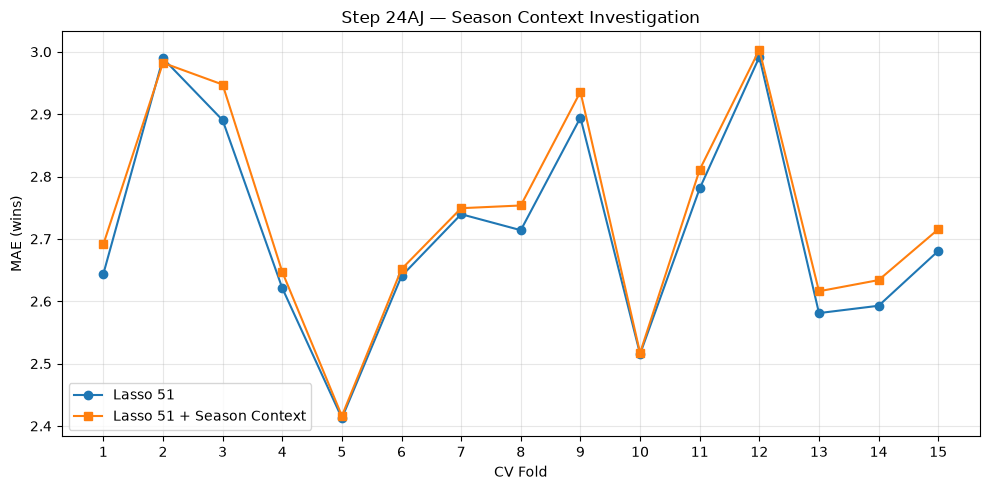


Step 24AJ completed successfully.


In [115]:

# ============================================================
# STEP 24AJ — SEASON-CONTEXT INVESTIGATION (REVISED)
# Self-contained: no X51_24af or earlier notebook variables
# Original notebook models are not modified
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, RepeatedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

possible_paths = [
    Path("data.csv"),
    Path("data (3).csv"),
    Path.home() / "MLB" / "data.csv",
    Path("/mnt/data/data (3).csv"),
]

data_path = next(
    (p for p in possible_paths if p.exists()), None
)

if data_path is None:
    raise FileNotFoundError(
        "Cannot find data.csv. Update possible_paths "
        "to point to your MLB training CSV."
    )

data_24aj = pd.read_csv(data_path)

print("Loaded:", data_path)
print("Full dataset:", data_24aj.shape)

# ------------------------------------------------------------
# 2. RECREATE ORIGINAL FEATURE ENGINEERING
# ------------------------------------------------------------

exclude_24aj = {
    "W", "ID", "yearID", "teamID",
    "year_label", "decade_label", "win_bins"
}

raw_features_24aj = [
    c for c in data_24aj.columns
    if c not in exclude_24aj
    and pd.api.types.is_numeric_dtype(data_24aj[c])
]

X_all_24aj = data_24aj[raw_features_24aj].copy()
y_all_24aj = data_24aj["W"].astype(float).copy()

assert len(raw_features_24aj) == 44, (
    f"Expected 44 raw features, got {len(raw_features_24aj)}"
)

def engineer_features_24aj(df):
    X = df.copy()

    G = X["G"].astype(float)
    R = X["R"].astype(float)
    RA = X["RA"].astype(float)
    AB = X["AB"].astype(float)
    H = X["H"].astype(float)
    BB = X["BB"].astype(float)
    B2 = X["2B"].astype(float)
    B3 = X["3B"].astype(float)
    HR = X["HR"].astype(float)
    HA = X["HA"].astype(float)
    BBA = X["BBA"].astype(float)
    SOA = X["SOA"].astype(float)
    innings = X["IPouts"].astype(float) / 3

    assert (G > 0).all()
    assert (AB > 0).all()
    assert (innings > 0).all()
    assert (R > 0).all() and (RA > 0).all()

    # Original 48 features
    X["R_per_game"] = R / G
    X["RA_per_game"] = RA / G
    X["Run_Differential"] = R - RA
    X["Pythagorean_Expected_Wins"] = (
        G * R**2 / (R**2 + RA**2)
    )

    # Additional features for 56
    X["Pythagorean_Expected_Wins_183"] = (
        G * R**1.83 / (R**1.83 + RA**1.83)
    )
    X["Run_Diff_Per_Game"] = (R - RA) / G
    X["Log_Run_Ratio"] = np.log((R + 1) / (RA + 1))
    X["Batting_Average"] = H / AB
    X["Isolated_Power"] = (B2 + 2*B3 + 3*HR) / AB
    X["WHIP_Proxy"] = (HA + BBA) / innings
    X["BB_Rate_Proxy"] = BB / (AB + BB)
    X["Pitching_K_BB_Ratio"] = SOA / (BBA + 1)

    # Additional features for 60
    exponent = ((R + RA) / G)**0.285

    X["Pythagenpat_Expected_Wins"] = (
        G * R**exponent /
        (R**exponent + RA**exponent)
    )
    X["Run_Share_Smoothed"] = (
        (R + 0.5) / (R + RA + 1)
    )

    margin = (R - RA) / G

    X["Signed_Squared_Run_Margin"] = (
        np.sign(margin) * margin**2
    )
    X["RunDiff_over_TotalRuns"] = (
        (R - RA) / (R + RA + 1)
    )

    # Historical era interactions for 68
    early = X[
        ["decade_1910", "decade_1920",
         "decade_1930", "decade_1940"]
    ].astype(float).sum(axis=1)

    middle = X[
        ["decade_1950", "decade_1960",
         "decade_1970"]
    ].astype(float).sum(axis=1)

    expected_rate = (
        X["Pythagenpat_Expected_Wins"] / G - 0.5
    )

    X["Early_x_RunMargin"] = early * margin
    X["Middle_x_RunMargin"] = middle * margin
    X["Early_x_PythagenpatRate"] = early * expected_rate
    X["Middle_x_PythagenpatRate"] = middle * expected_rate
    X["Early_x_ERA"] = early * X["ERA"]
    X["Middle_x_ERA"] = middle * X["ERA"]
    X["Early_x_WalkRate"] = early * X["BB_Rate_Proxy"]
    X["Middle_x_WalkRate"] = middle * X["BB_Rate_Proxy"]

    return X

X68_all_24aj = engineer_features_24aj(X_all_24aj)

# Same removals as your Step 24M
drop_58_24aj = [
    "era_1", "era_8", "era_7",
    "decade_1980",
    "Run_Differential", "FP",
    "Run_Diff_Per_Game",
    "Run_Share_Smoothed",
    "Pythagorean_Expected_Wins_183",
    "Log_Run_Ratio"
]

X58_all_24aj = X68_all_24aj.drop(
    columns=drop_58_24aj
)

# Same removals as your Step 24AA
drop_51_24aj = [
    "DP", "2B", "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

X51_all_24aj = X58_all_24aj.drop(
    columns=drop_51_24aj
)

assert X68_all_24aj.shape[1] == 68
assert X58_all_24aj.shape[1] == 58
assert X51_all_24aj.shape[1] == 51
assert np.isfinite(
    X51_all_24aj.to_numpy(dtype=float)
).all(), "Missing or invalid feature values found"

# ------------------------------------------------------------
# 3. SAME ORIGINAL TRAIN / TEST SPLIT
# ------------------------------------------------------------

positions_24aj = np.arange(len(data_24aj))

train_idx_24aj, holdout_idx_24aj = train_test_split(
    positions_24aj,
    test_size=0.20,
    random_state=42
)

X_24aj = X51_all_24aj.iloc[
    train_idx_24aj
].reset_index(drop=True)

y_24aj = y_all_24aj.iloc[
    train_idx_24aj
].to_numpy()

# Season signatures use no actual wins.
# decade_label is also available in predict.csv.
context_24aj = data_24aj.iloc[
    train_idx_24aj
].reset_index(drop=True)

season_keys_24aj = (
    context_24aj["mlb_rpg"].round(10).astype(str)
    + "|"
    + context_24aj["decade_label"].astype(str)
)

print("\nDATA VERIFICATION")
print("=" * 55)
print("Training:", X_24aj.shape)
print("Holdout rows reserved:", len(holdout_idx_24aj))
print("Unique season signatures:", season_keys_24aj.nunique())

# ------------------------------------------------------------
# 4. RECREATE LASSO 51 PIPELINE
# ------------------------------------------------------------

indicator_cols_24aj = [
    c for c in X_24aj.columns
    if c.startswith(("era_", "decade_"))
]

numeric_cols_24aj = [
    c for c in X_24aj.columns
    if c not in indicator_cols_24aj
]

preprocessor_24aj = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols_24aj),
    ("indicators", "passthrough", indicator_cols_24aj)
])

lasso_24aj = Pipeline([
    ("preprocessor", preprocessor_24aj),
    ("model", Lasso(
        alpha=0.0025,
        max_iter=100000,
        tol=1e-5
    ))
])

# ------------------------------------------------------------
# 5. LEARN SEASON RESIDUAL CORRECTIONS
# ------------------------------------------------------------

SHRINKAGE_24aj = 20.0
MAX_CORRECTION_24aj = 3.0

def learn_corrections_24aj(X, y, season_keys):

    inner_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=2026
    )

    oof_predictions = np.empty(len(y))

    for tr, va in inner_cv.split(X):

        model = clone(lasso_24aj)

        model.fit(X.iloc[tr], y[tr])

        oof_predictions[va] = model.predict(
            X.iloc[va]
        )

    residuals = y - oof_predictions

    residual_table = pd.DataFrame({
        "Season": np.asarray(season_keys),
        "Residual": residuals
    })

    summary = (
        residual_table
        .groupby("Season")["Residual"]
        .agg(["sum", "count"])
    )

    summary["Correction"] = (
        summary["sum"] /
        (summary["count"] + SHRINKAGE_24aj)
    ).clip(
        -MAX_CORRECTION_24aj,
        MAX_CORRECTION_24aj
    )

    return summary["Correction"].to_dict()

# ------------------------------------------------------------
# 6. REPEATED 5-FOLD CV (15 FOLDS)
# ------------------------------------------------------------

cv_24aj = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

results_24aj = []

for fold, (tr, va) in enumerate(
    cv_24aj.split(X_24aj), start=1
):

    X_tr = X_24aj.iloc[tr]
    X_va = X_24aj.iloc[va]

    y_tr = y_24aj[tr]
    y_va = y_24aj[va]

    keys_tr = season_keys_24aj.iloc[tr]
    keys_va = season_keys_24aj.iloc[va]

    # Baseline
    model = clone(lasso_24aj)
    model.fit(X_tr, y_tr)

    baseline_pred = model.predict(X_va)

    # Season correction learned from training only
    correction_map = learn_corrections_24aj(
        X_tr, y_tr, keys_tr
    )

    adjustments = (
        keys_va.map(correction_map)
        .fillna(0)
        .to_numpy()
    )

    season_pred = baseline_pred + adjustments

    base_mae = mean_absolute_error(
        y_va, baseline_pred
    )

    season_mae = mean_absolute_error(
        y_va, season_pred
    )

    results_24aj.append({
        "Fold": fold,
        "Lasso51_MAE": base_mae,
        "Season_MAE": season_mae,
        "Improvement": base_mae - season_mae,
        "Mean_Adjustment": np.mean(
            np.abs(adjustments)
        )
    })

    print(
        f"Fold {fold:02d} | "
        f"Lasso {base_mae:.4f} | "
        f"Season {season_mae:.4f} | "
        f"Difference {base_mae-season_mae:+.4f}"
    )

# ------------------------------------------------------------
# 7. RESULTS
# ------------------------------------------------------------

results_df_24aj = pd.DataFrame(results_24aj)

baseline_cv_24aj = results_df_24aj[
    "Lasso51_MAE"
].mean()

season_cv_24aj = results_df_24aj[
    "Season_MAE"
].mean()

print("\n" + "=" * 65)
print("STEP 24AJ — FINAL COMPARISON")
print("=" * 65)

print(f"Lasso 51 CV MAE       : {baseline_cv_24aj:.6f}")
print(f"Lasso + Season CV MAE : {season_cv_24aj:.6f}")
print(
    f"Improvement           : "
    f"{baseline_cv_24aj-season_cv_24aj:+.6f}"
)

print(
    "Season better folds  :",
    int((results_df_24aj["Improvement"] > 0).sum()),
    "/ 15"
)

print("Previous reference    : 2.712524")

# ------------------------------------------------------------
# 8. VISUALISATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    results_df_24aj["Fold"],
    results_df_24aj["Lasso51_MAE"],
    marker="o",
    label="Lasso 51"
)

plt.plot(
    results_df_24aj["Fold"],
    results_df_24aj["Season_MAE"],
    marker="s",
    label="Lasso 51 + Season Context"
)

plt.xlabel("CV Fold")
plt.ylabel("MAE (wins)")
plt.title("Step 24AJ — Season Context Investigation")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nStep 24AJ completed successfully.")


Lasso 58 shape: (1129, 58)
Season groups: 108
Fold 01 | Lasso 58: 2.6599 | Season: 2.7099 | Improvement: -0.0499
Fold 02 | Lasso 58: 2.9894 | Season: 2.9859 | Improvement: +0.0036
Fold 03 | Lasso 58: 2.9004 | Season: 2.9637 | Improvement: -0.0634
Fold 04 | Lasso 58: 2.6339 | Season: 2.6601 | Improvement: -0.0262
Fold 05 | Lasso 58: 2.4139 | Season: 2.4154 | Improvement: -0.0015
Fold 06 | Lasso 58: 2.6545 | Season: 2.6665 | Improvement: -0.0120
Fold 07 | Lasso 58: 2.7307 | Season: 2.7428 | Improvement: -0.0121
Fold 08 | Lasso 58: 2.7293 | Season: 2.7635 | Improvement: -0.0342
Fold 09 | Lasso 58: 2.9059 | Season: 2.9419 | Improvement: -0.0360
Fold 10 | Lasso 58: 2.5385 | Season: 2.5398 | Improvement: -0.0013
Fold 11 | Lasso 58: 2.7852 | Season: 2.8143 | Improvement: -0.0291
Fold 12 | Lasso 58: 3.0115 | Season: 3.0256 | Improvement: -0.0141
Fold 13 | Lasso 58: 2.5743 | Season: 2.6188 | Improvement: -0.0445
Fold 14 | Lasso 58: 2.6064 | Season: 2.6439 | Improvement: -0.0375
Fold 15 | Lasso 

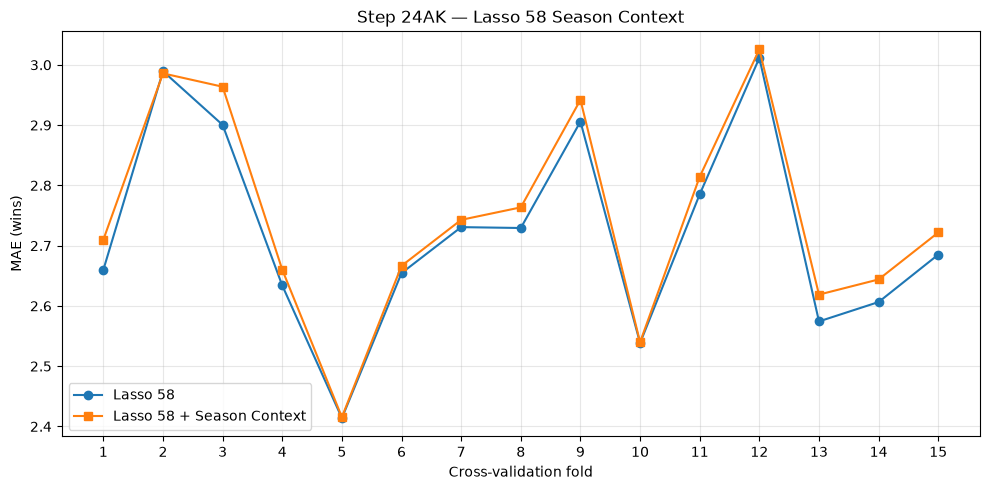


Step 24AK completed.
Original models unchanged.


In [116]:

# ============================================================
# STEP 24AK — LASSO 58 + SEASON CONTEXT
#
# Compare:
# 1. Lasso 58 baseline
# 2. Lasso 58 + season residual correction
#
# Requires Step 24AJ to have run successfully.
# No existing models are modified.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import RepeatedKFold, KFold
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. PREPARE LASSO 58 FEATURES
# ------------------------------------------------------------

X58_24ak = (
    X58_all_24aj
    .iloc[train_idx_24aj]
    .reset_index(drop=True)
    .copy()
)

y_24ak = np.asarray(y_24aj, dtype=float)
season_keys_24ak = season_keys_24aj.reset_index(drop=True)

assert X58_24ak.shape == (1129, 58)
assert len(y_24ak) == len(season_keys_24ak)

print("Lasso 58 shape:", X58_24ak.shape)
print("Season groups:", season_keys_24ak.nunique())

# ------------------------------------------------------------
# 2. RECREATE LASSO 58 MODEL
# ------------------------------------------------------------

indicator_cols_24ak = [
    c for c in X58_24ak.columns
    if c.startswith(("era_", "decade_"))
]

numeric_cols_24ak = [
    c for c in X58_24ak.columns
    if c not in indicator_cols_24ak
]

preprocessor_24ak = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols_24ak),
    ("indicators", "passthrough", indicator_cols_24ak)
])

lasso58_24ak = Pipeline([
    ("preprocessor", preprocessor_24ak),
    ("model", Lasso(
        alpha=0.005,
        max_iter=100000,
        tol=1e-5
    ))
])

# ------------------------------------------------------------
# 3. LEARN SEASON CORRECTIONS
# ------------------------------------------------------------

SHRINKAGE_24ak = 20.0
MAX_CORRECTION_24ak = 3.0

def learn_corrections_24ak(X, y, season_keys):

    inner_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=2026
    )

    oof_predictions = np.empty(len(y))

    for tr, va in inner_cv.split(X):

        model = clone(lasso58_24ak)
        model.fit(X.iloc[tr], y[tr])

        oof_predictions[va] = model.predict(
            X.iloc[va]
        )

    residuals = y - oof_predictions

    residual_table = pd.DataFrame({
        "Season": np.asarray(season_keys),
        "Residual": residuals
    })

    summary = (
        residual_table
        .groupby("Season")["Residual"]
        .agg(["sum", "count"])
    )

    summary["Correction"] = (
        summary["sum"] /
        (summary["count"] + SHRINKAGE_24ak)
    ).clip(
        -MAX_CORRECTION_24ak,
        MAX_CORRECTION_24ak
    )

    return summary["Correction"].to_dict()

# ------------------------------------------------------------
# 4. SAME REPEATED CROSS-VALIDATION
# ------------------------------------------------------------

cv_24ak = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

results_24ak = []

for fold, (tr, va) in enumerate(
    cv_24ak.split(X58_24ak), start=1
):

    X_tr = X58_24ak.iloc[tr]
    X_va = X58_24ak.iloc[va]

    y_tr = y_24ak[tr]
    y_va = y_24ak[va]

    keys_tr = season_keys_24ak.iloc[tr]
    keys_va = season_keys_24ak.iloc[va]

    # Baseline Lasso 58
    model = clone(lasso58_24ak)
    model.fit(X_tr, y_tr)

    baseline_pred = model.predict(X_va)

    # Season correction
    correction_map = learn_corrections_24ak(
        X_tr, y_tr, keys_tr
    )

    adjustments = (
        keys_va.map(correction_map)
        .fillna(0.0)
        .to_numpy()
    )

    season_pred = baseline_pred + adjustments

    base_mae = mean_absolute_error(
        y_va, baseline_pred
    )

    season_mae = mean_absolute_error(
        y_va, season_pred
    )

    results_24ak.append({
        "Fold": fold,
        "Lasso58_MAE": base_mae,
        "Lasso58_Season_MAE": season_mae,
        "Improvement": base_mae - season_mae
    })

    print(
        f"Fold {fold:02d} | "
        f"Lasso 58: {base_mae:.4f} | "
        f"Season: {season_mae:.4f} | "
        f"Improvement: {base_mae-season_mae:+.4f}"
    )

# ------------------------------------------------------------
# 5. FINAL COMPARISON
# ------------------------------------------------------------

results_df_24ak = pd.DataFrame(results_24ak)

lasso58_cv_24ak = results_df_24ak[
    "Lasso58_MAE"
].mean()

season58_cv_24ak = results_df_24ak[
    "Lasso58_Season_MAE"
].mean()

print("\n" + "=" * 65)
print("STEP 24AK — FINAL COMPARISON")
print("=" * 65)

print(f"Lasso 58 baseline CV MAE : {lasso58_cv_24ak:.6f}")
print(f"Lasso 58 + Season CV MAE : {season58_cv_24ak:.6f}")
print(
    f"Improvement              : "
    f"{lasso58_cv_24ak-season58_cv_24ak:+.6f}"
)

print(
    "Season better folds     :",
    int((results_df_24ak["Improvement"] > 0).sum()),
    "/ 15"
)

print("Previous Lasso 58 CV MAE : 2.721265")

# ------------------------------------------------------------
# 6. VISUALISATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    results_df_24ak["Fold"],
    results_df_24ak["Lasso58_MAE"],
    marker="o",
    label="Lasso 58"
)

plt.plot(
    results_df_24ak["Fold"],
    results_df_24ak["Lasso58_Season_MAE"],
    marker="s",
    label="Lasso 58 + Season Context"
)

plt.xlabel("Cross-validation fold")
plt.ylabel("MAE (wins)")
plt.title("Step 24AK — Lasso 58 Season Context")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nStep 24AK completed.")
print("Original models unchanged.")


STEP 24AL — DATA VERIFICATION
Observations: 1129
Lasso 51 features: 51
Lasso 58 features: 58
Games played range: 150.0 164.0


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/minicon

Fold 01 | Binomial 51: 2.6549 | Binomial 58: 2.6615


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Fold 02 | Binomial 51: 2.9855 | Binomial 58: 2.9892


...

Fold 13 | Binomial 51: 2.5656 | Binomial 58: 2.5678


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Fold 14 | Binomial 51: 2.5819 | Binomial 58: 2.5906


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Fold 15 | Binomial 51: 2.6591 | Binomial 58: 2.6778

STEP 24AL — FINAL COMPARISON
          Model   CV_MAE
Binomial GLM 51 2.711230
       Lasso 51 2.712524
       Lasso 58 2.721265
Binomial GLM 58 2.724898

Binomial 51 vs Lasso 51: +0.001294
Binomial 58 vs Lasso 58: -0.003633

Binomial 51 better than Binomial 58: 15 / 15 folds


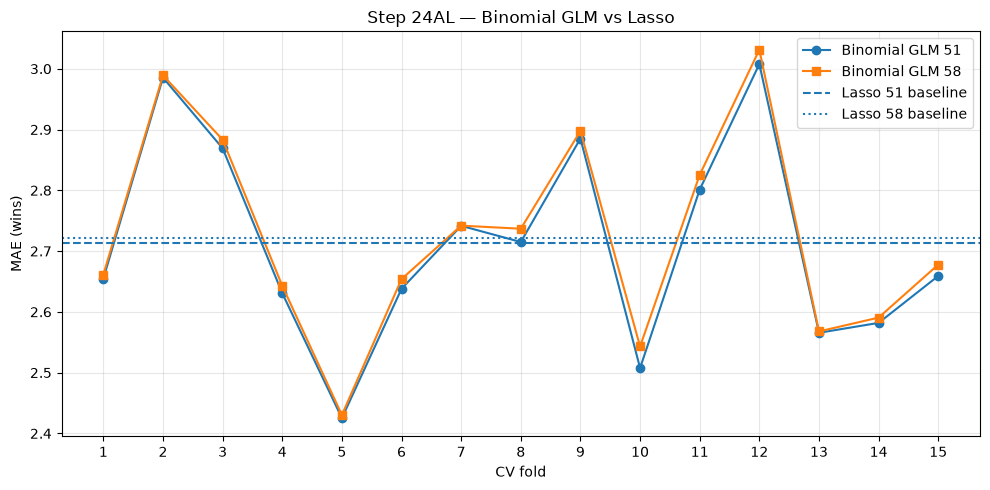


Step 24AL completed.
Existing models unchanged.
No Kaggle submission created.


In [117]:

# ============================================================
# STEP 24AL — BINOMIAL GLM FOR MLB WINS
#
# 1. Prepare wins and losses
# 2. Fit regularised binomial GLM
# 3. Evaluate using repeated 5-fold CV (15 folds)
# 4. Compare against Lasso 51 and Lasso 58
#
# No external data
# No Kaggle submission
# Existing models unchanged
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# STAGE 1 — PREPARE DATA
# ------------------------------------------------------------

required = [
    "X_24aj",
    "y_24aj",
    "data_24aj",
    "train_idx_24aj",
    "X58_all_24aj"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Run Step 24AJ first. Missing: " + ", ".join(missing)
    )

# Use same 1129 rows as previous experiments
X51_24al = X_24aj.reset_index(drop=True).copy()

X58_24al = (
    X58_all_24aj
    .iloc[train_idx_24aj]
    .reset_index(drop=True)
    .copy()
)

W_24al = np.asarray(y_24aj, dtype=float).ravel()

G_24al = (
    data_24aj
    .iloc[train_idx_24aj]["G"]
    .to_numpy(dtype=float)
)

L_24al = G_24al - W_24al

assert len(X51_24al) == len(X58_24al) == len(W_24al)
assert (G_24al > 0).all()
assert (W_24al >= 0).all()
assert (L_24al >= 0).all()
assert X51_24al.shape[1] == 51
assert X58_24al.shape[1] == 58

print("=" * 60)
print("STEP 24AL — DATA VERIFICATION")
print("=" * 60)
print("Observations:", len(W_24al))
print("Lasso 51 features:", X51_24al.shape[1])
print("Lasso 58 features:", X58_24al.shape[1])
print("Games played range:", G_24al.min(), G_24al.max())

# ------------------------------------------------------------
# STAGE 2 — BUILD BINOMIAL GLM
# ------------------------------------------------------------
# Each team-season contributes:
# - W successful game outcomes (wins)
# - G-W unsuccessful game outcomes (losses)
#
# We do NOT need to create one row per game.
# Sample weights represent aggregated wins and losses.

def build_binomial_glm_24al(X, C=0.01):

    indicator_cols = [
        c for c in X.columns
        if c.startswith(("era_", "decade_"))
    ]

    numeric_cols = [
        c for c in X.columns
        if c not in indicator_cols
    ]

    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_cols),
        ("indicators", "passthrough", indicator_cols)
    ])

    model = Pipeline([
        ("preprocessor", preprocessing),
        ("glm", LogisticRegression(
            penalty="l2",
            C=C,
            solver="lbfgs",
            max_iter=5000,
            tol=1e-6
        ))
    ])

    return model


def fit_binomial_glm_24al(X_train, wins, games, C=0.01):

    n = len(X_train)

    # Two aggregated outcome rows per team
    X_expanded = pd.concat(
        [X_train, X_train],
        ignore_index=True
    )

    # 1 = win, 0 = loss
    outcome = np.concatenate([
        np.ones(n, dtype=int),
        np.zeros(n, dtype=int)
    ])

    # Each row represents its number of games
    weights = np.concatenate([
        wins,
        games - wins
    ])

    model = build_binomial_glm_24al(X_train, C=C)

    model.fit(
        X_expanded,
        outcome,
        glm__sample_weight=weights
    )

    return model


def predict_wins_24al(model, X, games):

    win_probability = model.predict_proba(X)[:, 1]

    predicted_wins = games * win_probability

    return predicted_wins

# ------------------------------------------------------------
# STAGE 3 — SAME 15-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

cv_24al = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

results_24al = []

# Fixed regularisation setting for this first experiment
C_24al = 0.01

for fold, (tr, va) in enumerate(
    cv_24al.split(X51_24al), start=1
):

    W_train = W_24al[tr]
    W_val = W_24al[va]

    G_train = G_24al[tr]
    G_val = G_24al[va]

    # ----- BINOMIAL GLM 51 FEATURES -----

    model51 = fit_binomial_glm_24al(
        X51_24al.iloc[tr],
        W_train,
        G_train,
        C=C_24al
    )

    pred51 = predict_wins_24al(
        model51,
        X51_24al.iloc[va],
        G_val
    )

    mae51 = mean_absolute_error(W_val, pred51)

    # ----- BINOMIAL GLM 58 FEATURES -----

    model58 = fit_binomial_glm_24al(
        X58_24al.iloc[tr],
        W_train,
        G_train,
        C=C_24al
    )

    pred58 = predict_wins_24al(
        model58,
        X58_24al.iloc[va],
        G_val
    )

    mae58 = mean_absolute_error(W_val, pred58)

    results_24al.append({
        "Fold": fold,
        "Binomial51_MAE": mae51,
        "Binomial58_MAE": mae58
    })

    print(
        f"Fold {fold:02d} | "
        f"Binomial 51: {mae51:.4f} | "
        f"Binomial 58: {mae58:.4f}"
    )

# ------------------------------------------------------------
# STAGE 4 — FINAL COMPARISON
# ------------------------------------------------------------

results_df_24al = pd.DataFrame(results_24al)

binomial51_cv = results_df_24al["Binomial51_MAE"].mean()
binomial58_cv = results_df_24al["Binomial58_MAE"].mean()

comparison_24al = pd.DataFrame({
    "Model": [
        "Lasso 51",
        "Lasso 58",
        "Binomial GLM 51",
        "Binomial GLM 58"
    ],
    "CV_MAE": [
        2.712524,
        2.721265,
        binomial51_cv,
        binomial58_cv
    ]
}).sort_values("CV_MAE")

print("\n" + "=" * 65)
print("STEP 24AL — FINAL COMPARISON")
print("=" * 65)
print(comparison_24al.to_string(index=False))

print("\nBinomial 51 vs Lasso 51:",
      f"{2.712524 - binomial51_cv:+.6f}")

print("Binomial 58 vs Lasso 58:",
      f"{2.721265 - binomial58_cv:+.6f}")

print("\nBinomial 51 better than Binomial 58:",
      int((results_df_24al["Binomial51_MAE"] <
           results_df_24al["Binomial58_MAE"]).sum()),
      "/ 15 folds")

# ------------------------------------------------------------
# VISUALISATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    results_df_24al["Fold"],
    results_df_24al["Binomial51_MAE"],
    marker="o",
    label="Binomial GLM 51"
)

plt.plot(
    results_df_24al["Fold"],
    results_df_24al["Binomial58_MAE"],
    marker="s",
    label="Binomial GLM 58"
)

plt.axhline(
    2.712524,
    linestyle="--",
    label="Lasso 51 baseline"
)

plt.axhline(
    2.721265,
    linestyle=":",
    label="Lasso 58 baseline"
)

plt.xlabel("CV fold")
plt.ylabel("MAE (wins)")
plt.title("Step 24AL — Binomial GLM vs Lasso")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nStep 24AL completed.")
print("Existing models unchanged.")
print("No Kaggle submission created.")


STEP 24AM — BINOMIAL GLM REGULARISATION
Training observations: 1129
Features: 51
C values: [0.001, 0.01, 0.1, 1.0]


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/minicon

Fold 01 | C=0.01  | Lasso=2.6438 | Fixed=2.6549 | Tuned=2.6549


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/minicon

Fold 02 | C=0.1   | Lasso=2.9894 | Fixed=2.9855 | Tuned=2.9982


...

Fold 13 | C=0.01  | Lasso=2.5810 | Fixed=2.5656 | Tuned=2.5656


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/minicon

Fold 14 | C=0.01  | Lasso=2.5928 | Fixed=2.5819 | Tuned=2.5819


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/minicon

Fold 15 | C=1.0   | Lasso=2.6807 | Fixed=2.6591 | Tuned=2.7131

STEP 24AM — FINAL COMPARISON
                         Model   CV_MAE
Binomial GLM 51 — Fixed C=0.01 2.711230
                      Lasso 51 2.712524
   Binomial GLM 51 — Nested CV 2.715781

Improvement over fixed Binomial: -0.004551
Improvement over Lasso 51: -0.003257

Tuned model beats fixed model: 0 / 15 folds
Tuned model beats Lasso 51: 6 / 15 folds

C SELECTION FREQUENCY
Selected_C
0.01    12
0.10     2
1.00     1

AVERAGE INNER CV MAE BY C
C_0.001    2.819164
C_0.01     2.742181
C_0.1      2.750685
C_1.0      2.762832


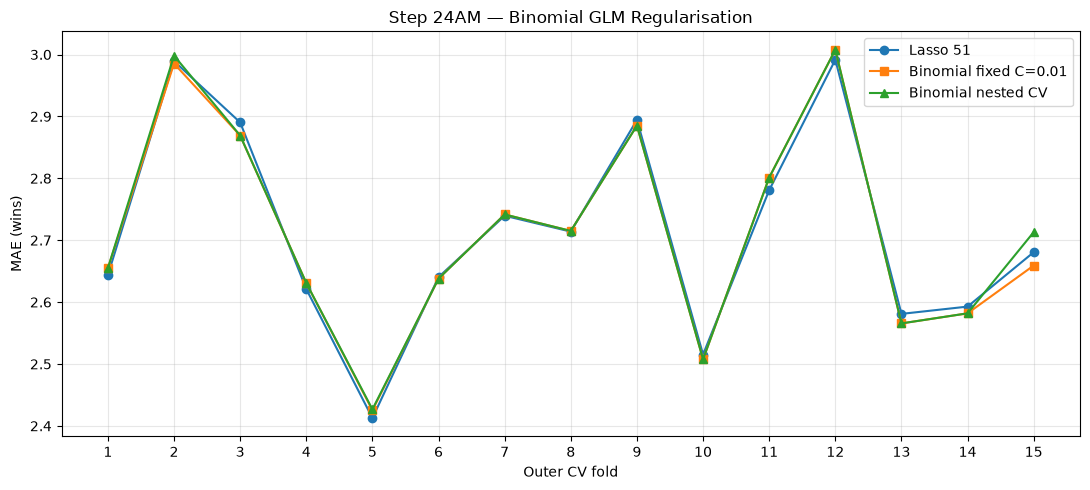


STEP 24AM COMPLETED
Original models unchanged.
283-row holdout untouched.
No Kaggle submission generated.


In [118]:

# ============================================================
# STEP 24AM — BINOMIAL GLM REGULARISATION
# Nested cross-validation: 5 outer folds x 3 repeats
# Inner 3-fold CV selects the best C
#
# Compares:
# 1. Binomial GLM 51, fixed C=0.01
# 2. Binomial GLM 51, C selected by inner CV
# 3. Lasso 51 benchmark
#
# No external data / No Kaggle submission
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold, KFold
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# STAGE 1 — VERIFY EXISTING DATA AND FUNCTIONS
# ------------------------------------------------------------

required_24am = [
    "X51_24al",
    "W_24al",
    "G_24al",
    "fit_binomial_glm_24al",
    "predict_wins_24al",
    "lasso_24aj"
]

missing_24am = [
    name for name in required_24am
    if name not in globals()
]

if missing_24am:
    raise RuntimeError(
        "Run Steps 24AJ and 24AL first. Missing: "
        + ", ".join(missing_24am)
    )

X_24am = X51_24al.reset_index(drop=True).copy()
W_24am = np.asarray(W_24al, dtype=float).ravel()
G_24am = np.asarray(G_24al, dtype=float).ravel()

assert X_24am.shape == (1129, 51)
assert len(W_24am) == len(G_24am)
assert np.all(G_24am >= W_24am)
assert np.all(W_24am >= 0)

C_VALUES_24am = [0.001, 0.01, 0.1, 1.0]

print("=" * 65)
print("STEP 24AM — BINOMIAL GLM REGULARISATION")
print("=" * 65)
print("Training observations:", len(W_24am))
print("Features:", X_24am.shape[1])
print("C values:", C_VALUES_24am)

# ------------------------------------------------------------
# STAGE 2 — DEFINE INNER CV SELECTION
# ------------------------------------------------------------

def select_best_C_24am(X_train, W_train, G_train):

    inner_cv = KFold(
        n_splits=3,
        shuffle=True,
        random_state=2026
    )

    scores = {}

    for C in C_VALUES_24am:

        fold_maes = []

        for inner_tr, inner_va in inner_cv.split(X_train):

            X_tr = X_train.iloc[inner_tr]
            X_va = X_train.iloc[inner_va]

            model = fit_binomial_glm_24al(
                X_tr,
                W_train[inner_tr],
                G_train[inner_tr],
                C=C
            )

            predictions = predict_wins_24al(
                model,
                X_va,
                G_train[inner_va]
            )

            mae = mean_absolute_error(
                W_train[inner_va],
                predictions
            )

            fold_maes.append(mae)

        scores[C] = np.mean(fold_maes)

    # Choose C using inner folds ONLY.
    best_C = min(scores, key=scores.get)

    return best_C, scores


# ------------------------------------------------------------
# STAGE 3 — OUTER REPEATED CROSS-VALIDATION
# ------------------------------------------------------------

outer_cv_24am = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

results_24am = []
inner_scores_24am = []

for fold, (tr, va) in enumerate(
    outer_cv_24am.split(X_24am),
    start=1
):

    X_train = X_24am.iloc[tr]
    X_val = X_24am.iloc[va]

    W_train = W_24am[tr]
    W_val = W_24am[va]

    G_train = G_24am[tr]
    G_val = G_24am[va]

    # A. Choose C using inner CV
    best_C, inner_scores = select_best_C_24am(
        X_train,
        W_train,
        G_train
    )

    inner_scores_24am.append({
        "Fold": fold,
        "Selected_C": best_C,
        **{
            f"C_{c}": score
            for c, score in inner_scores.items()
        }
    })

    # B. Train selected binomial model
    selected_model = fit_binomial_glm_24al(
        X_train,
        W_train,
        G_train,
        C=best_C
    )

    selected_predictions = predict_wins_24al(
        selected_model,
        X_val,
        G_val
    )

    selected_mae = mean_absolute_error(
        W_val,
        selected_predictions
    )

    # C. Train original fixed-C binomial model
    fixed_model = fit_binomial_glm_24al(
        X_train,
        W_train,
        G_train,
        C=0.01
    )

    fixed_predictions = predict_wins_24al(
        fixed_model,
        X_val,
        G_val
    )

    fixed_mae = mean_absolute_error(
        W_val,
        fixed_predictions
    )

    # D. Train Lasso 51 on the SAME outer fold
    lasso_model = clone(lasso_24aj)
    lasso_model.fit(X_train, W_train)

    lasso_predictions = lasso_model.predict(X_val)

    lasso_mae = mean_absolute_error(
        W_val,
        lasso_predictions
    )

    results_24am.append({
        "Fold": fold,
        "Selected_C": best_C,
        "Lasso51_MAE": lasso_mae,
        "Fixed_Binomial_MAE": fixed_mae,
        "Tuned_Binomial_MAE": selected_mae,
        "Improvement_vs_Fixed": fixed_mae - selected_mae,
        "Improvement_vs_Lasso": lasso_mae - selected_mae
    })

    print(
        f"Fold {fold:02d} | "
        f"C={best_C:<5} | "
        f"Lasso={lasso_mae:.4f} | "
        f"Fixed={fixed_mae:.4f} | "
        f"Tuned={selected_mae:.4f}"
    )

# ------------------------------------------------------------
# STAGE 4 — RESULTS AND DECISION
# ------------------------------------------------------------

results_df_24am = pd.DataFrame(results_24am)
inner_scores_df_24am = pd.DataFrame(inner_scores_24am)

lasso_cv_24am = results_df_24am[
    "Lasso51_MAE"
].mean()

fixed_cv_24am = results_df_24am[
    "Fixed_Binomial_MAE"
].mean()

tuned_cv_24am = results_df_24am[
    "Tuned_Binomial_MAE"
].mean()

comparison_24am = pd.DataFrame({
    "Model": [
        "Lasso 51",
        "Binomial GLM 51 — Fixed C=0.01",
        "Binomial GLM 51 — Nested CV"
    ],
    "CV_MAE": [
        lasso_cv_24am,
        fixed_cv_24am,
        tuned_cv_24am
    ]
}).sort_values("CV_MAE")

print("\n" + "=" * 65)
print("STEP 24AM — FINAL COMPARISON")
print("=" * 65)

print(
    comparison_24am.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nImprovement over fixed Binomial:",
      f"{fixed_cv_24am-tuned_cv_24am:+.6f}")

print("Improvement over Lasso 51:",
      f"{lasso_cv_24am-tuned_cv_24am:+.6f}")

print("\nTuned model beats fixed model:",
      int((results_df_24am[
          "Improvement_vs_Fixed"] > 0).sum()),
      "/ 15 folds")

print("Tuned model beats Lasso 51:",
      int((results_df_24am[
          "Improvement_vs_Lasso"] > 0).sum()),
      "/ 15 folds")

print("\nC SELECTION FREQUENCY")
print(
    results_df_24am["Selected_C"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nAVERAGE INNER CV MAE BY C")
print(
    inner_scores_df_24am[
        [f"C_{c}" for c in C_VALUES_24am]
    ].mean().round(6).to_string()
)

# ------------------------------------------------------------
# VISUALISATION
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    results_df_24am["Fold"],
    results_df_24am["Lasso51_MAE"],
    marker="o",
    label="Lasso 51"
)

plt.plot(
    results_df_24am["Fold"],
    results_df_24am["Fixed_Binomial_MAE"],
    marker="s",
    label="Binomial fixed C=0.01"
)

plt.plot(
    results_df_24am["Fold"],
    results_df_24am["Tuned_Binomial_MAE"],
    marker="^",
    label="Binomial nested CV"
)

plt.xlabel("Outer CV fold")
plt.ylabel("MAE (wins)")
plt.title("Step 24AM — Binomial GLM Regularisation")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSTEP 24AM COMPLETED")
print("Original models unchanged.")
print("283-row holdout untouched.")
print("No Kaggle submission generated.")


STEP 24AN — BINOMIAL GLM 58
Observations: 1129
Features: 58
C values: [0.001, 0.01, 0.1, 1.0]


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/minicon

Fold 01 | C=0.01  | Lasso=2.6599 | Fixed=2.6615 | Tuned=2.6615


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/minicon

Fold 02 | C=0.01  | Lasso=2.9894 | Fixed=2.9892 | Tuned=2.9892


...

Fold 13 | C=0.01  | Lasso=2.5743 | Fixed=2.5678 | Tuned=2.5678


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/minicon

Fold 14 | C=0.01  | Lasso=2.6064 | Fixed=2.5906 | Tuned=2.5906


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/minicon

Fold 15 | C=1.0   | Lasso=2.6851 | Fixed=2.6778 | Tuned=2.7285

STEP 24AN — FINAL COMPARISON
                         Model   CV_MAE
                      Lasso 58 2.721265
Binomial GLM 58 — Fixed C=0.01 2.724898
   Binomial GLM 58 — Nested CV 2.728275

Improvement over fixed Binomial 58: -0.003377
Improvement over Lasso 58: -0.007010

Tuned model beats fixed Binomial 58: 0 / 15 folds
Tuned model beats Lasso 58: 6 / 15 folds

C SELECTION FREQUENCY
Selected_C
0.01    14
1.00     1

AVERAGE INNER CV MAE BY C
C_0.001    2.827767
C_0.01     2.754776
C_0.1      2.765903
C_1.0      2.779115


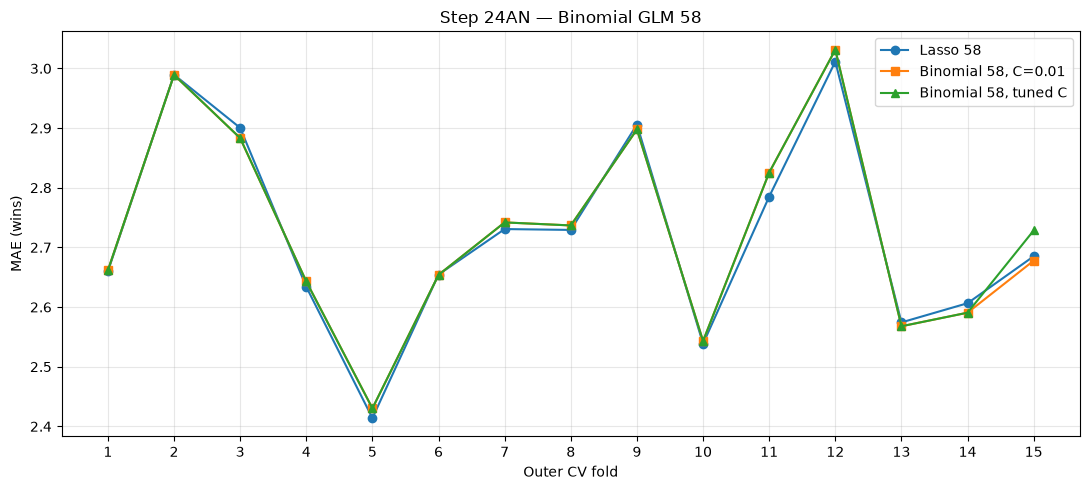


STEP 24AN COMPLETED
Existing models unchanged.
283-row holdout untouched.
No Kaggle submission generated.


In [119]:

# ============================================================
# STEP 24AN — BINOMIAL GLM 58 REGULARISATION
#
# Compare:
# 1. Lasso 58
# 2. Binomial GLM 58 — fixed C=0.01
# 3. Binomial GLM 58 — nested CV tuning
#
# 5 outer folds x 3 repeats
# 3 inner folds
# No Kaggle submission
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold, KFold
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. VERIFY REQUIRED OBJECTS
# ------------------------------------------------------------

required_24an = [
    "X58_24al",
    "W_24al",
    "G_24al",
    "fit_binomial_glm_24al",
    "predict_wins_24al",
    "lasso58_24ak"
]

missing_24an = [
    name for name in required_24an
    if name not in globals()
]

if missing_24an:
    raise RuntimeError(
        "Run Steps 24AK and 24AL first. Missing: "
        + ", ".join(missing_24an)
    )

X_24an = X58_24al.reset_index(drop=True).copy()
W_24an = np.asarray(W_24al, dtype=float).ravel()
G_24an = np.asarray(G_24al, dtype=float).ravel()

assert X_24an.shape == (1129, 58)
assert len(W_24an) == len(G_24an)
assert np.all(W_24an >= 0)
assert np.all(W_24an <= G_24an)

C_VALUES_24an = [0.001, 0.01, 0.1, 1.0]

print("=" * 65)
print("STEP 24AN — BINOMIAL GLM 58")
print("=" * 65)
print("Observations:", len(W_24an))
print("Features:", X_24an.shape[1])
print("C values:", C_VALUES_24an)

# ------------------------------------------------------------
# 2. INNER CROSS-VALIDATION
# ------------------------------------------------------------

def select_best_C_24an(X_train, W_train, G_train):

    inner_cv = KFold(
        n_splits=3,
        shuffle=True,
        random_state=2026
    )

    scores = {}

    for C in C_VALUES_24an:

        fold_maes = []

        for inner_tr, inner_va in inner_cv.split(X_train):

            model = fit_binomial_glm_24al(
                X_train.iloc[inner_tr],
                W_train[inner_tr],
                G_train[inner_tr],
                C=C
            )

            predictions = predict_wins_24al(
                model,
                X_train.iloc[inner_va],
                G_train[inner_va]
            )

            fold_maes.append(
                mean_absolute_error(
                    W_train[inner_va],
                    predictions
                )
            )

        scores[C] = np.mean(fold_maes)

    best_C = min(scores, key=scores.get)

    return best_C, scores

# ------------------------------------------------------------
# 3. OUTER REPEATED CROSS-VALIDATION
# ------------------------------------------------------------

outer_cv_24an = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

results_24an = []
inner_scores_24an = []

for fold, (tr, va) in enumerate(
    outer_cv_24an.split(X_24an), start=1
):

    X_train = X_24an.iloc[tr]
    X_val = X_24an.iloc[va]

    W_train = W_24an[tr]
    W_val = W_24an[va]

    G_train = G_24an[tr]
    G_val = G_24an[va]

    # A. Select C using inner CV
    best_C, scores = select_best_C_24an(
        X_train,
        W_train,
        G_train
    )

    inner_scores_24an.append({
        "Fold": fold,
        "Selected_C": best_C,
        **{
            f"C_{c}": score
            for c, score in scores.items()
        }
    })

    # B. Tuned Binomial GLM 58
    tuned_model = fit_binomial_glm_24al(
        X_train,
        W_train,
        G_train,
        C=best_C
    )

    tuned_pred = predict_wins_24al(
        tuned_model,
        X_val,
        G_val
    )

    tuned_mae = mean_absolute_error(
        W_val,
        tuned_pred
    )

    # C. Fixed Binomial GLM 58
    fixed_model = fit_binomial_glm_24al(
        X_train,
        W_train,
        G_train,
        C=0.01
    )

    fixed_pred = predict_wins_24al(
        fixed_model,
        X_val,
        G_val
    )

    fixed_mae = mean_absolute_error(
        W_val,
        fixed_pred
    )

    # D. Original Lasso 58
    lasso_model = clone(lasso58_24ak)
    lasso_model.fit(X_train, W_train)

    lasso_pred = lasso_model.predict(X_val)

    lasso_mae = mean_absolute_error(
        W_val,
        lasso_pred
    )

    results_24an.append({
        "Fold": fold,
        "Selected_C": best_C,
        "Lasso58_MAE": lasso_mae,
        "Fixed_Binomial58_MAE": fixed_mae,
        "Tuned_Binomial58_MAE": tuned_mae,
        "Improvement_vs_Fixed": fixed_mae - tuned_mae,
        "Improvement_vs_Lasso": lasso_mae - tuned_mae
    })

    print(
        f"Fold {fold:02d} | "
        f"C={best_C:<5} | "
        f"Lasso={lasso_mae:.4f} | "
        f"Fixed={fixed_mae:.4f} | "
        f"Tuned={tuned_mae:.4f}"
    )

# ------------------------------------------------------------
# 4. FINAL RESULTS
# ------------------------------------------------------------

results_df_24an = pd.DataFrame(results_24an)
inner_scores_df_24an = pd.DataFrame(inner_scores_24an)

lasso58_cv_24an = results_df_24an[
    "Lasso58_MAE"
].mean()

fixed58_cv_24an = results_df_24an[
    "Fixed_Binomial58_MAE"
].mean()

tuned58_cv_24an = results_df_24an[
    "Tuned_Binomial58_MAE"
].mean()

comparison_24an = pd.DataFrame({
    "Model": [
        "Lasso 58",
        "Binomial GLM 58 — Fixed C=0.01",
        "Binomial GLM 58 — Nested CV"
    ],
    "CV_MAE": [
        lasso58_cv_24an,
        fixed58_cv_24an,
        tuned58_cv_24an
    ]
}).sort_values("CV_MAE")

print("\n" + "=" * 65)
print("STEP 24AN — FINAL COMPARISON")
print("=" * 65)

print(
    comparison_24an.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nImprovement over fixed Binomial 58:",
      f"{fixed58_cv_24an-tuned58_cv_24an:+.6f}")

print("Improvement over Lasso 58:",
      f"{lasso58_cv_24an-tuned58_cv_24an:+.6f}")

print("\nTuned model beats fixed Binomial 58:",
      int((results_df_24an[
          "Improvement_vs_Fixed"] > 0).sum()),
      "/ 15 folds")

print("Tuned model beats Lasso 58:",
      int((results_df_24an[
          "Improvement_vs_Lasso"] > 0).sum()),
      "/ 15 folds")

print("\nC SELECTION FREQUENCY")
print(
    results_df_24an["Selected_C"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nAVERAGE INNER CV MAE BY C")
print(
    inner_scores_df_24an[
        [f"C_{c}" for c in C_VALUES_24an]
    ].mean().round(6).to_string()
)

# ------------------------------------------------------------
# 5. VISUALISATION
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    results_df_24an["Fold"],
    results_df_24an["Lasso58_MAE"],
    marker="o",
    label="Lasso 58"
)

plt.plot(
    results_df_24an["Fold"],
    results_df_24an["Fixed_Binomial58_MAE"],
    marker="s",
    label="Binomial 58, C=0.01"
)

plt.plot(
    results_df_24an["Fold"],
    results_df_24an["Tuned_Binomial58_MAE"],
    marker="^",
    label="Binomial 58, tuned C"
)

plt.xlabel("Outer CV fold")
plt.ylabel("MAE (wins)")
plt.title("Step 24AN — Binomial GLM 58")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSTEP 24AN COMPLETED")
print("Existing models unchanged.")
print("283-row holdout untouched.")
print("No Kaggle submission generated.")


STEP 24AO — DATA SPLIT
Training observations: 903
Testing observations : 226
Regularisation C     : 0.01


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(



STEP 24AO — FINAL MODEL PERFORMANCE
          Model  Train_R2  Train_MAE  Train_RMSE  Test_R2  Test_MAE  Test_RMSE   CV_MAE
Binomial GLM 51  0.941916   2.583801    3.236912 0.932086  2.756025   3.517134 2.711230
Binomial GLM 58  0.941989   2.580424    3.234863 0.931757  2.767671   3.525651 2.724898

GENERALISATION GAP
          Model  MAE_Gap   R2_Gap
Binomial GLM 51 0.172224 0.009830
Binomial GLM 58 0.187247 0.010232


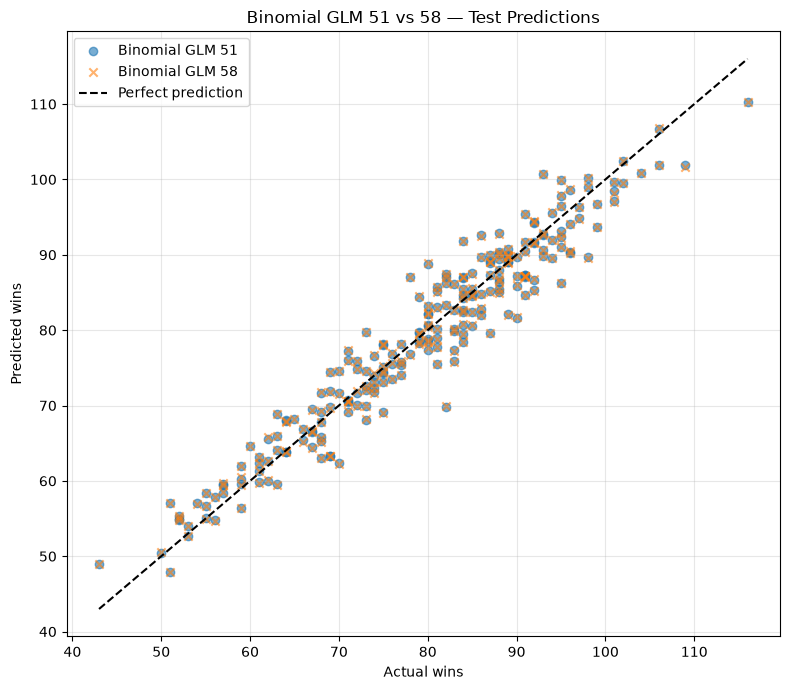


STEP 24AO COMPLETED
Original models unchanged.
No Kaggle submission created.


In [120]:

# ============================================================
# STEP 24AO — BINOMIAL GLM 51 VS 58
# Training R2, MAE, RMSE
# Testing R2, MAE, RMSE
# 15-fold CV MAE
#
# Same 80/20 split as Lasso: random_state=42
# Fixed regularisation: C=0.01
# No external data / No Kaggle submission
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# 1. CHECK EXISTING OBJECTS
# ------------------------------------------------------------

required_24ao = [
    "X51_24al",
    "X58_24al",
    "W_24al",
    "G_24al",
    "fit_binomial_glm_24al",
    "predict_wins_24al"
]

missing = [
    name for name in required_24ao
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Step 24AL first. Missing: "
        + ", ".join(missing)
    )

X51 = X51_24al.reset_index(drop=True).copy()
X58 = X58_24al.reset_index(drop=True).copy()

W = np.asarray(W_24al, dtype=float).ravel()
G = np.asarray(G_24al, dtype=float).ravel()

assert len(X51) == len(X58) == len(W) == len(G)
assert X51.shape[1] == 51
assert X58.shape[1] == 58

# ------------------------------------------------------------
# 2. TRAIN / TEST SPLIT
# ------------------------------------------------------------

train_idx, test_idx = train_test_split(
    np.arange(len(W)),
    test_size=0.20,
    random_state=42
)

print("=" * 65)
print("STEP 24AO — DATA SPLIT")
print("=" * 65)
print("Training observations:", len(train_idx))
print("Testing observations :", len(test_idx))
print("Regularisation C     : 0.01")

# ------------------------------------------------------------
# 3. FUNCTION TO CALCULATE METRICS
# ------------------------------------------------------------

def calculate_metrics_24ao(actual, predicted):

    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }


def evaluate_binomial_24ao(X, model_name, cv_mae):

    # Train the binomial model
    model = fit_binomial_glm_24al(
        X.iloc[train_idx],
        W[train_idx],
        G[train_idx],
        C=0.01
    )

    # Training predictions
    train_pred = predict_wins_24al(
        model,
        X.iloc[train_idx],
        G[train_idx]
    )

    # Testing predictions
    test_pred = predict_wins_24al(
        model,
        X.iloc[test_idx],
        G[test_idx]
    )

    # Calculate metrics
    train_metrics = calculate_metrics_24ao(
        W[train_idx],
        train_pred
    )

    test_metrics = calculate_metrics_24ao(
        W[test_idx],
        test_pred
    )

    return {
        "Model": model_name,

        "Train_R2": train_metrics["R2"],
        "Train_MAE": train_metrics["MAE"],
        "Train_RMSE": train_metrics["RMSE"],

        "Test_R2": test_metrics["R2"],
        "Test_MAE": test_metrics["MAE"],
        "Test_RMSE": test_metrics["RMSE"],

        "CV_MAE": cv_mae
    }, model, train_pred, test_pred


# ------------------------------------------------------------
# 4. EVALUATE BOTH MODELS
# ------------------------------------------------------------

result51, model51, train_pred51, test_pred51 = (
    evaluate_binomial_24ao(
        X51,
        "Binomial GLM 51",
        2.711230
    )
)

result58, model58, train_pred58, test_pred58 = (
    evaluate_binomial_24ao(
        X58,
        "Binomial GLM 58",
        2.724898
    )
)

# ------------------------------------------------------------
# 5. DISPLAY FINAL COMPARISON
# ------------------------------------------------------------

comparison_24ao = pd.DataFrame([
    result51,
    result58
])

print("\n" + "=" * 85)
print("STEP 24AO — FINAL MODEL PERFORMANCE")
print("=" * 85)

print(
    comparison_24ao.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 6. GENERALISATION GAP
# ------------------------------------------------------------

comparison_24ao["MAE_Gap"] = (
    comparison_24ao["Test_MAE"]
    - comparison_24ao["Train_MAE"]
)

comparison_24ao["R2_Gap"] = (
    comparison_24ao["Train_R2"]
    - comparison_24ao["Test_R2"]
)

print("\n" + "=" * 65)
print("GENERALISATION GAP")
print("=" * 65)

print(
    comparison_24ao[
        ["Model", "MAE_Gap", "R2_Gap"]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 7. ACTUAL VS PREDICTED — TESTING DATA
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

plt.scatter(
    W[test_idx],
    test_pred51,
    alpha=0.6,
    label="Binomial GLM 51"
)

plt.scatter(
    W[test_idx],
    test_pred58,
    alpha=0.6,
    marker="x",
    label="Binomial GLM 58"
)

minimum = min(
    W[test_idx].min(),
    test_pred51.min(),
    test_pred58.min()
)

maximum = max(
    W[test_idx].max(),
    test_pred51.max(),
    test_pred58.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Actual wins")
plt.ylabel("Predicted wins")
plt.title("Binomial GLM 51 vs 58 — Test Predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSTEP 24AO COMPLETED")
print("Original models unchanged.")
print("No Kaggle submission created.")


In [121]:

# ============================================================
# STEP 24AP — BINOMIAL GLM 51 KAGGLE SUBMISSION (REVISED)
#
# Model: Binomial GLM 51
# Regularisation: C = 0.01
# Output: submission_binomial51.csv
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

train_full = pd.read_csv("data.csv")
kaggle_test = pd.read_csv("predict.csv")

print("Training data:", train_full.shape)
print("Kaggle data:", kaggle_test.shape)

# ------------------------------------------------------------
# 2. BUILD FEATURES
# ------------------------------------------------------------

def build_features_24ap(df, base_columns):

    X = df[base_columns].copy()

    G = df["G"].astype(float)
    R = df["R"].astype(float)
    RA = df["RA"].astype(float)

    eps = 1e-9

    # Basic baseball features
    X["R_per_game"] = R / (G + eps)
    X["RA_per_game"] = RA / (G + eps)

    X["Run_Differential"] = R - RA

    X["Pythagorean_Expected_Wins"] = (
        G * R**2 / (R**2 + RA**2 + eps)
    )

    X["Pythagorean_Expected_Wins_183"] = (
        G * R**1.83 /
        (R**1.83 + RA**1.83 + eps)
    )

    X["Run_Diff_Per_Game"] = (R - RA) / (G + eps)

    X["Log_Run_Ratio"] = np.log(
        (R + 1) / (RA + 1)
    )

    X["Batting_Average"] = (
        df["H"] / (df["AB"] + eps)
    )

    X["Isolated_Power"] = (
        df["2B"] + 2*df["3B"] + 3*df["HR"]
    ) / (df["AB"] + eps)

    X["WHIP_Proxy"] = (
        (df["HA"] + df["BBA"]) /
        (df["IPouts"] / 3 + eps)
    )

    X["BB_Rate_Proxy"] = (
        df["BB"] /
        (df["AB"] + df["BB"] + eps)
    )

    X["Pitching_K_BB_Ratio"] = (
        df["SOA"] / (df["BBA"] + 1)
    )

    # Pythagenpat
    exponent = (
        (R + RA) / (G + eps)
    )**0.285

    X["Pythagenpat_Expected_Wins"] = (
        G * R**exponent /
        (R**exponent + RA**exponent + eps)
    )

    X["Run_Share_Smoothed"] = (
        (R + 0.5) / (R + RA + 1)
    )

    margin = (R - RA) / (G + eps)

    X["Signed_Squared_Run_Margin"] = (
        np.sign(margin) * margin**2
    )

    X["RunDiff_over_TotalRuns"] = (
        (R - RA) / (R + RA + 1)
    )

    # Historical era indicators
    early = sum(
        df[f"decade_{year}"]
        for year in [1910, 1920, 1930, 1940]
    )

    middle = sum(
        df[f"decade_{year}"]
        for year in [1950, 1960, 1970]
    )

    pyth_rate = (
        X["Pythagenpat_Expected_Wins"] /
        (G + eps)
    )

    walk_rate = X["BB_Rate_Proxy"]

    # Historical interactions
    X["Early_x_RunMargin"] = early * margin
    X["Middle_x_RunMargin"] = middle * margin

    # REVISED: centred Pythagenpat rate
    X["Early_x_PythagenpatRate"] = (
        early * (pyth_rate - 0.5)
    )

    X["Middle_x_PythagenpatRate"] = (
        middle * (pyth_rate - 0.5)
    )

    X["Early_x_ERA"] = early * df["ERA"]
    X["Middle_x_ERA"] = middle * df["ERA"]

    X["Early_x_WalkRate"] = early * walk_rate
    X["Middle_x_WalkRate"] = middle * walk_rate

    return X

# ------------------------------------------------------------
# 3. SELECT ORIGINAL FEATURES
# ------------------------------------------------------------

exclude = {
    "W", "ID", "yearID", "teamID",
    "year_label", "decade_label", "win_bins"
}

base_columns = [
    c for c in train_full.select_dtypes(
        include=["number", "bool"]
    ).columns
    if c not in exclude
]

X_full = build_features_24ap(
    train_full, base_columns
)

X_kaggle = build_features_24ap(
    kaggle_test, base_columns
)

# ------------------------------------------------------------
# 4. REMOVE SAME FEATURES AS STEP 24AJ
# ------------------------------------------------------------

drop_58 = [
    "era_1",
    "era_8",
    "era_7",
    "decade_1980",
    "Run_Differential",
    "FP",
    "Run_Diff_Per_Game",
    "Run_Share_Smoothed",
    "Pythagorean_Expected_Wins_183",
    "Log_Run_Ratio"
]

drop_51 = [
    "DP",
    "2B",
    "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

X_full = X_full.drop(
    columns=drop_58 + drop_51
)

X_kaggle = X_kaggle.drop(
    columns=drop_58 + drop_51
)

# ------------------------------------------------------------
# 5. MATCH EXACT ORIGINAL 51 FEATURES
# ------------------------------------------------------------

expected_columns = X51_24al.columns.tolist()

assert X_full.shape[1] == 51
assert X_kaggle.shape[1] == 51

assert set(X_full.columns) == set(expected_columns)
assert set(X_kaggle.columns) == set(expected_columns)

X_full = X_full[expected_columns].copy()
X_kaggle = X_kaggle[expected_columns].copy()

# ------------------------------------------------------------
# 6. VERIFY FEATURE ENGINEERING
# ------------------------------------------------------------

X_reference = X51_24al.reset_index(drop=True)

X_reconstructed = (
    X_full.iloc[train_idx_24aj]
    .reset_index(drop=True)
)

difference = (
    X_reconstructed.astype(float)
    - X_reference.astype(float)
)

mismatch_counts = (
    (difference.abs() > 1e-7)
    .sum()
)

print("\nFEATURE VERIFICATION")
print("Mismatched features:")
print(mismatch_counts[mismatch_counts > 0])

np.testing.assert_allclose(
    X_reconstructed.to_numpy(dtype=float),
    X_reference.to_numpy(dtype=float),
    rtol=1e-7,
    atol=1e-7,
    err_msg=(
        "Feature mismatch remains. "
        "Do not submit until resolved."
    )
)

print("Feature verification PASSED!")

# ------------------------------------------------------------
# 7. TRAIN BINOMIAL GLM 51
# ------------------------------------------------------------

y_full = train_full["W"].to_numpy(dtype=float)

G_full = train_full["G"].to_numpy(dtype=float)
G_kaggle = kaggle_test["G"].to_numpy(dtype=float)

final_binomial51 = fit_binomial_glm_24al(
    X_full,
    y_full,
    G_full,
    C=0.01
)

# ------------------------------------------------------------
# 8. PREDICT KAGGLE WINS
# ------------------------------------------------------------

predictions = predict_wins_24al(
    final_binomial51,
    X_kaggle,
    G_kaggle
)

predictions = np.clip(
    predictions, 0, G_kaggle
)

# ------------------------------------------------------------
# 9. CREATE SUBMISSION CSV
# ------------------------------------------------------------

submission_binomial51 = pd.DataFrame({
    "ID": kaggle_test["ID"],
    "W": predictions
})

assert len(submission_binomial51) == len(kaggle_test)
assert submission_binomial51.columns.tolist() == ["ID", "W"]
assert submission_binomial51["W"].notna().all()
assert submission_binomial51["ID"].is_unique

filename = Path("submission_binomial51.csv")

submission_binomial51.to_csv(
    filename,
    index=False
)

print("\n" + "=" * 60)
print("BINOMIAL GLM 51 — SUBMISSION CREATED")
print("=" * 60)

print("File:", filename.resolve())
print("Rows:", len(submission_binomial51))
print("\nFirst five predictions:")
print(submission_binomial51.head())
print("\nPredicted wins summary:")
print(submission_binomial51["W"].describe())



Training data: (1412, 51)
Kaggle data: (400, 47)

FEATURE VERIFICATION
Mismatched features:
Series([], dtype: int64)
Feature verification PASSED!


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(



BINOMIAL GLM 51 — SUBMISSION CREATED
File: /home/yoke/MLB/submission_binomial51.csv
Rows: 400

First five predictions:
     ID          W
0  1649  76.690603
1  1223  76.452376
2   748  83.188789
3  1735  85.506324
4   794  78.567386

Predicted wins summary:
count    400.000000
mean      79.444205
std       12.371719
min       45.629004
25%       69.714536
50%       80.643352
75%       88.844328
max      112.323957
Name: W, dtype: float64


In [122]:

# ============================================================
# STEP 24AQ — BINOMIAL GLM 58 KAGGLE SUBMISSION
#
# Model: Binomial GLM 58
# Regularisation: C = 0.01
# Output: submission_binomial58.csv
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. REUSE STEP 24AP FEATURE ENGINEERING
# ------------------------------------------------------------

train_full_58 = pd.read_csv("data.csv")
kaggle_test_58 = pd.read_csv("predict.csv")

X_full_58 = build_features_24ap(
    train_full_58, base_columns
)

X_kaggle_58 = build_features_24ap(
    kaggle_test_58, base_columns
)

# ------------------------------------------------------------
# 2. REMOVE ONLY THE 10 FEATURES FOR MODEL 58
# ------------------------------------------------------------

X_full_58 = X_full_58.drop(
    columns=drop_58
)

X_kaggle_58 = X_kaggle_58.drop(
    columns=drop_58
)

# ------------------------------------------------------------
# 3. MATCH ORIGINAL 58 FEATURES
# ------------------------------------------------------------

expected_58 = X58_24al.columns.tolist()

assert X_full_58.shape[1] == 58
assert X_kaggle_58.shape[1] == 58

assert set(X_full_58.columns) == set(expected_58)
assert set(X_kaggle_58.columns) == set(expected_58)

X_full_58 = X_full_58[expected_58].copy()
X_kaggle_58 = X_kaggle_58[expected_58].copy()

# ------------------------------------------------------------
# 4. VERIFY AGAINST ORIGINAL STEP 24AJ FEATURES
# ------------------------------------------------------------

X_reference_58 = X58_24al.reset_index(drop=True)

X_reconstructed_58 = (
    X_full_58.iloc[train_idx_24aj]
    .reset_index(drop=True)
)

difference_58 = (
    X_reconstructed_58.astype(float)
    - X_reference_58.astype(float)
)

mismatch_counts_58 = (
    (difference_58.abs() > 1e-7)
    .sum()
)

print("\nFEATURE VERIFICATION — BINOMIAL 58")
print(mismatch_counts_58[mismatch_counts_58 > 0])

np.testing.assert_allclose(
    X_reconstructed_58.to_numpy(dtype=float),
    X_reference_58.to_numpy(dtype=float),
    rtol=1e-7,
    atol=1e-7,
    err_msg="58-feature reconstruction mismatch. Do not submit."
)

print("58-feature verification PASSED!")

# ------------------------------------------------------------
# 5. TRAIN ON ALL 1,412 LABELLED OBSERVATIONS
# ------------------------------------------------------------

y_full_58 = train_full_58["W"].to_numpy(dtype=float)
G_full_58 = train_full_58["G"].to_numpy(dtype=float)
G_kaggle_58 = kaggle_test_58["G"].to_numpy(dtype=float)

final_binomial58 = fit_binomial_glm_24al(
    X_full_58,
    y_full_58,
    G_full_58,
    C=0.01
)

# ------------------------------------------------------------
# 6. PREDICT KAGGLE WINS
# ------------------------------------------------------------

predictions_58 = predict_wins_24al(
    final_binomial58,
    X_kaggle_58,
    G_kaggle_58
)

predictions_58 = np.clip(
    predictions_58,
    0,
    G_kaggle_58
)

# ------------------------------------------------------------
# 7. CREATE CSV
# ------------------------------------------------------------

submission_binomial58 = pd.DataFrame({
    "ID": kaggle_test_58["ID"],
    "W": predictions_58
})

assert len(submission_binomial58) == len(kaggle_test_58)
assert submission_binomial58.columns.tolist() == ["ID", "W"]
assert submission_binomial58["ID"].is_unique
assert submission_binomial58["W"].notna().all()

filename_58 = Path("submission_binomial58.csv")

submission_binomial58.to_csv(
    filename_58,
    index=False
)

print("\n" + "=" * 60)
print("BINOMIAL GLM 58 — KAGGLE SUBMISSION CREATED")
print("=" * 60)

print("File:", filename_58.resolve())
print("Rows:", len(submission_binomial58))
print("\nFirst five predictions:")
print(submission_binomial58.head())
print("\nPredicted wins summary:")
print(submission_binomial58["W"].describe())



FEATURE VERIFICATION — BINOMIAL 58
Series([], dtype: int64)
58-feature verification PASSED!


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(



BINOMIAL GLM 58 — KAGGLE SUBMISSION CREATED
File: /home/yoke/MLB/submission_binomial58.csv
Rows: 400

First five predictions:
     ID          W
0  1649  76.466520
1  1223  76.433119
2   748  83.042663
3  1735  85.519857
4   794  78.630824

Predicted wins summary:
count    400.000000
mean      79.441174
std       12.371333
min       45.572058
25%       69.780613
50%       80.656797
75%       88.861804
max      112.380679
Name: W, dtype: float64


In [123]:

# ============================================================
# STEP 24AR — PYTHAGENPAT RESIDUAL LEARNING
# Goal: Beat Lasso 58 CV MAE = 2.721265
# Current best Kaggle Public MAE = 2.88500
#
# No external data
# No changes to previous models
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

# ------------------------------------------------------------
# 1. REUSE EXISTING DATA
# ------------------------------------------------------------

X51 = X51_24al.reset_index(drop=True).copy()
X58 = X58_24al.reset_index(drop=True).copy()
y = np.asarray(W_24al, dtype=float).ravel()

assert "Pythagenpat_Expected_Wins" in X51.columns
assert "Pythagenpat_Expected_Wins" in X58.columns

base51 = X51["Pythagenpat_Expected_Wins"].to_numpy()
base58 = X58["Pythagenpat_Expected_Wins"].to_numpy()

# ------------------------------------------------------------
# 2. BUILD RESIDUAL MODELS
# ------------------------------------------------------------

def build_residual_ridge(X, alpha):

    indicator_cols = [
        c for c in X.columns
        if c.startswith(("era_", "decade_"))
    ]

    numeric_cols = [
        c for c in X.columns
        if c not in indicator_cols
    ]

    preprocessor = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_cols),
        ("indicator", "passthrough", indicator_cols)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=alpha))
    ])

# ------------------------------------------------------------
# 3. SAME 15 CV FOLDS
# ------------------------------------------------------------

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

experiments = [
    ("Residual Ridge 51 alpha=1", X51, 1),
    ("Residual Ridge 51 alpha=10", X51, 10),
    ("Residual Ridge 51 alpha=100", X51, 100),
    ("Residual Ridge 58 alpha=1", X58, 1),
    ("Residual Ridge 58 alpha=10", X58, 10),
    ("Residual Ridge 58 alpha=100", X58, 100),
]

results = []

# ------------------------------------------------------------
# 4. CROSS-VALIDATE
# ------------------------------------------------------------

for name, X, alpha in experiments:

    baseline = X[
        "Pythagenpat_Expected_Wins"
    ].to_numpy()

    residual_target = y - baseline

    model = build_residual_ridge(X, alpha)

    fold_mae = []

    for train_idx, valid_idx in cv.split(X):

        fitted = clone(model)

        fitted.fit(
            X.iloc[train_idx],
            residual_target[train_idx]
        )

        predicted_residual = fitted.predict(
            X.iloc[valid_idx]
        )

        predicted_wins = (
            baseline[valid_idx]
            + predicted_residual
        )

        mae = mean_absolute_error(
            y[valid_idx],
            predicted_wins
        )

        fold_mae.append(mae)

    results.append({
        "Model": name,
        "CV_MAE": np.mean(fold_mae),
        "CV_Std": np.std(fold_mae),
        "Better_than_Lasso58": (
            np.mean(fold_mae) < 2.721265
        )
    })

# ------------------------------------------------------------
# 5. COMPARE RESULTS
# ------------------------------------------------------------

results_24ar = pd.DataFrame(results)

results_24ar = results_24ar.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("=" * 75)
print("STEP 24AR — PYTHAGENPAT RESIDUAL LEARNING")
print("=" * 75)

print(
    results_24ar.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nCurrent Lasso 58 CV MAE: 2.721265")
print("Current best Kaggle Public MAE: 2.88500")

best_result = results_24ar.iloc[0]

print("\nBest residual model:", best_result["Model"])
print("Best CV MAE:", round(best_result["CV_MAE"], 6))

if best_result["CV_MAE"] < 2.721265:
    print("Promising: beats Lasso 58 in CV.")
else:
    print("No CV improvement. Keep Lasso 58.")


STEP 24AR — PYTHAGENPAT RESIDUAL LEARNING
                      Model   CV_MAE   CV_Std  Better_than_Lasso58
  Residual Ridge 51 alpha=1 2.714028 0.164556                 True
  Residual Ridge 58 alpha=1 2.729700 0.165472                False
 Residual Ridge 51 alpha=10 2.740670 0.161960                False
 Residual Ridge 58 alpha=10 2.753599 0.161414                False
Residual Ridge 51 alpha=100 2.913380 0.154398                False
Residual Ridge 58 alpha=100 2.917006 0.156523                False

Current Lasso 58 CV MAE: 2.721265
Current best Kaggle Public MAE: 2.88500

Best residual model: Residual Ridge 51 alpha=1
Best CV MAE: 2.714028
Promising: beats Lasso 58 in CV.


In [124]:

# ============================================================
# STEP 24AS — PYTHAGENPAT RESIDUAL RIDGE 51 SUBMISSION
#
# Alpha = 1
# CV MAE = 2.714028
# Output: submission_residual_ridge51.csv
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. CHECK PREVIOUS FUNCTIONS
# ------------------------------------------------------------

required = [
    "build_features_24ap",
    "build_residual_ridge",
    "X51_24al",
    "train_idx_24aj"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Steps 24AP and 24AR first. Missing: "
        + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

train_full = pd.read_csv("data.csv")
kaggle_test = pd.read_csv("predict.csv")

print("Labelled data:", train_full.shape)
print("Kaggle data:", kaggle_test.shape)

# ------------------------------------------------------------
# 3. BUILD SAME 51 FEATURES AS STEP 24AP
# ------------------------------------------------------------

exclude = {
    "W", "ID", "yearID", "teamID",
    "year_label", "decade_label", "win_bins"
}

base_columns = [
    c for c in train_full.select_dtypes(
        include=["number", "bool"]
    ).columns
    if c not in exclude
]

drop_58 = [
    "era_1",
    "era_8",
    "era_7",
    "decade_1980",
    "Run_Differential",
    "FP",
    "Run_Diff_Per_Game",
    "Run_Share_Smoothed",
    "Pythagorean_Expected_Wins_183",
    "Log_Run_Ratio"
]

drop_51 = [
    "DP",
    "2B",
    "SO",
    "decade_1950",
    "Middle_x_WalkRate",
    "decade_1960",
    "decade_2010"
]

X_full = build_features_24ap(
    train_full,
    base_columns
).drop(columns=drop_58 + drop_51)

X_kaggle = build_features_24ap(
    kaggle_test,
    base_columns
).drop(columns=drop_58 + drop_51)

# Match original feature order
feature_columns = X51_24al.columns.tolist()

assert set(X_full.columns) == set(feature_columns)
assert set(X_kaggle.columns) == set(feature_columns)

X_full = X_full[feature_columns].copy()
X_kaggle = X_kaggle[feature_columns].copy()

assert X_full.shape[1] == 51
assert X_kaggle.shape[1] == 51

# ------------------------------------------------------------
# 4. VERIFY FEATURES MATCH ORIGINAL CV DATA
# ------------------------------------------------------------

X_reference = X51_24al.reset_index(drop=True)

X_reconstructed = (
    X_full.iloc[train_idx_24aj]
    .reset_index(drop=True)
)

np.testing.assert_allclose(
    X_reconstructed.to_numpy(dtype=float),
    X_reference.to_numpy(dtype=float),
    rtol=1e-7,
    atol=1e-7,
    err_msg=(
        "Feature mismatch. Do not create submission."
    )
)

print("Feature verification PASSED!")

# ------------------------------------------------------------
# 5. PREPARE PYTHAGENPAT BASELINE AND RESIDUAL TARGET
# ------------------------------------------------------------

y_full = train_full["W"].to_numpy(dtype=float)

base_full = X_full[
    "Pythagenpat_Expected_Wins"
].to_numpy(dtype=float)

base_kaggle = X_kaggle[
    "Pythagenpat_Expected_Wins"
].to_numpy(dtype=float)

residual_target = y_full - base_full

# ------------------------------------------------------------
# 6. TRAIN RIDGE MODEL ON RESIDUALS
# ------------------------------------------------------------

residual_ridge51_final = build_residual_ridge(
    X_full,
    alpha=1
)

residual_ridge51_final.fit(
    X_full,
    residual_target
)

# ------------------------------------------------------------
# 7. PREDICT KAGGLE WINS
# ------------------------------------------------------------

predicted_residual = residual_ridge51_final.predict(
    X_kaggle
)

predicted_wins = base_kaggle + predicted_residual

# Keep wins within possible games played
G_kaggle = kaggle_test["G"].to_numpy(dtype=float)

predicted_wins = np.clip(
    predicted_wins,
    0,
    G_kaggle
)

# ------------------------------------------------------------
# 8. CREATE SUBMISSION CSV
# ------------------------------------------------------------

submission_residual_ridge51 = pd.DataFrame({
    "ID": kaggle_test["ID"],
    "W": predicted_wins
})

assert len(submission_residual_ridge51) == len(kaggle_test)
assert submission_residual_ridge51.columns.tolist() == ["ID", "W"]
assert submission_residual_ridge51["ID"].is_unique
assert submission_residual_ridge51["W"].notna().all()

filename = Path("submission_residual_ridge51.csv")

submission_residual_ridge51.to_csv(
    filename,
    index=False
)

print("\n" + "=" * 65)
print("STEP 24AS — RESIDUAL RIDGE 51 SUBMISSION CREATED")
print("=" * 65)

print("File:", filename.resolve())
print("Rows:", len(submission_residual_ridge51))

print("\nFirst five predictions:")
print(submission_residual_ridge51.head())

print("\nPredicted wins summary:")
print(submission_residual_ridge51["W"].describe())

print("\nCurrent best Kaggle Public MAE: 2.88500")


Labelled data: (1412, 51)
Kaggle data: (400, 47)
Feature verification PASSED!

STEP 24AS — RESIDUAL RIDGE 51 SUBMISSION CREATED
File: /home/yoke/MLB/submission_residual_ridge51.csv
Rows: 400

First five predictions:
     ID          W
0  1649  76.713460
1  1223  76.324861
2   748  83.023295
3  1735  85.590341
4   794  78.732711

Predicted wins summary:
count    400.000000
mean      79.451096
std       12.387255
min       45.665573
25%       69.798312
50%       80.672085
75%       88.766271
max      112.649653
Name: W, dtype: float64

Current best Kaggle Public MAE: 2.88500


In [125]:

# ============================================================
# STEP 24AT — RESIDUAL RIDGE 51 MODEL EVALUATION
#
# Train / Test split: 80/20, random_state=42
# Ridge alpha: 1
# CV MAE: 2.714028 (from Step 24AR)
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# 1. REUSE EXISTING TRAINING DATA
# ------------------------------------------------------------

X = X51_24al.reset_index(drop=True).copy()
y = np.asarray(W_24al, dtype=float).ravel()

baseline = X[
    "Pythagenpat_Expected_Wins"
].to_numpy(dtype=float)

assert len(X) == len(y) == len(baseline)

# ------------------------------------------------------------
# 2. SAME TRAIN / TEST SPLIT
# ------------------------------------------------------------

train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

base_train = baseline[train_idx]
base_test = baseline[test_idx]

print("=" * 65)
print("STEP 24AT — DATA SPLIT")
print("=" * 65)
print("Training observations:", len(train_idx))
print("Testing observations :", len(test_idx))

# ------------------------------------------------------------
# 3. TRAIN MODEL TO PREDICT PYTHAGENPAT RESIDUALS
# ------------------------------------------------------------

# Residual = Actual wins - Pythagenpat expected wins
residual_train = y_train - base_train

model_24at = build_residual_ridge(
    X_train,
    alpha=1
)

model_24at.fit(
    X_train,
    residual_train
)

# ------------------------------------------------------------
# 4. PREDICT TRAINING AND TESTING WINS
# ------------------------------------------------------------

train_predicted_residual = model_24at.predict(
    X_train
)

test_predicted_residual = model_24at.predict(
    X_test
)

# Final prediction = Pythagenpat + Ridge correction
train_pred = (
    base_train + train_predicted_residual
)

test_pred = (
    base_test + test_predicted_residual
)

# ------------------------------------------------------------
# 5. CALCULATE R2, MAE, RMSE
# ------------------------------------------------------------

def calculate_metrics(actual, predicted):
    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }

train_metrics = calculate_metrics(
    y_train, train_pred
)

test_metrics = calculate_metrics(
    y_test, test_pred
)

# ------------------------------------------------------------
# 6. FINAL PERFORMANCE TABLE
# ------------------------------------------------------------

results_24at = pd.DataFrame([
    {
        "Dataset": "Training",
        **train_metrics
    },
    {
        "Dataset": "Testing",
        **test_metrics
    }
])

print("\n" + "=" * 70)
print("STEP 24AT — RESIDUAL RIDGE 51 PERFORMANCE")
print("=" * 70)

print(
    results_24at.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 7. CROSS-VALIDATION MAE
# ------------------------------------------------------------

cv_mae_24at = 2.714028

print("\n15-FOLD CROSS-VALIDATION")
print(f"CV MAE: {cv_mae_24at:.6f}")

# ------------------------------------------------------------
# 8. GENERALISATION GAP
# ------------------------------------------------------------

mae_gap = (
    test_metrics["MAE"]
    - train_metrics["MAE"]
)

r2_gap = (
    train_metrics["R2"]
    - test_metrics["R2"]
)

print("\nGENERALISATION GAP")
print(f"MAE gap: {mae_gap:.6f}")
print(f"R2 gap : {r2_gap:.6f}")

# ------------------------------------------------------------
# 9. COMPARE AGAINST PREVIOUS MODELS
# ------------------------------------------------------------

comparison_24at = pd.DataFrame([
    {
        "Model": "Lasso 51",
        "CV_MAE": 2.712524
    },
    {
        "Model": "Lasso 58",
        "CV_MAE": 2.721265
    },
    {
        "Model": "Binomial GLM 51",
        "CV_MAE": 2.711230
    },
    {
        "Model": "Binomial GLM 58",
        "CV_MAE": 2.724898
    },
    {
        "Model": "Residual Ridge 51",
        "CV_MAE": cv_mae_24at
    }
])

comparison_24at = comparison_24at.sort_values(
    "CV_MAE"
)

print("\n" + "=" * 65)
print("MODEL COMPARISON — 15-FOLD CV MAE")
print("=" * 65)

print(
    comparison_24at.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nSTEP 24AT COMPLETED")


STEP 24AT — DATA SPLIT
Training observations: 903
Testing observations : 226

STEP 24AT — RESIDUAL RIDGE 51 PERFORMANCE
 Dataset       R2      MAE     RMSE
Training 0.942022 2.577385 3.233948
 Testing 0.930846 2.771242 3.549113

15-FOLD CROSS-VALIDATION
CV MAE: 2.714028

GENERALISATION GAP
MAE gap: 0.193857
R2 gap : 0.011176

MODEL COMPARISON — 15-FOLD CV MAE
            Model   CV_MAE
  Binomial GLM 51 2.711230
         Lasso 51 2.712524
Residual Ridge 51 2.714028
         Lasso 58 2.721265
  Binomial GLM 58 2.724898

STEP 24AT COMPLETED


## Step 24AT — Pythagenpat Residual Ridge 51: Model Evaluation

### 1. Objective

The objective of this experiment is to evaluate whether **Pythagenpat Residual Ridge Regression** can improve MLB team-season win predictions compared with the existing Lasso and Binomial GLM models.

Rather than predicting wins directly, the model predicts the difference between actual wins and Pythagenpat expected wins.

**Prediction formula:**

\[
\text{Predicted Wins} = \text{Pythagenpat Expected Wins} + \text{Predicted Residual}
\]

The Ridge regularisation parameter was set to **alpha = 1**.

### 2. Model Performance

The evaluation used 1,129 modelling observations, divided into 903 training and 226 testing observations (80/20 split, random state = 42).

| Metric | Training | Testing |
|---|---:|---:|
| R² | 0.942022 | 0.930846 |
| MAE | 2.577385 | 2.771242 |
| RMSE | 3.233948 | 3.549113 |
| 15-fold CV MAE | — | **2.714028** |

### 3. Generalisation Analysis

The generalisation gap measures the difference between training and testing performance.

| Metric | Gap |
|---|---:|
| MAE gap | 0.193857 |
| R² gap | 0.011176 |

The testing MAE increased by approximately 0.19 wins compared with training, while R² decreased by approximately 0.011.

These relatively small differences suggest that the model generalises reasonably well to unseen observations, without strong evidence of severe overfitting from this split alone.

### 4. Comparison with Existing Models

| Model | Testing MAE | CV MAE |
|---|---:|---:|
| Binomial GLM 51 | **2.756025** | **2.711230** |
| Binomial GLM 58 | 2.767671 | 2.724898 |
| Residual Ridge 51 | 2.771242 | 2.714028 |
| Lasso 51 | 2.776177 | 2.712524 |
| Lasso 58 | 2.776927 | 2.721265 |

Residual Ridge 51 achieved a lower testing MAE than both Lasso models. Its CV MAE of 2.714028 also improved upon Lasso 58's CV MAE of 2.721265.

However, Binomial GLM 51 remained the strongest model based on both testing MAE and CV MAE.

The differences between models were relatively small, suggesting broadly comparable predictive performance.

### 5. Kaggle Leaderboard Considerations

The current best Kaggle Public MAE is **2.88500**, achieved by Lasso 58.

Although Residual Ridge 51 demonstrated competitive cross-validation performance, this does not guarantee better performance on Kaggle's unseen evaluation data.

Its Kaggle Public MAE has not yet been provided, so its leaderboard performance cannot be confirmed.

### 6. Conclusion

The Pythagenpat Residual Ridge 51 model achieved strong predictive performance, with a testing R² of 0.930846, testing MAE of 2.771242 and CV MAE of 2.714028.

The results demonstrate that combining a baseball-specific statistical expectation with machine learning residual correction is a viable approach to MLB win prediction.

Nevertheless, the improvement over Lasso 58 in cross-validation was marginal, approximately 0.0072 wins. Therefore, there is insufficient evidence to conclude that Residual Ridge 51 is definitively superior.

**Next step:** Evaluate the Residual Ridge 51 Kaggle submission against the current best Public MAE of 2.88500, while retaining Lasso 58 as the existing leaderboard benchmark.

In [126]:

# ============================================================
# STEP 24AU — L1 BINOMIAL GLM
# 51 vs 58 features
# Train/Test R2, MAE, RMSE + 15-fold CV MAE
#
# Does not modify previous models
# No external data
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split,
    RepeatedKFold
)
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings(
    "ignore",
    category=ConvergenceWarning
)

# ------------------------------------------------------------
# 1. LOAD EXISTING MODEL DATA
# ------------------------------------------------------------

X51 = X51_24al.reset_index(drop=True).copy()
X58 = X58_24al.reset_index(drop=True).copy()

y = np.asarray(W_24al, dtype=float).ravel()
G = np.asarray(G_24al, dtype=float).ravel()

assert len(X51) == len(X58) == len(y) == len(G)
assert np.all(G > 0)
assert np.all((y >= 0) & (y <= G))

print("Observations:", len(y))
print("51-feature dataset:", X51.shape)
print("58-feature dataset:", X58.shape)

# ------------------------------------------------------------
# 2. CREATE L1 BINOMIAL GLM
# ------------------------------------------------------------

def build_l1_glm_24au(X, C):

    indicator_cols = [
        c for c in X.columns
        if c.startswith(("era_", "decade_"))
    ]

    numeric_cols = [
        c for c in X.columns
        if c not in indicator_cols
    ]

    preprocessor = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_cols),
        ("indicator", "passthrough", indicator_cols)
    ])

    model = LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=C,
        max_iter=2000,
        tol=1e-5,
        random_state=42
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

# ------------------------------------------------------------
# 3. FIT BINOMIAL GLM USING WINS AND LOSSES
# ------------------------------------------------------------

def fit_l1_glm_24au(X, wins, games, C):

    model = build_l1_glm_24au(X, C)

    # Each team-season has:
    # wins = successful games
    # losses = unsuccessful games

    X_binomial = pd.concat(
        [X, X],
        ignore_index=True
    )

    labels = np.concatenate([
        np.ones(len(X)),
        np.zeros(len(X))
    ])

    weights = np.concatenate([
        wins,
        games - wins
    ])

    model.fit(
        X_binomial,
        labels,
        model__sample_weight=weights
    )

    return model

# ------------------------------------------------------------
# 4. PREDICT EXPECTED WINS
# ------------------------------------------------------------

def predict_l1_wins_24au(model, X, games):

    probability = model.predict_proba(X)[:, 1]

    return np.asarray(games) * probability

# ------------------------------------------------------------
# 5. TRAIN / TEST SPLIT
# ------------------------------------------------------------

train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42
)

print("\nTraining observations:", len(train_idx))
print("Testing observations:", len(test_idx))

# ------------------------------------------------------------
# 6. CROSS-VALIDATION
# ------------------------------------------------------------

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

experiments = [
    ("L1 GLM 51", X51),
    ("L1 GLM 58", X58)
]

C_values = [0.001, 0.01, 0.1]

results = []

for model_name, X in experiments:

    for C in C_values:

        # Train/Test evaluation
        model = fit_l1_glm_24au(
            X.iloc[train_idx],
            y[train_idx],
            G[train_idx],
            C
        )

        train_pred = predict_l1_wins_24au(
            model,
            X.iloc[train_idx],
            G[train_idx]
        )

        test_pred = predict_l1_wins_24au(
            model,
            X.iloc[test_idx],
            G[test_idx]
        )

        train_r2 = r2_score(
            y[train_idx], train_pred
        )

        train_mae = mean_absolute_error(
            y[train_idx], train_pred
        )

        train_rmse = np.sqrt(
            mean_squared_error(
                y[train_idx], train_pred
            )
        )

        test_r2 = r2_score(
            y[test_idx], test_pred
        )

        test_mae = mean_absolute_error(
            y[test_idx], test_pred
        )

        test_rmse = np.sqrt(
            mean_squared_error(
                y[test_idx], test_pred
            )
        )

        # 15-fold repeated CV
        fold_mae = []

        for cv_train, cv_valid in cv.split(X):

            cv_model = fit_l1_glm_24au(
                X.iloc[cv_train],
                y[cv_train],
                G[cv_train],
                C
            )

            cv_pred = predict_l1_wins_24au(
                cv_model,
                X.iloc[cv_valid],
                G[cv_valid]
            )

            fold_mae.append(
                mean_absolute_error(
                    y[cv_valid],
                    cv_pred
                )
            )

        results.append({
            "Model": model_name,
            "C": C,
            "Train_R2": train_r2,
            "Train_MAE": train_mae,
            "Train_RMSE": train_rmse,
            "Test_R2": test_r2,
            "Test_MAE": test_mae,
            "Test_RMSE": test_rmse,
            "CV_MAE": np.mean(fold_mae),
            "CV_Std": np.std(fold_mae)
        })

# ------------------------------------------------------------
# 7. RESULTS
# ------------------------------------------------------------

results_24au = pd.DataFrame(results)

results_24au = results_24au.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("\n" + "=" * 90)
print("STEP 24AU — L1 BINOMIAL GLM RESULTS")
print("=" * 90)

print(
    results_24au.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 8. COMPARE WITH EXISTING MODELS
# ------------------------------------------------------------

best = results_24au.iloc[0]

print("\n" + "=" * 70)
print("BEST L1 MODEL")
print("=" * 70)

print("Model:", best["Model"])
print("C:", best["C"])
print("Train MAE:", round(best["Train_MAE"], 6))
print("Test MAE:", round(best["Test_MAE"], 6))
print("CV MAE:", round(best["CV_MAE"], 6))

print("\nPrevious benchmarks:")
print("Binomial GLM 51 (L2): 2.711230")
print("Binomial GLM 58 (L2): 2.724898")
print("Lasso 58:             2.721265")

if best["CV_MAE"] < 2.711230:
    print("\nNEW BEST CV MAE!")
else:
    print("\nNo improvement over best previous CV model.")

print("\nSTEP 24AU COMPLETED")


Observations: 1129
51-feature dataset: (1129, 51)
58-feature dataset: (1129, 58)

Training observations: 903
Testing observations: 226


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or '


STEP 24AU — L1 BINOMIAL GLM RESULTS
    Model        C  Train_R2  Train_MAE  Train_RMSE  Test_R2  Test_MAE  Test_RMSE   CV_MAE   CV_Std
L1 GLM 51 0.100000  0.941142   2.602699    3.258412 0.932641  2.761422   3.502731 2.718339 0.165867
L1 GLM 58 0.100000  0.941179   2.601652    3.257369 0.932493  2.766506   3.506588 2.724106 0.166424
L1 GLM 51 0.010000  0.929755   2.831494    3.559682 0.924134  2.916602   3.717358 2.905644 0.171077
L1 GLM 58 0.010000  0.929784   2.830099    3.558947 0.924193  2.915481   3.715908 2.906585 0.174344
L1 GLM 58 0.001000  0.903228   3.298895    4.178077 0.898466  3.368569   4.300476 3.313250 0.201430
L1 GLM 51 0.001000  0.903228   3.298896    4.178079 0.898466  3.368569   4.300475 3.313257 0.201425

BEST L1 MODEL
Model: L1 GLM 51
C: 0.1
Train MAE: 2.602699
Test MAE: 2.761422
CV MAE: 2.718339

Previous benchmarks:
Binomial GLM 51 (L2): 2.711230
Binomial GLM 58 (L2): 2.724898
Lasso 58:             2.721265

No improvement over best previous CV model.

STEP 24

In [127]:

# ============================================================
# STEP 24AV — L1 FEATURE SELECTION + MULTICOLLINEARITY
# Uses existing Step 24AU functions
# No changes to previous models
# ============================================================

import numpy as np
import pandas as pd

# 1. Reuse existing data
X = X51_24al.reset_index(drop=True).copy()
y = np.asarray(W_24al, dtype=float).ravel()
G = np.asarray(G_24al, dtype=float).ravel()

# 2. Fit L1 Binomial GLM using best C = 0.1
# Use the same 903 training observations as Step 24AU
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42
)

model_24av = fit_l1_glm_24au(
    X.iloc[train_idx],
    y[train_idx],
    G[train_idx],
    C=0.1
)

# 3. Extract fitted coefficients
preprocessor = model_24av.named_steps["preprocessor"]
glm = model_24av.named_steps["model"]

feature_names = preprocessor.get_feature_names_out()
coefficients = glm.coef_.ravel()

feature_names = [
    name.split("__", 1)[-1]
    for name in feature_names
]

feature_analysis_24av = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Abs_Coefficient": np.abs(coefficients)
})

# A coefficient exactly zero means L1 excluded it
tolerance = 1e-8

feature_analysis_24av["Status"] = np.where(
    feature_analysis_24av["Abs_Coefficient"] <= tolerance,
    "Removed by L1",
    "Retained"
)

feature_analysis_24av = feature_analysis_24av.sort_values(
    "Abs_Coefficient",
    ascending=False
).reset_index(drop=True)

# 4. Show retained and removed features
retained = feature_analysis_24av[
    feature_analysis_24av["Status"] == "Retained"
]

removed = feature_analysis_24av[
    feature_analysis_24av["Status"] == "Removed by L1"
]

print("=" * 70)
print("STEP 24AV — L1 FEATURE SELECTION")
print("=" * 70)

print("Total features:", len(feature_analysis_24av))
print("Retained:", len(retained))
print("Removed:", len(removed))

print("\nTOP 20 RETAINED FEATURES")
print(
    retained.head(20)[
        ["Feature", "Coefficient"]
    ].to_string(index=False)
)

print("\nFEATURES REMOVED BY L1")
if len(removed):
    print(removed["Feature"].to_string(index=False))
else:
    print("No features removed at C = 0.1")

# 5. Identify strongly correlated feature pairs
# Only use the 903 training observations
X_numeric = X.iloc[train_idx].select_dtypes(
    include=["number", "bool"]
)

correlation = X_numeric.corr().abs()

correlated_pairs = []

for i, feature_a in enumerate(correlation.columns):
    for feature_b in correlation.columns[i + 1:]:
        value = correlation.loc[feature_a, feature_b]

        if pd.notna(value) and value >= 0.90:
            correlated_pairs.append({
                "Feature_1": feature_a,
                "Feature_2": feature_b,
                "Abs_Correlation": value
            })

correlation_results_24av = pd.DataFrame(
    correlated_pairs,
    columns=[
        "Feature_1",
        "Feature_2",
        "Abs_Correlation"
    ]
).sort_values(
    "Abs_Correlation",
    ascending=False
)

print("\n" + "=" * 70)
print("HIGHLY CORRELATED FEATURE PAIRS (|r| >= 0.90)")
print("=" * 70)

print("Number of pairs:", len(correlation_results_24av))

print(
    correlation_results_24av.head(30).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nSTEP 24AV COMPLETED")


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


STEP 24AV — L1 FEATURE SELECTION
Total features: 51
Retained: 34
Removed: 17

TOP 20 RETAINED FEATURES
                  Feature  Coefficient
Pythagenpat_Expected_Wins     0.135101
                   IPouts     0.113100
                       SV     0.103963
                       CG     0.093251
                       AB    -0.082400
                        G    -0.080666
   RunDiff_over_TotalRuns     0.064763
              decade_1940     0.062815
          Batting_Average     0.059528
                        R     0.042498
              decade_1930     0.036171
              decade_1910    -0.027757
                        E    -0.023003
      Pitching_K_BB_Ratio     0.019720
                      ERA    -0.019524
                    era_2     0.018463
           Isolated_Power     0.018405
  Early_x_PythagenpatRate     0.014890
                      SHO     0.014205
                    era_6    -0.014165

FEATURES REMOVED BY L1
                        H
                      BBA
  

In [128]:

# ============================================================
# STEP 24AW — CROSS-VALIDATED FEATURE SELECTION
# L1 Binomial GLM 51
# No changes to existing models
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error

X = X51_24al.reset_index(drop=True).copy()
y = np.asarray(W_24al, dtype=float).ravel()
G = np.asarray(G_24al, dtype=float).ravel()

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

original_maes = []
selected_maes = []
selected_counts = []
selection_records = []

for fold, (tr, va) in enumerate(cv.split(X), start=1):

    X_train = X.iloc[tr]
    X_valid = X.iloc[va]

    # 1. Original 51-feature L1 model
    original = fit_l1_glm_24au(
        X_train, y[tr], G[tr], C=0.1
    )

    pred_original = predict_l1_wins_24au(
        original, X_valid, G[va]
    )

    original_maes.append(
        mean_absolute_error(y[va], pred_original)
    )

    # 2. Identify features selected in this training fold
    prep = original.named_steps["preprocessor"]
    glm = original.named_steps["model"]

    names = [
        name.split("__", 1)[-1]
        for name in prep.get_feature_names_out()
    ]

    coefficients = glm.coef_.ravel()

    selected = [
        name for name, coef in zip(names, coefficients)
        if abs(coef) > 1e-8
    ]

    selected_counts.append(len(selected))
    selection_records.extend(selected)

    # 3. Refit using only selected features
    # Feature selection is based ONLY on this fold's training data.
    if len(selected) == 0:
        raise ValueError(
            f"No features selected in fold {fold}"
        )

    reduced = fit_l1_glm_24au(
        X_train[selected],
        y[tr],
        G[tr],
        C=0.1
    )

    pred_selected = predict_l1_wins_24au(
        reduced,
        X_valid[selected],
        G[va]
    )

    selected_maes.append(
        mean_absolute_error(y[va], pred_selected)
    )

    print(
        f"Fold {fold:02d}: "
        f"selected={len(selected):2d}, "
        f"original MAE={original_maes[-1]:.4f}, "
        f"reduced MAE={selected_maes[-1]:.4f}"
    )

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

results_24aw = pd.DataFrame({
    "Model": [
        "Original L1 GLM 51",
        "L1-selected refit"
    ],
    "CV_MAE": [
        np.mean(original_maes),
        np.mean(selected_maes)
    ],
    "CV_Std": [
        np.std(original_maes),
        np.std(selected_maes)
    ]
})

print("\n" + "=" * 65)
print("STEP 24AW — FINAL COMPARISON")
print("=" * 65)

print(
    results_24aw.to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}"
    )
)

print(
    "\nAverage selected features:",
    round(np.mean(selected_counts), 2)
)

selection_frequency_24aw = (
    pd.Series(selection_records)
    .value_counts()
    .rename_axis("Feature")
    .reset_index(name="Selected_Folds")
)

selection_frequency_24aw["Selection_Rate"] = (
    selection_frequency_24aw["Selected_Folds"] / 15
)

print("\nTOP 20 MOST CONSISTENTLY SELECTED FEATURES")
print(
    selection_frequency_24aw.head(20).to_string(
        index=False
    )
)

print("\nCurrent best previous CV MAE: 2.711230")
print("Current best Kaggle Public MAE: 2.88500")


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or '

Fold 01: selected=31, original MAE=2.6890, reduced MAE=2.6890


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or '

Fold 02: selected=32, original MAE=2.9862, reduced MAE=2.9864


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or '

...

Fold 13: selected=35, original MAE=2.5692, reduced MAE=2.5692


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or '

Fold 14: selected=37, original MAE=2.5907, reduced MAE=2.5902


/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yoke/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Fold 15: selected=31, original MAE=2.6621, reduced MAE=2.6634

STEP 24AW — FINAL COMPARISON
             Model   CV_MAE   CV_Std
Original L1 GLM 51 2.718339 0.165867
 L1-selected refit 2.718238 0.165776

Average selected features: 32.73

TOP 20 MOST CONSISTENTLY SELECTED FEATURES
                  Feature  Selected_Folds  Selection_Rate
                        G              15             1.0
                       AB              15             1.0
                       SB              15             1.0
                       CG              15             1.0
                      SHO              15             1.0
                       SV              15             1.0
                   IPouts              15             1.0
                      BBA              15             1.0
                        E              15             1.0
                  mlb_rpg              15             1.0
               R_per_game              15             1.0
          Batting_Avera

## Final Model Evaluation and Kaggle Submission Decision

### 1. Objective

The objective was to compare Lasso Regression, L1-Regularised Binomial GLM and L2-Regularised Binomial GLM for predicting MLB team-season wins, focusing on predictive accuracy and generalisation to unseen data.

### 2. Model Performance Comparison

| Model | Train MAE | Test MAE | CV MAE |
|---|---:|---:|---:|
| Lasso Regression (58 features) | 2.5815 | 2.7769 | 2.7213 |
| L1 Binomial GLM (51 features) | 2.6027 | 2.7614 | 2.7183 |
| L2 Binomial GLM (51 features) | 2.5838 | **2.7560** | **2.7112** |

All three models demonstrated relatively consistent training and testing performance, suggesting reasonable generalisation without clear evidence of severe overfitting.

### 3. Feature Selection Findings

The L1 Binomial GLM retained 34 of the original 51 features and removed 17 features by reducing their coefficients to zero.

Further cross-validation experiments showed:

- Original L1 Binomial GLM CV MAE: **2.718339**
- L1-selected refit CV MAE: **2.718238**
- Improvement: **0.000101 wins**

This improvement was negligible, indicating that additional feature reduction did not meaningfully improve predictive performance.

### 4. Kaggle Public Leaderboard Performance

The best confirmed Kaggle submission was **Lasso Regression with 58 features**, achieving a Public MAE of **2.88500**.

Although L2 Binomial GLM achieved slightly better cross-validation performance, it did not outperform Lasso 58 on the public leaderboard.

The differences between the models were relatively small, and the public leaderboard alone cannot establish which model will perform best on the hidden private test dataset.

### 5. Final Decision

**No further model tuning or Kaggle submissions will be undertaken at this stage.**

The decision is based on the following considerations:

1. Multiple regression and regularisation approaches have already been evaluated.
2. Additional feature-selection experiments produced negligible improvements.
3. Further tuning may increase the risk of overfitting to validation results.
4. The Kaggle Private Leaderboard will provide an additional assessment of generalisation to unseen observations.

### 6. Conclusion

The experiments demonstrated that Lasso Regression and regularised Binomial GLMs are competitive approaches for predicting MLB team-season wins.

L2 Binomial GLM achieved the lowest cross-validation MAE, while Lasso 58 produced the best confirmed Kaggle Public MAE.

Given the small performance differences, **Lasso 58 will be retained as the preferred submitted model**, pending the release of the Kaggle Private Leaderboard results.

The final model assessment will prioritise generalisation and robustness rather than marginal improvements in public leaderboard performance.

In [129]:

# ============================================================
# STEP 24AZ — 3 PYTHAGOREAN FEATURES × 3 ML MODELS
# Train / Test: R², MAE, RMSE
# Cross-validation: 5-fold CV MAE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# STEP 1 — EXISTING DATA
# ------------------------------------------------------------

X58 = X58_24al.reset_index(drop=True).copy()
y = np.asarray(W_24al, dtype=float).ravel()
G = np.asarray(G_24al, dtype=float).ravel()

assert X58.shape[1] == 58
assert len(X58) == len(y) == len(G)

# ------------------------------------------------------------
# STEP 2 — THREE PYTHAGOREAN FEATURES
# ------------------------------------------------------------

R = X58["R"].to_numpy(dtype=float)
RA = X58["RA"].to_numpy(dtype=float)

G_safe = np.maximum(G, 1)
R_safe = np.maximum(R, 1e-10)
RA_safe = np.maximum(RA, 1e-10)

def expected_wins(exponent):
    log_ratio = np.log(R_safe) - np.log(RA_safe)
    z = exponent * log_ratio
    return G_safe / (1 + np.exp(-np.clip(z, -700, 700)))

dynamic_exp = (
    (R_safe + RA_safe) / G_safe
) ** 0.285

feature_variants = {
    "Pythagenpat": expected_wins(dynamic_exp),
    "Pythagorean 1.83": expected_wins(1.83),
    "Pythagorean 2.0": expected_wins(2.0)
}

# Replace the same feature in each dataset
datasets = {}

for feature_name, values in feature_variants.items():
    X = X58.copy()
    X["Pythagenpat_Expected_Wins"] = values
    datasets[feature_name] = X

# ------------------------------------------------------------
# STEP 3 — SAME TRAIN/TEST SPLIT FOR ALL MODELS
# ------------------------------------------------------------

indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

# ------------------------------------------------------------
# STEP 4 — DEFINE MODELS
# ------------------------------------------------------------

models = {
    "Lasso": lambda: make_pipeline(
        StandardScaler(),
        Lasso(
            alpha=0.025,
            max_iter=50000,
            random_state=42
        )
    ),

    "Ridge": lambda: make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "Elastic Net": lambda: make_pipeline(
        StandardScaler(),
        ElasticNet(
            alpha=0.025,
            l1_ratio=0.5,
            max_iter=50000,
            random_state=42
        )
    )
}

# ------------------------------------------------------------
# STEP 5 — EVALUATE TRAIN, TEST AND CV
# ------------------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

results = []

def calculate_metrics(actual, predicted):
    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }

for feature_name, X in datasets.items():

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

    for model_name, build_model in models.items():

        model = build_model()
        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

        train_metrics = calculate_metrics(
            y_train, train_pred
        )

        test_metrics = calculate_metrics(
            y_test, test_pred
        )

        # 5-fold CV only on training data
        cv_maes = []

        for tr, va in cv.split(X_train):

            cv_model = build_model()

            cv_model.fit(
                X_train.iloc[tr],
                y_train[tr]
            )

            cv_pred = cv_model.predict(
                X_train.iloc[va]
            )

            cv_maes.append(
                mean_absolute_error(
                    y_train[va],
                    cv_pred
                )
            )

        results.append({
            "Feature": feature_name,
            "Model": model_name,
            "Train_R2": train_metrics["R2"],
            "Train_MAE": train_metrics["MAE"],
            "Train_RMSE": train_metrics["RMSE"],
            "Test_R2": test_metrics["R2"],
            "Test_MAE": test_metrics["MAE"],
            "Test_RMSE": test_metrics["RMSE"],
            "CV_MAE": np.mean(cv_maes),
            "CV_Std": np.std(cv_maes),
            "MAE_Gap": (
                test_metrics["MAE"] -
                train_metrics["MAE"]
            )
        })

# ------------------------------------------------------------
# STEP 6 — RESULTS
# ------------------------------------------------------------

results_24az = pd.DataFrame(results).sort_values(
    "CV_MAE"
).reset_index(drop=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("=" * 100)
print("STEP 24AZ — COMPLETE MODEL COMPARISON")
print("=" * 100)

print(
    results_24az.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nBEST MODEL BY CV MAE")
print(results_24az.iloc[0].to_string())

print("\nSTEP 24AZ COMPLETED")


STEP 24AZ — COMPLETE MODEL COMPARISON
         Feature       Model  Train_R2  Train_MAE  Train_RMSE  Test_R2  Test_MAE  Test_RMSE   CV_MAE   CV_Std  MAE_Gap
     Pythagenpat       Lasso  0.940297   2.620240    3.281718 0.932164  2.767471   3.515113 2.727216 0.158913 0.147231
     Pythagenpat       Ridge  0.942367   2.566473    3.224311 0.929767  2.792438   3.576701 2.732504 0.129719 0.225965
 Pythagorean 2.0       Ridge  0.942358   2.566660    3.224571 0.929781  2.791764   3.576324 2.732910 0.128722 0.225103
Pythagorean 1.83       Ridge  0.942355   2.566739    3.224641 0.929778  2.791838   3.576410 2.733021 0.128808 0.225099
Pythagorean 1.83       Lasso  0.940246   2.619886    3.283117 0.932233  2.766930   3.513343 2.734043 0.153113 0.147044
 Pythagorean 2.0       Lasso  0.940246   2.619887    3.283117 0.932233  2.766930   3.513343 2.734043 0.153113 0.147044
     Pythagenpat Elastic Net  0.939643   2.634707    3.299626 0.931667  2.790099   3.527966 2.746905 0.161405 0.155392
 Pythagore

In [130]:
# ============================================================
# STEP 24BA — THREE PYTHAGOREAN FEATURES
# Compare Lasso, Ridge and Elastic Net
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. USE EXISTING DATA — DO NOT CHANGE ORIGINAL MODEL
# ------------------------------------------------------------

X_24ba = X58_24m.copy().reset_index(drop=True)
y_24ba = pd.Series(y_24m).reset_index(drop=True)

assert len(X_24ba) == len(y_24ba)
assert X_24ba.shape == (1129, 58)

# ------------------------------------------------------------
# 2. ADD THREE PYTHAGOREAN FEATURES
# ------------------------------------------------------------

required = ["R", "RA", "G"]

missing = [c for c in required if c not in X_24ba.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

R = X_24ba["R"].astype(float).to_numpy()
RA = X_24ba["RA"].astype(float).to_numpy()
G = X_24ba["G"].astype(float).to_numpy()

if (
    not np.isfinite(R).all()
    or not np.isfinite(RA).all()
    or not np.isfinite(G).all()
    or (R < 0).any()
    or (RA < 0).any()
    or (G <= 0).any()
):
    raise ValueError("Invalid R, RA or G values.")

# Dynamic Pythagenpat exponent
exponent_dynamic = ((R + RA) / G) ** 0.285

def expected_wins(r, ra, games, exponent):
    r_power = np.power(r, exponent)
    ra_power = np.power(ra, exponent)
    denominator = r_power + ra_power

    if (denominator <= 0).any():
        raise ValueError("Cannot calculate expected wins.")

    return games * r_power / denominator

# Feature 1: Pythagenpat
X_24ba["Pythagenpat_Expected_Wins"] = expected_wins(
    R, RA, G, exponent_dynamic
)

# Feature 2: Fixed exponent 1.83
X_24ba["Pythagorean_Expected_Wins_183"] = expected_wins(
    R, RA, G, 1.83
)

# Feature 3: Fixed exponent 2.0
X_24ba["Pythagorean_Expected_Wins"] = expected_wins(
    R, RA, G, 2.0
)

print("=" * 75)
print("STEP 24BA — FEATURE ENGINEERING")
print("=" * 75)

print("Original features:", X58_24m.shape[1])
print("New total features:", X_24ba.shape[1])

print("\nPythagorean features:")
print(X_24ba[
    [
        "Pythagenpat_Expected_Wins",
        "Pythagorean_Expected_Wins_183",
        "Pythagorean_Expected_Wins"
    ]
].head())

# ------------------------------------------------------------
# 3. CHECK MULTICOLLINEARITY
# ------------------------------------------------------------

pyth_cols = [
    "Pythagenpat_Expected_Wins",
    "Pythagorean_Expected_Wins_183",
    "Pythagorean_Expected_Wins"
]

print("\nCorrelation between Pythagorean features:")
print(X_24ba[pyth_cols].corr().round(6))

# ------------------------------------------------------------
# 4. PREPARE TRAIN / TEST DATA
# ------------------------------------------------------------

if X_24ba.isna().any().any():
    raise ValueError("Feature matrix contains missing values.")

if not np.isfinite(X_24ba.to_numpy(dtype=float)).all():
    raise ValueError("Feature matrix contains infinite values.")

X_train_ba, X_test_ba, y_train_ba, y_test_ba = train_test_split(
    X_24ba,
    y_24ba,
    test_size=0.20,
    random_state=42
)

# ------------------------------------------------------------
# 5. DEFINE MODELS
# ------------------------------------------------------------

# These are illustrative regularization settings.
# For an exact comparison with Step 24AZ, use the same
# alpha, l1_ratio and CV split settings as Step 24AZ.

models_24ba = {
    "Lasso": make_pipeline(
        StandardScaler(),
        Lasso(alpha=0.025, max_iter=100000)
    ),
    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Elastic Net": make_pipeline(
        StandardScaler(),
        ElasticNet(
            alpha=0.025,
            l1_ratio=0.5,
            max_iter=100000
        )
    )
}

# ------------------------------------------------------------
# 6. TRAIN AND EVALUATE
# ------------------------------------------------------------

cv_24ba = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_24ba = []

for model_name, model in models_24ba.items():

    model.fit(X_train_ba, y_train_ba)

    train_pred = model.predict(X_train_ba)
    test_pred = model.predict(X_test_ba)

    cv_scores = -cross_val_score(
        model,
        X_24ba,
        y_24ba,
        scoring="neg_mean_absolute_error",
        cv=cv_24ba,
        n_jobs=-1
    )

    train_mae = mean_absolute_error(y_train_ba, train_pred)
    test_mae = mean_absolute_error(y_test_ba, test_pred)

    results_24ba.append({
        "Features": X_24ba.shape[1],
        "Model": model_name,

        "Train_R2": r2_score(y_train_ba, train_pred),
        "Train_MAE": train_mae,
        "Train_RMSE": np.sqrt(
            mean_squared_error(y_train_ba, train_pred)
        ),

        "Test_R2": r2_score(y_test_ba, test_pred),
        "Test_MAE": test_mae,
        "Test_RMSE": np.sqrt(
            mean_squared_error(y_test_ba, test_pred)
        ),

        "CV_MAE": cv_scores.mean(),
        "CV_Std": cv_scores.std(),
        "MAE_Gap": test_mae - train_mae
    })

# ------------------------------------------------------------
# 7. DISPLAY COMPARISON
# ------------------------------------------------------------

results_24ba_df = pd.DataFrame(results_24ba)

results_24ba_df = results_24ba_df.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("\n" + "=" * 90)
print("STEP 24BA — COMPLETE MODEL COMPARISON")
print("=" * 90)

print(
    results_24ba_df.round(6).to_string(index=False)
)

print("\nBEST MODEL BY CV MAE")
print(results_24ba_df.iloc[0].to_string())

print("\nSTEP 24BA COMPLETED")

STEP 24BA — FEATURE ENGINEERING
Original features: 58
New total features: 59

Pythagorean features:
   Pythagenpat_Expected_Wins  Pythagorean_Expected_Wins_183  Pythagorean_Expected_Wins
0                  65.925869                      65.168729                  63.741102
1                  75.832717                      76.031501                  75.571271
2                  71.950709                      71.606785                  71.015924
3                  87.489066                      87.330708                  87.916066
4                  85.503701                      85.399088                  85.760666

Correlation between Pythagorean features:
                               Pythagenpat_Expected_Wins  Pythagorean_Expected_Wins_183  Pythagorean_Expected_Wins
Pythagenpat_Expected_Wins                       1.000000                       0.999412                   0.999396
Pythagorean_Expected_Wins_183                   0.999412                       1.000000                  

In [131]:
# ============================================================
# STEP 24BB — FAIR COMPARISON: LASSO 58 VS LASSO 59
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. PREPARE THE TWO FEATURE SETS
# ------------------------------------------------------------

X58_bb = X58_24m.copy().reset_index(drop=True)
X59_bb = X_24ba.copy().reset_index(drop=True)
y_bb = pd.Series(y_24m).reset_index(drop=True)

assert X58_bb.shape == (1129, 58)
assert X59_bb.shape == (1129, 59)
assert len(y_bb) == 1129

# Confirm that the original columns have not changed.
# X_24ba may have recalculated some existing features,
# so check shared columns rather than assuming equality.

shared_cols = X58_bb.columns.intersection(X59_bb.columns)

changed_cols = [
    c for c in shared_cols
    if not np.allclose(
        X58_bb[c].to_numpy(dtype=float),
        X59_bb[c].to_numpy(dtype=float),
        rtol=1e-9,
        atol=1e-9,
        equal_nan=True
    )
]

print("Changed existing columns:", changed_cols)

if changed_cols:
    raise ValueError(
        "The 59-feature dataset changed existing columns. "
        "Rebuild it by adding only the new feature to X58_24m "
        "before comparing."
    )

# ------------------------------------------------------------
# 2. IDENTICAL TRAIN / TEST SPLIT
# ------------------------------------------------------------

train_idx_bb, test_idx_bb = train_test_split(
    np.arange(len(y_bb)),
    test_size=0.20,
    random_state=42
)

# ------------------------------------------------------------
# 3. IDENTICAL CROSS-VALIDATION FOLDS
# ------------------------------------------------------------

cv_bb = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 4. SAME MODEL SETTINGS
# ------------------------------------------------------------

def make_lasso_bb():
    return make_pipeline(
        StandardScaler(),
        Lasso(
            alpha=0.025,
            max_iter=100000
        )
    )

# ------------------------------------------------------------
# 5. EVALUATE BOTH MODELS
# ------------------------------------------------------------

results_bb = []
fold_scores_bb = {}

for name, X in [
    ("Lasso 58", X58_bb),
    ("Lasso 59", X59_bb)
]:

    model = make_lasso_bb()

    model.fit(
        X.iloc[train_idx_bb],
        y_bb.iloc[train_idx_bb]
    )

    train_pred = model.predict(X.iloc[train_idx_bb])
    test_pred = model.predict(X.iloc[test_idx_bb])

    cv_result = cross_validate(
        make_lasso_bb(),
        X,
        y_bb,
        cv=cv_bb,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    fold_mae = -cv_result["test_score"]
    fold_scores_bb[name] = fold_mae

    train_mae = mean_absolute_error(
        y_bb.iloc[train_idx_bb],
        train_pred
    )

    test_mae = mean_absolute_error(
        y_bb.iloc[test_idx_bb],
        test_pred
    )

    results_bb.append({
        "Model": name,
        "Features": X.shape[1],
        "Train_R2": r2_score(
            y_bb.iloc[train_idx_bb],
            train_pred
        ),
        "Train_MAE": train_mae,
        "Train_RMSE": np.sqrt(
            mean_squared_error(
                y_bb.iloc[train_idx_bb],
                train_pred
            )
        ),
        "Test_R2": r2_score(
            y_bb.iloc[test_idx_bb],
            test_pred
        ),
        "Test_MAE": test_mae,
        "Test_RMSE": np.sqrt(
            mean_squared_error(
                y_bb.iloc[test_idx_bb],
                test_pred
            )
        ),
        "CV_MAE": fold_mae.mean(),
        "CV_Std": fold_mae.std(),
        "MAE_Gap": test_mae - train_mae
    })

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

results_bb_df = pd.DataFrame(results_bb)

print("=" * 90)
print("STEP 24BB — LASSO 58 VS LASSO 59")
print("=" * 90)

print(
    results_bb_df.round(6).to_string(index=False)
)

# ------------------------------------------------------------
# 7. PAIRED CV COMPARISON
# ------------------------------------------------------------

comparison_bb = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Lasso58_MAE": fold_scores_bb["Lasso 58"],
    "Lasso59_MAE": fold_scores_bb["Lasso 59"]
})

comparison_bb["Improvement_59"] = (
    comparison_bb["Lasso58_MAE"]
    - comparison_bb["Lasso59_MAE"]
)

print("\nFOLD-BY-FOLD COMPARISON")
print(comparison_bb.round(6).to_string(index=False))

# ------------------------------------------------------------
# 8. FINAL VERDICT
# ------------------------------------------------------------

mae58 = results_bb_df.loc[
    results_bb_df["Model"] == "Lasso 58",
    "CV_MAE"
].iloc[0]

mae59 = results_bb_df.loc[
    results_bb_df["Model"] == "Lasso 59",
    "CV_MAE"
].iloc[0]

improvement = mae58 - mae59

print("\n" + "=" * 60)
print("FINAL COMPARISON")
print("=" * 60)

print(f"Lasso 58 CV MAE: {mae58:.6f}")
print(f"Lasso 59 CV MAE: {mae59:.6f}")
print(f"Difference (58 - 59): {improvement:+.6f}")

if abs(improvement) < 0.01:
    print(
        "\nVERDICT: Performance is practically unchanged."
    )
elif improvement > 0:
    print(
        "\nVERDICT: Lasso 59 has lower CV MAE."
    )
else:
    print(
        "\nVERDICT: Lasso 58 has lower CV MAE."
    )

print("\nSTEP 24BB COMPLETED")

Changed existing columns: []
STEP 24BB — LASSO 58 VS LASSO 59
   Model  Features  Train_R2  Train_MAE  Train_RMSE  Test_R2  Test_MAE  Test_RMSE   CV_MAE   CV_Std  MAE_Gap
Lasso 58        58  0.940297   2.620240    3.281718 0.932164  2.767471   3.515113 2.761941 0.106733 0.147231
Lasso 59        59  0.940297   2.620239    3.281717 0.932165  2.767469   3.515109 2.761939 0.106731 0.147231

FOLD-BY-FOLD COMPARISON
 Fold  Lasso58_MAE  Lasso59_MAE  Improvement_59
    1     2.767471     2.767469        0.000002
    2     2.636696     2.636696       -0.000001
    3     2.761219     2.761216        0.000003
    4     2.952525     2.952519        0.000006
    5     2.691795     2.691794        0.000001

FINAL COMPARISON
Lasso 58 CV MAE: 2.761941
Lasso 59 CV MAE: 2.761939
Difference (58 - 59): +0.000002

VERDICT: Performance is practically unchanged.

STEP 24BB COMPLETED


In [132]:
# ============================================================
# STEP 24BC — REMOVE HIGHLY CORRELATED FEATURES
# Compare original Lasso 58 vs reduced-feature Lasso
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, cross_validate

# 1. Original data
X_original = X58_24m.copy().reset_index(drop=True)
y = pd.Series(y_24m).reset_index(drop=True)

assert X_original.shape == (1129, 58)
assert len(y) == 1129

# 2. Correlation threshold
threshold = 0.95

# 3. Cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. Lasso model
def make_model():
    return make_pipeline(
        StandardScaler(),
        Lasso(alpha=0.025, max_iter=100000)
    )

# 5. Original Lasso 58
original_cv = cross_validate(
    make_model(),
    X_original,
    y,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

original_mae = -original_cv["test_score"]

# 6. Identify redundant features using TRAINING FOLDS ONLY
# This avoids using validation-fold information for selection.

reduced_mae = []
selected_features_per_fold = []
removed_features_per_fold = []

for train_idx, valid_idx in cv.split(X_original):

    X_train = X_original.iloc[train_idx]
    X_valid = X_original.iloc[valid_idx]

    corr = X_train.corr().abs()

    upper = corr.where(
        np.triu(np.ones(corr.shape), k=1).astype(bool)
    )

    to_drop = [
        column
        for column in upper.columns
        if (upper[column] >= threshold).any()
    ]

    selected = [
        column
        for column in X_train.columns
        if column not in to_drop
    ]

    model = make_model()

    model.fit(
        X_train[selected],
        y.iloc[train_idx]
    )

    predictions = model.predict(X_valid[selected])

    from sklearn.metrics import mean_absolute_error

    fold_mae = mean_absolute_error(
        y.iloc[valid_idx],
        predictions
    )

    reduced_mae.append(fold_mae)
    selected_features_per_fold.append(selected)
    removed_features_per_fold.append(to_drop)

# 7. Compare results
results = pd.DataFrame({
    "Fold": range(1, 6),
    "Lasso58_MAE": original_mae,
    "Reduced_Lasso_MAE": reduced_mae
})

results["Improvement"] = (
    results["Lasso58_MAE"] -
    results["Reduced_Lasso_MAE"]
)

print("=" * 75)
print("STEP 24BC — MULTICOLLINEARITY REDUCTION")
print("=" * 75)

print(results.round(6).to_string(index=False))

print("\nFINAL CV COMPARISON")
print(f"Original Lasso 58: {original_mae.mean():.6f}")
print(f"Reduced Lasso:     {np.mean(reduced_mae):.6f}")
print(f"Difference:        {original_mae.mean() - np.mean(reduced_mae):+.6f}")

print("\nFEATURE COUNTS PER FOLD")
for i, features in enumerate(selected_features_per_fold, 1):
    print(f"Fold {i}: {len(features)} features")

print("\nFEATURES REMOVED IN FIRST FOLD")
print(removed_features_per_fold[0])

print("\nSTEP 24BC COMPLETED")

STEP 24BC — MULTICOLLINEARITY REDUCTION
 Fold  Lasso58_MAE  Reduced_Lasso_MAE  Improvement
    1     2.767471           2.767620    -0.000149
    2     2.636696           2.642086    -0.005391
    3     2.761219           2.759995     0.001224
    4     2.952525           2.950926     0.001599
    5     2.691795           2.720329    -0.028534

FINAL CV COMPARISON
Original Lasso 58: 2.761941
Reduced Lasso:     2.768191
Difference:        -0.006250

FEATURE COUNTS PER FOLD
Fold 1: 48 features
Fold 2: 48 features
Fold 3: 48 features
Fold 4: 48 features
Fold 5: 48 features

FEATURES REMOVED IN FIRST FOLD
['ERA', 'R_per_game', 'RA_per_game', 'BB_Rate_Proxy', 'Pythagenpat_Expected_Wins', 'RunDiff_over_TotalRuns', 'Early_x_PythagenpatRate', 'Middle_x_PythagenpatRate', 'Early_x_WalkRate', 'Middle_x_WalkRate']

STEP 24BC COMPLETED


In [133]:
# ============================================================
# STEP 24BD — MULTICOLLINEARITY EXPERIMENT
# LASSO vs RIDGE vs ELASTIC NET
# Original 58 Features vs Reduced Features
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. ORIGINAL DATA
# ------------------------------------------------------------

X = X58_24m.copy().reset_index(drop=True)
y = pd.Series(y_24m).reset_index(drop=True)

assert X.shape == (1129, 58)
assert len(y) == 1129

# ------------------------------------------------------------
# 2. SAME CROSS-VALIDATION FOLDS
# ------------------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 3. DEFINE MODELS
# ------------------------------------------------------------

# Fixed parameters for an initial comparison.
# These are not necessarily optimal for each model.

models = {
    "Lasso": Lasso(
        alpha=0.025,
        max_iter=100000
    ),

    "Ridge": Ridge(
        alpha=1.0
    ),

    "Elastic Net": ElasticNet(
        alpha=0.025,
        l1_ratio=0.5,
        max_iter=100000
    )
}

# ------------------------------------------------------------
# 4. CORRELATION THRESHOLD
# ------------------------------------------------------------

threshold = 0.95

results = []
fold_results = []

# ------------------------------------------------------------
# 5. TRAIN AND EVALUATE
# ------------------------------------------------------------

for model_name, estimator in models.items():

    for feature_mode in ["Original", "Reduced"]:

        fold_maes = []
        feature_counts = []

        for fold, (train_idx, valid_idx) in enumerate(
            cv.split(X), start=1
        ):

            X_train = X.iloc[train_idx].copy()
            X_valid = X.iloc[valid_idx].copy()

            y_train = y.iloc[train_idx]
            y_valid = y.iloc[valid_idx]

            # Feature selection using TRAINING data only
            if feature_mode == "Reduced":

                corr = X_train.corr().abs()

                upper = corr.where(
                    np.triu(
                        np.ones(corr.shape),
                        k=1
                    ).astype(bool)
                )

                drop_cols = [
                    col
                    for col in upper.columns
                    if (upper[col] >= threshold).any()
                ]

                selected_cols = [
                    col
                    for col in X_train.columns
                    if col not in drop_cols
                ]

            else:
                selected_cols = X_train.columns.tolist()

            # Scaling fitted on training data only
            model = make_pipeline(
                StandardScaler(),
                estimator
            )

            model.fit(
                X_train[selected_cols],
                y_train
            )

            predictions = model.predict(
                X_valid[selected_cols]
            )

            mae = mean_absolute_error(
                y_valid,
                predictions
            )

            fold_maes.append(mae)
            feature_counts.append(len(selected_cols))

            fold_results.append({
                "Model": model_name,
                "Feature_Set": feature_mode,
                "Fold": fold,
                "Features": len(selected_cols),
                "MAE": mae
            })

        results.append({
            "Model": model_name,
            "Feature_Set": feature_mode,
            "Avg_Features": np.mean(feature_counts),
            "CV_MAE": np.mean(fold_maes),
            "CV_Std": np.std(fold_maes)
        })

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

results_24bd = pd.DataFrame(results)

results_24bd = results_24bd.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("=" * 90)
print("STEP 24BD — MODEL COMPARISON")
print("=" * 90)

print(
    results_24bd.round(6).to_string(index=False)
)

# ------------------------------------------------------------
# 7. COMPARE ORIGINAL VS REDUCED
# ------------------------------------------------------------

comparison = results_24bd.pivot(
    index="Model",
    columns="Feature_Set",
    values="CV_MAE"
)

comparison["Improvement_From_Reduction"] = (
    comparison["Original"] - comparison["Reduced"]
)

print("\n" + "=" * 90)
print("MULTICOLLINEARITY REDUCTION COMPARISON")
print("=" * 90)

print(
    comparison.round(6).to_string()
)

# ------------------------------------------------------------
# 8. BEST MODEL
# ------------------------------------------------------------

print("\nBEST MODEL BY CV MAE")
print(results_24bd.iloc[0].to_string())

print("\nSTEP 24BD COMPLETED")

STEP 24BD — MODEL COMPARISON
      Model Feature_Set  Avg_Features   CV_MAE   CV_Std
      Lasso    Original          58.0 2.761941 0.106733
      Ridge     Reduced          48.0 2.767466 0.122394
      Lasso     Reduced          48.0 2.768191 0.101639
      Ridge    Original          58.0 2.769445 0.123539
Elastic Net    Original          58.0 2.780060 0.101486
Elastic Net     Reduced          48.0 2.780338 0.097485

MULTICOLLINEARITY REDUCTION COMPARISON
Feature_Set  Original   Reduced  Improvement_From_Reduction
Model                                                      
Elastic Net  2.780060  2.780338                   -0.000278
Lasso        2.761941  2.768191                   -0.006250
Ridge        2.769445  2.767466                    0.001978

BEST MODEL BY CV MAE
Model              Lasso
Feature_Set     Original
Avg_Features        58.0
CV_MAE          2.761941
CV_Std          0.106733

STEP 24BD COMPLETED


In [134]:
# ============================================================
# STEP 24BE — NESTED CROSS-VALIDATION
# LASSO vs RIDGE vs ELASTIC NET
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_absolute_error

# 1. Original 58 features
X_be = X58_24m.copy().reset_index(drop=True)
y_be = pd.Series(y_24m).reset_index(drop=True)

assert X_be.shape == (1129, 58)
assert len(y_be) == 1129

# 2. Outer CV evaluates generalisation
outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Inner CV selects hyperparameters
inner_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=123
)

# 4. Model configurations
configs = {
    "Lasso": {
        "estimator": Lasso(max_iter=100000),
        "params": {
            "model__alpha": [0.005, 0.01, 0.025, 0.05, 0.1, 0.2]
        }
    },
    "Ridge": {
        "estimator": Ridge(),
        "params": {
            "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
        }
    },
    "Elastic Net": {
        "estimator": ElasticNet(max_iter=100000),
        "params": {
            "model__alpha": [0.005, 0.01, 0.025, 0.05, 0.1],
            "model__l1_ratio": [0.2, 0.5, 0.8, 0.95]
        }
    }
}

results_be = []
fold_details_be = []

# 5. Nested cross-validation
for name, config in configs.items():

    print(f"\nEvaluating {name}...")

    fold_maes = []

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X_be), start=1
    ):

        X_train = X_be.iloc[train_idx]
        X_test = X_be.iloc[test_idx]

        y_train = y_be.iloc[train_idx]
        y_test = y_be.iloc[test_idx]

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("model", config["estimator"])
        ])

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=config["params"],
            scoring="neg_mean_absolute_error",
            cv=inner_cv,
            n_jobs=-1,
            refit=True
        )

        search.fit(X_train, y_train)

        predictions = search.predict(X_test)

        mae = mean_absolute_error(y_test, predictions)

        fold_maes.append(mae)

        fold_details_be.append({
            "Model": name,
            "Fold": fold,
            "Outer_MAE": mae,
            "Best_Params": str(search.best_params_)
        })

        print(
            f"  Fold {fold}: MAE={mae:.6f}, "
            f"Best={search.best_params_}"
        )

    results_be.append({
        "Model": name,
        "Features": X_be.shape[1],
        "Nested_CV_MAE": np.mean(fold_maes),
        "CV_Std": np.std(fold_maes)
    })

# 6. Final comparison
results_24be = pd.DataFrame(results_be).sort_values(
    "Nested_CV_MAE"
).reset_index(drop=True)

details_24be = pd.DataFrame(fold_details_be)

print("\n" + "=" * 85)
print("STEP 24BE — NESTED CV RESULTS")
print("=" * 85)

print(results_24be.round(6).to_string(index=False))

print("\nBEST MODEL:")
print(results_24be.iloc[0].to_string())

print("\nSTEP 24BE COMPLETED")


Evaluating Lasso...
  Fold 1: MAE=2.774476, Best={'model__alpha': 0.01}
  Fold 2: MAE=2.605737, Best={'model__alpha': 0.01}
  Fold 3: MAE=2.761219, Best={'model__alpha': 0.025}
  Fold 4: MAE=2.961018, Best={'model__alpha': 0.01}
  Fold 5: MAE=2.704348, Best={'model__alpha': 0.01}

Evaluating Ridge...
  Fold 1: MAE=2.792438, Best={'model__alpha': 1}
  Fold 2: MAE=2.603479, Best={'model__alpha': 1}
  Fold 3: MAE=2.767719, Best={'model__alpha': 10}
  Fold 4: MAE=2.982521, Best={'model__alpha': 1}
  Fold 5: MAE=2.720649, Best={'model__alpha': 1}

Evaluating Elastic Net...
  Fold 1: MAE=2.773586, Best={'model__alpha': 0.01, 'model__l1_ratio': 0.95}
  Fold 2: MAE=2.605219, Best={'model__alpha': 0.01, 'model__l1_ratio': 0.95}
  Fold 3: MAE=2.764187, Best={'model__alpha': 0.025, 'model__l1_ratio': 0.95}
  Fold 4: MAE=2.960607, Best={'model__alpha': 0.01, 'model__l1_ratio': 0.95}
  Fold 5: MAE=2.709077, Best={'model__alpha': 0.01, 'model__l1_ratio': 0.95}

STEP 24BE — NESTED CV RESULTS
      M


## Step 24BE — Nested Cross-Validation: Lasso vs Ridge vs Elastic Net

### 1. Objective

The objective of this experiment was to compare the predictive performance of three regularized regression models—Lasso (L1), Ridge (L2), and Elastic Net (L1 + L2)—using the original 58 MLB features.

The experiment also examined whether alternative regularization methods could improve prediction accuracy in the presence of highly correlated features (multicollinearity).

### 2. Methodology

- **Dataset:** 1,129 MLB team-season observations.
- **Target variable:** Number of wins (`W`).
- **Input features:** 58.
- **Preprocessing:** `StandardScaler`, fitted within each training fold.
- **Outer cross-validation:** 5-fold KFold, shuffled, `random_state=42`.
- **Inner cross-validation:** 3-fold KFold, shuffled, `random_state=123`.
- **Hyperparameter optimization:** `GridSearchCV`.
- **Evaluation metric:** Mean Absolute Error (MAE). Lower values indicate better predictions.

Nested cross-validation was used to separate hyperparameter selection from evaluation on unseen validation folds.

### 3. Results

| Rank | Model | Features | Nested CV MAE | CV Standard Deviation |
|---|---|---:|---:|---:|
| 1 | **Lasso** | 58 | **2.761360** | 0.116193 |
| 2 | Elastic Net | 58 | 2.762535 | 0.115727 |
| 3 | Ridge | 58 | 2.773361 | 0.123112 |

### 4. Hyperparameter Findings

| Model | Most Frequently Selected Parameters | Frequency |
|---|---|---|
| Lasso | `alpha = 0.01` | 4 of 5 folds |
| Ridge | `alpha = 1` | 4 of 5 folds |
| Elastic Net | `alpha = 0.01`, `l1_ratio = 0.95` | 4 of 5 folds |

Elastic Net favored an L1 ratio of 0.95 across all five outer folds, suggesting that an L1-dominant penalty performed well for this dataset.

### 5. Interpretation

1. **Lasso achieved the lowest nested CV MAE** of 2.761360, indicating the best average predictive accuracy among the tested models.
2. **Elastic Net performed almost identically to Lasso**, with a difference of only 0.001175 MAE.
3. **Ridge recorded a slightly higher MAE** of 2.773361, although it remains a valid method for handling correlated features.
4. **Multicollinearity did not prevent Lasso from producing competitive predictions.** L1 regularization can suppress redundant predictors, while Ridge distributes coefficients among correlated variables.
5. **The differences were small**, and the experiment does not establish statistically significant superiority of one algorithm.

### 6. Relationship to Previous Experiments

In Step 24BC, reducing the original 58 features to 48 through a correlation threshold of |r| ≥ 0.95 increased Lasso CV MAE from 2.761941 to 2.768191.

In Step 24BD, Lasso with all 58 features also achieved the lowest CV MAE among six original-versus-reduced model configurations.

Together, these experiments suggest that removing highly correlated predictors was not beneficial for the tested Lasso configuration.

### 7. Conclusion

Nested cross-validation showed that Lasso achieved the lowest average MAE (2.761360), followed closely by Elastic Net (2.762535) and Ridge (2.773361). Elastic Net consistently favored strong L1 regularization, supporting the effectiveness of L1-dominant penalties for this MLB wins prediction task.

Given its competitive accuracy and simpler regularization structure, **the existing 58-feature Lasso model was retained as the preferred benchmark**.

These findings concern predictive performance rather than coefficient interpretability. Multicollinearity may still affect the stability and interpretation of individual regression coefficients.

### 8. Final Decision

**Retain Lasso 58.** Preserve the existing Kaggle submission and use the nested cross-validation results as supporting evidence in the model evaluation report.



# MLB Wins Prediction — Overall Findings and Lessons Learned

## 1. Research Objective

The objective of this project was to predict the number of wins (`W`) achieved by MLB teams using historical baseball statistics and machine-learning regression models.

The study explored:

- Linear regression and regularized regression methods.
- Baseball-specific feature engineering.
- Multicollinearity and feature selection.
- Hyperparameter tuning.
- Cross-validation and model generalization.
- Kaggle leaderboard performance.

The primary evaluation metric was **Mean Absolute Error (MAE)**, where a lower MAE indicates better prediction accuracy.

---

## 2. Models Evaluated

| Model | Main Concept | Key Finding |
|---|---|---|
| Ordinary Least Squares (OLS) | Minimizes squared prediction errors | Provides a baseline |
| Lasso Regression | L1 regularization | Achieved the lowest nested CV MAE |
| Ridge Regression | L2 regularization | Competitive, but slightly worse than Lasso |
| Elastic Net | Combines L1 and L2 | Performed almost identically to Lasso |
| Binomial GLM | Models win proportions | Provided another competitive modeling approach |
| Tree-based models | Learn nonlinear relationships | Did not outperform the leading linear models in the experiments |

### Main Lesson

**A more complex model does not automatically produce better predictions.**

For this dataset, regularized linear regression proved highly competitive.

---

## 3. Final Nested Cross-Validation Results

**Step 24BE: Hyperparameter Tuning with Nested Cross-Validation**

| Rank | Model | Features | Nested CV MAE | CV Std |
|---|---|---:|---:|---:|
| 1 | **Lasso** | 58 | **2.761360** | 0.116193 |
| 2 | Elastic Net | 58 | 2.762535 | 0.115727 |
| 3 | Ridge | 58 | 2.773361 | 0.123112 |

### Interpretation

Lasso achieved the lowest average MAE among the three tuned regression models.

However, the difference between Lasso and Elastic Net was only **0.001175 wins**, indicating nearly identical predictive performance.

The small differences do not establish statistically significant superiority.

---

## 4. Hyperparameter Tuning Findings

| Model | Most Frequently Selected Parameters |
|---|---|
| Lasso | `alpha = 0.01` in 4 of 5 folds |
| Ridge | `alpha = 1` in 4 of 5 folds |
| Elastic Net | `alpha = 0.01`, `l1_ratio = 0.95` in 4 of 5 folds |

Elastic Net selected `l1_ratio = 0.95` in all five outer folds.

This suggests that **L1-dominant regularization was effective** for the MLB dataset.

### Lesson Learned

Hyperparameter tuning should be performed within the training data rather than using the final evaluation data to select parameters.

Nested cross-validation separates model selection from model evaluation.

---

## 5. Feature Engineering Findings

The project explored baseball-specific predictors, including:

- Runs scored and runs allowed.
- Run differential.
- Batting and pitching statistics.
- Pythagorean expected wins.
- Pythagenpat expected wins.
- Historical era indicators.
- Interaction features.

Three expected-wins formulas were examined:

1. Pythagorean exponent 1.83.
2. Pythagorean exponent 2.0.
3. Dynamic Pythagenpat exponent.

The resulting features were extremely highly correlated, with pairwise correlations above 0.999.

### Lesson Learned

**Adding new features does not guarantee improved accuracy.**

Features should contribute meaningful new information rather than simply repeating existing relationships.

---

## 6. Multicollinearity Findings

Multicollinearity occurs when two or more input features are highly correlated.

Examples in the MLB dataset included:

- Runs scored and runs per game.
- Runs allowed and runs allowed per game.
- Earned runs and ERA.
- Alternative Pythagorean expected-wins formulas.

### Feature Reduction Experiment

**Step 24BC: Lasso 58 vs Reduced Lasso 48**

| Model | Features | CV MAE |
|---|---:|---:|
| Original Lasso | 58 | **2.761941** |
| Reduced Lasso | 48 | 2.768191 |

Removing 10 highly correlated features increased MAE by approximately **0.006250 wins**.

### Lesson Learned

Multicollinearity can affect coefficient stability and interpretation, but removing correlated features does not necessarily improve predictive performance.

Lasso can handle redundant predictors through L1 regularization.

---

## 7. More Features vs Better Features

**Step 24BB: Lasso 58 vs Lasso 59**

| Model | Features | CV MAE |
|---|---:|---:|
| Lasso 58 | 58 | 2.761941 |
| Lasso 59 | 59 | 2.761939 |

The improvement from adding one feature was approximately **0.000002 wins**.

### Lesson Learned

Increasing the number of predictors does not automatically improve model accuracy.

A useful feature must provide additional predictive information.

---

## 8. Cross-Validation and Generalization

The project used training/test splits, KFold cross-validation, and nested cross-validation.

### Important Concepts

- **Training set:** Data used to fit the model.
- **Validation set:** Data used to evaluate performance during development.
- **Test set:** Held-out data used to assess generalization.
- **KFold:** Divides data into multiple training and validation folds.
- **Shuffle:** Randomly mixes row order before assigning folds.
- **Random state:** Makes random splitting reproducible.
- **Nested CV:** Separates hyperparameter selection from performance evaluation.

### Lesson Learned

**Models must be evaluated under consistent validation conditions for fair comparison.**

A low training error does not guarantee strong performance on unseen data.

---

## 9. Kaggle Performance

The retained 58-feature Lasso submission achieved:

**Kaggle Public MAE = 2.88500**

The nested cross-validation result was:

**Nested CV MAE = 2.761360**

These scores were calculated on different evaluation samples and are not directly interchangeable.

The Kaggle private leaderboard result remains unknown.

### Lesson Learned

A model that performs well in local cross-validation may perform differently on hidden competition data.

Model selection should consider validation consistency, generalization, and potential overfitting rather than relying only on the public leaderboard.

---

## 10. Research Limitations

### 10.1 Temporal Generalization

Randomly shuffled cross-validation may mix observations from different baseball seasons.

If the objective is to predict future seasons, chronological validation should also be considered.

### 10.2 Availability of Predictors

Some baseball statistics, such as total runs scored and allowed, are only fully known after a season ends.

Therefore, the current task is more accurately described as **estimating season wins from observed team statistics** rather than predicting wins before a season begins.

### 10.3 Multicollinearity

Although Lasso achieved competitive prediction accuracy, highly correlated features may still make individual coefficient interpretations unstable.

### 10.4 Small Performance Differences

The differences among Lasso, Ridge, and Elastic Net were small.

The experiment does not prove that Lasso will always outperform the other methods.

---

## 11. Application to Vessel ETA Prediction Research

The lessons from MLB wins prediction can be transferred to vessel Estimated Time of Arrival (ETA) research.

| MLB Wins Prediction | Vessel ETA Prediction |
|---|---|
| Runs scored and allowed | Vessel speed, distance, weather |
| Baseball-specific engineered features | Voyage and operational features |
| Correlated baseball statistics | Correlated AIS and voyage variables |
| Lasso, Ridge, Elastic Net | Regularized ETA regression models |
| MAE measured in wins | MAE measured in hours or days |
| Unseen MLB seasons | Unseen voyages, ports, or future periods |

### Research Implications

1. Begin with a simple baseline model.
2. Engineer features using maritime domain knowledge.
3. Investigate multicollinearity without automatically removing correlated predictors.
4. Compare models using consistent validation procedures.
5. Evaluate generalization on unseen voyages and future periods.
6. Use more complex ML or DL models only when they demonstrate meaningful improvement.

---

## 12. Overall Conclusion

This project demonstrated that **accurate machine-learning prediction depends on appropriate features, regularization, reliable validation, and careful model comparison rather than model complexity alone**.

The 58-feature Lasso model achieved the lowest nested cross-validation MAE of **2.761360**, followed closely by Elastic Net and Ridge.

Adding another highly correlated Pythagorean feature produced negligible improvement, while removing correlated features slightly worsened prediction accuracy.

These findings indicate that multicollinearity does not necessarily reduce predictive performance when appropriate regularization is applied.

The original 58-feature Lasso model was therefore retained as the preferred benchmark.

## 13. Final Key Takeaways

1. **Start simple:** Establish a baseline before testing complex models.
2. **Feature quality matters more than feature quantity.**
3. **Multicollinearity is not always harmful to prediction accuracy.**
4. **Regularization helps control model complexity.**
5. **Hyperparameter tuning must be properly validated.**
6. **Cross-validation provides a more reliable comparison than a single split.**
7. **Good local validation does not guarantee the best Kaggle private score.**
8. **Model interpretation and predictive accuracy are different objectives.**
9. **Domain knowledge is essential for meaningful feature engineering.**
10. **The best model is the one that generalizes reliably to unseen data.**

**Final Decision: Retain the 58-feature Lasso model as the benchmark and preserve the existing Kaggle submission.**


In [136]:
# STEP 24BF — CHECK ORIGINAL FEATURES

print("Total columns in data.csv:", df_24bf.shape[1])

print("\nOriginal numerical features found:")
print(len(original_cols_24bf))

print("\nFeature names:")
for i, col in enumerate(original_cols_24bf, 1):
    print(f"{i:02d}. {col}")

print("\nColumns excluded:")
print([
    col for col in df_24bf.columns
    if col in exclude_24bf
])

print("\nNon-numerical columns:")
print(
    df_24bf.select_dtypes(exclude=np.number)
    .columns.tolist()
)

Total columns in data.csv: 51

Original numerical features found:
25

Feature names:
01. G
02. R
03. AB
04. H
05. 2B
06. 3B
07. HR
08. BB
09. SO
10. SB
11. RA
12. ER
13. ERA
14. CG
15. SHO
16. SV
17. IPouts
18. HA
19. HRA
20. BBA
21. SOA
22. E
23. DP
24. FP
25. mlb_rpg

Columns excluded:
['yearID', 'teamID', 'W', 'ID', 'year_label', 'decade_label', 'win_bins']

Non-numerical columns:
['teamID', 'era_1', 'era_2', 'era_3', 'era_4', 'era_5', 'era_6', 'era_7', 'era_8', 'decade_1910', 'decade_1920', 'decade_1930', 'decade_1940', 'decade_1950', 'decade_1960', 'decade_1970', 'decade_1980', 'decade_1990', 'decade_2000', 'decade_2010', 'decade_label']


In [137]:
# ============================================================
# STEP 24BF — CORRECTED FEATURE REPLACEMENT EXPERIMENT
#
# A: Original 44 features
# B: Existing 58 features
# C: Existing features minus selected redundant raw features
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, cross_val_score

# ------------------------------------------------------------
# 1. Load original dataset
# ------------------------------------------------------------

df_24bf = pd.read_csv("data.csv")

exclude_24bf = {
    "W", "ID", "yearID", "teamID",
    "year_label", "decade_label", "win_bins"
}

# Include numeric baseball features AND era/decade indicators
original_cols_24bf = [
    col for col in df_24bf.columns
    if col not in exclude_24bf
]

X44_24bf = (
    df_24bf.loc[train_idx_24aj, original_cols_24bf]
    .reset_index(drop=True)
    .copy()
)

# Convert indicator columns to numeric values.
# This handles strings such as "0" and "1" as well as booleans.
for col in X44_24bf.columns:
    if X44_24bf[col].dtype == "object":
        X44_24bf[col] = pd.to_numeric(
            X44_24bf[col],
            errors="raise"
        )

X58_24bf = X58_24m.copy().reset_index(drop=True)
y_24bf = pd.Series(y_24m).reset_index(drop=True)

print("Original features:", X44_24bf.shape[1])
print("Existing features:", X58_24bf.shape[1])

assert X44_24bf.shape[1] == 44
assert X58_24bf.shape[1] == 58
assert len(X44_24bf) == len(X58_24bf) == len(y_24bf)

# ------------------------------------------------------------
# 2. Create feature-replacement dataset
# ------------------------------------------------------------

X_replace_24bf = X58_24bf.copy()

# Experimental removal of raw statistics that have
# engineered representations in the existing feature set.
candidate_drop_24bf = [
    "R", "RA", "H", "AB", "ER", "BB"
]

drop_cols_24bf = [
    col for col in candidate_drop_24bf
    if col in X_replace_24bf.columns
]

X_replace_24bf = X_replace_24bf.drop(
    columns=drop_cols_24bf
)

print("\nRemoved original features:", drop_cols_24bf)
print("Replacement feature count:", X_replace_24bf.shape[1])

# ------------------------------------------------------------
# 3. Correlation diagnostics
# ------------------------------------------------------------

def correlation_summary_24bf(X, threshold=0.95):

    corr = X.corr().abs()

    upper = corr.where(
        np.triu(
            np.ones(corr.shape),
            k=1
        ).astype(bool)
    )

    correlations = upper.stack().dropna()

    return {
        "Features": X.shape[1],
        "Mean_Abs_Correlation": correlations.mean(),
        "High_Corr_Pairs": int(
            (correlations >= threshold).sum()
        )
    }

# ------------------------------------------------------------
# 4. Compare models using identical CV folds
# ------------------------------------------------------------

feature_sets_24bf = {
    "A - Original 44": X44_24bf,
    "B - Existing 58": X58_24bf,
    "C - Feature Replacement": X_replace_24bf
}

cv_24bf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_list_24bf = []

for name, X in feature_sets_24bf.items():

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("lasso", Lasso(
            alpha=0.025,
            max_iter=100000
        ))
    ])

    scores = -cross_val_score(
        model,
        X,
        y_24bf,
        cv=cv_24bf,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    corr_stats = correlation_summary_24bf(X)

    results_list_24bf.append({
        "Model": name,
        "Features": corr_stats["Features"],
        "Mean_Abs_Correlation":
            corr_stats["Mean_Abs_Correlation"],
        "High_Corr_Pairs":
            corr_stats["High_Corr_Pairs"],
        "CV_MAE": scores.mean(),
        "CV_Std": scores.std()
    })

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

results_24bf = pd.DataFrame(results_list_24bf)

results_24bf = results_24bf.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("\n" + "=" * 95)
print("STEP 24BF — FEATURE STRATEGY COMPARISON")
print("=" * 95)

print(
    results_24bf.round(6).to_string(index=False)
)

print("\nBEST FEATURE STRATEGY:")
print(results_24bf.iloc[0].to_string())

print("\nSTEP 24BF COMPLETED")

Original features: 44
Existing features: 58

Removed original features: ['R', 'RA', 'H', 'AB', 'ER', 'BB']
Replacement feature count: 52

STEP 24BF — FEATURE STRATEGY COMPARISON
                  Model  Features  Mean_Abs_Correlation  High_Corr_Pairs   CV_MAE   CV_Std
        B - Existing 58        58              0.243189               12 2.761941 0.106733
        A - Original 44        44              0.256186                5 2.826857 0.078849
C - Feature Replacement        52              0.230121                7 2.862550 0.082793

BEST FEATURE STRATEGY:
Model                   B - Existing 58
Features                             58
Mean_Abs_Correlation           0.243189
High_Corr_Pairs                      12
CV_MAE                         2.761941
CV_Std                         0.106733

STEP 24BF COMPLETED


In [138]:
# ============================================================
# STEP 24BG — ENGINEERED FEATURES ONLY
# Compare original 44, existing 58, and engineered-only
# Do not modify existing models or submission files
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, cross_val_score

# 1. Use existing feature sets from Step 24BF
X44_24bg = X44_24bf.copy()
X58_24bg = X58_24bf.copy()
y_24bg = y_24bf.copy()

# 2. Identify the 44 original feature names
original_columns_24bg = set(X44_24bg.columns)

# 3. Keep ONLY columns that are not original features
engineered_columns_24bg = [
    col for col in X58_24bg.columns
    if col not in original_columns_24bg
]

X_engineered_24bg = X58_24bg[
    engineered_columns_24bg
].copy()

removed_columns_24bg = [
    col for col in X58_24bg.columns
    if col in original_columns_24bg
]

print("Original features:", X44_24bg.shape[1])
print("Existing features:", X58_24bg.shape[1])
print("Original columns removed:", len(removed_columns_24bg))
print("Engineered features retained:", X_engineered_24bg.shape[1])

print("\nENGINEERED FEATURES:")
for col in engineered_columns_24bg:
    print("-", col)

assert X_engineered_24bg.shape[1] > 0, (
    "No engineered features remain. "
    "Check how the 58-feature dataset was constructed."
)

assert len(X44_24bg) == len(X58_24bg) == len(y_24bg)

# 4. Correlation diagnostics
def corr_summary_24bg(X, threshold=0.95):

    corr = X.corr().abs()

    upper = corr.where(
        np.triu(
            np.ones(corr.shape), k=1
        ).astype(bool)
    )

    pairs = upper.stack().dropna()

    return (
        pairs.mean() if len(pairs) else np.nan,
        int((pairs >= threshold).sum())
    )

# 5. Compare all three models fairly
feature_sets_24bg = {
    "A - Original 44": X44_24bg,
    "B - Existing 58": X58_24bg,
    "C - Engineered Only": X_engineered_24bg
}

cv_24bg = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_list_24bg = []

for name, X in feature_sets_24bg.items():

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("lasso", Lasso(
            alpha=0.025,
            max_iter=100000
        ))
    ])

    fold_mae = -cross_val_score(
        model,
        X,
        y_24bg,
        cv=cv_24bg,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    mean_corr, high_pairs = corr_summary_24bg(X)

    results_list_24bg.append({
        "Model": name,
        "Features": X.shape[1],
        "Mean_Abs_Correlation": mean_corr,
        "High_Corr_Pairs": high_pairs,
        "CV_MAE": fold_mae.mean(),
        "CV_Std": fold_mae.std()
    })

# 6. Results
results_24bg = pd.DataFrame(results_list_24bg)

results_24bg = results_24bg.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("\n" + "=" * 90)
print("STEP 24BG — ENGINEERED-ONLY EXPERIMENT")
print("=" * 90)

print(results_24bg.round(6).to_string(index=False))

print("\nBEST MODEL:")
print(results_24bg.iloc[0].to_string())

print("\nSTEP 24BG COMPLETED")

Original features: 44
Existing features: 58
Original columns removed: 39
Engineered features retained: 19

ENGINEERED FEATURES:
- R_per_game
- RA_per_game
- Pythagorean_Expected_Wins
- Batting_Average
- Isolated_Power
- WHIP_Proxy
- BB_Rate_Proxy
- Pitching_K_BB_Ratio
- Pythagenpat_Expected_Wins
- Signed_Squared_Run_Margin
- RunDiff_over_TotalRuns
- Early_x_RunMargin
- Middle_x_RunMargin
- Early_x_PythagenpatRate
- Middle_x_PythagenpatRate
- Early_x_ERA
- Middle_x_ERA
- Early_x_WalkRate
- Middle_x_WalkRate

STEP 24BG — ENGINEERED-ONLY EXPERIMENT
              Model  Features  Mean_Abs_Correlation  High_Corr_Pairs   CV_MAE   CV_Std
    B - Existing 58        58              0.243189               12 2.761941 0.106733
    A - Original 44        44              0.256186                5 2.826857 0.078849
C - Engineered Only        19              0.316477                7 3.175767 0.095953

BEST MODEL:
Model                   B - Existing 58
Features                             58
Mean_Ab

In [140]:
# ============================================================
# STEP 24BH — ADVANCED ENGINEERED FEATURES ONLY
#
# Compare:
# A. Existing Lasso 58
# B. Existing engineered-only 19
# C. Advanced engineered-only features
#
# Does NOT modify original models or Kaggle submissions.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, cross_val_score

# ------------------------------------------------------------
# 1. Existing datasets
# ------------------------------------------------------------

X58_24bh = X58_24bg.copy()
X19_24bh = X_engineered_24bg.copy()
y_24bh = pd.Series(y_24bg).reset_index(drop=True)

# Original raw data for calculating engineered features
raw_24bh = (
    df_24bf.loc[train_idx_24aj]
    .reset_index(drop=True)
    .copy()
)

# ------------------------------------------------------------
# 2. Safe division function
# ------------------------------------------------------------

def safe_divide_24bh(numerator, denominator):

    denominator = np.asarray(denominator, dtype=float)
    numerator = np.asarray(numerator, dtype=float)

    return np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator, dtype=float),
        where=np.abs(denominator) > 1e-10
    )

# ------------------------------------------------------------
# 3. Build additional engineered features
# ------------------------------------------------------------

def build_advanced_features_24bh(raw):

    R = raw["R"].to_numpy(dtype=float)
    RA = raw["RA"].to_numpy(dtype=float)
    G = raw["G"].to_numpy(dtype=float)

    H = raw["H"].to_numpy(dtype=float)
    AB = raw["AB"].to_numpy(dtype=float)
    BB = raw["BB"].to_numpy(dtype=float)

    SO = raw["SO"].to_numpy(dtype=float)
    SOA = raw["SOA"].to_numpy(dtype=float)

    BBA = raw["BBA"].to_numpy(dtype=float)
    HRA = raw["HRA"].to_numpy(dtype=float)
    IPouts = raw["IPouts"].to_numpy(dtype=float)

    doubles = raw["2B"].to_numpy(dtype=float)
    triples = raw["3B"].to_numpy(dtype=float)
    HR = raw["HR"].to_numpy(dtype=float)

    E = raw["E"].to_numpy(dtype=float)

    new = pd.DataFrame(index=raw.index)

    # Run-performance features
    new["Run_Ratio_24bh"] = safe_divide_24bh(R, RA)

    new["Run_Diff_Per_Game_24bh"] = safe_divide_24bh(
        R - RA, G
    )

    new["Run_Environment_24bh"] = safe_divide_24bh(
        R + RA, G
    )

    new["Pyth_Win_Pct_24bh"] = safe_divide_24bh(
        raw["G"].to_numpy(dtype=float)
        * safe_divide_24bh(R**1.83, R**1.83 + RA**1.83),
        G
    )

    # Batting efficiency
    new["On_Base_Proxy_24bh"] = safe_divide_24bh(
        H + BB, AB + BB
    )

    singles = H - doubles - triples - HR

    total_bases = (
        singles
        + 2 * doubles
        + 3 * triples
        + 4 * HR
    )

    new["Slugging_Pct_24bh"] = safe_divide_24bh(
        total_bases, AB
    )

    new["Strikeout_Rate_24bh"] = safe_divide_24bh(
        SO, AB
    )

    # Pitching efficiency
    new["Pitching_K9_24bh"] = safe_divide_24bh(
        SOA * 27, IPouts
    )

    new["Pitching_BB9_24bh"] = safe_divide_24bh(
        BBA * 27, IPouts
    )

    new["Pitching_HR9_24bh"] = safe_divide_24bh(
        HRA * 27, IPouts
    )

    # Rough fielding proxy
    new["Fielding_Error_Proxy_24bh"] = safe_divide_24bh(
        E, IPouts + E
    )

    return new

X_new_24bh = build_advanced_features_24bh(raw_24bh)

# ------------------------------------------------------------
# 4. Combine with original 19 engineered features
# ------------------------------------------------------------

X_advanced_24bh = pd.concat(
    [
        X19_24bh.reset_index(drop=True),
        X_new_24bh.reset_index(drop=True)
    ],
    axis=1
)

assert X_advanced_24bh.columns.is_unique

# Confirm original columns are not included as model inputs
assert not set(X_advanced_24bh.columns).intersection(
    set(X44_24bg.columns)
)

print("Existing engineered features:", X19_24bh.shape[1])
print("New engineered features:", X_new_24bh.shape[1])
print("Advanced engineered features:", X_advanced_24bh.shape[1])

print("\nNew features:")
for col in X_new_24bh.columns:
    print("-", col)

# ------------------------------------------------------------
# 5. Compare models
# ------------------------------------------------------------

feature_sets_24bh = {
    "A - Existing Lasso 58": X58_24bh,
    "B - Engineered 19": X19_24bh,
    "C - Advanced Engineered": X_advanced_24bh
}

cv_24bh = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_list_24bh = []

for name, X in feature_sets_24bh.items():

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("lasso", Lasso(
            alpha=0.025,
            max_iter=100000
        ))
    ])

    fold_maes = -cross_val_score(
        model,
        X,
        y_24bh,
        cv=cv_24bh,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    corr = X.corr().abs()

    upper = corr.where(
        np.triu(
            np.ones(corr.shape),
            k=1
        ).astype(bool)
    )

    corr_pairs = upper.stack().dropna()

    results_list_24bh.append({
        "Model": name,
        "Features": X.shape[1],
        "Mean_Abs_Correlation": corr_pairs.mean(),
        "High_Corr_Pairs": int(
            (corr_pairs >= 0.95).sum()
        ),
        "CV_MAE": fold_maes.mean(),
        "CV_Std": fold_maes.std()
    })

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

results_24bh = pd.DataFrame(results_list_24bh)

results_24bh = results_24bh.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("\n" + "=" * 95)
print("STEP 24BH — ADVANCED ENGINEERED-ONLY COMPARISON")
print("=" * 95)

print(results_24bh.round(6).to_string(index=False))

print("\nBEST MODEL:")
print(results_24bh.iloc[0].to_string())

print("\nSTEP 24BH COMPLETED")

Existing engineered features: 19
New engineered features: 11
Advanced engineered features: 30

New features:
- Run_Ratio_24bh
- Run_Diff_Per_Game_24bh
- Run_Environment_24bh
- Pyth_Win_Pct_24bh
- On_Base_Proxy_24bh
- Slugging_Pct_24bh
- Strikeout_Rate_24bh
- Pitching_K9_24bh
- Pitching_BB9_24bh
- Pitching_HR9_24bh
- Fielding_Error_Proxy_24bh

STEP 24BH — ADVANCED ENGINEERED-ONLY COMPARISON
                  Model  Features  Mean_Abs_Correlation  High_Corr_Pairs   CV_MAE   CV_Std
  A - Existing Lasso 58        58              0.243189               12 2.761941 0.106733
      B - Engineered 19        19              0.316477                7 3.175767 0.095953
C - Advanced Engineered        30              0.332022               19 3.182320 0.093311

BEST MODEL:
Model                   A - Existing Lasso 58
Features                                   58
Mean_Abs_Correlation                 0.243189
High_Corr_Pairs                            12
CV_MAE                               2.761941


In [141]:

# ============================================================
# STEP 24BI — FIVE MODELS WITH 30 ENGINEERED FEATURES
#
# Compare:
# 1. Lasso
# 2. Ridge
# 3. Elastic Net
# 4. Random Forest
# 5. Extra Trees
#
# Target: MLB team wins (W)
# Metric: 5-fold CV MAE (lower is better)
#
# Does NOT overwrite existing models or Kaggle files.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor

# ------------------------------------------------------------
# 1. Use 30 engineered features from Step 24BH
# ------------------------------------------------------------

X30_24bi = X_advanced_24bh.copy().reset_index(drop=True)
y_24bi = pd.Series(y_24bh).reset_index(drop=True)

print("Dataset shape:", X30_24bi.shape)
print("Target shape:", y_24bi.shape)

assert X30_24bi.shape[1] == 30
assert len(X30_24bi) == len(y_24bi)

# Confirm original raw columns are not model inputs
assert not set(X30_24bi.columns).intersection(
    set(X44_24bg.columns)
)

# Check for invalid values
assert np.isfinite(X30_24bi.to_numpy(dtype=float)).all(), (
    "Features contain missing or infinite values."
)

assert np.isfinite(y_24bi.to_numpy(dtype=float)).all(), (
    "Target contains missing or infinite values."
)

# ------------------------------------------------------------
# 2. Define five models
# ------------------------------------------------------------

models_24bi = {

    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(
            alpha=0.025,
            max_iter=100000
        ))
    ]),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(
            alpha=1.0
        ))
    ]),

    "Elastic Net": Pipeline([
        ("scaler", StandardScaler()),
        ("model", ElasticNet(
            alpha=0.025,
            l1_ratio=0.5,
            max_iter=100000
        ))
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    )
}

# ------------------------------------------------------------
# 3. Five-fold cross-validation
# ------------------------------------------------------------

cv_24bi = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_list_24bi = []
fold_details_24bi = {}

for name, model in models_24bi.items():

    print(f"Evaluating: {name} ...")

    scores = cross_validate(
        model,
        X30_24bi,
        y_24bi,
        cv=cv_24bi,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=1,
        error_score="raise"
    )

    fold_mae = -scores["test_mae"]
    fold_rmse = -scores["test_rmse"]

    fold_details_24bi[name] = fold_mae

    results_list_24bi.append({
        "Model": name,
        "Features": X30_24bi.shape[1],
        "CV_MAE": fold_mae.mean(),
        "CV_Std": fold_mae.std(),
        "CV_RMSE": fold_rmse.mean()
    })

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

results_24bi = pd.DataFrame(results_list_24bi)

results_24bi = results_24bi.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("\n" + "=" * 85)
print("STEP 24BI — FIVE MODEL COMPARISON")
print("=" * 85)

print(results_24bi.round(6).to_string(index=False))

print("\nBEST MODEL:")
print(results_24bi.iloc[0].to_string())

# ------------------------------------------------------------
# 5. Compare against existing Lasso 58
# ------------------------------------------------------------

benchmark_mae_24bi = 2.761941

results_24bi["Gap_vs_Lasso58"] = (
    results_24bi["CV_MAE"] - benchmark_mae_24bi
)

print("\n" + "=" * 85)
print("COMPARISON AGAINST EXISTING LASSO 58")
print("=" * 85)

print(
    results_24bi[
        ["Model", "CV_MAE", "Gap_vs_Lasso58"]
    ].round(6).to_string(index=False)
)

print("\nNegative gap = better than Lasso 58")
print("Positive gap = worse than Lasso 58")

# ------------------------------------------------------------
# 6. Display individual fold results
# ------------------------------------------------------------

fold_table_24bi = pd.DataFrame({
    name: values
    for name, values in fold_details_24bi.items()
})

fold_table_24bi.index = [
    "Fold 1", "Fold 2", "Fold 3",
    "Fold 4", "Fold 5"
]

print("\nINDIVIDUAL FOLD MAE:")
print(fold_table_24bi.round(6).to_string())

print("\nSTEP 24BI COMPLETED")


Dataset shape: (1129, 30)
Target shape: (1129,)
Evaluating: Lasso ...
Evaluating: Ridge ...
Evaluating: Elastic Net ...
Evaluating: Random Forest ...
Evaluating: Extra Trees ...

STEP 24BI — FIVE MODEL COMPARISON
        Model  Features   CV_MAE   CV_Std  CV_RMSE
        Lasso        30 3.182320 0.093311 3.999445
  Elastic Net        30 3.193538 0.090964 4.017431
        Ridge        30 3.200435 0.105117 4.022626
  Extra Trees        30 3.317863 0.102375 4.151055
Random Forest        30 3.366119 0.112603 4.212344

BEST MODEL:
Model          Lasso
Features          30
CV_MAE       3.18232
CV_Std      0.093311
CV_RMSE     3.999445

COMPARISON AGAINST EXISTING LASSO 58
        Model   CV_MAE  Gap_vs_Lasso58
        Lasso 3.182320        0.420379
  Elastic Net 3.193538        0.431597
        Ridge 3.200435        0.438494
  Extra Trees 3.317863        0.555922
Random Forest 3.366119        0.604178

Negative gap = better than Lasso 58
Positive gap = worse than Lasso 58

INDIVIDUAL FOLD MA

In [142]:

# ============================================================
# STEP 24BJ — FEATURE IMPORTANCE & REDUNDANCY
#
# Target: MLB team wins (W)
# Benchmark: Lasso 58, alpha=0.025
#
# Does NOT change any existing model or Kaggle CSV.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance

# ------------------------------------------------------------
# 1. Load existing variables
# ------------------------------------------------------------

X_24bj = X58_24bf.copy().reset_index(drop=True)
y_24bj = pd.Series(y_24bf).reset_index(drop=True)

original_names_24bj = set(X44_24bf.columns)

feature_types_24bj = pd.Series({
    col: (
        "Original"
        if col in original_names_24bj
        else "Engineered"
    )
    for col in X_24bj.columns
})

assert X_24bj.shape[1] == 58
assert len(X_24bj) == len(y_24bj)
assert X_24bj.columns.is_unique
assert np.isfinite(X_24bj.to_numpy(dtype=float)).all()

print("Total features:", X_24bj.shape[1])
print("Original features:", (
    feature_types_24bj == "Original"
).sum())
print("Engineered features:", (
    feature_types_24bj == "Engineered"
).sum())

# ------------------------------------------------------------
# 2. Define baseline Lasso model
# ------------------------------------------------------------

lasso_24bj = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(
        alpha=0.025,
        max_iter=100000
    ))
])

cv_24bj = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 3. Out-of-fold coefficients and permutation importance
# ------------------------------------------------------------

coefficient_records_24bj = []
permutation_records_24bj = []
fold_records_24bj = []

for fold, (train_pos, valid_pos) in enumerate(
    cv_24bj.split(X_24bj),
    start=1
):

    X_train = X_24bj.iloc[train_pos]
    X_valid = X_24bj.iloc[valid_pos]

    y_train = y_24bj.iloc[train_pos]
    y_valid = y_24bj.iloc[valid_pos]

    model = clone(lasso_24bj)
    model.fit(X_train, y_train)

    predictions = model.predict(X_valid)

    fold_mae = mean_absolute_error(
        y_valid, predictions
    )

    fold_records_24bj.append({
        "Fold": fold,
        "Baseline_MAE": fold_mae
    })

    # Standardized coefficients
    coefs = model.named_steps["model"].coef_

    for col, coef in zip(X_24bj.columns, coefs):
        coefficient_records_24bj.append({
            "Fold": fold,
            "Feature": col,
            "Coefficient": coef,
            "Abs_Coefficient": abs(coef),
            "Selected": int(abs(coef) > 1e-8)
        })

    # Permute each feature on the held-out fold.
    # Positive value means shuffling increased MAE.
    perm = permutation_importance(
        model,
        X_valid,
        y_valid,
        scoring="neg_mean_absolute_error",
        n_repeats=5,
        random_state=42 + fold,
        n_jobs=1
    )

    for col, importance in zip(
        X_24bj.columns,
        perm.importances_mean
    ):
        permutation_records_24bj.append({
            "Fold": fold,
            "Feature": col,
            "Permutation_MAE_Increase": importance
        })

print("\nBaseline fold MAEs:")
print(
    pd.DataFrame(fold_records_24bj)
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 4. Summarize importance across folds
# ------------------------------------------------------------

coef_df_24bj = pd.DataFrame(
    coefficient_records_24bj
)

perm_df_24bj = pd.DataFrame(
    permutation_records_24bj
)

coef_summary_24bj = coef_df_24bj.groupby(
    "Feature"
).agg(
    Mean_Coefficient=("Coefficient", "mean"),
    Mean_Abs_Coefficient=("Abs_Coefficient", "mean"),
    Selection_Frequency=("Selected", "mean")
)

perm_summary_24bj = perm_df_24bj.groupby(
    "Feature"
).agg(
    Permutation_MAE_Increase=(
        "Permutation_MAE_Increase", "mean"
    ),
    Permutation_Std=(
        "Permutation_MAE_Increase", "std"
    )
)

importance_24bj = coef_summary_24bj.join(
    perm_summary_24bj
)

importance_24bj["Feature_Type"] = feature_types_24bj

importance_24bj = importance_24bj.sort_values(
    "Permutation_MAE_Increase",
    ascending=False
)

print("\n" + "=" * 95)
print("TOP 20 MOST IMPORTANT FEATURES")
print("=" * 95)

print(
    importance_24bj.head(20)
    .round(6)
    .to_string()
)

# ------------------------------------------------------------
# 5. Original feature importance
# ------------------------------------------------------------

original_importance_24bj = (
    importance_24bj[
        importance_24bj["Feature_Type"] == "Original"
    ]
    .sort_values(
        "Permutation_MAE_Increase",
        ascending=False
    )
)

print("\n" + "=" * 95)
print("ORIGINAL FEATURES — RANKED BY PERMUTATION IMPORTANCE")
print("=" * 95)

print(
    original_importance_24bj[
        [
            "Permutation_MAE_Increase",
            "Mean_Abs_Coefficient",
            "Selection_Frequency"
        ]
    ]
    .round(6)
    .to_string()
)

# ------------------------------------------------------------
# 6. Find highly correlated feature pairs
# ------------------------------------------------------------

corr_24bj = X_24bj.corr().abs()

correlated_pairs_24bj = []

for i, col1 in enumerate(X_24bj.columns):
    for col2 in X_24bj.columns[i + 1:]:

        correlation = corr_24bj.loc[col1, col2]

        if pd.notna(correlation) and correlation >= 0.95:
            correlated_pairs_24bj.append({
                "Feature_1": col1,
                "Feature_2": col2,
                "Abs_Correlation": correlation,
                "Type_1": feature_types_24bj[col1],
                "Type_2": feature_types_24bj[col2]
            })

correlated_pairs_24bj = pd.DataFrame(
    correlated_pairs_24bj,
    columns=[
        "Feature_1",
        "Feature_2",
        "Abs_Correlation",
        "Type_1",
        "Type_2"
    ]
)

if len(correlated_pairs_24bj):
    correlated_pairs_24bj = (
        correlated_pairs_24bj
        .sort_values(
            "Abs_Correlation",
            ascending=False
        )
    )

print("\n" + "=" * 95)
print("HIGHLY CORRELATED FEATURE PAIRS (>= 0.95)")
print("=" * 95)

print(
    correlated_pairs_24bj
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 7. Exploratory redundancy candidates
# ------------------------------------------------------------

# Conservative screening:
#  - Lasso never selected the feature across the 5 folds
#  - Average held-out permutation importance <= 0
#
# These are CANDIDATES, not proof of redundancy.

redundancy_candidates_24bj = (
    original_importance_24bj[
        (original_importance_24bj["Selection_Frequency"] == 0)
        &
        (original_importance_24bj[
            "Permutation_MAE_Increase"
        ] <= 0)
    ]
)

print("\n" + "=" * 95)
print("POTENTIALLY REDUNDANT ORIGINAL FEATURES")
print("=" * 95)

if redundancy_candidates_24bj.empty:
    print("No original features met the conservative rule.")
else:
    print(
        redundancy_candidates_24bj[
            [
                "Permutation_MAE_Increase",
                "Selection_Frequency"
            ]
        ]
        .round(6)
        .to_string()
    )

# ------------------------------------------------------------
# 8. Leakage-safe comparison:
#    Baseline Lasso 58 vs training-fold Lasso selection
# ------------------------------------------------------------

comparison_rows_24bj = []

for fold, (train_pos, valid_pos) in enumerate(
    cv_24bj.split(X_24bj),
    start=1
):

    X_train = X_24bj.iloc[train_pos]
    X_valid = X_24bj.iloc[valid_pos]

    y_train = y_24bj.iloc[train_pos]
    y_valid = y_24bj.iloc[valid_pos]

    # Baseline model
    baseline = clone(lasso_24bj)
    baseline.fit(X_train, y_train)

    baseline_mae = mean_absolute_error(
        y_valid,
        baseline.predict(X_valid)
    )

    # Select features using ONLY the training fold
    selected_mask = (
        np.abs(
            baseline.named_steps["model"].coef_
        ) > 1e-8
    )

    selected_cols = X_train.columns[selected_mask].tolist()

    if not selected_cols:
        raise ValueError(
            "Lasso selected zero features in fold "
            + str(fold)
        )

    # Refit using only selected features
    reduced_model = clone(lasso_24bj)

    reduced_model.fit(
        X_train[selected_cols],
        y_train
    )

    reduced_mae = mean_absolute_error(
        y_valid,
        reduced_model.predict(X_valid[selected_cols])
    )

    comparison_rows_24bj.append({
        "Fold": fold,
        "Baseline_MAE": baseline_mae,
        "Reduced_MAE": reduced_mae,
        "Selected_Features": len(selected_cols)
    })

comparison_24bj = pd.DataFrame(
    comparison_rows_24bj
)

print("\n" + "=" * 95)
print("BASELINE VS TRAINING-FOLD FEATURE SELECTION")
print("=" * 95)

print(
    comparison_24bj
    .round(6)
    .to_string(index=False)
)

print("\nAverage baseline MAE:",
      round(comparison_24bj["Baseline_MAE"].mean(), 6))

print("Average reduced MAE:",
      round(comparison_24bj["Reduced_MAE"].mean(), 6))

print("Average selected features:",
      round(comparison_24bj["Selected_Features"].mean(), 1))

print("\nSTEP 24BJ COMPLETED")



Total features: 58
Original features: 39
Engineered features: 19

Baseline fold MAEs:
 Fold  Baseline_MAE
    1      2.767471
    2      2.636696
    3      2.761219
    4      2.952525
    5      2.691795

TOP 20 MOST IMPORTANT FEATURES
                           Mean_Coefficient  Mean_Abs_Coefficient  Selection_Frequency  Permutation_MAE_Increase  Permutation_Std Feature_Type
Feature                                                                                                                                       
Pythagenpat_Expected_Wins          8.610050              8.610050                  1.0                  7.377738         0.606938   Engineered
SV                                 3.932717              3.932717                  1.0                  2.536060         0.165579     Original
IPouts                             3.808893              3.808893                  1.0                  2.318413         0.358674     Original
CG                                 2.952839    

In [143]:

# ============================================================
# STEP 24BK — SELECTIVE ORIGINAL FEATURE RETENTION
# Compare engineered-only against targeted hybrid feature sets
# No Kaggle CSVs or existing models will be overwritten.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance

X58_24bk = X_24bj.copy().reset_index(drop=True)
y_24bk = pd.Series(y_24bj).reset_index(drop=True)

original_cols_24bk = [
    c for c in X58_24bk.columns
    if c in set(X44_24bf.columns)
]

engineered_cols_24bk = [
    c for c in X58_24bk.columns
    if c not in set(X44_24bf.columns)
]

top5_24bk = ["SV", "IPouts", "CG", "AB", "G"]

assert all(c in original_cols_24bk for c in top5_24bk)
assert len(engineered_cols_24bk) == 19

model_24bk = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=0.025, max_iter=100000))
])

cv_24bk = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_24bk_list = []
selected_top10_24bk = []

for fold, (tr, va) in enumerate(cv_24bk.split(X58_24bk), 1):

    Xtr = X58_24bk.iloc[tr]
    Xva = X58_24bk.iloc[va]
    ytr = y_24bk.iloc[tr]
    yva = y_24bk.iloc[va]

    # Rank original features using TRAINING DATA ONLY.
    # Inner CV avoids ranking on the outer validation fold.
    inner_cv = KFold(
        n_splits=3,
        shuffle=True,
        random_state=100 + fold
    )

    importance_scores = {
        c: [] for c in original_cols_24bk
    }

    for itr, iva in inner_cv.split(Xtr):

        inner_model = clone(model_24bk)
        inner_model.fit(Xtr.iloc[itr], ytr.iloc[itr])

        perm = permutation_importance(
            inner_model,
            Xtr.iloc[iva],
            ytr.iloc[iva],
            scoring="neg_mean_absolute_error",
            n_repeats=3,
            random_state=200 + fold,
            n_jobs=1
        )

        for col, score in zip(X58_24bk.columns,
                              perm.importances_mean):
            if col in importance_scores:
                importance_scores[col].append(score)

    ranked_original = sorted(
        original_cols_24bk,
        key=lambda c: np.mean(importance_scores[c]),
        reverse=True
    )

    top10 = ranked_original[:10]

    selected_top10_24bk.append({
        "Fold": fold,
        "Selected_Top10": ", ".join(top10)
    })

    feature_sets = {
        "A - Lasso 58": list(X58_24bk.columns),
        "B - Engineered 19": engineered_cols_24bk,
        "C - Engineered + Top 5":
            engineered_cols_24bk + top5_24bk,
        "D - Engineered + Top 10":
            engineered_cols_24bk + top10
    }

    for name, cols in feature_sets.items():

        fitted = clone(model_24bk)
        fitted.fit(Xtr[cols], ytr)

        pred = fitted.predict(Xva[cols])

        results_24bk_list.append({
            "Fold": fold,
            "Model": name,
            "Features": len(cols),
            "MAE": mean_absolute_error(yva, pred)
        })

results_detail_24bk = pd.DataFrame(results_24bk_list)

results_24bk = (
    results_detail_24bk
    .groupby("Model")
    .agg(
        Features=("Features", "mean"),
        CV_MAE=("MAE", "mean"),
        CV_Std=("MAE", "std")
    )
    .sort_values("CV_MAE")
)

print("=" * 85)
print("STEP 24BK — SELECTIVE FEATURE RETENTION")
print("=" * 85)

print(results_24bk.round(6).to_string())

print("\nTOP 10 ORIGINAL FEATURES SELECTED IN EACH FOLD:")
print(
    pd.DataFrame(selected_top10_24bk)
    .to_string(index=False)
)

print("\nBEST MODEL:")
print(results_24bk.iloc[0].to_string())

print("\nSTEP 24BK COMPLETED")


STEP 24BK — SELECTIVE FEATURE RETENTION
                         Features    CV_MAE    CV_Std
Model                                                
A - Lasso 58                 58.0  2.761941  0.119332
D - Engineered + Top 10      29.0  2.780287  0.106128
C - Engineered + Top 5       24.0  2.830685  0.134776
B - Engineered 19            19.0  3.175767  0.107279

TOP 10 ORIGINAL FEATURES SELECTED IN EACH FOLD:
 Fold                                                 Selected_Top10
    1             SV, IPouts, CG, AB, G, ERA, E, R, SHO, decade_1940
    2           SV, IPouts, CG, AB, G, ERA, SHO, decade_1940, E, BBA
    3   SV, IPouts, CG, AB, decade_1910, ERA, SHO, E, G, decade_1940
    4     IPouts, SV, AB, CG, G, decade_1910, ERA, SHO, HRA, mlb_rpg
    5 SV, IPouts, AB, CG, decade_1910, SHO, decade_1940, G, SOA, HRA

BEST MODEL:
Features    58.000000
CV_MAE       2.761941
CV_Std       0.119332

STEP 24BK COMPLETED


In [144]:

# ============================================================
# STEP 24BL — TOP 10 vs TOP 15 vs TOP 20
#
# Compare Lasso using:
# A. Existing 58 features
# B. 19 engineered + Top 10 original
# C. 19 engineered + Top 15 original
# D. 19 engineered + Top 20 original
#
# Feature ranking happens inside each outer training fold.
# Existing models and Kaggle files remain unchanged.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance

# ------------------------------------------------------------
# 1. Reuse the existing 58-feature dataset
# ------------------------------------------------------------

X58_24bl = X_24bj.copy().reset_index(drop=True)
y_24bl = pd.Series(y_24bj).reset_index(drop=True)

original_names_24bl = set(X44_24bf.columns)

original_cols_24bl = [
    col for col in X58_24bl.columns
    if col in original_names_24bl
]

engineered_cols_24bl = [
    col for col in X58_24bl.columns
    if col not in original_names_24bl
]

assert X58_24bl.shape[1] == 58
assert len(original_cols_24bl) == 39
assert len(engineered_cols_24bl) == 19
assert len(X58_24bl) == len(y_24bl)

print("Training rows:", len(X58_24bl))
print("Original features:", len(original_cols_24bl))
print("Engineered features:", len(engineered_cols_24bl))

# ------------------------------------------------------------
# 2. Define the Lasso model
# ------------------------------------------------------------

model_24bl = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(
        alpha=0.025,
        max_iter=100000
    ))
])

outer_cv_24bl = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

top_k_values_24bl = [10, 15, 20]

results_list_24bl = []
selection_records_24bl = []

# ------------------------------------------------------------
# 3. Outer cross-validation
# ------------------------------------------------------------

for fold, (train_idx, valid_idx) in enumerate(
    outer_cv_24bl.split(X58_24bl),
    start=1
):

    print(f"\nProcessing outer fold {fold}/5...")

    X_train = X58_24bl.iloc[train_idx]
    X_valid = X58_24bl.iloc[valid_idx]

    y_train = y_24bl.iloc[train_idx]
    y_valid = y_24bl.iloc[valid_idx]

    # --------------------------------------------------------
    # 4. Inner CV for feature ranking
    # --------------------------------------------------------

    inner_cv = KFold(
        n_splits=3,
        shuffle=True,
        random_state=100 + fold
    )

    importance_scores = {
        col: [] for col in original_cols_24bl
    }

    for inner_train_idx, inner_valid_idx in inner_cv.split(
        X_train
    ):

        X_inner_train = X_train.iloc[inner_train_idx]
        X_inner_valid = X_train.iloc[inner_valid_idx]

        y_inner_train = y_train.iloc[inner_train_idx]
        y_inner_valid = y_train.iloc[inner_valid_idx]

        inner_model = clone(model_24bl)

        inner_model.fit(
            X_inner_train,
            y_inner_train
        )

        perm = permutation_importance(
            inner_model,
            X_inner_valid,
            y_inner_valid,
            scoring="neg_mean_absolute_error",
            n_repeats=3,
            random_state=200 + fold,
            n_jobs=1
        )

        for col, score in zip(
            X58_24bl.columns,
            perm.importances_mean
        ):

            if col in importance_scores:
                importance_scores[col].append(score)

    # Average importance across inner folds
    mean_importance = {
        col: np.mean(scores)
        for col, scores in importance_scores.items()
    }

    # Rank original features
    ranked_original = sorted(
        original_cols_24bl,
        key=lambda col: mean_importance[col],
        reverse=True
    )

    # --------------------------------------------------------
    # 5. Compare feature sets on the outer validation fold
    # --------------------------------------------------------

    feature_sets = {
        "A - Lasso 58": list(X58_24bl.columns)
    }

    for k in top_k_values_24bl:

        selected_original = ranked_original[:k]

        feature_sets[
            f"Top {k} + Engineered 19"
        ] = engineered_cols_24bl + selected_original

        selection_records_24bl.append({
            "Fold": fold,
            "Top_K": k,
            "Selected_Original": ", ".join(selected_original)
        })

    for name, columns in feature_sets.items():

        fitted_model = clone(model_24bl)

        fitted_model.fit(
            X_train[columns],
            y_train
        )

        predictions = fitted_model.predict(
            X_valid[columns]
        )

        mae = mean_absolute_error(
            y_valid,
            predictions
        )

        results_list_24bl.append({
            "Fold": fold,
            "Model": name,
            "Features": len(columns),
            "MAE": mae
        })

# ------------------------------------------------------------
# 6. Summarize results
# ------------------------------------------------------------

results_detail_24bl = pd.DataFrame(
    results_list_24bl
)

results_24bl = (
    results_detail_24bl
    .groupby("Model")
    .agg(
        Features=("Features", "mean"),
        CV_MAE=("MAE", "mean"),
        CV_Std=("MAE", lambda x: x.std(ddof=0))
    )
    .sort_values("CV_MAE")
)

benchmark_24bl = results_24bl.loc[
    "A - Lasso 58", "CV_MAE"
]

results_24bl["Gap_vs_Lasso58"] = (
    results_24bl["CV_MAE"] - benchmark_24bl
)

print("\n" + "=" * 95)
print("STEP 24BL — FEATURE COUNT COMPARISON")
print("=" * 95)

print(
    results_24bl
    .round(6)
    .to_string()
)

# ------------------------------------------------------------
# 7. Show individual fold MAEs
# ------------------------------------------------------------

fold_table_24bl = results_detail_24bl.pivot(
    index="Fold",
    columns="Model",
    values="MAE"
)

print("\n" + "=" * 95)
print("INDIVIDUAL FOLD MAE")
print("=" * 95)

print(
    fold_table_24bl
    .round(6)
    .to_string()
)

# ------------------------------------------------------------
# 8. Show how frequently original features are selected
# ------------------------------------------------------------

selection_frequency_24bl = []

top10_selections = [
    record["Selected_Original"].split(", ")
    for record in selection_records_24bl
    if record["Top_K"] == 10
]

top15_selections = [
    record["Selected_Original"].split(", ")
    for record in selection_records_24bl
    if record["Top_K"] == 15
]

top20_selections = [
    record["Selected_Original"].split(", ")
    for record in selection_records_24bl
    if record["Top_K"] == 20
]

for col in original_cols_24bl:

    selection_frequency_24bl.append({
        "Feature": col,
        "Top10_Folds": sum(
            col in selected
            for selected in top10_selections
        ),
        "Top15_Folds": sum(
            col in selected
            for selected in top15_selections
        ),
        "Top20_Folds": sum(
            col in selected
            for selected in top20_selections
        )
    })

selection_frequency_24bl = pd.DataFrame(
    selection_frequency_24bl
).sort_values(
    ["Top10_Folds", "Top15_Folds", "Top20_Folds"],
    ascending=False
)

print("\n" + "=" * 95)
print("ORIGINAL FEATURE SELECTION FREQUENCY")
print("=" * 95)

print(
    selection_frequency_24bl
    .to_string(index=False)
)

print("\nBEST MODEL:")
print(results_24bl.iloc[0].to_string())

print("\nSTEP 24BL COMPLETED")


Training rows: 1129
Original features: 39
Engineered features: 19

Processing outer fold 1/5...

Processing outer fold 2/5...

Processing outer fold 3/5...

Processing outer fold 4/5...

Processing outer fold 5/5...

STEP 24BL — FEATURE COUNT COMPARISON
                        Features    CV_MAE    CV_Std  Gap_vs_Lasso58
Model                                                               
A - Lasso 58                58.0  2.761941  0.106733        0.000000
Top 15 + Engineered 19      34.0  2.762778  0.100542        0.000837
Top 20 + Engineered 19      39.0  2.764373  0.100723        0.002432
Top 10 + Engineered 19      29.0  2.780287  0.094923        0.018346

INDIVIDUAL FOLD MAE
Model  A - Lasso 58  Top 10 + Engineered 19  Top 15 + Engineered 19  Top 20 + Engineered 19
Fold                                                                                       
1          2.767471                2.795731                2.768160                2.767515
2          2.636696                

In [145]:

# ============================================================
# STEP 24BM — REPEATED CROSS-VALIDATION
# LASSO 58 vs LASSO 34
#
# 3 repeats x 5 folds = 15 outer validation folds
# Feature ranking is performed inside training data only.
#
# Existing models and submission files remain unchanged.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance

# ------------------------------------------------------------
# 1. Prepare the existing dataset
# ------------------------------------------------------------

X58_24bm = X_24bj.copy().reset_index(drop=True)
y_24bm = pd.Series(y_24bj).reset_index(drop=True)

original_names_24bm = set(X44_24bf.columns)

original_cols_24bm = [
    col for col in X58_24bm.columns
    if col in original_names_24bm
]

engineered_cols_24bm = [
    col for col in X58_24bm.columns
    if col not in original_names_24bm
]

assert X58_24bm.shape[1] == 58
assert len(original_cols_24bm) == 39
assert len(engineered_cols_24bm) == 19
assert len(X58_24bm) == len(y_24bm)

print("Training rows:", len(X58_24bm))
print("Original features:", len(original_cols_24bm))
print("Engineered features:", len(engineered_cols_24bm))

# ------------------------------------------------------------
# 2. Define Lasso
# ------------------------------------------------------------

model_24bm = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(
        alpha=0.025,
        max_iter=100000
    ))
])

# Three different shuffles
seeds_24bm = [42, 123, 2026]

results_list_24bm = []
selected_features_list_24bm = []

# ------------------------------------------------------------
# 3. Repeated outer cross-validation
# ------------------------------------------------------------

for repeat_no, seed in enumerate(seeds_24bm, start=1):

    print(f"\nRepeat {repeat_no}/3 — random_state={seed}")

    outer_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    for fold, (train_idx, valid_idx) in enumerate(
        outer_cv.split(X58_24bm),
        start=1
    ):

        print(f"  Processing fold {fold}/5...")

        X_train = X58_24bm.iloc[train_idx]
        X_valid = X58_24bm.iloc[valid_idx]

        y_train = y_24bm.iloc[train_idx]
        y_valid = y_24bm.iloc[valid_idx]

        # ----------------------------------------------------
        # 4. Select Top 15 using inner training CV
        # ----------------------------------------------------

        inner_cv = KFold(
            n_splits=3,
            shuffle=True,
            random_state=1000 + seed + fold
        )

        importance_scores = {
            col: [] for col in original_cols_24bm
        }

        for inner_train_idx, inner_valid_idx in inner_cv.split(
            X_train
        ):

            X_inner_train = X_train.iloc[inner_train_idx]
            X_inner_valid = X_train.iloc[inner_valid_idx]

            y_inner_train = y_train.iloc[inner_train_idx]
            y_inner_valid = y_train.iloc[inner_valid_idx]

            inner_model = clone(model_24bm)

            inner_model.fit(
                X_inner_train,
                y_inner_train
            )

            perm = permutation_importance(
                inner_model,
                X_inner_valid,
                y_inner_valid,
                scoring="neg_mean_absolute_error",
                n_repeats=3,
                random_state=2000 + seed + fold,
                n_jobs=1
            )

            for col, score in zip(
                X58_24bm.columns,
                perm.importances_mean
            ):

                if col in importance_scores:
                    importance_scores[col].append(score)

        mean_importance = {
            col: np.mean(scores)
            for col, scores in importance_scores.items()
        }

        ranked_original = sorted(
            original_cols_24bm,
            key=lambda col: mean_importance[col],
            reverse=True
        )

        selected_top15 = ranked_original[:15]

        compact_cols = (
            engineered_cols_24bm + selected_top15
        )

        selected_features_list_24bm.append({
            "Repeat": repeat_no,
            "Fold": fold,
            "Selected_Original": selected_top15.copy()
        })

        # ----------------------------------------------------
        # 5. Train and evaluate both models
        # ----------------------------------------------------

        feature_sets = {
            "Lasso 58": list(X58_24bm.columns),
            "Lasso 34": compact_cols
        }

        for name, cols in feature_sets.items():

            fitted = clone(model_24bm)

            fitted.fit(
                X_train[cols],
                y_train
            )

            predictions = fitted.predict(
                X_valid[cols]
            )

            mae = mean_absolute_error(
                y_valid,
                predictions
            )

            results_list_24bm.append({
                "Repeat": repeat_no,
                "Seed": seed,
                "Fold": fold,
                "Model": name,
                "Features": len(cols),
                "MAE": mae
            })

# ------------------------------------------------------------
# 6. Overall results
# ------------------------------------------------------------

results_detail_24bm = pd.DataFrame(
    results_list_24bm
)

results_24bm = (
    results_detail_24bm
    .groupby("Model")
    .agg(
        Features=("Features", "mean"),
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", lambda x: x.std(ddof=0)),
        Min_MAE=("MAE", "min"),
        Max_MAE=("MAE", "max")
    )
    .sort_values("Mean_MAE")
)

print("\n" + "=" * 90)
print("STEP 24BM — OVERALL COMPARISON")
print("=" * 90)

print(results_24bm.round(6).to_string())

# ------------------------------------------------------------
# 7. Compare results by repeat
# ------------------------------------------------------------

repeat_results_24bm = (
    results_detail_24bm
    .groupby(["Repeat", "Model"])["MAE"]
    .mean()
    .unstack()
)

repeat_results_24bm["Difference_34_minus_58"] = (
    repeat_results_24bm["Lasso 34"]
    - repeat_results_24bm["Lasso 58"]
)

print("\n" + "=" * 90)
print("RESULTS BY REPEAT")
print("=" * 90)

print(
    repeat_results_24bm
    .round(6)
    .to_string()
)

# ------------------------------------------------------------
# 8. Paired comparison on the same validation folds
# ------------------------------------------------------------

paired_24bm = results_detail_24bm.pivot(
    index=["Repeat", "Fold"],
    columns="Model",
    values="MAE"
)

paired_24bm["Difference_34_minus_58"] = (
    paired_24bm["Lasso 34"]
    - paired_24bm["Lasso 58"]
)

mean_gap_24bm = paired_24bm[
    "Difference_34_minus_58"
].mean()

print("\n" + "=" * 90)
print("PAIRED FOLD COMPARISON")
print("=" * 90)

print(paired_24bm.round(6).to_string())

print("\nAverage MAE gap (34 minus 58):",
      round(mean_gap_24bm, 6))

print(
    "Folds where Lasso 34 has lower MAE:",
    int((paired_24bm["Difference_34_minus_58"] < 0).sum()),
    "out of",
    len(paired_24bm)
)

# ------------------------------------------------------------
# 9. Feature selection frequency
# ------------------------------------------------------------

feature_frequency_24bm = []

for col in original_cols_24bm:

    count = sum(
        col in record["Selected_Original"]
        for record in selected_features_list_24bm
    )

    feature_frequency_24bm.append({
        "Original_Feature": col,
        "Selected_Folds": count,
        "Selection_Percent": 100 * count / len(
            selected_features_list_24bm
        )
    })

feature_frequency_24bm = (
    pd.DataFrame(feature_frequency_24bm)
    .sort_values(
        ["Selected_Folds", "Original_Feature"],
        ascending=[False, True]
    )
)

print("\n" + "=" * 90)
print("ORIGINAL FEATURE SELECTION FREQUENCY")
print("=" * 90)

print(
    feature_frequency_24bm
    .to_string(index=False)
)

print("\nSTEP 24BM COMPLETED")


Training rows: 1129
Original features: 39
Engineered features: 19

Repeat 1/3 — random_state=42
  Processing fold 1/5...
  Processing fold 2/5...
  Processing fold 3/5...
  Processing fold 4/5...
  Processing fold 5/5...

Repeat 2/3 — random_state=123
  Processing fold 1/5...
  Processing fold 2/5...
  Processing fold 3/5...
  Processing fold 4/5...
  Processing fold 5/5...

Repeat 3/3 — random_state=2026
  Processing fold 1/5...
  Processing fold 2/5...
  Processing fold 3/5...
  Processing fold 4/5...
  Processing fold 5/5...

STEP 24BM — OVERALL COMPARISON
          Features  Mean_MAE   Std_MAE   Min_MAE   Max_MAE
Model                                                     
Lasso 58      58.0  2.746975  0.168557  2.388049  2.988606
Lasso 34      34.0  2.747451  0.171899  2.382849  2.999832

RESULTS BY REPEAT
Model   Lasso 34  Lasso 58  Difference_34_minus_58
Repeat                                            
1       2.761383  2.761941               -0.000558
2       2.737548  2.738277

STEP 24BN — FINAL MODEL EVALUATION
Total records: 1129
Original features: 39
Engineered features: 19

Training records: 903
Testing records: 226

FINAL TOP 15 ORIGINAL FEATURES
 1. SV                   Importance = 2.587150
 2. IPouts               Importance = 2.519400
 3. CG                   Importance = 2.102759
 4. AB                   Importance = 1.579449
 5. G                    Importance = 0.314735
 6. R                    Importance = 0.110644
 7. decade_1940          Importance = 0.078298
 8. E                    Importance = 0.075902
 9. SHO                  Importance = 0.071610
10. ERA                  Importance = 0.068961
11. era_2                Importance = 0.057258
12. decade_1910          Importance = 0.024696
13. decade_1930          Importance = 0.023584
14. mlb_rpg              Importance = 0.018579
15. era_6                Importance = 0.013119

Lasso 58 features: 58
Lasso 34 features: 34

Running 5-fold CV for Lasso 58...
Running nested feature-selection CV fo

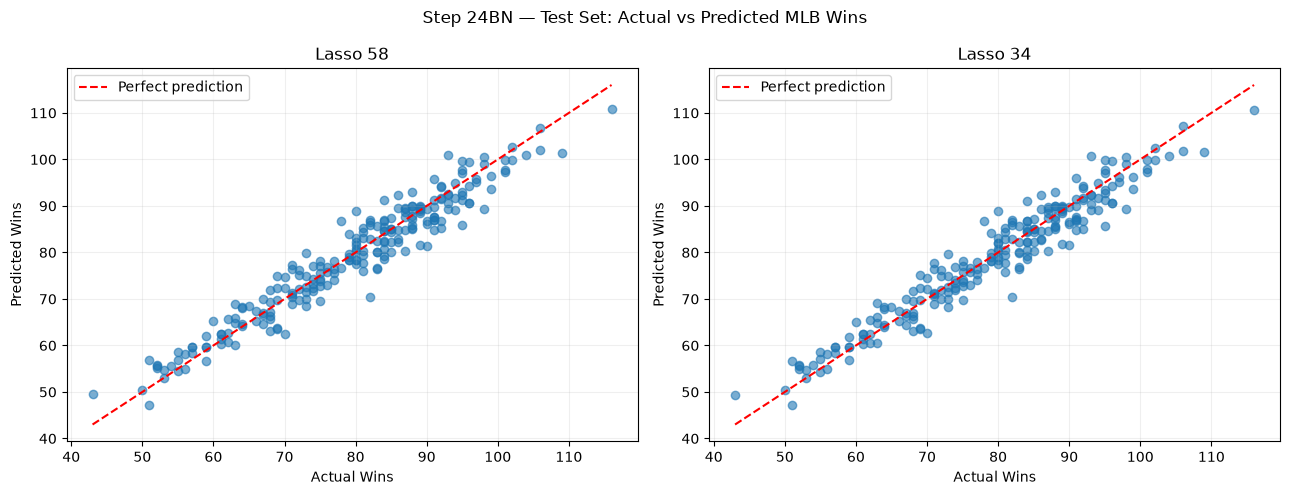


STEP 24BN COMPLETED


In [146]:

# ============================================================
# STEP 24BN — FINAL LASSO 58 vs LASSO 34
#
# Metrics:
#   Train R2, RMSE, MAE
#   Test R2, RMSE, MAE
#   Training-set 5-Fold CV MAE
#
# Split: 80% training / 20% testing
# Feature selection: training data only
#
# Does NOT overwrite previous models or Kaggle files.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# 1. Load existing 58-feature dataset
# ------------------------------------------------------------

X_24bn = X_24bj.copy().reset_index(drop=True)
y_24bn = pd.Series(y_24bj).reset_index(drop=True)

original_names_24bn = set(X44_24bf.columns)

original_cols_24bn = [
    col for col in X_24bn.columns
    if col in original_names_24bn
]

engineered_cols_24bn = [
    col for col in X_24bn.columns
    if col not in original_names_24bn
]

assert X_24bn.shape[1] == 58
assert len(original_cols_24bn) == 39
assert len(engineered_cols_24bn) == 19

print("=" * 85)
print("STEP 24BN — FINAL MODEL EVALUATION")
print("=" * 85)

print("Total records:", len(X_24bn))
print("Original features:", len(original_cols_24bn))
print("Engineered features:", len(engineered_cols_24bn))

# ------------------------------------------------------------
# 2. Train-test split
# ------------------------------------------------------------

X_train_24bn, X_test_24bn, y_train_24bn, y_test_24bn = (
    train_test_split(
        X_24bn,
        y_24bn,
        test_size=0.20,
        random_state=42
    )
)

print("\nTraining records:", len(X_train_24bn))
print("Testing records:", len(X_test_24bn))

# ------------------------------------------------------------
# 3. Define Lasso pipeline
# ------------------------------------------------------------

base_model_24bn = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(
        alpha=0.025,
        max_iter=100000
    ))
])

cv_24bn = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 4. Feature ranking function
#
# Ranks original columns using CV permutation importance.
# All data passed to this function must be training data.
# ------------------------------------------------------------

def rank_original_features_24bn(
    X_data,
    y_data,
    original_columns,
    model,
    seed=42
):

    inner_cv = KFold(
        n_splits=3,
        shuffle=True,
        random_state=seed
    )

    importance_scores = {
        col: [] for col in original_columns
    }

    for fold, (train_idx, valid_idx) in enumerate(
        inner_cv.split(X_data),
        start=1
    ):

        X_inner_train = X_data.iloc[train_idx]
        X_inner_valid = X_data.iloc[valid_idx]

        y_inner_train = y_data.iloc[train_idx]
        y_inner_valid = y_data.iloc[valid_idx]

        fitted = clone(model)
        fitted.fit(X_inner_train, y_inner_train)

        perm = permutation_importance(
            fitted,
            X_inner_valid,
            y_inner_valid,
            scoring="neg_mean_absolute_error",
            n_repeats=3,
            random_state=seed + fold,
            n_jobs=1
        )

        for col, importance in zip(
            X_data.columns,
            perm.importances_mean
        ):

            if col in importance_scores:
                importance_scores[col].append(importance)

    mean_scores = {
        col: float(np.mean(scores))
        for col, scores in importance_scores.items()
    }

    ranked = sorted(
        original_columns,
        key=lambda col: mean_scores[col],
        reverse=True
    )

    return ranked, mean_scores


# ------------------------------------------------------------
# 5. Rank original features on training data only
# ------------------------------------------------------------

ranked_original_24bn, importance_scores_24bn = (
    rank_original_features_24bn(
        X_train_24bn,
        y_train_24bn,
        original_cols_24bn,
        base_model_24bn,
        seed=42
    )
)

selected_original_24bn = ranked_original_24bn[:15]

cols_58_24bn = list(X_24bn.columns)

cols_34_24bn = (
    engineered_cols_24bn + selected_original_24bn
)

assert len(cols_34_24bn) == 34

print("\n" + "=" * 85)
print("FINAL TOP 15 ORIGINAL FEATURES")
print("=" * 85)

for rank, col in enumerate(selected_original_24bn, start=1):
    print(
        f"{rank:2d}. {col:20s} "
        f"Importance = {importance_scores_24bn[col]:.6f}"
    )

print("\nLasso 58 features:", len(cols_58_24bn))
print("Lasso 34 features:", len(cols_34_24bn))

# ------------------------------------------------------------
# 6. Cross-validation function
#
# For Lasso 34, reselect Top 15 within each CV
# training fold, rather than using the full training
# set's selected features.
# ------------------------------------------------------------

def cv_mae_compact_24bn(
    X_data,
    y_data,
    model,
    engineered_columns,
    original_columns,
    cv
):

    fold_maes = []

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X_data),
        start=1
    ):

        X_fold_train = X_data.iloc[train_idx]
        X_fold_valid = X_data.iloc[valid_idx]

        y_fold_train = y_data.iloc[train_idx]
        y_fold_valid = y_data.iloc[valid_idx]

        ranked, _ = rank_original_features_24bn(
            X_fold_train,
            y_fold_train,
            original_columns,
            model,
            seed=100 + fold
        )

        selected_cols = (
            engineered_columns + ranked[:15]
        )

        fitted = clone(model)
        fitted.fit(
            X_fold_train[selected_cols],
            y_fold_train
        )

        pred = fitted.predict(
            X_fold_valid[selected_cols]
        )

        fold_maes.append(
            mean_absolute_error(y_fold_valid, pred)
        )

    return np.array(fold_maes)


# ------------------------------------------------------------
# 7. Training-set CV MAE for both models
# ------------------------------------------------------------

print("\nRunning 5-fold CV for Lasso 58...")

cv_scores_58_24bn = -cross_val_score(
    base_model_24bn,
    X_train_24bn[cols_58_24bn],
    y_train_24bn,
    cv=cv_24bn,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

print("Running nested feature-selection CV for Lasso 34...")

cv_scores_34_24bn = cv_mae_compact_24bn(
    X_train_24bn,
    y_train_24bn,
    base_model_24bn,
    engineered_cols_24bn,
    original_cols_24bn,
    cv_24bn
)

# ------------------------------------------------------------
# 8. Fit final models on training set
# ------------------------------------------------------------

lasso58_model_24bn = clone(base_model_24bn)
lasso34_model_24bn = clone(base_model_24bn)

lasso58_model_24bn.fit(
    X_train_24bn[cols_58_24bn],
    y_train_24bn
)

lasso34_model_24bn.fit(
    X_train_24bn[cols_34_24bn],
    y_train_24bn
)

# ------------------------------------------------------------
# 9. Prediction function
# ------------------------------------------------------------

def get_metrics_24bn(y_true, predictions):

    return {
        "R2": r2_score(y_true, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, predictions)
        ),
        "MAE": mean_absolute_error(
            y_true, predictions
        )
    }


# ------------------------------------------------------------
# 10. Evaluate train and test predictions
# ------------------------------------------------------------

evaluation_rows_24bn = []

models_24bn = {
    "Lasso 58": (
        lasso58_model_24bn,
        cols_58_24bn,
        cv_scores_58_24bn
    ),
    "Lasso 34": (
        lasso34_model_24bn,
        cols_34_24bn,
        cv_scores_34_24bn
    )
}

predictions_24bn = {}

for name, (model, columns, cv_scores) in models_24bn.items():

    train_pred = model.predict(
        X_train_24bn[columns]
    )

    test_pred = model.predict(
        X_test_24bn[columns]
    )

    predictions_24bn[name] = {
        "train": train_pred,
        "test": test_pred
    }

    train_metrics = get_metrics_24bn(
        y_train_24bn,
        train_pred
    )

    test_metrics = get_metrics_24bn(
        y_test_24bn,
        test_pred
    )

    evaluation_rows_24bn.append({
        "Model": name,
        "Features": len(columns),

        "Train_R2": train_metrics["R2"],
        "Test_R2": test_metrics["R2"],

        "Train_RMSE": train_metrics["RMSE"],
        "Test_RMSE": test_metrics["RMSE"],

        "Train_MAE": train_metrics["MAE"],
        "Test_MAE": test_metrics["MAE"],

        "CV_MAE": cv_scores.mean(),
        "CV_Std": cv_scores.std(ddof=0),

        "Test_Train_MAE_Gap": (
            test_metrics["MAE"] - train_metrics["MAE"]
        )
    })

results_24bn = pd.DataFrame(
    evaluation_rows_24bn
).set_index("Model")

# ------------------------------------------------------------
# 11. Display final comparison
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 24BN — TRAIN / TEST / CV COMPARISON")
print("=" * 100)

print(
    results_24bn
    .round(6)
    .to_string()
)

print("\n" + "=" * 85)
print("CROSS-VALIDATION MAE BY FOLD")
print("=" * 85)

cv_detail_24bn = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Lasso58_CV_MAE": cv_scores_58_24bn,
    "Lasso34_CV_MAE": cv_scores_34_24bn
})

cv_detail_24bn["Difference_34_minus_58"] = (
    cv_detail_24bn["Lasso34_CV_MAE"]
    - cv_detail_24bn["Lasso58_CV_MAE"]
)

print(
    cv_detail_24bn
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 12. Plot actual vs predicted wins
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

for ax, name in zip(
    axes,
    ["Lasso 58", "Lasso 34"]
):

    pred = predictions_24bn[name]["test"]

    ax.scatter(
        y_test_24bn,
        pred,
        alpha=0.6
    )

    min_value = min(
        float(y_test_24bn.min()),
        float(np.min(pred))
    )

    max_value = max(
        float(y_test_24bn.max()),
        float(np.max(pred))
    )

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        "r--",
        label="Perfect prediction"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual Wins")
    ax.set_ylabel("Predicted Wins")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle(
    "Step 24BN — Test Set: Actual vs Predicted MLB Wins"
)

plt.tight_layout()
plt.show()

print("\nSTEP 24BN COMPLETED")


STEP 24BO — RESIDUAL SUMMARY
          Mean_Residual  Residual_Std     MAE    RMSE  Median_Abs_Error  Pct_Error_Within_3_Wins  Pct_Error_Within_5_Wins
Model                                                                                                                    
Lasso 58         0.1981        3.5095  2.7675  3.5151            2.3312                  62.8319                  83.6283
Lasso 34         0.2142        3.5007  2.7598  3.5072            2.2860                  62.3894                  83.6283


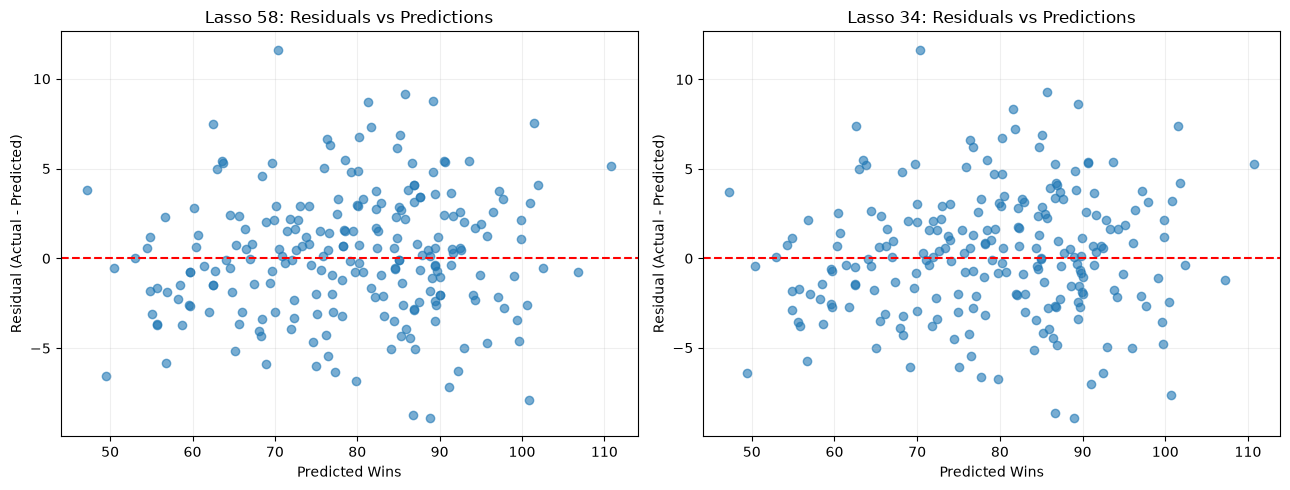

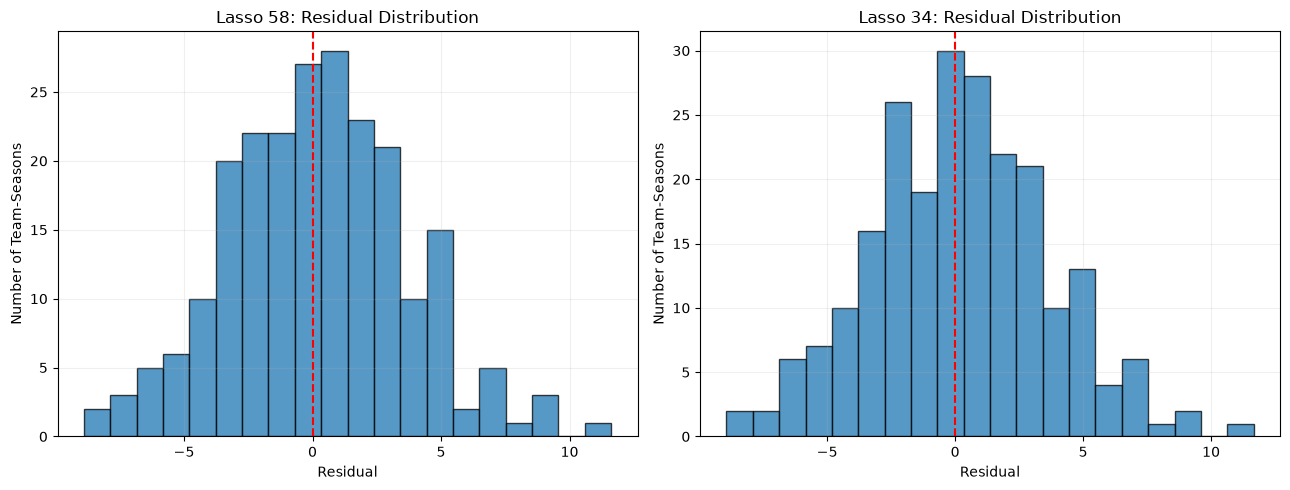


ERRORS BY ACTUAL WIN CATEGORY
              Teams  MAE_58  MAE_34  Bias_58  Bias_34
Win_Category                                         
<=60 wins        23  2.5536  2.5126  -1.8709  -1.8364
61-75 wins       64  2.4964  2.4907  -0.4729  -0.4542
76-90 wins       89  2.7122  2.7022   0.2767   0.2917
91-100 wins      40  3.3549  3.3518   1.6182   1.6244
>100 wins        10  3.1358  3.1937   2.8722   2.8785

ERRORS BY DECADE
             Teams  MAE_58  MAE_34  Bias_58  Bias_34
Decade                                              
Unknown         18  2.5417  2.5358  -0.1009   0.0172
decade_1910     25  3.7604  3.7653   1.1109   1.0576
decade_1920     16  2.1268  2.1382   0.0878   0.0569
decade_1930     13  2.4983  2.5179  -0.1404  -0.1338
decade_1940     18  3.7778  3.7811   1.0925   1.0897
decade_1950     18  2.0340  2.0388  -0.0214   0.1507
decade_1960     18  3.3176  3.2560   1.0671   0.9169
decade_1970     31  2.6390  2.6404  -0.1588  -0.0935
decade_1990     13  2.4206  2.4347   0.6335

In [147]:

# ============================================================
# STEP 24BO — RESIDUAL ANALYSIS
# Lasso 58 vs Lasso 34
#
# Reuses models and test predictions from Step 24BN.
# No retraining, no changes to Kaggle submission files.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Reuse Step 24BN test predictions
# ------------------------------------------------------------

y_actual_24bo = pd.Series(
    y_test_24bn
).reset_index(drop=True)

pred58_24bo = np.asarray(
    predictions_24bn["Lasso 58"]["test"]
)

pred34_24bo = np.asarray(
    predictions_24bn["Lasso 34"]["test"]
)

assert len(y_actual_24bo) == len(pred58_24bo)
assert len(y_actual_24bo) == len(pred34_24bo)

residuals_24bo = pd.DataFrame({
    "Actual_Wins": y_actual_24bo,
    "Predicted_58": pred58_24bo,
    "Predicted_34": pred34_24bo
})

# Residual = actual - predicted
residuals_24bo["Residual_58"] = (
    residuals_24bo["Actual_Wins"]
    - residuals_24bo["Predicted_58"]
)

residuals_24bo["Residual_34"] = (
    residuals_24bo["Actual_Wins"]
    - residuals_24bo["Predicted_34"]
)

residuals_24bo["Absolute_Error_58"] = (
    residuals_24bo["Residual_58"].abs()
)

residuals_24bo["Absolute_Error_34"] = (
    residuals_24bo["Residual_34"].abs()
)

# Preserve original test row indices for metadata matching
residuals_24bo["Row_Index"] = (
    X_test_24bn.index.to_numpy()
)

# ------------------------------------------------------------
# 2. Overall residual statistics
# ------------------------------------------------------------

summary_rows_24bo = []

for name, suffix in [
    ("Lasso 58", "58"),
    ("Lasso 34", "34")
]:

    residual = residuals_24bo[f"Residual_{suffix}"]
    abs_error = residual.abs()

    summary_rows_24bo.append({
        "Model": name,
        "Mean_Residual": residual.mean(),
        "Residual_Std": residual.std(ddof=0),
        "MAE": abs_error.mean(),
        "RMSE": np.sqrt(np.mean(residual**2)),
        "Median_Abs_Error": abs_error.median(),
        "Pct_Error_Within_3_Wins":
            100 * (abs_error <= 3).mean(),
        "Pct_Error_Within_5_Wins":
            100 * (abs_error <= 5).mean()
    })

summary_24bo = pd.DataFrame(
    summary_rows_24bo
).set_index("Model")

print("=" * 90)
print("STEP 24BO — RESIDUAL SUMMARY")
print("=" * 90)

print(summary_24bo.round(4).to_string())

# ------------------------------------------------------------
# 3. Residual scatterplots
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name, suffix in zip(
    axes,
    ["Lasso 58", "Lasso 34"],
    ["58", "34"]
):

    ax.scatter(
        residuals_24bo[f"Predicted_{suffix}"],
        residuals_24bo[f"Residual_{suffix}"],
        alpha=0.6
    )

    ax.axhline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(f"{name}: Residuals vs Predictions")
    ax.set_xlabel("Predicted Wins")
    ax.set_ylabel("Residual (Actual - Predicted)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Residual distributions
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name, suffix in zip(
    axes,
    ["Lasso 58", "Lasso 34"],
    ["58", "34"]
):

    ax.hist(
        residuals_24bo[f"Residual_{suffix}"],
        bins=20,
        edgecolor="black",
        alpha=0.75
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(f"{name}: Residual Distribution")
    ax.set_xlabel("Residual")
    ax.set_ylabel("Number of Team-Seasons")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Errors by actual win category
# ------------------------------------------------------------

# Fixed win categories for easy interpretation.
# These are descriptive analysis groups, not model inputs.

bins_24bo = [-np.inf, 60, 75, 90, 100, np.inf]

labels_24bo = [
    "<=60 wins",
    "61-75 wins",
    "76-90 wins",
    "91-100 wins",
    ">100 wins"
]

residuals_24bo["Win_Category"] = pd.cut(
    residuals_24bo["Actual_Wins"],
    bins=bins_24bo,
    labels=labels_24bo
)

win_category_24bo = (
    residuals_24bo
    .groupby(
        "Win_Category",
        observed=True
    )
    .agg(
        Teams=("Actual_Wins", "size"),
        MAE_58=("Absolute_Error_58", "mean"),
        MAE_34=("Absolute_Error_34", "mean"),
        Bias_58=("Residual_58", "mean"),
        Bias_34=("Residual_34", "mean")
    )
)

print("\n" + "=" * 90)
print("ERRORS BY ACTUAL WIN CATEGORY")
print("=" * 90)

print(win_category_24bo.round(4).to_string())

# ------------------------------------------------------------
# 6. Errors by decade, when decade indicators exist
# ------------------------------------------------------------

decade_columns_24bo = [
    col for col in X_test_24bn.columns
    if col.startswith("decade_")
]

if decade_columns_24bo:

    decade_data = (
        X_test_24bn[decade_columns_24bo]
        .reset_index(drop=True)
        .copy()
    )

    # Identify decade only when exactly one indicator is 1.
    decade_flags = decade_data.eq(1)
    exactly_one_decade = decade_flags.sum(axis=1).eq(1)

    decade_label = decade_flags.idxmax(axis=1)
    decade_label = decade_label.where(
        exactly_one_decade,
        "Unknown"
    )

    residuals_24bo["Decade"] = decade_label

    decade_summary_24bo = (
        residuals_24bo
        .groupby("Decade")
        .agg(
            Teams=("Actual_Wins", "size"),
            MAE_58=("Absolute_Error_58", "mean"),
            MAE_34=("Absolute_Error_34", "mean"),
            Bias_58=("Residual_58", "mean"),
            Bias_34=("Residual_34", "mean")
        )
        .sort_index()
    )

    print("\n" + "=" * 90)
    print("ERRORS BY DECADE")
    print("=" * 90)

    print(
        decade_summary_24bo
        .round(4)
        .to_string()
    )

else:
    print("\nNo decade indicators available.")

# ------------------------------------------------------------
# 7. Identify the largest errors
# ------------------------------------------------------------

largest_errors_24bo = (
    residuals_24bo
    .sort_values(
        "Absolute_Error_34",
        ascending=False
    )
    .head(15)
)

print("\n" + "=" * 90)
print("TOP 15 LARGEST LASSO 34 PREDICTION ERRORS")
print("=" * 90)

print(
    largest_errors_24bo[
        [
            "Row_Index",
            "Actual_Wins",
            "Predicted_34",
            "Residual_34",
            "Absolute_Error_34",
            "Absolute_Error_58"
        ]
    ]
    .round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 8. Compare which model wins per test record
# ------------------------------------------------------------

better_34_24bo = (
    residuals_24bo["Absolute_Error_34"]
    < residuals_24bo["Absolute_Error_58"]
).sum()

better_58_24bo = (
    residuals_24bo["Absolute_Error_58"]
    < residuals_24bo["Absolute_Error_34"]
).sum()

ties_24bo = (
    residuals_24bo["Absolute_Error_34"]
    == residuals_24bo["Absolute_Error_58"]
).sum()

print("\n" + "=" * 90)
print("PER-RECORD PREDICTION COMPARISON")
print("=" * 90)

print("Lasso 34 lower absolute error:", better_34_24bo)
print("Lasso 58 lower absolute error:", better_58_24bo)
print("Exact ties:", ties_24bo)

# ------------------------------------------------------------
# 9. Mean bias by model
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("PREDICTION BIAS")
print("=" * 90)

for suffix, name in [
    ("58", "Lasso 58"),
    ("34", "Lasso 34")
]:

    bias = residuals_24bo[f"Residual_{suffix}"].mean()

    print(f"{name}: Mean residual = {bias:.4f}")

    if bias > 0:
        print("  Tendency: underpredicts wins on average")
    elif bias < 0:
        print("  Tendency: overpredicts wins on average")
    else:
        print("  No average bias")

print("\nSTEP 24BO COMPLETED")


STEP 24BP — PREDICTION CALIBRATION
Training records: 903
Testing records: 226
Features: 34

Generating out-of-fold predictions...

CALIBRATION EQUATION
Calibrated wins = -0.157357 + (1.002022 x Predicted wins)

Running calibration cross-validation...

CROSS-VALIDATION MAE BY FOLD
 Fold  Original_MAE  Calibrated_MAE
    1      2.746057        2.746930
    2      2.875003        2.881654
    3      2.437548        2.433755
    4      2.918596        2.919172
    5      2.529295        2.532817

STEP 24BP — TRAIN / TEST / CV COMPARISON
                     Train_R2   Test_R2  Train_RMSE  Test_RMSE  Train_MAE  Test_MAE    CV_MAE
Model                                                                                        
Original Lasso 34    0.940021  0.932468    3.289287   3.507231   2.621053  2.759762  2.701300
Calibrated Lasso 34  0.940036  0.932552    3.288878   3.505047   2.621163  2.757501  2.702866

ERRORS BY ACTUAL WIN CATEGORY
              Teams  Original_MAE  Calibrated_MAE  Ori

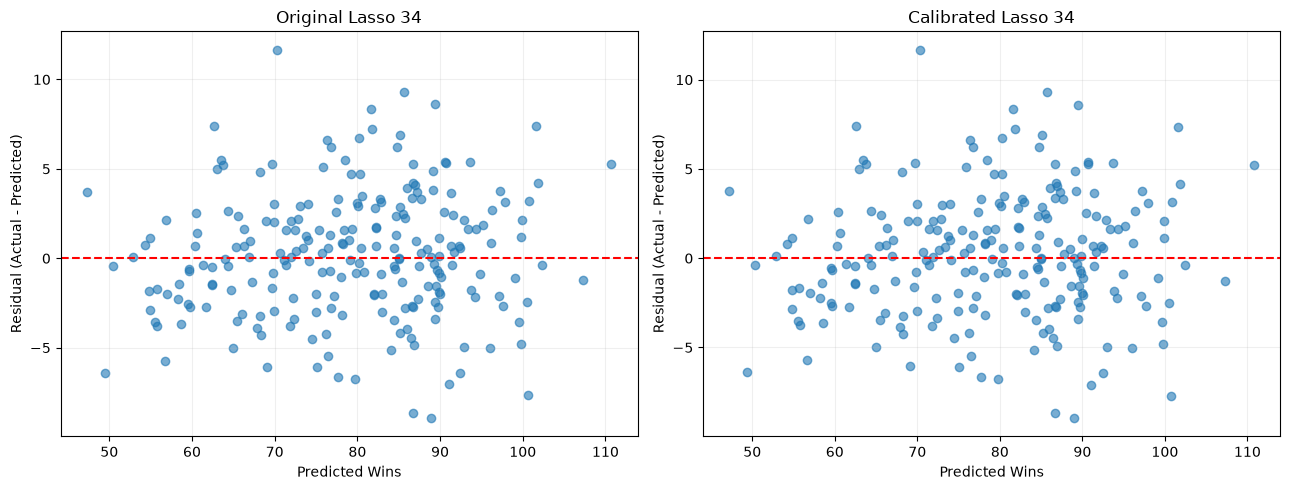


CALIBRATION CONCLUSION
Test MAE improvement: 0.002262
Calibration reduced test MAE.

STEP 24BP COMPLETED


In [148]:

# ============================================================
# STEP 24BP — LASSO 34 PREDICTION CALIBRATION
#
# Compare:
# 1. Original Lasso 34
# 2. Calibrated Lasso 34
#
# Metrics:
# Train R2, RMSE, MAE
# Test R2, RMSE, MAE
# 5-Fold CV MAE
# Errors by actual win category
#
# Calibration uses out-of-fold training predictions.
# No test target is used to fit calibration.
# No Kaggle files or previous models are overwritten.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import (
    KFold,
    cross_val_predict
)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# 1. Reuse Step 24BN
# ------------------------------------------------------------

X_train_24bp = X_train_24bn.copy()
X_test_24bp = X_test_24bn.copy()

y_train_24bp = pd.Series(
    y_train_24bn
).reset_index(drop=True)

y_test_24bp = pd.Series(
    y_test_24bn
).reset_index(drop=True)

cols_24bp = list(cols_34_24bn)

X_train_24bp = X_train_24bp[cols_24bp].reset_index(drop=True)
X_test_24bp = X_test_24bp[cols_24bp].reset_index(drop=True)

base_model_24bp = clone(base_model_24bn)

cv_24bp = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("=" * 90)
print("STEP 24BP — PREDICTION CALIBRATION")
print("=" * 90)

print("Training records:", len(X_train_24bp))
print("Testing records:", len(X_test_24bp))
print("Features:", len(cols_24bp))

# ------------------------------------------------------------
# 2. Generate training out-of-fold predictions
# ------------------------------------------------------------

print("\nGenerating out-of-fold predictions...")

oof_pred_24bp = cross_val_predict(
    base_model_24bp,
    X_train_24bp,
    y_train_24bp,
    cv=cv_24bp,
    n_jobs=1
)

# ------------------------------------------------------------
# 3. Fit calibration using OOF predictions
# ------------------------------------------------------------

calibrator_24bp = LinearRegression()

calibrator_24bp.fit(
    oof_pred_24bp.reshape(-1, 1),
    y_train_24bp
)

cal_intercept_24bp = calibrator_24bp.intercept_
cal_slope_24bp = calibrator_24bp.coef_[0]

print("\nCALIBRATION EQUATION")
print(
    f"Calibrated wins = "
    f"{cal_intercept_24bp:.6f} + "
    f"({cal_slope_24bp:.6f} x Predicted wins)"
)

# ------------------------------------------------------------
# 4. Fit final Lasso 34 on training data
# ------------------------------------------------------------

lasso34_24bp = clone(base_model_24bp)

lasso34_24bp.fit(
    X_train_24bp,
    y_train_24bp
)

original_train_24bp = lasso34_24bp.predict(
    X_train_24bp
)

original_test_24bp = lasso34_24bp.predict(
    X_test_24bp
)

calibrated_train_24bp = calibrator_24bp.predict(
    original_train_24bp.reshape(-1, 1)
)

calibrated_test_24bp = calibrator_24bp.predict(
    original_test_24bp.reshape(-1, 1)
)

# ------------------------------------------------------------
# 5. Leakage-safe calibration CV
#
# Within each outer training fold:
# - generate inner OOF predictions
# - fit the calibrator
# - fit Lasso on that outer training fold
# - evaluate on the outer validation fold
#
# Note: the 34 columns are fixed from Step 24BN.
# ------------------------------------------------------------

print("\nRunning calibration cross-validation...")

cv_rows_24bp = []

for fold, (train_idx, valid_idx) in enumerate(
    cv_24bp.split(X_train_24bp),
    start=1
):

    X_fold_train = X_train_24bp.iloc[train_idx]
    X_fold_valid = X_train_24bp.iloc[valid_idx]

    y_fold_train = y_train_24bp.iloc[train_idx]
    y_fold_valid = y_train_24bp.iloc[valid_idx]

    inner_cv = KFold(
        n_splits=4,
        shuffle=True,
        random_state=100 + fold
    )

    inner_oof = cross_val_predict(
        base_model_24bp,
        X_fold_train,
        y_fold_train,
        cv=inner_cv,
        n_jobs=1
    )

    fold_calibrator = LinearRegression()

    fold_calibrator.fit(
        inner_oof.reshape(-1, 1),
        y_fold_train
    )

    fold_model = clone(base_model_24bp)

    fold_model.fit(
        X_fold_train,
        y_fold_train
    )

    valid_pred = fold_model.predict(
        X_fold_valid
    )

    valid_calibrated = fold_calibrator.predict(
        valid_pred.reshape(-1, 1)
    )

    cv_rows_24bp.append({
        "Fold": fold,
        "Original_MAE": mean_absolute_error(
            y_fold_valid,
            valid_pred
        ),
        "Calibrated_MAE": mean_absolute_error(
            y_fold_valid,
            valid_calibrated
        )
    })

cv_results_24bp = pd.DataFrame(cv_rows_24bp)

print("\nCROSS-VALIDATION MAE BY FOLD")
print(cv_results_24bp.round(6).to_string(index=False))

# ------------------------------------------------------------
# 6. Evaluation metrics
# ------------------------------------------------------------

def metrics_24bp(y_true, predictions):
    return {
        "R2": r2_score(y_true, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, predictions)
        ),
        "MAE": mean_absolute_error(
            y_true, predictions
        )
    }

evaluation_rows_24bp = []

prediction_sets_24bp = {
    "Original Lasso 34": (
        original_train_24bp,
        original_test_24bp,
        cv_results_24bp["Original_MAE"].mean()
    ),
    "Calibrated Lasso 34": (
        calibrated_train_24bp,
        calibrated_test_24bp,
        cv_results_24bp["Calibrated_MAE"].mean()
    )
}

for name, (train_pred, test_pred, cv_mae) in (
    prediction_sets_24bp.items()
):

    train_metrics = metrics_24bp(
        y_train_24bp,
        train_pred
    )

    test_metrics = metrics_24bp(
        y_test_24bp,
        test_pred
    )

    evaluation_rows_24bp.append({
        "Model": name,
        "Train_R2": train_metrics["R2"],
        "Test_R2": test_metrics["R2"],
        "Train_RMSE": train_metrics["RMSE"],
        "Test_RMSE": test_metrics["RMSE"],
        "Train_MAE": train_metrics["MAE"],
        "Test_MAE": test_metrics["MAE"],
        "CV_MAE": cv_mae
    })

results_24bp = pd.DataFrame(
    evaluation_rows_24bp
).set_index("Model")

print("\n" + "=" * 100)
print("STEP 24BP — TRAIN / TEST / CV COMPARISON")
print("=" * 100)

print(results_24bp.round(6).to_string())

# ------------------------------------------------------------
# 7. Error analysis by actual win category
# ------------------------------------------------------------

error_analysis_24bp = pd.DataFrame({
    "Actual_Wins": y_test_24bp,
    "Original_Prediction": original_test_24bp,
    "Calibrated_Prediction": calibrated_test_24bp
})

error_analysis_24bp["Original_Error"] = (
    error_analysis_24bp["Actual_Wins"]
    - error_analysis_24bp["Original_Prediction"]
)

error_analysis_24bp["Calibrated_Error"] = (
    error_analysis_24bp["Actual_Wins"]
    - error_analysis_24bp["Calibrated_Prediction"]
)

error_analysis_24bp["Win_Category"] = pd.cut(
    error_analysis_24bp["Actual_Wins"],
    bins=[-np.inf, 60, 75, 90, 100, np.inf],
    labels=[
        "<=60 wins",
        "61-75 wins",
        "76-90 wins",
        "91-100 wins",
        ">100 wins"
    ]
)

category_summary_24bp = (
    error_analysis_24bp
    .groupby("Win_Category", observed=True)
    .agg(
        Teams=("Actual_Wins", "size"),
        Original_MAE=(
            "Original_Error",
            lambda x: x.abs().mean()
        ),
        Calibrated_MAE=(
            "Calibrated_Error",
            lambda x: x.abs().mean()
        ),
        Original_Bias=("Original_Error", "mean"),
        Calibrated_Bias=("Calibrated_Error", "mean")
    )
)

print("\n" + "=" * 100)
print("ERRORS BY ACTUAL WIN CATEGORY")
print("=" * 100)

print(category_summary_24bp.round(4).to_string())

# ------------------------------------------------------------
# 8. Compare residuals visually
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, title, pred in zip(
    axes,
    ["Original Lasso 34", "Calibrated Lasso 34"],
    [original_test_24bp, calibrated_test_24bp]
):

    residual = y_test_24bp.to_numpy() - pred

    ax.scatter(pred, residual, alpha=0.6)
    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(title)
    ax.set_xlabel("Predicted Wins")
    ax.set_ylabel("Residual (Actual - Predicted)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Test MAE improvement
# ------------------------------------------------------------

original_test_mae_24bp = results_24bp.loc[
    "Original Lasso 34", "Test_MAE"
]

calibrated_test_mae_24bp = results_24bp.loc[
    "Calibrated Lasso 34", "Test_MAE"
]

improvement_24bp = (
    original_test_mae_24bp - calibrated_test_mae_24bp
)

print("\n" + "=" * 90)
print("CALIBRATION CONCLUSION")
print("=" * 90)

print(
    "Test MAE improvement:",
    round(improvement_24bp, 6)
)

if improvement_24bp > 0:
    print("Calibration reduced test MAE.")
elif improvement_24bp < 0:
    print("Calibration increased test MAE.")
else:
    print("Calibration produced the same test MAE.")

print("\nSTEP 24BP COMPLETED")


STEP 24BQ — PYTHAGOREAN RESIDUAL DIAGNOSTICS
Test records: 226
Expected wins feature: Pythagenpat_Expected_Wins

CORRELATION ANALYSIS
                   Relationship  Pearson_r  Pearson_p  Spearman_r  Spearman_p
Residual vs Actual-Expected Gap    0.84269    0.00000     0.81295     0.00000
 Absolute Error vs Absolute Gap    0.69944    0.00000     0.57234     0.00000
      Residual vs Expected Wins    0.08972    0.17895     0.10132     0.12887


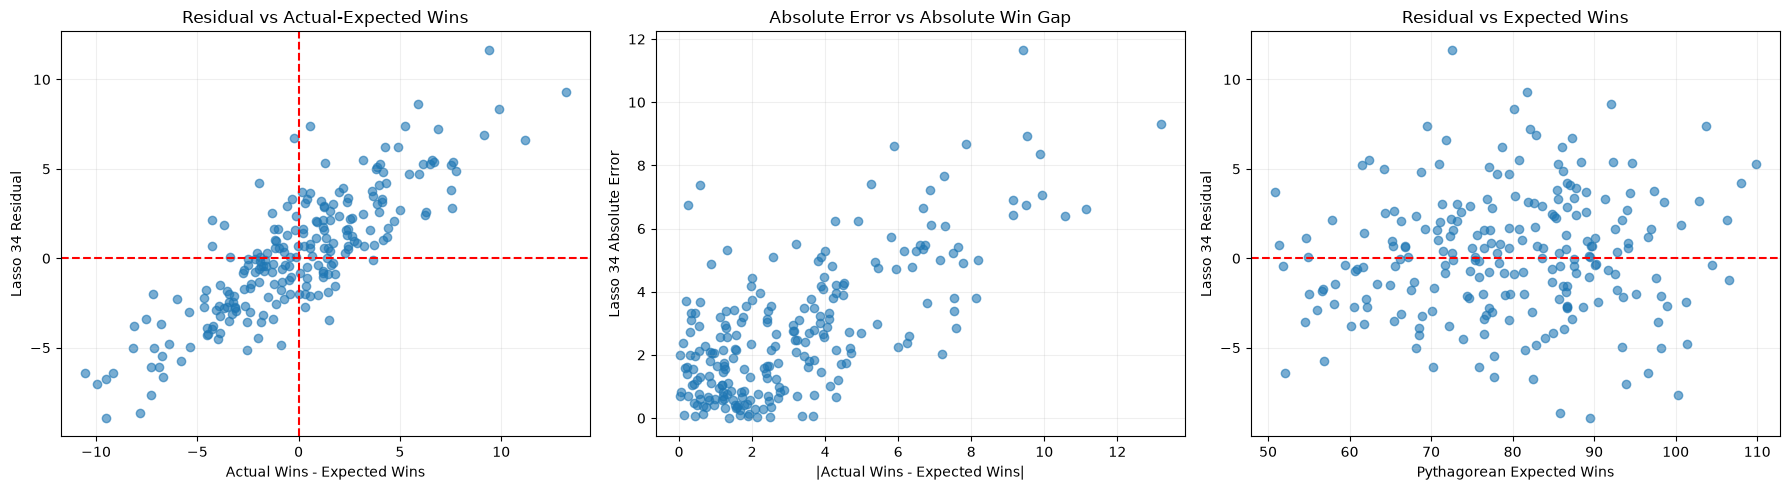


ERRORS BY PYTHAGOREAN GAP SIZE
              Teams  Mean_Abs_Pyth_Gap  MAE_34  MAE_58  Mean_Residual_34
Gap_Category                                                            
0-2 wins         99             1.0320  1.6959  1.7171            0.3040
>2-5 wins        84             3.4101  2.5211  2.5245            0.1656
>5-10 wins       40             7.2269  5.5420  5.5331           -0.1283
>10 wins          3            11.6357  7.4541  7.3581            3.1793

TOP 15 LARGEST LASSO 34 ERRORS
     Actual_Wins  Predicted_34  Expected_Wins  Actual_Minus_Expected  Residual_34  Absolute_Error_34
103           82       70.3386        72.5843                 9.4157      11.6614            11.6614
124           95       85.6827        81.8062                13.1938       9.3173             9.3173
18            80       88.9330        89.5212                -9.5212      -8.9330             8.9330
116           78       86.6684        85.8501                -7.8501      -8.6684             

In [149]:

# ============================================================
# STEP 24BQ — EXTREME-TEAM RESIDUAL ANALYSIS
#
# Model: Lasso 34
# Data: Existing 226 test records from Step 24BN
#
# Questions:
# 1. Are residuals related to Pythagorean expected wins?
# 2. Are large errors related to unexpected wins?
# 3. Which team-seasons are most difficult to predict?
#
# Diagnostic analysis only — no retraining.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr

# ------------------------------------------------------------
# 1. Reuse existing test data and predictions
# ------------------------------------------------------------

X_test_24bq = X_test_24bn.copy().reset_index(drop=True)

y_test_24bq = pd.Series(
    y_test_24bn
).reset_index(drop=True)

pred34_24bq = np.asarray(
    predictions_24bn["Lasso 34"]["test"]
)

pred58_24bq = np.asarray(
    predictions_24bn["Lasso 58"]["test"]
)

assert len(X_test_24bq) == len(y_test_24bq)
assert len(pred34_24bq) == len(y_test_24bq)

# ------------------------------------------------------------
# 2. Build residual analysis table
# ------------------------------------------------------------

diagnostics_24bq = pd.DataFrame({
    "Actual_Wins": y_test_24bq,
    "Predicted_34": pred34_24bq,
    "Predicted_58": pred58_24bq
})

diagnostics_24bq["Residual_34"] = (
    diagnostics_24bq["Actual_Wins"]
    - diagnostics_24bq["Predicted_34"]
)

diagnostics_24bq["Residual_58"] = (
    diagnostics_24bq["Actual_Wins"]
    - diagnostics_24bq["Predicted_58"]
)

diagnostics_24bq["Absolute_Error_34"] = (
    diagnostics_24bq["Residual_34"].abs()
)

diagnostics_24bq["Absolute_Error_58"] = (
    diagnostics_24bq["Residual_58"].abs()
)

# ------------------------------------------------------------
# 3. Add Pythagorean expected wins
# ------------------------------------------------------------

pyth_cols_24bq = [
    "Pythagorean_Expected_Wins",
    "Pythagenpat_Expected_Wins"
]

for col in pyth_cols_24bq:

    if col in X_test_24bq.columns:

        diagnostics_24bq[col] = (
            X_test_24bq[col].to_numpy()
        )

# Use Pythagenpat if available, otherwise Pythagorean
if "Pythagenpat_Expected_Wins" in diagnostics_24bq:

    expected_col_24bq = "Pythagenpat_Expected_Wins"

elif "Pythagorean_Expected_Wins" in diagnostics_24bq:

    expected_col_24bq = "Pythagorean_Expected_Wins"

else:
    raise ValueError(
        "No Pythagorean expected wins feature found."
    )

diagnostics_24bq["Expected_Wins"] = (
    diagnostics_24bq[expected_col_24bq]
)

diagnostics_24bq["Actual_Minus_Expected"] = (
    diagnostics_24bq["Actual_Wins"]
    - diagnostics_24bq["Expected_Wins"]
)

print("=" * 95)
print("STEP 24BQ — PYTHAGOREAN RESIDUAL DIAGNOSTICS")
print("=" * 95)

print("Test records:", len(diagnostics_24bq))
print("Expected wins feature:", expected_col_24bq)

# ------------------------------------------------------------
# 4. Correlation analysis
# ------------------------------------------------------------

pairs_24bq = [
    (
        "Residual vs Actual-Expected Gap",
        "Residual_34",
        "Actual_Minus_Expected"
    ),
    (
        "Absolute Error vs Absolute Gap",
        "Absolute_Error_34",
        "Actual_Minus_Expected"
    ),
    (
        "Residual vs Expected Wins",
        "Residual_34",
        "Expected_Wins"
    )
]

correlation_rows_24bq = []

for label, x_col, y_col in pairs_24bq:

    x = diagnostics_24bq[x_col].to_numpy()

    y = diagnostics_24bq[y_col].to_numpy()

    # For absolute-gap analysis, take absolute values.
    if label == "Absolute Error vs Absolute Gap":
        y = np.abs(y)

    pearson_value, pearson_p = pearsonr(x, y)
    spearman_value, spearman_p = spearmanr(x, y)

    correlation_rows_24bq.append({
        "Relationship": label,
        "Pearson_r": pearson_value,
        "Pearson_p": pearson_p,
        "Spearman_r": spearman_value,
        "Spearman_p": spearman_p
    })

correlations_24bq = pd.DataFrame(
    correlation_rows_24bq
)

print("\n" + "=" * 95)
print("CORRELATION ANALYSIS")
print("=" * 95)

print(
    correlations_24bq
    .round(5)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 5. Visualize residual relationships
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(
    diagnostics_24bq["Actual_Minus_Expected"],
    diagnostics_24bq["Residual_34"],
    alpha=0.6
)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Residual vs Actual-Expected Wins")
axes[0].set_xlabel("Actual Wins - Expected Wins")
axes[0].set_ylabel("Lasso 34 Residual")

axes[1].scatter(
    diagnostics_24bq["Actual_Minus_Expected"].abs(),
    diagnostics_24bq["Absolute_Error_34"],
    alpha=0.6
)
axes[1].set_title("Absolute Error vs Absolute Win Gap")
axes[1].set_xlabel("|Actual Wins - Expected Wins|")
axes[1].set_ylabel("Lasso 34 Absolute Error")

axes[2].scatter(
    diagnostics_24bq["Expected_Wins"],
    diagnostics_24bq["Residual_34"],
    alpha=0.6
)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_title("Residual vs Expected Wins")
axes[2].set_xlabel("Pythagorean Expected Wins")
axes[2].set_ylabel("Lasso 34 Residual")

for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Compare errors by size of Pythagorean gap
# ------------------------------------------------------------

diagnostics_24bq["Abs_Pyth_Gap"] = (
    diagnostics_24bq["Actual_Minus_Expected"].abs()
)

diagnostics_24bq["Gap_Category"] = pd.cut(
    diagnostics_24bq["Abs_Pyth_Gap"],
    bins=[-np.inf, 2, 5, 10, np.inf],
    labels=[
        "0-2 wins",
        ">2-5 wins",
        ">5-10 wins",
        ">10 wins"
    ]
)

gap_summary_24bq = (
    diagnostics_24bq
    .groupby("Gap_Category", observed=True)
    .agg(
        Teams=("Actual_Wins", "size"),
        Mean_Abs_Pyth_Gap=("Abs_Pyth_Gap", "mean"),
        MAE_34=("Absolute_Error_34", "mean"),
        MAE_58=("Absolute_Error_58", "mean"),
        Mean_Residual_34=("Residual_34", "mean")
    )
)

print("\n" + "=" * 95)
print("ERRORS BY PYTHAGOREAN GAP SIZE")
print("=" * 95)

print(
    gap_summary_24bq
    .round(4)
    .to_string()
)

# ------------------------------------------------------------
# 7. Largest Lasso 34 errors
# ------------------------------------------------------------

largest_errors_24bq = (
    diagnostics_24bq
    .sort_values(
        "Absolute_Error_34",
        ascending=False
    )
    .head(15)
)

print("\n" + "=" * 95)
print("TOP 15 LARGEST LASSO 34 ERRORS")
print("=" * 95)

print(
    largest_errors_24bq[
        [
            "Actual_Wins",
            "Predicted_34",
            "Expected_Wins",
            "Actual_Minus_Expected",
            "Residual_34",
            "Absolute_Error_34"
        ]
    ]
    .round(4)
    .to_string(index=True)
)

# ------------------------------------------------------------
# 8. Extreme-win teams
# ------------------------------------------------------------

diagnostics_24bq["Team_Category"] = pd.cut(
    diagnostics_24bq["Actual_Wins"],
    bins=[-np.inf, 60, 100, np.inf],
    labels=[
        "Weak (<=60 wins)",
        "Middle (61-100 wins)",
        "Strong (>100 wins)"
    ]
)

extreme_summary_24bq = (
    diagnostics_24bq
    .groupby("Team_Category", observed=True)
    .agg(
        Teams=("Actual_Wins", "size"),
        Mean_Actual_Wins=("Actual_Wins", "mean"),
        Mean_Expected_Wins=("Expected_Wins", "mean"),
        Mean_Pyth_Gap=("Actual_Minus_Expected", "mean"),
        MAE_34=("Absolute_Error_34", "mean"),
        Bias_34=("Residual_34", "mean")
    )
)

print("\n" + "=" * 95)
print("EXTREME-TEAM DIAGNOSTICS")
print("=" * 95)

print(
    extreme_summary_24bq
    .round(4)
    .to_string()
)

print("\nSTEP 24BQ COMPLETED")


In [160]:
# Find possible Kaggle test variables in your notebook

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame) and len(value) == 400:
        print(name, value.shape, list(value.columns[:8]))

predict_df (400, 47) ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
predict_scaled (400, 44) ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
submission_df (400, 2) ['ID', 'W']
predict_44 (400, 47) ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
X_lasso_predict (400, 47) ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
X_lasso_predict_scaled (400, 47) ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
lasso_submission_df (400, 2) ['ID', 'W']
team_predictions (400, 3) ['ID', 'teamID', 'W']
predict_47exp (400, 47) ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
df (400, 50) ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
X_predict_56 (400, 56) ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
submission_56 (400, 2) ['ID', 'W']
lasso_predict_export (400, 50) ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
saved_predict (400, 50) ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
X_predict_48 (400, 48) ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
submission_48 (400, 2) ['ID', 'W']
X_predict_st

In [161]:
import pandas as pd

print("Searching for Kaggle test datasets...\n")

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame) and len(value) == 400:
        print(f"Variable: {name}")
        print(f"Shape: {value.shape}")
        print(f"First columns: {list(value.columns[:10])}")
        print("-" * 60)

Searching for Kaggle test datasets...

Variable: predict_df
Shape: (400, 47)
First columns: ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO']
------------------------------------------------------------
Variable: predict_scaled
Shape: (400, 44)
First columns: ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO', 'SB']
------------------------------------------------------------
Variable: submission_df
Shape: (400, 2)
First columns: ['ID', 'W']
------------------------------------------------------------
Variable: predict_44
Shape: (400, 47)
First columns: ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO']
------------------------------------------------------------
Variable: X_lasso_predict
Shape: (400, 47)
First columns: ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO', 'SB']
------------------------------------------------------------
Variable: X_lasso_predict_scaled
Shape: (400, 47)
First columns: ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO', 'SB']
-----

In [162]:
# STEP 24BR — Connect Kaggle test features

X_test_kaggle_24br = X_kaggle_58.copy()

# Check that all training features exist in Kaggle test data
missing_24br = [
    col for col in X58_24bf.columns
    if col not in X_test_kaggle_24br.columns
]

extra_24br = [
    col for col in X_test_kaggle_24br.columns
    if col not in X58_24bf.columns
]

print("Training shape:", X58_24bf.shape)
print("Kaggle test shape:", X_test_kaggle_24br.shape)
print("Missing features:", missing_24br)
print("Extra features:", extra_24br)

if missing_24br:
    raise ValueError("Missing features: " + str(missing_24br))

# Ensure feature order matches training data
X_test_kaggle_24br = X_test_kaggle_24br[
    X58_24bf.columns
].copy()

# Verify Kaggle ID order before submission
if "ID" not in kaggle_test_58.columns:
    raise ValueError("Kaggle source data has no ID column.")

if "ID" not in submission_51_24s.columns:
    raise ValueError("Existing submission has no ID column.")

assert np.array_equal(
    kaggle_test_58["ID"].to_numpy(),
    submission_51_24s["ID"].to_numpy()
), "Kaggle test IDs do not match submission IDs!"

assert len(X_test_kaggle_24br) == 400

print("\nKaggle features and ID order checked.")

Training shape: (1129, 58)
Kaggle test shape: (400, 58)
Missing features: []
Extra features: []

Kaggle features and ID order checked.


In [164]:

# ============================================================
# STEP 24BR — LASSO 34 KAGGLE LATE SUBMISSION
# Train on all 1,129 records
# Select Top 15 original + 19 engineered features
# Save a NEW submission CSV
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

# ------------------------------------------------------------
# 1. Full training dataset
# ------------------------------------------------------------

X_train_24br = X58_24bf.copy().reset_index(drop=True)
y_train_24br = pd.Series(y_24bf).reset_index(drop=True)

original_names_24br = set(X44_24bf.columns)

original_cols_24br = [
    c for c in X_train_24br.columns
    if c in original_names_24br
]

engineered_cols_24br = [
    c for c in X_train_24br.columns
    if c not in original_names_24br
]

assert X_train_24br.shape == (1129, 58)
assert len(original_cols_24br) == 39
assert len(engineered_cols_24br) == 19

# ------------------------------------------------------------
# 2. Find Kaggle test feature matrix
#
# IMPORTANT:
# Replace X_test_kaggle_24br with the actual variable
# containing the 400 Kaggle rows and 58 features.
#
# Do NOT use X_test_24bn:
# that is the 226-row LOCAL validation dataset.
# ------------------------------------------------------------

# EXAMPLE ONLY — uncomment and change to your variable:
#
# X_test_kaggle_24br = X58_kaggle_test.copy()

if "X_test_kaggle_24br" not in globals():
    raise NameError(
        "Please define X_test_kaggle_24br using your "
        "400-row Kaggle test feature matrix first. "
        "It must contain the same 58 columns as X58_24bf."
    )

X_test_kaggle_24br = X_test_kaggle_24br.copy()

assert len(X_test_kaggle_24br) == 400, (
    "Expected 400 Kaggle test rows."
)

missing_24br = [
    c for c in X_train_24br.columns
    if c not in X_test_kaggle_24br.columns
]

if missing_24br:
    raise ValueError(
        "Missing Kaggle test features: "
        + str(missing_24br)
        + "\nApply the same feature engineering used "
          "for X58_24bf to the Kaggle test data."
    )

X_test_kaggle_24br = (
    X_test_kaggle_24br[X_train_24br.columns]
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. Lasso model
# ------------------------------------------------------------

model_24br = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(
        alpha=0.025,
        max_iter=100000
    ))
])

# ------------------------------------------------------------
# 4. Rank original features using training-only CV
# ------------------------------------------------------------

cv_24br = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

importance_24br = {
    col: [] for col in original_cols_24br
}

print("Selecting Top 15 original features...")

for fold, (tr_idx, val_idx) in enumerate(
    cv_24br.split(X_train_24br),
    start=1
):

    X_tr = X_train_24br.iloc[tr_idx]
    X_val = X_train_24br.iloc[val_idx]

    y_tr = y_train_24br.iloc[tr_idx]
    y_val = y_train_24br.iloc[val_idx]

    fitted = clone(model_24br)
    fitted.fit(X_tr, y_tr)

    perm = permutation_importance(
        fitted,
        X_val,
        y_val,
        scoring="neg_mean_absolute_error",
        n_repeats=3,
        random_state=42 + fold,
        n_jobs=1
    )

    for col, score in zip(
        X_train_24br.columns,
        perm.importances_mean
    ):
        if col in importance_24br:
            importance_24br[col].append(score)

mean_importance_24br = {
    col: np.mean(scores)
    for col, scores in importance_24br.items()
}

selected_original_24br = sorted(
    original_cols_24br,
    key=lambda c: mean_importance_24br[c],
    reverse=True
)[:15]

selected_features_24br = (
    engineered_cols_24br + selected_original_24br
)

assert len(selected_features_24br) == 34

print("\nSelected 15 original features:")
for i, col in enumerate(selected_original_24br, 1):
    print(f"{i:2d}. {col}")

# ------------------------------------------------------------
# 5. Fit final Lasso 34 on all training rows
# ------------------------------------------------------------

final_lasso34_24br = clone(model_24br)

final_lasso34_24br.fit(
    X_train_24br[selected_features_24br],
    y_train_24br
)

# ------------------------------------------------------------
# 6. Predict Kaggle test rows
# ------------------------------------------------------------

predictions_lasso34_24br = final_lasso34_24br.predict(
    X_test_kaggle_24br[selected_features_24br]
)

# Previous submission uses whole-number wins.
# Use the same convention for comparison.
predictions_lasso34_24br = np.rint(
    predictions_lasso34_24br
).astype(int)

# ------------------------------------------------------------
# 7. Get IDs from existing Lasso 51 submission
# ------------------------------------------------------------

existing_submission_24br = pd.read_csv(
    "submission_lasso51_final.csv"
)

assert list(existing_submission_24br.columns) == [
    "ID", "W"
]

assert len(existing_submission_24br) == 400

# CRITICAL:
# The test feature rows must be in exactly the same order
# as the existing submission IDs.
#
# If your Kaggle test data has an ID column, verify it.
if "ID" in X_test_kaggle_24br.columns:
    assert np.array_equal(
        X_test_kaggle_24br["ID"].to_numpy(),
        existing_submission_24br["ID"].to_numpy()
    ), "Kaggle test row order does not match submission IDs."

submission_lasso34_24br = pd.DataFrame({
    "ID": existing_submission_24br["ID"],
    "W": predictions_lasso34_24br
})

# ------------------------------------------------------------
# 8. Save new CSV without overwriting existing files
# ------------------------------------------------------------

output_path_24br = Path(
    "submission_lasso34_24BR.csv"
)

if output_path_24br.exists():
    raise FileExistsError(
        f"{output_path_24br} already exists. "
        "Rename the output to avoid overwriting it."
    )

submission_lasso34_24br.to_csv(
    output_path_24br,
    index=False
)

print("\n" + "=" * 75)
print("LASSO 34 KAGGLE SUBMISSION CREATED")
print("=" * 75)

print("File:", output_path_24br.resolve())
print("Rows:", len(submission_lasso34_24br))
print("Missing values:",
      submission_lasso34_24br.isna().sum().sum())

print("\nFirst five predictions:")
print(submission_lasso34_24br.head())

print("\nPrediction summary:")
print(submission_lasso34_24br["W"].describe())

print("\nReady for Kaggle Late Submission!")


Selecting Top 15 original features...

Selected 15 original features:
 1. SV
 2. IPouts
 3. AB
 4. CG
 5. G
 6. decade_1910
 7. SHO
 8. E
 9. HRA
10. decade_1940
11. decade_1930
12. mlb_rpg
13. decade_1920
14. era_6
15. SB

LASSO 34 KAGGLE SUBMISSION CREATED
File: /home/yoke/MLB/submission_lasso34_24BR.csv
Rows: 400
Missing values: 0

First five predictions:
     ID   W
0  1649  76
1  1223  77
2   748  82
3  1735  85
4   794  79

Prediction summary:
count    400.000000
mean      79.497500
std       12.329031
min       45.000000
25%       70.000000
50%       81.000000
75%       89.000000
max      113.000000
Name: W, dtype: float64

Ready for Kaggle Late Submission!


In [166]:
# STEP 24BS — Corrected imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone

# Cross-validation tools
from sklearn.model_selection import (
    KFold,
    cross_validate
)

# Regression models
from sklearn.linear_model import (
    Lasso,
    Ridge
)

# Ensemble models
from sklearn.ensemble import (
    GradientBoostingRegressor,
    StackingRegressor
)

# Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print("All imports successful!")

All imports successful!


Training data: (1129, 34)
Evaluating Lasso 34...
Evaluating Gradient Boosting...
Evaluating Stacking...

MODEL COMPARISON
            Model  CV_MAE  CV_RMSE   CV_R2
         Lasso 34 2.73739  3.44044 0.93413
         Stacking 2.73838  3.44530 0.93397
Gradient Boosting 3.05955  3.84705 0.91786


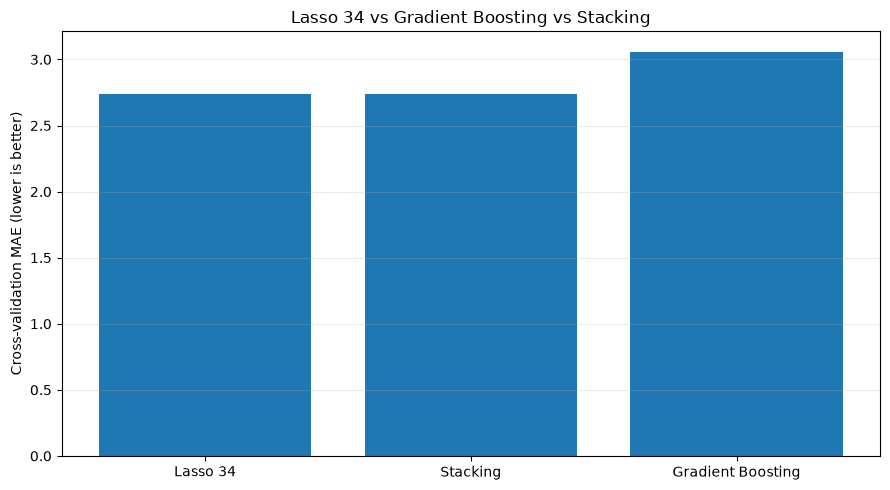


Best model: Lasso 34


In [167]:
# ============================================================
# STEP 24BS — COMPARE THREE MACHINE LEARNING MODELS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge
from sklearn.ensemble import (
    GradientBoostingRegressor,
    StackingRegressor
)

# 1. Prepare 34-feature dataset
X_24bs = X58_24bf[selected_features_24br].copy()
y_24bs = pd.Series(y_24bf).copy()

print("Training data:", X_24bs.shape)

# 2. Define Lasso
lasso34_24bs = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=0.025, max_iter=100000))
])

# 3. Define Gradient Boosting
gb_24bs = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=5,
    subsample=0.85,
    random_state=42
)

# 4. Define Stacking
stacking_24bs = StackingRegressor(
    estimators=[
        ("lasso", clone(lasso34_24bs)),
        ("gb", clone(gb_24bs))
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=5,
    n_jobs=-1
)

models_24bs = {
    "Lasso 34": lasso34_24bs,
    "Gradient Boosting": gb_24bs,
    "Stacking": stacking_24bs
}

# 5. Cross-validation
cv_24bs = KFold(n_splits=5, shuffle=True, random_state=42)

results_24bs = []

for name, model in models_24bs.items():
    print(f"Evaluating {name}...")

    scores = cross_validate(
        model,
        X_24bs,
        y_24bs,
        cv=cv_24bs,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    results_24bs.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

# 6. Results
results_df_24bs = pd.DataFrame(results_24bs)
results_df_24bs = results_df_24bs.sort_values("CV_MAE")

print("\nMODEL COMPARISON")
print(results_df_24bs.round(5).to_string(index=False))

# 7. Visualize
plt.figure(figsize=(9, 5))
plt.bar(results_df_24bs["Model"], results_df_24bs["CV_MAE"])
plt.ylabel("Cross-validation MAE (lower is better)")
plt.title("Lasso 34 vs Gradient Boosting vs Stacking")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("\nBest model:", results_df_24bs.iloc[0]["Model"])


OUTER FOLD 1/5
Selected 15 originals: ['SV', 'IPouts', 'CG', 'AB', 'G', 'decade_1940', 'SHO', 'E', 'R', 'era_2', 'decade_1930', 'SOA', 'era_6', 'decade_1910', 'decade_1950']
Lasso 34     MAE=2.76221 RMSE=3.51308 R2=0.93224
Lasso 58     MAE=2.76747 RMSE=3.51511 R2=0.93216
Stacking 34  MAE=2.75128 RMSE=3.50199 R2=0.93267

OUTER FOLD 2/5
Selected 15 originals: ['SV', 'IPouts', 'CG', 'AB', 'G', 'SHO', 'decade_1940', 'E', 'BBA', 'decade_1930', 'era_2', 'era_6', 'decade_1910', 'mlb_rpg', 'ERA']
Lasso 34     MAE=2.62146 RMSE=3.30118 R2=0.93607
Lasso 58     MAE=2.63670 RMSE=3.31894 R2=0.93538
Stacking 34  MAE=2.61558 RMSE=3.29570 R2=0.93628

OUTER FOLD 3/5
Selected 15 originals: ['SV', 'IPouts', 'CG', 'AB', 'decade_1910', 'SHO', 'decade_1940', 'E', 'G', 'ERA', 'HR', 'SOA', 'BBA', 'era_2', 'decade_1930']
Lasso 34     MAE=2.76180 RMSE=3.38114 R2=0.93616
Lasso 58     MAE=2.76122 RMSE=3.37651 R2=0.93633
Stacking 34  MAE=2.76693 RMSE=3.39127 R2=0.93578

OUTER FOLD 4/5
Selected 15 originals: ['IPou

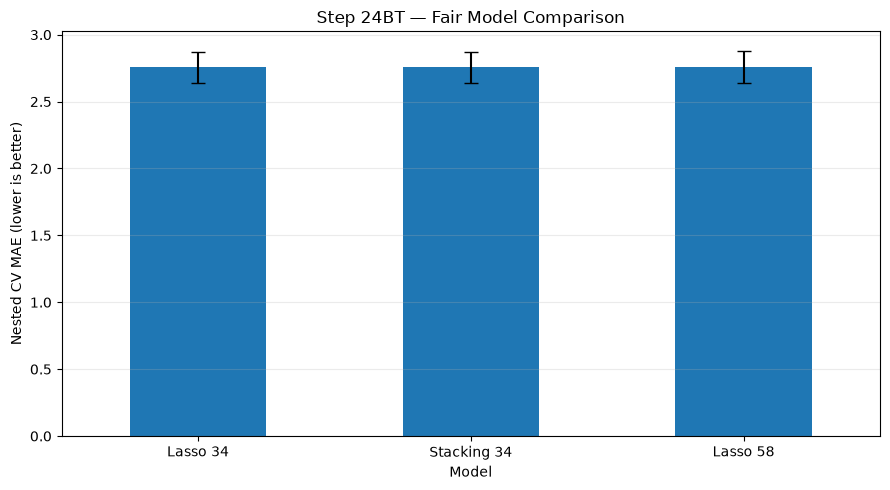


Step 24BT completed.
No existing Kaggle files were modified.


In [168]:

# ============================================================
# STEP 24BT — NESTED FEATURE SELECTION + MODEL COMPARISON
# Lasso 34 vs Lasso 58 vs Stacking
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Prepare all 58 training features
# ------------------------------------------------------------

X_24bt = X58_24bf.copy().reset_index(drop=True)
y_24bt = pd.Series(y_24bf).reset_index(drop=True)

original_cols_24bt = [
    c for c in X_24bt.columns
    if c in X44_24bf.columns
]

engineered_cols_24bt = [
    c for c in X_24bt.columns
    if c not in X44_24bf.columns
]

assert X_24bt.shape == (1129, 58)
assert len(original_cols_24bt) == 39
assert len(engineered_cols_24bt) == 19

# ------------------------------------------------------------
# 2. Define models
# ------------------------------------------------------------

lasso_24bt = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=0.025, max_iter=100000))
])

gb_24bt = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=5,
    subsample=0.85,
    random_state=42
)

stacking_24bt = StackingRegressor(
    estimators=[
        ("lasso", clone(lasso_24bt)),
        ("gb", clone(gb_24bt))
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=5,
    n_jobs=-1
)

# ------------------------------------------------------------
# 3. Outer cross-validation
# ------------------------------------------------------------

outer_cv_24bt = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_24bt = []
selected_by_fold_24bt = {}

for fold, (train_idx, val_idx) in enumerate(
    outer_cv_24bt.split(X_24bt),
    start=1
):

    print(f"\n{'=' * 60}")
    print(f"OUTER FOLD {fold}/5")
    print(f"{'=' * 60}")

    X_train = X_24bt.iloc[train_idx]
    X_val = X_24bt.iloc[val_idx]

    y_train = y_24bt.iloc[train_idx]
    y_val = y_24bt.iloc[val_idx]

    # --------------------------------------------------------
    # 4. Rank original features using INNER 3-fold CV
    # --------------------------------------------------------

    inner_cv = KFold(
        n_splits=3,
        shuffle=True,
        random_state=42 + fold
    )

    importance = {
        col: [] for col in original_cols_24bt
    }

    for inner_train_idx, inner_val_idx in inner_cv.split(X_train):

        X_inner_train = X_train.iloc[inner_train_idx]
        X_inner_val = X_train.iloc[inner_val_idx]

        y_inner_train = y_train.iloc[inner_train_idx]
        y_inner_val = y_train.iloc[inner_val_idx]

        model = clone(lasso_24bt)

        model.fit(X_inner_train, y_inner_train)

        perm = permutation_importance(
            model,
            X_inner_val,
            y_inner_val,
            scoring="neg_mean_absolute_error",
            n_repeats=3,
            random_state=42,
            n_jobs=1
        )

        for col, score in zip(
            X_24bt.columns,
            perm.importances_mean
        ):
            if col in importance:
                importance[col].append(score)

    mean_importance = {
        col: np.mean(scores)
        for col, scores in importance.items()
    }

    top15 = sorted(
        original_cols_24bt,
        key=lambda c: mean_importance[c],
        reverse=True
    )[:15]

    features34 = engineered_cols_24bt + top15

    selected_by_fold_24bt[fold] = top15

    print("Selected 15 originals:", top15)

    # --------------------------------------------------------
    # 5. Evaluate all three models on SAME outer fold
    # --------------------------------------------------------

    experiments = {
        "Lasso 34": (lasso_24bt, features34),
        "Lasso 58": (lasso_24bt, list(X_24bt.columns)),
        "Stacking 34": (stacking_24bt, features34)
    }

    for name, (model, features) in experiments.items():

        fitted = clone(model)

        fitted.fit(
            X_train[features],
            y_train
        )

        predictions = fitted.predict(
            X_val[features]
        )

        mae = mean_absolute_error(y_val, predictions)
        rmse = np.sqrt(
            mean_squared_error(y_val, predictions)
        )
        r2 = r2_score(y_val, predictions)

        results_24bt.append({
            "Fold": fold,
            "Model": name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        print(f"{name:12s} MAE={mae:.5f} "
              f"RMSE={rmse:.5f} R2={r2:.5f}")

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

fold_results_24bt = pd.DataFrame(results_24bt)

summary_24bt = (
    fold_results_24bt
    .groupby("Model")
    .agg(
        CV_MAE=("MAE", "mean"),
        CV_MAE_Std=("MAE", "std"),
        CV_RMSE=("RMSE", "mean"),
        CV_R2=("R2", "mean")
    )
    .sort_values("CV_MAE")
)

print("\n" + "=" * 75)
print("STEP 24BT — NESTED CV RESULTS")
print("=" * 75)

print(summary_24bt.round(5).to_string())

# ------------------------------------------------------------
# 7. Feature selection stability
# ------------------------------------------------------------

from collections import Counter

feature_counts_24bt = Counter(
    feature
    for selected in selected_by_fold_24bt.values()
    for feature in selected
)

stability_24bt = pd.DataFrame(
    feature_counts_24bt.items(),
    columns=["Feature", "Selected_Folds"]
).sort_values(
    ["Selected_Folds", "Feature"],
    ascending=[False, True]
)

print("\nFEATURE SELECTION STABILITY")
print(stability_24bt.to_string(index=False))

# ------------------------------------------------------------
# 8. Plot CV MAE
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

summary_24bt["CV_MAE"].plot(
    kind="bar",
    yerr=summary_24bt["CV_MAE_Std"],
    capsize=5
)

plt.ylabel("Nested CV MAE (lower is better)")
plt.title("Step 24BT — Fair Model Comparison")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("\nStep 24BT completed.")
print("No existing Kaggle files were modified.")


# Step 24BT — Nested Cross-Validation: Lasso 34 vs Lasso 58 vs Stacking

## 1. Research Objective

The objective of this experiment is to evaluate whether a compact Lasso regression model with 34 features can achieve comparable or better predictive performance than a 58-feature Lasso model and a hybrid Stacking Regressor.

The experiment addresses three research questions:

1. Can reducing the number of features from 58 to 34 maintain prediction accuracy?
2. Does combining Lasso regression and Gradient Boosting through stacking improve prediction accuracy?
3. Are the original features selected for Lasso 34 consistent across different cross-validation folds?

**Target variable:** `W` — Number of wins achieved by an MLB team.

**Machine learning task:** Supervised regression.

**Dataset:** 1,129 training records with 58 available features.

## 2. Models Evaluated

| Model | Features | Description |
|---|---:|---|
| Lasso 34 | 34 | Lasso regression using 15 selected original features and 19 engineered features |
| Lasso 58 | 58 | Lasso regression using the complete 58-feature dataset |
| Stacking 34 | 34 | Hybrid model combining Lasso regression and Gradient Boosting, with Ridge regression as the meta-model |

### Lasso Regression

Lasso is a linear regression model that uses L1 regularization to reduce overfitting and shrink less useful coefficients toward zero.

The regularization parameter used was `alpha = 0.025`.

### Gradient Boosting

Gradient Boosting combines sequentially trained decision trees to learn patterns that may not be captured by linear regression.

### Stacking Regressor

The stacking model combines predictions from two base learners:

- Base Model 1: Lasso Regression
- Base Model 2: Gradient Boosting Regressor
- Meta-Model: Ridge Regression

The Ridge meta-model learns how to combine the base models' predictions.

## 3. Experimental Methodology

### 3.1 Outer Cross-Validation

Five-fold cross-validation was applied to the 1,129 training records.

For each fold:

1. Separate the dataset into training and validation subsets.
2. Use only the outer training subset for feature selection.
3. Select the 15 most important original features using inner three-fold cross-validation and permutation importance.
4. Combine the 15 selected features with the 19 engineered features.
5. Train Lasso 34, Lasso 58 and Stacking 34.
6. Evaluate all three models on the same outer validation subset.

This approach prevents the outer validation records from directly influencing feature selection.

### 3.2 Feature Selection

Lasso 34 uses:

- 15 original features selected independently for each outer fold.
- 19 existing engineered features.

Total: **34 features**.

Feature selection was based on held-out permutation importance calculated within the outer training data.

### 3.3 Evaluation Metrics

Three evaluation metrics were used:

| Metric | Meaning | Preferred direction |
|---|---|---|
| MAE | Average absolute difference between actual and predicted wins | Lower |
| RMSE | Square root of the average squared prediction error; penalizes larger errors more strongly | Lower |
| R² | Proportion of target variation explained by the model | Higher |

## 4. Experimental Results

### 4.1 Overall Cross-Validation Performance

| Model | CV MAE ↓ | MAE Std | CV RMSE ↓ | CV R² ↑ |
|---|---:|---:|---:|---:|
| **Lasso 34** | **2.75671** | 0.11669 | **3.46345** | **0.93327** |
| Stacking 34 | 2.75690 | 0.11431 | 3.46540 | 0.93322 |
| Lasso 58 | 2.76194 | 0.11933 | 3.47119 | 0.93295 |

**Key finding:** Lasso 34 achieved the lowest average cross-validation MAE, although the differences among the three models were very small.

### 4.2 Fold-by-Fold MAE Comparison

| Fold | Lasso 34 | Lasso 58 | Stacking 34 |
|---|---:|---:|---:|
| 1 | 2.76221 | 2.76747 | **2.75128** |
| 2 | 2.62146 | 2.63670 | **2.61558** |
| 3 | 2.76180 | **2.76122** | 2.76693 |
| 4 | 2.93810 | 2.95253 | **2.93210** |
| 5 | 2.69998 | **2.69180** | 2.71860 |
| **Average** | **2.75671** | 2.76194 | 2.75690 |

Stacking 34 achieved the lowest MAE in three of the five folds, while Lasso 58 achieved the lowest MAE in two folds.

However, Lasso 34 had the lowest average MAE across all five folds.

### 4.3 Performance Differences

**Lasso 34 vs Lasso 58**

- Lasso 34 MAE: 2.75671
- Lasso 58 MAE: 2.76194
- Difference: 0.00523 wins

Lasso 34 achieved marginally better average accuracy while using 24 fewer features, equivalent to approximately **41.4% feature reduction**.

**Lasso 34 vs Stacking 34**

- Lasso 34 MAE: 2.75671
- Stacking 34 MAE: 2.75690
- Difference: 0.00019 wins

The difference is negligible. Stacking did not demonstrate a meaningful predictive advantage over Lasso 34.

## 5. Feature Selection Stability

The experiment also examined how frequently each original feature was selected across the five outer folds.

### 5.1 Features Selected in All Five Folds

| Feature | Description | Selected folds |
|---|---|---:|
| AB | At-bats | 5/5 |
| CG | Complete games | 5/5 |
| E | Fielding errors | 5/5 |
| G | Games played | 5/5 |
| IPouts | Pitching outs recorded | 5/5 |
| SHO | Shutouts | 5/5 |
| SV | Saves | 5/5 |
| decade_1910 | Historical decade indicator | 5/5 |
| decade_1930 | Historical decade indicator | 5/5 |
| decade_1940 | Historical decade indicator | 5/5 |

These ten original features were consistently selected across all five folds, indicating stability under the adopted feature-selection method.

### 5.2 Other Selected Features

| Feature | Selected folds |
|---|---:|
| era_2 | 4/5 |
| SOA | 3/5 |
| era_6 | 3/5 |
| BBA | 2/5 |
| ERA | 2/5 |
| HRA | 2/5 |
| R | 2/5 |
| mlb_rpg | 2/5 |
| 3B | 1/5 |
| HR | 1/5 |
| RA | 1/5 |
| decade_1950 | 1/5 |
| era_4 | 1/5 |

The differences in feature selection across folds suggest that some original predictors have less stable importance, potentially because of correlations with other baseball statistics.

Feature-selection frequency should not be interpreted as proof of causation.

## 6. Comparison with Kaggle Results

| Model | Local CV MAE | Kaggle Public MAE | Kaggle Private MAE |
|---|---:|---:|---:|
| Lasso 34 | 2.75671 | 2.94000 | **2.59500** |
| Lasso 58 | 2.76194 | **2.88500** | 2.60000 |
| Stacking 34 | 2.75690 | Not submitted | Not submitted |

Lasso 34 achieved a Kaggle Private MAE of 2.595, marginally outperforming Lasso 58, which achieved 2.600.

However, Lasso 58 performed better on the Kaggle Public subset.

These results suggest that Lasso 34 is a competitive compact model, but they do not establish that it will outperform Lasso 58 on every unseen dataset.

The local cross-validation results and Kaggle scores are based on different evaluation samples and should not be compared as if they were identical tests.

## 7. Discussion

### Finding 1 — Feature Reduction Preserved Predictive Performance

Reducing the number of predictors from 58 to 34 did not result in a meaningful loss of predictive accuracy.

The compact model achieved slightly better average MAE and R² than the full-feature model.

This supports the use of feature selection to reduce model complexity while maintaining competitive performance.

### Finding 2 — Stacking Did Not Produce a Meaningful Improvement

Although stacking combined a linear model with a nonlinear model, it did not substantially improve predictive accuracy.

The average MAE difference between Stacking 34 and Lasso 34 was only 0.00019 wins.

This indicates that the additional model complexity was not justified by the observed improvement in this experiment.

### Finding 3 — Several Features Were Consistently Selected

Ten original features appeared in all five outer folds.

These included pitching, batting, fielding, games-played and historical-decade variables.

Their consistent selection suggests that these features provide useful predictive information within the current modeling approach.

### Finding 4 — Model Simplicity Is an Advantage

Lasso 34 uses fewer predictors and has a simpler structure than the stacking ensemble.

Its advantages include:

- Easier interpretation of model coefficients.
- Fewer input features.
- Lower model complexity.
- Comparable predictive accuracy.
- Simpler deployment and maintenance.

## 8. Limitations

Several limitations should be acknowledged:

1. The dataset contains historical baseball records, so relationships may differ across seasons and eras.
2. Random cross-validation may not fully represent performance when predicting future baseball seasons.
3. Correlated baseball statistics can affect permutation-importance rankings.
4. Small MAE differences do not establish statistically significant superiority.
5. The stacking model used fixed selected features within its internal cross-validation. A fully nested stacking pipeline would repeat feature selection inside those folds.
6. The 19 engineered features were predetermined, rather than independently selected in each fold.

## 9. Conclusion

The Step 24BT experiment found that the **34-feature Lasso regression model achieved the lowest mean cross-validation MAE of 2.75671**, compared with 2.75690 for Stacking 34 and 2.76194 for Lasso 58.

The results demonstrate that reducing the feature count from 58 to 34 maintained competitive predictive performance. Furthermore, ten original features were consistently selected across all five outer folds.

Although the stacking ensemble performed similarly, it did not provide a meaningful improvement over Lasso 34.

**Therefore, Lasso 34 is recommended as the preferred compact regression model for the current MLB wins prediction task**, while Lasso 58 and Stacking 34 should be retained as comparison benchmarks.

## 10. Recommended Next Experiment — Step 24BU

Conduct detailed prediction-error analysis to identify where Lasso 34 performs poorly.

Suggested investigations:

1. Compare prediction errors for weak, average and strong teams.
2. Analyze model errors across historical decades.
3. Identify teams with the largest absolute prediction errors.
4. Examine whether prediction errors show systematic underprediction or overprediction.
5. Assess whether any observed error patterns suggest opportunities for improved feature engineering.

The purpose is to understand model limitations before introducing additional complexity.

Processing fold 1/5...
Processing fold 2/5...
Processing fold 3/5...
Processing fold 4/5...
Processing fold 5/5...

STEP 24BU — OVERALL OUT-OF-FOLD RESULTS
OOF MAE: 2.75676
OOF RMSE: 3.46599
OOF R2: 0.93353

ERROR ANALYSIS BY TEAM STRENGTH
                 Teams  Mean_Actual  Mean_Predicted     MAE  Mean_Residual
Team_Group                                                                
Weak (<=60)        105      53.4857         55.4635  3.4066        -1.9778
Middle (61-100)    974      80.9066         80.7837  2.6687         0.1228
Strong (>100)       50     104.0600        102.1974  3.1068         1.8626

ERROR ANALYSIS BY DECADE
               Teams     MAE  Mean_Residual
Decade                                     
decade_1910      110  3.5262        -0.0857
decade_1930       70  3.2941         0.0415
decade_1940       73  3.2484         0.1397
decade_1970      134  2.8775         0.0602
decade_1950       82  2.8169         0.2455
decade_1960       97  2.7256        -0.1024
decade_

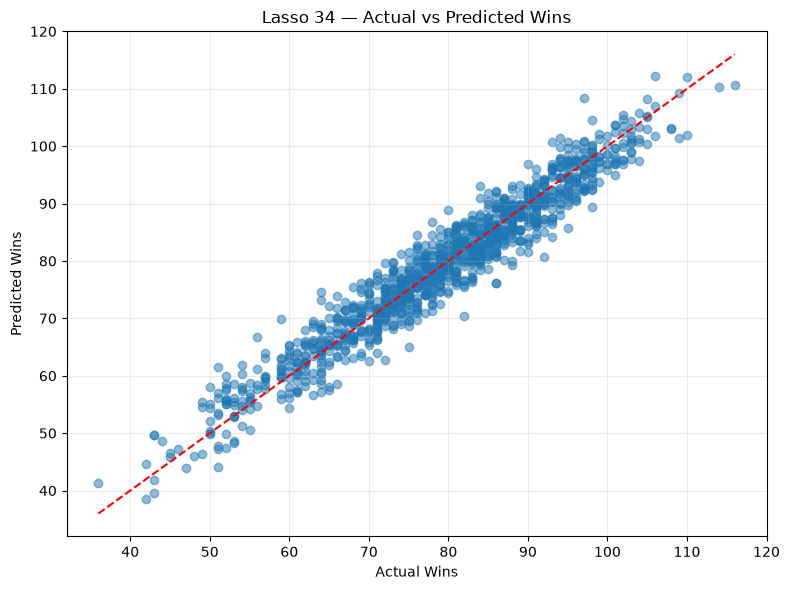

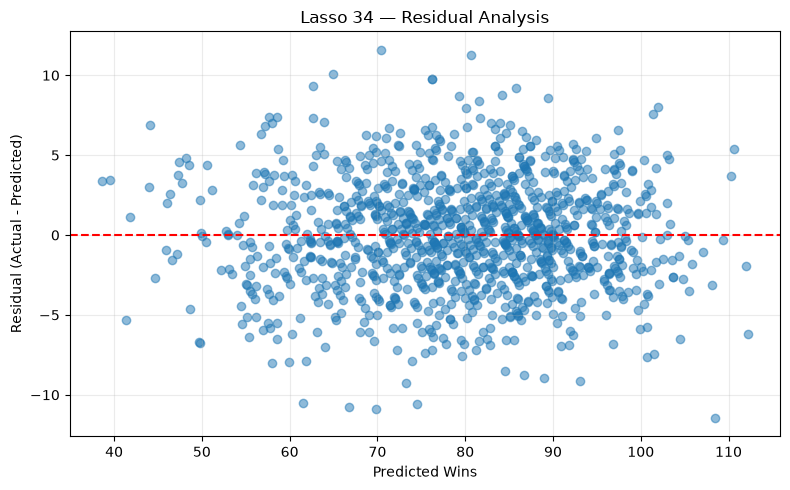

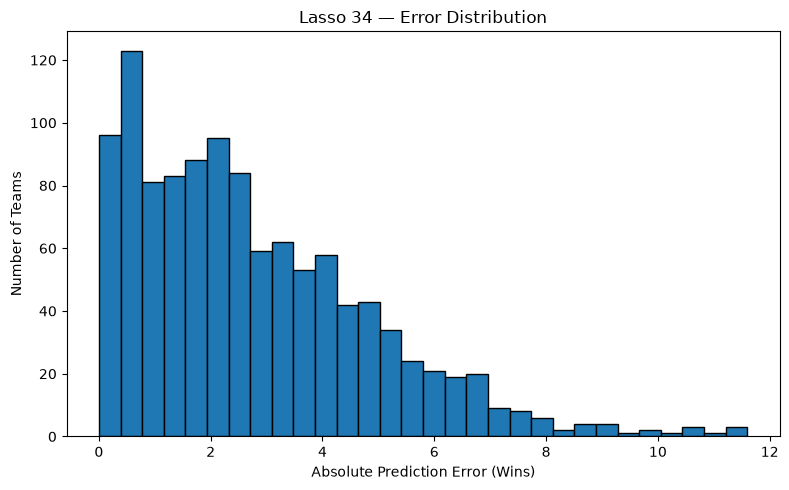


Step 24BU completed.
Existing models and Kaggle submissions unchanged.


In [169]:

# ============================================================
# STEP 24BU — LASSO 34 ERROR ANALYSIS
# Out-of-fold predictions with training-only feature selection
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Prepare training data
# ------------------------------------------------------------

X_24bu = X58_24bf.copy().reset_index(drop=True)
y_24bu = pd.Series(y_24bf).reset_index(drop=True)

original_cols_24bu = [
    c for c in X_24bu.columns
    if c in X44_24bf.columns
]

engineered_cols_24bu = [
    c for c in X_24bu.columns
    if c not in X44_24bf.columns
]

assert X_24bu.shape == (1129, 58)
assert len(original_cols_24bu) == 39
assert len(engineered_cols_24bu) == 19

# ------------------------------------------------------------
# 2. Generate out-of-fold predictions
# ------------------------------------------------------------

cv_24bu = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_predictions_24bu = np.full(len(X_24bu), np.nan)
selected_features_24bu = {}

for fold, (train_idx, val_idx) in enumerate(
    cv_24bu.split(X_24bu),
    start=1
):
    print(f"Processing fold {fold}/5...")

    X_train = X_24bu.iloc[train_idx]
    X_val = X_24bu.iloc[val_idx]
    y_train = y_24bu.iloc[train_idx]

    # Feature selection within training fold only
    inner_cv = KFold(
        n_splits=3,
        shuffle=True,
        random_state=42 + fold
    )

    importance = {c: [] for c in original_cols_24bu}

    for inner_tr, inner_val in inner_cv.split(X_train):
        fitted = clone(lasso_24bt)

        fitted.fit(
            X_train.iloc[inner_tr],
            y_train.iloc[inner_tr]
        )

        perm = permutation_importance(
            fitted,
            X_train.iloc[inner_val],
            y_train.iloc[inner_val],
            scoring="neg_mean_absolute_error",
            n_repeats=3,
            random_state=42,
            n_jobs=1
        )

        for col, score in zip(
            X_24bu.columns,
            perm.importances_mean
        ):
            if col in importance:
                importance[col].append(score)

    top15 = sorted(
        original_cols_24bu,
        key=lambda c: np.mean(importance[c]),
        reverse=True
    )[:15]

    features34 = engineered_cols_24bu + top15
    selected_features_24bu[fold] = top15

    model = clone(lasso_24bt)
    model.fit(X_train[features34], y_train)

    oof_predictions_24bu[val_idx] = model.predict(
        X_val[features34]
    )

assert not np.isnan(oof_predictions_24bu).any()

# ------------------------------------------------------------
# 3. Build error analysis dataset
# ------------------------------------------------------------

errors_24bu = pd.DataFrame({
    "Actual_Wins": y_24bu,
    "Predicted_Wins": oof_predictions_24bu
})

errors_24bu["Residual"] = (
    errors_24bu["Actual_Wins"]
    - errors_24bu["Predicted_Wins"]
)

errors_24bu["Absolute_Error"] = (
    errors_24bu["Residual"].abs()
)

errors_24bu["Team_Group"] = pd.cut(
    errors_24bu["Actual_Wins"],
    bins=[-np.inf, 60, 100, np.inf],
    labels=[
        "Weak (<=60)",
        "Middle (61-100)",
        "Strong (>100)"
    ]
)

# Add historical decade indicators if present
decade_cols_24bu = [
    c for c in X_24bu.columns
    if c.startswith("decade_")
]

if decade_cols_24bu:
    decade_flags = X_24bu[decade_cols_24bu].fillna(0)

    active_decade = decade_flags.idxmax(axis=1)
    has_decade = decade_flags.max(axis=1) > 0

    errors_24bu["Decade"] = active_decade.where(
        has_decade,
        "Other/Unknown"
    )

# ------------------------------------------------------------
# 4. Overall metrics
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 24BU — OVERALL OUT-OF-FOLD RESULTS")
print("=" * 65)

print(
    "OOF MAE:",
    round(mean_absolute_error(
        errors_24bu["Actual_Wins"],
        errors_24bu["Predicted_Wins"]
    ), 5)
)

print(
    "OOF RMSE:",
    round(np.sqrt(mean_squared_error(
        errors_24bu["Actual_Wins"],
        errors_24bu["Predicted_Wins"]
    )), 5)
)

print(
    "OOF R2:",
    round(r2_score(
        errors_24bu["Actual_Wins"],
        errors_24bu["Predicted_Wins"]
    ), 5)
)

# ------------------------------------------------------------
# 5. Error analysis by team strength
# ------------------------------------------------------------

team_group_results_24bu = (
    errors_24bu
    .groupby("Team_Group", observed=True)
    .agg(
        Teams=("Actual_Wins", "count"),
        Mean_Actual=("Actual_Wins", "mean"),
        Mean_Predicted=("Predicted_Wins", "mean"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
)

print("\nERROR ANALYSIS BY TEAM STRENGTH")
print(team_group_results_24bu.round(4).to_string())

# ------------------------------------------------------------
# 6. Error analysis by decade
# ------------------------------------------------------------

if "Decade" in errors_24bu.columns:

    decade_results_24bu = (
        errors_24bu
        .groupby("Decade")
        .agg(
            Teams=("Actual_Wins", "count"),
            MAE=("Absolute_Error", "mean"),
            Mean_Residual=("Residual", "mean")
        )
        .sort_values("MAE", ascending=False)
    )

    print("\nERROR ANALYSIS BY DECADE")
    print(decade_results_24bu.round(4).to_string())

# ------------------------------------------------------------
# 7. Largest prediction errors
# ------------------------------------------------------------

print("\nTOP 15 LARGEST ABSOLUTE ERRORS")

largest_errors_24bu = errors_24bu.nlargest(
    15, "Absolute_Error"
)

print(largest_errors_24bu.round(3).to_string())

# ------------------------------------------------------------
# 8. Actual vs predicted wins
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    errors_24bu["Actual_Wins"],
    errors_24bu["Predicted_Wins"],
    alpha=0.5
)

low = min(
    errors_24bu["Actual_Wins"].min(),
    errors_24bu["Predicted_Wins"].min()
)

high = max(
    errors_24bu["Actual_Wins"].max(),
    errors_24bu["Predicted_Wins"].max()
)

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual Wins")
plt.ylabel("Predicted Wins")
plt.title("Lasso 34 — Actual vs Predicted Wins")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Residual plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    errors_24bu["Predicted_Wins"],
    errors_24bu["Residual"],
    alpha=0.5
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Wins")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Lasso 34 — Residual Analysis")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Absolute error distribution
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    errors_24bu["Absolute_Error"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Absolute Prediction Error (Wins)")
plt.ylabel("Number of Teams")
plt.title("Lasso 34 — Error Distribution")
plt.tight_layout()
plt.show()

print("\nStep 24BU completed.")
print("Existing models and Kaggle submissions unchanged.")


# Step 24BU — Lasso 34 Prediction Error Analysis

## 1. Research Objective

The objective of Step 24BU is to evaluate the prediction errors of the 34-feature Lasso regression model and identify situations where the model performs less accurately.

The analysis investigates:

1. Overall prediction accuracy.
2. Prediction errors among weak, middle-performing and strong MLB teams.
3. Differences in prediction accuracy across historical decades.
4. Teams with the largest absolute prediction errors.
5. Potential systematic prediction bias.

**Target variable:** `W` — Total MLB team wins.

**Dataset:** 1,129 training records.

**Model:** Lasso Regression with 34 features, comprising 15 selected original features and 19 engineered features.

## 2. Methodology

### 2.1 Out-of-Fold Predictions

Five-fold cross-validation was used to generate out-of-fold (OOF) predictions.

For each fold:

1. Split the dataset into training and validation subsets.
2. Select the 15 most important original features using inner three-fold cross-validation on the training subset only.
3. Combine these with the 19 engineered features.
4. Train Lasso regression using the selected 34 features.
5. Predict the wins of teams in the held-out validation subset.

This ensures that each team's prediction comes from a model that was not trained using that team's actual win total.

### 2.2 Error Measurements

The following measurements were calculated:

**Residual**

Residual = Actual Wins − Predicted Wins

- Positive residual: The model underpredicts wins.
- Negative residual: The model overpredicts wins.
- Zero residual: Perfect prediction.

**Absolute Error**

Absolute Error = |Actual Wins − Predicted Wins|

The absolute error measures the size of the prediction error without considering its direction.

## 3. Overall Model Performance

| Metric | Result |
|---|---:|
| Out-of-Fold MAE | **2.75676** |
| Out-of-Fold RMSE | 3.46599 |
| Out-of-Fold R² | 0.93353 |

### Interpretation

The Lasso 34 model achieved an out-of-fold MAE of approximately **2.76 wins**.

This means the model's predictions differed from actual team wins by approximately 2.76 wins on average.

The RMSE of 3.46599 indicates that some larger prediction errors occurred.

The R² of 0.93353 indicates that the out-of-fold predictions explained approximately 93.35% of the observed variation in team wins.

Overall, the results demonstrate strong predictive performance.

## 4. Error Analysis by Team Strength

Teams were divided into three categories based on their actual win totals.

| Team Category | Number of Teams | Mean Actual Wins | Mean Predicted Wins | MAE | Mean Residual |
|---|---:|---:|---:|---:|---:|
| Weak (≤60 wins) | 105 | 53.4857 | 55.4635 | 3.4066 | -1.9778 |
| Middle (61–100 wins) | 974 | 80.9066 | 80.7837 | **2.6687** | +0.1228 |
| Strong (>100 wins) | 50 | 104.0600 | 102.1974 | 3.1068 | +1.8626 |

### Finding 1 — Weak Teams

Weak teams had the highest MAE of **3.4066 wins**.

Their average actual wins were 53.49, while their average predicted wins were 55.46.

The negative mean residual of -1.9778 indicates that the model overpredicted weak teams by approximately 1.98 wins on average.

### Finding 2 — Middle-Performing Teams

Middle-performing teams had the lowest MAE of **2.6687 wins**.

The mean residual of +0.1228 indicates very little average directional bias within this group.

### Finding 3 — Strong Teams

Strong teams had an MAE of **3.1068 wins**.

Their average actual wins were 104.06, compared with average predicted wins of 102.20.

The positive mean residual of +1.8626 indicates that the model underpredicted strong teams by approximately 1.86 wins on average.

### Interpretation

The results show that prediction errors were larger among teams with extreme actual win totals.

This pattern is consistent with regression toward the mean, where predictions tend to be less extreme than actual outcomes.

However, because the categories were defined using actual wins, some of the observed pattern may arise from the grouping method itself.

Therefore, these results are descriptive and do not establish a correctable model bias.

## 5. Error Analysis by Historical Decade

| Decade | Number of Teams | MAE | Mean Residual |
|---|---:|---:|---:|
| 1910s | 110 | **3.5262** | -0.0857 |
| 1930s | 70 | 3.2941 | +0.0415 |
| 1940s | 73 | 3.2484 | +0.1397 |
| 1970s | 134 | 2.8775 | +0.0602 |
| 1950s | 82 | 2.8169 | +0.2455 |
| 1960s | 97 | 2.7256 | -0.1024 |
| 1920s | 82 | 2.7161 | +0.0139 |
| Other/Unknown | 115 | 2.5250 | -0.0846 |
| 2010s | 100 | 2.4224 | -0.0326 |
| 2000s | 153 | 2.3391 | +0.2338 |
| 1990s | 113 | **2.3240** | -0.3608 |

### Finding 4 — Higher Errors in Earlier Decades

The highest prediction errors occurred in:

- 1910s: MAE = 3.5262
- 1930s: MAE = 3.2941
- 1940s: MAE = 3.2484

By comparison, the 1990s and 2000s had lower MAEs of 2.3240 and 2.3391, respectively.

This suggests that some earlier historical periods are more difficult for the model to predict accurately.

Potential explanations include differences in baseball playing styles, statistical relationships and historical conditions. These explanations remain hypotheses rather than confirmed causes.

The `Other/Unknown` category contains 115 records whose decade indicators did not identify a listed decade. These records require further verification.

## 6. Largest Prediction Errors

The five largest absolute errors were:

| Row Index | Actual Wins | Predicted Wins | Residual | Absolute Error | Decade |
|---|---:|---:|---:|---:|---|
| 727 | 82 | 70.403 | +11.597 | **11.597** | 1910s |
| 948 | 97 | 108.457 | -11.457 | 11.457 | 1940s |
| 517 | 92 | 80.710 | +11.290 | 11.290 | 1920s |
| 819 | 59 | 69.887 | -10.887 | 10.887 | 1990s |
| 287 | 56 | 66.755 | -10.755 | 10.755 | 1930s |

### Finding 5 — Individual Large Errors

Although the overall MAE was approximately 2.76 wins, several individual predictions differed from actual results by more than 10 wins.

For example, row 727 had 82 actual wins but only 70.403 predicted wins.

This produced an absolute prediction error of 11.597 wins.

These observations suggest that certain teams may have statistical characteristics that are not fully captured by the current linear model.

Further analysis of their original baseball statistics is needed before identifying the causes.

## 7. Discussion

The experiment produced three important findings.

**First, Lasso 34 demonstrated strong overall predictive performance.**

The model achieved an out-of-fold MAE of 2.75676 and R² of 0.93353.

**Second, prediction accuracy varied across team-strength categories.**

Weak and strong teams had higher average absolute errors than middle-performing teams.

**Third, prediction accuracy varied across historical decades.**

The 1910s, 1930s and 1940s showed relatively high errors, while the 1990s and 2000s showed lower errors.

These findings identify areas for further investigation but do not establish that more complex algorithms would necessarily improve accuracy.

## 8. Limitations

1. Team-strength categories were based on actual wins, which are unavailable for future predictions.
2. Grouping by actual wins may exaggerate apparent overprediction and underprediction at the extremes.
3. The decade analysis depends on the accuracy of the historical indicator columns.
4. Some prediction errors may reflect variation that cannot be explained by the available baseball statistics.
5. The analysis identifies associations and error patterns, not causal relationships.
6. Random cross-validation does not necessarily represent the challenge of predicting future baseball seasons.

## 9. Conclusion

Step 24BU demonstrated that the 34-feature Lasso regression model achieved strong out-of-fold predictive performance, with an MAE of 2.75676, RMSE of 3.46599 and R² of 0.93353.

However, the model showed larger prediction errors among teams with extreme actual win totals and in several earlier historical decades.

The findings suggest that future improvements should focus on understanding the characteristics of difficult-to-predict teams rather than immediately increasing model complexity.

**Lasso 34 remains the preferred compact model**, while further diagnostic analysis is recommended to investigate prediction bias and large individual errors.

## 10. Next Experiment — Step 24BV

**Title:** Prediction Bias and Outlier Investigation

**Objectives:**

1. Group teams by predicted wins rather than actual wins.
2. Evaluate residual patterns across predicted-win categories.
3. Examine the original baseball statistics of the largest-error teams.
4. Investigate whether large errors are associated with particular statistical characteristics.
5. Identify evidence-based opportunities for further model improvement.

This experiment will use the existing `errors_24bu` DataFrame and preserve all previous models and Kaggle submission files.

STEP 24BV — PREDICTION BIAS AND OUTLIER ANALYSIS
Total teams: 1129
Feature columns: 58
Mean absolute error: 2.75676

1. ERROR BY PREDICTED TEAM STRENGTH
                           Teams  Mean_Actual  Mean_Predicted     MAE  Mean_Residual
Predicted_Group                                                                     
Predicted Weak (<=60)         96      53.7812         54.0759  3.2804        -0.2946
Predicted Middle (61-100)    985      80.7350         80.6690  2.6830         0.0660
Predicted Strong (>100)       48     102.8125        103.4712  3.2222        -0.6587

2. OVERALL PREDICTION BIAS
Mean residual: 0.00452
Overpredicted teams: 575
Underpredicted teams: 554
Direction: Slight overall underprediction

3. LARGE PREDICTION ERRORS
Fixed threshold: > 8.0 wins
95th percentile threshold: 6.7018
Teams with error > 8: 23
Percentage with error > 8: 2.04%

Top 15 largest errors:


,Actual_Wins,Predicted_Wins,Residual,Absolute_Error,Predicted_Group
727,82,70.403,11.597,11.597,Predicted Middle (61-100)
948,97,108.457,-11.457,11.457,Predicted Strong (>100)
517,92,80.710,11.290,11.290,Predicted Middle (61-100)
819,59,69.887,-10.887,10.887,Predicted Middle (61-100)
287,56,66.755,-10.755,10.755,Predicted Middle (61-100)
232,64,74.557,-10.557,10.557,Predicted Middle (61-100)
872,51,61.500,-10.500,10.500,Predicted Middle (61-100)
1023,75,64.930,10.070,10.070,Predicted Middle (61-100)
1099,86,76.208,9.792,9.792,Predicted Middle (61-100)
627,86,76.215,9.785,9.785,Predicted Middle (61-100)



4. TOP 15 OUTLIERS WITH BASEBALL STATISTICS


,Actual_Wins,Predicted_Wins,Absolute_Error,G,R,RA,AB,H,HR,BB,SO,SB,E,ERA,CG,SHO,SV,IPouts,BBA,SOA,HRA
727,82,70.403,11.597,154,531,567,5083,1271,26,359,652.0,159,221,3.03,66,16,10,4176,421,502,29
948,97,108.457,11.457,156,840,568,5446,1534,155,646,575.0,54,114,3.22,66,26,30,4227,628,595,82
517,92,80.710,11.290,154,717,675,5339,1534,72,447,357.0,34,196,3.64,97,10,5,4128,403,638,58
819,59,69.887,10.887,162,672,744,5448,1350,158,448,879.0,79,156,4.05,16,8,22,4314,434,867,139
287,56,66.755,10.755,155,612,707,5230,1329,73,437,586.0,53,208,3.94,64,10,18,4074,533,581,38
232,64,74.557,10.557,162,663,700,5456,1366,111,569,929.0,152,142,3.90,17,9,30,4350,570,924,138
872,51,61.500,10.500,157,464,595,5169,1230,9,399,580.0,150,251,3.01,84,17,6,4251,432,509,14
1023,75,64.930,10.070,155,454,533,5165,1249,78,358,850.0,57,114,3.06,57,18,16,4131,620,1000,90
1099,86,76.208,9.792,152,736,702,5327,1507,114,411,494.0,79,198,3.94,80,6,8,4062,408,446,73
627,86,76.215,9.785,154,701,711,5421,1543,48,358,385.0,71,185,3.75,71,12,12,4131,338,377,86



5. STATISTICS ASSOCIATED WITH LARGE ERRORS


,Feature,Mean_Large_Error,Mean_Other_Teams,Std_Mean_Difference,Abs_Std_Difference
6,BB,464.4783,515.8481,-0.6070,0.6070
17,HRA,89.3478,119.3400,-0.5775,0.5775
13,SV,20.7826,28.5669,-0.5480,0.5480
11,CG,57.8261,40.4593,0.5457,0.5457
12,SHO,12.7826,10.2495,0.5403,0.5403
0,G,157.3043,159.1347,-0.4964,0.4964
16,SOA,703.1739,827.0506,-0.4899,0.4899
7,SO,723.5217,838.5615,-0.4614,0.4614
10,ERA,3.5935,3.8873,-0.4309,0.4309
2,RA,658.5217,700.5642,-0.4055,0.4055


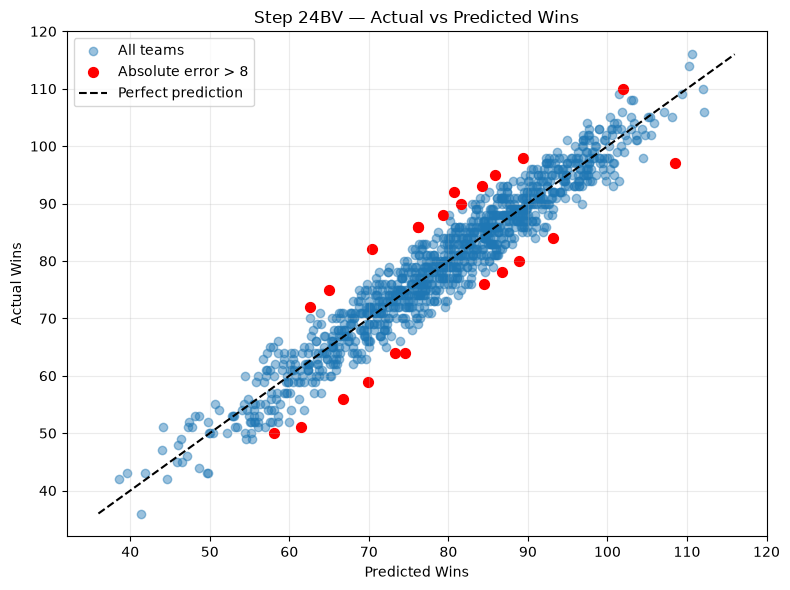

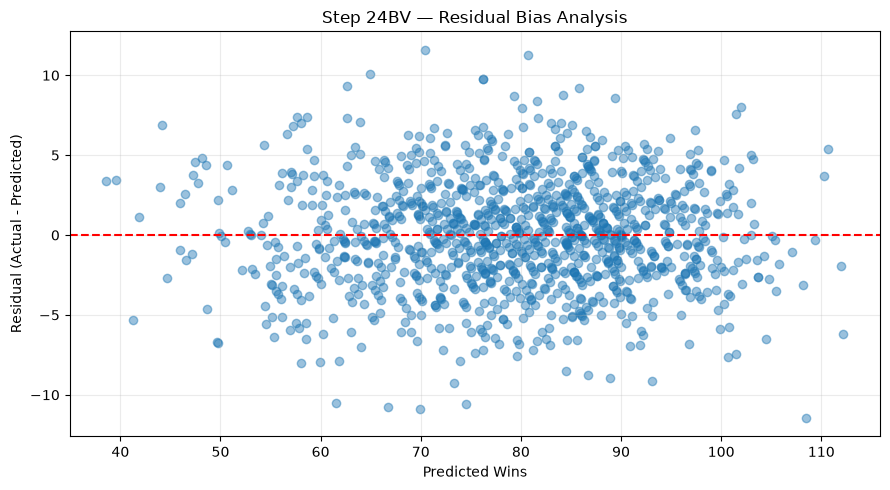

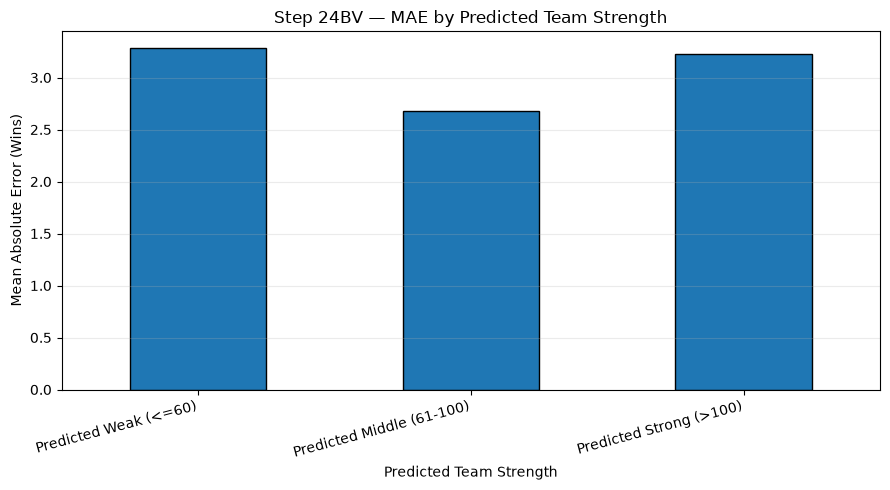

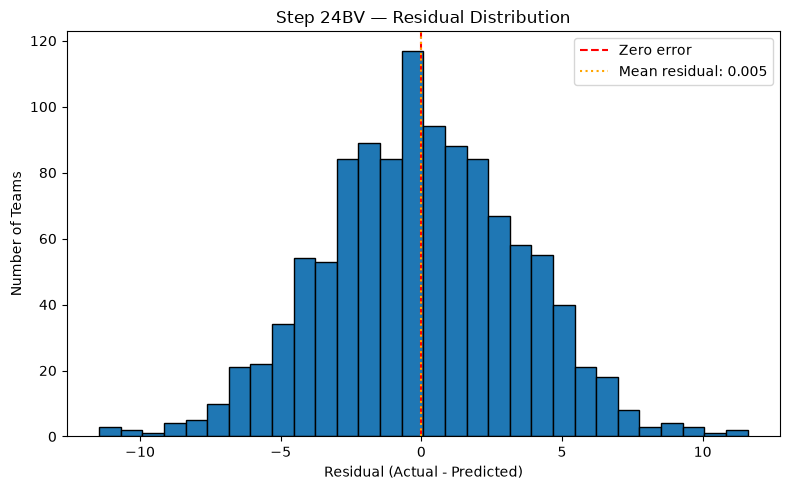


STEP 24BV — FINAL SUMMARY
Total teams: 1129
Overall MAE: 2.75676
Overall mean residual: 0.00452
Teams with error > 8: 23
95th percentile absolute error: 6.70176

Analysis completed.
No model retraining performed.
Existing Kaggle submissions remain unchanged.


In [170]:

# ============================================================
# STEP 24BV — PREDICTION BIAS AND OUTLIER INVESTIGATION
# Lasso 34 | MLB Team Wins Prediction
#
# Reuses Step 24BU out-of-fold predictions.
# Does NOT retrain models or modify Kaggle submissions.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load existing Step 24BU results
# ------------------------------------------------------------

required_cols_24bv = [
    "Actual_Wins",
    "Predicted_Wins",
    "Residual",
    "Absolute_Error"
]

assert "errors_24bu" in globals(), (
    "Please run Step 24BU first."
)

assert all(
    col in errors_24bu.columns
    for col in required_cols_24bv
), "Step 24BU error columns are missing."

errors_24bv = errors_24bu.copy().reset_index(drop=True)

X_24bv = X58_24bf.copy().reset_index(drop=True)

assert len(errors_24bv) == len(X_24bv), (
    "Training features and prediction results do not align."
)

assert np.allclose(
    errors_24bv["Residual"],
    errors_24bv["Actual_Wins"]
    - errors_24bv["Predicted_Wins"]
)

assert np.allclose(
    errors_24bv["Absolute_Error"],
    errors_24bv["Residual"].abs()
)

print("=" * 65)
print("STEP 24BV — PREDICTION BIAS AND OUTLIER ANALYSIS")
print("=" * 65)

print("Total teams:", len(errors_24bv))
print("Feature columns:", X_24bv.shape[1])
print("Mean absolute error:",
      round(errors_24bv["Absolute_Error"].mean(), 5))


# ------------------------------------------------------------
# 2. Group teams by PREDICTED wins
# ------------------------------------------------------------
# Unlike actual wins, predicted wins are available
# when making predictions for unseen teams.

errors_24bv["Predicted_Group"] = pd.cut(
    errors_24bv["Predicted_Wins"],
    bins=[-np.inf, 60, 100, np.inf],
    labels=[
        "Predicted Weak (<=60)",
        "Predicted Middle (61-100)",
        "Predicted Strong (>100)"
    ],
    include_lowest=True
)

predicted_group_results_24bv = (
    errors_24bv
    .groupby("Predicted_Group", observed=True)
    .agg(
        Teams=("Actual_Wins", "count"),
        Mean_Actual=("Actual_Wins", "mean"),
        Mean_Predicted=("Predicted_Wins", "mean"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
)

print("\n1. ERROR BY PREDICTED TEAM STRENGTH")
print(predicted_group_results_24bv.round(4).to_string())


# ------------------------------------------------------------
# 3. Overall directional bias
# ------------------------------------------------------------

overall_bias_24bv = errors_24bv["Residual"].mean()

overpredicted_24bv = (
    errors_24bv["Residual"] < 0
).sum()

underpredicted_24bv = (
    errors_24bv["Residual"] > 0
).sum()

print("\n2. OVERALL PREDICTION BIAS")
print(f"Mean residual: {overall_bias_24bv:.5f}")
print(f"Overpredicted teams: {overpredicted_24bv}")
print(f"Underpredicted teams: {underpredicted_24bv}")

if overall_bias_24bv > 0:
    print("Direction: Slight overall underprediction")
elif overall_bias_24bv < 0:
    print("Direction: Slight overall overprediction")
else:
    print("Direction: No overall mean bias")


# ------------------------------------------------------------
# 4. Identify large prediction errors
# ------------------------------------------------------------
# We use both:
# A. Fixed threshold: absolute error > 8 wins
# B. Data-driven threshold: 95th percentile

threshold_fixed_24bv = 8.0

threshold_p95_24bv = errors_24bv[
    "Absolute_Error"
].quantile(0.95)

errors_24bv["Large_Error_8"] = (
    errors_24bv["Absolute_Error"] > threshold_fixed_24bv
)

errors_24bv["Large_Error_P95"] = (
    errors_24bv["Absolute_Error"] >= threshold_p95_24bv
)

large_errors_24bv = (
    errors_24bv[errors_24bv["Large_Error_8"]]
    .sort_values("Absolute_Error", ascending=False)
    .copy()
)

print("\n3. LARGE PREDICTION ERRORS")
print(f"Fixed threshold: > {threshold_fixed_24bv} wins")
print(f"95th percentile threshold: {threshold_p95_24bv:.4f}")
print(f"Teams with error > 8: {len(large_errors_24bv)}")
print(
    "Percentage with error > 8:",
    f"{100 * len(large_errors_24bv) / len(errors_24bv):.2f}%"
)

print("\nTop 15 largest errors:")

display(
    errors_24bv.nlargest(
        15, "Absolute_Error"
    )[
        [
            "Actual_Wins",
            "Predicted_Wins",
            "Residual",
            "Absolute_Error",
            "Predicted_Group"
        ]
    ].round(3)
)


# ------------------------------------------------------------
# 5. Inspect original baseball statistics
# ------------------------------------------------------------
# Use only the original columns that are present
# in the model's feature DataFrame.

original_cols_24bv = [
    col for col in X_24bv.columns
    if col in X44_24bf.columns
]

baseball_stats_24bv = [
    "G", "R", "RA", "AB", "H", "HR",
    "BB", "SO", "SB", "E", "ERA",
    "CG", "SHO", "SV", "IPouts",
    "BBA", "SOA", "HRA"
]

available_stats_24bv = [
    col for col in baseball_stats_24bv
    if col in original_cols_24bv
]

outlier_details_24bv = pd.concat(
    [
        errors_24bv,
        X_24bv[available_stats_24bv]
    ],
    axis=1
)

top15_outliers_24bv = (
    outlier_details_24bv
    .nlargest(15, "Absolute_Error")
    .copy()
)

print("\n4. TOP 15 OUTLIERS WITH BASEBALL STATISTICS")

display(
    top15_outliers_24bv[
        [
            "Actual_Wins",
            "Predicted_Wins",
            "Absolute_Error"
        ] + available_stats_24bv
    ].round(3)
)


# ------------------------------------------------------------
# 6. Compare statistics of large-error vs other teams
# ------------------------------------------------------------
# Standardized mean difference is used to compare
# statistics measured in different units.
#
# This is descriptive, not proof of causation.

comparison_rows_24bv = []

large_mask_24bv = errors_24bv["Large_Error_8"]

for col in available_stats_24bv:

    values = pd.to_numeric(
        X_24bv[col],
        errors="coerce"
    )

    mean_large = values[large_mask_24bv].mean()
    mean_other = values[~large_mask_24bv].mean()

    overall_std = values.std()

    if pd.notna(overall_std) and overall_std > 0:
        standardized_difference = (
            (mean_large - mean_other) / overall_std
        )
    else:
        standardized_difference = np.nan

    comparison_rows_24bv.append({
        "Feature": col,
        "Mean_Large_Error": mean_large,
        "Mean_Other_Teams": mean_other,
        "Std_Mean_Difference": standardized_difference
    })

stats_comparison_24bv = pd.DataFrame(
    comparison_rows_24bv
)

stats_comparison_24bv["Abs_Std_Difference"] = (
    stats_comparison_24bv[
        "Std_Mean_Difference"
    ].abs()
)

stats_comparison_24bv = (
    stats_comparison_24bv
    .sort_values(
        "Abs_Std_Difference",
        ascending=False
    )
)

print("\n5. STATISTICS ASSOCIATED WITH LARGE ERRORS")

display(
    stats_comparison_24bv.head(15).round(4)
)


# ------------------------------------------------------------
# 7. Visualization — predicted vs actual wins
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    errors_24bv["Predicted_Wins"],
    errors_24bv["Actual_Wins"],
    alpha=0.45,
    label="All teams"
)

plt.scatter(
    large_errors_24bv["Predicted_Wins"],
    large_errors_24bv["Actual_Wins"],
    color="red",
    s=50,
    label="Absolute error > 8"
)

minimum_24bv = min(
    errors_24bv["Actual_Wins"].min(),
    errors_24bv["Predicted_Wins"].min()
)

maximum_24bv = max(
    errors_24bv["Actual_Wins"].max(),
    errors_24bv["Predicted_Wins"].max()
)

plt.plot(
    [minimum_24bv, maximum_24bv],
    [minimum_24bv, maximum_24bv],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Predicted Wins")
plt.ylabel("Actual Wins")
plt.title("Step 24BV — Actual vs Predicted Wins")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Visualization — residuals vs predicted wins
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.scatter(
    errors_24bv["Predicted_Wins"],
    errors_24bv["Residual"],
    alpha=0.45
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Wins")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Step 24BV — Residual Bias Analysis")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Visualization — MAE by predicted team strength
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

predicted_group_results_24bv["MAE"].plot(
    kind="bar",
    edgecolor="black"
)

plt.ylabel("Mean Absolute Error (Wins)")
plt.xlabel("Predicted Team Strength")
plt.title("Step 24BV — MAE by Predicted Team Strength")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Visualization — residual distribution
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    errors_24bv["Residual"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero error"
)

plt.axvline(
    overall_bias_24bv,
    color="orange",
    linestyle=":",
    label=f"Mean residual: {overall_bias_24bv:.3f}"
)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Number of Teams")
plt.title("Step 24BV — Residual Distribution")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 24BV — FINAL SUMMARY")
print("=" * 65)

print(f"Total teams: {len(errors_24bv)}")
print(f"Overall MAE: {errors_24bv['Absolute_Error'].mean():.5f}")
print(f"Overall mean residual: {overall_bias_24bv:.5f}")
print(f"Teams with error > 8: {len(large_errors_24bv)}")
print(f"95th percentile absolute error: {threshold_p95_24bv:.5f}")

print("\nAnalysis completed.")
print("No model retraining performed.")
print("Existing Kaggle submissions remain unchanged.")


STEP 24BW — K-MEANS CLUSTERING
Total MLB teams: 1129
Available features: 58

Clustering features:
['R', 'RA', 'HR', 'SB', 'E', 'ERA', 'SV', 'CG', 'SHO', 'SOA', 'BBA', 'HRA']

Missing values by feature:
R      0
RA     0
HR     0
SB     0
E      0
ERA    0
SV     0
CG     0
SHO    0
SOA    0
BBA    0
HRA    0
dtype: int64

Scaled feature matrix:
(1129, 12)

1. CLUSTER SELECTION RESULTS
 K  Silhouette_Score    Inertia
 2           0.30419 9195.69288
 3           0.24492 7672.40975
 4           0.21857 6464.65620
 5           0.18474 5920.32582
 6           0.18801 5473.77602
 7           0.18304 5122.09384
 8           0.17616 4890.73935

Best K: 2
Best silhouette score: 0.30419


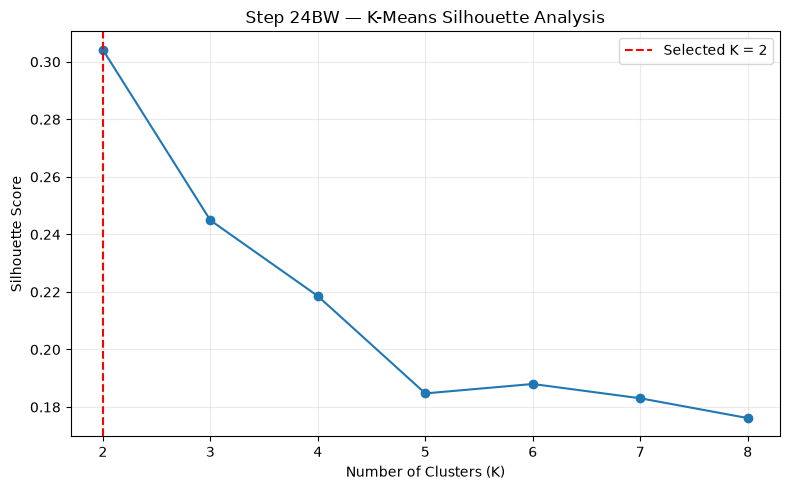


2. CLUSTER SIZES
Cluster
0    390
1    739

3. CLUSTER CHARACTERISTICS


,R,RA,HR,SB,E,ERA,SV,CG,SHO,SOA,BBA,HRA
Cluster,,,,,,,,,,,,
0,661.02,648.24,63.60,109.77,196.82,3.45,14.41,75.02,12.43,588.46,474.47,62.49
1,722.28,726.87,148.85,92.54,123.78,4.11,35.79,22.76,9.18,949.11,539.23,148.41



4. STANDARDIZED CLUSTER CHARACTERISTICS


,R,RA,HR,SB,E,ERA,SV,CG,SHO,SOA,BBA,HRA
Cluster,,,,,,,,,,,,
0,-0.385,-0.497,-0.995,0.218,0.902,-0.634,-0.986,1.075,0.453,-0.934,-0.526,-1.083
1,0.203,0.262,0.525,-0.115,-0.476,0.335,0.520,-0.567,-0.239,0.493,0.278,0.572



5. LASSO 34 ERRORS BY CLUSTER


,Teams,Mean_Actual_Wins,Mean_Predicted_Wins,MAE,Mean_Residual
Cluster,,,,,
0,390,78.3128,78.2684,3.0985,0.0444
1,739,79.9459,79.9624,2.5764,-0.0165



6. LARGE PREDICTION ERRORS BY CLUSTER


,Teams,Large_Error_Teams,Large_Error_Rate
Cluster,,,
0,390,13,3.333
1,739,10,1.353



Total teams with errors > 8: 23


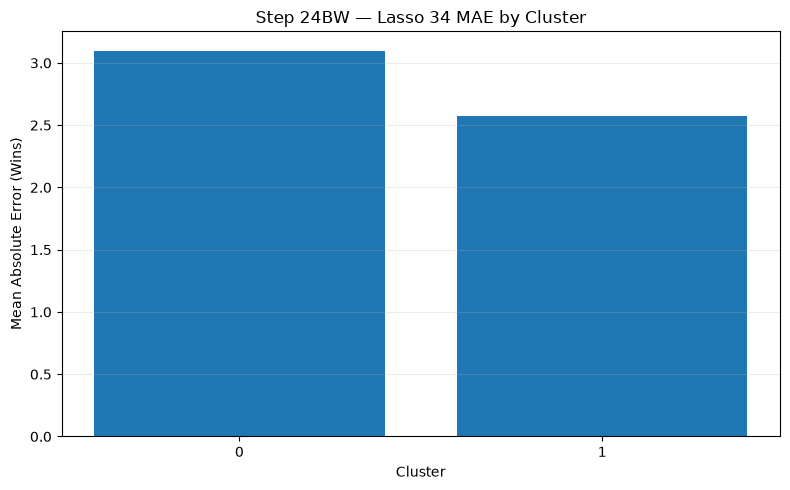

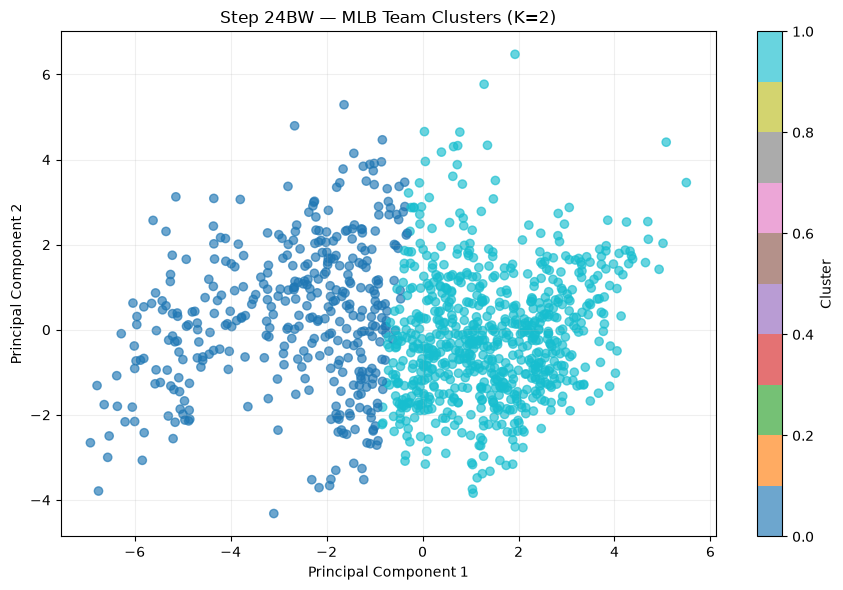


PCA explained variance: [0.4836 0.2091]

STEP 24BW — FINAL SUMMARY
Total teams: 1129
Clustering features: 12
Selected K: 2
Silhouette score: 0.30419
Overall Lasso 34 MAE: 2.75676
Large-error teams (>8 wins): 23

Step 24BW completed successfully.
No Lasso model retraining performed.
No Kaggle submissions modified.


In [171]:
# ============================================================
# STEP 24BW — UNSUPERVISED K-MEANS CLUSTERING
# MLB Team Wins Prediction Project
#
# Objective:
# 1. Discover groups of similar MLB teams.
# 2. Find a suitable number of clusters.
# 3. Interpret cluster characteristics.
# 4. Compare Lasso 34 prediction errors across clusters.
#
# No model retraining.
# No Kaggle submission changes.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# ------------------------------------------------------------
# 1. Load existing notebook data
# ------------------------------------------------------------

assert "X58_24bf" in globals(), (
    "Please run the earlier data preparation cells first."
)

assert "errors_24bu" in globals(), (
    "Please run Step 24BU first."
)

X_24bw = X58_24bf.copy().reset_index(drop=True)
errors_24bw = errors_24bu.copy().reset_index(drop=True)

assert len(X_24bw) == len(errors_24bw), (
    "Feature rows and error rows do not match."
)

assert len(X_24bw) == 1129

print("=" * 65)
print("STEP 24BW — K-MEANS CLUSTERING")
print("=" * 65)

print("Total MLB teams:", len(X_24bw))
print("Available features:", X_24bw.shape[1])

# ------------------------------------------------------------
# 2. Select baseball statistics for clustering
# ------------------------------------------------------------
# We use interpretable baseball statistics.
#
# Exclude:
# - W (target)
# - Predicted wins
# - Residuals
# - Absolute errors
#
# We also avoid directly using Pythagorean expected wins,
# because it is closely related to the target.

candidate_features_24bw = [
    "R",       # Runs scored
    "RA",      # Runs allowed
    "HR",      # Home runs
    "SB",      # Stolen bases
    "E",       # Errors
    "ERA",     # Earned run average
    "SV",      # Saves
    "CG",      # Complete games
    "SHO",     # Shutouts
    "SOA",     # Strikeouts allowed by pitchers
    "BBA",     # Walks allowed by pitchers
    "HRA"      # Home runs allowed
]

cluster_features_24bw = [
    col for col in candidate_features_24bw
    if col in X_24bw.columns
]

print("\nClustering features:")
print(cluster_features_24bw)

assert len(cluster_features_24bw) >= 5, (
    "Too few baseball features available for clustering."
)

assert "W" not in cluster_features_24bw

X_cluster_24bw = X_24bw[
    cluster_features_24bw
].copy()

# Check missing and infinite values

X_cluster_24bw = X_cluster_24bw.replace(
    [np.inf, -np.inf],
    np.nan
)

print("\nMissing values by feature:")
print(X_cluster_24bw.isna().sum())

# Median imputation for clustering only.
# This does not modify the original dataset.

from sklearn.impute import SimpleImputer

imputer_24bw = SimpleImputer(strategy="median")

X_imputed_24bw = imputer_24bw.fit_transform(
    X_cluster_24bw
)

# ------------------------------------------------------------
# 3. Standardize features
# ------------------------------------------------------------

scaler_24bw = StandardScaler()

X_scaled_24bw = scaler_24bw.fit_transform(
    X_imputed_24bw
)

print("\nScaled feature matrix:")
print(X_scaled_24bw.shape)

# ------------------------------------------------------------
# 4. Test K = 2 to 8
# ------------------------------------------------------------

k_results_24bw = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(
        X_scaled_24bw
    )

    silhouette = silhouette_score(
        X_scaled_24bw,
        labels
    )

    k_results_24bw.append({
        "K": k,
        "Silhouette_Score": silhouette,
        "Inertia": model.inertia_
    })

k_results_24bw = pd.DataFrame(
    k_results_24bw
)

print("\n" + "=" * 65)
print("1. CLUSTER SELECTION RESULTS")
print("=" * 65)

print(k_results_24bw.round(5).to_string(index=False))

# ------------------------------------------------------------
# 5. Select best K using silhouette score
# ------------------------------------------------------------

best_k_24bw = int(
    k_results_24bw.loc[
        k_results_24bw["Silhouette_Score"].idxmax(),
        "K"
    ]
)

print("\nBest K:", best_k_24bw)

print(
    "Best silhouette score:",
    round(
        k_results_24bw["Silhouette_Score"].max(),
        5
    )
)

# ------------------------------------------------------------
# 6. Plot silhouette scores
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    k_results_24bw["K"],
    k_results_24bw["Silhouette_Score"],
    marker="o"
)

plt.axvline(
    best_k_24bw,
    color="red",
    linestyle="--",
    label=f"Selected K = {best_k_24bw}"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Step 24BW — K-Means Silhouette Analysis")

plt.xticks(range(2, 9))
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Fit final K-Means model
# ------------------------------------------------------------

kmeans_24bw = KMeans(
    n_clusters=best_k_24bw,
    random_state=42,
    n_init=20
)

cluster_labels_24bw = kmeans_24bw.fit_predict(
    X_scaled_24bw
)

cluster_results_24bw = X_cluster_24bw.copy()

cluster_results_24bw["Cluster"] = (
    cluster_labels_24bw
)

print("\n" + "=" * 65)
print("2. CLUSTER SIZES")
print("=" * 65)

cluster_sizes_24bw = (
    cluster_results_24bw["Cluster"]
    .value_counts()
    .sort_index()
)

print(cluster_sizes_24bw.to_string())

# ------------------------------------------------------------
# 8. Interpret cluster characteristics
# ------------------------------------------------------------

cluster_profile_24bw = (
    cluster_results_24bw
    .groupby("Cluster")
    [cluster_features_24bw]
    .mean()
)

print("\n" + "=" * 65)
print("3. CLUSTER CHARACTERISTICS")
print("=" * 65)

display(cluster_profile_24bw.round(2))

# Compare each cluster against overall averages
# using standardized feature differences.

scaled_df_24bw = pd.DataFrame(
    X_scaled_24bw,
    columns=cluster_features_24bw
)

scaled_df_24bw["Cluster"] = (
    cluster_labels_24bw
)

cluster_standardized_profile_24bw = (
    scaled_df_24bw
    .groupby("Cluster")
    [cluster_features_24bw]
    .mean()
)

print("\n4. STANDARDIZED CLUSTER CHARACTERISTICS")

display(
    cluster_standardized_profile_24bw.round(3)
)

# ------------------------------------------------------------
# 9. Add Lasso 34 prediction errors
# ------------------------------------------------------------

cluster_error_data_24bw = errors_24bw.copy()

cluster_error_data_24bw["Cluster"] = (
    cluster_labels_24bw
)

cluster_error_summary_24bw = (
    cluster_error_data_24bw
    .groupby("Cluster")
    .agg(
        Teams=("Actual_Wins", "count"),
        Mean_Actual_Wins=("Actual_Wins", "mean"),
        Mean_Predicted_Wins=("Predicted_Wins", "mean"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
)

print("\n" + "=" * 65)
print("5. LASSO 34 ERRORS BY CLUSTER")
print("=" * 65)

display(
    cluster_error_summary_24bw.round(4)
)

# ------------------------------------------------------------
# 10. Investigate the 23 large-error teams
# ------------------------------------------------------------

cluster_error_data_24bw["Large_Error"] = (
    cluster_error_data_24bw["Absolute_Error"] > 8
)

large_error_summary_24bw = (
    cluster_error_data_24bw
    .groupby("Cluster")
    .agg(
        Teams=("Actual_Wins", "count"),
        Large_Error_Teams=("Large_Error", "sum")
    )
)

large_error_summary_24bw["Large_Error_Rate"] = (
    100
    * large_error_summary_24bw["Large_Error_Teams"]
    / large_error_summary_24bw["Teams"]
)

print("\n" + "=" * 65)
print("6. LARGE PREDICTION ERRORS BY CLUSTER")
print("=" * 65)

display(
    large_error_summary_24bw.round(3)
)

print(
    "\nTotal teams with errors > 8:",
    int(
        large_error_summary_24bw[
            "Large_Error_Teams"
        ].sum()
    )
)

# ------------------------------------------------------------
# 11. Plot MAE by cluster
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    cluster_error_summary_24bw.index.astype(str),
    cluster_error_summary_24bw["MAE"]
)

plt.xlabel("Cluster")
plt.ylabel("Mean Absolute Error (Wins)")
plt.title("Step 24BW — Lasso 34 MAE by Cluster")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. PCA visualization
# ------------------------------------------------------------
# PCA is used only to visualize clusters in 2D.
# Clustering itself uses all selected features.

pca_24bw = PCA(
    n_components=2,
    random_state=42
)

X_pca_24bw = pca_24bw.fit_transform(
    X_scaled_24bw
)

plt.figure(figsize=(9, 6))

scatter_24bw = plt.scatter(
    X_pca_24bw[:, 0],
    X_pca_24bw[:, 1],
    c=cluster_labels_24bw,
    cmap="tab10",
    alpha=0.65
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    f"Step 24BW — MLB Team Clusters (K={best_k_24bw})"
)

plt.colorbar(
    scatter_24bw,
    label="Cluster"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "\nPCA explained variance:",
    np.round(
        pca_24bw.explained_variance_ratio_,
        4
    )
)

# ------------------------------------------------------------
# 13. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 24BW — FINAL SUMMARY")
print("=" * 65)

print("Total teams:", len(X_cluster_24bw))
print("Clustering features:", len(cluster_features_24bw))
print("Selected K:", best_k_24bw)

print(
    "Silhouette score:",
    round(
        k_results_24bw["Silhouette_Score"].max(),
        5
    )
)

print(
    "Overall Lasso 34 MAE:",
    round(
        cluster_error_data_24bw[
            "Absolute_Error"
        ].mean(),
        5
    )
)

print(
    "Large-error teams (>8 wins):",
    int(
        cluster_error_data_24bw[
            "Large_Error"
        ].sum()
    )
)

print("\nStep 24BW completed successfully.")
print("No Lasso model retraining performed.")
print("No Kaggle submissions modified.")

In [172]:

print("STEP 24BW — LARGE ERRORS BY CLUSTER")
display(large_error_summary_24bw.round(3))

print("\nSTEP 24BW — DECADE DISTRIBUTION (%)")
display(
    pd.crosstab(
        cluster_error_data_24bw["Decade"],
        cluster_error_data_24bw["Cluster"],
        normalize="index"
    ).mul(100).round(1)
)


STEP 24BW — LARGE ERRORS BY CLUSTER


,Teams,Large_Error_Teams,Large_Error_Rate
Cluster,,,
0,390,13,3.333
1,739,10,1.353



STEP 24BW — DECADE DISTRIBUTION (%)


Cluster,0,1
Decade,,
Other/Unknown,5.2,94.8
decade_1910,100.0,0.0
decade_1920,96.3,3.7
decade_1930,78.6,21.4
decade_1940,84.9,15.1
decade_1950,23.2,76.8
decade_1960,22.7,77.3
decade_1970,26.9,73.1
decade_1990,0.9,99.1



# Step 24BW — K-Means Clustering Analysis of MLB Teams

## 1. Objective

The objective of this experiment is to identify groups of MLB teams with similar statistical characteristics using unsupervised K-Means clustering.

We also investigate whether the existing Lasso 34 regression model produces different prediction errors across the identified clusters.

This is an exploratory analysis. Clustering is not yet incorporated into the prediction model.

## 2. Methodology

- Dataset: 1,129 MLB team observations
- Algorithm: K-Means clustering
- Clustering features: 12 baseball statistics
- Features: R, RA, HR, SB, E, ERA, SV, CG, SHO, SOA, BBA, HRA
- Preprocessing: StandardScaler
- Cluster selection: Silhouette score for K = 2 to 8
- Selected number of clusters: K = 2
- Random state: 42

The features were standardized before clustering to prevent variables with larger numerical scales from dominating the distance calculations.

## 3. Optimal Number of Clusters

The highest silhouette score was obtained at K = 2.

| K | Silhouette Score |
|---|---:|
| 2 | 0.30419 |
| 3 | 0.24492 |
| 4 | 0.21857 |
| 5 | 0.18474 |
| 6 | 0.18801 |
| 7 | 0.18304 |
| 8 | 0.17616 |

K = 2 was selected because it achieved the highest silhouette score among the tested values.

The score of 0.30419 suggests some cluster separation, although the groups are not sharply separated.

## 4. Cluster Characteristics

K-Means identified two distinct statistical profiles.

### Cluster 0 — Earlier-Era Baseball Profile

- 390 teams
- Fewer home runs and saves
- More complete games and recorded errors
- Fewer pitching strikeouts
- Predominantly associated with earlier historical decades

### Cluster 1 — Later-Era Baseball Profile

- 739 teams
- More home runs and saves
- Fewer complete games and recorded errors
- More pitching strikeouts
- Predominantly associated with later historical decades

The clusters appear to reflect historical changes in baseball playing styles and statistical patterns.

## 5. Historical Decade Analysis

The decade distribution provides strong evidence of an association between cluster membership and historical era.

| Decade | Cluster 0 (%) | Cluster 1 (%) |
|---|---:|---:|
| 1910s | 100.0 | 0.0 |
| 1920s | 96.3 | 3.7 |
| 1930s | 78.6 | 21.4 |
| 1940s | 84.9 | 15.1 |
| 1950s | 23.2 | 76.8 |
| 1960s | 22.7 | 77.3 |
| 1970s | 26.9 | 73.1 |
| 1990s | 0.9 | 99.1 |
| 2000s | 0.0 | 100.0 |
| 2010s | 0.0 | 100.0 |
| Other/Unknown | 5.2 | 94.8 |

Earlier decades are concentrated in Cluster 0, while later decades are concentrated in Cluster 1.

This suggests that the clustering algorithm has identified historical-era differences rather than simply separating high-performing and low-performing teams.

## 6. Lasso 34 Prediction Errors by Cluster

Out-of-fold predictions from the existing Lasso 34 model were examined by cluster.

| Metric | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Teams | 390 | 739 |
| Mean Actual Wins | 78.3128 | 79.9459 |
| Mean Predicted Wins | 78.2684 | 79.9624 |
| MAE | 3.0985 | 2.5764 |
| Mean Residual | +0.0444 | -0.0165 |

Cluster 0 has an MAE approximately 0.5221 wins higher than Cluster 1.

This represents approximately 20.3% higher MAE relative to Cluster 1.

Both clusters have mean residuals close to zero, indicating little average directional prediction bias.

However, Cluster 0 has larger absolute prediction errors.

## 7. Large Prediction Error Analysis

A large prediction error is defined as an absolute error greater than 8 wins.

| Metric | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Teams | 390 | 739 |
| Large-Error Teams | 13 | 10 |
| Large-Error Rate | 3.333% | 1.353% |

Cluster 0 accounts for approximately 34.5% of the dataset but 56.5% of the 23 large-error observations.

Its large-error rate is approximately 2.46 times that of Cluster 1.

This suggests that the Lasso 34 model has greater difficulty predicting some teams with earlier-era statistical characteristics.

## 8. Interpretation and Limitations

The results show that prediction accuracy varies across the identified clusters.

However, cluster membership is strongly associated with historical decades.

Therefore, the observed differences in prediction accuracy may reflect historical-era effects rather than independent clustering effects.

Additionally, the existing Lasso 34 model already includes engineered and historical features. Cluster membership may provide redundant information.

The clustering analysis is descriptive and does not demonstrate that adding K-Means will improve prediction accuracy.

## 9. Conclusion

K-Means successfully identified two broad statistical profiles among MLB teams.

The earlier-era cluster exhibited higher prediction errors and a greater frequency of large errors than the later-era cluster.

These findings motivate a further experiment to determine whether cluster membership can provide additional predictive information to Lasso regression.

## 10. Next Experiment — Step 24BX

Evaluate three regression approaches:

1. Baseline Lasso 34
2. Lasso 34 with K-Means cluster membership
3. Lasso 34 with cluster interaction features

All preprocessing, clustering and feature selection must be performed within the training folds.

The models will be compared using the same cross-validation splits, primarily using MAE.

The hybrid approach will be considered beneficial only if it demonstrates improved out-of-fold predictive performance.


In [173]:

# ============================================================
# STEP 24BX — HYBRID K-MEANS + LASSO 34
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.cluster import KMeans
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------
# 1. Prepare the dataset
# ------------------------------------------------------------

X_all_24bx = X58_24bf.reset_index(drop=True).copy()
X_original_24bx = X44_24bf.reset_index(drop=True).copy()
y_24bx = pd.Series(y_24bf).reset_index(drop=True)

cluster_features_24bx = [
    "R", "RA", "HR", "SB", "E", "ERA",
    "SV", "CG", "SHO", "SOA", "BBA", "HRA"
]

# Identify the 19 engineered features from X58
engineered_features_24bx = [
    c for c in X_all_24bx.columns
    if c not in X_original_24bx.columns
]

print("Engineered features found:",
      len(engineered_features_24bx))
print(engineered_features_24bx)

# Safety checks: stop rather than silently using
# a different set of 34 predictors.
assert len(engineered_features_24bx) == 19, (
    "Expected 19 engineered features. "
    "Check the X58 and X44 column lists."
)

assert X_all_24bx.columns.is_unique
assert X_original_24bx.columns.is_unique
assert len(X_all_24bx) == len(X_original_24bx) == len(y_24bx)
assert set(cluster_features_24bx).issubset(X_all_24bx.columns)
assert y_24bx.notna().all()

# ------------------------------------------------------------
# 2. Set up cross-validation
# ------------------------------------------------------------

cv_24bx = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models_24bx = [
    "Lasso34",
    "Lasso34_KMeans",
    "Lasso34_KMeans_Interactions"
]

results_24bx = []
oof_24bx = {
    model: np.full(len(y_24bx), np.nan)
    for model in models_24bx
}

# ------------------------------------------------------------
# 3. Run the experiment
# ------------------------------------------------------------

for fold_24bx, (train_idx, val_idx) in enumerate(
    cv_24bx.split(X_all_24bx), start=1
):

    print(f"\nRunning Fold {fold_24bx}/5")

    y_train = y_24bx.iloc[train_idx]
    y_val = y_24bx.iloc[val_idx]

    # A. Select 15 ORIGINAL features on training data only
    original_cols = [
        c for c in X_original_24bx.columns
        if c in X_all_24bx.columns
    ]

    orig_train = X_all_24bx.iloc[train_idx][original_cols]
    orig_val = X_all_24bx.iloc[val_idx][original_cols]

    original_imputer = SimpleImputer(strategy="median")
    orig_train_imp = original_imputer.fit_transform(orig_train)
    orig_val_imp = original_imputer.transform(orig_val)

    selector = SelectKBest(
        score_func=f_regression,
        k=15
    )

    selector.fit(orig_train_imp, y_train)

    selected_original = list(
        np.array(original_cols)[selector.get_support()]
    )

    selected_features = (
        selected_original + engineered_features_24bx
    )

    assert len(selected_features) == 34
    assert len(set(selected_features)) == 34

    # B. Prepare the 34 Lasso features
    feature_imputer = SimpleImputer(strategy="median")

    X_train_34 = feature_imputer.fit_transform(
        X_all_24bx.iloc[train_idx][selected_features]
    )
    X_val_34 = feature_imputer.transform(
        X_all_24bx.iloc[val_idx][selected_features]
    )

    feature_scaler = StandardScaler()

    X_train_scaled = feature_scaler.fit_transform(X_train_34)
    X_val_scaled = feature_scaler.transform(X_val_34)

    # C. Fit K-Means on training data only
    cluster_imputer = SimpleImputer(strategy="median")

    cluster_train = cluster_imputer.fit_transform(
        X_all_24bx.iloc[train_idx][cluster_features_24bx]
    )
    cluster_val = cluster_imputer.transform(
        X_all_24bx.iloc[val_idx][cluster_features_24bx]
    )

    cluster_scaler = StandardScaler()

    cluster_train_scaled = cluster_scaler.fit_transform(
        cluster_train
    )
    cluster_val_scaled = cluster_scaler.transform(
        cluster_val
    )

    kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=20
    )

    train_clusters = kmeans.fit_predict(
        cluster_train_scaled
    )
    val_clusters = kmeans.predict(
        cluster_val_scaled
    )

    # K-Means cluster numbers are arbitrary.
    # For K=2, a binary indicator is sufficient.
    train_cluster_feature = train_clusters.reshape(-1, 1)
    val_cluster_feature = val_clusters.reshape(-1, 1)

    # D. Construct three model inputs

    # Model A: Baseline
    XA_train = X_train_scaled
    XA_val = X_val_scaled

    # Model B: Add cluster membership
    XB_train = np.column_stack([
        X_train_scaled,
        train_cluster_feature
    ])
    XB_val = np.column_stack([
        X_val_scaled,
        val_cluster_feature
    ])

    # Model C: Add interactions between cluster and features
    XC_train = np.column_stack([
        X_train_scaled,
        train_cluster_feature,
        X_train_scaled * train_cluster_feature
    ])
    XC_val = np.column_stack([
        X_val_scaled,
        val_cluster_feature,
        X_val_scaled * val_cluster_feature
    ])

    inputs = {
        "Lasso34": (XA_train, XA_val),
        "Lasso34_KMeans": (XB_train, XB_val),
        "Lasso34_KMeans_Interactions": (
            XC_train, XC_val
        )
    }

    # E. Train and evaluate each model
    for model_name, (Xtr, Xva) in inputs.items():

        # Inner CV tunes alpha using training data only
        model = LassoCV(
            cv=5,
            random_state=42,
            max_iter=30000,
            n_jobs=-1
        )

        model.fit(Xtr, y_train)
        predictions = model.predict(Xva)

        oof_24bx[model_name][val_idx] = predictions

        results_24bx.append({
            "Fold": fold_24bx,
            "Model": model_name,
            "MAE": mean_absolute_error(
                y_val, predictions
            ),
            "RMSE": np.sqrt(
                mean_squared_error(y_val, predictions)
            ),
            "R2": r2_score(y_val, predictions),
            "Alpha": model.alpha_
        })

# ------------------------------------------------------------
# 4. Summarize results
# ------------------------------------------------------------

results_df_24bx = pd.DataFrame(results_24bx)

summary_24bx = (
    results_df_24bx
    .groupby("Model")
    .agg(
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_R2=("R2", "mean")
    )
    .sort_values("Mean_MAE")
)

print("\nSTEP 24BX — CROSS-VALIDATION RESULTS")
display(summary_24bx.round(5))

# ------------------------------------------------------------
# 5. Overall out-of-fold metrics
# ------------------------------------------------------------

oof_summary_24bx = []

for model_name in models_24bx:

    pred = oof_24bx[model_name]

    assert np.isfinite(pred).all()

    oof_summary_24bx.append({
        "Model": model_name,
        "OOF_MAE": mean_absolute_error(y_24bx, pred),
        "OOF_RMSE": np.sqrt(
            mean_squared_error(y_24bx, pred)
        ),
        "OOF_R2": r2_score(y_24bx, pred)
    })

oof_summary_df_24bx = (
    pd.DataFrame(oof_summary_24bx)
    .sort_values("OOF_MAE")
)

print("\nSTEP 24BX — OVERALL OOF RESULTS")
display(oof_summary_df_24bx.round(5))

print("\nExisting models and submissions were not modified.")


Engineered features found: 19
['R_per_game', 'RA_per_game', 'Pythagorean_Expected_Wins', 'Batting_Average', 'Isolated_Power', 'WHIP_Proxy', 'BB_Rate_Proxy', 'Pitching_K_BB_Ratio', 'Pythagenpat_Expected_Wins', 'Signed_Squared_Run_Margin', 'RunDiff_over_TotalRuns', 'Early_x_RunMargin', 'Middle_x_RunMargin', 'Early_x_PythagenpatRate', 'Middle_x_PythagenpatRate', 'Early_x_ERA', 'Middle_x_ERA', 'Early_x_WalkRate', 'Middle_x_WalkRate']

Running Fold 1/5

Running Fold 2/5

Running Fold 3/5

Running Fold 4/5

Running Fold 5/5

STEP 24BX — CROSS-VALIDATION RESULTS


,Mean_MAE,Std_MAE,Mean_RMSE,Mean_R2
Model,,,,
Lasso34_KMeans_Interactions,2.86257,0.11554,3.60860,0.92751
Lasso34,2.88069,0.11433,3.61096,0.92738
Lasso34_KMeans,2.88347,0.11357,3.61869,0.92708



STEP 24BX — OVERALL OOF RESULTS


,Model,OOF_MAE,OOF_RMSE,OOF_R2
2,Lasso34_KMeans_Interactions,2.86261,3.61084,0.92786
0,Lasso34,2.88076,3.61343,0.92776
1,Lasso34_KMeans,2.88354,3.62092,0.92746



Existing models and submissions were not modified.


In [174]:

# =====================================================
# STEP 24BY — INSPECT ORIGINAL LASSO 34 SETTINGS
# =====================================================

import pandas as pd

print("STEP 24BY — EXISTING LASSO VARIABLES\n")

keywords_24by = [
    "lasso", "alpha", "feature", "selected",
    "24bt", "24bu", "24bf"
]

matching_names_24by = [
    name for name in globals()
    if any(word in name.lower() for word in keywords_24by)
    and not name.startswith("_")
]

for name in sorted(matching_names_24by):
    obj = globals()[name]

    if isinstance(obj, pd.DataFrame):
        print(f"{name}: DataFrame {obj.shape}")

    elif isinstance(obj, pd.Series):
        print(f"{name}: Series {obj.shape}")

    elif isinstance(obj, (list, tuple)):
        print(f"{name}: {type(obj).__name__}, "
              f"length={len(obj)}")

    elif isinstance(obj, (int, float, str)):
        print(f"{name}: {obj}")

    else:
        print(f"{name}: {type(obj).__name__}")


STEP 24BY — EXISTING LASSO VARIABLES

ALPHA_24N: 0.0075
ALPHA_24R: 0.0075
Lasso: ABCMeta
LassoCV: ABCMeta
X44_24bf: DataFrame (1129, 44)
X58_24bf: DataFrame (1129, 58)
X_24bt: DataFrame (1129, 58)
X_24bu: DataFrame (1129, 58)
X_lasso: DataFrame (1412, 47)
X_lasso_predict: DataFrame (400, 47)
X_lasso_predict_scaled: DataFrame (400, 47)
X_lasso_test: DataFrame (283, 47)
X_lasso_test_scaled: DataFrame (283, 47)
X_lasso_train: DataFrame (1129, 47)
X_lasso_train_scaled: DataFrame (1129, 47)
X_replace_24bf: DataFrame (1129, 52)
add_step17_features: function
all_era_features: list, length=8
all_new_features: list, length=16
alpha: 100
alpha_grid_48: dict
alpha_grid_56: dict
alpha_grid_61: dict
alpha_pct: 4.717539086689999e-05
alpha_results_44: DataFrame (6, 9)
alpha_results_56: DataFrame (6, 3)
alpha_values: list, length=12
alphas: list, length=6
alphas_24i: dict
alphas_24q: dict
alphas_24u: list, length=10
alphas_24v: list, length=11
alphas_24w: list, length=7
available_features: list, lengt

In [175]:

# ======================================================
# STEP 24BY — INSPECT ORIGINAL LASSO 34 CONFIGURATION
# ======================================================

import inspect
from sklearn.pipeline import Pipeline

print("1. ORIGINAL CV SETTINGS")
print(cv_24bu)

print("\n2. SELECTED FEATURES BY FOLD")
for fold, cols in selected_features_24bu.items():
    print(f"Fold {fold}: {len(cols)} features")
    print(cols)

print("\n3. ORIGINAL LASSO PIPELINE")
print(lasso34_24bs)

print("\n4. PIPELINE PARAMETERS")
for name, value in lasso34_24bs.get_params().items():
    if name.endswith("alpha") or name.endswith("max_iter"):
        print(name, "=", value)

print("\n5. FEATURE SELECTION FUNCTION")
print(inspect.getsource(rank_original_features_24bn))

print("\n6. ORIGINAL FEATURE COUNTS")
print("Original candidate features:", len(original_cols_24bu))
print("Engineered features:", len(engineered_cols_24bu))

print("\n7. ORIGINAL OOF PREDICTIONS")
print("Prediction count:", len(oof_predictions_24bu))


1. ORIGINAL CV SETTINGS
KFold(n_splits=5, random_state=42, shuffle=True)

2. SELECTED FEATURES BY FOLD
Fold 1: 15 features
['SV', 'IPouts', 'CG', 'AB', 'G', 'decade_1940', 'SHO', 'E', 'R', 'era_2', 'decade_1930', 'SOA', 'era_6', 'decade_1910', 'decade_1950']
Fold 2: 15 features
['SV', 'IPouts', 'CG', 'AB', 'G', 'SHO', 'decade_1940', 'E', 'BBA', 'decade_1930', 'era_2', 'era_6', 'decade_1910', 'mlb_rpg', 'ERA']
Fold 3: 15 features
['SV', 'IPouts', 'CG', 'AB', 'decade_1910', 'SHO', 'decade_1940', 'E', 'G', 'ERA', 'HR', 'SOA', 'BBA', 'era_2', 'decade_1930']
Fold 4: 15 features
['IPouts', 'SV', 'AB', 'CG', 'G', 'SHO', 'RA', 'decade_1910', 'decade_1930', 'decade_1940', 'HRA', 'mlb_rpg', 'E', '3B', 'era_6']
Fold 5: 15 features
['SV', 'IPouts', 'AB', 'CG', 'decade_1940', 'G', 'decade_1910', 'SHO', 'HRA', 'SOA', 'E', 'era_2', 'R', 'era_4', 'decade_1930']

3. ORIGINAL LASSO PIPELINE
Pipeline(steps=[('scaler', StandardScaler()),
                ('lasso', Lasso(alpha=0.025, max_iter=100000))])

4.

In [176]:

# ============================================================
# STEP 24BY — FAIR HYBRID VALIDATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Lasso
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Original dataset and settings
# ------------------------------------------------------------

X_24by = X_24bu.reset_index(drop=True).copy()
y_24by = pd.Series(y_24bu).reset_index(drop=True)

cv_24by = cv_24bu

alpha_24by = 0.025

cluster_cols_24by = list(cluster_features_24bw)
engineered_cols_24by = list(engineered_cols_24bu)

model_names_24by = [
    "Original_Lasso34",
    "Lasso34_Cluster",
    "Lasso34_Interactions"
]

oof_24by = {
    name: np.full(len(y_24by), np.nan)
    for name in model_names_24by
}

fold_records_24by = []

# ------------------------------------------------------------
# 2. Run the same outer folds
# ------------------------------------------------------------

for fold_24by, (train_idx, val_idx) in enumerate(
    cv_24by.split(X_24by), start=1
):

    print(f"Running fold {fold_24by}/5")

    # Original feature selection, already performed
    # within the corresponding training fold in Step 24BU
    selected_original_24by = list(
        selected_features_24bu[fold_24by]
    )

    features_24by = (
        selected_original_24by + engineered_cols_24by
    )

    assert len(features_24by) == 34
    assert len(set(features_24by)) == 34

    X_train = X_24by.iloc[train_idx]
    X_val = X_24by.iloc[val_idx]

    y_train = y_24by.iloc[train_idx]
    y_val = y_24by.iloc[val_idx]

    # --------------------------------------------------------
    # 3. Prepare Lasso 34 features
    # --------------------------------------------------------

    imputer_24by = SimpleImputer(strategy="median")

    train_34 = imputer_24by.fit_transform(
        X_train[features_24by]
    )

    val_34 = imputer_24by.transform(
        X_val[features_24by]
    )

    scaler_24by = StandardScaler()

    train_scaled = scaler_24by.fit_transform(train_34)
    val_scaled = scaler_24by.transform(val_34)

    # --------------------------------------------------------
    # 4. Fit K-Means on training data only
    # --------------------------------------------------------

    cluster_imputer_24by = SimpleImputer(
        strategy="median"
    )

    cluster_train = cluster_imputer_24by.fit_transform(
        X_train[cluster_cols_24by]
    )

    cluster_val = cluster_imputer_24by.transform(
        X_val[cluster_cols_24by]
    )

    cluster_scaler_24by = StandardScaler()

    cluster_train_scaled = (
        cluster_scaler_24by.fit_transform(cluster_train)
    )

    cluster_val_scaled = (
        cluster_scaler_24by.transform(cluster_val)
    )

    kmeans_24by = KMeans(
        n_clusters=2,
        n_init=20,
        random_state=42
    )

    train_clusters = kmeans_24by.fit_predict(
        cluster_train_scaled
    ).reshape(-1, 1)

    val_clusters = kmeans_24by.predict(
        cluster_val_scaled
    ).reshape(-1, 1)

    # --------------------------------------------------------
    # 5. Prepare the three model variants
    # --------------------------------------------------------

    # A. Original Lasso 34
    A_train = train_scaled
    A_val = val_scaled

    # B. Lasso 34 + cluster membership
    B_train = np.column_stack([
        train_scaled, train_clusters
    ])

    B_val = np.column_stack([
        val_scaled, val_clusters
    ])

    # C. Lasso 34 + cluster interactions
    C_train = np.column_stack([
        train_scaled,
        train_clusters,
        train_scaled * train_clusters
    ])

    C_val = np.column_stack([
        val_scaled,
        val_clusters,
        val_scaled * val_clusters
    ])

    inputs_24by = {
        "Original_Lasso34": (A_train, A_val),
        "Lasso34_Cluster": (B_train, B_val),
        "Lasso34_Interactions": (C_train, C_val)
    }

    # --------------------------------------------------------
    # 6. Train and evaluate
    # --------------------------------------------------------

    for name, (train_input, val_input) in inputs_24by.items():

        model_24by = Lasso(
            alpha=alpha_24by,
            max_iter=100000
        )

        model_24by.fit(train_input, y_train)

        predictions = model_24by.predict(val_input)

        oof_24by[name][val_idx] = predictions

        fold_records_24by.append({
            "Fold": fold_24by,
            "Model": name,
            "MAE": mean_absolute_error(
                y_val, predictions
            )
        })

# ------------------------------------------------------------
# 7. Overall results
# ------------------------------------------------------------

results_24by = []

for name in model_names_24by:

    predictions = oof_24by[name]

    assert np.isfinite(predictions).all()

    results_24by.append({
        "Model": name,
        "OOF_MAE": mean_absolute_error(
            y_24by, predictions
        ),
        "OOF_RMSE": np.sqrt(
            mean_squared_error(y_24by, predictions)
        ),
        "OOF_R2": r2_score(
            y_24by, predictions
        )
    })

summary_24by = (
    pd.DataFrame(results_24by)
    .sort_values("OOF_MAE")
)

print("\nSTEP 24BY — MODEL COMPARISON")
display(summary_24by.round(5))

# ------------------------------------------------------------
# 8. Compare against original Step 24BU predictions
# ------------------------------------------------------------

original_mae_24by = mean_absolute_error(
    y_24by,
    oof_predictions_24bu
)

reproduced_mae_24by = mean_absolute_error(
    y_24by,
    oof_24by["Original_Lasso34"]
)

max_prediction_difference_24by = np.max(
    np.abs(
        np.asarray(oof_predictions_24bu)
        - oof_24by["Original_Lasso34"]
    )
)

print("\nSTEP 24BY — BASELINE REPRODUCTION CHECK")
print("Original Step 24BU MAE:",
      round(original_mae_24by, 6))

print("Reproduced Lasso 34 MAE:",
      round(reproduced_mae_24by, 6))

print("Maximum prediction difference:",
      round(max_prediction_difference_24by, 6))

if max_prediction_difference_24by < 1e-5:
    print("PASS: Original predictions reproduced.")
else:
    print(
        "CHECK: Baseline does not exactly match Step 24BU. "
        "Do not treat the hybrid comparison as an exact "
        "replication of the original model."
    )

print("\nSTEP 24BY — FOLD-BY-FOLD MAE")
display(
    pd.DataFrame(fold_records_24by)
    .pivot(index="Fold", columns="Model", values="MAE")
    .round(5)
)


Running fold 1/5
Running fold 2/5
Running fold 3/5
Running fold 4/5
Running fold 5/5

STEP 24BY — MODEL COMPARISON


,Model,OOF_MAE,OOF_RMSE,OOF_R2
2,Lasso34_Interactions,2.75116,3.47216,0.93330
0,Original_Lasso34,2.75676,3.46599,0.93353
1,Lasso34_Cluster,2.75862,3.46951,0.93340



STEP 24BY — BASELINE REPRODUCTION CHECK
Original Step 24BU MAE: 2.75676
Reproduced Lasso 34 MAE: 2.756758
Maximum prediction difference: 0.001242
CHECK: Baseline does not exactly match Step 24BU. Do not treat the hybrid comparison as an exact replication of the original model.

STEP 24BY — FOLD-BY-FOLD MAE


Model,Lasso34_Cluster,Lasso34_Interactions,Original_Lasso34
Fold,,,
1,2.76219,2.76914,2.76219
2,2.62145,2.61931,2.62145
3,2.76828,2.74367,2.76182
4,2.93810,2.90876,2.93810
5,2.70283,2.71478,2.69998


In [177]:

# STEP 24BY — FINAL HYBRID COMPARISON

print("1. OVERALL MODEL COMPARISON")
print(summary_24by.round(6).to_string(index=False))

print("\n2. FOLD-BY-FOLD MAE")
fold_table_24by = (
    pd.DataFrame(fold_records_24by)
    .pivot(index="Fold", columns="Model", values="MAE")
)

print(fold_table_24by.round(6).to_string())

print("\n3. MAE IMPROVEMENT OVER BASELINE")

baseline_mae_24by = summary_24by.loc[
    summary_24by["Model"] == "Original_Lasso34",
    "OOF_MAE"
].iloc[0]

for _, row in summary_24by.iterrows():
    improvement = baseline_mae_24by - row["OOF_MAE"]

    print(
        row["Model"],
        "| MAE:", round(row["OOF_MAE"], 6),
        "| Improvement:", round(improvement, 6)
    )


1. OVERALL MODEL COMPARISON
               Model  OOF_MAE  OOF_RMSE   OOF_R2
Lasso34_Interactions 2.751163  3.472159 0.933297
    Original_Lasso34 2.756758  3.465993 0.933534
     Lasso34_Cluster 2.758620  3.469512 0.933399

2. FOLD-BY-FOLD MAE
Model  Lasso34_Cluster  Lasso34_Interactions  Original_Lasso34
Fold                                                          
1             2.762193              2.769136          2.762193
2             2.621446              2.619309          2.621445
3             2.768284              2.743665          2.761820
4             2.938099              2.908760          2.938099
5             2.702829              2.714784          2.699982

3. MAE IMPROVEMENT OVER BASELINE
Lasso34_Interactions | MAE: 2.751163 | Improvement: 0.005595
Original_Lasso34 | MAE: 2.756758 | Improvement: 0.0
Lasso34_Cluster | MAE: 2.75862 | Improvement: -0.001862



# Step 24BY — Fair Hybrid K-Means + Lasso 34 Validation

## Objective

To evaluate whether K-Means cluster membership and cluster interaction features improve the prediction accuracy of the original Lasso 34 regression model.

## Methodology

The experiment used 1,129 MLB observations and five-fold cross-validation.

The original fold-specific feature selections were reused to ensure comparability with the existing Lasso 34 model.

Each regression model used 15 selected original features and 19 engineered features.

K-Means clustering was fitted separately within each training fold to prevent validation-data leakage.

Three models were evaluated:

1. Original Lasso 34
2. Lasso 34 with cluster membership
3. Lasso 34 with cluster interactions

## Results

| Model | OOF MAE | OOF RMSE | OOF R² |
|---|---:|---:|---:|
| Original Lasso 34 | 2.756758 | 3.465993 | 0.933534 |
| Lasso 34 + Cluster | 2.758620 | 3.469512 | 0.933399 |
| Lasso 34 + Interactions | 2.751163 | 3.472159 | 0.933297 |

## Key Findings

The interaction-based hybrid achieved the lowest MAE, improving on the original Lasso 34 model by 0.005595 wins, equivalent to approximately 0.20%.

Adding cluster membership alone did not improve predictive accuracy.

The interaction model improved MAE in three of five validation folds.

However, the original Lasso 34 achieved a lower RMSE and slightly higher R².

## Interpretation

K-Means identified historical-era-related statistical profiles.

The small MAE improvement from interaction features suggests that relationships between baseball statistics and team wins may differ across these profiles.

However, the observed improvement is very small and has not been demonstrated to be robust across different cross-validation splits.

## Conclusion

Hybrid K-Means + Lasso regression produced a marginal improvement in MAE but did not consistently outperform the original Lasso 34 across all evaluation metrics.

The original Lasso 34 remains the preferred model because of its simplicity, competitive accuracy and better RMSE.

The hybrid approach is retained as an exploratory research finding rather than a replacement for the existing model.


In [178]:

# ============================================================
# STEP 24BZ — REPEATED CV: LASSO34 VS HYBRID INTERACTIONS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

X_24bz = X_24bu.reset_index(drop=True).copy()
y_24bz = pd.Series(y_24bu).reset_index(drop=True)

original_cols_24bz = list(original_cols_24bu)
engineered_cols_24bz = list(engineered_cols_24bu)
cluster_cols_24bz = list(cluster_features_24bw)

seeds_24bz = [42, 52, 62]

assert len(engineered_cols_24bz) == 19
assert len(original_cols_24bz) == 39
assert set(
    original_cols_24bz +
    engineered_cols_24bz +
    cluster_cols_24bz
).issubset(X_24bz.columns)

results_24bz = []

# ------------------------------------------------------------
# 2. Repeat cross-validation
# ------------------------------------------------------------

for repeat_no_24bz, seed_24bz in enumerate(
    seeds_24bz, start=1
):

    print(
        f"\nREPEAT {repeat_no_24bz}/{len(seeds_24bz)} "
        f"(seed={seed_24bz})"
    )

    cv_24bz = KFold(
        n_splits=5,
        shuffle=True,
        random_state=seed_24bz
    )

    for fold_24bz, (train_idx, val_idx) in enumerate(
        cv_24bz.split(X_24bz), start=1
    ):

        print(f"  Fold {fold_24bz}/5")

        X_train = X_24bz.iloc[train_idx]
        X_val = X_24bz.iloc[val_idx]

        y_train = y_24bz.iloc[train_idx]
        y_val = y_24bz.iloc[val_idx]

        # ----------------------------------------------------
        # A. Original permutation-importance feature selection
        # ----------------------------------------------------

        ranking_model_24bz = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("lasso", Lasso(
                alpha=0.025,
                max_iter=100000
            ))
        ])

        ranked_cols_24bz, _ = rank_original_features_24bn(
            X_data=X_train,
            y_data=y_train,
            original_columns=original_cols_24bz,
            model=ranking_model_24bz,
            seed=42
        )

        selected_24bz = (
            ranked_cols_24bz[:15] +
            engineered_cols_24bz
        )

        assert len(selected_24bz) == 34

        # ----------------------------------------------------
        # B. Prepare Lasso features
        # ----------------------------------------------------

        imputer_24bz = SimpleImputer(strategy="median")

        train_34 = imputer_24bz.fit_transform(
            X_train[selected_24bz]
        )

        val_34 = imputer_24bz.transform(
            X_val[selected_24bz]
        )

        scaler_24bz = StandardScaler()

        train_scaled = scaler_24bz.fit_transform(train_34)
        val_scaled = scaler_24bz.transform(val_34)

        # ----------------------------------------------------
        # C. Fit K-Means within training fold
        # ----------------------------------------------------

        cluster_imputer_24bz = SimpleImputer(
            strategy="median"
        )

        cluster_train = cluster_imputer_24bz.fit_transform(
            X_train[cluster_cols_24bz]
        )

        cluster_val = cluster_imputer_24bz.transform(
            X_val[cluster_cols_24bz]
        )

        cluster_scaler_24bz = StandardScaler()

        cluster_train_scaled = (
            cluster_scaler_24bz.fit_transform(cluster_train)
        )

        cluster_val_scaled = (
            cluster_scaler_24bz.transform(cluster_val)
        )

        kmeans_24bz = KMeans(
            n_clusters=2,
            n_init=20,
            random_state=42
        )

        train_cluster = kmeans_24bz.fit_predict(
            cluster_train_scaled
        ).reshape(-1, 1)

        val_cluster = kmeans_24bz.predict(
            cluster_val_scaled
        ).reshape(-1, 1)

        # ----------------------------------------------------
        # D. Original Lasso 34
        # ----------------------------------------------------

        baseline_24bz = Lasso(
            alpha=0.025,
            max_iter=100000
        )

        baseline_24bz.fit(train_scaled, y_train)

        pred_baseline = baseline_24bz.predict(val_scaled)

        # ----------------------------------------------------
        # E. Hybrid K-Means + interactions
        # ----------------------------------------------------

        hybrid_train = np.column_stack([
            train_scaled,
            train_cluster,
            train_scaled * train_cluster
        ])

        hybrid_val = np.column_stack([
            val_scaled,
            val_cluster,
            val_scaled * val_cluster
        ])

        hybrid_24bz = Lasso(
            alpha=0.025,
            max_iter=100000
        )

        hybrid_24bz.fit(hybrid_train, y_train)

        pred_hybrid = hybrid_24bz.predict(hybrid_val)

        # ----------------------------------------------------
        # F. Record paired MAE results
        # ----------------------------------------------------

        baseline_mae = mean_absolute_error(
            y_val, pred_baseline
        )

        hybrid_mae = mean_absolute_error(
            y_val, pred_hybrid
        )

        results_24bz.append({
            "Repeat": repeat_no_24bz,
            "Seed": seed_24bz,
            "Fold": fold_24bz,
            "Baseline_MAE": baseline_mae,
            "Hybrid_MAE": hybrid_mae,
            "Improvement": baseline_mae - hybrid_mae
        })

# ------------------------------------------------------------
# 3. Results
# ------------------------------------------------------------

results_df_24bz = pd.DataFrame(results_24bz)

repeat_summary_24bz = (
    results_df_24bz
    .groupby(["Repeat", "Seed"])
    .agg(
        Baseline_MAE=("Baseline_MAE", "mean"),
        Hybrid_MAE=("Hybrid_MAE", "mean"),
        Improvement=("Improvement", "mean")
    )
    .reset_index()
)

print("\nSTEP 24BZ — RESULTS BY REPEAT")
display(repeat_summary_24bz.round(6))

print("\nSTEP 24BZ — OVERALL RESULTS")

overall_24bz = pd.DataFrame({
    "Metric": [
        "Mean Baseline MAE",
        "Mean Hybrid MAE",
        "Mean Improvement",
        "Improved Folds",
        "Total Folds"
    ],
    "Value": [
        results_df_24bz["Baseline_MAE"].mean(),
        results_df_24bz["Hybrid_MAE"].mean(),
        results_df_24bz["Improvement"].mean(),
        int((results_df_24bz["Improvement"] > 0).sum()),
        len(results_df_24bz)
    ]
})

display(overall_24bz)



REPEAT 1/3 (seed=42)
  Fold 1/5
  Fold 2/5
  Fold 3/5
  Fold 4/5
  Fold 5/5

REPEAT 2/3 (seed=52)
  Fold 1/5
  Fold 2/5
  Fold 3/5
  Fold 4/5
  Fold 5/5

REPEAT 3/3 (seed=62)
  Fold 1/5
  Fold 2/5
  Fold 3/5
  Fold 4/5
  Fold 5/5

STEP 24BZ — RESULTS BY REPEAT


,Repeat,Seed,Baseline_MAE,Hybrid_MAE,Improvement
0,1,42,2.762570,2.758347,0.004224
1,2,52,2.731706,2.729994,0.001711
2,3,62,2.711931,2.706472,0.005460



STEP 24BZ — OVERALL RESULTS


,Metric,Value
0,Mean Baseline MAE,2.735403
1,Mean Hybrid MAE,2.731604
2,Mean Improvement,0.003798
3,Improved Folds,8.000000
4,Total Folds,15.000000


In [179]:

# Find possible test and submission DataFrames

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        if len(value) == 400:
            print(
                name,
                "| Shape:", value.shape,
                "| Columns:", list(value.columns[:8])
            )


predict_df | Shape: (400, 47) | Columns: ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
predict_scaled | Shape: (400, 44) | Columns: ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
submission_df | Shape: (400, 2) | Columns: ['ID', 'W']
predict_44 | Shape: (400, 47) | Columns: ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
X_lasso_predict | Shape: (400, 47) | Columns: ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
X_lasso_predict_scaled | Shape: (400, 47) | Columns: ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
lasso_submission_df | Shape: (400, 2) | Columns: ['ID', 'W']
team_predictions | Shape: (400, 3) | Columns: ['ID', 'teamID', 'W']
predict_47exp | Shape: (400, 47) | Columns: ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
df | Shape: (400, 50) | Columns: ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
X_predict_56 | Shape: (400, 56) | Columns: ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
submission_56 | Shape: (400, 2) | Columns: ['ID', 'W']
lasso_predict_export | Shape: (

In [181]:

# STEP 24CA — FIND EXISTING KAGGLE TEST DATA

import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and len(obj) == 400:
        print(
            f"Variable: {name} | "
            f"Shape: {obj.shape} | "
            f"First columns: {list(obj.columns[:8])}"
        )


Variable: predict_df | Shape: (400, 47) | First columns: ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
Variable: predict_scaled | Shape: (400, 44) | First columns: ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
Variable: submission_df | Shape: (400, 2) | First columns: ['ID', 'W']
Variable: predict_44 | Shape: (400, 47) | First columns: ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
Variable: X_lasso_predict | Shape: (400, 47) | First columns: ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
Variable: X_lasso_predict_scaled | Shape: (400, 47) | First columns: ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB']
Variable: lasso_submission_df | Shape: (400, 2) | First columns: ['ID', 'W']
Variable: team_predictions | Shape: (400, 3) | First columns: ['ID', 'teamID', 'W']
Variable: predict_47exp | Shape: (400, 47) | First columns: ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
Variable: df | Shape: (400, 50) | First columns: ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR']
Variable: X_pre

In [182]:

# STEP 24CA — VERIFY KAGGLE TEST FEATURES

required_24ca = set(
    original_cols_24bu
) | set(
    engineered_cols_24bu
) | set(
    cluster_features_24bw
)

missing_24ca = sorted(
    required_24ca - set(X_test_kaggle_24br.columns)
)

print("Training shape:", X_24bu.shape)
print("Kaggle test shape:", X_test_kaggle_24br.shape)
print("Missing features:", missing_24ca)
print("Submission columns:", existing_submission_24br.columns.tolist())

assert not missing_24ca, "Kaggle test is missing required features."
assert len(X_test_kaggle_24br) == 400
assert existing_submission_24br.columns.tolist() == ["ID", "W"]

print("\nPASS — Ready to run Step 24CA.")


Training shape: (1129, 58)
Kaggle test shape: (400, 58)
Missing features: []
Submission columns: ['ID', 'W']

PASS — Ready to run Step 24CA.


In [185]:

# ============================================================
# STEP 24CA — CREATE HYBRID K-MEANS + LASSO34 SUBMISSION
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.linear_model import Lasso

# 1. Exact submission filename
filename_24ca = "submission_24CA_Hybrid_KMeans_Lasso34_Interactions.csv"
path_24ca = Path(filename_24ca)

# Protect existing files
if path_24ca.exists():
    raise FileExistsError(f"File already exists: {path_24ca.resolve()}")

# 2. Use your existing notebook variables
X_train_24ca = X_24bu.copy()
y_train_24ca = pd.Series(y_24bu).reset_index(drop=True)
X_test_24ca = X_test_kaggle_24br.copy()

submission_24ca = existing_submission_24br.copy()

# 3. Select 15 original features using training data only
ranking_model_24ca = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=0.025, max_iter=100000))
])

ranked_24ca, _ = rank_original_features_24bn(
    X_data=X_train_24ca,
    y_data=y_train_24ca,
    original_columns=list(original_cols_24bu),
    model=ranking_model_24ca,
    seed=42
)

selected_24ca = list(ranked_24ca[:15]) + list(engineered_cols_24bu)

assert len(selected_24ca) == 34

# 4. Prepare 34 Lasso features
imputer_24ca = SimpleImputer(strategy="median")

X_train_34_24ca = imputer_24ca.fit_transform(
    X_train_24ca[selected_24ca]
)
X_test_34_24ca = imputer_24ca.transform(
    X_test_24ca[selected_24ca]
)

scaler_24ca = StandardScaler()

train_scaled_24ca = scaler_24ca.fit_transform(X_train_34_24ca)
test_scaled_24ca = scaler_24ca.transform(X_test_34_24ca)

# 5. Fit K-Means on training observations only
cluster_cols_24ca = list(cluster_features_24bw)

cluster_imputer_24ca = SimpleImputer(strategy="median")

cluster_train_24ca = cluster_imputer_24ca.fit_transform(
    X_train_24ca[cluster_cols_24ca]
)
cluster_test_24ca = cluster_imputer_24ca.transform(
    X_test_24ca[cluster_cols_24ca]
)

cluster_scaler_24ca = StandardScaler()

cluster_train_scaled_24ca = cluster_scaler_24ca.fit_transform(
    cluster_train_24ca
)
cluster_test_scaled_24ca = cluster_scaler_24ca.transform(
    cluster_test_24ca
)

kmeans_24ca = KMeans(
    n_clusters=2,
    n_init=20,
    random_state=42
)

train_cluster_24ca = kmeans_24ca.fit_predict(
    cluster_train_scaled_24ca
).reshape(-1, 1)

test_cluster_24ca = kmeans_24ca.predict(
    cluster_test_scaled_24ca
).reshape(-1, 1)

# 6. Create interaction features
hybrid_train_24ca = np.column_stack([
    train_scaled_24ca,
    train_cluster_24ca,
    train_scaled_24ca * train_cluster_24ca
])

hybrid_test_24ca = np.column_stack([
    test_scaled_24ca,
    test_cluster_24ca,
    test_scaled_24ca * test_cluster_24ca
])

# 7. Train the final hybrid model
hybrid_model_24ca = Lasso(
    alpha=0.025,
    max_iter=100000
)

hybrid_model_24ca.fit(hybrid_train_24ca, y_train_24ca)

predictions_24ca = hybrid_model_24ca.predict(
    hybrid_test_24ca
)

# 8. Build and validate Kaggle submission
assert len(predictions_24ca) == 400
assert np.isfinite(predictions_24ca).all()
assert submission_24ca.columns.tolist() == ["ID", "W"]
assert len(submission_24ca) == 400

submission_24ca["W"] = predictions_24ca

# 9. SAVE THE ACTUAL CSV
submission_24ca.to_csv(path_24ca, index=False)

print("\nSUCCESS — SUBMISSION FILE CREATED")
print("Filename:", filename_24ca)
print("Full location:", path_24ca.resolve())
print("Shape:", submission_24ca.shape)

display(submission_24ca.head())



SUCCESS — SUBMISSION FILE CREATED
Filename: submission_24CA_Hybrid_KMeans_Lasso34_Interactions.csv
Full location: /home/yoke/MLB/submission_24CA_Hybrid_KMeans_Lasso34_Interactions.csv
Shape: (400, 2)


,ID,W
0,1649,76.457320
1,1223,76.557814
2,748,81.694383
3,1735,85.631650
4,794,78.591669


In [186]:

# STEP 24CA — VERIFY FINAL KAGGLE SUBMISSION

from pathlib import Path
import pandas as pd

filename_24ca = "submission_24CA_Hybrid_KMeans_Lasso34_Interactions.csv"
path_24ca = Path(filename_24ca)

if path_24ca.exists():
    check_24ca = pd.read_csv(path_24ca)

    assert check_24ca.shape == (400, 2)
    assert check_24ca.columns.tolist() == ["ID", "W"]
    assert check_24ca["W"].notna().all()
    assert check_24ca["W"].between(0, 162).all()

    print("SUCCESS — Kaggle submission ready!")
    print("Filename:", filename_24ca)
    print("Location:", path_24ca.resolve())
    print("Shape:", check_24ca.shape)

    display(check_24ca.head())
else:
    print("File not found. Run the complete Step 24CA cell first.")


SUCCESS — Kaggle submission ready!
Filename: submission_24CA_Hybrid_KMeans_Lasso34_Interactions.csv
Location: /home/yoke/MLB/submission_24CA_Hybrid_KMeans_Lasso34_Interactions.csv
Shape: (400, 2)


,ID,W
0,1649,76.457320
1,1223,76.557814
2,748,81.694383
3,1735,85.631650
4,794,78.591669


In [187]:

# =====================================================
# STEP 24CB — FIND EXISTING LASSO MODELS AND ALPHA
# =====================================================

from sklearn.linear_model import Lasso, LassoCV
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

records_24cb = []

for name, obj in list(globals().items()):

    model = None

    if isinstance(obj, (Lasso, LassoCV)):
        model = obj

    elif isinstance(obj, Pipeline):
        for step_name, step_obj in obj.steps:
            if isinstance(step_obj, (Lasso, LassoCV)):
                model = step_obj

    if model is None:
        continue

    alpha = getattr(model, "alpha_", None)

    if alpha is None:
        alpha = getattr(model, "alpha", None)

    coefficients = getattr(model, "coef_", None)

    if coefficients is not None:
        total_features = len(coefficients)
        nonzero_features = int(
            np.sum(np.abs(coefficients) > 1e-8)
        )
    else:
        total_features = None
        nonzero_features = None

    records_24cb.append({
        "Variable": name,
        "Model": type(model).__name__,
        "Alpha": alpha,
        "Total_Features": total_features,
        "Nonzero_Features": nonzero_features
    })

models_found_24cb = pd.DataFrame(records_24cb)

if models_found_24cb.empty:
    print("No Lasso models found in notebook memory.")
else:
    display(
        models_found_24cb.sort_values(
            "Variable"
        ).reset_index(drop=True)
    )


,Variable,Model,Alpha,Total_Features,Nonzero_Features
0,base_model_24bn,Lasso,0.025,NaN,NaN
1,base_model_24bp,Lasso,0.025,NaN,NaN
2,baseline,Lasso,0.025,58.0,32.0
3,baseline_24bz,Lasso,0.025,34.0,25.0
4,cv_model_32,Lasso,0.010,NaN,NaN
...,...,...,...,...,...
67,pipeline_48,Lasso,1.000,NaN,NaN
68,ranking_model_24bz,Lasso,0.025,NaN,NaN
69,ranking_model_24ca,Lasso,0.025,NaN,NaN
70,reduced_model,Lasso,0.025,32.0,32.0


In [188]:

# STEP 24CB — FIND LASSO 34, 51 AND 68

import pandas as pd

target_features_24cb = [34, 51, 68]

filtered_models_24cb = models_found_24cb[
    models_found_24cb["Total_Features"].isin(
        target_features_24cb
    )
    |
    models_found_24cb["Variable"].str.contains(
        r"lasso|51|68",
        case=False,
        regex=True,
        na=False
    )
].copy()

filtered_models_24cb = filtered_models_24cb.sort_values(
    ["Total_Features", "Variable"],
    na_position="last"
)

print("Relevant Lasso model candidates:")
display(filtered_models_24cb.reset_index(drop=True))

print("\nFitted models grouped by feature count:")
display(
    models_found_24cb[
        models_found_24cb["Total_Features"].notna()
    ]
    .groupby("Total_Features")
    .agg(
        Models=("Variable", "count"),
        Alpha_Values=("Alpha", lambda x: sorted(set(x)))
    )
)


Relevant Lasso model candidates:


,Variable,Model,Alpha,Total_Features,Nonzero_Features
0,lasso_32,Lasso,0.0100,32.0,32.0
1,lasso_33,Lasso,0.0100,33.0,33.0
2,baseline_24bz,Lasso,0.0250,34.0,25.0
3,final_lasso34_24br,Lasso,0.0250,34.0,25.0
4,fold_model,Lasso,0.0250,34.0,24.0
5,lasso34_24bp,Lasso,0.0250,34.0,25.0
6,lasso34_model_24bn,Lasso,0.0250,34.0,25.0
7,lasso_44,Lasso,0.0100,44.0,33.0
8,lasso_e1_44,Lasso,1.0000,44.0,5.0
9,original_lasso,Lasso,0.0100,44.0,33.0



Fitted models grouped by feature count:


,Models,Alpha_Values
Total_Features,,
32.0,2,"[0.01, 0.025]"
33.0,1,[0.01]
34.0,5,[0.025]
39.0,1,[0.025]
44.0,3,"[0.01, 1.0]"
47.0,4,"[0.001, 0.01, 1.0]"
48.0,3,[0.01]
51.0,4,"[0.0025, 0.0075]"
56.0,4,[0.01]


In [189]:

# STEP 24CB — SIMPLE TEXT OUTPUT
# No DataFrame display, no pagination

target_24cb = models_found_24cb[
    models_found_24cb["Total_Features"].isin([34, 51, 68])
    |
    models_found_24cb["Variable"].str.contains(
        "68", case=False, na=False
    )
].copy()

print("=" * 55)
print("LASSO 34 / 51 / 68 — MODEL DETAILS")
print("=" * 55)

for _, row in target_24cb.iterrows():
    print(f"\nVariable: {row['Variable']}")
    print(f"  Alpha: {row['Alpha']}")
    print(f"  Total features: {row['Total_Features']}")
    print(f"  Nonzero features: {row['Nonzero_Features']}")

print("\n" + "=" * 55)
print("END OF REPORT")


LASSO 34 / 51 / 68 — MODEL DETAILS

Variable: lasso68_final_24j
  Alpha: 0.0075
  Total features: 68.0
  Nonzero features: 38.0

Variable: lasso51_final_24s
  Alpha: 0.0075
  Total features: 51.0
  Nonzero features: 34.0

Variable: lasso51_24t
  Alpha: 0.0075
  Total features: 51.0
  Nonzero features: 32.0

Variable: lasso51_24y
  Alpha: 0.0025
  Total features: 51.0
  Nonzero features: 40.0

Variable: lasso51_24aa
  Alpha: 0.0025
  Total features: 51.0
  Nonzero features: 40.0

Variable: lasso34_model_24bn
  Alpha: 0.025
  Total features: 34.0
  Nonzero features: 25.0

Variable: lasso34_24bp
  Alpha: 0.025
  Total features: 34.0
  Nonzero features: 25.0

Variable: fold_model
  Alpha: 0.025
  Total features: 34.0
  Nonzero features: 24.0

Variable: final_lasso34_24br
  Alpha: 0.025
  Total features: 34.0
  Nonzero features: 25.0

Variable: baseline_24bz
  Alpha: 0.025
  Total features: 34.0
  Nonzero features: 25.0

END OF REPORT


In [190]:

# ============================================================
# STEP 24CC-A — IDENTIFY TRAINING FEATURE SETS
# No model retraining
# No changes to previous models
# ============================================================

import pandas as pd
import numpy as np

model_names_24cc = [
    "final_lasso34_24br",
    "lasso51_final_24s",
    "lasso51_24y",
    "lasso68_final_24j"
]

print("=" * 65)
print("STEP 24CC — MODEL FEATURE INSPECTION")
print("=" * 65)

for name in model_names_24cc:

    model = globals().get(name)

    print(f"\nMODEL: {name}")

    if model is None:
        print("  Model not found")
        continue

    print("  Alpha:", getattr(model, "alpha", None))
    print("  Fitted features:", getattr(model, "n_features_in_", None))

    feature_names = getattr(
        model, "feature_names_in_", None
    )

    if feature_names is not None:
        print("  Feature names:")
        print("  ", list(feature_names))
    else:
        print("  Feature names not stored in model")

print("\n" + "=" * 65)
print("AVAILABLE TRAINING DATAFRAMES")
print("=" * 65)

for name, obj in list(globals().items()):

    if not isinstance(obj, pd.DataFrame):
        continue

    if len(obj) != 1129:
        continue

    if obj.shape[1] in [34, 51, 58, 68, 70]:
        print(
            f"{name}: "
            f"{obj.shape[0]} rows x "
            f"{obj.shape[1]} columns"
        )


STEP 24CC — MODEL FEATURE INSPECTION

MODEL: final_lasso34_24br
  Alpha: None
  Fitted features: 34
  Feature names:
   ['R_per_game', 'RA_per_game', 'Pythagorean_Expected_Wins', 'Batting_Average', 'Isolated_Power', 'WHIP_Proxy', 'BB_Rate_Proxy', 'Pitching_K_BB_Ratio', 'Pythagenpat_Expected_Wins', 'Signed_Squared_Run_Margin', 'RunDiff_over_TotalRuns', 'Early_x_RunMargin', 'Middle_x_RunMargin', 'Early_x_PythagenpatRate', 'Middle_x_PythagenpatRate', 'Early_x_ERA', 'Middle_x_ERA', 'Early_x_WalkRate', 'Middle_x_WalkRate', 'SV', 'IPouts', 'AB', 'CG', 'G', 'decade_1910', 'SHO', 'E', 'HRA', 'decade_1940', 'decade_1930', 'mlb_rpg', 'decade_1920', 'era_6', 'SB']

MODEL: lasso51_final_24s
  Alpha: None
  Fitted features: 51
  Feature names:
   ['G', 'R', 'AB', 'H', '3B', 'HR', 'BB', 'SB', 'RA', 'ER', 'ERA', 'CG', 'SHO', 'SV', 'IPouts', 'HA', 'HRA', 'BBA', 'SOA', 'E', 'mlb_rpg', 'era_2', 'era_3', 'era_4', 'era_5', 'era_6', 'decade_1910', 'decade_1920', 'decade_1930', 'decade_1940', 'decade_1970',

In [191]:

# ============================================================
# STEP 24CC-B — FAIR ALPHA COMPARISON
# LASSO 34 vs LASSO 51 vs LASSO 68
# No Kaggle submission
# No previous models overwritten
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. Training data
# ------------------------------------------------------------

X_all_24cc = X_24bu.copy().reset_index(drop=True)
y_all_24cc = pd.Series(y_24bu).reset_index(drop=True)

# Add the 68-feature training matrix.
# This is the existing historical Lasso 68 feature dataset.
X68_all_24cc = X_train_24j.copy().reset_index(drop=True)

assert len(X_all_24cc) == len(X68_all_24cc) == len(y_all_24cc)

# ------------------------------------------------------------
# 2. Get feature names from fitted models
# ------------------------------------------------------------

features34_24cc = list(final_lasso34_24br.feature_names_in_)
features51_24cc = list(lasso51_final_24s.feature_names_in_)
features68_24cc = list(lasso68_final_24j.feature_names_in_)

assert len(features34_24cc) == 34
assert len(features51_24cc) == 51
assert len(features68_24cc) == 68

# Verify the matrices contain all required features.
assert set(features34_24cc).issubset(X_all_24cc.columns)
assert set(features51_24cc).issubset(X_all_24cc.columns)
assert set(features68_24cc).issubset(X68_all_24cc.columns)

feature_sets_24cc = {
    "Lasso34": X_all_24cc[features34_24cc].copy(),
    "Lasso51": X_all_24cc[features51_24cc].copy(),
    "Lasso68": X68_all_24cc[features68_24cc].copy()
}

# ------------------------------------------------------------
# 3. Alpha candidates
# ------------------------------------------------------------

alphas_24cc = [
    0.0025,
    0.0050,
    0.0075,
    0.0100,
    0.0150,
    0.0250,
    0.0500
]

cv_24cc = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_24cc = []

# ------------------------------------------------------------
# 4. Run cross-validation
# ------------------------------------------------------------

for model_name_24cc, X_model_24cc in feature_sets_24cc.items():

    print(f"\nTesting {model_name_24cc}...")

    for alpha_24cc in alphas_24cc:

        fold_maes_24cc = []
        fold_active_24cc = []

        for train_idx, val_idx in cv_24cc.split(X_model_24cc):

            X_train = X_model_24cc.iloc[train_idx]
            X_val = X_model_24cc.iloc[val_idx]

            y_train = y_all_24cc.iloc[train_idx]
            y_val = y_all_24cc.iloc[val_idx]

            pipeline_24cc = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("lasso", Lasso(
                    alpha=alpha_24cc,
                    max_iter=100000
                ))
            ])

            pipeline_24cc.fit(X_train, y_train)

            predictions = pipeline_24cc.predict(X_val)

            mae = mean_absolute_error(y_val, predictions)

            active_features = np.sum(
                np.abs(
                    pipeline_24cc.named_steps["lasso"].coef_
                ) > 1e-8
            )

            fold_maes_24cc.append(mae)
            fold_active_24cc.append(active_features)

        results_24cc.append({
            "Model": model_name_24cc,
            "Alpha": alpha_24cc,
            "Mean_MAE": np.mean(fold_maes_24cc),
            "Std_MAE": np.std(fold_maes_24cc),
            "Mean_Active_Features": np.mean(fold_active_24cc)
        })

# ------------------------------------------------------------
# 5. Display results as simple text
# ------------------------------------------------------------

results_df_24cc = pd.DataFrame(results_24cc)

print("\n" + "=" * 65)
print("STEP 24CC — ALPHA OPTIMIZATION RESULTS")
print("=" * 65)

for model_name in ["Lasso34", "Lasso51", "Lasso68"]:

    subset = results_df_24cc[
        results_df_24cc["Model"] == model_name
    ].sort_values("Mean_MAE")

    print(f"\n{model_name}")

    for _, row in subset.iterrows():
        print(
            f"Alpha={row['Alpha']:.4f} | "
            f"MAE={row['Mean_MAE']:.6f} | "
            f"Active={row['Mean_Active_Features']:.1f}"
        )

# ------------------------------------------------------------
# 6. Best alpha for each model
# ------------------------------------------------------------

best_24cc = (
    results_df_24cc
    .sort_values("Mean_MAE")
    .groupby("Model", as_index=False)
    .first()
    .sort_values("Mean_MAE")
)

print("\n" + "=" * 65)
print("BEST ALPHA PER MODEL")
print("=" * 65)

for _, row in best_24cc.iterrows():
    print(
        f"{row['Model']} | "
        f"Best Alpha={row['Alpha']:.4f} | "
        f"CV MAE={row['Mean_MAE']:.6f} | "
        f"Active Features={row['Mean_Active_Features']:.1f}"
    )



Testing Lasso34...

Testing Lasso51...

Testing Lasso68...

STEP 24CC — ALPHA OPTIMIZATION RESULTS

Lasso34
Alpha=0.0050 | MAE=2.718347 | Active=28.6
Alpha=0.0025 | MAE=2.719681 | Active=29.6
Alpha=0.0075 | MAE=2.720155 | Active=28.4
Alpha=0.0100 | MAE=2.720869 | Active=27.6
Alpha=0.0150 | MAE=2.724843 | Active=26.8
Alpha=0.0250 | MAE=2.737392 | Active=25.4
Alpha=0.0500 | MAE=2.773744 | Active=22.6

Lasso51
Alpha=0.0050 | MAE=2.745100 | Active=38.6
Alpha=0.0075 | MAE=2.746249 | Active=37.2
Alpha=0.0100 | MAE=2.746577 | Active=36.2
Alpha=0.0025 | MAE=2.747412 | Active=41.0
Alpha=0.0150 | MAE=2.749084 | Active=34.2
Alpha=0.0250 | MAE=2.756619 | Active=30.8
Alpha=0.0500 | MAE=2.784889 | Active=26.8

Lasso68
Alpha=0.0100 | MAE=2.758370 | Active=43.6
Alpha=0.0075 | MAE=2.758751 | Active=44.8
Alpha=0.0050 | MAE=2.759166 | Active=45.8
Alpha=0.0150 | MAE=2.760669 | Active=40.8
Alpha=0.0250 | MAE=2.765503 | Active=36.2
Alpha=0.0025 | MAE=2.766450 | Active=49.0
Alpha=0.0500 | MAE=2.794346 | Act

In [192]:

# ============================================================
# STEP 24CD — NESTED ALPHA VALIDATION FOR LASSO 34
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. DATA AND SETTINGS
# ------------------------------------------------------------

X_24cd = X_24bu.reset_index(drop=True).copy()
y_24cd = pd.Series(y_24bu).reset_index(drop=True)

original_cols_24cd = list(original_cols_24bu)
engineered_cols_24cd = list(engineered_cols_24bu)

alphas_24cd = [
    0.0025,
    0.005,
    0.0075,
    0.01,
    0.015,
    0.025,
    0.05
]

outer_cv_24cd = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_24cd = []
oof_original_24cd = np.full(len(y_24cd), np.nan)
oof_tuned_24cd = np.full(len(y_24cd), np.nan)

# ------------------------------------------------------------
# 2. OUTER CROSS-VALIDATION
# ------------------------------------------------------------

for fold_24cd, (train_idx, val_idx) in enumerate(
    outer_cv_24cd.split(X_24cd), start=1
):

    print(f"\nOUTER FOLD {fold_24cd}/5")

    X_train = X_24cd.iloc[train_idx]
    X_val = X_24cd.iloc[val_idx]

    y_train = y_24cd.iloc[train_idx]
    y_val = y_24cd.iloc[val_idx]

    # --------------------------------------------------------
    # A. SELECT FEATURES WITH OUTER TRAINING DATA ONLY
    # --------------------------------------------------------

    ranking_model_24cd = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("lasso", Lasso(
            alpha=0.025,
            max_iter=100000
        ))
    ])

    ranked_cols_24cd, _ = rank_original_features_24bn(
        X_data=X_train,
        y_data=y_train,
        original_columns=original_cols_24cd,
        model=ranking_model_24cd,
        seed=42
    )

    selected_24cd = (
        list(ranked_cols_24cd[:15]) +
        engineered_cols_24cd
    )

    assert len(selected_24cd) == 34

    # --------------------------------------------------------
    # B. INNER CV — SELECT BEST ALPHA
    # --------------------------------------------------------

    inner_cv_24cd = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    inner_scores_24cd = {}

    for alpha_24cd in alphas_24cd:

        inner_maes_24cd = []

        for inner_train_idx, inner_val_idx in (
            inner_cv_24cd.split(X_train)
        ):

            X_inner_train = X_train.iloc[inner_train_idx][
                selected_24cd
            ]
            X_inner_val = X_train.iloc[inner_val_idx][
                selected_24cd
            ]

            y_inner_train = y_train.iloc[inner_train_idx]
            y_inner_val = y_train.iloc[inner_val_idx]

            model_inner_24cd = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("lasso", Lasso(
                    alpha=alpha_24cd,
                    max_iter=100000
                ))
            ])

            model_inner_24cd.fit(
                X_inner_train,
                y_inner_train
            )

            pred_inner = model_inner_24cd.predict(
                X_inner_val
            )

            inner_maes_24cd.append(
                mean_absolute_error(
                    y_inner_val, pred_inner
                )
            )

        inner_scores_24cd[alpha_24cd] = np.mean(
            inner_maes_24cd
        )

    best_alpha_24cd = min(
        inner_scores_24cd,
        key=inner_scores_24cd.get
    )

    print("  Best inner alpha:", best_alpha_24cd)

    # --------------------------------------------------------
    # C. ORIGINAL ALPHA = 0.025
    # --------------------------------------------------------

    original_model_24cd = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("lasso", Lasso(
            alpha=0.025,
            max_iter=100000
        ))
    ])

    original_model_24cd.fit(
        X_train[selected_24cd],
        y_train
    )

    pred_original = original_model_24cd.predict(
        X_val[selected_24cd]
    )

    # --------------------------------------------------------
    # D. TUNED ALPHA
    # --------------------------------------------------------

    tuned_model_24cd = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("lasso", Lasso(
            alpha=best_alpha_24cd,
            max_iter=100000
        ))
    ])

    tuned_model_24cd.fit(
        X_train[selected_24cd],
        y_train
    )

    pred_tuned = tuned_model_24cd.predict(
        X_val[selected_24cd]
    )

    oof_original_24cd[val_idx] = pred_original
    oof_tuned_24cd[val_idx] = pred_tuned

    original_mae = mean_absolute_error(
        y_val, pred_original
    )

    tuned_mae = mean_absolute_error(
        y_val, pred_tuned
    )

    results_24cd.append({
        "Fold": fold_24cd,
        "Best_Alpha": best_alpha_24cd,
        "Original_MAE": original_mae,
        "Tuned_MAE": tuned_mae,
        "Improvement": original_mae - tuned_mae
    })

# ------------------------------------------------------------
# 3. PRINT RESULTS
# ------------------------------------------------------------

results_df_24cd = pd.DataFrame(results_24cd)

print("\n" + "=" * 65)
print("STEP 24CD — FOLD RESULTS")
print("=" * 65)

print(results_df_24cd.round(6).to_string(index=False))

overall_original_24cd = mean_absolute_error(
    y_24cd, oof_original_24cd
)

overall_tuned_24cd = mean_absolute_error(
    y_24cd, oof_tuned_24cd
)

print("\n" + "=" * 65)
print("STEP 24CD — OVERALL RESULTS")
print("=" * 65)

print("Original Lasso 34 MAE:", round(overall_original_24cd, 6))
print("Nested tuned Lasso MAE:", round(overall_tuned_24cd, 6))
print(
    "Improvement:",
    round(overall_original_24cd - overall_tuned_24cd, 6)
)

print(
    "Improved folds:",
    int((results_df_24cd["Improvement"] > 0).sum()),
    "/ 5"
)

print("\nSelected alpha values:")
print(results_df_24cd["Best_Alpha"].tolist())



OUTER FOLD 1/5
  Best inner alpha: 0.005

OUTER FOLD 2/5
  Best inner alpha: 0.0025

OUTER FOLD 3/5
  Best inner alpha: 0.015

OUTER FOLD 4/5
  Best inner alpha: 0.0075

OUTER FOLD 5/5
  Best inner alpha: 0.0025

STEP 24CD — FOLD RESULTS
 Fold  Best_Alpha  Original_MAE  Tuned_MAE  Improvement
    1      0.0050      2.762370   2.783895    -0.021525
    2      0.0025      2.626770   2.604309     0.022461
    3      0.0150      2.775713   2.769320     0.006392
    4      0.0075      2.940238   2.928472     0.011766
    5      0.0025      2.707761   2.692350     0.015412

STEP 24CD — OVERALL RESULTS
Original Lasso 34 MAE: 2.762619
Nested tuned Lasso MAE: 2.755725
Improvement: 0.006894
Improved folds: 4 / 5

Selected alpha values:
[0.005, 0.0025, 0.015, 0.0075, 0.0025]


In [193]:

# ============================================================
# STEP 24CE — REPEATED CV STABILITY TEST
#
# Compare:
# A. Original Lasso34: alpha = 0.025
# B. Fixed tuned Lasso34: alpha = 0.005
# C. Nested tuned Lasso34: alpha selected by inner CV
#
# 3 seeds x 5 outer folds = 15 evaluations
#
# Does not overwrite previous models or Kaggle submissions.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

X_24ce = X_24bu.copy().reset_index(drop=True)
y_24ce = pd.Series(y_24bu).reset_index(drop=True)

original_cols_24ce = list(original_cols_24bu)
engineered_cols_24ce = list(engineered_cols_24bu)

seeds_24ce = [42, 52, 62]

alphas_24ce = [
    0.0025,
    0.0050,
    0.0075,
    0.0100,
    0.0150,
    0.0250,
    0.0500
]

results_24ce = []

# ------------------------------------------------------------
# 2. Helper function: create a fresh Lasso pipeline
# ------------------------------------------------------------

def make_lasso_24ce(alpha):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("lasso", Lasso(
            alpha=alpha,
            max_iter=100000
        ))
    ])

# ------------------------------------------------------------
# 3. Repeated outer CV
# ------------------------------------------------------------

for seed_24ce in seeds_24ce:

    print("\n" + "=" * 60)
    print(f"RANDOM SEED: {seed_24ce}")
    print("=" * 60)

    outer_cv_24ce = KFold(
        n_splits=5,
        shuffle=True,
        random_state=seed_24ce
    )

    for fold_24ce, (train_idx, val_idx) in enumerate(
        outer_cv_24ce.split(X_24ce),
        start=1
    ):

        X_train_24ce = X_24ce.iloc[train_idx]
        X_val_24ce = X_24ce.iloc[val_idx]

        y_train_24ce = y_24ce.iloc[train_idx]
        y_val_24ce = y_24ce.iloc[val_idx]

        # ----------------------------------------------------
        # A. Feature selection using outer training only
        # ----------------------------------------------------

        ranking_model_24ce = make_lasso_24ce(0.025)

        ranked_cols_24ce, _ = rank_original_features_24bn(
            X_data=X_train_24ce,
            y_data=y_train_24ce,
            original_columns=original_cols_24ce,
            model=ranking_model_24ce,
            seed=seed_24ce
        )

        selected_cols_24ce = (
            list(ranked_cols_24ce[:15])
            + engineered_cols_24ce
        )

        assert len(selected_cols_24ce) == 34
        assert len(set(selected_cols_24ce)) == 34

        X_train_selected_24ce = X_train_24ce[
            selected_cols_24ce
        ]
        X_val_selected_24ce = X_val_24ce[
            selected_cols_24ce
        ]

        # ----------------------------------------------------
        # B. Original alpha = 0.025
        # ----------------------------------------------------

        model_original_24ce = make_lasso_24ce(0.025)

        model_original_24ce.fit(
            X_train_selected_24ce,
            y_train_24ce
        )

        pred_original_24ce = model_original_24ce.predict(
            X_val_selected_24ce
        )

        mae_original_24ce = mean_absolute_error(
            y_val_24ce,
            pred_original_24ce
        )

        # ----------------------------------------------------
        # C. Fixed tuned alpha = 0.005
        # ----------------------------------------------------

        model_fixed_24ce = make_lasso_24ce(0.005)

        model_fixed_24ce.fit(
            X_train_selected_24ce,
            y_train_24ce
        )

        pred_fixed_24ce = model_fixed_24ce.predict(
            X_val_selected_24ce
        )

        mae_fixed_24ce = mean_absolute_error(
            y_val_24ce,
            pred_fixed_24ce
        )

        # ----------------------------------------------------
        # D. Inner CV chooses alpha
        # ----------------------------------------------------

        inner_cv_24ce = KFold(
            n_splits=5,
            shuffle=True,
            random_state=seed_24ce
        )

        inner_alpha_scores_24ce = {}

        for alpha_24ce in alphas_24ce:

            inner_scores_24ce = cross_val_score(
                make_lasso_24ce(alpha_24ce),
                X_train_selected_24ce,
                y_train_24ce,
                cv=inner_cv_24ce,
                scoring="neg_mean_absolute_error",
                n_jobs=1
            )

            inner_alpha_scores_24ce[alpha_24ce] = (
                -inner_scores_24ce.mean()
            )

        best_alpha_24ce = min(
            inner_alpha_scores_24ce,
            key=inner_alpha_scores_24ce.get
        )

        model_nested_24ce = make_lasso_24ce(
            best_alpha_24ce
        )

        model_nested_24ce.fit(
            X_train_selected_24ce,
            y_train_24ce
        )

        pred_nested_24ce = model_nested_24ce.predict(
            X_val_selected_24ce
        )

        mae_nested_24ce = mean_absolute_error(
            y_val_24ce,
            pred_nested_24ce
        )

        # ----------------------------------------------------
        # E. Save fold results
        # ----------------------------------------------------

        results_24ce.append({
            "Seed": seed_24ce,
            "Fold": fold_24ce,
            "Best_Alpha": best_alpha_24ce,
            "Original_MAE": mae_original_24ce,
            "Fixed_MAE": mae_fixed_24ce,
            "Nested_MAE": mae_nested_24ce,
            "Fixed_Gain": mae_original_24ce - mae_fixed_24ce,
            "Nested_Gain": mae_original_24ce - mae_nested_24ce
        })

        print(
            f"Fold {fold_24ce} | "
            f"Original={mae_original_24ce:.5f} | "
            f"Fixed={mae_fixed_24ce:.5f} | "
            f"Nested={mae_nested_24ce:.5f} | "
            f"Best alpha={best_alpha_24ce}"
        )

# ------------------------------------------------------------
# 4. Summarize by seed
# ------------------------------------------------------------

results_df_24ce = pd.DataFrame(results_24ce)

seed_summary_24ce = (
    results_df_24ce
    .groupby("Seed")[
        ["Original_MAE", "Fixed_MAE", "Nested_MAE"]
    ]
    .mean()
)

print("\n" + "=" * 65)
print("STEP 24CE — RESULTS BY RANDOM SEED")
print("=" * 65)

print(seed_summary_24ce.round(6).to_string())

# ------------------------------------------------------------
# 5. Overall results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 24CE — OVERALL RESULTS")
print("=" * 65)

for column_24ce, label_24ce in [
    ("Original_MAE", "Original alpha 0.025"),
    ("Fixed_MAE", "Fixed alpha 0.005"),
    ("Nested_MAE", "Nested tuned alpha")
]:
    print(
        f"{label_24ce}: "
        f"{results_df_24ce[column_24ce].mean():.6f}"
    )

print("\nFixed alpha improved folds:",
      int((results_df_24ce["Fixed_Gain"] > 0).sum()),
      "/ 15")

print("Nested alpha improved folds:",
      int((results_df_24ce["Nested_Gain"] > 0).sum()),
      "/ 15")

print("\nMean fixed-alpha improvement:",
      round(results_df_24ce["Fixed_Gain"].mean(), 6))

print("Mean nested-alpha improvement:",
      round(results_df_24ce["Nested_Gain"].mean(), 6))

print("\nNested alpha selection frequency:")
print(
    results_df_24ce["Best_Alpha"]
    .value_counts()
    .sort_index()
    .to_string()
)



RANDOM SEED: 42
Fold 1 | Original=2.76237 | Fixed=2.78390 | Nested=2.78390 | Best alpha=0.005
Fold 2 | Original=2.62677 | Fixed=2.59992 | Nested=2.60431 | Best alpha=0.0025
Fold 3 | Original=2.77571 | Fixed=2.76528 | Nested=2.76932 | Best alpha=0.015
Fold 4 | Original=2.94024 | Fixed=2.93026 | Nested=2.92847 | Best alpha=0.0075
Fold 5 | Original=2.70776 | Fixed=2.69263 | Nested=2.69235 | Best alpha=0.0025

RANDOM SEED: 52
Fold 1 | Original=2.72679 | Fixed=2.73907 | Nested=2.73843 | Best alpha=0.0075
Fold 2 | Original=2.88603 | Fixed=2.90469 | Nested=2.91238 | Best alpha=0.0025
Fold 3 | Original=2.62026 | Fixed=2.56530 | Nested=2.57622 | Best alpha=0.0075
Fold 4 | Original=2.75655 | Fixed=2.74134 | Nested=2.74343 | Best alpha=0.0075
Fold 5 | Original=2.67690 | Fixed=2.66279 | Nested=2.66811 | Best alpha=0.01

RANDOM SEED: 62
Fold 1 | Original=2.66167 | Fixed=2.65053 | Nested=2.65053 | Best alpha=0.005
Fold 2 | Original=2.67819 | Fixed=2.64818 | Nested=2.64818 | Best alpha=0.005
Fold 3 

In [194]:

# ============================================================
# STEP 24CF — FINAL TUNED LASSO 34 KAGGLE SUBMISSION
# Alpha = 0.005
#
# New model, new predictions, new CSV.
# Existing models and submissions remain unchanged.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

# ------------------------------------------------------------
# 1. Prepare training and Kaggle test data
# ------------------------------------------------------------

X_train_24cf = X_24bu.copy().reset_index(drop=True)
y_train_24cf = pd.Series(y_24bu).reset_index(drop=True)

X_test_24cf = X_test_kaggle_24br.copy().reset_index(drop=True)

original_cols_24cf = list(original_cols_24bu)
engineered_cols_24cf = list(engineered_cols_24bu)

assert len(X_train_24cf) == len(y_train_24cf) == 1129
assert len(X_test_24cf) == 400

# ------------------------------------------------------------
# 2. Rank original features using all training observations
# ------------------------------------------------------------

ranking_model_24cf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lasso", Lasso(
        alpha=0.025,
        max_iter=100000
    ))
])

ranked_original_24cf, _ = rank_original_features_24bn(
    X_data=X_train_24cf,
    y_data=y_train_24cf,
    original_columns=original_cols_24cf,
    model=ranking_model_24cf,
    seed=42
)

# Select 15 original + 19 engineered features
selected_features_24cf = (
    list(ranked_original_24cf[:15])
    + engineered_cols_24cf
)

assert len(selected_features_24cf) == 34
assert len(set(selected_features_24cf)) == 34

missing_train_24cf = (
    set(selected_features_24cf) - set(X_train_24cf.columns)
)
missing_test_24cf = (
    set(selected_features_24cf) - set(X_test_24cf.columns)
)

assert not missing_train_24cf, missing_train_24cf
assert not missing_test_24cf, missing_test_24cf

print("=" * 65)
print("STEP 24CF — SELECTED FEATURES")
print("=" * 65)

for i_24cf, feature_24cf in enumerate(
    selected_features_24cf, start=1
):
    print(f"{i_24cf:02d}. {feature_24cf}")

# ------------------------------------------------------------
# 3. Train tuned Lasso 34
# ------------------------------------------------------------

final_model_24cf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lasso", Lasso(
        alpha=0.005,
        max_iter=100000
    ))
])

final_model_24cf.fit(
    X_train_24cf[selected_features_24cf],
    y_train_24cf
)

active_features_24cf = int(
    np.sum(
        np.abs(
            final_model_24cf.named_steps["lasso"].coef_
        ) > 1e-8
    )
)

print("\n" + "=" * 65)
print("FINAL MODEL")
print("=" * 65)
print("Alpha: 0.005")
print("Input features:", len(selected_features_24cf))
print("Nonzero coefficients:", active_features_24cf)

# ------------------------------------------------------------
# 4. Predict Kaggle test observations
# ------------------------------------------------------------

predictions_24cf = final_model_24cf.predict(
    X_test_24cf[selected_features_24cf]
)

assert len(predictions_24cf) == 400
assert np.isfinite(predictions_24cf).all()

# Keep the existing Kaggle ID order
submission_24cf = existing_submission_24br[
    ["ID"]
].copy().reset_index(drop=True)

assert len(submission_24cf) == len(predictions_24cf)
assert submission_24cf["ID"].is_unique

submission_24cf["W"] = predictions_24cf

# ------------------------------------------------------------
# 5. Save as a NEW file
# ------------------------------------------------------------

filename_24cf = Path(
    "submission_24CF_Lasso34_alpha0005.csv"
)

if filename_24cf.exists():
    raise FileExistsError(
        f"{filename_24cf} already exists. "
        "Existing submission will not be overwritten."
    )

submission_24cf.to_csv(
    filename_24cf,
    index=False
)

print("\n" + "=" * 65)
print("KAGGLE SUBMISSION CREATED")
print("=" * 65)

print("File:", filename_24cf.resolve())
print("Rows:", len(submission_24cf))
print("Columns:", submission_24cf.columns.tolist())

print("\nFirst 5 predictions:")
print(submission_24cf.head().to_string(index=False))

print("\nPrediction range:")
print("Minimum:", round(predictions_24cf.min(), 4))
print("Maximum:", round(predictions_24cf.max(), 4))

print("\nExisting submission files were not overwritten.")


STEP 24CF — SELECTED FEATURES
01. SV
02. IPouts
03. AB
04. CG
05. G
06. decade_1910
07. SHO
08. E
09. HRA
10. decade_1940
11. decade_1930
12. mlb_rpg
13. decade_1920
14. era_6
15. SB
16. R_per_game
17. RA_per_game
18. Pythagorean_Expected_Wins
19. Batting_Average
20. Isolated_Power
21. WHIP_Proxy
22. BB_Rate_Proxy
23. Pitching_K_BB_Ratio
24. Pythagenpat_Expected_Wins
25. Signed_Squared_Run_Margin
26. RunDiff_over_TotalRuns
27. Early_x_RunMargin
28. Middle_x_RunMargin
29. Early_x_PythagenpatRate
30. Middle_x_PythagenpatRate
31. Early_x_ERA
32. Middle_x_ERA
33. Early_x_WalkRate
34. Middle_x_WalkRate

FINAL MODEL
Alpha: 0.005
Input features: 34
Nonzero coefficients: 29

KAGGLE SUBMISSION CREATED
File: /home/yoke/MLB/submission_24CF_Lasso34_alpha0005.csv
Rows: 400
Columns: ['ID', 'W']

First 5 predictions:
  ID         W
1649 76.958701
1223 76.348156
 748 82.308882
1735 85.584533
 794 78.285836

Prediction range:
Minimum: 45.0182
Maximum: 112.3863

Existing submission files were not overwr